# Phase 1 – Database setup

In [ ]:
%pip install -q pymongo

In [ ]:
from google.colab import userdata
from pymongo import MongoClient

client = MongoClient(userdata.get("MONGODB_URI"), serverSelectionTimeoutMS=10000)
client.admin.command("ping")
print("Connected to MongoDB Atlas!")

Connected to MongoDB Atlas!


In [ ]:
db = client["inventory"]

collections = [
    "products_replica",
    "locations_replica",
    "warehouses",
    "inventory_movements",
    "inventory_balances",
    "stock_counts"
]

existing = db.list_collection_names()

for collection in collections:
    if collection not in existing:
        db.create_collection(collection)
        print(collection, "created")
    else:
        print(collection, "already exists")

print("\nAll Inventory collections are ready!")

products_replica already exists
locations_replica already exists
warehouses already exists
inventory_movements already exists
inventory_balances already exists
stock_counts already exists

All Inventory collections are ready!


In [ ]:
print("Database:", db.name)
print("Collections:", db.list_collection_names())

Database: inventory
Collections: ['warehouses', 'products_replica', 'locations_replica', 'inventory_movements', 'inventory_balances', 'stock_counts']


In [ ]:
!pip install -q sqlalchemy psycopg2-binary
!pip install -q "psycopg[binary]" sqlalchemy

In [ ]:
from google.colab import userdata
from sqlalchemy import create_engine, text

SUPABASE_URI = userdata.get("SUPABASE_CONNECTION_STRING")

engine = create_engine(SUPABASE_URI)

with engine.connect() as connection:
    result = connection.execute(text("SELECT version();"))
    print("Supabase connected successfully!")
    print(result.fetchone()[0])

Supabase connected successfully!
PostgreSQL 17.11 on aarch64-unknown-linux-gnu, compiled by gcc (GCC) 15.2.0, 64-bit


In [ ]:
from sqlalchemy import text

with engine.connect() as connection:
    result = connection.execute(text("""
        SELECT table_schema, table_name
        FROM information_schema.tables
        WHERE table_type = 'BASE TABLE'
          AND table_schema NOT IN ('pg_catalog', 'information_schema')
        ORDER BY table_schema, table_name;
    """))

    tables = result.fetchall()

    if tables:
        for schema, table in tables:
            print(f"{schema}.{table}")
    else:
        print("No tables found. Database is empty.")

app.audit_events
app.document_pages
app.document_versions
app.documents
app.ingestion_jobs
app.schema_migrations
auth.audit_log_entries
auth.custom_oauth_providers
auth.flow_state
auth.identities
auth.instances
auth.mfa_amr_claims
auth.mfa_challenges
auth.mfa_factors
auth.mfa_recovery_code_sets
auth.mfa_recovery_codes
auth.oauth_authorizations
auth.oauth_client_states
auth.oauth_clients
auth.oauth_consents
auth.one_time_tokens
auth.refresh_tokens
auth.saml_providers
auth.saml_relay_states
auth.schema_migrations
auth.scim_tokens
auth.scim_users
auth.sessions
auth.sso_domains
auth.sso_providers
auth.users
auth.webauthn_challenges
auth.webauthn_credentials
realtime.messages
realtime.schema_migrations
realtime.subscription
storage.buckets
storage.buckets_analytics
storage.buckets_vectors
storage.migrations
storage.objects
storage.s3_multipart_uploads
storage.s3_multipart_uploads_parts
storage.vector_indexes
vault.secrets


In [ ]:
with engine.connect() as connection:
    connection.execute(text("CREATE SCHEMA IF NOT EXISTS sales;"))
    connection.commit()

print("Sales schema created successfully!")

Sales schema created successfully!


In [ ]:
sales_tables_sql = """

CREATE TABLE IF NOT EXISTS sales.customers (
    customer_id SERIAL PRIMARY KEY,
    customer_name VARCHAR(150) NOT NULL,
    email VARCHAR(150),
    phone VARCHAR(30),
    city VARCHAR(100),
    country VARCHAR(100),
    created_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);

CREATE TABLE IF NOT EXISTS sales.categories (
    category_id SERIAL PRIMARY KEY,
    category_name VARCHAR(100) NOT NULL UNIQUE
);

CREATE TABLE IF NOT EXISTS sales.products (
    product_id SERIAL PRIMARY KEY,
    product_name VARCHAR(150) NOT NULL,
    category_id INT REFERENCES sales.categories(category_id),
    unit_price NUMERIC(12,2) NOT NULL
);

CREATE TABLE IF NOT EXISTS sales.locations (
    location_id SERIAL PRIMARY KEY,
    location_name VARCHAR(150) NOT NULL,
    city VARCHAR(100),
    country VARCHAR(100)
);

CREATE TABLE IF NOT EXISTS sales.sales_orders (
    order_id SERIAL PRIMARY KEY,
    customer_id INT REFERENCES sales.customers(customer_id),
    location_id INT REFERENCES sales.locations(location_id),
    order_date TIMESTAMP NOT NULL,
    order_status VARCHAR(50)
);

CREATE TABLE IF NOT EXISTS sales.sales_order_lines (
    order_line_id SERIAL PRIMARY KEY,
    order_id INT NOT NULL REFERENCES sales.sales_orders(order_id),
    product_id INT NOT NULL REFERENCES sales.products(product_id),
    quantity INT NOT NULL CHECK (quantity > 0),
    unit_price NUMERIC(12,2) NOT NULL,
    line_total NUMERIC(14,2) NOT NULL
);

CREATE TABLE IF NOT EXISTS sales.payments (
    payment_id SERIAL PRIMARY KEY,
    order_id INT NOT NULL REFERENCES sales.sales_orders(order_id),
    payment_date TIMESTAMP,
    payment_method VARCHAR(50),
    payment_amount NUMERIC(14,2) NOT NULL,
    payment_status VARCHAR(50)
);

"""

with engine.begin() as connection:
    connection.execute(text(sales_tables_sql))

print("All 7 Sales tables created successfully!")

All 7 Sales tables created successfully!


In [ ]:
with engine.connect() as connection:
    result = connection.execute(text("""
        SELECT table_name
        FROM information_schema.tables
        WHERE table_schema = 'sales'
        ORDER BY table_name;
    """))

    for row in result:
        print(row[0])

categories
customers
locations
payments
products
sales_order_lines
sales_orders


In [ ]:
!pip install -q pymysql sqlalchemy

In [ ]:
from google.colab import userdata
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

MYSQL_PASSWORD = userdata.get("AIVEN_MYSQL_PASSWORD")

mysql_url = URL.create(
    drivername="mysql+pymysql",
    username="avnadmin",
    password=MYSQL_PASSWORD,
    host="mysql-2d888298-cloud-b221.k.aivencloud.com",
    port=28567,
    database="defaultdb"
)

mysql_engine = create_engine(
    mysql_url,
    connect_args={"ssl": {}}
)

with mysql_engine.connect() as connection:
    result = connection.execute(text("SELECT VERSION();"))
    print("Aiven MySQL connected successfully!")
    print(result.fetchone()[0])

OperationalError: (pymysql.err.OperationalError) (2003, "Can't connect to MySQL server on 'mysql-2d888298-cloud-b221.k.aivencloud.com' ([Errno -2] Name or service not known)")
(Background on this error at: https://sqlalche.me/e/21/e3q8)

In [ ]:
purchasing_tables_sql = """

CREATE TABLE IF NOT EXISTS categories (
    category_id INT AUTO_INCREMENT PRIMARY KEY,
    category_name VARCHAR(100) NOT NULL UNIQUE
);

CREATE TABLE IF NOT EXISTS products (
    product_id INT AUTO_INCREMENT PRIMARY KEY,
    product_name VARCHAR(150) NOT NULL,
    category_id INT,
    unit_price DECIMAL(12,2) NOT NULL,
    FOREIGN KEY (category_id) REFERENCES categories(category_id)
);

CREATE TABLE IF NOT EXISTS locations (
    location_id INT AUTO_INCREMENT PRIMARY KEY,
    location_name VARCHAR(150) NOT NULL,
    city VARCHAR(100),
    country VARCHAR(100)
);

CREATE TABLE IF NOT EXISTS suppliers (
    supplier_id INT AUTO_INCREMENT PRIMARY KEY,
    supplier_name VARCHAR(150) NOT NULL,
    email VARCHAR(150),
    phone VARCHAR(30),
    city VARCHAR(100),
    country VARCHAR(100)
);

CREATE TABLE IF NOT EXISTS purchase_orders (
    purchase_order_id INT AUTO_INCREMENT PRIMARY KEY,
    supplier_id INT,
    location_id INT,
    order_date DATE NOT NULL,
    order_status VARCHAR(50),
    FOREIGN KEY (supplier_id) REFERENCES suppliers(supplier_id),
    FOREIGN KEY (location_id) REFERENCES locations(location_id)
);

CREATE TABLE IF NOT EXISTS purchase_order_lines (
    purchase_line_id INT AUTO_INCREMENT PRIMARY KEY,
    purchase_order_id INT NOT NULL,
    product_id INT NOT NULL,
    quantity INT NOT NULL,
    unit_cost DECIMAL(12,2) NOT NULL,
    line_total DECIMAL(14,2) NOT NULL,
    FOREIGN KEY (purchase_order_id) REFERENCES purchase_orders(purchase_order_id),
    FOREIGN KEY (product_id) REFERENCES products(product_id)
);

CREATE TABLE IF NOT EXISTS goods_receipts (
    receipt_id INT AUTO_INCREMENT PRIMARY KEY,
    purchase_order_id INT NOT NULL,
    receipt_date DATE NOT NULL,
    receipt_status VARCHAR(50),
    FOREIGN KEY (purchase_order_id) REFERENCES purchase_orders(purchase_order_id)
);

CREATE TABLE IF NOT EXISTS goods_receipt_lines (
    receipt_line_id INT AUTO_INCREMENT PRIMARY KEY,
    receipt_id INT NOT NULL,
    product_id INT NOT NULL,
    quantity_received INT NOT NULL,
    FOREIGN KEY (receipt_id) REFERENCES goods_receipts(receipt_id),
    FOREIGN KEY (product_id) REFERENCES products(product_id)
);

"""

with mysql_engine.begin() as connection:
    for statement in purchasing_tables_sql.strip().split(";"):
        if statement.strip():
            connection.execute(text(statement))

print("All 8 Purchasing tables created successfully!")

All 8 Purchasing tables created successfully!


In [ ]:
!pip install -q sqlalchemy psycopg2-binary

from google.colab import userdata
from sqlalchemy import create_engine, text

neon_url = userdata.get("NEON_DATABASE_URL")

# Prepare the connection string for SQLAlchemy
if neon_url.startswith("postgres://"):
    neon_url = neon_url.replace("postgres://", "postgresql+psycopg2://", 1)
elif neon_url.startswith("postgresql://"):
    neon_url = neon_url.replace("postgresql://", "postgresql+psycopg2://", 1)

neon_engine = create_engine(neon_url)

with neon_engine.connect() as connection:
    result = connection.execute(text("SELECT version();"))
    print("Neon PostgreSQL connected successfully!")
    print(result.fetchone()[0])

Neon PostgreSQL connected successfully!
PostgreSQL 18.6 (ac70818) on aarch64-unknown-linux-gnu, compiled by gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0, 64-bit


In [ ]:
finance_tables_sql = """

CREATE SCHEMA IF NOT EXISTS finance;

CREATE TABLE IF NOT EXISTS finance.accounts (
    account_id SERIAL PRIMARY KEY,
    account_code VARCHAR(30) UNIQUE NOT NULL,
    account_name VARCHAR(150) NOT NULL,
    account_type VARCHAR(50) NOT NULL
);

CREATE TABLE IF NOT EXISTS finance.fiscal_periods (
    period_id SERIAL PRIMARY KEY,
    fiscal_year INT NOT NULL,
    period_number INT NOT NULL,
    start_date DATE NOT NULL,
    end_date DATE NOT NULL
);

CREATE TABLE IF NOT EXISTS finance.cost_centers (
    cost_center_id SERIAL PRIMARY KEY,
    cost_center_code VARCHAR(30) UNIQUE NOT NULL,
    cost_center_name VARCHAR(150) NOT NULL,
    department_name VARCHAR(100)
);

CREATE TABLE IF NOT EXISTS finance.journal_entries (
    journal_entry_id SERIAL PRIMARY KEY,
    entry_date DATE NOT NULL,
    description TEXT,
    period_id INT REFERENCES finance.fiscal_periods(period_id),
    entry_status VARCHAR(50)
);

CREATE TABLE IF NOT EXISTS finance.journal_entry_lines (
    line_id SERIAL PRIMARY KEY,
    journal_entry_id INT NOT NULL REFERENCES finance.journal_entries(journal_entry_id),
    account_id INT NOT NULL REFERENCES finance.accounts(account_id),
    cost_center_id INT REFERENCES finance.cost_centers(cost_center_id),
    debit NUMERIC(14,2) DEFAULT 0,
    credit NUMERIC(14,2) DEFAULT 0
);

CREATE TABLE IF NOT EXISTS finance.budgets (
    budget_id SERIAL PRIMARY KEY,
    account_id INT REFERENCES finance.accounts(account_id),
    cost_center_id INT REFERENCES finance.cost_centers(cost_center_id),
    period_id INT REFERENCES finance.fiscal_periods(period_id),
    budget_amount NUMERIC(14,2) NOT NULL
);

CREATE TABLE IF NOT EXISTS finance.exchange_rates (
    exchange_rate_id SERIAL PRIMARY KEY,
    currency_code VARCHAR(10) NOT NULL,
    rate_date DATE NOT NULL,
    exchange_rate NUMERIC(14,6) NOT NULL
);

"""

with neon_engine.begin() as connection:
    for statement in finance_tables_sql.strip().split(";"):
        if statement.strip():
            connection.execute(text(statement))

print("All 7 Finance tables created successfully!")

All 7 Finance tables created successfully!


In [ ]:
with neon_engine.connect() as connection:
    result = connection.execute(text("""
        SELECT table_name
        FROM information_schema.tables
        WHERE table_schema = 'finance'
        ORDER BY table_name;
    """))

    finance_tables = result.fetchall()

for table in finance_tables:
    print(table[0])

print("Total Finance tables:", len(finance_tables))

accounts
budgets
cost_centers
exchange_rates
fiscal_periods
journal_entries
journal_entry_lines
Total Finance tables: 7


In [ ]:
with engine.connect() as connection:
    result = connection.execute(text("""
        SELECT table_name
        FROM information_schema.tables
        WHERE table_schema = 'sales'
        ORDER BY table_name;
    """))

    sales_tables = result.fetchall()

for table in sales_tables:
    print(table[0])

print("Total Sales tables:", len(sales_tables))
with mysql_engine.connect() as connection:
    result = connection.execute(text("""
        SHOW TABLES;
    """))

    purchasing_tables = result.fetchall()

for table in purchasing_tables:
    print(table[0])

print("Total Purchasing tables:", len(purchasing_tables))
with neon_engine.connect() as connection:
    result = connection.execute(text("""
        SELECT table_name
        FROM information_schema.tables
        WHERE table_schema = 'finance'
        ORDER BY table_name;
    """))

    finance_tables = result.fetchall()

for table in finance_tables:
    print(table[0])

print("Total Finance tables:", len(finance_tables))
inventory_collections = db.list_collection_names()

for collection in sorted(inventory_collections):
    print(collection)

print("Total collections:", len(inventory_collections))

categories
customers
locations
payments
products
sales_order_lines
sales_orders
Total Sales tables: 7
categories
goods_receipt_lines
goods_receipts
locations
products
purchase_order_lines
purchase_orders
suppliers
Total Purchasing tables: 8
accounts
budgets
cost_centers
exchange_rates
fiscal_periods
journal_entries
journal_entry_lines
Total Finance tables: 7
inventory_balances
inventory_movements
locations_replica
products_replica
stock_counts
warehouses
Total collections: 6


# Phase 2 – Data generation and validation

# DATA LOADING

In [ ]:
!pip install -q faker pandas numpy

In [ ]:
import pandas as pd
import numpy as np
import random
from faker import Faker

# Reproducible data
random.seed(42)
np.random.seed(42)

fake = Faker()
Faker.seed(42)

# --------------------------------
# 1. CATEGORIES - 20 RECORDS
# --------------------------------

category_names = [
    "Electronics", "Furniture", "Clothing", "Home Appliances",
    "Accessories", "Computers", "Mobile Devices", "Kitchenware",
    "Office Supplies", "Sports Equipment", "Beauty Products",
    "Footwear", "Toys", "Automotive", "Lighting",
    "Storage", "Tools", "Personal Care", "Bedding", "Outdoor"
]

categories_df = pd.DataFrame({
    "category_id": range(1, 21),
    "category_name": category_names
})


# --------------------------------
# 2. PRODUCTS - 2,000 RECORDS
# --------------------------------

product_types = {
    "Electronics": ["Speaker", "Camera", "Television", "Headphones"],
    "Furniture": ["Chair", "Table", "Sofa", "Cabinet"],
    "Clothing": ["Shirt", "Jeans", "Jacket", "Dress"],
    "Home Appliances": ["Refrigerator", "Washing Machine", "Microwave"],
    "Accessories": ["Watch", "Bag", "Wallet", "Belt"],
    "Computers": ["Laptop", "Desktop", "Monitor", "Keyboard"],
    "Mobile Devices": ["Smartphone", "Tablet", "Charger"],
    "Kitchenware": ["Cooker", "Blender", "Pan", "Kettle"],
    "Office Supplies": ["Notebook", "Printer", "Pen Set"],
    "Sports Equipment": ["Football", "Racket", "Treadmill"],
    "Beauty Products": ["Cream", "Perfume", "Lotion"],
    "Footwear": ["Sneakers", "Sandals", "Formal Shoes"],
    "Toys": ["Building Blocks", "Doll", "Board Game"],
    "Automotive": ["Car Battery", "Tyre", "Engine Oil"],
    "Lighting": ["LED Bulb", "Lamp", "Ceiling Light"],
    "Storage": ["Shelf", "Storage Box", "Rack"],
    "Tools": ["Drill", "Hammer", "Screwdriver"],
    "Personal Care": ["Hair Dryer", "Trimmer", "Electric Brush"],
    "Bedding": ["Pillow", "Bedsheet", "Mattress"],
    "Outdoor": ["Tent", "Camping Chair", "Backpack"]
}

product_records = []

for product_id in range(1, 2001):
    category_id = random.randint(1, 20)
    category_name = category_names[category_id - 1]

    product_type = random.choice(product_types[category_name])

    product_records.append({
        "product_id": product_id,
        "product_name": f"{product_type} Model {product_id:04d}",
        "category_id": category_id,
        "unit_price": round(random.uniform(500, 200000), 2)
    })

products_df = pd.DataFrame(product_records)


# --------------------------------
# 3. LOCATIONS - 100 RECORDS
# --------------------------------

cities = [
    "Karachi", "Lahore", "Islamabad", "Rawalpindi",
    "Peshawar", "Quetta", "Multan", "Hyderabad",
    "Faisalabad", "Sialkot", "Gujranwala", "Sukkur",
    "Bahawalpur", "Abbottabad", "Larkana"
]

locations_df = pd.DataFrame([
    {
        "location_id": i,
        "location_name": f"Branch {i:03d}",
        "city": cities[(i - 1) % len(cities)],
        "country": "Pakistan"
    }
    for i in range(1, 101)
])


# --------------------------------
# 4. CUSTOMERS - 5,000 RECORDS
# --------------------------------

customer_records = []

for customer_id in range(1, 5001):
    customer_records.append({
        "customer_id": customer_id,
        "customer_name": fake.name(),
        "email": f"customer{customer_id}@example.com",
        "phone": f"03{random.randint(100000000, 999999999)}",
        "city": random.choice(cities),
        "country": "Pakistan"
    })

customers_df = pd.DataFrame(customer_records)


# --------------------------------
# 5. SUPPLIERS - 2,000 RECORDS
# --------------------------------

supplier_records = []

for supplier_id in range(1, 2001):
    supplier_records.append({
        "supplier_id": supplier_id,
        "supplier_name": f"{fake.company()} {supplier_id}",
        "email": f"supplier{supplier_id}@example.com",
        "phone": f"03{random.randint(100000000, 999999999)}",
        "city": random.choice(cities),
        "country": "Pakistan"
    })

suppliers_df = pd.DataFrame(supplier_records)


# --------------------------------
# DISPLAY DATASET SIZES
# --------------------------------

print("MASTER DATA GENERATED SUCCESSFULLY!")
print("------------------------------------")
print("Customers:", len(customers_df))
print("Categories:", len(categories_df))
print("Products:", len(products_df))
print("Locations:", len(locations_df))
print("Suppliers:", len(suppliers_df))

print("\nTotal master records:",
      len(customers_df) +
      len(categories_df) +
      len(products_df) +
      len(locations_df) +
      len(suppliers_df))

print("\nSample products:")
display(products_df.head())

print("\nSample customers:")
display(customers_df.head())

MASTER DATA GENERATED SUCCESSFULLY!
------------------------------------
Customers: 5000
Categories: 20
Products: 2000
Locations: 100
Suppliers: 2000

Total master records: 9120

Sample products:


,product_id,product_name,category_id,unit_price
0,1,Refrigerator Model 0001,4,148439.32
1,2,Blender Model 0002,8,28337.82
2,3,Microwave Model 0003,4,148263.22
3,4,Hair Dryer Model 0004,18,118303.26
4,5,Chair Model 0005,2,19192.20



Sample customers:


,customer_id,customer_name,email,phone,city,country
0,1,Allison Hill,customer1@example.com,03260331909,Islamabad,Pakistan
1,2,Noah Rhodes,customer2@example.com,03393815375,Lahore,Pakistan
2,3,Angie Henderson,customer3@example.com,03116381768,Sialkot,Pakistan
3,4,Daniel Wagner,customer4@example.com,03700893588,Faisalabad,Pakistan
4,5,Cristian Santos,customer5@example.com,03209924637,Rawalpindi,Pakistan


In [ ]:


import numpy as np
import pandas as pd

np.random.seed(42)

# Number of records
N_ORDERS = 100_000
LINES_PER_ORDER = 3

# 1. Generate Sales Orders
order_ids = np.arange(1, N_ORDERS + 1)

start_date = pd.Timestamp("2023-11-01")
end_date = pd.Timestamp("2026-11-01")

random_days = np.random.randint(
    0, (end_date - start_date).days, N_ORDERS
)

order_dates = start_date + pd.to_timedelta(random_days, unit="D")

sales_orders_df = pd.DataFrame({
    "order_id": order_ids,
    "customer_id": np.random.randint(1, 5001, N_ORDERS),
    "location_id": np.random.randint(1, 101, N_ORDERS),
    "order_date": order_dates,
    "order_status": np.random.choice(
        ["Completed", "Shipped", "Processing"],
        N_ORDERS,
        p=[0.75, 0.20, 0.05]
    )
})

# 2. Generate Sales Order Lines
N_LINES = N_ORDERS * LINES_PER_ORDER

line_order_ids = np.repeat(order_ids, LINES_PER_ORDER)
line_product_ids = np.random.randint(1, 2001, N_LINES)

product_prices = products_df.set_index("product_id")["unit_price"]

quantities = np.random.randint(1, 6, N_LINES)

unit_prices = line_product_ids
unit_prices = product_prices.loc[unit_prices].to_numpy()

line_totals = quantities * unit_prices

sales_order_lines_df = pd.DataFrame({
    "order_line_id": np.arange(1, N_LINES + 1),
    "order_id": line_order_ids,
    "product_id": line_product_ids,
    "quantity": quantities,
    "unit_price": unit_prices,
    "line_total": line_totals
})

# 3. Calculate each order's total for its payment
order_totals = (
    sales_order_lines_df
    .groupby("order_id")["line_total"]
    .sum()
)

# 4. Generate Payments
payments_df = pd.DataFrame({
    "payment_id": np.arange(1, N_ORDERS + 1),
    "order_id": order_ids,
    "payment_date": order_dates,
    "payment_method": np.random.choice(
        ["Cash", "Card", "Bank Transfer", "Mobile Wallet"],
        N_ORDERS
    ),
    "payment_amount": order_totals.reindex(order_ids).to_numpy(),
    "payment_status": "Completed"
})

# 5. Display results
print("SALES TRANSACTIONS GENERATED!")
print("--------------------------------")
print("Sales Orders:", len(sales_orders_df))
print("Sales Order Lines:", len(sales_order_lines_df))
print("Payments:", len(payments_df))

print("\nMonthly Sales Order Distribution:")
print(
    sales_orders_df.groupby(
        sales_orders_df["order_date"].dt.to_period("M")
    ).size()
)

print("\nSample Sales Order Lines:")
display(sales_order_lines_df.head())

print("\nTotal Sales Transaction Lines:",
      len(sales_order_lines_df))

SALES TRANSACTIONS GENERATED!
--------------------------------
Sales Orders: 100000
Sales Order Lines: 300000
Payments: 100000

Monthly Sales Order Distribution:
order_date
2023-11    2807
2023-12    2700
2024-01    2825
2024-02    2681
2024-03    2828
2024-04    2740
2024-05    2758
2024-06    2856
2024-07    2826
2024-08    2774
2024-09    2709
2024-10    2876
2024-11    2850
2024-12    2822
2025-01    2723
2025-02    2519
2025-03    2851
2025-04    2765
2025-05    2821
2025-06    2827
2025-07    2887
2025-08    2776
2025-09    2712
2025-10    2783
2025-11    2747
2025-12    2876
2026-01    2773
2026-02    2567
2026-03    2862
2026-04    2725
2026-05    2841
2026-06    2685
2026-07    2836
2026-08    2750
2026-09    2757
2026-10    2865
Freq: M, dtype: int64

Sample Sales Order Lines:


,order_line_id,order_id,product_id,quantity,unit_price,line_total
0,1,1,864,1,127007.53,127007.53
1,2,1,965,2,109497.48,218994.96
2,3,1,1212,3,84963.29,254889.87
3,4,2,186,2,54950.59,109901.18
4,5,2,304,3,189438.62,568315.86



Total Sales Transaction Lines: 300000


# Generate Purchasing data

In [ ]:
import numpy as np
import pandas as pd

np.random.seed(43)

# --------------------------------
# 1. PURCHASE ORDERS
# --------------------------------

N_PURCHASE_ORDERS = 30_000
LINES_PER_PURCHASE = 4

purchase_ids = np.arange(1, N_PURCHASE_ORDERS + 1)

start_date = pd.Timestamp("2023-11-01")
end_date = pd.Timestamp("2026-11-01")

random_days = np.random.randint(
    0, (end_date - start_date).days,
    N_PURCHASE_ORDERS
)

purchase_dates = start_date + pd.to_timedelta(
    random_days, unit="D"
)

purchase_orders_df = pd.DataFrame({
    "purchase_order_id": purchase_ids,
    "supplier_id": np.random.randint(1, 2001, N_PURCHASE_ORDERS),
    "location_id": np.random.randint(1, 101, N_PURCHASE_ORDERS),
    "order_date": purchase_dates,
    "order_status": "Received"
})

# --------------------------------
# 2. PURCHASE ORDER LINES
# --------------------------------

N_PURCHASE_LINES = N_PURCHASE_ORDERS * LINES_PER_PURCHASE

line_purchase_ids = np.repeat(
    purchase_ids, LINES_PER_PURCHASE
)

purchase_product_ids = np.random.randint(
    1, 2001, N_PURCHASE_LINES
)

purchase_quantities = np.random.randint(
    5, 101, N_PURCHASE_LINES
)

product_prices = products_df.set_index(
    "product_id"
)["unit_price"]

purchase_unit_costs = (
    product_prices.loc[purchase_product_ids].to_numpy()
    * np.random.uniform(0.60, 0.85, N_PURCHASE_LINES)
)

purchase_line_totals = (
    purchase_quantities * purchase_unit_costs
)

purchase_order_lines_df = pd.DataFrame({
    "purchase_line_id": np.arange(1, N_PURCHASE_LINES + 1),
    "purchase_order_id": line_purchase_ids,
    "product_id": purchase_product_ids,
    "quantity": purchase_quantities,
    "unit_cost": np.round(purchase_unit_costs, 2),
    "line_total": np.round(purchase_line_totals, 2)
})

# --------------------------------
# 3. GOODS RECEIPTS
# --------------------------------

N_RECEIPTS = N_PURCHASE_ORDERS

receipt_delays = np.random.randint(1, 16, N_RECEIPTS)

receipt_dates = (
    purchase_dates + pd.to_timedelta(receipt_delays, unit="D")
)

goods_receipts_df = pd.DataFrame({
    "receipt_id": np.arange(1, N_RECEIPTS + 1),
    "purchase_order_id": purchase_ids,
    "receipt_date": receipt_dates,
    "receipt_status": "Received"
})

# --------------------------------
# 4. GOODS RECEIPT LINES
# --------------------------------

# Three received product lines for every purchase order
receipt_line_count = 3
receipt_source = purchase_order_lines_df.groupby(
    "purchase_order_id", sort=True
).head(receipt_line_count).reset_index(drop=True)

goods_receipt_lines_df = pd.DataFrame({
    "receipt_line_id": np.arange(1, len(receipt_source) + 1),
    "receipt_id": receipt_source["purchase_order_id"].to_numpy(),
    "product_id": receipt_source["product_id"].to_numpy(),
    "quantity_received": receipt_source["quantity"].to_numpy()
})

# --------------------------------
# 5. DISPLAY RESULTS
# --------------------------------

print("PURCHASING TRANSACTIONS GENERATED!")
print("----------------------------------")
print("Purchase Orders:", len(purchase_orders_df))
print("Purchase Order Lines:", len(purchase_order_lines_df))
print("Goods Receipts:", len(goods_receipts_df))
print("Goods Receipt Lines:", len(goods_receipt_lines_df))

print("\nSample Purchase Order Lines:")
display(purchase_order_lines_df.head())

print("\nMonthly Purchase Order Distribution:")
print(
    purchase_orders_df.groupby(
        purchase_orders_df["order_date"].dt.to_period("M")
    ).size()
)

PURCHASING TRANSACTIONS GENERATED!
----------------------------------
Purchase Orders: 30000
Purchase Order Lines: 120000
Goods Receipts: 30000
Goods Receipt Lines: 90000

Sample Purchase Order Lines:


,purchase_line_id,purchase_order_id,product_id,quantity,unit_cost,line_total
0,1,1,1546,61,71072.41,4335416.78
1,2,1,1583,55,27980.53,1538929.04
2,3,1,1218,25,13848.94,346223.40
3,4,1,1859,51,112300.04,5727301.85
4,5,2,309,95,138382.12,13146301.59



Monthly Purchase Order Distribution:
order_date
2023-11    749
2023-12    857
2024-01    849
2024-02    835
2024-03    809
2024-04    854
2024-05    859
2024-06    820
2024-07    856
2024-08    791
2024-09    786
2024-10    833
2024-11    803
2024-12    854
2025-01    851
2025-02    780
2025-03    918
2025-04    775
2025-05    819
2025-06    841
2025-07    857
2025-08    901
2025-09    853
2025-10    865
2025-11    835
2025-12    834
2026-01    881
2026-02    747
2026-03    851
2026-04    826
2026-05    849
2026-06    797
2026-07    841
2026-08    894
2026-09    785
2026-10    845
Freq: M, dtype: int64


# Warehouse

In [ ]:
import pandas as pd
import numpy as np

np.random.seed(44)

# -----------------------------------------
# 1. WAREHOUSES - 100 RECORDS
# -----------------------------------------

warehouses_df = pd.DataFrame({
    "warehouse_id": range(1, 101),
    "warehouse_name": [
        f"Warehouse {i:03d}" for i in range(1, 101)
    ],
    "location_id": range(1, 101),
    "warehouse_capacity": np.random.randint(5000, 20000, 100),
    "warehouse_status": "Active"
})

# -----------------------------------------
# 2. SALES STOCK MOVEMENTS - OUTBOUND
# -----------------------------------------

sales_movement_df = sales_order_lines_df.merge(
    sales_orders_df[["order_id", "location_id", "order_date"]],
    on="order_id",
    how="left"
)

sales_movement_df = pd.DataFrame({
    "movement_id": range(1, len(sales_movement_df) + 1),
    "product_id": sales_movement_df["product_id"].to_numpy(),
    "warehouse_id": sales_movement_df["location_id"].to_numpy(),
    "location_id": sales_movement_df["location_id"].to_numpy(),
    "movement_date": sales_movement_df["order_date"].to_numpy(),
    "movement_type": "SALE_OUT",
    "quantity_change": -sales_movement_df["quantity"].to_numpy(),
    "source_type": "SALES",
    "source_id": sales_movement_df["order_id"].to_numpy(),
    "source_line_id": sales_order_lines_df["order_line_id"].to_numpy()
})

# -----------------------------------------
# 3. PURCHASING STOCK MOVEMENTS - INBOUND
# -----------------------------------------

purchase_movement_df = goods_receipt_lines_df.merge(
    goods_receipts_df[
        ["receipt_id", "purchase_order_id", "receipt_date"]
    ],
    on="receipt_id",
    how="left"
)

purchase_movement_df = pd.DataFrame({
    "product_id": purchase_movement_df["product_id"].to_numpy(),
    "warehouse_id": purchase_movement_df["purchase_order_id"].map(
        purchase_orders_df.set_index("purchase_order_id")["location_id"]
    ).to_numpy(),
    "location_id": purchase_movement_df["purchase_order_id"].map(
        purchase_orders_df.set_index("purchase_order_id")["location_id"]
    ).to_numpy(),
    "movement_date": purchase_movement_df["receipt_date"].to_numpy(),
    "movement_type": "PURCHASE_IN",
    "quantity_change": purchase_movement_df["quantity_received"].to_numpy(),
    "source_type": "PURCHASING",
    "source_id": purchase_movement_df["purchase_order_id"].to_numpy(),
    "source_line_id": purchase_movement_df["receipt_line_id"].to_numpy()
})

# -----------------------------------------
# 4. OPENING STOCK - INITIAL INVENTORY
# -----------------------------------------

opening_records = []

for product_id in range(1, 2001):
    for warehouse_id in range(1, 101):
        opening_records.append({
            "product_id": product_id,
            "warehouse_id": warehouse_id,
            "location_id": warehouse_id,
            "movement_date": pd.Timestamp("2023-11-01"),
            "movement_type": "OPENING_STOCK",
            "quantity_change": np.random.randint(100, 501),
            "source_type": "INITIAL",
            "source_id": 0,
            "source_line_id": 0
        })

opening_stock_df = pd.DataFrame(opening_records)

# -----------------------------------------
# 5. COMBINE ALL INVENTORY MOVEMENTS
# -----------------------------------------

inventory_movements_df = pd.concat(
    [
        opening_stock_df,
        sales_movement_df,
        purchase_movement_df
    ],
    ignore_index=True
)

inventory_movements_df["movement_id"] = range(
    1, len(inventory_movements_df) + 1
)

# -----------------------------------------
# 6. INVENTORY BALANCES
# -----------------------------------------

inventory_balances_df = (
    inventory_movements_df
    .groupby(
        ["product_id", "warehouse_id", "location_id"],
        as_index=False
    )
    .agg(
        quantity_on_hand=("quantity_change", "sum"),
        last_updated=("movement_date", "max")
    )
)

# -----------------------------------------
# 7. STOCK COUNTS - 50,000 RECORDS
# -----------------------------------------

N_STOCK_COUNTS = 50_000

selected_balances = inventory_balances_df.sample(
    n=N_STOCK_COUNTS,
    replace=True,
    random_state=44
).reset_index(drop=True)

count_dates = pd.to_datetime(
    np.random.choice(
        pd.date_range("2023-11-01", "2026-10-31", freq="D"),
        N_STOCK_COUNTS
    )
)

system_quantities = selected_balances[
    "quantity_on_hand"
].to_numpy()

counted_quantities = np.maximum(
    0,
    system_quantities + np.random.randint(
        -5, 6, N_STOCK_COUNTS
    )
)

stock_counts_df = pd.DataFrame({
    "count_id": range(1, N_STOCK_COUNTS + 1),
    "product_id": selected_balances["product_id"],
    "warehouse_id": selected_balances["warehouse_id"],
    "count_date": count_dates,
    "system_quantity": system_quantities,
    "counted_quantity": counted_quantities,
    "variance": counted_quantities - system_quantities,
    "count_status": "Completed"
})

# -----------------------------------------
# 8. DISPLAY RESULTS
# -----------------------------------------

print("INVENTORY DATA GENERATED SUCCESSFULLY!")
print("---------------------------------------")
print("Warehouses:", len(warehouses_df))
print("Inventory Movements:", len(inventory_movements_df))
print("Inventory Balances:", len(inventory_balances_df))
print("Stock Counts:", len(stock_counts_df))

print("\nMovement types:")
print(inventory_movements_df["movement_type"].value_counts())

print("\nSample Inventory Movements:")
display(inventory_movements_df.head())

print("\nSample Inventory Balances:")
display(inventory_balances_df.head())

INVENTORY DATA GENERATED SUCCESSFULLY!
---------------------------------------
Warehouses: 100
Inventory Movements: 590000
Inventory Balances: 200000
Stock Counts: 50000

Movement types:
movement_type
SALE_OUT         300000
OPENING_STOCK    200000
PURCHASE_IN       90000
Name: count, dtype: int64

Sample Inventory Movements:


,product_id,warehouse_id,location_id,movement_date,movement_type,quantity_change,source_type,source_id,source_line_id,movement_id
0,1,1,1,2023-11-01,OPENING_STOCK,131,INITIAL,0,0,1
1,1,2,2,2023-11-01,OPENING_STOCK,347,INITIAL,0,0,2
2,1,3,3,2023-11-01,OPENING_STOCK,122,INITIAL,0,0,3
3,1,4,4,2023-11-01,OPENING_STOCK,241,INITIAL,0,0,4
4,1,5,5,2023-11-01,OPENING_STOCK,322,INITIAL,0,0,5



Sample Inventory Balances:


,product_id,warehouse_id,location_id,quantity_on_hand,last_updated
0,1,1,1,214,2025-06-20
1,1,2,2,410,2025-09-23
2,1,3,3,117,2025-03-19
3,1,4,4,235,2025-10-06
4,1,5,5,392,2024-07-03


In [ ]:


# 6. INVENTORY BALANCES

inventory_balances_df = (
    inventory_movements_df
    .groupby(["product_id", "warehouse_id"], as_index=False)
    .agg(
        quantity_on_hand=("quantity_change", "sum")
    )
)

inventory_balances_df["last_updated"] = pd.Timestamp("2026-10-31")

print("Inventory Balances:", len(inventory_balances_df))
display(inventory_balances_df.head())


# 7. STOCK COUNTS

stock_counts_df = inventory_balances_df.sample(
    n=50000,
    replace=True,
    random_state=42
).copy()

stock_counts_df = stock_counts_df.reset_index(drop=True)

stock_counts_df["count_id"] = range(1, len(stock_counts_df) + 1)

stock_counts_df["counted_quantity"] = stock_counts_df["quantity_on_hand"]

stock_counts_df["count_date"] = pd.to_datetime(
    np.random.choice(
        pd.date_range("2023-11-01", "2026-10-31"),
        size=len(stock_counts_df)
    )
)

stock_counts_df = stock_counts_df[
    [
        "count_id",
        "product_id",
        "warehouse_id",
        "counted_quantity",
        "count_date"
    ]
]

print("Stock Counts:", len(stock_counts_df))
display(stock_counts_df.head())

Inventory Balances: 200000


,product_id,warehouse_id,quantity_on_hand,last_updated
0,1,1,214,2026-10-31
1,1,2,410,2026-10-31
2,1,3,117,2026-10-31
3,1,4,235,2026-10-31
4,1,5,392,2026-10-31


Stock Counts: 50000


,count_id,product_id,warehouse_id,counted_quantity,count_date
0,1,1220,59,488,2024-06-18
1,2,1469,68,269,2023-11-21
2,3,1320,33,435,2024-07-12
3,4,1037,95,179,2024-04-08
4,5,1199,80,209,2025-02-26


# Finance journal

In [ ]:
import numpy as np
import pandas as pd

np.random.seed(66)

# -----------------------------------------
# 1. JOURNAL ENTRIES - 150,000 RECORDS
# -----------------------------------------

N_JOURNAL = 150_000

journal_dates = pd.to_datetime(
    np.random.choice(
        pd.date_range("2023-11-01", "2026-10-31", freq="D"),
        N_JOURNAL
    )
)

journal_entries_df = pd.DataFrame({
    "journal_entry_id": range(1, N_JOURNAL + 1),
    "entry_date": journal_dates,
    "description": [
        f"Financial transaction {i}"
        for i in range(1, N_JOURNAL + 1)
    ],
    "period_id": journal_dates.to_period("M").map(
        {
            period.to_period("M"): i
            for i, period in enumerate(
                pd.date_range("2023-11-01", "2026-10-01", freq="MS"),
                start=1
            )
        }
    ),
    "entry_status": "Posted"
})

# -----------------------------------------
# 2. JOURNAL ENTRY LINES
# TWO LINES PER JOURNAL ENTRY
# -----------------------------------------

amounts = np.round(
    np.random.uniform(100, 500000, N_JOURNAL),
    2
)

debit_lines = pd.DataFrame({
    "journal_entry_id": journal_entries_df["journal_entry_id"],
    "account_id": np.random.randint(1, 101, N_JOURNAL),
    "cost_center_id": np.random.randint(1, 101, N_JOURNAL),
    "debit": amounts,
    "credit": 0.00
})

credit_lines = pd.DataFrame({
    "journal_entry_id": journal_entries_df["journal_entry_id"],
    "account_id": np.random.randint(1, 101, N_JOURNAL),
    "cost_center_id": np.random.randint(1, 101, N_JOURNAL),
    "debit": 0.00,
    "credit": amounts
})

journal_entry_lines_df = pd.concat(
    [debit_lines, credit_lines],
    ignore_index=True
)

journal_entry_lines_df.insert(
    0,
    "line_id",
    range(1, len(journal_entry_lines_df) + 1)
)

# -----------------------------------------
# 3. VALIDATION
# -----------------------------------------

print("Journal Entries:", len(journal_entries_df))
print("Journal Entry Lines:", len(journal_entry_lines_df))

total_debit = journal_entry_lines_df["debit"].sum()
total_credit = journal_entry_lines_df["credit"].sum()

print("Total Debit:", round(total_debit, 2))
print("Total Credit:", round(total_credit, 2))
print("Balanced:", round(total_debit, 2) == round(total_credit, 2))

display(journal_entries_df.head())
display(journal_entry_lines_df.head())

Journal Entries: 150000
Journal Entry Lines: 300000
Total Debit: 37512632145.45
Total Credit: 37512632145.45
Balanced: True


,journal_entry_id,entry_date,description,period_id,entry_status
0,1,2026-09-10,Financial transaction 1,35,Posted
1,2,2026-02-06,Financial transaction 2,28,Posted
2,3,2025-07-24,Financial transaction 3,21,Posted
3,4,2023-12-22,Financial transaction 4,2,Posted
4,5,2025-08-23,Financial transaction 5,22,Posted


,line_id,journal_entry_id,account_id,cost_center_id,debit,credit
0,1,1,81,100,120153.06,0.0
1,2,2,82,83,278815.71,0.0
2,3,3,92,98,233763.46,0.0
3,4,4,75,30,444954.51,0.0
4,5,5,79,21,359064.10,0.0


In [ ]:
# -----------------------------------------
# 1. BUDGETS - 10,000 RECORDS
# -----------------------------------------

np.random.seed(77)

N_BUDGETS = 10_000

budgets_df = pd.DataFrame({
    "budget_id": range(1, N_BUDGETS + 1),
    "account_id": np.random.randint(1, 101, N_BUDGETS),
    "cost_center_id": np.random.randint(1, 101, N_BUDGETS),
    "period_id": np.random.randint(1, 37, N_BUDGETS),
    "budget_amount": np.round(
        np.random.uniform(10000, 2000000, N_BUDGETS), 2
    )
})

# -----------------------------------------
# 2. EXCHANGE RATES - 20,000 RECORDS
# -----------------------------------------

N_RATES = 20_000

currencies = ["USD", "EUR", "GBP", "AED", "SAR", "PKR"]

exchange_rates_df = pd.DataFrame({
    "exchange_rate_id": range(1, N_RATES + 1),
    "currency_code": np.random.choice(currencies, N_RATES),
    "rate_date": pd.to_datetime(
        np.random.choice(
            pd.date_range("2023-11-01", "2026-10-31", freq="D"),
            N_RATES
        )
    ),
    "exchange_rate": np.round(
        np.random.uniform(0.25, 300, N_RATES), 6
    )
})

# -----------------------------------------
# 3. DISPLAY AND VALIDATE
# -----------------------------------------

print("FINANCE DATA GENERATED SUCCESSFULLY")
print("-----------------------------------")
print("Budgets:", len(budgets_df))
print("Exchange Rates:", len(exchange_rates_df))

print("\nBudget sample:")
display(budgets_df.head())

print("\nExchange rate sample:")
display(exchange_rates_df.head())

print("\nValidation:")
print("Budget account IDs valid:",
      budgets_df["account_id"].between(1, 100).all())

print("Budget cost center IDs valid:",
      budgets_df["cost_center_id"].between(1, 100).all())

print("Budget period IDs valid:",
      budgets_df["period_id"].between(1, 36).all())

FINANCE DATA GENERATED SUCCESSFULLY
-----------------------------------
Budgets: 10000
Exchange Rates: 20000

Budget sample:


,budget_id,account_id,cost_center_id,period_id,budget_amount
0,1,88,2,19,125866.32
1,2,96,20,27,1212961.20
2,3,85,43,10,1644130.75
3,4,85,35,26,1605832.39
4,5,38,33,31,854179.90



Exchange rate sample:


,exchange_rate_id,currency_code,rate_date,exchange_rate
0,1,SAR,2025-08-08,189.634905
1,2,GBP,2024-10-11,99.738748
2,3,PKR,2024-08-14,71.023038
3,4,SAR,2025-07-29,268.177865
4,5,SAR,2026-05-12,47.368985



Validation:
Budget account IDs valid: True
Budget cost center IDs valid: True
Budget period IDs valid: True


In [ ]:
finance_variables = [
    "accounts_df",
    "fiscal_periods_df",
    "cost_centers_df",
    "journal_entries_df",
    "journal_entry_lines_df",
    "budgets_df",
    "exchange_rates_df"
]

for name in finance_variables:
    print(name, "EXISTS" if name in globals() else "MISSING")

accounts_df MISSING
fiscal_periods_df MISSING
cost_centers_df MISSING
journal_entries_df EXISTS
journal_entry_lines_df EXISTS
budgets_df EXISTS
exchange_rates_df EXISTS


In [ ]:
import pandas as pd
import numpy as np

np.random.seed(55)

# 1. ACCOUNTS - 100 RECORDS

account_names = [
    "Cash", "Bank", "Accounts Receivable", "Inventory",
    "Accounts Payable", "Sales Revenue", "Purchase Expense",
    "Salary Expense", "Rent Expense", "Utilities Expense",
    "Equipment", "Depreciation", "Tax Expense", "Marketing Expense",
    "Transport Expense", "Maintenance Expense", "Insurance Expense",
    "Office Supplies", "Service Revenue", "Interest Expense"
]

accounts_df = pd.DataFrame({
    "account_id": range(1, 101),
    "account_code": [f"ACC{i:03d}" for i in range(1, 101)],
    "account_name": [
        f"{account_names[(i-1) % 20]} {((i-1)//20)+1}"
        for i in range(1, 101)
    ],
    "account_type": np.random.choice(
        ["Asset", "Liability", "Equity", "Revenue", "Expense"],
        100
    )
})

# 2. FISCAL PERIODS - 36 MONTHS

months = pd.date_range(
    "2023-11-01",
    "2026-10-01",
    freq="MS"
)

fiscal_periods_df = pd.DataFrame({
    "period_id": range(1, 37),
    "fiscal_year": months.year,
    "period_number": months.month,
    "start_date": months,
    "end_date": months + pd.offsets.MonthEnd(0)
})

# 3. COST CENTERS - 100 RECORDS

departments = [
    "Sales", "Purchasing", "Inventory", "Finance",
    "Operations", "IT", "Marketing", "HR",
    "Logistics", "Administration"
]

cost_centers_df = pd.DataFrame({
    "cost_center_id": range(1, 101),
    "cost_center_code": [f"CC{i:03d}" for i in range(1, 101)],
    "cost_center_name": [
        f"{departments[(i-1) % 10]} Unit {i:03d}"
        for i in range(1, 101)
    ],
    "department_name": [
        departments[(i-1) % 10]
        for i in range(1, 101)
    ]
})

print("FINANCE MASTER DATA RESTORED")
print("Accounts:", len(accounts_df))
print("Fiscal Periods:", len(fiscal_periods_df))
print("Cost Centers:", len(cost_centers_df))

FINANCE MASTER DATA RESTORED
Accounts: 100
Fiscal Periods: 36
Cost Centers: 100


# Validation

In [ ]:
import pandas as pd
import numpy as np

print("=" * 55)
print("       COMPLETE DATA GENERATION VALIDATION")
print("=" * 55)

# -----------------------------------------
# 1. ROW COUNT VALIDATION
# -----------------------------------------

dataframes = {
    "Sales Customers": customers_df,
    "Sales Categories": categories_df,
    "Sales Products": products_df,
    "Sales Locations": locations_df,
    "Sales Orders": sales_orders_df,
    "Sales Order Lines": sales_order_lines_df,
    "Sales Payments": payments_df,

    "Purchasing Suppliers": suppliers_df,
    "Purchase Orders": purchase_orders_df,
    "Purchase Order Lines": purchase_order_lines_df,
    "Goods Receipts": goods_receipts_df,
    "Goods Receipt Lines": goods_receipt_lines_df,

    "Inventory Warehouses": warehouses_df,
    "Inventory Movements": inventory_movements_df,
    "Inventory Balances": inventory_balances_df,
    "Stock Counts": stock_counts_df,

    "Finance Accounts": accounts_df,
    "Finance Fiscal Periods": fiscal_periods_df,
    "Finance Cost Centers": cost_centers_df,
    "Finance Journal Entries": journal_entries_df,
    "Finance Journal Lines": journal_entry_lines_df,
    "Finance Budgets": budgets_df,
    "Finance Exchange Rates": exchange_rates_df
}

print("\n1. DATAFRAME RECORD COUNTS")

for name, df in dataframes.items():
    print(f"{name}: {len(df):,}")


# -----------------------------------------
# 2. SALES RELATIONSHIP VALIDATION
# -----------------------------------------

print("\n2. SALES RELATIONSHIPS")

print(
    "Orders have valid customers:",
    sales_orders_df["customer_id"].isin(
        customers_df["customer_id"]
    ).all()
)

print(
    "Orders have valid locations:",
    sales_orders_df["location_id"].isin(
        locations_df["location_id"]
    ).all()
)

print(
    "Order lines have valid orders:",
    sales_order_lines_df["order_id"].isin(
        sales_orders_df["order_id"]
    ).all()
)

print(
    "Order lines have valid products:",
    sales_order_lines_df["product_id"].isin(
        products_df["product_id"]
    ).all()
)


# -----------------------------------------
# 3. PURCHASING RELATIONSHIP VALIDATION
# -----------------------------------------

print("\n3. PURCHASING RELATIONSHIPS")

print(
    "Purchase orders have valid suppliers:",
    purchase_orders_df["supplier_id"].isin(
        suppliers_df["supplier_id"]
    ).all()
)

print(
    "Purchase orders have valid locations:",
    purchase_orders_df["location_id"].isin(
        locations_df["location_id"]
    ).all()
)

print(
    "Purchase lines have valid orders:",
    purchase_order_lines_df["purchase_order_id"].isin(
        purchase_orders_df["purchase_order_id"]
    ).all()
)

print(
    "Purchase lines have valid products:",
    purchase_order_lines_df["product_id"].isin(
        products_df["product_id"]
    ).all()
)

print(
    "Receipt lines have valid receipts:",
    goods_receipt_lines_df["receipt_id"].isin(
        goods_receipts_df["receipt_id"]
    ).all()
)


# -----------------------------------------
# 4. INVENTORY RELATIONSHIP VALIDATION
# -----------------------------------------

print("\n4. INVENTORY RELATIONSHIPS")

print(
    "Inventory products valid:",
    inventory_movements_df["product_id"].isin(
        products_df["product_id"]
    ).all()
)

print(
    "Inventory warehouses valid:",
    inventory_movements_df["warehouse_id"].isin(
        warehouses_df["warehouse_id"]
    ).all()
)

print(
    "Inventory quantities have no nulls:",
    inventory_movements_df["quantity_change"].notna().all()
)


# -----------------------------------------
# 5. FINANCE VALIDATION
# -----------------------------------------

print("\n5. FINANCE VALIDATION")

print(
    "Journal entries have valid periods:",
    journal_entries_df["period_id"].isin(
        fiscal_periods_df["period_id"]
    ).all()
)

print(
    "Journal lines have valid entries:",
    journal_entry_lines_df["journal_entry_id"].isin(
        journal_entries_df["journal_entry_id"]
    ).all()
)

print(
    "Journal lines have valid accounts:",
    journal_entry_lines_df["account_id"].isin(
        accounts_df["account_id"]
    ).all()
)

print(
    "Journal lines have valid cost centers:",
    journal_entry_lines_df["cost_center_id"].isin(
        cost_centers_df["cost_center_id"]
    ).all()
)

print(
    "Budgets have valid accounts:",
    budgets_df["account_id"].isin(
        accounts_df["account_id"]
    ).all()
)

print(
    "Budgets have valid periods:",
    budgets_df["period_id"].isin(
        fiscal_periods_df["period_id"]
    ).all()
)


# -----------------------------------------
# 6. FINANCIAL BALANCE VALIDATION
# -----------------------------------------

print("\n6. DEBIT AND CREDIT VALIDATION")

journal_totals = journal_entry_lines_df.groupby(
    "journal_entry_id"
).agg(
    total_debit=("debit", "sum"),
    total_credit=("credit", "sum")
)

unbalanced_entries = (
    ~np.isclose(
        journal_totals["total_debit"],
        journal_totals["total_credit"]
    )
).sum()

print("Total Debit:", round(journal_entry_lines_df["debit"].sum(), 2))
print("Total Credit:", round(journal_entry_lines_df["credit"].sum(), 2))
print("Unbalanced Journal Entries:", unbalanced_entries)


# -----------------------------------------
# 7. DATE RANGE VALIDATION
# -----------------------------------------

print("\n7. DATE RANGE VALIDATION")

start_date = pd.Timestamp("2023-11-01")
end_date = pd.Timestamp("2026-10-31")

date_checks = {
    "Sales Orders": sales_orders_df["order_date"],
    "Purchase Orders": purchase_orders_df["order_date"],
    "Inventory Movements": inventory_movements_df["movement_date"],
    "Journal Entries": journal_entries_df["entry_date"],
    "Exchange Rates": exchange_rates_df["rate_date"]
}

for name, dates in date_checks.items():
    dates = pd.to_datetime(dates)
    outside = ((dates < start_date) | (dates > end_date)).sum()
    print(f"{name} outside 36-month range: {outside}")


# -----------------------------------------
# 8. FINAL TRANSACTION LINE CHECK
# -----------------------------------------

print("\n8. TRANSACTION LINE REQUIREMENT")

total_transaction_lines = (
    len(sales_order_lines_df)
    + len(purchase_order_lines_df)
    + len(goods_receipt_lines_df)
    + len(journal_entry_lines_df)
)

print("Total Transaction Lines:", f"{total_transaction_lines:,}")
print("At least 2,000 lines:", total_transaction_lines >= 2000)

print("\n" + "=" * 55)
print("VALIDATION REPORT COMPLETED")
print("=" * 55)

       COMPLETE DATA GENERATION VALIDATION

1. DATAFRAME RECORD COUNTS
Sales Customers: 5,000
Sales Categories: 20
Sales Products: 2,000
Sales Locations: 100
Sales Orders: 100,000
Sales Order Lines: 300,000
Sales Payments: 100,000
Purchasing Suppliers: 2,000
Purchase Orders: 30,000
Purchase Order Lines: 120,000
Goods Receipts: 30,000
Goods Receipt Lines: 90,000
Inventory Warehouses: 100
Inventory Movements: 590,000
Inventory Balances: 200,000
Stock Counts: 50,000
Finance Accounts: 100
Finance Fiscal Periods: 36
Finance Cost Centers: 100
Finance Journal Entries: 150,000
Finance Journal Lines: 300,000
Finance Budgets: 10,000
Finance Exchange Rates: 20,000

2. SALES RELATIONSHIPS
Orders have valid customers: True
Orders have valid locations: True
Order lines have valid orders: True
Order lines have valid products: True

3. PURCHASING RELATIONSHIPS
Purchase orders have valid suppliers: True
Purchase orders have valid locations: True
Purchase lines have valid orders: True
Purchase lines hav

In [ ]:
finance_variables = [
    "accounts_df",
    "fiscal_periods_df",
    "cost_centers_df",
    "journal_entries_df",
    "journal_entry_lines_df",
    "budgets_df",
    "exchange_rates_df"
]

for name in finance_variables:
    print(name, "EXISTS" if name in globals() else "MISSING")

accounts_df EXISTS
fiscal_periods_df EXISTS
cost_centers_df EXISTS
journal_entries_df EXISTS
journal_entry_lines_df EXISTS
budgets_df EXISTS
exchange_rates_df EXISTS


# Fix the 633 inventory dates

In [ ]:
# Fix receipt dates
goods_receipts_df["receipt_date"] = pd.to_datetime(
    goods_receipts_df["receipt_date"]
).clip(upper=pd.Timestamp("2026-10-31"))

# Fix purchasing movement dates
purchase_movement_df["movement_date"] = pd.to_datetime(
    purchase_movement_df["movement_date"]
).clip(upper=pd.Timestamp("2026-10-31"))

# Fix dates in combined inventory movements
inventory_movements_df.loc[
    inventory_movements_df["movement_type"] == "PURCHASE_IN",
    "movement_date"
] = pd.to_datetime(
    inventory_movements_df.loc[
        inventory_movements_df["movement_type"] == "PURCHASE_IN",
        "movement_date"
    ]
).clip(upper=pd.Timestamp("2026-10-31"))

# Verify
print(
    "Inventory movements outside date range:",
    (
        (inventory_movements_df["movement_date"] < "2023-11-01") |
        (inventory_movements_df["movement_date"] > "2026-10-31")
    ).sum()
)

print(
    "Goods receipts outside date range:",
    (
        (goods_receipts_df["receipt_date"] < "2023-11-01") |
        (goods_receipts_df["receipt_date"] > "2026-10-31")
    ).sum()
)

Inventory movements outside date range: 0
Goods receipts outside date range: 0


# Phase 3 – ETL integration and database loading
Loading generated data into the four databases, checking records and connecting departments through common IDs and crosswalks.


1.  Step 1: Prepare the Sales database (Supabase)




check that your seven Sales tables are empty. We don't want duplicate records if anything was loaded earlier.



In [ ]:
from sqlalchemy import text
import pandas as pd

sales_tables = [
    "customers",
    "categories",
    "products",
    "locations",
    "sales_orders",
    "sales_order_lines",
    "payments"
]

with engine.connect() as conn:
    for table in sales_tables:
        count = conn.execute(
            text(f"SELECT COUNT(*) FROM sales.{table}")
        ).scalar()

        print(f"{table}: {count:,} records")

customers: 0 records
categories: 0 records
products: 0 records
locations: 0 records
sales_orders: 0 records
sales_order_lines: 0 records
payments: 0 records


# Step 2: Load Sales data into Supabase'

In [ ]:
from sqlalchemy import text

# -----------------------------------------
# 1. DEFINE LOADING ORDER
# -----------------------------------------

sales_data = [
    ("customers", customers_df),
    ("categories", categories_df),
    ("locations", locations_df),
    ("products", products_df),
    ("sales_orders", sales_orders_df),
    ("sales_order_lines", sales_order_lines_df),
    ("payments", payments_df)
]

# -----------------------------------------
# 2. CHECK TABLES ARE EMPTY
# -----------------------------------------

with engine.connect() as conn:
    for table_name, df in sales_data:
        count = conn.execute(
            text(f"SELECT COUNT(*) FROM sales.{table_name}")
        ).scalar()

        if count != 0:
            raise Exception(
                f"{table_name} is not empty. Loading stopped to prevent duplicates."
            )

print("All Sales tables are empty. Ready to load!")

# -----------------------------------------
# 3. LOAD DATA IN BATCHES
# -----------------------------------------

with engine.begin() as conn:

    for table_name, df in sales_data:

        print(f"\nLoading {table_name}...")

        df.to_sql(
            name=table_name,
            con=conn,
            schema="sales",
            if_exists="append",
            index=False,
            chunksize=5000
        )

        print(f"{table_name}: {len(df):,} records loaded")

    # -------------------------------------
    # 4. RESET AUTO-INCREMENT SEQUENCES
    # -------------------------------------

    primary_keys = {
        "customers": "customer_id",
        "categories": "category_id",
        "products": "product_id",
        "locations": "location_id",
        "sales_orders": "order_id",
        "sales_order_lines": "order_line_id",
        "payments": "payment_id"
    }

    for table_name, primary_key in primary_keys.items():

        conn.execute(text(f"""
            SELECT setval(
                pg_get_serial_sequence(
                    'sales.{table_name}',
                    '{primary_key}'
                ),
                COALESCE(MAX({primary_key}), 1),
                MAX({primary_key}) IS NOT NULL
            )
            FROM sales.{table_name}
        """))

print("\nSALES DATA LOADING COMPLETED!")

# -----------------------------------------
# 5. VERIFY LOADED RECORDS
# -----------------------------------------

print("\nFINAL SALES DATABASE COUNTS")

with engine.connect() as conn:

    for table_name, df in sales_data:

        count = conn.execute(
            text(f"SELECT COUNT(*) FROM sales.{table_name}")
        ).scalar()

        print(f"{table_name}: {count:,}")

All Sales tables are empty. Ready to load!

Loading customers...
customers: 5,000 records loaded

Loading categories...
categories: 20 records loaded

Loading locations...
locations: 100 records loaded

Loading products...
products: 2,000 records loaded

Loading sales_orders...
sales_orders: 100,000 records loaded

Loading sales_order_lines...
sales_order_lines: 300,000 records loaded

Loading payments...
payments: 100,000 records loaded

SALES DATA LOADING COMPLETED!

FINAL SALES DATABASE COUNTS
customers: 5,000
categories: 20
locations: 100
products: 2,000
sales_orders: 100,000
sales_order_lines: 300,000
payments: 100,000


# Step 3 :Load Purchasing data into Aiven MySQL

In [ ]:
from sqlalchemy import text

purchasing_tables = [
    "categories",
    "products",
    "locations",
    "suppliers",
    "purchase_orders",
    "purchase_order_lines",
    "goods_receipts",
    "goods_receipt_lines"
]

with mysql_engine.connect() as conn:
    for table in purchasing_tables:
        count = conn.execute(
            text(f"SELECT COUNT(*) FROM {table}")
        ).scalar()

        print(f"{table}: {count:,} records")

categories: 0 records
products: 0 records
locations: 0 records
suppliers: 0 records
purchase_orders: 0 records
purchase_order_lines: 0 records
goods_receipts: 0 records
goods_receipt_lines: 0 records


In [ ]:
from sqlalchemy import text

# 1. Prepare data in foreign-key order
purchasing_data = [
    ("categories", categories_df),
    ("products", products_df),
    ("locations", locations_df),
    ("suppliers", suppliers_df),
    ("purchase_orders", purchase_orders_df),
    ("purchase_order_lines", purchase_order_lines_df),
    ("goods_receipts", goods_receipts_df),
    ("goods_receipt_lines", goods_receipt_lines_df)
]

# 2. Confirm all tables are empty
with mysql_engine.connect() as conn:
    for table_name, df in purchasing_data:
        count = conn.execute(
            text(f"SELECT COUNT(*) FROM {table_name}")
        ).scalar()

        if count != 0:
            raise Exception(
                f"{table_name} is not empty. Loading stopped."
            )

print("All Purchasing tables are empty. Ready to load!")

# 3. Load records in batches
with mysql_engine.begin() as conn:

    for table_name, df in purchasing_data:

        print(f"\nLoading {table_name}...")

        df.to_sql(
            name=table_name,
            con=conn,
            if_exists="append",
            index=False,
            chunksize=5000
        )

        print(f"{table_name}: {len(df):,} records loaded")

print("\nPURCHASING DATA LOADING COMPLETED!")

# 4. Verify records
print("\nFINAL PURCHASING DATABASE COUNTS")

with mysql_engine.connect() as conn:
    for table_name, df in purchasing_data:
        count = conn.execute(
            text(f"SELECT COUNT(*) FROM {table_name}")
        ).scalar()

        print(f"{table_name}: {count:,}")

All Purchasing tables are empty. Ready to load!

Loading categories...
categories: 20 records loaded

Loading products...
products: 2,000 records loaded

Loading locations...
locations: 100 records loaded

Loading suppliers...
suppliers: 2,000 records loaded

Loading purchase_orders...
purchase_orders: 30,000 records loaded

Loading purchase_order_lines...
purchase_order_lines: 120,000 records loaded

Loading goods_receipts...
goods_receipts: 30,000 records loaded

Loading goods_receipt_lines...
goods_receipt_lines: 90,000 records loaded

PURCHASING DATA LOADING COMPLETED!

FINAL PURCHASING DATABASE COUNTS
categories: 20
products: 2,000
locations: 100
suppliers: 2,000
purchase_orders: 30,000
purchase_order_lines: 120,000
goods_receipts: 30,000
goods_receipt_lines: 90,000


# Check MongoDB collections

In [ ]:
inventory_collections = [
    "products_replica",
    "locations_replica",
    "warehouses",
    "inventory_movements",
    "inventory_balances",
    "stock_counts"
]

for collection_name in inventory_collections:
    count = db[collection_name].count_documents({})
    print(f"{collection_name}: {count:,} records")

products_replica: 0 records
locations_replica: 0 records
warehouses: 0 records
inventory_movements: 0 records
inventory_balances: 0 records
stock_counts: 0 records


# Load Inventory into MongoDB

In [ ]:
from pymongo import InsertOne
import pandas as pd
import numpy as np

# -----------------------------------------
# 1. PREPARE INVENTORY DATA
# -----------------------------------------

inventory_data = [
    ("products_replica", products_df),
    ("locations_replica", locations_df),
    ("warehouses", warehouses_df),
    ("inventory_movements", inventory_movements_df),
    ("inventory_balances", inventory_balances_df),
    ("stock_counts", stock_counts_df)
]

# -----------------------------------------
# 2. CHECK COLLECTIONS ARE EMPTY
# -----------------------------------------

for collection_name, df in inventory_data:
    count = db[collection_name].count_documents({})

    print(f"{collection_name}: {count:,} existing records")

    if count != 0:
        raise Exception(
            f"{collection_name} is not empty. Loading stopped to prevent duplicates."
        )

print("\nAll Inventory collections are empty. Ready to load!")

# -----------------------------------------
# 3. CONVERT DATAFRAMES FOR MONGODB
# -----------------------------------------

def convert_value(value):
    if pd.isna(value):
        return None

    if isinstance(value, pd.Timestamp):
        return value.to_pydatetime()

    if isinstance(value, np.generic):
        return value.item()

    return value

# -----------------------------------------
# 4. LOAD IN BATCHES OF 5,000
# -----------------------------------------

BATCH_SIZE = 5000

for collection_name, df in inventory_data:

    print(f"\nLoading {collection_name}...")

    collection = db[collection_name]
    records = df.to_dict("records")

    for start in range(0, len(records), BATCH_SIZE):

        batch = records[start:start + BATCH_SIZE]

        cleaned_batch = [
            {
                key: convert_value(value)
                for key, value in record.items()
            }
            for record in batch
        ]

        if cleaned_batch:
            collection.insert_many(
                cleaned_batch,
                ordered=False
            )

    print(
        f"{collection_name}: {collection.count_documents({}):,} records loaded"
    )

print("\nINVENTORY DATA LOADING COMPLETED!")

# -----------------------------------------
# 5. VERIFY ALL COLLECTIONS
# -----------------------------------------

print("\nFINAL INVENTORY DATABASE COUNTS")

for collection_name, df in inventory_data:

    count = db[collection_name].count_documents({})

    print(f"{collection_name}: {count:,}")

products_replica: 0 existing records
locations_replica: 0 existing records
warehouses: 0 existing records
inventory_movements: 0 existing records
inventory_balances: 0 existing records
stock_counts: 0 existing records

All Inventory collections are empty. Ready to load!

Loading products_replica...
products_replica: 2,000 records loaded

Loading locations_replica...
locations_replica: 100 records loaded

Loading warehouses...
warehouses: 100 records loaded

Loading inventory_movements...
inventory_movements: 590,000 records loaded

Loading inventory_balances...
inventory_balances: 200,000 records loaded

Loading stock_counts...
stock_counts: 50,000 records loaded

INVENTORY DATA LOADING COMPLETED!

FINAL INVENTORY DATABASE COUNTS
products_replica: 2,000
locations_replica: 100
warehouses: 100
inventory_movements: 590,000
inventory_balances: 200,000
stock_counts: 50,000


# Step 4: Load Finance data into Neon

In [ ]:
from sqlalchemy import text

# -----------------------------------------
# 1. PREPARE FINANCE DATA
# -----------------------------------------

finance_data = [
    ("accounts", accounts_df),
    ("fiscal_periods", fiscal_periods_df),
    ("cost_centers", cost_centers_df),
    ("journal_entries", journal_entries_df),
    ("journal_entry_lines", journal_entry_lines_df),
    ("budgets", budgets_df),
    ("exchange_rates", exchange_rates_df)
]

# -----------------------------------------
# 2. CHECK TABLES ARE EMPTY
# -----------------------------------------

with neon_engine.connect() as conn:
    for table_name, df in finance_data:
        count = conn.execute(
            text(f"SELECT COUNT(*) FROM finance.{table_name}")
        ).scalar()

        print(f"{table_name}: {count:,} existing records")

        if count != 0:
            raise Exception(
                f"{table_name} is not empty. Loading stopped to prevent duplicates."
            )

print("\nAll Finance tables are empty. Ready to load!")

# -----------------------------------------
# 3. LOAD DATA IN BATCHES
# -----------------------------------------

with neon_engine.begin() as conn:

    for table_name, df in finance_data:

        print(f"\nLoading {table_name}...")

        df.to_sql(
            name=table_name,
            con=conn,
            schema="finance",
            if_exists="append",
            index=False,
            chunksize=5000
        )

        print(f"{table_name}: {len(df):,} records loaded")

    # -------------------------------------
    # 4. RESET AUTO-INCREMENT SEQUENCES
    # -------------------------------------

    primary_keys = {
        "accounts": "account_id",
        "fiscal_periods": "period_id",
        "cost_centers": "cost_center_id",
        "journal_entries": "journal_entry_id",
        "journal_entry_lines": "line_id",
        "budgets": "budget_id",
        "exchange_rates": "exchange_rate_id"
    }

    for table_name, primary_key in primary_keys.items():

        conn.execute(text(f"""
            SELECT setval(
                pg_get_serial_sequence(
                    'finance.{table_name}',
                    '{primary_key}'
                ),
                COALESCE(MAX({primary_key}), 1),
                MAX({primary_key}) IS NOT NULL
            )
            FROM finance.{table_name}
        """))

print("\nFINANCE DATA LOADING COMPLETED!")

# -----------------------------------------
# 5. VERIFY FINAL RECORD COUNTS
# -----------------------------------------

print("\nFINAL FINANCE DATABASE COUNTS")

with neon_engine.connect() as conn:
    for table_name, df in finance_data:

        count = conn.execute(
            text(f"SELECT COUNT(*) FROM finance.{table_name}")
        ).scalar()

        print(f"{table_name}: {count:,}")

accounts: 0 existing records
fiscal_periods: 0 existing records
cost_centers: 0 existing records
journal_entries: 0 existing records
journal_entry_lines: 0 existing records
budgets: 0 existing records
exchange_rates: 0 existing records

All Finance tables are empty. Ready to load!

Loading accounts...
accounts: 100 records loaded

Loading fiscal_periods...
fiscal_periods: 36 records loaded

Loading cost_centers...
cost_centers: 100 records loaded

Loading journal_entries...
journal_entries: 150,000 records loaded

Loading journal_entry_lines...
journal_entry_lines: 300,000 records loaded

Loading budgets...
budgets: 10,000 records loaded

Loading exchange_rates...
exchange_rates: 20,000 records loaded

FINANCE DATA LOADING COMPLETED!

FINAL FINANCE DATABASE COUNTS
accounts: 100
fiscal_periods: 36
cost_centers: 100
journal_entries: 150,000
journal_entry_lines: 300,000
budgets: 10,000
exchange_rates: 20,000


## Verify all four databases

In [ ]:
from sqlalchemy import text

# ---------------------------------
# 1. SALES - SUPABASE
# ---------------------------------

sales_tables = [
    "customers",
    "categories",
    "products",
    "locations",
    "sales_orders",
    "sales_order_lines",
    "payments"
]

print("=" * 45)
print("SALES - SUPABASE")
print("=" * 45)

with engine.connect() as conn:
    for table in sales_tables:
        count = conn.execute(
            text(f"SELECT COUNT(*) FROM sales.{table}")
        ).scalar()
        print(f"{table}: {count:,}")


# ---------------------------------
# 2. PURCHASING - AIVEN MYSQL
# ---------------------------------

purchasing_tables = [
    "categories",
    "products",
    "locations",
    "suppliers",
    "purchase_orders",
    "purchase_order_lines",
    "goods_receipts",
    "goods_receipt_lines"
]

print("\n" + "=" * 45)
print("PURCHASING - AIVEN MYSQL")
print("=" * 45)

with mysql_engine.connect() as conn:
    for table in purchasing_tables:
        count = conn.execute(
            text(f"SELECT COUNT(*) FROM {table}")
        ).scalar()
        print(f"{table}: {count:,}")


# ---------------------------------
# 3. INVENTORY - MONGODB ATLAS
# ---------------------------------

inventory_tables = [
    "products_replica",
    "locations_replica",
    "warehouses",
    "inventory_movements",
    "inventory_balances",
    "stock_counts"
]

print("\n" + "=" * 45)
print("INVENTORY - MONGODB ATLAS")
print("=" * 45)

for collection in inventory_tables:
    count = db[collection].count_documents({})
    print(f"{collection}: {count:,}")


# ---------------------------------
# 4. FINANCE - NEON POSTGRESQL
# ---------------------------------

finance_tables = [
    "accounts",
    "fiscal_periods",
    "cost_centers",
    "journal_entries",
    "journal_entry_lines",
    "budgets",
    "exchange_rates"
]

print("\n" + "=" * 45)
print("FINANCE - NEON POSTGRESQL")
print("=" * 45)

with neon_engine.connect() as conn:
    for table in finance_tables:
        count = conn.execute(
            text(f"SELECT COUNT(*) FROM finance.{table}")
        ).scalar()
        print(f"{table}: {count:,}")

print("\nALL FOUR DATABASES VERIFIED!")

SALES - SUPABASE
customers: 5,000
categories: 20
products: 2,000
locations: 100
sales_orders: 100,000
sales_order_lines: 300,000
payments: 100,000

PURCHASING - AIVEN MYSQL
categories: 20
products: 2,000
locations: 100
suppliers: 2,000
purchase_orders: 30,000
purchase_order_lines: 120,000
goods_receipts: 30,000
goods_receipt_lines: 90,000

INVENTORY - MONGODB ATLAS
products_replica: 2,000
locations_replica: 100
warehouses: 100
inventory_movements: 590,000
inventory_balances: 200,000
stock_counts: 50,000

FINANCE - NEON POSTGRESQL
accounts: 100
fiscal_periods: 36
cost_centers: 100
journal_entries: 150,000
journal_entry_lines: 300,000
budgets: 10,000
exchange_rates: 20,000

ALL FOUR DATABASES VERIFIED!


# 2,203,676 records in total.

Completed
 Database setup and data loading

Your data is stored in four separate databases:
- Sales → Supabase
- Purchasing → Aiven MySQL
- Inventory → MongoDB Atlas
- Finance → Neon PostgreSQL
But there is a problem: these four databases are separate. They don't automatically work together as one Data Warehouse.

That is why we are starting ETL integration.

# Phase 4 – Data warehouse design

Create two related star schemas, fact tables and conformed dimensions.

### STAGING TECHINUQES OF ETL
There are two common approaches we discussed:

Direct ETL: Extract → Transform → Load.

Staged ETL: Extract → Store raw data → Transform → Load.

We selected the second approach (Staged ETL) because it preserves original data and supports repeatability, auditing and data lineage.

In [ ]:
# ============================================
# STEP 1: RAW DATA EXTRACTION AND SNAPSHOTS
# ============================================

!pip -q install pyarrow

import os
import pandas as pd
from pathlib import Path
from datetime import datetime
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Create a unique batch ID
batch_id = datetime.now().strftime("%Y%m%d_%H%M%S")

# Create permanent snapshot folder
base_path = Path("/content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots")
snapshot_path = base_path / batch_id
snapshot_path.mkdir(parents=True, exist_ok=True)

manifest = []
BATCH_SIZE = 50000

# ============================================
# 1. SQL DATABASE CONFIGURATION
# ============================================

sql_sources = [
    {
        "source": "Sales_Supabase",
        "engine": engine,
        "schema": "sales",
        "tables": [
            "customers", "categories", "products", "locations",
            "sales_orders", "sales_order_lines", "payments"
        ]
    },
    {
        "source": "Purchasing_Aiven",
        "engine": mysql_engine,
        "schema": None,
        "tables": [
            "categories", "products", "locations", "suppliers",
            "purchase_orders", "purchase_order_lines",
            "goods_receipts", "goods_receipt_lines"
        ]
    },
    {
        "source": "Finance_Neon",
        "engine": neon_engine,
        "schema": "finance",
        "tables": [
            "accounts", "fiscal_periods", "cost_centers",
            "journal_entries", "journal_entry_lines",
            "budgets", "exchange_rates"
        ]
    }
]

# ============================================
# 2. EXTRACT SQL DATABASE TABLES
# ============================================

for source_info in sql_sources:

    source = source_info["source"]
    db_engine = source_info["engine"]
    schema = source_info["schema"]

    print(f"\nExtracting {source}...")

    for table in source_info["tables"]:

        table_path = snapshot_path / source / table
        table_path.mkdir(parents=True, exist_ok=True)

        full_table = f"{schema}.{table}" if schema else table

        extracted_count = 0
        part_number = 1

        with db_engine.connect() as conn:

            expected_count = conn.execute(
                text(f"SELECT COUNT(*) FROM {full_table}")
            ).scalar()

            chunks = pd.read_sql_query(
                f"SELECT * FROM {full_table}",
                conn,
                chunksize=BATCH_SIZE
            )

            for chunk in chunks:

                file_path = table_path / f"part_{part_number:04d}.parquet"

                chunk.to_parquet(
                    file_path,
                    index=False,
                    engine="pyarrow"
                )

                extracted_count += len(chunk)
                part_number += 1

        if extracted_count != expected_count:
            raise ValueError(
                f"Count mismatch in {source}.{table}: "
                f"expected {expected_count}, extracted {extracted_count}"
            )

        manifest.append({
            "batch_id": batch_id,
            "source": source,
            "table": table,
            "record_count": extracted_count,
            "status": "SUCCESS"
        })

        print(f"{table}: {extracted_count:,} records saved")


# ============================================
# 3. EXTRACT MONGODB COLLECTIONS
# ============================================

inventory_collections = [
    "products_replica",
    "locations_replica",
    "warehouses",
    "inventory_movements",
    "inventory_balances",
    "stock_counts"
]

print("\nExtracting Inventory_MongoDB...")

for collection_name in inventory_collections:

    collection = db[collection_name]

    table_path = (
        snapshot_path / "Inventory_MongoDB" / collection_name
    )
    table_path.mkdir(parents=True, exist_ok=True)

    expected_count = collection.count_documents({})
    extracted_count = 0
    part_number = 1
    batch = []

    cursor = collection.find({}).batch_size(BATCH_SIZE)

    def save_mongo_batch(records, folder, part):
        df = pd.DataFrame(records)

        # Convert MongoDB ObjectId to text
        if "_id" in df.columns:
            df["_id"] = df["_id"].astype(str)

        file_path = folder / f"part_{part:04d}.parquet"
        df.to_parquet(file_path, index=False, engine="pyarrow")

        return len(df)

    for document in cursor:

        batch.append(document)

        if len(batch) >= BATCH_SIZE:

            extracted_count += save_mongo_batch(
                batch, table_path, part_number
            )

            batch = []
            part_number += 1

    # Save remaining records
    if batch:

        extracted_count += save_mongo_batch(
            batch, table_path, part_number
        )

    if extracted_count != expected_count:
        raise ValueError(
            f"Count mismatch in {collection_name}: "
            f"expected {expected_count}, extracted {extracted_count}"
        )

    manifest.append({
        "batch_id": batch_id,
        "source": "Inventory_MongoDB",
        "table": collection_name,
        "record_count": extracted_count,
        "status": "SUCCESS"
    })

    print(f"{collection_name}: {extracted_count:,} records saved")


# ============================================
# 4. SAVE EXTRACTION MANIFEST
# ============================================

manifest_df = pd.DataFrame(manifest)

manifest_file = snapshot_path / "extraction_manifest.csv"
manifest_df.to_csv(manifest_file, index=False)

# ============================================
# 5. FINAL EXTRACTION SUMMARY
# ============================================

print("\n" + "=" * 55)
print("RAW SNAPSHOT EXTRACTION COMPLETED")
print("=" * 55)

print("Batch ID:", batch_id)
print("Total source tables/collections:", len(manifest_df))
print("Successful extractions:", (manifest_df["status"] == "SUCCESS").sum())
print("Total extracted records:", f"{manifest_df['record_count'].sum():,}")

print("\nRecords by department:")

print(
    manifest_df.groupby("source")["record_count"]
    .sum()
    .to_string()
)

print("\nSnapshot location:")
print(snapshot_path)

print("\nManifest saved successfully!")

Mounted at /content/drive

Extracting Sales_Supabase...
customers: 5,000 records saved
categories: 20 records saved
products: 2,000 records saved
locations: 100 records saved
sales_orders: 100,000 records saved
sales_order_lines: 300,000 records saved
payments: 100,000 records saved

Extracting Purchasing_Aiven...
categories: 20 records saved
products: 2,000 records saved
locations: 100 records saved
suppliers: 2,000 records saved
purchase_orders: 30,000 records saved
purchase_order_lines: 120,000 records saved
goods_receipts: 30,000 records saved
goods_receipt_lines: 90,000 records saved

Extracting Finance_Neon...


OperationalError: (psycopg2.OperationalError) SSL connection has been closed unexpectedly

[SQL: SELECT COUNT(*) FROM finance.accounts]
(Background on this error at: https://sqlalche.me/e/21/e3q8)

NEON SERVER AGAIN DISCONNECTS

In [ ]:
import pandas as pd
from sqlalchemy import text

BATCH_SIZE = 20000

# Keep the existing batch and snapshot folder
print("Using existing snapshot:", snapshot_path)

# Preserve the existing manifest
if "manifest" not in globals() or not manifest:
    manifest_file = snapshot_path / "extraction_manifest.csv"

    if manifest_file.exists():
        manifest = pd.read_csv(manifest_file).to_dict("records")
    else:
        manifest = []

# Remove duplicate manifest entries
manifest = [
    item for item in manifest
    if not (
        item["source"] in ["Finance_Neon", "Inventory_MongoDB"]
    )
]

# ============================================
# 1. FINANCE - EXTRACT ONLY MISSING TABLES
# ============================================

finance_tables = [
    "accounts",
    "fiscal_periods",
    "cost_centers",
    "journal_entries",
    "journal_entry_lines",
    "budgets",
    "exchange_rates"
]

print("\n========== FINANCE: NEON ==========")

for table in finance_tables:

    table_path = snapshot_path / "Finance_Neon" / table
    table_path.mkdir(parents=True, exist_ok=True)

    existing_files = list(table_path.glob("part_*.parquet"))

    # Skip tables that already have Parquet files
    if existing_files:
        count = sum(
            len(pd.read_parquet(file))
            for file in existing_files
        )

        print(f"SKIPPED {table}: already saved ({count:,} records)")

        manifest.append({
            "batch_id": batch_id,
            "source": "Finance_Neon",
            "table": table,
            "record_count": count,
            "status": "SUCCESS"
        })

        continue

    print(f"\nExtracting {table}...")

    extracted_count = 0

    with neon_engine.connect() as conn:

        chunks = pd.read_sql_query(
            f"SELECT * FROM finance.{table}",
            conn,
            chunksize=BATCH_SIZE
        )

        for part_number, chunk in enumerate(chunks, start=1):

            file_path = table_path / f"part_{part_number:04d}.parquet"

            chunk.to_parquet(
                file_path,
                index=False,
                engine="pyarrow"
            )

            extracted_count += len(chunk)

    manifest.append({
        "batch_id": batch_id,
        "source": "Finance_Neon",
        "table": table,
        "record_count": extracted_count,
        "status": "SUCCESS"
    })

    print(f"{table}: {extracted_count:,} records saved")


# ============================================
# 2. INVENTORY - EXTRACT ONLY MISSING COLLECTIONS
# ============================================

inventory_collections = [
    "products_replica",
    "locations_replica",
    "warehouses",
    "inventory_movements",
    "inventory_balances",
    "stock_counts"
]

print("\n========== INVENTORY: MONGODB ==========")

for collection_name in inventory_collections:

    table_path = (
        snapshot_path / "Inventory_MongoDB" / collection_name
    )
    table_path.mkdir(parents=True, exist_ok=True)

    existing_files = list(table_path.glob("part_*.parquet"))

    # Skip collections that already have Parquet files
    if existing_files:
        count = sum(
            len(pd.read_parquet(file))
            for file in existing_files
        )

        print(
            f"SKIPPED {collection_name}: "
            f"already saved ({count:,} records)"
        )

        manifest.append({
            "batch_id": batch_id,
            "source": "Inventory_MongoDB",
            "table": collection_name,
            "record_count": count,
            "status": "SUCCESS"
        })

        continue

    print(f"\nExtracting {collection_name}...")

    collection = db[collection_name]

    expected_count = collection.count_documents({})
    extracted_count = 0
    part_number = 1
    batch = []

    def save_mongo_batch(records, folder, part):

        df = pd.DataFrame(records)

        if "_id" in df.columns:
            df["_id"] = df["_id"].astype(str)

        file_path = folder / f"part_{part:04d}.parquet"

        df.to_parquet(
            file_path,
            index=False,
            engine="pyarrow"
        )

        return len(df)

    cursor = collection.find({}).batch_size(BATCH_SIZE)

    for document in cursor:

        batch.append(document)

        if len(batch) >= BATCH_SIZE:

            extracted_count += save_mongo_batch(
                batch, table_path, part_number
            )

            batch = []
            part_number += 1

    # Save remaining records
    if batch:

        extracted_count += save_mongo_batch(
            batch, table_path, part_number
        )

    if extracted_count != expected_count:
        raise ValueError(
            f"{collection_name}: expected {expected_count:,}, "
            f"extracted {extracted_count:,}"
        )

    manifest.append({
        "batch_id": batch_id,
        "source": "Inventory_MongoDB",
        "table": collection_name,
        "record_count": extracted_count,
        "status": "SUCCESS"
    })

    print(f"{collection_name}: {extracted_count:,} records saved")


# ============================================
# 3. SAVE UPDATED MANIFEST
# ============================================

manifest_df = pd.DataFrame(manifest)

# Keep only one entry per source and table
manifest_df = manifest_df.drop_duplicates(
    subset=["source", "table"],
    keep="last"
)

manifest_file = snapshot_path / "extraction_manifest.csv"
manifest_df.to_csv(manifest_file, index=False)

# ============================================
# 4. FINAL SUMMARY
# ============================================

print("\n" + "=" * 55)
print("RAW SNAPSHOT EXTRACTION SUMMARY")
print("=" * 55)

print("Batch ID:", batch_id)
print("Total tables/collections:", len(manifest_df))
print("Successful:", (manifest_df["status"] == "SUCCESS").sum())
print(
    "Total records:",
    f"{manifest_df['record_count'].sum():,}"
)

print("\nRecords by department:")
print(
    manifest_df.groupby("source")["record_count"]
    .sum()
    .to_string()
)

print("\nManifest saved at:")
print(manifest_file)

print("\nSNAPSHOT EXTRACTION RESUMED SUCCESSFULLY!")

Using existing snapshot: /content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots/20261105_200624

========== FINANCE: NEON ==========

Extracting accounts...
accounts: 100 records saved

Extracting fiscal_periods...
fiscal_periods: 36 records saved

Extracting cost_centers...
cost_centers: 100 records saved

Extracting journal_entries...
journal_entries: 150,000 records saved

Extracting journal_entry_lines...
journal_entry_lines: 300,000 records saved

Extracting budgets...
budgets: 10,000 records saved

Extracting exchange_rates...
exchange_rates: 20,000 records saved

========== INVENTORY: MONGODB ==========

Extracting products_replica...
products_replica: 2,000 records saved

Extracting locations_replica...
locations_replica: 100 records saved

Extracting warehouses...
warehouses: 100 records saved

Extracting inventory_movements...
inventory_movements: 590,000 records saved

Extracting inventory_balances...
inventory_balances: 200,000 records saved

Extracting stock_counts...


## Verify all raw snapshots

In [ ]:
from pathlib import Path
import pyarrow.parquet as pq
import pandas as pd

expected = {
    "Sales_Supabase": {
        "customers": 5000,
        "categories": 20,
        "products": 2000,
        "locations": 100,
        "sales_orders": 100000,
        "sales_order_lines": 300000,
        "payments": 100000
    },

    "Purchasing_Aiven": {
        "categories": 20,
        "products": 2000,
        "locations": 100,
        "suppliers": 2000,
        "purchase_orders": 30000,
        "purchase_order_lines": 120000,
        "goods_receipts": 30000,
        "goods_receipt_lines": 90000
    },

    "Finance_Neon": {
        "accounts": 100,
        "fiscal_periods": 36,
        "cost_centers": 100,
        "journal_entries": 150000,
        "journal_entry_lines": 300000,
        "budgets": 10000,
        "exchange_rates": 20000
    },

    "Inventory_MongoDB": {
        "products_replica": 2000,
        "locations_replica": 100,
        "warehouses": 100,
        "inventory_movements": 590000,
        "inventory_balances": 200000,
        "stock_counts": 50000
    }
}

results = []

for source, tables in expected.items():

    print(f"\n========== {source} ==========")

    for table, expected_count in tables.items():

        table_path = snapshot_path / source / table
        parquet_files = list(table_path.glob("*.parquet")) if table_path.exists() else []

        actual_count = sum(
            pq.ParquetFile(file).metadata.num_rows
            for file in parquet_files
        )

        status = "PASS" if actual_count == expected_count else "CHECK"

        results.append({
            "source": source,
            "table": table,
            "expected": expected_count,
            "actual": actual_count,
            "parquet_files": len(parquet_files),
            "status": status
        })

        print(
            f"{table}: {actual_count:,} / {expected_count:,} "
            f"| {status}"
        )

results_df = pd.DataFrame(results)

print("\n========== FINAL VERIFICATION ==========")
print("Tables checked:", len(results_df))
print("Passed:", (results_df["status"] == "PASS").sum())
print("Need checking:", (results_df["status"] == "CHECK").sum())
print("Total records:", f"{results_df['actual'].sum():,}")
print("Expected records:", f"{results_df['expected'].sum():,}")

display(results_df)

if (results_df["status"] == "PASS").all():
    print("\nALL 28 TABLES VERIFIED SUCCESSFULLY!")
else:
    print("\nSome tables need attention. Do not proceed yet.")


========== Sales_Supabase ==========
customers: 5,000 / 5,000 | PASS
categories: 20 / 20 | PASS
products: 2,000 / 2,000 | PASS
locations: 100 / 100 | PASS
sales_orders: 100,000 / 100,000 | PASS
sales_order_lines: 300,000 / 300,000 | PASS
payments: 100,000 / 100,000 | PASS

========== Purchasing_Aiven ==========
categories: 20 / 20 | PASS
products: 2,000 / 2,000 | PASS
locations: 100 / 100 | PASS
suppliers: 2,000 / 2,000 | PASS
purchase_orders: 30,000 / 30,000 | PASS
purchase_order_lines: 120,000 / 120,000 | PASS
goods_receipts: 30,000 / 30,000 | PASS
goods_receipt_lines: 90,000 / 90,000 | PASS

========== Finance_Neon ==========
accounts: 100 / 100 | PASS
fiscal_periods: 36 / 36 | PASS
cost_centers: 100 / 100 | PASS
journal_entries: 150,000 / 150,000 | PASS
journal_entry_lines: 300,000 / 300,000 | PASS
budgets: 10,000 / 10,000 | PASS
exchange_rates: 20,000 / 20,000 | PASS

========== Inventory_MongoDB ==========
products_replica: 2,000 / 2,000 | PASS
locations_replica: 100 / 100 | PAS

,source,table,expected,actual,parquet_files,status
0,Sales_Supabase,customers,5000,5000,1,PASS
1,Sales_Supabase,categories,20,20,1,PASS
2,Sales_Supabase,products,2000,2000,1,PASS
3,Sales_Supabase,locations,100,100,1,PASS
4,Sales_Supabase,sales_orders,100000,100000,2,PASS
5,Sales_Supabase,sales_order_lines,300000,300000,6,PASS
6,Sales_Supabase,payments,100000,100000,2,PASS
7,Purchasing_Aiven,categories,20,20,1,PASS
8,Purchasing_Aiven,products,2000,2000,1,PASS
9,Purchasing_Aiven,locations,100,100,1,PASS



ALL 28 TABLES VERIFIED SUCCESSFULLY!


## Step 3: Inspect the structure of all raw Parquet files
Now we need to understand what columns and data types each source table contains before transforming anything.

This step:
- Reads only your existing Parquet files.
- Lists every table's columns and data types.
- Checks whether all Parquet parts of a table have the same structure.
- Saves a schema report in your existing snapshot folder.

Before combining Sales, Purchasing, Inventory, and Finance, we must know their actual column names and data types. For example, the same product may have different IDs in Sales and Purchasing. We need to identify those differences before creating shared dimensions.

In [ ]:
import pyarrow.parquet as pq
import pandas as pd

schema_report = []
table_summary = []

for source_path in sorted(snapshot_path.iterdir()):

    if not source_path.is_dir():
        continue

    for table_path in sorted(source_path.iterdir()):

        if not table_path.is_dir():
            continue

        parquet_files = sorted(table_path.glob("*.parquet"))

        if not parquet_files:
            continue

        total_rows = 0
        schemas = []

        for file in parquet_files:
            parquet_file = pq.ParquetFile(file)

            total_rows += parquet_file.metadata.num_rows
            schemas.append(str(parquet_file.schema_arrow))

        # Check whether all parts have the same schema
        schema_consistent = len(set(schemas)) == 1

        first_schema = pq.ParquetFile(
            parquet_files[0]
        ).schema_arrow

        for field in first_schema:

            schema_report.append({
                "source": source_path.name,
                "table": table_path.name,
                "column": field.name,
                "data_type": str(field.type),
                "nullable": field.nullable
            })

        table_summary.append({
            "source": source_path.name,
            "table": table_path.name,
            "parquet_files": len(parquet_files),
            "record_count": total_rows,
            "schema_consistent": schema_consistent
        })

schema_df = pd.DataFrame(schema_report)
table_summary_df = pd.DataFrame(table_summary)

# Save reports
schema_df.to_csv(
    snapshot_path / "raw_schema_report.csv",
    index=False
)

table_summary_df.to_csv(
    snapshot_path / "raw_table_summary.csv",
    index=False
)

print("RAW SCHEMA INSPECTION COMPLETED")

print("\nTable summary:")
display(table_summary_df)

print("\nColumn and data type report:")
display(schema_df)

print("\nInconsistent tables:")
display(
    table_summary_df[
        table_summary_df["schema_consistent"] == False
    ]
)

print("\nReports saved in:", snapshot_path)

RAW SCHEMA INSPECTION COMPLETED

Table summary:


,source,table,parquet_files,record_count,schema_consistent
0,Finance_Neon,accounts,1,100,True
1,Finance_Neon,budgets,1,10000,True
2,Finance_Neon,cost_centers,1,100,True
3,Finance_Neon,exchange_rates,1,20000,True
4,Finance_Neon,fiscal_periods,1,36,True
5,Finance_Neon,journal_entries,8,150000,True
6,Finance_Neon,journal_entry_lines,15,300000,True
7,Inventory_MongoDB,inventory_balances,10,200000,True
8,Inventory_MongoDB,inventory_movements,30,590000,True
9,Inventory_MongoDB,locations_replica,1,100,True



Column and data type report:


,source,table,column,data_type,nullable
0,Finance_Neon,accounts,account_id,int64,True
1,Finance_Neon,accounts,account_code,string,True
2,Finance_Neon,accounts,account_name,string,True
3,Finance_Neon,accounts,account_type,string,True
4,Finance_Neon,budgets,budget_id,int64,True
...,...,...,...,...,...
135,Sales_Supabase,sales_orders,order_id,int64,True
136,Sales_Supabase,sales_orders,customer_id,int64,True
137,Sales_Supabase,sales_orders,location_id,int64,True
138,Sales_Supabase,sales_orders,order_date,timestamp[ns],True



Inconsistent tables:


,source,table,parquet_files,record_count,schema_consistent



Reports saved in: /content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots/20261105_200624


In [ ]:
from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq

base_path = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots"
)

snapshot_path = base_path / "20261105_200624"

# Find every Parquet file, including nested folders
parquet_files = list(snapshot_path.rglob("*.parquet"))

print("BATCH:", snapshot_path.name)
print("TOTAL PARQUET FILES FOUND:", len(parquet_files))
print("=" * 70)

results = []

# Group files by their table folder
table_groups = {}

for file in parquet_files:
    table_folder = file.parent
    table_groups.setdefault(table_folder, []).append(file)

for folder, files in sorted(table_groups.items()):
    total_rows = sum(
        pq.ParquetFile(f).metadata.num_rows
        for f in files
    )

    results.append({
        "Department": folder.parent.name,
        "Table": folder.name,
        "Parquet Files": len(files),
        "Total Records": total_rows,
        "Status": "SAVED"
    })

verification_df = pd.DataFrame(results)

if not verification_df.empty:
    display(verification_df)

    print("\nTOTAL TABLES:", len(verification_df))
    print("TOTAL PARQUET FILES:",
          verification_df["Parquet Files"].sum())
    print("TOTAL RECORDS:",
          verification_df["Total Records"].sum())
else:
    print("NO PARQUET FILES FOUND IN THIS BATCH.")

    print("\nFOLDER STRUCTURE:")
    for item in sorted(snapshot_path.rglob("*")):
        print(item.relative_to(snapshot_path))

BATCH: 20261105_200624
TOTAL PARQUET FILES FOUND: 99


,Department,Table,Parquet Files,Total Records,Status
0,Finance_Neon,accounts,1,100,SAVED
1,Finance_Neon,budgets,1,10000,SAVED
2,Finance_Neon,cost_centers,1,100,SAVED
3,Finance_Neon,exchange_rates,1,20000,SAVED
4,Finance_Neon,fiscal_periods,1,36,SAVED
5,Finance_Neon,journal_entries,8,150000,SAVED
6,Finance_Neon,journal_entry_lines,15,300000,SAVED
7,Inventory_MongoDB,inventory_balances,10,200000,SAVED
8,Inventory_MongoDB,inventory_movements,30,590000,SAVED
9,Inventory_MongoDB,locations_replica,1,100,SAVED



TOTAL TABLES: 28
TOTAL PARQUET FILES: 99
TOTAL RECORDS: 2103676


In [ ]:
# Save Parquet verification report
report_path = snapshot_path / "parquet_verification_report.csv"

verification_df.to_csv(report_path, index=False)

print("VERIFICATION REPORT SAVED!")
print(report_path)
print("Total tables:", len(verification_df))
print("Total Parquet files:", verification_df["Parquet Files"].sum())
print("Total records:", verification_df["Total Records"].sum())

VERIFICATION REPORT SAVED!
/content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots/20261105_200624/parquet_verification_report.csv
Total tables: 28
Total Parquet files: 99
Total records: 2103676


In [ ]:

from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq

# Existing Parquet batch - do not create a new batch
snapshot_path = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots/20261105_200624"
)

schema_details = []
table_details = []

# Inspect all department and table folders
for source_path in sorted(snapshot_path.iterdir()):

    if not source_path.is_dir():
        continue

    for table_path in sorted(source_path.iterdir()):

        if not table_path.is_dir():
            continue

        parquet_files = sorted(table_path.glob("*.parquet"))

        if not parquet_files:
            continue

        first_file = pq.ParquetFile(parquet_files[0])
        schema = first_file.schema_arrow

        total_records = sum(
            pq.ParquetFile(file).metadata.num_rows
            for file in parquet_files
        )

        table_details.append({
            "source": source_path.name,
            "table": table_path.name,
            "records": total_records,
            "columns": len(schema),
            "parquet_files": len(parquet_files)
        })

        for field in schema:
            schema_details.append({
                "source": source_path.name,
                "table": table_path.name,
                "column": field.name,
                "data_type": str(field.type),
                "nullable": field.nullable
            })

# Create inspection reports
source_schema_df = pd.DataFrame(schema_details)
source_table_df = pd.DataFrame(table_details)

print("SOURCE SCHEMA INSPECTION")
print("=" * 65)

print("Departments:", source_table_df["source"].nunique())
print("Tables:", len(source_table_df))
print("Total columns:", len(source_schema_df))
print("Total records:", source_table_df["records"].sum())

print("\nALL TABLES AND RECORD COUNTS")
display(source_table_df)

print("\nALL SOURCE COLUMNS")
display(source_schema_df)

# Save the new inspection reports
source_table_df.to_csv(
    snapshot_path / "step4_source_table_inventory.csv",
    index=False
)

source_schema_df.to_csv(
    snapshot_path / "step4_source_column_inventory.csv",
    index=False
)

print("\nSTEP 4.1 REPORTS SAVED SUCCESSFULLY")


### Source-to-Target Mapping (Step 4.2).

In [ ]:
import pandas as pd
from pathlib import Path

# 1. Load the source column inventory created in Step 4.1
mapping_input = snapshot_path / "step4_source_column_inventory.csv"

source_schema_df = pd.read_csv(mapping_input)

# 2. Define proposed warehouse entities
# These are target entities, not source table names.

entity_rules = {
    "customer": ["customer", "client"],
    "supplier": ["supplier", "vendor"],
    "product": ["product", "item", "sku"],
    "category": ["category", "department"],
    "location": ["location", "store", "branch", "site"],
    "warehouse": ["warehouse"],
    "sales": ["sales", "sale", "order", "payment"],
    "purchasing": ["purchase", "receipt"],
    "inventory": ["inventory", "stock", "movement", "count", "balance"],
    "finance": ["finance", "account", "journal", "budget", "debit",
                "credit", "exchange", "cost_center"],
    "time": ["date", "time", "month", "year", "quarter", "period"]
}

def suggest_entity(source, table, column):
    text = f"{source} {table} {column}".lower()

    for entity, keywords in entity_rules.items():
        if any(keyword in text for keyword in keywords):
            return entity

    return "review_required"


# 3. Create the mapping template from actual source columns
mapping_df = source_schema_df.copy()

mapping_df["proposed_target_entity"] = mapping_df.apply(
    lambda row: suggest_entity(
        row["source"],
        row["table"],
        row["column"]
    ),
    axis=1
)

# Keep target column blank for review.
# We will finalize target column names after reviewing the source fields.
mapping_df["target_table"] = ""
mapping_df["target_column"] = ""
mapping_df["mapping_rule"] = ""
mapping_df["transformation_required"] = "To be reviewed"
mapping_df["mapping_status"] = "Pending review"

# 4. Arrange columns
mapping_df = mapping_df[
    [
        "source",
        "table",
        "column",
        "data_type",
        "nullable",
        "proposed_target_entity",
        "target_table",
        "target_column",
        "mapping_rule",
        "transformation_required",
        "mapping_status"
    ]
]

# 5. Save mapping template
mapping_file = snapshot_path / "step4_source_to_target_mapping.csv"

mapping_df.to_csv(mapping_file, index=False)

# 6. Display summary
print("SOURCE-TO-TARGET MAPPING TEMPLATE CREATED")
print("-" * 55)

print("Total source columns:", len(mapping_df))
print("\nProposed target entities:")
print(mapping_df["proposed_target_entity"].value_counts())

print("\nColumns requiring manual review:")
print(
    mapping_df[
        mapping_df["proposed_target_entity"] == "review_required"
    ][["source", "table", "column"]].to_string(index=False)
)

print("\nSaved at:", mapping_file)

display(mapping_df.head(20))

In [ ]:
import pandas as pd
from pathlib import Path

# 1. Existing project folder
snapshot_path = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots/20261105_200624"
)

# 2. Load existing source column inventory
mapping_input = snapshot_path / "step4_source_column_inventory.csv"

source_schema_df = pd.read_csv(mapping_input)

# 3. Entity suggestions
entity_rules = {
    "customer": ["customer", "client"],
    "supplier": ["supplier", "vendor"],
    "product": ["product", "item", "sku"],
    "category": ["category", "department"],
    "location": ["location", "store", "branch", "site"],
    "warehouse": ["warehouse"],
    "sales": ["sales", "sale", "order", "payment"],
    "purchasing": ["purchase", "receipt"],
    "inventory": ["inventory", "stock", "movement", "count", "balance"],
    "finance": ["finance", "account", "journal", "budget",
                "debit", "credit", "exchange", "cost_center"],
    "time": ["date", "time", "month", "year", "quarter", "period"]
}

def suggest_entity(source, table, column):

    text = f"{source} {table} {column}".lower()

    for entity, keywords in entity_rules.items():

        if any(keyword in text for keyword in keywords):
            return entity

    return "review_required"


# 4. Create mapping
mapping_df = source_schema_df.copy()

mapping_df["proposed_target_entity"] = mapping_df.apply(
    lambda row: suggest_entity(
        row["source"],
        row["table"],
        row["column"]
    ),
    axis=1
)

mapping_df["target_table"] = ""
mapping_df["target_column"] = ""
mapping_df["mapping_rule"] = ""
mapping_df["transformation_required"] = "To be reviewed"
mapping_df["mapping_status"] = "Pending review"

# 5. Arrange columns
mapping_df = mapping_df[
    [
        "source",
        "table",
        "column",
        "data_type",
        "nullable",
        "proposed_target_entity",
        "target_table",
        "target_column",
        "mapping_rule",
        "transformation_required",
        "mapping_status"
    ]
]

# 6. Save mapping file
mapping_file = snapshot_path / "step4_source_to_target_mapping.csv"

mapping_df.to_csv(mapping_file, index=False)

# 7. Verify saved file
print("SOURCE-TO-TARGET MAPPING CREATED")
print("=" * 55)

print("Total source columns:", len(mapping_df))
print("File exists:", mapping_file.exists())

print("\nProposed target entities:")
print(mapping_df["proposed_target_entity"].value_counts())

print("\nColumns requiring manual review:")

display(
    mapping_df[
        mapping_df["proposed_target_entity"] == "review_required"
    ][["source", "table", "column"]]
)

print("\nSaved at:", mapping_file)

display(mapping_df.head(20))

SOURCE-TO-TARGET MAPPING CREATED
Total source columns: 140
File exists: True

Proposed target entities:
proposed_target_entity
finance       26
sales         23
inventory     21
product       19
location      17
warehouse      8
customer       8
supplier       7
purchasing     6
category       5
Name: count, dtype: int64

Columns requiring manual review:


,source,table,column



Saved at: /content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots/20261105_200624/step4_source_to_target_mapping.csv


,source,table,column,data_type,nullable,proposed_target_entity,target_table,target_column,mapping_rule,transformation_required,mapping_status
0,Finance_Neon,accounts,account_id,int64,True,inventory,,,,To be reviewed,Pending review
1,Finance_Neon,accounts,account_code,string,True,inventory,,,,To be reviewed,Pending review
2,Finance_Neon,accounts,account_name,string,True,inventory,,,,To be reviewed,Pending review
3,Finance_Neon,accounts,account_type,string,True,inventory,,,,To be reviewed,Pending review
4,Finance_Neon,budgets,budget_id,int64,True,finance,,,,To be reviewed,Pending review
5,Finance_Neon,budgets,account_id,int64,True,inventory,,,,To be reviewed,Pending review
6,Finance_Neon,budgets,cost_center_id,int64,True,finance,,,,To be reviewed,Pending review
7,Finance_Neon,budgets,period_id,int64,True,finance,,,,To be reviewed,Pending review
8,Finance_Neon,budgets,budget_amount,double,True,finance,,,,To be reviewed,Pending review
9,Finance_Neon,cost_centers,cost_center_id,int64,True,finance,,,,To be reviewed,Pending review


### Step 4.3 — Mapping ko review karna
Is step mein hum kya karenge?

Hum apne 4 databases ki saari tables aur unke columns ko dobara organized form mein dekhenge.

Humein check karna hai:
1. Kaun se columns Sales aur Purchasing mein common hain?
2. Kaun se columns Inventory ke saath related hain?
3. Kaun se columns Finance se related hain?
4. Kya previous code ne kisi column ko galat entity suggest ki hai?
5. Kaun se columns ko manually review karna zaroori hai?
Ye kyun zaroori hai? Agar mapping galat hui, toh baad mein Star Schema mein galat data combine ho sakta hai.

In [ ]:
import pandas as pd

# 1. Load the mapping template
mapping_file = snapshot_path / "step4_source_to_target_mapping.csv"

mapping_df = pd.read_csv(mapping_file)

# 2. Show mapping summary by department
print("MAPPING SUMMARY BY DEPARTMENT")
print("=" * 65)

department_summary = (
    mapping_df.groupby("source")
    .agg(
        total_columns=("column", "count"),
        unique_tables=("table", "nunique"),
        entities_suggested=("proposed_target_entity", "nunique")
    )
    .reset_index()
)

display(department_summary)

# 3. Show every source table and its columns
print("\nSOURCE TABLE-WISE MAPPING REVIEW")
print("=" * 65)

for source in mapping_df["source"].dropna().unique():

    print(f"\n{'#' * 65}")
    print("DEPARTMENT:", source)
    print("#" * 65)

    department_data = mapping_df[mapping_df["source"] == source]

    for table in department_data["table"].dropna().unique():

        table_data = department_data[
            department_data["table"] == table
        ]

        print(f"\nTABLE: {table}")

        display(
            table_data[
                [
                    "column",
                    "data_type",
                    "proposed_target_entity"
                ]
            ].reset_index(drop=True)
        )

# 4. Show columns that need manual review
print("\nCOLUMNS NEEDING MANUAL REVIEW")
print("=" * 65)

review_df = mapping_df[
    mapping_df["proposed_target_entity"] == "review_required"
]

display(review_df[["source", "table", "column", "data_type"]])

print("\nTotal columns:", len(mapping_df))
print("Columns needing review:", len(review_df))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots/20261105_200624/step4_source_to_target_mapping.csv'

In [ ]:
import pandas as pd
from pathlib import Path

# 1. Project folder
snapshot_path = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots/20261105_200624"
)

# 2. Load existing mapping
mapping_file = snapshot_path / "step4_source_to_target_mapping.csv"
mapping_df = pd.read_csv(mapping_file)

# 3. Define correct table-level mapping
table_mapping = {

    # SALES - SUPABASE
    ("Sales_Supabase", "customers"): ("customer", "Dim_Customer"),
    ("Sales_Supabase", "categories"): ("category", "Dim_Category"),
    ("Sales_Supabase", "products"): ("product", "Dim_Product"),
    ("Sales_Supabase", "locations"): ("location", "Dim_Location"),
    ("Sales_Supabase", "sales_orders"): ("sales", "Fact_Sales"),
    ("Sales_Supabase", "sales_order_lines"): ("sales", "Fact_Sales"),
    ("Sales_Supabase", "payments"): ("payment", "Fact_Payment"),

    # PURCHASING - AIVEN
    ("Purchasing_Aiven", "categories"): ("category", "Dim_Category"),
    ("Purchasing_Aiven", "products"): ("product", "Dim_Product"),
    ("Purchasing_Aiven", "locations"): ("location", "Dim_Location"),
    ("Purchasing_Aiven", "suppliers"): ("supplier", "Dim_Supplier"),
    ("Purchasing_Aiven", "purchase_orders"): ("purchasing", "Fact_Purchase"),
    ("Purchasing_Aiven", "purchase_order_lines"): ("purchasing", "Fact_Purchase"),
    ("Purchasing_Aiven", "goods_receipts"): ("receiving", "Fact_GoodsReceipt"),
    ("Purchasing_Aiven", "goods_receipt_lines"): ("receiving", "Fact_GoodsReceipt"),

    # INVENTORY - MONGODB
    ("Inventory_MongoDB", "products_replica"): ("product", "Dim_Product"),
    ("Inventory_MongoDB", "locations_replica"): ("location", "Dim_Location"),
    ("Inventory_MongoDB", "warehouses"): ("warehouse", "Dim_Warehouse"),
    ("Inventory_MongoDB", "inventory_movements"): ("inventory", "Fact_InventoryMovement"),
    ("Inventory_MongoDB", "inventory_balances"): ("inventory", "Fact_InventorySnapshot"),
    ("Inventory_MongoDB", "stock_counts"): ("inventory", "Fact_StockCount"),

    # FINANCE - NEON
    ("Finance_Neon", "accounts"): ("account", "Dim_Account"),
    ("Finance_Neon", "fiscal_periods"): ("time", "Dim_FiscalPeriod"),
    ("Finance_Neon", "cost_centers"): ("cost_center", "Dim_CostCenter"),
    ("Finance_Neon", "journal_entries"): ("finance", "Fact_Journal"),
    ("Finance_Neon", "journal_entry_lines"): ("finance", "Fact_Journal"),
    ("Finance_Neon", "budgets"): ("finance", "Fact_Budget"),
    ("Finance_Neon", "exchange_rates"): ("finance", "Fact_ExchangeRate")
}

# 4. Assign target entities and tables using exact source table names
mapping_df["table_key"] = list(
    zip(mapping_df["source"], mapping_df["table"])
)

mapping_df["proposed_target_entity"] = mapping_df["table_key"].map(
    lambda key: table_mapping.get(key, ("review_required", ""))[0]
)

mapping_df["target_table"] = mapping_df["table_key"].map(
    lambda key: table_mapping.get(key, ("review_required", ""))[1]
)

# 5. Add mapping explanations
mapping_rules = {
    "Fact_Sales": "Sales order header and order lines must be joined using order_id.",
    "Fact_Payment": "Payment transaction stored at payment_id grain.",
    "Fact_Purchase": "Purchase order header and lines must be joined using purchase_order_id.",
    "Fact_GoodsReceipt": "Receipt header and lines must be joined using receipt_id.",
    "Fact_Journal": "Journal entries and journal lines must be joined using journal_entry_id.",
    "Dim_Product": "Product records from different departments require product crosswalk matching.",
    "Dim_Location": "Location records from different departments require location crosswalk matching."
}

mapping_df["mapping_rule"] = mapping_df["target_table"].map(
    mapping_rules
).fillna("Map source fields according to their target table.")

mapping_df["mapping_status"] = mapping_df["target_table"].apply(
    lambda x: "Pending review" if x == "" else "Proposed - table level"
)

mapping_df["transformation_required"] = "To be assessed"

# 6. Remove temporary key
mapping_df.drop(columns=["table_key"], inplace=True)

# 7. Save corrected mapping
mapping_df.to_csv(mapping_file, index=False)

# 8. Display results
print("CORRECTED TABLE-LEVEL MAPPING")
print("=" * 60)

print("Total source columns:", len(mapping_df))
print("Unmapped columns:", (mapping_df["target_table"] == "").sum())

print("\nSource-to-target table summary:")

table_summary = (
    mapping_df.groupby(["source", "table", "target_table"])
    .agg(mapped_columns=("column", "count"))
    .reset_index()
)

display(table_summary)

print("\nTarget warehouse table summary:")

display(
    mapping_df.groupby("target_table")
    .agg(
        source_tables=("table", "nunique"),
        total_columns=("column", "count")
    )
    .reset_index()
)

print("\nFinance mapping verification:")

display(
    mapping_df[mapping_df["source"] == "Finance_Neon"][
        ["table", "column", "proposed_target_entity", "target_table"]
    ]
)

print("\nSaved corrected mapping:", mapping_file)

CORRECTED TABLE-LEVEL MAPPING
Total source columns: 140
Unmapped columns: 0

Source-to-target table summary:


,source,table,target_table,mapped_columns
0,Finance_Neon,accounts,Dim_Account,4
1,Finance_Neon,budgets,Fact_Budget,5
2,Finance_Neon,cost_centers,Dim_CostCenter,4
3,Finance_Neon,exchange_rates,Fact_ExchangeRate,4
4,Finance_Neon,fiscal_periods,Dim_FiscalPeriod,5
5,Finance_Neon,journal_entries,Fact_Journal,5
6,Finance_Neon,journal_entry_lines,Fact_Journal,6
7,Inventory_MongoDB,inventory_balances,Fact_InventorySnapshot,5
8,Inventory_MongoDB,inventory_movements,Fact_InventoryMovement,11
9,Inventory_MongoDB,locations_replica,Dim_Location,5



Target warehouse table summary:


,target_table,source_tables,total_columns
0,Dim_Account,1,4
1,Dim_Category,1,4
2,Dim_CostCenter,1,4
3,Dim_Customer,1,7
4,Dim_FiscalPeriod,1,5
5,Dim_Location,2,13
6,Dim_Product,2,13
7,Dim_Supplier,1,6
8,Dim_Warehouse,1,6
9,Fact_Budget,1,5



Finance mapping verification:


,table,column,proposed_target_entity,target_table
0,accounts,account_id,account,Dim_Account
1,accounts,account_code,account,Dim_Account
2,accounts,account_name,account,Dim_Account
3,accounts,account_type,account,Dim_Account
4,budgets,budget_id,finance,Fact_Budget
5,budgets,account_id,finance,Fact_Budget
6,budgets,cost_center_id,finance,Fact_Budget
7,budgets,period_id,finance,Fact_Budget
8,budgets,budget_amount,finance,Fact_Budget
9,cost_centers,cost_center_id,cost_center,Dim_CostCenter



Saved corrected mapping: /content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots/20261105_200624/step4_source_to_target_mapping.csv


### mapping

In [ ]:
import pandas as pd

manifest_file = snapshot_path / "extraction_manifest.csv"

manifest_df = pd.read_csv(manifest_file)

print("MANIFEST COLUMNS")
print(manifest_df.columns.tolist())

print("\nFIRST 10 MANIFEST RECORDS")
display(manifest_df.head(10))

print("\nALL SALES RELATED RECORDS")
sales_records = manifest_df[
    manifest_df.astype(str).apply(
        lambda col: col.str.contains(
            "sales|payment|order",
            case=False,
            regex=True,
            na=False
        )
    ).any(axis=1)
]

display(sales_records)

MANIFEST COLUMNS
['batch_id', 'source', 'table', 'record_count', 'status']

FIRST 10 MANIFEST RECORDS


,batch_id,source,table,record_count,status
0,20261105_200624,Sales_Supabase,customers,5000,SUCCESS
1,20261105_200624,Sales_Supabase,categories,20,SUCCESS
2,20261105_200624,Sales_Supabase,products,2000,SUCCESS
3,20261105_200624,Sales_Supabase,locations,100,SUCCESS
4,20261105_200624,Sales_Supabase,sales_orders,100000,SUCCESS
5,20261105_200624,Sales_Supabase,sales_order_lines,300000,SUCCESS
6,20261105_200624,Sales_Supabase,payments,100000,SUCCESS
7,20261105_200624,Purchasing_Aiven,categories,20,SUCCESS
8,20261105_200624,Purchasing_Aiven,products,2000,SUCCESS
9,20261105_200624,Purchasing_Aiven,locations,100,SUCCESS



ALL SALES RELATED RECORDS


,batch_id,source,table,record_count,status
0,20261105_200624,Sales_Supabase,customers,5000,SUCCESS
1,20261105_200624,Sales_Supabase,categories,20,SUCCESS
2,20261105_200624,Sales_Supabase,products,2000,SUCCESS
3,20261105_200624,Sales_Supabase,locations,100,SUCCESS
4,20261105_200624,Sales_Supabase,sales_orders,100000,SUCCESS
5,20261105_200624,Sales_Supabase,sales_order_lines,300000,SUCCESS
6,20261105_200624,Sales_Supabase,payments,100000,SUCCESS
11,20261105_200624,Purchasing_Aiven,purchase_orders,30000,SUCCESS
12,20261105_200624,Purchasing_Aiven,purchase_order_lines,120000,SUCCESS


In [ ]:
import pandas as pd

# Existing snapshot
snapshot_path = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots/20261105_200624"
)

# Read all Parquet parts of a source table
def load_snapshot_table(source, table):

    table_path = snapshot_path / source / table

    parquet_files = sorted(table_path.glob("*.parquet"))

    if not parquet_files:
        raise FileNotFoundError(
            f"No Parquet files found in: {table_path}"
        )

    df = pd.concat(
        [pd.read_parquet(file) for file in parquet_files],
        ignore_index=True
    )

    print(f"{source}.{table}")
    print("Parquet parts:", len(parquet_files))
    print("Records loaded:", len(df))

    return df


# Load actual Sales tables
payments_df = load_snapshot_table(
    "Sales_Supabase", "payments"
)

orders_df = load_snapshot_table(
    "Sales_Supabase", "sales_orders"
)

order_lines_df = load_snapshot_table(
    "Sales_Supabase", "sales_order_lines"
)

# Display actual records
print("\nPAYMENTS DATA")
display(payments_df.head(10))

print("\nSALES ORDERS DATA")
display(orders_df.head(10))

print("\nSALES ORDER LINES DATA")
display(order_lines_df.head(10))

Sales_Supabase.payments
Parquet parts: 2
Records loaded: 100000
Sales_Supabase.sales_orders
Parquet parts: 2
Records loaded: 100000
Sales_Supabase.sales_order_lines
Parquet parts: 6
Records loaded: 300000

PAYMENTS DATA


,payment_id,order_id,payment_date,payment_method,payment_amount,payment_status
0,1,1,2026-03-10,Cash,600892.36,Completed
1,2,2,2026-10-31,Card,1089311.18,Completed
2,3,3,2026-09-10,Mobile Wallet,1306033.61,Completed
3,4,4,2024-03-01,Card,1192450.38,Completed
4,5,5,2025-02-09,Cash,812057.67,Completed
5,6,6,2024-09-26,Card,1357667.19,Completed
6,7,7,2024-01-27,Mobile Wallet,754108.61,Completed
7,8,8,2026-03-21,Card,997623.78,Completed
8,9,9,2024-03-10,Bank Transfer,840540.53,Completed
9,10,10,2025-12-09,Bank Transfer,425578.13,Completed



SALES ORDERS DATA


,order_id,customer_id,location_id,order_date,order_status
0,1,2307,65,2026-03-10,Completed
1,2,4550,55,2026-10-31,Shipped
2,3,4544,85,2026-09-10,Completed
3,4,25,26,2024-03-01,Completed
4,5,2104,90,2025-02-09,Completed
5,6,1723,76,2024-09-26,Shipped
6,7,3489,77,2024-01-27,Completed
7,8,1277,16,2026-03-21,Shipped
8,9,3178,20,2024-03-10,Completed
9,10,3820,13,2025-12-09,Shipped



SALES ORDER LINES DATA


,order_line_id,order_id,product_id,quantity,unit_price,line_total
0,1,1,864,1,127007.53,127007.53
1,2,1,965,2,109497.48,218994.96
2,3,1,1212,3,84963.29,254889.87
3,4,2,186,2,54950.59,109901.18
4,5,2,304,3,189438.62,568315.86
5,6,2,1557,3,137031.38,411094.14
6,7,3,82,4,84889.99,339559.96
7,8,3,1985,5,5474.49,27372.45
8,9,3,664,5,187820.24,939101.20
9,10,4,1978,3,141200.60,423601.80


In [ ]:
# 1. Check duplicate and missing payment IDs
print("PAYMENT ID CHECK")

print("Total payments:", len(payments_df))
print("Unique payment IDs:", payments_df["payment_id"].nunique())
print("Duplicate payment IDs:", payments_df["payment_id"].duplicated().sum())
print("Missing payment IDs:", payments_df["payment_id"].isna().sum())


# 2. Check how many payments each order has
payments_per_order = payments_df.groupby("order_id").size()

print("\nPAYMENTS PER ORDER")

print("Orders with 1 payment:", (payments_per_order == 1).sum())
print("Orders with multiple payments:", (payments_per_order > 1).sum())
print("Maximum payments for one order:", payments_per_order.max())


# Check whether every payment belongs to an existing order

valid_order_ids = set(orders_df["order_id"])

orphan_payments = payments_df[
    ~payments_df["order_id"].isin(valid_order_ids)
]

print("ORDER REFERENCE CHECK")
print("Payments with no matching order:", len(orphan_payments))

PAYMENT ID CHECK
Total payments: 100000
Unique payment IDs: 100000
Duplicate payment IDs: 0
Missing payment IDs: 0

PAYMENTS PER ORDER
Orders with 1 payment: 100000
Orders with multiple payments: 0
Maximum payments for one order: 1
ORDER REFERENCE CHECK
Payments with no matching order: 0


In [ ]:
# ==========================================
# SALES ORDERS GRAIN CHECK
# ==========================================

print("SALES ORDERS CHECK")

print("Total orders:", len(orders_df))
print("Unique order IDs:", orders_df["order_id"].nunique())
print("Duplicate order IDs:", orders_df["order_id"].duplicated().sum())
print("Missing order IDs:", orders_df["order_id"].isna().sum())


# ==========================================
# SALES ORDER LINES GRAIN CHECK
# ==========================================

print("\nSALES ORDER LINES CHECK")

print("Total order lines:", len(order_lines_df))
print("Unique order line IDs:", order_lines_df["order_line_id"].nunique())
print("Duplicate order line IDs:", order_lines_df["order_line_id"].duplicated().sum())
print("Missing order line IDs:", order_lines_df["order_line_id"].isna().sum())


# ==========================================
# HOW MANY LINES PER ORDER?
# ==========================================

lines_per_order = order_lines_df.groupby("order_id").size()

print("\nLINES PER ORDER")

print("Orders with 1 line:", (lines_per_order == 1).sum())
print("Orders with multiple lines:", (lines_per_order > 1).sum())
print("Maximum lines in one order:", lines_per_order.max())


# ==========================================
# CHECK ORDER REFERENCES
# ==========================================

valid_order_ids = set(orders_df["order_id"])

orphan_lines = order_lines_df[
    ~order_lines_df["order_id"].isin(valid_order_ids)
]

print("\nORDER REFERENCE CHECK")

print("Order lines without matching order:", len(orphan_lines))

SALES ORDERS CHECK
Total orders: 100000
Unique order IDs: 100000
Duplicate order IDs: 0
Missing order IDs: 0

SALES ORDER LINES CHECK
Total order lines: 300000
Unique order line IDs: 300000
Duplicate order line IDs: 0
Missing order line IDs: 0

LINES PER ORDER
Orders with 1 line: 0
Orders with multiple lines: 100000
Maximum lines in one order: 3

ORDER REFERENCE CHECK
Order lines without matching order: 0


In [ ]:
# Join Sales Orders with Sales Order Lines

sales_joined = orders_df.merge(
    order_lines_df,
    on="order_id",
    how="inner"
)

print("SALES JOIN VALIDATION")

print("Original orders:", len(orders_df))
print("Original order lines:", len(order_lines_df))
print("Rows after join:", len(sales_joined))

print("\nSALES AMOUNT CHECK")

print("Line total before join:", order_lines_df["line_total"].sum())
print("Line total after join:", sales_joined["line_total"].sum())

print("\nJOIN DUPLICATION CHECK")

print("Unique order line IDs:", sales_joined["order_line_id"].nunique())
print("Duplicate order line IDs:", sales_joined["order_line_id"].duplicated().sum())

SALES JOIN VALIDATION
Original orders: 100000
Original order lines: 300000
Rows after join: 300000

SALES AMOUNT CHECK
Line total before join: 89849774124.37
Line total after join: 89849774124.37

JOIN DUPLICATION CHECK
Unique order line IDs: 300000
Duplicate order line IDs: 0


### Next step: Sales measures verify karna

In [ ]:
# Verify Sales Measures

order_lines_df["calculated_total"] = (
    order_lines_df["quantity"] *
    order_lines_df["unit_price"]
)

order_lines_df["difference"] = (
    order_lines_df["line_total"] -
    order_lines_df["calculated_total"]
)

print("SALES MEASURE VALIDATION")

print(
    "Matching line totals:",
    (order_lines_df["difference"].abs() < 0.01).sum()
)

print(
    "Non-matching line totals:",
    (order_lines_df["difference"].abs() >= 0.01).sum()
)

print(
    "Total line sales:",
    order_lines_df["line_total"].sum()
)

print(
    "Total calculated sales:",
    order_lines_df["calculated_total"].sum()
)

SALES MEASURE VALIDATION
Matching line totals: 300000
Non-matching line totals: 0
Total line sales: 89849774124.37
Total calculated sales: 89849774124.37


### 3. Next step: Fact_Sales ki dimension relationships verify karna

In [ ]:
print("Available DataFrames:")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)

Available DataFrames:
source_schema_df (140, 5)
source_table_df (28, 5)
mapping_df (140, 11)
table_summary (28, 4)
manifest_df (28, 5)
sales_records (9, 5)
payments_df (100000, 6)
orders_df (100000, 5)
order_lines_df (300000, 8)
orphan_payments (0, 6)
orphan_lines (0, 6)
sales_joined (300000, 10)


Step 1: Baqi 3 Sales tables load karo

In [ ]:
# Load remaining Sales dimension source tables

customers_df = load_snapshot_table(
    "Sales_Supabase", "customers"
)

products_df = load_snapshot_table(
    "Sales_Supabase", "products"
)

locations_df = load_snapshot_table(
    "Sales_Supabase", "locations"
)

# Verify loaded records

print("\nSALES DIMENSION TABLES")

print("Customers:", customers_df.shape)
print("Products:", products_df.shape)
print("Locations:", locations_df.shape)

Sales_Supabase.customers
Parquet parts: 1
Records loaded: 5000
Sales_Supabase.products
Parquet parts: 1
Records loaded: 2000
Sales_Supabase.locations
Parquet parts: 1
Records loaded: 100

SALES DIMENSION TABLES
Customers: (5000, 7)
Products: (2000, 4)
Locations: (100, 4)


Next step: Foreign Key Validation
Ab hum verify karenge:
1. Har order ka customer_id Customers table mein exist karta hai.
2. Har order ka location_id Locations table mein exist karta hai.
3. Har order line ka product_id Products table mein exist karta hai.
Yeh validation zaroori hai kyunki Fact_Sales ko dimensions ke saath connect karna hai.

In [ ]:
# 1. Valid dimension IDs
valid_customer_ids = set(customers_df["customer_id"])
valid_location_ids = set(locations_df["location_id"])
valid_product_ids = set(products_df["product_id"])

# 2. Check customer references
missing_customers = orders_df[
    ~orders_df["customer_id"].isin(valid_customer_ids)
]

# 3. Check location references
missing_locations = orders_df[
    ~orders_df["location_id"].isin(valid_location_ids)
]

# 4. Check product references
missing_products = order_lines_df[
    ~order_lines_df["product_id"].isin(valid_product_ids)
]

# 5. Display results
print("SALES FOREIGN KEY VALIDATION")

print("Orders with invalid customer:", len(missing_customers))
print("Orders with invalid location:", len(missing_locations))
print("Order lines with invalid product:", len(missing_products))

SALES FOREIGN KEY VALIDATION
Orders with invalid customer: 0
Orders with invalid location: 0
Order lines with invalid product: 0


2. Ab next: Sales mapping ka review
Abhi hum mapping ko final approve nahi karenge. Pehle dekhenge ke tumhare mapping_df mein Sales ki har source column ko kis target table aur target entity mein assign kiya gaya hai.

In [ ]:
# Display all Sales mapping rows

sales_mapping_review = mapping_df[
    mapping_df.astype(str)
    .apply(
        lambda col: col.str.contains(
            "Sales_Supabase",
            case=False,
            na=False
        )
    )
    .any(axis=1)
]

print("SALES COLUMN MAPPING REVIEW")
print("Total mapped Sales columns:", len(sales_mapping_review))

display(sales_mapping_review)

SALES COLUMN MAPPING REVIEW
Total mapped Sales columns: 34


,source,table,column,data_type,nullable,proposed_target_entity,target_table,target_column,mapping_rule,transformation_required,mapping_status
106,Sales_Supabase,categories,category_id,int64,True,category,Dim_Category,NaN,Map source fields according to their target ta...,To be assessed,Proposed - table level
107,Sales_Supabase,categories,category_name,string,True,category,Dim_Category,NaN,Map source fields according to their target ta...,To be assessed,Proposed - table level
108,Sales_Supabase,customers,customer_id,int64,True,customer,Dim_Customer,NaN,Map source fields according to their target ta...,To be assessed,Proposed - table level
109,Sales_Supabase,customers,customer_name,string,True,customer,Dim_Customer,NaN,Map source fields according to their target ta...,To be assessed,Proposed - table level
110,Sales_Supabase,customers,email,string,True,customer,Dim_Customer,NaN,Map source fields according to their target ta...,To be assessed,Proposed - table level
111,Sales_Supabase,customers,phone,string,True,customer,Dim_Customer,NaN,Map source fields according to their target ta...,To be assessed,Proposed - table level
112,Sales_Supabase,customers,city,string,True,customer,Dim_Customer,NaN,Map source fields according to their target ta...,To be assessed,Proposed - table level
113,Sales_Supabase,customers,country,string,True,customer,Dim_Customer,NaN,Map source fields according to their target ta...,To be assessed,Proposed - table level
114,Sales_Supabase,customers,created_at,timestamp[ns],True,customer,Dim_Customer,NaN,Map source fields according to their target ta...,To be assessed,Proposed - table level
115,Sales_Supabase,locations,location_id,int64,True,location,Dim_Location,NaN,Location records from different departments re...,To be assessed,Proposed - table level


##3 Purchasing department

In [ ]:
# Load Purchasing tables from existing Parquet snapshot

purch_orders_df = load_snapshot_table(
    "Purchasing_Aiven", "purchase_orders"
)

purch_order_lines_df = load_snapshot_table(
    "Purchasing_Aiven", "purchase_order_lines"
)

purch_goods_receipts_df = load_snapshot_table(
    "Purchasing_Aiven", "goods_receipts"
)

purch_goods_receipt_lines_df = load_snapshot_table(
    "Purchasing_Aiven", "goods_receipt_lines"
)

Purchasing_Aiven.purchase_orders
Parquet parts: 1
Records loaded: 30000
Purchasing_Aiven.purchase_order_lines
Parquet parts: 3
Records loaded: 120000
Purchasing_Aiven.goods_receipts
Parquet parts: 1
Records loaded: 30000
Purchasing_Aiven.goods_receipt_lines
Parquet parts: 2
Records loaded: 90000


In [ ]:
# 1. Purchase Order ↔ Goods Receipt

print("========== PURCHASE ORDER ↔ GOODS RECEIPT ==========")

receipts_per_order = purch_goods_receipts_df.groupby(
    "purchase_order_id"
)["receipt_id"].nunique()

print("Total purchase orders:", len(purch_orders_df))
print("Total goods receipts:", len(purch_goods_receipts_df))

print("Purchase orders with 1 receipt:",
      (receipts_per_order == 1).sum())

print("Purchase orders with multiple receipts:",
      (receipts_per_order > 1).sum())

print("Maximum receipts for one purchase order:",
      receipts_per_order.max())

print("Receipts without matching purchase order:",
      (~purch_goods_receipts_df["purchase_order_id"].isin(
          purch_orders_df["purchase_order_id"]
      )).sum())


# 2. Goods Receipt Header ↔ Receipt Lines

print("\n========== GOODS RECEIPT LINE CHECK ==========")

print("Total receipt lines:", len(purch_goods_receipt_lines_df))

print("Unique receipt line IDs:",
      purch_goods_receipt_lines_df["receipt_line_id"].nunique())

print("Receipt lines without matching receipt:",
      (~purch_goods_receipt_lines_df["receipt_id"].isin(
          purch_goods_receipts_df["receipt_id"]
      )).sum())


# 3. Check whether received products belong to their purchase orders

print("\n========== PRODUCT MATCH CHECK ==========")

receipt_details = purch_goods_receipt_lines_df.merge(
    purch_goods_receipts_df[["receipt_id", "purchase_order_id"]],
    on="receipt_id",
    how="left"
)

purchase_products = purch_order_lines_df[
    ["purchase_order_id", "product_id"]
].drop_duplicates()

receipt_product_check = receipt_details.merge(
    purchase_products,
    on=["purchase_order_id", "product_id"],
    how="left",
    indicator=True
)

print("Matching receipt products:",
      (receipt_product_check["_merge"] == "both").sum())

print("Non-matching receipt products:",
      (receipt_product_check["_merge"] == "left_only").sum())


# 4. Ordered Quantity vs Received Quantity

print("\n========== QUANTITY RECONCILIATION ==========")

ordered_qty = purch_order_lines_df.groupby(
    ["purchase_order_id", "product_id"],
    as_index=False
)["quantity"].sum()

received_qty = receipt_details.groupby(
    ["purchase_order_id", "product_id"],
    as_index=False
)["quantity_received"].sum()

quantity_check = ordered_qty.merge(
    received_qty,
    on=["purchase_order_id", "product_id"],
    how="outer"
).fillna(0)

quantity_check["quantity_difference"] = (
    quantity_check["quantity_received"] - quantity_check["quantity"]
)

print("Ordered combinations:", len(ordered_qty))
print("Received combinations:", len(received_qty))

print("Received quantity greater than ordered:",
      (quantity_check["quantity_difference"] > 0).sum())

print("Received quantity less than ordered:",
      (quantity_check["quantity_difference"] < 0).sum())

print("Equal quantities:",
      (quantity_check["quantity_difference"] == 0).sum())

========== PURCHASE ORDER ↔ GOODS RECEIPT ==========
Total purchase orders: 30000
Total goods receipts: 30000
Purchase orders with 1 receipt: 30000
Purchase orders with multiple receipts: 0
Maximum receipts for one purchase order: 1
Receipts without matching purchase order: 0

========== GOODS RECEIPT LINE CHECK ==========
Total receipt lines: 90000
Unique receipt line IDs: 90000
Receipt lines without matching receipt: 0

========== PRODUCT MATCH CHECK ==========
Matching receipt products: 90000
Non-matching receipt products: 0

========== QUANTITY RECONCILIATION ==========
Ordered combinations: 119889
Received combinations: 89942
Received quantity greater than ordered: 0
Received quantity less than ordered: 30000
Equal quantities: 89889


In [ ]:
# 1. Check duplicate order-product combinations in purchase lines

purchase_key_counts = purch_order_lines_df.groupby(
    ["purchase_order_id", "product_id"]
).size()

print("========== PURCHASE LINE UNIQUENESS ==========")

print("Total purchase lines:", len(purch_order_lines_df))
print("Unique order-product combinations:", len(purchase_key_counts))
print("Repeated order-product combinations:",
      (purchase_key_counts > 1).sum())

print("Purchase lines involved in repeated combinations:",
      purchase_key_counts[purchase_key_counts > 1].sum())


# 2. Attach purchase_order_id to receipt lines

receipt_details = purch_goods_receipt_lines_df.merge(
    purch_goods_receipts_df[
        ["receipt_id", "purchase_order_id"]
    ],
    on="receipt_id",
    how="left"
)

# 3. Try matching every receipt line to its purchase line

receipt_line_mapping = receipt_details.merge(
    purch_order_lines_df[
        ["purchase_line_id", "purchase_order_id", "product_id"]
    ],
    on=["purchase_order_id", "product_id"],
    how="left"
)

matches_per_receipt_line = receipt_line_mapping.groupby(
    "receipt_line_id"
)["purchase_line_id"].nunique()

print("\n========== RECEIPT LINE MAPPING ==========")

print("Total receipt lines:", len(receipt_details))

print("Receipt lines matching exactly one purchase line:",
      (matches_per_receipt_line == 1).sum())

print("Receipt lines matching multiple purchase lines:",
      (matches_per_receipt_line > 1).sum())

print("Receipt lines with no purchase line:",
      (matches_per_receipt_line == 0).sum())


# 4. Show ambiguous examples

ambiguous_ids = matches_per_receipt_line[
    matches_per_receipt_line > 1
].index

print("\n========== AMBIGUOUS MATCH EXAMPLES ==========")

print(
    receipt_line_mapping[
        receipt_line_mapping["receipt_line_id"].isin(ambiguous_ids)
    ].head(10).to_string(index=False)
)

========== PURCHASE LINE UNIQUENESS ==========
Total purchase lines: 120000
Unique order-product combinations: 119889
Repeated order-product combinations: 111
Purchase lines involved in repeated combinations: 222

========== RECEIPT LINE MAPPING ==========
Total receipt lines: 90000
Receipt lines matching exactly one purchase line: 89831
Receipt lines matching multiple purchase lines: 169
Receipt lines with no purchase line: 0

========== AMBIGUOUS MATCH EXAMPLES ==========
 receipt_line_id  receipt_id  product_id  quantity_received  purchase_order_id  purchase_line_id
             346         116         464                 58                116               461
             346         116         464                 58                116               464
             513         171        1776                 55                171               683
             513         171        1776                 55                171               684
             993         331        

### Inventory Department

In [ ]:
inventory_tables = [
    "inventory_balances",
    "inventory_movements",
    "locations_replica",
    "products_replica",
    "stock_counts",
    "warehouses"
]

for table in inventory_tables:
    df = load_snapshot_table("Inventory_MongoDB", table)

    print("\n" + "=" * 60)
    print(f"TABLE: {table}")
    print("=" * 60)
    print("Columns:")
    print(df.columns.tolist())
    print("\nSample records:")
    display(df.head(3))

Inventory_MongoDB.inventory_balances
Parquet parts: 10
Records loaded: 200000

TABLE: inventory_balances
Columns:
['_id', 'product_id', 'warehouse_id', 'quantity_on_hand', 'last_updated']

Sample records:


,_id,product_id,warehouse_id,quantity_on_hand,last_updated
0,6aecd9c7f27566cb1f17f974,1,1,214,2026-10-31
1,6aecd9c7f27566cb1f17f975,1,2,410,2026-10-31
2,6aecd9c7f27566cb1f17f976,1,3,117,2026-10-31


Inventory_MongoDB.inventory_movements
Parquet parts: 30
Records loaded: 590000

TABLE: inventory_movements
Columns:
['_id', 'product_id', 'warehouse_id', 'location_id', 'movement_date', 'movement_type', 'quantity_change', 'source_type', 'source_id', 'source_line_id', 'movement_id']

Sample records:


,_id,product_id,warehouse_id,location_id,movement_date,movement_type,quantity_change,source_type,source_id,source_line_id,movement_id
0,6aecd705f27566cb1f0ef8c4,1,1,1,2023-11-01,OPENING_STOCK,131,INITIAL,0,0,1
1,6aecd705f27566cb1f0ef8c5,1,2,2,2023-11-01,OPENING_STOCK,347,INITIAL,0,0,2
2,6aecd705f27566cb1f0ef8c6,1,3,3,2023-11-01,OPENING_STOCK,122,INITIAL,0,0,3


Inventory_MongoDB.locations_replica
Parquet parts: 1
Records loaded: 100

TABLE: locations_replica
Columns:
['_id', 'location_id', 'location_name', 'city', 'country']

Sample records:


,_id,location_id,location_name,city,country
0,6aecd700f27566cb1f0ef7fc,1,Branch 001,Karachi,Pakistan
1,6aecd700f27566cb1f0ef7fd,2,Branch 002,Lahore,Pakistan
2,6aecd700f27566cb1f0ef7fe,3,Branch 003,Islamabad,Pakistan


... (2 outputs left out)

Inventory_MongoDB.stock_counts
Parquet parts: 3
Records loaded: 50000

TABLE: stock_counts
Columns:
['_id', 'count_id', 'product_id', 'warehouse_id', 'counted_quantity', 'count_date']

Sample records:


,_id,count_id,product_id,warehouse_id,counted_quantity,count_date
0,6aecdaa6f27566cb1f1b06b4,1,1220,59,488,2024-06-18
1,6aecdaa6f27566cb1f1b06b5,2,1469,68,269,2023-11-21
2,6aecdaa6f27566cb1f1b06b6,3,1320,33,435,2024-07-12


Inventory_MongoDB.warehouses
Parquet parts: 1
Records loaded: 100

TABLE: warehouses
Columns:
['_id', 'warehouse_id', 'warehouse_name', 'location_id', 'warehouse_capacity', 'warehouse_status']

Sample records:


,_id,warehouse_id,warehouse_name,location_id,warehouse_capacity,warehouse_status
0,6aecd701f27566cb1f0ef860,1,Warehouse 001,1,19100,Active
1,6aecd701f27566cb1f0ef861,2,Warehouse 002,2,8491,Active
2,6aecd701f27566cb1f0ef862,3,Warehouse 003,3,15993,Active


In [ ]:
inventory_balances_df = load_snapshot_table(
    "Inventory_MongoDB",
    "inventory_balances"
)

print("========== INVENTORY BALANCE GRAIN CHECK ==========")

print("Total rows:", len(inventory_balances_df))

print(
    "Unique product-warehouse combinations:",
    inventory_balances_df[
        ["product_id", "warehouse_id"]
    ].drop_duplicates().shape[0]
)

print(
    "Duplicate product-warehouse combinations:",
    inventory_balances_df.duplicated(
        ["product_id", "warehouse_id"]
    ).sum()
)

print(
    "Unique snapshot dates:",
    inventory_balances_df["last_updated"].nunique()
)

print(
    "Date range:",
    inventory_balances_df["last_updated"].min(),
    "to",
    inventory_balances_df["last_updated"].max()
)

Inventory_MongoDB.inventory_balances
Parquet parts: 10
Records loaded: 200000
========== INVENTORY BALANCE GRAIN CHECK ==========
Total rows: 200000
Unique product-warehouse combinations: 200000
Duplicate product-warehouse combinations: 0
Unique snapshot dates: 1
Date range: 2026-10-31 00:00:00 to 2026-10-31 00:00:00


In [ ]:
inventory_movements_df = load_snapshot_table(
    "Inventory_MongoDB",
    "inventory_movements"
)

print("Columns:")
print(inventory_movements_df.columns.tolist())

print("\nSample records:")
display(inventory_movements_df.head(5))

Inventory_MongoDB.inventory_movements
Parquet parts: 30
Records loaded: 590000
Columns:
['_id', 'product_id', 'warehouse_id', 'location_id', 'movement_date', 'movement_type', 'quantity_change', 'source_type', 'source_id', 'source_line_id', 'movement_id']

Sample records:


,_id,product_id,warehouse_id,location_id,movement_date,movement_type,quantity_change,source_type,source_id,source_line_id,movement_id
0,6aecd705f27566cb1f0ef8c4,1,1,1,2023-11-01,OPENING_STOCK,131,INITIAL,0,0,1
1,6aecd705f27566cb1f0ef8c5,1,2,2,2023-11-01,OPENING_STOCK,347,INITIAL,0,0,2
2,6aecd705f27566cb1f0ef8c6,1,3,3,2023-11-01,OPENING_STOCK,122,INITIAL,0,0,3
3,6aecd705f27566cb1f0ef8c7,1,4,4,2023-11-01,OPENING_STOCK,241,INITIAL,0,0,4
4,6aecd705f27566cb1f0ef8c8,1,5,5,2023-11-01,OPENING_STOCK,322,INITIAL,0,0,5


In [ ]:
print("========== INVENTORY MOVEMENT VALIDATION ==========")

print("Total movements:", len(inventory_movements_df))

print(
    "Unique movement IDs:",
    inventory_movements_df["movement_id"].nunique()
)

print(
    "Duplicate movement IDs:",
    inventory_movements_df["movement_id"].duplicated().sum()
)

print(
    "Missing movement IDs:",
    inventory_movements_df["movement_id"].isna().sum()
)

print("\n========== MOVEMENT TYPES ==========")
print(inventory_movements_df["movement_type"].value_counts(dropna=False))

print("\n========== SOURCE TYPES ==========")
print(inventory_movements_df["source_type"].value_counts(dropna=False))

print("\n========== QUANTITY CHECK ==========")
print("Missing quantity changes:",
      inventory_movements_df["quantity_change"].isna().sum())

print("Zero quantity changes:",
      (inventory_movements_df["quantity_change"] == 0).sum())

print("\n========== DATE CHECK ==========")
print("Unique movement dates:",
      inventory_movements_df["movement_date"].nunique())

print("Date range:",
      inventory_movements_df["movement_date"].min(),
      "to",
      inventory_movements_df["movement_date"].max())

========== INVENTORY MOVEMENT VALIDATION ==========
Total movements: 590000
Unique movement IDs: 590000
Duplicate movement IDs: 0
Missing movement IDs: 0

========== MOVEMENT TYPES ==========
movement_type
SALE_OUT         300000
OPENING_STOCK    200000
PURCHASE_IN       90000
Name: count, dtype: int64

========== SOURCE TYPES ==========
source_type
SALES         300000
INITIAL       200000
PURCHASING     90000
Name: count, dtype: int64

========== QUANTITY CHECK ==========
Missing quantity changes: 0
Zero quantity changes: 0

========== DATE CHECK ==========
Unique movement dates: 1096
Date range: 2023-11-01 00:00:00 to 2026-10-31 00:00:00


In [ ]:
inventory_products_df = load_snapshot_table(
    "Inventory_MongoDB",
    "products_replica"
)

print("Columns:")
print(inventory_products_df.columns.tolist())

print("\nSample records:")
display(inventory_products_df.head(5))

Inventory_MongoDB.products_replica
Parquet parts: 1
Records loaded: 2000
Columns:
['_id', 'product_id', 'product_name', 'category_id', 'unit_price']

Sample records:


,_id,product_id,product_name,category_id,unit_price
0,6aecd6fbf27566cb1f0ef02c,1,Refrigerator Model 0001,4,148439.32
1,6aecd6fbf27566cb1f0ef02d,2,Blender Model 0002,8,28337.82
2,6aecd6fbf27566cb1f0ef02e,3,Microwave Model 0003,4,148263.22
3,6aecd6fbf27566cb1f0ef02f,4,Hair Dryer Model 0004,18,118303.26
4,6aecd6fbf27566cb1f0ef030,5,Chair Model 0005,2,19192.20


In [ ]:
print("========== INVENTORY PRODUCT VALIDATION ==========")

print("Total products:", len(inventory_products_df))

print("Unique product IDs:",
      inventory_products_df["product_id"].nunique())

print("Duplicate product IDs:",
      inventory_products_df["product_id"].duplicated().sum())

print("Missing product IDs:",
      inventory_products_df["product_id"].isna().sum())

print("Missing product names:",
      inventory_products_df["product_name"].isna().sum())

print("Missing category IDs:",
      inventory_products_df["category_id"].isna().sum())

print("Missing unit prices:",
      inventory_products_df["unit_price"].isna().sum())

print("Unique categories:",
      inventory_products_df["category_id"].nunique())

========== INVENTORY PRODUCT VALIDATION ==========
Total products: 2000
Unique product IDs: 2000
Duplicate product IDs: 0
Missing product IDs: 0
Missing product names: 0
Missing category IDs: 0
Missing unit prices: 0
Unique categories: 20


In [ ]:
inventory_locations_df = load_snapshot_table(
    "Inventory_MongoDB",
    "locations_replica"
)

print("Columns:")
print(inventory_locations_df.columns.tolist())

print("\nSample records:")
display(inventory_locations_df.head(5))

Inventory_MongoDB.locations_replica
Parquet parts: 1
Records loaded: 100
Columns:
['_id', 'location_id', 'location_name', 'city', 'country']

Sample records:


,_id,location_id,location_name,city,country
0,6aecd700f27566cb1f0ef7fc,1,Branch 001,Karachi,Pakistan
1,6aecd700f27566cb1f0ef7fd,2,Branch 002,Lahore,Pakistan
2,6aecd700f27566cb1f0ef7fe,3,Branch 003,Islamabad,Pakistan
3,6aecd700f27566cb1f0ef7ff,4,Branch 004,Rawalpindi,Pakistan
4,6aecd700f27566cb1f0ef800,5,Branch 005,Peshawar,Pakistan


In [ ]:
print("========== INVENTORY LOCATION VALIDATION ==========")

print("Total locations:", len(inventory_locations_df))

print("Unique location IDs:",
      inventory_locations_df["location_id"].nunique())

print("Duplicate location IDs:",
      inventory_locations_df["location_id"].duplicated().sum())

print("Missing location IDs:",
      inventory_locations_df["location_id"].isna().sum())

print("Missing location names:",
      inventory_locations_df["location_name"].isna().sum())

print("Missing cities:",
      inventory_locations_df["city"].isna().sum())

print("Missing countries:",
      inventory_locations_df["country"].isna().sum())

========== INVENTORY LOCATION VALIDATION ==========
Total locations: 100
Unique location IDs: 100
Duplicate location IDs: 0
Missing location IDs: 0
Missing location names: 0
Missing cities: 0
Missing countries: 0


In [ ]:
inventory_warehouses_df = load_snapshot_table(
    "Inventory_MongoDB",
    "warehouses"
)

print("Columns:")
print(inventory_warehouses_df.columns.tolist())

print("\nSample records:")
display(inventory_warehouses_df.head(5))

Inventory_MongoDB.warehouses
Parquet parts: 1
Records loaded: 100
Columns:
['_id', 'warehouse_id', 'warehouse_name', 'location_id', 'warehouse_capacity', 'warehouse_status']

Sample records:


,_id,warehouse_id,warehouse_name,location_id,warehouse_capacity,warehouse_status
0,6aecd701f27566cb1f0ef860,1,Warehouse 001,1,19100,Active
1,6aecd701f27566cb1f0ef861,2,Warehouse 002,2,8491,Active
2,6aecd701f27566cb1f0ef862,3,Warehouse 003,3,15993,Active
3,6aecd701f27566cb1f0ef863,4,Warehouse 004,4,14389,Active
4,6aecd701f27566cb1f0ef864,5,Warehouse 005,5,5571,Active


In [ ]:
print("========== WAREHOUSE VALIDATION ==========")

print("Total warehouses:", len(inventory_warehouses_df))

print("Unique warehouse IDs:",
      inventory_warehouses_df["warehouse_id"].nunique())

print("Duplicate warehouse IDs:",
      inventory_warehouses_df["warehouse_id"].duplicated().sum())

print("Missing warehouse IDs:",
      inventory_warehouses_df["warehouse_id"].isna().sum())

print("Missing warehouse names:",
      inventory_warehouses_df["warehouse_name"].isna().sum())

print("Missing capacities:",
      inventory_warehouses_df["warehouse_capacity"].isna().sum())

print("Missing statuses:",
      inventory_warehouses_df["warehouse_status"].isna().sum())

print("\n========== WAREHOUSE-LOCATION RELATIONSHIP ==========")

print("Unique locations referenced:",
      inventory_warehouses_df["location_id"].nunique())

print("Locations missing from locations_replica:",
      (~inventory_warehouses_df["location_id"].isin(
          inventory_locations_df["location_id"]
      )).sum())

print("Warehouses per location:")
print(
    inventory_warehouses_df.groupby("location_id")["warehouse_id"]
    .count()
    .value_counts()
    .sort_index()
)

print("\n========== WAREHOUSE STATUS ==========")
print(inventory_warehouses_df["warehouse_status"].value_counts(dropna=False))

========== WAREHOUSE VALIDATION ==========
Total warehouses: 100
Unique warehouse IDs: 100
Duplicate warehouse IDs: 0
Missing warehouse IDs: 0
Missing warehouse names: 0
Missing capacities: 0
Missing statuses: 0

========== WAREHOUSE-LOCATION RELATIONSHIP ==========
Unique locations referenced: 100
Locations missing from locations_replica: 0
Warehouses per location:
warehouse_id
1    100
Name: count, dtype: int64

========== WAREHOUSE STATUS ==========
warehouse_status
Active    100
Name: count, dtype: int64


In [ ]:
stock_counts_df = load_snapshot_table(
    "Inventory_MongoDB",
    "stock_counts"
)

print("Columns:")
print(stock_counts_df.columns.tolist())

print("\nSample records:")
display(stock_counts_df.head(5))

Inventory_MongoDB.stock_counts
Parquet parts: 3
Records loaded: 50000
Columns:
['_id', 'count_id', 'product_id', 'warehouse_id', 'counted_quantity', 'count_date']

Sample records:


,_id,count_id,product_id,warehouse_id,counted_quantity,count_date
0,6aecdaa6f27566cb1f1b06b4,1,1220,59,488,2024-06-18
1,6aecdaa6f27566cb1f1b06b5,2,1469,68,269,2023-11-21
2,6aecdaa6f27566cb1f1b06b6,3,1320,33,435,2024-07-12
3,6aecdaa6f27566cb1f1b06b7,4,1037,95,179,2024-04-08
4,6aecdaa6f27566cb1f1b06b8,5,1199,80,209,2025-02-26


In [ ]:
print("========== STOCK COUNT VALIDATION ==========")

print("Total stock count records:", len(stock_counts_df))

print("Unique count IDs:",
      stock_counts_df["count_id"].nunique())

print("Duplicate count IDs:",
      stock_counts_df["count_id"].duplicated().sum())

print("Missing count IDs:",
      stock_counts_df["count_id"].isna().sum())

print("Missing counted quantities:",
      stock_counts_df["counted_quantity"].isna().sum())

print("Zero counted quantities:",
      (stock_counts_df["counted_quantity"] == 0).sum())

print("\n========== FOREIGN KEY CHECKS ==========")

print("Invalid product IDs:",
      (~stock_counts_df["product_id"].isin(
          inventory_products_df["product_id"]
      )).sum())

print("Invalid warehouse IDs:",
      (~stock_counts_df["warehouse_id"].isin(
          inventory_warehouses_df["warehouse_id"]
      )).sum())

print("\n========== COUNT DATE CHECK ==========")

print("Unique count dates:", stock_counts_df["count_date"].nunique())

print("Date range:",
      stock_counts_df["count_date"].min(),
      "to",
      stock_counts_df["count_date"].max())

print("\n========== COUNT GRAIN CHECK ==========")

print("Unique product-warehouse-date combinations:",
      stock_counts_df[
          ["product_id", "warehouse_id", "count_date"]
      ].drop_duplicates().shape[0])

print("Duplicate product-warehouse-date combinations:",
      stock_counts_df.duplicated(
          ["product_id", "warehouse_id", "count_date"]
      ).sum())

========== STOCK COUNT VALIDATION ==========
Total stock count records: 50000
Unique count IDs: 50000
Duplicate count IDs: 0
Missing count IDs: 0
Missing counted quantities: 0
Zero counted quantities: 0

========== FOREIGN KEY CHECKS ==========
Invalid product IDs: 0
Invalid warehouse IDs: 0

========== COUNT DATE CHECK ==========
Unique count dates: 1096
Date range: 2023-11-01 00:00:00 to 2026-10-31 00:00:00

========== COUNT GRAIN CHECK ==========
Unique product-warehouse-date combinations: 49996
Duplicate product-warehouse-date combinations: 4


In [ ]:
duplicate_counts = stock_counts_df[
    stock_counts_df.duplicated(
        ["product_id", "warehouse_id", "count_date"],
        keep=False
    )
].sort_values(
    ["product_id", "warehouse_id", "count_date"]
)

print("========== DUPLICATE STOCK COUNT RECORDS ==========")

print("Total affected records:", len(duplicate_counts))

display(
    duplicate_counts[
        [
            "count_id",
            "product_id",
            "warehouse_id",
            "counted_quantity",
            "count_date"
        ]
    ]
)

print("\n========== DUPLICATE GROUP SUMMARY ==========")

display(
    duplicate_counts.groupby(
        ["product_id", "warehouse_id", "count_date"]
    ).agg(
        record_count=("count_id", "count"),
        unique_count_ids=("count_id", "nunique"),
        unique_quantities=("counted_quantity", "nunique")
    ).reset_index()
)

========== DUPLICATE STOCK COUNT RECORDS ==========
Total affected records: 8


,count_id,product_id,warehouse_id,counted_quantity,count_date
18566,18567,729,33,153,2025-02-28
40170,40171,729,33,153,2025-02-28
2070,2071,742,32,212,2025-05-26
41619,41620,742,32,212,2025-05-26
2321,2322,1400,79,326,2026-01-23
20069,20070,1400,79,326,2026-01-23
7388,7389,1830,53,170,2026-01-06
37870,37871,1830,53,170,2026-01-06



========== DUPLICATE GROUP SUMMARY ==========


,product_id,warehouse_id,count_date,record_count,unique_count_ids,unique_quantities
0,729,33,2025-02-28,2,2,1
1,742,32,2025-05-26,2,2,1
2,1400,79,2026-01-23,2,2,1
3,1830,53,2026-01-06,2,2,1


In [ ]:
print("========== MOVEMENT FOREIGN KEY CHECKS ==========")

print(
    "Invalid product IDs:",
    (~inventory_movements_df["product_id"].isin(
        inventory_products_df["product_id"]
    )).sum()
)

print(
    "Invalid warehouse IDs:",
    (~inventory_movements_df["warehouse_id"].isin(
        inventory_warehouses_df["warehouse_id"]
    )).sum()
)

print(
    "Invalid location IDs:",
    (~inventory_movements_df["location_id"].isin(
        inventory_locations_df["location_id"]
    )).sum()
)

print("\n========== WAREHOUSE-LOCATION CONSISTENCY ==========")

movement_check = inventory_movements_df.merge(
    inventory_warehouses_df[["warehouse_id", "location_id"]],
    on="warehouse_id",
    how="left",
    suffixes=("_movement", "_warehouse")
)

print(
    "Warehouse-location mismatches:",
    (
        movement_check["location_id_movement"]
        != movement_check["location_id_warehouse"]
    ).sum()
)

========== MOVEMENT FOREIGN KEY CHECKS ==========
Invalid product IDs: 0
Invalid warehouse IDs: 0
Invalid location IDs: 0

========== WAREHOUSE-LOCATION CONSISTENCY ==========
Warehouse-location mismatches: 0


In [ ]:
opening_stock_df = inventory_movements_df[
    inventory_movements_df["movement_type"] == "OPENING_STOCK"
].copy()

print("========== OPENING STOCK VALIDATION ==========")

print("Opening stock records:", len(opening_stock_df))

print(
    "Unique product-warehouse combinations:",
    opening_stock_df[
        ["product_id", "warehouse_id"]
    ].drop_duplicates().shape[0]
)

print(
    "Duplicate product-warehouse combinations:",
    opening_stock_df.duplicated(
        ["product_id", "warehouse_id"]
    ).sum()
)

print(
    "Opening stock dates:",
    opening_stock_df["movement_date"].nunique()
)

print(
    "Opening stock date range:",
    opening_stock_df["movement_date"].min(),
    "to",
    opening_stock_df["movement_date"].max()
)

========== OPENING STOCK VALIDATION ==========
Opening stock records: 200000
Unique product-warehouse combinations: 200000
Duplicate product-warehouse combinations: 0
Opening stock dates: 1
Opening stock date range: 2023-11-01 00:00:00 to 2023-11-01 00:00:00


In [ ]:
print("========== MOVEMENT SIGN VALIDATION ==========")

for movement_type, group in inventory_movements_df.groupby("movement_type"):

    print(f"\n{movement_type}")
    print("Total records:", len(group))
    print("Positive quantities:", (group["quantity_change"] > 0).sum())
    print("Negative quantities:", (group["quantity_change"] < 0).sum())
    print("Zero quantities:", (group["quantity_change"] == 0).sum())

    print("Total quantity change:", group["quantity_change"].sum())

========== MOVEMENT SIGN VALIDATION ==========

OPENING_STOCK
Total records: 200000
Positive quantities: 200000
Negative quantities: 0
Zero quantities: 0
Total quantity change: 59939027

PURCHASE_IN
Total records: 90000
Positive quantities: 90000
Negative quantities: 0
Zero quantities: 0
Total quantity change: 4715883

SALE_OUT
Total records: 300000
Positive quantities: 0
Negative quantities: 300000
Zero quantities: 0
Total quantity change: -899727


In [ ]:
# Aggregate all movements by product and warehouse
movement_totals = (
    inventory_movements_df
    .groupby(["product_id", "warehouse_id"])["quantity_change"]
    .sum()
    .reset_index(name="calculated_quantity")
)

# Compare with current inventory balances
balance_check = inventory_balances_df.merge(
    movement_totals,
    on=["product_id", "warehouse_id"],
    how="left"
)

balance_check["difference"] = (
    balance_check["quantity_on_hand"]
    - balance_check["calculated_quantity"]
)

print("========== INVENTORY RECONCILIATION ==========")

print("Total balance records:", len(balance_check))

print(
    "Matching quantities:",
    (balance_check["difference"] == 0).sum()
)

print(
    "Non-matching quantities:",
    (balance_check["difference"] != 0).sum()
)

print(
    "Missing movement matches:",
    balance_check["calculated_quantity"].isna().sum()
)

print("\nTotal current quantity:",
      balance_check["quantity_on_hand"].sum())

print("Total calculated quantity:",
      balance_check["calculated_quantity"].sum())

print("Total difference:",
      balance_check["difference"].sum())

========== INVENTORY RECONCILIATION ==========
Total balance records: 200000
Matching quantities: 200000
Non-matching quantities: 0
Missing movement matches: 0

Total current quantity: 63755183
Total calculated quantity: 63755183
Total difference: 0


In [ ]:
# 1. Select only SALE_OUT movements
sales_movements = inventory_movements_df[
    inventory_movements_df["movement_type"] == "SALE_OUT"
].copy()

# 2. Select required Sales order-line columns
sales_lines = order_lines_df[
    ["order_line_id", "order_id", "product_id"]
].copy()

# 3. Match Inventory movements with Sales order lines
sales_reference_check = sales_movements.merge(
    sales_lines,
    left_on="source_line_id",
    right_on="order_line_id",
    how="left",
    indicator=True,
    validate="many_to_one"
)

# 4. Validate references
matched = sales_reference_check["_merge"] == "both"

correct_order = (
    sales_reference_check["source_id"]
    == sales_reference_check["order_id"]
)

correct_product = (
    sales_reference_check["product_id_x"]
    == sales_reference_check["product_id_y"]
)

correct_reference = matched & correct_order & correct_product

print("========== SALES MOVEMENT REFERENCE VALIDATION ==========")

print("Total SALE_OUT movements:", len(sales_movements))

print("Matched Sales order lines:", matched.sum())

print("Unmatched Sales order lines:", (~matched).sum())

print("Correct order references:", (matched & correct_order).sum())

print("Incorrect order references:", (matched & ~correct_order).sum())

print("Correct product references:", (matched & correct_product).sum())

print("Incorrect product references:", (matched & ~correct_product).sum())

print("Fully correct references:", correct_reference.sum())

print("Incorrect or unmatched references:", (~correct_reference).sum())

print(
    "Unique source line IDs:",
    sales_movements["source_line_id"].nunique()
)

print(
    "Duplicate source line IDs:",
    sales_movements["source_line_id"].duplicated().sum()
)

# 5. Show examples only if any incorrect references exist
if (~correct_reference).any():
    print("\n========== INCORRECT REFERENCE EXAMPLES ==========")
    print(
        sales_reference_check.loc[
            ~correct_reference,
            [
                "movement_id",
                "source_id",
                "source_line_id",
                "product_id_x",
                "order_id",
                "order_line_id",
                "product_id_y",
                "_merge"
            ]
        ].head(10).to_string(index=False)
    )

========== SALES MOVEMENT REFERENCE VALIDATION ==========
Total SALE_OUT movements: 300000
Matched Sales order lines: 300000
Unmatched Sales order lines: 0
Correct order references: 300000
Incorrect order references: 0
Correct product references: 300000
Incorrect product references: 0
Fully correct references: 300000
Incorrect or unmatched references: 0
Unique source line IDs: 300000
Duplicate source line IDs: 0


In [ ]:
# 1. Select only SALE_OUT movements
sales_movements = inventory_movements_df[
    inventory_movements_df["movement_type"] == "SALE_OUT"
].copy()

# 2. Select required Sales order-line columns
sales_lines = order_lines_df[
    ["order_line_id", "order_id", "product_id"]
].copy()

# 3. Match Inventory movements with Sales order lines
sales_reference_check = sales_movements.merge(
    sales_lines,
    left_on="source_line_id",
    right_on="order_line_id",
    how="left",
    indicator=True,
    validate="many_to_one"
)

# 4. Validate references
matched = sales_reference_check["_merge"] == "both"

correct_order = (
    sales_reference_check["source_id"]
    == sales_reference_check["order_id"]
)

correct_product = (
    sales_reference_check["product_id_x"]
    == sales_reference_check["product_id_y"]
)

correct_reference = matched & correct_order & correct_product

print("========== SALES MOVEMENT REFERENCE VALIDATION ==========")

print("Total SALE_OUT movements:", len(sales_movements))

print("Matched Sales order lines:", matched.sum())

print("Unmatched Sales order lines:", (~matched).sum())

print("Correct order references:", (matched & correct_order).sum())

print("Incorrect order references:", (matched & ~correct_order).sum())

print("Correct product references:", (matched & correct_product).sum())

print("Incorrect product references:", (matched & ~correct_product).sum())

print("Fully correct references:", correct_reference.sum())

print("Incorrect or unmatched references:", (~correct_reference).sum())

print(
    "Unique source line IDs:",
    sales_movements["source_line_id"].nunique()
)

print(
    "Duplicate source line IDs:",
    sales_movements["source_line_id"].duplicated().sum()
)

# 5. Show examples only if any incorrect references exist
if (~correct_reference).any():
    print("\n========== INCORRECT REFERENCE EXAMPLES ==========")
    print(
        sales_reference_check.loc[
            ~correct_reference,
            [
                "movement_id",
                "source_id",
                "source_line_id",
                "product_id_x",
                "order_id",
                "order_line_id",
                "product_id_y",
                "_merge"
            ]
        ].head(10).to_string(index=False)
    )

========== SALES MOVEMENT REFERENCE VALIDATION ==========
Total SALE_OUT movements: 300000
Matched Sales order lines: 300000
Unmatched Sales order lines: 0
Correct order references: 300000
Incorrect order references: 0
Correct product references: 300000
Incorrect product references: 0
Fully correct references: 300000
Incorrect or unmatched references: 0
Unique source line IDs: 300000
Duplicate source line IDs: 0


In [ ]:
# 1. Select only PURCHASE_IN movements
purchase_movements = inventory_movements_df[
    inventory_movements_df["movement_type"] == "PURCHASE_IN"
].copy()

# 2. Select required Purchasing order-line columns
purchase_lines = purch_order_lines_df[
    ["purchase_line_id", "purchase_order_id", "product_id"]
].copy()

# 3. Match Inventory movements with Purchasing lines
purchase_reference_check = purchase_movements.merge(
    purchase_lines,
    left_on="source_line_id",
    right_on="purchase_line_id",
    how="left",
    indicator=True,
    validate="many_to_one"
)

# 4. Validate references
matched = purchase_reference_check["_merge"] == "both"

correct_order = (
    purchase_reference_check["source_id"]
    == purchase_reference_check["purchase_order_id"]
)

correct_product = (
    purchase_reference_check["product_id_x"]
    == purchase_reference_check["product_id_y"]
)

correct_reference = matched & correct_order & correct_product

print("========== PURCHASING MOVEMENT REFERENCE VALIDATION ==========")

print("Total PURCHASE_IN movements:", len(purchase_movements))
print("Matched purchase lines:", matched.sum())
print("Unmatched purchase lines:", (~matched).sum())

print("Correct order references:", (matched & correct_order).sum())
print("Incorrect order references:", (matched & ~correct_order).sum())

print("Correct product references:", (matched & correct_product).sum())
print("Incorrect product references:", (matched & ~correct_product).sum())

print("Fully correct references:", correct_reference.sum())
print("Incorrect or unmatched references:", (~correct_reference).sum())

print("Unique source line IDs:",
      purchase_movements["source_line_id"].nunique())

print("Duplicate source line IDs:",
      purchase_movements["source_line_id"].duplicated().sum())

if (~correct_reference).any():
    print("\n========== INCORRECT REFERENCE EXAMPLES ==========")
    print(
        purchase_reference_check.loc[
            ~correct_reference,
            [
                "movement_id",
                "source_id",
                "source_line_id",
                "product_id_x",
                "purchase_order_id",
                "purchase_line_id",
                "product_id_y",
                "_merge"
            ]
        ].head(10).to_string(index=False)
    )

========== PURCHASING MOVEMENT REFERENCE VALIDATION ==========
Total PURCHASE_IN movements: 90000
Matched purchase lines: 90000
Unmatched purchase lines: 0
Correct order references: 6
Incorrect order references: 89994
Correct product references: 50
Incorrect product references: 89950
Fully correct references: 3
Incorrect or unmatched references: 89997
Unique source line IDs: 90000
Duplicate source line IDs: 0

========== INCORRECT REFERENCE EXAMPLES ==========
 movement_id  source_id  source_line_id  product_id_x  purchase_order_id  purchase_line_id  product_id_y _merge
      500004          2               4           309                  1                 4          1859   both
      500005          2               5          1102                  2                 5           309   both
      500006          2               6           828                  2                 6          1102   both
      500007          3               7          1095                  2               

In [ ]:
# 1. Select PURCHASING movements
purchase_movements = inventory_movements_df[
    inventory_movements_df["movement_type"] == "PURCHASE_IN"
].copy()

# 2. Prepare receipt lines
receipt_lines = purch_goods_receipt_lines_df[
    ["receipt_line_id", "receipt_id", "product_id", "quantity_received"]
].copy()

# 3. Match movement source_line_id with receipt_line_id
receipt_check = purchase_movements.merge(
    receipt_lines,
    left_on="source_line_id",
    right_on="receipt_line_id",
    how="left",
    indicator=True,
    validate="many_to_one"
)

matched = receipt_check["_merge"] == "both"

correct_receipt = (
    receipt_check["source_id"] == receipt_check["receipt_id"]
)

correct_product = (
    receipt_check["product_id_x"] == receipt_check["product_id_y"]
)

correct_quantity = (
    receipt_check["quantity_change"] == receipt_check["quantity_received"]
)

fully_correct = (
    matched & correct_receipt & correct_product & correct_quantity
)

print("========== GOODS RECEIPT MOVEMENT VALIDATION ==========")

print("Total purchase movements:", len(purchase_movements))
print("Matched receipt lines:", matched.sum())
print("Unmatched receipt lines:", (~matched).sum())

print("Correct receipt references:",
      (matched & correct_receipt).sum())

print("Incorrect receipt references:",
      (matched & ~correct_receipt).sum())

print("Correct product references:",
      (matched & correct_product).sum())

print("Incorrect product references:",
      (matched & ~correct_product).sum())

print("Correct quantities:",
      (matched & correct_quantity).sum())

print("Incorrect quantities:",
      (matched & ~correct_quantity).sum())

print("Fully correct references:", fully_correct.sum())
print("Incorrect or unmatched references:", (~fully_correct).sum())

========== GOODS RECEIPT MOVEMENT VALIDATION ==========
Total purchase movements: 90000
Matched receipt lines: 90000
Unmatched receipt lines: 0
Correct receipt references: 90000
Incorrect receipt references: 0
Correct product references: 90000
Incorrect product references: 0
Correct quantities: 90000
Incorrect quantities: 0
Fully correct references: 90000
Incorrect or unmatched references: 0


### Product Identity Verification

In [ ]:
print("========== PRODUCT DATAFRAME VARIABLES ==========")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        if "product" in name.lower():
            print(name, obj.shape)

========== PRODUCT DATAFRAME VARIABLES ==========
products_df (2000, 4)
missing_products (0, 8)
purchase_products (119889, 2)
receipt_product_check (90000, 6)
inventory_products_df (2000, 5)


In [ ]:
print("========== PURCHASING PRODUCT DATAFRAMES ==========")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        if "purch" in name.lower() or "product" in name.lower():
            print(name, obj.shape)

========== PURCHASING PRODUCT DATAFRAMES ==========
products_df (2000, 4)
missing_products (0, 8)
purch_orders_df (30000, 5)
purch_order_lines_df (120000, 6)
purch_goods_receipts_df (30000, 4)
purch_goods_receipt_lines_df (90000, 4)
purchase_products (119889, 2)
receipt_product_check (90000, 6)
inventory_products_df (2000, 5)
purchase_movements (90000, 11)
purchase_lines (120000, 3)
purchase_reference_check (90000, 15)


In [ ]:
print("========== SNAPSHOT SOURCE FOLDERS ==========")

for folder in snapshot_path.iterdir():
    if folder.is_dir():
        print(folder.name)

========== SNAPSHOT SOURCE FOLDERS ==========
Sales_Supabase
Purchasing_Aiven
Finance_Neon
Inventory_MongoDB


In [ ]:
purch_products_df = load_snapshot_table(
    "Purchasing_Aiven",
    "products"
)

print("\n========== PURCHASING PRODUCT MASTER ==========")
print(purch_products_df.head())
print("Columns:", purch_products_df.columns.tolist())

Purchasing_Aiven.products
Parquet parts: 1
Records loaded: 2000

========== PURCHASING PRODUCT MASTER ==========
   product_id             product_name  category_id  unit_price
0           1  Refrigerator Model 0001            4   148439.32
1           2       Blender Model 0002            8    28337.82
2           3     Microwave Model 0003            4   148263.22
3           4    Hair Dryer Model 0004           18   118303.26
4           5         Chair Model 0005            2    19192.20
Columns: ['product_id', 'product_name', 'category_id', 'unit_price']


In [ ]:
# 1. Select required columns

inventory_products = inventory_products_df[
    ["product_id", "product_name", "category_id"]
].copy()

sales_products = products_df[
    ["product_id", "product_name", "category_id"]
].copy()

purchasing_products = purch_products_df[
    ["product_id", "product_name", "category_id"]
].copy()


# 2. Rename columns

inventory_products = inventory_products.rename(columns={
    "product_name": "inventory_product_name",
    "category_id": "inventory_category_id"
})

sales_products = sales_products.rename(columns={
    "product_name": "sales_product_name",
    "category_id": "sales_category_id"
})

purchasing_products = purchasing_products.rename(columns={
    "product_name": "purchasing_product_name",
    "category_id": "purchasing_category_id"
})


# 3. Compare product IDs

product_comparison = (
    inventory_products
    .merge(sales_products, on="product_id", how="outer")
    .merge(purchasing_products, on="product_id", how="outer")
)


# 4. Compare names and categories

product_comparison["names_match"] = (
    product_comparison["inventory_product_name"]
    == product_comparison["sales_product_name"]
) & (
    product_comparison["inventory_product_name"]
    == product_comparison["purchasing_product_name"]
)

product_comparison["categories_match"] = (
    product_comparison["inventory_category_id"]
    == product_comparison["sales_category_id"]
) & (
    product_comparison["inventory_category_id"]
    == product_comparison["purchasing_category_id"]
)


# 5. Results

print("========== PRODUCT IDENTITY VERIFICATION ==========")

print("Total product IDs:", product_comparison["product_id"].nunique())

print("\nProduct availability:")
print("Inventory:", product_comparison["inventory_product_name"].notna().sum())
print("Sales:", product_comparison["sales_product_name"].notna().sum())
print("Purchasing:", product_comparison["purchasing_product_name"].notna().sum())

print("\nProduct name comparison:")
print("Matching names:", product_comparison["names_match"].sum())
print("Non-matching names:", (~product_comparison["names_match"]).sum())

print("\nCategory comparison:")
print("Matching categories:", product_comparison["categories_match"].sum())
print("Non-matching categories:", (~product_comparison["categories_match"]).sum())

print("\nMismatch examples:")

mismatches = product_comparison[
    (~product_comparison["names_match"])
    | (~product_comparison["categories_match"])
]

print(mismatches.head(15).to_string(index=False))

========== PRODUCT IDENTITY VERIFICATION ==========
Total product IDs: 2000

Product availability:
Inventory: 2000
Sales: 2000
Purchasing: 2000

Product name comparison:
Matching names: 2000
Non-matching names: 0

Category comparison:
Matching categories: 2000
Non-matching categories: 0

Mismatch examples:
Empty DataFrame
Columns: [product_id, inventory_product_name, inventory_category_id, sales_product_name, sales_category_id, purchasing_product_name, purchasing_category_id, names_match, categories_match]
Index: []


Next step: Location identity verification

In [ ]:
purch_locations_df = load_snapshot_table(
    "Purchasing_Aiven",
    "locations"
)

print("\n========== PURCHASING LOCATIONS ==========")
print(purch_locations_df.head())
print("Columns:", purch_locations_df.columns.tolist())

Purchasing_Aiven.locations
Parquet parts: 1
Records loaded: 100

========== PURCHASING LOCATIONS ==========
   location_id location_name        city   country
0            1    Branch 001     Karachi  Pakistan
1            2    Branch 002      Lahore  Pakistan
2            3    Branch 003   Islamabad  Pakistan
3            4    Branch 004  Rawalpindi  Pakistan
4            5    Branch 005    Peshawar  Pakistan
Columns: ['location_id', 'location_name', 'city', 'country']


In [ ]:
# 1. Select required columns

inventory_locations = inventory_locations_df[
    ["location_id", "location_name", "city", "country"]
].copy()

sales_locations = locations_df[
    ["location_id", "location_name", "city", "country"]
].copy()

purchasing_locations = purch_locations_df[
    ["location_id", "location_name", "city", "country"]
].copy()


# 2. Rename columns

inventory_locations = inventory_locations.rename(columns={
    "location_name": "inventory_location_name",
    "city": "inventory_city",
    "country": "inventory_country"
})

sales_locations = sales_locations.rename(columns={
    "location_name": "sales_location_name",
    "city": "sales_city",
    "country": "sales_country"
})

purchasing_locations = purchasing_locations.rename(columns={
    "location_name": "purchasing_location_name",
    "city": "purchasing_city",
    "country": "purchasing_country"
})


# 3. Compare using location_id

location_comparison = (
    inventory_locations
    .merge(sales_locations, on="location_id", how="outer")
    .merge(purchasing_locations, on="location_id", how="outer")
)


# 4. Compare names, cities and countries

location_comparison["names_match"] = (
    (location_comparison["inventory_location_name"] ==
     location_comparison["sales_location_name"]) &
    (location_comparison["inventory_location_name"] ==
     location_comparison["purchasing_location_name"])
)

location_comparison["cities_match"] = (
    (location_comparison["inventory_city"] ==
     location_comparison["sales_city"]) &
    (location_comparison["inventory_city"] ==
     location_comparison["purchasing_city"])
)

location_comparison["countries_match"] = (
    (location_comparison["inventory_country"] ==
     location_comparison["sales_country"]) &
    (location_comparison["inventory_country"] ==
     location_comparison["purchasing_country"])
)


# 5. Print results

print("========== LOCATION IDENTITY VERIFICATION ==========")

print("Total location IDs:", location_comparison["location_id"].nunique())

print("\nLocation availability:")
print("Inventory:", location_comparison["inventory_location_name"].notna().sum())
print("Sales:", location_comparison["sales_location_name"].notna().sum())
print("Purchasing:", location_comparison["purchasing_location_name"].notna().sum())

print("\nLocation name comparison:")
print("Matching names:", location_comparison["names_match"].sum())
print("Non-matching names:", (~location_comparison["names_match"]).sum())

print("\nCity comparison:")
print("Matching cities:", location_comparison["cities_match"].sum())
print("Non-matching cities:", (~location_comparison["cities_match"]).sum())

print("\nCountry comparison:")
print("Matching countries:", location_comparison["countries_match"].sum())
print("Non-matching countries:", (~location_comparison["countries_match"]).sum())


# 6. Show mismatches

mismatches = location_comparison[
    (~location_comparison["names_match"]) |
    (~location_comparison["cities_match"]) |
    (~location_comparison["countries_match"])
]

print("\nMismatch examples:")
print(mismatches.head(15).to_string(index=False))

========== LOCATION IDENTITY VERIFICATION ==========
Total location IDs: 100

Location availability:
Inventory: 100
Sales: 100
Purchasing: 100

Location name comparison:
Matching names: 100
Non-matching names: 0

City comparison:
Matching cities: 100
Non-matching cities: 0

Country comparison:
Matching countries: 100
Non-matching countries: 0

Mismatch examples:
Empty DataFrame
Columns: [location_id, inventory_location_name, inventory_city, inventory_country, sales_location_name, sales_city, sales_country, purchasing_location_name, purchasing_city, purchasing_country, names_match, cities_match, countries_match]
Index: []


stock

In [ ]:
print("========== STOCK COUNT DATAFRAME VARIABLES ==========")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        if "count" in name.lower() or "stock" in name.lower():
            print(name, obj.shape)

========== STOCK COUNT DATAFRAME VARIABLES ==========
stock_counts_df (50000, 6)
duplicate_counts (8, 6)
opening_stock_df (200000, 11)


In [ ]:
# 1. Find repeated product-warehouse-date combinations

duplicate_counts = (
    stock_counts_df.groupby(
        ["product_id", "warehouse_id", "count_date"]
    )
    .filter(lambda x: len(x) > 1)
    .sort_values(["product_id", "warehouse_id", "count_date"])
)

# 2. Display duplicate records

print("========== STOCK COUNT DUPLICATE INVESTIGATION ==========")

print("Total stock count records:", len(stock_counts_df))
print("Duplicate-related records:", len(duplicate_counts))

print("\nDuplicate records:")

print(
    duplicate_counts[
        [
            "count_id",
            "product_id",
            "warehouse_id",
            "counted_quantity",
            "count_date"
        ]
    ].to_string(index=False)
)

# 3. Summarize duplicate groups

print("\n========== DUPLICATE GROUP SUMMARY ==========")

duplicate_summary = (
    duplicate_counts
    .groupby(["product_id", "warehouse_id", "count_date"])
    .agg(
        record_count=("count_id", "size"),
        unique_count_ids=("count_id", "nunique"),
        unique_quantities=("counted_quantity", "nunique")
    )
    .reset_index()
)

print(duplicate_summary.to_string(index=False))

========== STOCK COUNT DUPLICATE INVESTIGATION ==========
Total stock count records: 50000
Duplicate-related records: 8

Duplicate records:
 count_id  product_id  warehouse_id  counted_quantity count_date
    18567         729            33               153 2025-02-28
    40171         729            33               153 2025-02-28
     2071         742            32               212 2025-05-26
    41620         742            32               212 2025-05-26
     2322        1400            79               326 2026-01-23
    20070        1400            79               326 2026-01-23
     7389        1830            53               170 2026-01-06
    37871        1830            53               170 2026-01-06

========== DUPLICATE GROUP SUMMARY ==========
 product_id  warehouse_id count_date  record_count  unique_count_ids  unique_quantities
        729            33 2025-02-28             2                 2                  1
        742            32 2025-05-26             2  

### Finance

In [ ]:
print("========== FINANCE SNAPSHOT TABLES ==========")

finance_path = snapshot_path / "Finance_Neon"

for table_folder in sorted(finance_path.iterdir()):
    if table_folder.is_dir():
        parquet_files = list(table_folder.glob("*.parquet"))
        print(
            table_folder.name,
            " | Parquet files:", len(parquet_files)
        )

========== FINANCE SNAPSHOT TABLES ==========
accounts  | Parquet files: 1
budgets  | Parquet files: 1
cost_centers  | Parquet files: 1
exchange_rates  | Parquet files: 1
fiscal_periods  | Parquet files: 1
journal_entries  | Parquet files: 8
journal_entry_lines  | Parquet files: 15


In [ ]:
finance_tables = [
    "accounts",
    "budgets",
    "cost_centers",
    "exchange_rates",
    "fiscal_periods",
    "journal_entries",
    "journal_entry_lines"
]

finance_dfs = {}

print("========== FINANCE TABLE LOADING ==========")

for table in finance_tables:

    finance_dfs[table] = load_snapshot_table(
        "Finance_Neon",
        table
    )

    print("Columns:", list(finance_dfs[table].columns))
    print("-" * 60)

========== FINANCE TABLE LOADING ==========
Finance_Neon.accounts
Parquet parts: 1
Records loaded: 100
Columns: ['account_id', 'account_code', 'account_name', 'account_type']
------------------------------------------------------------
Finance_Neon.budgets
Parquet parts: 1
Records loaded: 10000
Columns: ['budget_id', 'account_id', 'cost_center_id', 'period_id', 'budget_amount']
------------------------------------------------------------
Finance_Neon.cost_centers
Parquet parts: 1
Records loaded: 100
Columns: ['cost_center_id', 'cost_center_code', 'cost_center_name', 'department_name']
------------------------------------------------------------
Finance_Neon.exchange_rates
Parquet parts: 1
Records loaded: 20000
Columns: ['exchange_rate_id', 'currency_code', 'rate_date', 'exchange_rate']
------------------------------------------------------------
Finance_Neon.fiscal_periods
Parquet parts: 1
Records loaded: 36
Columns: ['period_id', 'fiscal_year', 'period_number', 'start_date', 'end_date

In [ ]:
# Primary key candidates
finance_primary_keys = {
    "accounts": "account_id",
    "budgets": "budget_id",
    "cost_centers": "cost_center_id",
    "exchange_rates": "exchange_rate_id",
    "fiscal_periods": "period_id",
    "journal_entries": "journal_entry_id",
    "journal_entry_lines": "line_id"
}

print("========== FINANCE PRIMARY KEY VALIDATION ==========")

for table, pk in finance_primary_keys.items():

    df = finance_dfs[table]

    print(f"\n{table.upper()}")
    print("Total records:", len(df))
    print("Unique IDs:", df[pk].nunique())
    print("Duplicate IDs:", df[pk].duplicated().sum())
    print("Missing IDs:", df[pk].isna().sum())

    print("\nMissing values by column:")
    print(df.isnull().sum().to_string())

    print("-" * 60)

========== FINANCE PRIMARY KEY VALIDATION ==========

ACCOUNTS
Total records: 100
Unique IDs: 100
Duplicate IDs: 0
Missing IDs: 0

Missing values by column:
account_id      0
account_code    0
account_name    0
account_type    0
------------------------------------------------------------

BUDGETS
Total records: 10000
Unique IDs: 10000
Duplicate IDs: 0
Missing IDs: 0

Missing values by column:
budget_id         0
account_id        0
cost_center_id    0
period_id         0
budget_amount     0
------------------------------------------------------------

COST_CENTERS
Total records: 100
Unique IDs: 100
Duplicate IDs: 0
Missing IDs: 0

Missing values by column:
cost_center_id      0
cost_center_code    0
cost_center_name    0
department_name     0
------------------------------------------------------------

EXCHANGE_RATES
Total records: 20000
Unique IDs: 20000
Duplicate IDs: 0
Missing IDs: 0

Missing values by column:
exchange_rate_id    0
currency_code       0
rate_date           0
excha

In [ ]:
accounts = finance_dfs["accounts"]
budgets = finance_dfs["budgets"]
cost_centers = finance_dfs["cost_centers"]
fiscal_periods = finance_dfs["fiscal_periods"]
journal_entries = finance_dfs["journal_entries"]
journal_lines = finance_dfs["journal_entry_lines"]

print("========== FINANCE FOREIGN KEY VALIDATION ==========")

checks = [
    ("Budgets -> Accounts",
     budgets["account_id"], accounts["account_id"]),

    ("Budgets -> Cost Centers",
     budgets["cost_center_id"], cost_centers["cost_center_id"]),

    ("Budgets -> Fiscal Periods",
     budgets["period_id"], fiscal_periods["period_id"]),

    ("Journal Entries -> Fiscal Periods",
     journal_entries["period_id"], fiscal_periods["period_id"]),

    ("Journal Lines -> Journal Entries",
     journal_lines["journal_entry_id"], journal_entries["journal_entry_id"]),

    ("Journal Lines -> Accounts",
     journal_lines["account_id"], accounts["account_id"]),

    ("Journal Lines -> Cost Centers",
     journal_lines["cost_center_id"], cost_centers["cost_center_id"])
]

for name, child, parent in checks:

    invalid = child[~child.isin(parent)]

    print(f"\n{name}")
    print("Total references:", len(child))
    print("Invalid references:", len(invalid))
    print("Valid references:", len(child) - len(invalid))

========== FINANCE FOREIGN KEY VALIDATION ==========

Budgets -> Accounts
Total references: 10000
Invalid references: 0
Valid references: 10000

Budgets -> Cost Centers
Total references: 10000
Invalid references: 0
Valid references: 10000

Budgets -> Fiscal Periods
Total references: 10000
Invalid references: 0
Valid references: 10000

Journal Entries -> Fiscal Periods
Total references: 150000
Invalid references: 0
Valid references: 150000

Journal Lines -> Journal Entries
Total references: 300000
Invalid references: 0
Valid references: 300000

Journal Lines -> Accounts
Total references: 300000
Invalid references: 0
Valid references: 300000

Journal Lines -> Cost Centers
Total references: 300000
Invalid references: 0
Valid references: 300000


In [ ]:
journal_lines = finance_dfs["journal_entry_lines"]

# 1. Overall debit-credit totals
total_debit = journal_lines["debit"].sum()
total_credit = journal_lines["credit"].sum()

print("========== OVERALL DEBIT-CREDIT RECONCILIATION ==========")

print("Total Journal Lines:", len(journal_lines))
print("Total Debit:", total_debit)
print("Total Credit:", total_credit)
print("Difference:", total_debit - total_credit)

# 2. Check balance of every journal entry
entry_balance = (
    journal_lines
    .groupby("journal_entry_id")
    .agg(
        total_debit=("debit", "sum"),
        total_credit=("credit", "sum")
    )
    .reset_index()
)

entry_balance["difference"] = (
    entry_balance["total_debit"] -
    entry_balance["total_credit"]
)

balanced = entry_balance[entry_balance["difference"] == 0]
unbalanced = entry_balance[entry_balance["difference"] != 0]

print("\n========== JOURNAL ENTRY BALANCE ==========")

print("Total Journal Entries:", len(entry_balance))
print("Balanced Entries:", len(balanced))
print("Unbalanced Entries:", len(unbalanced))

print("\nUnbalanced Entry Samples:")
print(unbalanced.head(10).to_string(index=False))

========== OVERALL DEBIT-CREDIT RECONCILIATION ==========
Total Journal Lines: 300000
Total Debit: 37512632145.45
Total Credit: 37512632145.45
Difference: 0.0

========== JOURNAL ENTRY BALANCE ==========
Total Journal Entries: 150000
Balanced Entries: 150000
Unbalanced Entries: 0

Unbalanced Entry Samples:
Empty DataFrame
Columns: [journal_entry_id, total_debit, total_credit, difference]
Index: []


In [ ]:
journal_lines = finance_dfs["journal_entry_lines"]

print("========== JOURNAL LINE AMOUNT VALIDATION ==========")

negative_debit = (journal_lines["debit"] < 0).sum()
negative_credit = (journal_lines["credit"] < 0).sum()

both_positive = (
    (journal_lines["debit"] > 0) &
    (journal_lines["credit"] > 0)
).sum()

both_zero = (
    (journal_lines["debit"] == 0) &
    (journal_lines["credit"] == 0)
).sum()

debit_only = (
    (journal_lines["debit"] > 0) &
    (journal_lines["credit"] == 0)
).sum()

credit_only = (
    (journal_lines["debit"] == 0) &
    (journal_lines["credit"] > 0)
).sum()

print("Total Journal Lines:", len(journal_lines))
print("Negative Debit Values:", negative_debit)
print("Negative Credit Values:", negative_credit)
print("Both Debit and Credit Positive:", both_positive)
print("Both Debit and Credit Zero:", both_zero)
print("Debit Only Lines:", debit_only)
print("Credit Only Lines:", credit_only)

========== JOURNAL LINE AMOUNT VALIDATION ==========
Total Journal Lines: 300000
Negative Debit Values: 0
Negative Credit Values: 0
Both Debit and Credit Positive: 0
Both Debit and Credit Zero: 0
Debit Only Lines: 150000
Credit Only Lines: 150000


In [ ]:
journal_entries = finance_dfs["journal_entries"]
fiscal_periods = finance_dfs["fiscal_periods"]

# Match journal entries with their fiscal periods
date_check = journal_entries.merge(
    fiscal_periods,
    on="period_id",
    how="left"
)

# Convert columns to datetime
date_check["entry_date"] = pd.to_datetime(date_check["entry_date"])
date_check["start_date"] = pd.to_datetime(date_check["start_date"])
date_check["end_date"] = pd.to_datetime(date_check["end_date"])

# Check whether entry date falls within its fiscal period
date_check["date_valid"] = (
    (date_check["entry_date"] >= date_check["start_date"]) &
    (date_check["entry_date"] <= date_check["end_date"])
)

invalid_dates = date_check[~date_check["date_valid"]]

print("========== JOURNAL DATE VS FISCAL PERIOD ==========")

print("Total Journal Entries:", len(date_check))
print("Valid Dates:", date_check["date_valid"].sum())
print("Invalid Dates:", len(invalid_dates))

print("\nInvalid Samples:")
print(
    invalid_dates[
        ["journal_entry_id", "entry_date", "period_id",
         "start_date", "end_date"]
    ].head(10).to_string(index=False)
)

========== JOURNAL DATE VS FISCAL PERIOD ==========
Total Journal Entries: 150000
Valid Dates: 150000
Invalid Dates: 0

Invalid Samples:
Empty DataFrame
Columns: [journal_entry_id, entry_date, period_id, start_date, end_date]
Index: []


In [ ]:
budgets = finance_dfs["budgets"]

print("========== BUDGET DATA VALIDATION ==========")

# 1. Check duplicate business combinations
duplicate_budget = budgets.duplicated(
    subset=["account_id", "cost_center_id", "period_id"],
    keep=False
)

print("Total Budget Records:", len(budgets))
print("Unique Account-CostCenter-Period Combinations:",
      budgets[["account_id", "cost_center_id", "period_id"]]
      .drop_duplicates().shape[0])

print("Duplicate Combination Records:", duplicate_budget.sum())

print("\nDuplicate Samples:")
print(
    budgets[duplicate_budget]
    .sort_values(["account_id", "cost_center_id", "period_id"])
    .head(10)
    .to_string(index=False)
)

# 2. Budget amount validation
print("\n========== BUDGET AMOUNT CHECK ==========")

print("Negative Budget Amounts:", (budgets["budget_amount"] < 0).sum())
print("Zero Budget Amounts:", (budgets["budget_amount"] == 0).sum())
print("Positive Budget Amounts:", (budgets["budget_amount"] > 0).sum())

print("\nBudget Amount Summary:")
print(budgets["budget_amount"].describe())

========== BUDGET DATA VALIDATION ==========
Total Budget Records: 10000
Unique Account-CostCenter-Period Combinations: 9886
Duplicate Combination Records: 226

Duplicate Samples:
 budget_id  account_id  cost_center_id  period_id  budget_amount
      3784           1              28         32      979871.79
      9346           1              28         32     1273461.84
      2006           1              75         23     1998559.84
      7861           1              75         23      256902.57
       125           2               7         25     1108507.98
      1907           2               7         25     1161989.12
       732           3              35          8     1214435.22
      2201           3              35          8      994137.92
      2532           3              35          8     1685171.45
      4884           5              45         13      209448.26

========== BUDGET AMOUNT CHECK ==========
Negative Budget Amounts: 0
Zero Budget Amounts: 0
Positive Bud

In [ ]:
budgets = finance_dfs["budgets"]

# Find repeated business combinations
duplicate_groups = (
    budgets
    .groupby(["account_id", "cost_center_id", "period_id"])
    .agg(
        record_count=("budget_id", "count"),
        total_budget=("budget_amount", "sum"),
        min_budget=("budget_amount", "min"),
        max_budget=("budget_amount", "max")
    )
    .reset_index()
)

duplicate_groups = duplicate_groups[
    duplicate_groups["record_count"] > 1
]

print("========== BUDGET DUPLICATE INVESTIGATION ==========")

print("Repeated combinations:", len(duplicate_groups))
print("Records involved:", duplicate_groups["record_count"].sum())
print(
    "Extra records beyond one per combination:",
    (duplicate_groups["record_count"] - 1).sum()
)

print("\nRecords per duplicate combination:")
print(duplicate_groups["record_count"].value_counts().sort_index())

print("\nDuplicate Group Samples:")
print(duplicate_groups.head(10).to_string(index=False))

========== BUDGET DUPLICATE INVESTIGATION ==========
Repeated combinations: 112
Records involved: 226
Extra records beyond one per combination: 114

Records per duplicate combination:
record_count
2    110
3      2
Name: count, dtype: int64

Duplicate Group Samples:
 account_id  cost_center_id  period_id  record_count  total_budget  min_budget  max_budget
          1              28         32             2    2253333.63   979871.79  1273461.84
          1              75         23             2    2255462.41   256902.57  1998559.84
          2               7         25             2    2270497.10  1108507.98  1161989.12
          3              35          8             3    3893744.59   994137.92  1685171.45
          5              45         13             2     937471.43   209448.26   728023.17
          6              58         31             2    1475089.40   495604.50   979484.90
          8              13         16             2    3750107.12  1848930.05  1901177.07
     

In [ ]:
budgets = finance_dfs["budgets"]

duplicate_records = budgets[
    budgets.duplicated(
        subset=["account_id", "cost_center_id", "period_id"],
        keep=False
    )
].sort_values(
    ["account_id", "cost_center_id", "period_id", "budget_id"]
)

print("========== COMPLETE BUDGET DUPLICATE RECORDS ==========")

print("Total records:", len(duplicate_records))

print(
    duplicate_records.to_string(index=False)
)

========== COMPLETE BUDGET DUPLICATE RECORDS ==========
Total records: 226
 budget_id  account_id  cost_center_id  period_id  budget_amount
      3784           1              28         32      979871.79
      9346           1              28         32     1273461.84
      2006           1              75         23     1998559.84
      7861           1              75         23      256902.57
       125           2               7         25     1108507.98
      1907           2               7         25     1161989.12
       732           3              35          8     1214435.22
      2201           3              35          8      994137.92
      2532           3              35          8     1685171.45
      4884           5              45         13      209448.26
      8490           5              45         13      728023.17
      3793           6              58         31      495604.50
      4148           6              58         31      979484.90
      2434     

In [ ]:
budgets = finance_dfs["budgets"]

print("========== BUDGET ID AND AMOUNT PATTERN ==========")

print("Budget ID range:")
print("Minimum:", budgets["budget_id"].min())
print("Maximum:", budgets["budget_id"].max())

print("\nUnique Budget Amounts:", budgets["budget_amount"].nunique())

print("\nBudget ID ordering check:")
print("Is Budget ID unique:", budgets["budget_id"].is_unique)

print("\nDuplicate combination amount comparison:")

duplicate_groups = (
    budgets.groupby(["account_id", "cost_center_id", "period_id"])
    .agg(
        records=("budget_id", "count"),
        unique_budget_ids=("budget_id", "nunique"),
        unique_amounts=("budget_amount", "nunique")
    )
    .reset_index()
)

duplicate_groups = duplicate_groups[duplicate_groups["records"] > 1]

print(duplicate_groups[
    ["records", "unique_budget_ids", "unique_amounts"]
].value_counts().to_string())

========== BUDGET ID AND AMOUNT PATTERN ==========
Budget ID range:
Minimum: 1
Maximum: 10000

Unique Budget Amounts: 10000

Budget ID ordering check:
Is Budget ID unique: True

Duplicate combination amount comparison:
records  unique_budget_ids  unique_amounts
2        2                  2                 110
3        3                  3                   2


In [ ]:
import pandas as pd

# Load all Finance DataFrames
accounts = finance_dfs["accounts"].copy()
budgets = finance_dfs["budgets"].copy()
cost_centers = finance_dfs["cost_centers"].copy()
exchange_rates = finance_dfs["exchange_rates"].copy()
fiscal_periods = finance_dfs["fiscal_periods"].copy()
journal_entries = finance_dfs["journal_entries"].copy()
journal_lines = finance_dfs["journal_entry_lines"].copy()


# ==========================================================
# 1. EXCHANGE RATE VALIDATION
# ==========================================================

print("\n========== 1. EXCHANGE RATE VALIDATION ==========")

exchange_rates["rate_date"] = pd.to_datetime(exchange_rates["rate_date"])

print("Total Records:", len(exchange_rates))
print("Unique Currency-Date Combinations:",
      exchange_rates[["currency_code", "rate_date"]].drop_duplicates().shape[0])

print("Duplicate Currency-Date Records:",
      exchange_rates.duplicated(["currency_code", "rate_date"]).sum())

print("Negative Rates:", (exchange_rates["exchange_rate"] < 0).sum())
print("Zero Rates:", (exchange_rates["exchange_rate"] == 0).sum())
print("Positive Rates:", (exchange_rates["exchange_rate"] > 0).sum())

print("\nCurrency Distribution:")
print(exchange_rates["currency_code"].value_counts().to_string())

print("\nRate Date Range:",
      exchange_rates["rate_date"].min(),
      "to",
      exchange_rates["rate_date"].max())


# ==========================================================
# 2. FISCAL PERIOD VALIDATION
# ==========================================================

print("\n========== 2. FISCAL PERIOD VALIDATION ==========")

fiscal_periods["start_date"] = pd.to_datetime(fiscal_periods["start_date"])
fiscal_periods["end_date"] = pd.to_datetime(fiscal_periods["end_date"])

print("Total Fiscal Periods:", len(fiscal_periods))
print("Unique Fiscal Years:", fiscal_periods["fiscal_year"].nunique())
print("Unique Period Numbers:", fiscal_periods["period_number"].nunique())

print("Invalid Date Ranges:",
      (fiscal_periods["start_date"] > fiscal_periods["end_date"]).sum())

print("Duplicate Fiscal Year-Period Combinations:",
      fiscal_periods.duplicated(["fiscal_year", "period_number"]).sum())

print("\nFiscal Year Distribution:")
print(fiscal_periods.groupby("fiscal_year").size().to_string())

print("\nFiscal Period Date Range:",
      fiscal_periods["start_date"].min(),
      "to",
      fiscal_periods["end_date"].max())


# ==========================================================
# 3. BUDGET VALIDATION
# ==========================================================

print("\n========== 3. BUDGET VALIDATION ==========")

budget_groups = (
    budgets.groupby(["account_id", "cost_center_id", "period_id"])
    .agg(
        record_count=("budget_id", "count"),
        total_budget=("budget_amount", "sum")
    )
    .reset_index()
)

repeated_budget_groups = budget_groups[
    budget_groups["record_count"] > 1
]

print("Total Budget Records:", len(budgets))
print("Unique Budget IDs:", budgets["budget_id"].nunique())
print("Repeated Business Combinations:", len(repeated_budget_groups))
print("Records in Repeated Combinations:",
      repeated_budget_groups["record_count"].sum())
print("Extra Records:", (repeated_budget_groups["record_count"] - 1).sum())

print("Negative Budget Amounts:", (budgets["budget_amount"] < 0).sum())
print("Zero Budget Amounts:", (budgets["budget_amount"] == 0).sum())
print("Positive Budget Amounts:", (budgets["budget_amount"] > 0).sum())

print("Total Budget Amount:", budgets["budget_amount"].sum())


# ==========================================================
# 4. JOURNAL ENTRY STATUS VALIDATION
# ==========================================================

print("\n========== 4. JOURNAL ENTRY STATUS VALIDATION ==========")

print("Total Journal Entries:", len(journal_entries))

print("\nEntry Status Distribution:")
print(journal_entries["entry_status"].value_counts(dropna=False).to_string())

print("\nEntry Date Range:")
print(pd.to_datetime(journal_entries["entry_date"]).min(),
      "to",
      pd.to_datetime(journal_entries["entry_date"]).max())

print("\nUnique Journal Descriptions:",
      journal_entries["description"].nunique())


# ==========================================================
# 5. JOURNAL LINE ACCOUNTING VALIDATION
# ==========================================================

print("\n========== 5. JOURNAL LINE ACCOUNTING VALIDATION ==========")

print("Total Journal Lines:", len(journal_lines))

print("Total Debit:", journal_lines["debit"].sum())
print("Total Credit:", journal_lines["credit"].sum())

print("Debit-Credit Difference:",
      journal_lines["debit"].sum() - journal_lines["credit"].sum())

print("Negative Debit:",
      (journal_lines["debit"] < 0).sum())

print("Negative Credit:",
      (journal_lines["credit"] < 0).sum())

print("Both Debit and Credit Positive:",
      ((journal_lines["debit"] > 0) &
       (journal_lines["credit"] > 0)).sum())

print("Both Debit and Credit Zero:",
      ((journal_lines["debit"] == 0) &
       (journal_lines["credit"] == 0)).sum())

# Lines per journal entry
lines_per_entry = journal_lines.groupby("journal_entry_id").size()

print("\nJournal Lines Per Entry Distribution:")
print(lines_per_entry.value_counts().sort_index().to_string())


# ==========================================================
# 6. ACCOUNT PROFILING
# ==========================================================

print("\n========== 6. ACCOUNT PROFILING ==========")

print("Total Accounts:", len(accounts))

print("\nAccount Type Distribution:")
print(accounts["account_type"].value_counts(dropna=False).to_string())

print("\nUnique Account Codes:", accounts["account_code"].nunique())
print("Unique Account Names:", accounts["account_name"].nunique())


# ==========================================================
# 7. COST CENTER PROFILING
# ==========================================================

print("\n========== 7. COST CENTER PROFILING ==========")

print("Total Cost Centers:", len(cost_centers))

print("\nDepartment Distribution:")
print(cost_centers["department_name"].value_counts(dropna=False).to_string())

print("Unique Cost Center Codes:",
      cost_centers["cost_center_code"].nunique())


# ==========================================================
# 8. JOURNAL ENTRY LINE DISTRIBUTION
# ==========================================================

print("\n========== 8. JOURNAL LINE DISTRIBUTION ==========")

print("Journal Lines Per Account:")
print(
    journal_lines.groupby("account_id")
    .size()
    .describe()
)

print("\nJournal Lines Per Cost Center:")
print(
    journal_lines.groupby("cost_center_id")
    .size()
    .describe()
)


# ==========================================================
# 9. BUDGET COVERAGE
# ==========================================================

print("\n========== 9. BUDGET COVERAGE ==========")

print("Accounts Used in Budgets:",
      budgets["account_id"].nunique())

print("Cost Centers Used in Budgets:",
      budgets["cost_center_id"].nunique())

print("Fiscal Periods Used in Budgets:",
      budgets["period_id"].nunique())

print("Journal Periods Used:",
      journal_entries["period_id"].nunique())


# ==========================================================
# 10. FINANCE FACT GRAIN SUMMARY
# ==========================================================

print("\n========== 10. FINANCE FACT GRAIN SUMMARY ==========")

print("Journal Entry Line Grain:")
print("One row per line_id:", journal_lines["line_id"].is_unique)

print("Budget Grain:")
print("One row per budget_id:", budgets["budget_id"].is_unique)

print("Exchange Rate Grain:")
print("One row per exchange_rate_id:",
      exchange_rates["exchange_rate_id"].is_unique)

print("\n========== FINANCE VERIFICATION COMPLETED ==========")


========== 1. EXCHANGE RATE VALIDATION ==========
Total Records: 20000
Unique Currency-Date Combinations: 6258
Duplicate Currency-Date Records: 13742
Negative Rates: 0
Zero Rates: 0
Positive Rates: 20000

Currency Distribution:
currency_code
GBP    3363
USD    3357
SAR    3353
PKR    3343
EUR    3300
AED    3284

Rate Date Range: 2023-11-01 00:00:00 to 2026-10-31 00:00:00

========== 2. FISCAL PERIOD VALIDATION ==========
Total Fiscal Periods: 36
Unique Fiscal Years: 4
Unique Period Numbers: 12
Invalid Date Ranges: 0
Duplicate Fiscal Year-Period Combinations: 0

Fiscal Year Distribution:
fiscal_year
2023     2
2024    12
2025    12
2026    10

Fiscal Period Date Range: 2023-11-01 00:00:00 to 2026-10-31 00:00:00

========== 3. BUDGET VALIDATION ==========
Total Budget Records: 10000
Unique Budget IDs: 10000
Repeated Business Combinations: 112
Records in Repeated Combinations: 226
Extra Records: 114
Negative Budget Amounts: 0
Zero Budget Amounts: 0
Positive Budget Amounts: 10000
Total B

In [ ]:
exchange_rates = finance_dfs["exchange_rates"].copy()

print("========== EXCHANGE RATE DUPLICATE INVESTIGATION ==========")

# Group by currency and date
rate_groups = (
    exchange_rates
    .groupby(["currency_code", "rate_date"])
    .agg(
        record_count=("exchange_rate_id", "count"),
        unique_rates=("exchange_rate", "nunique"),
        minimum_rate=("exchange_rate", "min"),
        maximum_rate=("exchange_rate", "max")
    )
    .reset_index()
)

# Keep repeated currency-date combinations
duplicate_groups = rate_groups[
    rate_groups["record_count"] > 1
]

# Separate same-rate and different-rate groups
same_rate_groups = duplicate_groups[
    duplicate_groups["unique_rates"] == 1
]

different_rate_groups = duplicate_groups[
    duplicate_groups["unique_rates"] > 1
]

print("Total Currency-Date Groups:", len(rate_groups))
print("Repeated Currency-Date Groups:", len(duplicate_groups))
print("Records in Repeated Groups:", duplicate_groups["record_count"].sum())

print("\nGroups with Same Exchange Rate:", len(same_rate_groups))
print("Groups with Different Exchange Rates:", len(different_rate_groups))

print("\nRecords per Repeated Group:")
print(duplicate_groups["record_count"].value_counts().sort_index().to_string())

print("\nDifferent Rate Group Samples:")
print(different_rate_groups.head(15).to_string(index=False))

print("\nSame Rate Group Samples:")
print(same_rate_groups.head(10).to_string(index=False))

========== EXCHANGE RATE DUPLICATE INVESTIGATION ==========
Total Currency-Date Groups: 6258
Repeated Currency-Date Groups: 5331
Records in Repeated Groups: 19073

Groups with Same Exchange Rate: 0
Groups with Different Exchange Rates: 5331

Records per Repeated Group:
record_count
2     1457
3     1492
4     1156
5      670
6      328
7      139
8       51
9       23
10      12
11       3

Different Rate Group Samples:
currency_code  rate_date  record_count  unique_rates  minimum_rate  maximum_rate
          AED 2023-11-01             4             4     14.044133    283.738392
          AED 2023-11-02             2             2     79.966639    172.503196
          AED 2023-11-03             3             3    202.629549    256.014962
          AED 2023-11-05             4             4    135.395419    282.666711
          AED 2023-11-06             2             2     35.270462    288.617029
          AED 2023-11-07             5             5    121.866391    261.094520
         

In [ ]:
exchange_rates = finance_dfs["exchange_rates"].copy()

print("========== CURRENCY-WISE RATE PATTERN ==========")

# Records per currency
currency_summary = (
    exchange_rates.groupby("currency_code")
    .agg(
        total_records=("exchange_rate_id", "count"),
        unique_dates=("rate_date", "nunique"),
        unique_rates=("exchange_rate", "nunique"),
        min_rate=("exchange_rate", "min"),
        max_rate=("exchange_rate", "max")
    )
    .reset_index()
)

print("\nCurrency Summary:")
print(currency_summary.to_string(index=False))


# Distribution of records per currency-date
currency_date_counts = (
    exchange_rates
    .groupby(["currency_code", "rate_date"])
    .size()
    .reset_index(name="records")
)

print("\n========== RECORDS PER CURRENCY-DATE ==========")

print(
    currency_date_counts.groupby("currency_code")["records"]
    .value_counts()
    .sort_index()
    .to_string()
)


# Check whether all currencies have same date coverage
print("\n========== DATE COVERAGE ==========")

print(
    exchange_rates.groupby("currency_code")["rate_date"]
    .agg(["min", "max", "nunique"])
    .to_string()
)

========== CURRENCY-WISE RATE PATTERN ==========

Currency Summary:
currency_code  total_records  unique_dates  unique_rates  min_rate   max_rate
          AED           3284          1037          3284  0.426155 299.901939
          EUR           3300          1032          3300  0.251848 299.967666
          GBP           3363          1046          3363  0.306015 299.978657
          PKR           3343          1058          3343  0.361260 299.814946
          SAR           3353          1048          3353  0.293212 299.993398
          USD           3357          1037          3357  0.251381 299.988778

========== RECORDS PER CURRENCY-DATE ==========
currency_code  records
AED            1          155
               2          250
               3          257
               4          178
               5          101
               6           63
               7           13
               8           13
               9            3
               10           3
              

In [ ]:

import pandas as pd
import numpy as np

# ============================================================
# 0. LOAD ALL FINANCE TABLES
# ============================================================

finance = {
    name: df.copy()
    for name, df in finance_dfs.items()
}

accounts = finance["accounts"]
budgets = finance["budgets"]
cost_centers = finance["cost_centers"]
exchange_rates = finance["exchange_rates"]
fiscal_periods = finance["fiscal_periods"]
journal_entries = finance["journal_entries"]
journal_lines = finance["journal_entry_lines"]

print("=" * 75)
print("                 COMPLETE FINANCE DATA AUDIT")
print("=" * 75)


# ============================================================
# 1. TABLE STRUCTURE AND PRIMARY KEY AUDIT
# ============================================================

print("\n1. TABLE STRUCTURE AND PRIMARY KEY AUDIT")

primary_keys = {
    "accounts": "account_id",
    "budgets": "budget_id",
    "cost_centers": "cost_center_id",
    "exchange_rates": "exchange_rate_id",
    "fiscal_periods": "period_id",
    "journal_entries": "journal_entry_id",
    "journal_entry_lines": "line_id"
}

for name, pk in primary_keys.items():
    df = finance[name]

    print(f"\n{name.upper()}")
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Unique PK:", df[pk].nunique())
    print("Duplicate PK:", df[pk].duplicated().sum())
    print("Missing PK:", df[pk].isna().sum())
    print("Total Missing Values:", df.isna().sum().sum())


# ============================================================
# 2. FOREIGN KEY AUDIT
# ============================================================

print("\n\n2. FOREIGN KEY AUDIT")

fk_checks = [
    ("Budgets -> Accounts", budgets, "account_id",
     accounts, "account_id"),

    ("Budgets -> Cost Centers", budgets, "cost_center_id",
     cost_centers, "cost_center_id"),

    ("Budgets -> Fiscal Periods", budgets, "period_id",
     fiscal_periods, "period_id"),

    ("Journal Entries -> Fiscal Periods", journal_entries,
     "period_id", fiscal_periods, "period_id"),

    ("Journal Lines -> Journal Entries", journal_lines,
     "journal_entry_id", journal_entries, "journal_entry_id"),

    ("Journal Lines -> Accounts", journal_lines,
     "account_id", accounts, "account_id"),

    ("Journal Lines -> Cost Centers", journal_lines,
     "cost_center_id", cost_centers, "cost_center_id")
]

for name, child, child_col, parent, parent_col in fk_checks:
    invalid = ~child[child_col].isin(parent[parent_col])

    print(f"\n{name}")
    print("Total:", len(child))
    print("Invalid:", invalid.sum())
    print("Valid:", (~invalid).sum())


# ============================================================
# 3. ACCOUNT AND COST CENTER AUDIT
# ============================================================

print("\n\n3. ACCOUNT AND COST CENTER AUDIT")

print("\nACCOUNT TYPES")
print(accounts["account_type"].value_counts().to_string())

print("\nACCOUNT CODE DUPLICATES:",
      accounts["account_code"].duplicated().sum())

print("ACCOUNT NAME DUPLICATES:",
      accounts["account_name"].duplicated().sum())

print("\nCOST CENTER DEPARTMENTS")
print(cost_centers["department_name"].value_counts().to_string())

print("\nCOST CENTER CODE DUPLICATES:",
      cost_centers["cost_center_code"].duplicated().sum())

print("COST CENTER NAME DUPLICATES:",
      cost_centers["cost_center_name"].duplicated().sum())


# ============================================================
# 4. FISCAL PERIOD AUDIT
# ============================================================

print("\n\n4. FISCAL PERIOD AUDIT")

fp = fiscal_periods.copy()

fp["start_date"] = pd.to_datetime(fp["start_date"])
fp["end_date"] = pd.to_datetime(fp["end_date"])

print("Total Periods:", len(fp))
print("Fiscal Years:", fp["fiscal_year"].nunique())

print("Duplicate Year-Period Combinations:",
      fp.duplicated(["fiscal_year", "period_number"]).sum())

print("Invalid Start-End Dates:",
      (fp["start_date"] > fp["end_date"]).sum())

fp = fp.sort_values("start_date").reset_index(drop=True)

overlaps = 0
gaps = 0

for i in range(1, len(fp)):
    previous_end = fp.loc[i-1, "end_date"]
    current_start = fp.loc[i, "start_date"]

    if current_start <= previous_end:
        overlaps += 1

    elif current_start > previous_end + pd.Timedelta(days=1):
        gaps += 1

print("Overlapping Period Boundaries:", overlaps)
print("Date Gaps Between Periods:", gaps)

print("\nFiscal Year Distribution:")
print(fp.groupby("fiscal_year").size().to_string())

print("Coverage:",
      fp["start_date"].min(),
      "to",
      fp["end_date"].max())


# ============================================================
# 5. JOURNAL ENTRY AUDIT
# ============================================================

print("\n\n5. JOURNAL ENTRY AUDIT")

je = journal_entries.copy()
je["entry_date"] = pd.to_datetime(je["entry_date"])

print("Total Journal Entries:", len(je))
print("Unique Statuses:", je["entry_status"].nunique())

print("\nEntry Status Distribution:")
print(je["entry_status"].value_counts().to_string())

print("\nEntry Date Range:")
print(je["entry_date"].min(), "to", je["entry_date"].max())

print("Duplicate Descriptions:",
      je["description"].duplicated().sum())

# Check journal dates against fiscal periods
je_period = je.merge(
    fp[["period_id", "start_date", "end_date"]],
    on="period_id",
    how="left"
)

je_period["date_valid"] = (
    (je_period["entry_date"] >= je_period["start_date"]) &
    (je_period["entry_date"] <= je_period["end_date"])
)

print("Journal Entries Outside Fiscal Period:",
      (~je_period["date_valid"]).sum())


# ============================================================
# 6. JOURNAL ENTRY LINE AUDIT
# ============================================================

print("\n\n6. JOURNAL ENTRY LINE AUDIT")

jl = journal_lines.copy()

print("Total Journal Lines:", len(jl))
print("Total Debit:", jl["debit"].sum())
print("Total Credit:", jl["credit"].sum())

print("Debit-Credit Difference:",
      jl["debit"].sum() - jl["credit"].sum())

print("Negative Debit:", (jl["debit"] < 0).sum())
print("Negative Credit:", (jl["credit"] < 0).sum())

print("Both Positive:",
      ((jl["debit"] > 0) & (jl["credit"] > 0)).sum())

print("Both Zero:",
      ((jl["debit"] == 0) & (jl["credit"] == 0)).sum())

print("Debit Only:",
      ((jl["debit"] > 0) & (jl["credit"] == 0)).sum())

print("Credit Only:",
      ((jl["debit"] == 0) & (jl["credit"] > 0)).sum())

# Lines per journal entry
line_counts = jl.groupby("journal_entry_id").size()

print("\nLines Per Journal Entry:")
print(line_counts.value_counts().sort_index().to_string())

# Individual entry balance
entry_totals = jl.groupby("journal_entry_id").agg(
    debit_total=("debit", "sum"),
    credit_total=("credit", "sum")
)

entry_totals["difference"] = (
    entry_totals["debit_total"] -
    entry_totals["credit_total"]
)

print("Balanced Entries:",
      (entry_totals["difference"] == 0).sum())

print("Unbalanced Entries:",
      (entry_totals["difference"] != 0).sum())

# Distribution across accounts and cost centers
print("\nJournal Lines Per Account:")
print(jl.groupby("account_id").size().describe().to_string())

print("\nJournal Lines Per Cost Center:")
print(jl.groupby("cost_center_id").size().describe().to_string())


# ============================================================
# 7. BUDGET AUDIT
# ============================================================

print("\n\n7. BUDGET AUDIT")

print("Total Budgets:", len(budgets))
print("Unique Budget IDs:", budgets["budget_id"].nunique())

print("Negative Amounts:",
      (budgets["budget_amount"] < 0).sum())

print("Zero Amounts:",
      (budgets["budget_amount"] == 0).sum())

print("Positive Amounts:",
      (budgets["budget_amount"] > 0).sum())

print("Total Budget Amount:",
      budgets["budget_amount"].sum())

# Candidate business grain
budget_groups = budgets.groupby(
    ["account_id", "cost_center_id", "period_id"]
).agg(
    records=("budget_id", "count"),
    unique_ids=("budget_id", "nunique"),
    unique_amounts=("budget_amount", "nunique"),
    total_budget=("budget_amount", "sum")
).reset_index()

repeated_budgets = budget_groups[
    budget_groups["records"] > 1
]

print("\nRepeated Business Combinations:",
      len(repeated_budgets))

print("Records in Repeated Combinations:",
      repeated_budgets["records"].sum())

print("Extra Records:",
      (repeated_budgets["records"] - 1).sum())

print("\nRecords per Combination:")
print(repeated_budgets["records"].value_counts().sort_index().to_string())

print("\nBudget Amount Summary:")
print(budgets["budget_amount"].describe().to_string())


# ============================================================
# 8. EXCHANGE RATE AUDIT
# ============================================================

print("\n\n8. EXCHANGE RATE AUDIT")

er = exchange_rates.copy()
er["rate_date"] = pd.to_datetime(er["rate_date"])

print("Total Exchange Rate Records:", len(er))
print("Unique Exchange Rate IDs:", er["exchange_rate_id"].nunique())

print("Negative Rates:", (er["exchange_rate"] < 0).sum())
print("Zero Rates:", (er["exchange_rate"] == 0).sum())
print("Positive Rates:", (er["exchange_rate"] > 0).sum())

print("\nCurrency Distribution:")
print(er["currency_code"].value_counts().to_string())

print("\nDate Coverage:")
print(er["rate_date"].min(), "to", er["rate_date"].max())

# Currency-date grain
rate_groups = er.groupby(
    ["currency_code", "rate_date"]
).agg(
    records=("exchange_rate_id", "count"),
    unique_rates=("exchange_rate", "nunique"),
    min_rate=("exchange_rate", "min"),
    max_rate=("exchange_rate", "max")
).reset_index()

repeated_rates = rate_groups[rate_groups["records"] > 1]

print("\nUnique Currency-Date Combinations:", len(rate_groups))
print("Repeated Currency-Date Groups:", len(repeated_rates))
print("Records in Repeated Groups:", repeated_rates["records"].sum())

print("Groups with Same Rate:",
      (repeated_rates["unique_rates"] == 1).sum())

print("Groups with Different Rates:",
      (repeated_rates["unique_rates"] > 1).sum())

print("\nRecords Per Currency-Date:")
print(repeated_rates["records"].value_counts().sort_index().to_string())

print("\nRate Summary:")
print(er["exchange_rate"].describe().to_string())


# ============================================================
# 9. FACT GRAIN CANDIDATE AUDIT
# ============================================================

print("\n\n9. FACT GRAIN CANDIDATE AUDIT")

grain_checks = {
    "Journal Entry Line": (
        jl["line_id"].is_unique,
        "One row per line_id"
    ),

    "Budget": (
        budgets["budget_id"].is_unique,
        "One row per budget_id"
    ),

    "Exchange Rate": (
        er["exchange_rate_id"].is_unique,
        "One row per exchange_rate_id"
    )
}

for fact, (valid, grain) in grain_checks.items():
    print(f"{fact}: {grain} | Unique: {valid}")


# ============================================================
# 10. FINANCE DATA COVERAGE
# ============================================================

print("\n\n10. FINANCE DATA COVERAGE")

print("Budget Accounts:", budgets["account_id"].nunique())
print("Budget Cost Centers:", budgets["cost_center_id"].nunique())
print("Budget Periods:", budgets["period_id"].nunique())

print("Journal Accounts:", jl["account_id"].nunique())
print("Journal Cost Centers:", jl["cost_center_id"].nunique())
print("Journal Periods:", je["period_id"].nunique())

print("Exchange Rate Currencies:",
      er["currency_code"].nunique())


# ============================================================
# 11. FINAL SOURCE TABLE SUMMARY
# ============================================================

print("\n\n11. FINAL FINANCE SOURCE SUMMARY")

for name, df in finance.items():
    print(
        f"{name:25} | "
        f"Rows: {len(df):10,} | "
        f"Columns: {len(df.columns):3} | "
        f"Missing: {df.isna().sum().sum():5,}"
    )

print("\n" + "=" * 75)
print("             FINANCE COMPLETE AUDIT FINISHED")
print("=" * 75)


                 COMPLETE FINANCE DATA AUDIT

1. TABLE STRUCTURE AND PRIMARY KEY AUDIT

ACCOUNTS
Rows: 100
Columns: 4
Unique PK: 100
Duplicate PK: 0
Missing PK: 0
Total Missing Values: 0

BUDGETS
Rows: 10000
Columns: 5
Unique PK: 10000
Duplicate PK: 0
Missing PK: 0
Total Missing Values: 0

COST_CENTERS
Rows: 100
Columns: 4
Unique PK: 100
Duplicate PK: 0
Missing PK: 0
Total Missing Values: 0

EXCHANGE_RATES
Rows: 20000
Columns: 4
Unique PK: 20000
Duplicate PK: 0
Missing PK: 0
Total Missing Values: 0

FISCAL_PERIODS
Rows: 36
Columns: 5
Unique PK: 36
Duplicate PK: 0
Missing PK: 0
Total Missing Values: 0

JOURNAL_ENTRIES
Rows: 150000
Columns: 5
Unique PK: 150000
Duplicate PK: 0
Missing PK: 0
Total Missing Values: 0

JOURNAL_ENTRY_LINES
Rows: 300000
Columns: 6
Unique PK: 300000
Duplicate PK: 0
Missing PK: 0
Total Missing Values: 0


2. FOREIGN KEY AUDIT

Budgets -> Accounts
Total: 10000
Invalid: 0
Valid: 10000

Budgets -> Cost Centers
Total: 10000
Invalid: 0
Valid: 10000

Budgets -> Fiscal 

In [ ]:
exchange_rates = finance_dfs["exchange_rates"].copy()

print("========== EXCHANGE RATE RAW RECORD INSPECTION ==========")

# Find the 10 most repeated currency-date combinations
top_groups = (
    exchange_rates
    .groupby(["currency_code", "rate_date"])
    .size()
    .reset_index(name="record_count")
    .sort_values("record_count", ascending=False)
    .head(10)
)

print("\nTop 10 Repeated Currency-Date Groups:")
print(top_groups.to_string(index=False))

# Display their original records
print("\n========== ORIGINAL EXCHANGE RATE RECORDS ==========")

for _, group in top_groups.iterrows():

    currency = group["currency_code"]
    date = group["rate_date"]

    records = exchange_rates[
        (exchange_rates["currency_code"] == currency) &
        (exchange_rates["rate_date"] == date)
    ].sort_values("exchange_rate")

    print(f"\nCurrency: {currency} | Date: {date}")
    print(records[
        ["exchange_rate_id", "currency_code", "rate_date", "exchange_rate"]
    ].to_string(index=False))

========== EXCHANGE RATE RAW RECORD INSPECTION ==========

Top 10 Repeated Currency-Date Groups:
currency_code  rate_date  record_count
          USD 2025-05-21            11
          AED 2026-07-31            11
          EUR 2024-04-25            11
          AED 2025-10-16            10
          AED 2025-08-22            10
          USD 2024-07-11            10
          EUR 2024-02-17            10
          GBP 2025-02-22            10
          USD 2026-08-17            10
          USD 2026-04-09            10

========== ORIGINAL EXCHANGE RATE RECORDS ==========

Currency: USD | Date: 2025-05-21
 exchange_rate_id currency_code  rate_date  exchange_rate
             9646           USD 2025-05-21      18.379988
             3463           USD 2025-05-21      33.831821
             6035           USD 2025-05-21     118.285481
             7213           USD 2025-05-21     147.441626
            11481           USD 2025-05-21     157.811616
             7746           USD 2025-0

In [ ]:
journal_lines = finance_dfs["journal_entry_lines"].copy()
journal_entries = finance_dfs["journal_entries"].copy()

print("========== FACT JOURNAL ENTRY LINE GRAIN CHECK ==========")

print("Journal Lines:", len(journal_lines))
print("Unique Line IDs:", journal_lines["line_id"].nunique())

joined_journal = journal_lines.merge(
    journal_entries,
    on="journal_entry_id",
    how="left",
    indicator=True
)

print("\nJoined Records:", len(joined_journal))
print("Unique Line IDs After Join:", joined_journal["line_id"].nunique())

print("\nUnmatched Journal Entries:",
      (joined_journal["_merge"] != "both").sum())

print("Duplicate Line IDs After Join:",
      joined_journal["line_id"].duplicated().sum())

print("\nMissing Entry Dates:", joined_journal["entry_date"].isna().sum())
print("Missing Fiscal Periods:", joined_journal["period_id"].isna().sum())

print("\nDate Range:")
print(joined_journal["entry_date"].min(), "to",
      joined_journal["entry_date"].max())

print("\nDebit Total:", joined_journal["debit"].sum())
print("Credit Total:", joined_journal["credit"].sum())

========== FACT JOURNAL ENTRY LINE GRAIN CHECK ==========
Journal Lines: 300000
Unique Line IDs: 300000

Joined Records: 300000
Unique Line IDs After Join: 300000

Unmatched Journal Entries: 0
Duplicate Line IDs After Join: 0

Missing Entry Dates: 0
Missing Fiscal Periods: 0

Date Range:
2023-11-01 to 2026-10-31

Debit Total: 37512632145.45
Credit Total: 37512632145.45


actual ETL preparation start karte hain.

In [ ]:

# ============================================================
# FINANCE DEPARTMENT - DIMENSION TABLE PREPARATION
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. DIM_ACCOUNT
# Source: Finance accounts table
# Purpose: Store account details for journal and budget facts
# ------------------------------------------------------------

dim_account_df = (
    finance_dfs["accounts"]
    .sort_values("account_id")
    .reset_index(drop=True)
    .copy()
)

dim_account_df.insert(
    0, "account_key",
    range(1, len(dim_account_df) + 1)
)

dim_account_df = dim_account_df[
    [
        "account_key",
        "account_id",
        "account_code",
        "account_name",
        "account_type"
    ]
]

# ------------------------------------------------------------
# 2. DIM_COST_CENTER
# Source: Finance cost_centers table
# Purpose: Identify departments and their cost centers
# ------------------------------------------------------------

dim_cost_center_df = (
    finance_dfs["cost_centers"]
    .sort_values("cost_center_id")
    .reset_index(drop=True)
    .copy()
)

dim_cost_center_df.insert(
    0, "cost_center_key",
    range(1, len(dim_cost_center_df) + 1)
)

dim_cost_center_df = dim_cost_center_df[
    [
        "cost_center_key",
        "cost_center_id",
        "cost_center_code",
        "cost_center_name",
        "department_name"
    ]
]

# ------------------------------------------------------------
# 3. DIM_FISCAL_PERIOD
# Source: Finance fiscal_periods table
# Purpose: Store fiscal year and period information
# ------------------------------------------------------------

dim_fiscal_period_df = (
    finance_dfs["fiscal_periods"]
    .sort_values(["fiscal_year", "period_number"])
    .reset_index(drop=True)
    .copy()
)

dim_fiscal_period_df.insert(
    0, "period_key",
    range(1, len(dim_fiscal_period_df) + 1)
)

dim_fiscal_period_df = dim_fiscal_period_df[
    [
        "period_key",
        "period_id",
        "fiscal_year",
        "period_number",
        "start_date",
        "end_date"
    ]
]

# ------------------------------------------------------------
# 4. VALIDATION
# ------------------------------------------------------------

dimensions = {
    "Dim_Account": dim_account_df,
    "Dim_Cost_Center": dim_cost_center_df,
    "Dim_Fiscal_Period": dim_fiscal_period_df
}

print("=" * 65)
print("FINANCE DIMENSION TABLE VALIDATION")
print("=" * 65)

for name, df in dimensions.items():

    print(f"\n{name}")
    print("-" * 45)

    print("Total Records:", len(df))
    print("Duplicate Surrogate Keys:", df.iloc[:, 0].duplicated().sum())
    print("Missing Values:", df.isnull().sum().sum())

    print("\nSample Records:")
    display(df.head(5))

print("\n========== DIMENSION PREPARATION COMPLETED ==========")


FINANCE DIMENSION TABLE VALIDATION

Dim_Account
---------------------------------------------
Total Records: 100
Duplicate Surrogate Keys: 0
Missing Values: 0

Sample Records:


,account_key,account_id,account_code,account_name,account_type
0,1,1,ACC001,Cash 1,Equity
1,2,2,ACC002,Bank 1,Asset
2,3,3,ACC003,Accounts Receivable 1,Revenue
3,4,4,ACC004,Inventory 1,Liability
4,5,5,ACC005,Accounts Payable 1,Asset



Dim_Cost_Center
---------------------------------------------
Total Records: 100
Duplicate Surrogate Keys: 0
Missing Values: 0

Sample Records:


,cost_center_key,cost_center_id,cost_center_code,cost_center_name,department_name
0,1,1,CC001,Sales Unit 001,Sales
1,2,2,CC002,Purchasing Unit 002,Purchasing
2,3,3,CC003,Inventory Unit 003,Inventory
3,4,4,CC004,Finance Unit 004,Finance
4,5,5,CC005,Operations Unit 005,Operations



Dim_Fiscal_Period
---------------------------------------------
Total Records: 36
Duplicate Surrogate Keys: 0
Missing Values: 0

Sample Records:


,period_key,period_id,fiscal_year,period_number,start_date,end_date
0,1,1,2023,11,2023-11-01,2023-11-30
1,2,2,2023,12,2023-12-01,2023-12-31
2,3,3,2024,1,2024-01-01,2024-01-31
3,4,4,2024,2,2024-02-01,2024-02-29
4,5,5,2024,3,2024-03-01,2024-03-31



========== DIMENSION PREPARATION COMPLETED ==========


Step 2 — Create shared Dim_Date

In [ ]:

# ============================================================
# ENTERPRISE DATA WAREHOUSE - SHARED DIM_DATE
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. GENERATE COMPLETE DATE RANGE
# Project period: 2023-11-01 to 2026-10-31
# ------------------------------------------------------------

date_range = pd.date_range(
    start="2023-11-01",
    end="2026-10-31",
    freq="D"
)

# ------------------------------------------------------------
# 2. CREATE DIM_DATE
# ------------------------------------------------------------

dim_date_df = pd.DataFrame({
    "full_date": date_range
})

# Generate YYYYMMDD surrogate key
dim_date_df.insert(
    0,
    "date_key",
    dim_date_df["full_date"].dt.strftime("%Y%m%d").astype(int)
)

# Calendar attributes
dim_date_df["day"] = dim_date_df["full_date"].dt.day
dim_date_df["day_name"] = dim_date_df["full_date"].dt.day_name()

dim_date_df["month"] = dim_date_df["full_date"].dt.month
dim_date_df["month_name"] = dim_date_df["full_date"].dt.month_name()

dim_date_df["quarter"] = dim_date_df["full_date"].dt.quarter
dim_date_df["year"] = dim_date_df["full_date"].dt.year

# ------------------------------------------------------------
# 3. VALIDATION
# ------------------------------------------------------------

print("=" * 65)
print("SHARED DIM_DATE VALIDATION")
print("=" * 65)

print("Total Records:", len(dim_date_df))
print("Unique Date Keys:", dim_date_df["date_key"].nunique())
print("Duplicate Date Keys:", dim_date_df["date_key"].duplicated().sum())
print("Duplicate Dates:", dim_date_df["full_date"].duplicated().sum())
print("Missing Values:", dim_date_df.isnull().sum().sum())

print("\nDate Range:")
print(dim_date_df["full_date"].min(), "to",
      dim_date_df["full_date"].max())

print("\nYear Distribution:")
print(dim_date_df.groupby("year").size().to_string())

print("\nSample Records:")
display(dim_date_df.head(10))

print("\nLast 5 Records:")
display(dim_date_df.tail(5))

print("\n========== SHARED DIM_DATE PREPARATION COMPLETED ==========")


SHARED DIM_DATE VALIDATION
Total Records: 1096
Unique Date Keys: 1096
Duplicate Date Keys: 0
Duplicate Dates: 0
Missing Values: 0

Date Range:
2023-11-01 00:00:00 to 2026-10-31 00:00:00

Year Distribution:
year
2023     61
2024    366
2025    365
2026    304

Sample Records:


,date_key,full_date,day,day_name,month,month_name,quarter,year
0,20231101,2023-11-01,1,Wednesday,11,November,4,2023
1,20231102,2023-11-02,2,Thursday,11,November,4,2023
2,20231103,2023-11-03,3,Friday,11,November,4,2023
3,20231104,2023-11-04,4,Saturday,11,November,4,2023
4,20231105,2023-11-05,5,Sunday,11,November,4,2023
5,20231106,2023-11-06,6,Monday,11,November,4,2023
6,20231107,2023-11-07,7,Tuesday,11,November,4,2023
7,20231108,2023-11-08,8,Wednesday,11,November,4,2023
8,20231109,2023-11-09,9,Thursday,11,November,4,2023
9,20231110,2023-11-10,10,Friday,11,November,4,2023



Last 5 Records:


,date_key,full_date,day,day_name,month,month_name,quarter,year
1091,20261027,2026-10-27,27,Tuesday,10,October,4,2026
1092,20261028,2026-10-28,28,Wednesday,10,October,4,2026
1093,20261029,2026-10-29,29,Thursday,10,October,4,2026
1094,20261030,2026-10-30,30,Friday,10,October,4,2026
1095,20261031,2026-10-31,31,Saturday,10,October,4,2026



========== SHARED DIM_DATE PREPARATION COMPLETED ==========


Step 3 — Create Fact_Journal_Entry_Line
Department: Finance

Purpose: Is table mein company ki saari journal transactions store hongi. Isse hum debit, credit, account-wise expenses aur department-wise financial transactions analyze kar sakenge.

Grain: One row = one journal entry line (line_id).

Source tables used
- journal_entry_lines — 300,000 transaction lines.
- journal_entries — entry date and fiscal period.
- Dim_Account — account surrogate keys.
- Dim_Cost_Center — cost center surrogate keys.
- Dim_Date — date surrogate keys.
- Dim_Fiscal_Period — fiscal period surrogate keys.

In [ ]:

# ============================================================
# FINANCE DEPARTMENT - FACT_JOURNAL_ENTRY_LINE
# Grain: One row per journal entry line (line_id)
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. LOAD SOURCE DATA
# ------------------------------------------------------------

journal_lines = finance_dfs["journal_entry_lines"].copy()
journal_entries = finance_dfs["journal_entries"].copy()

# ------------------------------------------------------------
# 2. JOIN JOURNAL LINES WITH JOURNAL ENTRY HEADERS
# Get entry_date and period_id
# ------------------------------------------------------------

fact_journal = journal_lines.merge(
    journal_entries[
        ["journal_entry_id", "entry_date", "period_id"]
    ],
    on="journal_entry_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

unmatched_headers = (fact_journal["_merge"] != "both").sum()
fact_journal = fact_journal.drop(columns=["_merge"])

# ------------------------------------------------------------
# 3. MAP ACCOUNT SURROGATE KEYS
# ------------------------------------------------------------

fact_journal = fact_journal.merge(
    dim_account_df[["account_id", "account_key"]],
    on="account_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

unmatched_accounts = (fact_journal["_merge"] != "both").sum()
fact_journal = fact_journal.drop(columns=["_merge"])

# ------------------------------------------------------------
# 4. MAP COST CENTER SURROGATE KEYS
# ------------------------------------------------------------

fact_journal = fact_journal.merge(
    dim_cost_center_df[
        ["cost_center_id", "cost_center_key"]
    ],
    on="cost_center_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

unmatched_cost_centers = (fact_journal["_merge"] != "both").sum()
fact_journal = fact_journal.drop(columns=["_merge"])

# ------------------------------------------------------------
# 5. MAP DATE SURROGATE KEYS
# ------------------------------------------------------------

fact_journal["entry_date"] = pd.to_datetime(
    fact_journal["entry_date"]
)

dim_date_lookup = dim_date_df.copy()
dim_date_lookup["full_date"] = pd.to_datetime(
    dim_date_lookup["full_date"]
)

fact_journal = fact_journal.merge(
    dim_date_lookup[["full_date", "date_key"]],
    left_on="entry_date",
    right_on="full_date",
    how="left",
    validate="many_to_one",
    indicator=True
)

unmatched_dates = (fact_journal["_merge"] != "both").sum()

fact_journal = fact_journal.drop(
    columns=["_merge", "full_date", "entry_date"]
)

# ------------------------------------------------------------
# 6. MAP FISCAL PERIOD SURROGATE KEYS
# ------------------------------------------------------------

fact_journal = fact_journal.merge(
    dim_fiscal_period_df[
        ["period_id", "period_key"]
    ],
    on="period_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

unmatched_periods = (fact_journal["_merge"] != "both").sum()
fact_journal = fact_journal.drop(columns=["_merge"])

# ------------------------------------------------------------
# 7. GENERATE FACT SURROGATE PRIMARY KEY
# ------------------------------------------------------------

fact_journal = (
    fact_journal
    .sort_values("line_id")
    .reset_index(drop=True)
)

fact_journal.insert(
    0,
    "journal_line_key",
    range(1, len(fact_journal) + 1)
)

# ------------------------------------------------------------
# 8. SELECT FINAL FACT TABLE COLUMNS
# ------------------------------------------------------------

fact_journal_entry_line_df = fact_journal[
    [
        "journal_line_key",
        "line_id",
        "journal_entry_id",
        "account_key",
        "cost_center_key",
        "date_key",
        "period_key",
        "debit",
        "credit"
    ]
].copy()

# ------------------------------------------------------------
# 9. FACT TABLE VALIDATION
# ------------------------------------------------------------

print("=" * 65)
print("FACT_JOURNAL_ENTRY_LINE VALIDATION")
print("=" * 65)

print("Total Records:", len(fact_journal_entry_line_df))

print(
    "Unique Journal Line Keys:",
    fact_journal_entry_line_df["journal_line_key"].nunique()
)

print(
    "Unique Source Line IDs:",
    fact_journal_entry_line_df["line_id"].nunique()
)

print(
    "Duplicate Source Line IDs:",
    fact_journal_entry_line_df["line_id"].duplicated().sum()
)

print(
    "Missing Values:",
    fact_journal_entry_line_df.isnull().sum().sum()
)

print("\n========== FOREIGN KEY VALIDATION ==========")

print("Unmatched Journal Headers:", unmatched_headers)
print("Unmatched Accounts:", unmatched_accounts)
print("Unmatched Cost Centers:", unmatched_cost_centers)
print("Unmatched Dates:", unmatched_dates)
print("Unmatched Fiscal Periods:", unmatched_periods)

print("\n========== FINANCIAL RECONCILIATION ==========")

print(
    "Source Debit:",
    journal_lines["debit"].sum()
)

print(
    "Fact Debit:",
    fact_journal_entry_line_df["debit"].sum()
)

print(
    "Source Credit:",
    journal_lines["credit"].sum()
)

print(
    "Fact Credit:",
    fact_journal_entry_line_df["credit"].sum()
)

print(
    "Debit-Credit Difference:",
    fact_journal_entry_line_df["debit"].sum()
    - fact_journal_entry_line_df["credit"].sum()
)

print("\n========== SAMPLE FACT RECORDS ==========")

display(fact_journal_entry_line_df.head(10))

print("\n========== FACT TABLE PREPARATION COMPLETED ==========")


FACT_JOURNAL_ENTRY_LINE VALIDATION
Total Records: 300000
Unique Journal Line Keys: 300000
Unique Source Line IDs: 300000
Duplicate Source Line IDs: 0
Missing Values: 0

========== FOREIGN KEY VALIDATION ==========
Unmatched Journal Headers: 0
Unmatched Accounts: 0
Unmatched Cost Centers: 0
Unmatched Dates: 0
Unmatched Fiscal Periods: 0

========== FINANCIAL RECONCILIATION ==========
Source Debit: 37512632145.45
Fact Debit: 37512632145.45
Source Credit: 37512632145.45
Fact Credit: 37512632145.45
Debit-Credit Difference: 0.0

========== SAMPLE FACT RECORDS ==========


,journal_line_key,line_id,journal_entry_id,account_key,cost_center_key,date_key,period_key,debit,credit
0,1,1,1,81,100,20260910,35,120153.06,0.0
1,2,2,2,82,83,20260206,28,278815.71,0.0
2,3,3,3,92,98,20250724,21,233763.46,0.0
3,4,4,4,75,30,20231222,2,444954.51,0.0
4,5,5,5,79,21,20250823,22,359064.10,0.0
5,6,6,6,54,3,20240903,11,289704.63,0.0
6,7,7,7,17,86,20251015,24,461810.27,0.0
7,8,8,8,29,61,20260701,33,458257.96,0.0
8,9,9,9,89,55,20260501,31,273239.46,0.0
9,10,10,10,60,57,20240711,9,190923.20,0.0



========== FACT TABLE PREPARATION COMPLETED ==========


Create Fact_Budget

In [ ]:

# ============================================================
# FINANCE DEPARTMENT - FACT_BUDGET
# Grain: One row per budget_id
# ============================================================

import pandas as pd

# 1. Load source budgets
budget_source = finance_dfs["budgets"].copy()

# 2. Map Account Surrogate Keys
fact_budget = budget_source.merge(
    dim_account_df[["account_id", "account_key"]],
    on="account_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

unmatched_accounts = (fact_budget["_merge"] != "both").sum()
fact_budget = fact_budget.drop(columns="_merge")

# 3. Map Cost Center Surrogate Keys
fact_budget = fact_budget.merge(
    dim_cost_center_df[["cost_center_id", "cost_center_key"]],
    on="cost_center_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

unmatched_cost_centers = (fact_budget["_merge"] != "both").sum()
fact_budget = fact_budget.drop(columns="_merge")

# 4. Map Fiscal Period Surrogate Keys
fact_budget = fact_budget.merge(
    dim_fiscal_period_df[["period_id", "period_key"]],
    on="period_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

unmatched_periods = (fact_budget["_merge"] != "both").sum()
fact_budget = fact_budget.drop(columns="_merge")

# 5. Generate Budget Surrogate Key
fact_budget = (
    fact_budget
    .sort_values("budget_id")
    .reset_index(drop=True)
)

fact_budget.insert(
    0,
    "budget_key",
    range(1, len(fact_budget) + 1)
)

# 6. Select final fact columns
fact_budget_df = fact_budget[
    [
        "budget_key",
        "budget_id",
        "account_key",
        "cost_center_key",
        "period_key",
        "budget_amount"
    ]
].copy()

# 7. Validation
print("=" * 65)
print("FACT_BUDGET VALIDATION")
print("=" * 65)

print("Total Records:", len(fact_budget_df))
print("Unique Budget Keys:", fact_budget_df["budget_key"].nunique())
print("Unique Source Budget IDs:", fact_budget_df["budget_id"].nunique())
print("Duplicate Budget IDs:", fact_budget_df["budget_id"].duplicated().sum())
print("Missing Values:", fact_budget_df.isnull().sum().sum())

print("\n========== FOREIGN KEY VALIDATION ==========")
print("Unmatched Accounts:", unmatched_accounts)
print("Unmatched Cost Centers:", unmatched_cost_centers)
print("Unmatched Fiscal Periods:", unmatched_periods)

print("\n========== BUDGET RECONCILIATION ==========")
print("Source Budget Total:", budget_source["budget_amount"].sum())
print("Fact Budget Total:", fact_budget_df["budget_amount"].sum())
print(
    "Difference:",
    budget_source["budget_amount"].sum()
    - fact_budget_df["budget_amount"].sum()
)

print("\n========== SAMPLE FACT RECORDS ==========")
display(fact_budget_df.head(10))

print("\n========== FACT_BUDGET PREPARATION COMPLETED ==========")


FACT_BUDGET VALIDATION
Total Records: 10000
Unique Budget Keys: 10000
Unique Source Budget IDs: 10000
Duplicate Budget IDs: 0
Missing Values: 0

========== FOREIGN KEY VALIDATION ==========
Unmatched Accounts: 0
Unmatched Cost Centers: 0
Unmatched Fiscal Periods: 0

========== BUDGET RECONCILIATION ==========
Source Budget Total: 10035514303.79
Fact Budget Total: 10035514303.79
Difference: 0.0

========== SAMPLE FACT RECORDS ==========


,budget_key,budget_id,account_key,cost_center_key,period_key,budget_amount
0,1,1,88,2,19,125866.32
1,2,2,96,20,27,1212961.20
2,3,3,85,43,10,1644130.75
3,4,4,85,35,26,1605832.39
4,5,5,38,33,31,854179.90
5,6,6,25,63,25,742923.71
6,7,7,32,44,19,1997398.09
7,8,8,97,26,29,1638235.31
8,9,9,58,5,34,1278016.04
9,10,10,40,40,22,297885.08



========== FACT_BUDGET PREPARATION COMPLETED ==========


In [ ]:

# ============================================================
# FINANCE DEPARTMENT - FACT_BUDGET
# Grain: One row per budget_id
# Complete ETL + Data Quality Validation
# ============================================================

import pandas as pd

print("=" * 70)
print("FINANCE DEPARTMENT - FACT_BUDGET ETL")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD SOURCE BUDGET DATA
# ------------------------------------------------------------

budget_source = finance_dfs["budgets"].copy()

print("\n1. SOURCE DATA")
print("Total Source Records:", len(budget_source))

# ------------------------------------------------------------
# 2. MAP ACCOUNT SURROGATE KEYS
# ------------------------------------------------------------

fact_budget = budget_source.merge(
    dim_account_df[["account_id", "account_key"]],
    on="account_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

unmatched_accounts = (fact_budget["_merge"] != "both").sum()

fact_budget = fact_budget.drop(columns="_merge")

# ------------------------------------------------------------
# 3. MAP COST CENTER SURROGATE KEYS
# ------------------------------------------------------------

fact_budget = fact_budget.merge(
    dim_cost_center_df[
        ["cost_center_id", "cost_center_key"]
    ],
    on="cost_center_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

unmatched_cost_centers = (fact_budget["_merge"] != "both").sum()

fact_budget = fact_budget.drop(columns="_merge")

# ------------------------------------------------------------
# 4. MAP FISCAL PERIOD SURROGATE KEYS
# ------------------------------------------------------------

fact_budget = fact_budget.merge(
    dim_fiscal_period_df[
        ["period_id", "period_key"]
    ],
    on="period_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

unmatched_periods = (fact_budget["_merge"] != "both").sum()

fact_budget = fact_budget.drop(columns="_merge")

# ------------------------------------------------------------
# 5. GENERATE BUDGET SURROGATE PRIMARY KEY
# ------------------------------------------------------------

fact_budget = (
    fact_budget
    .sort_values("budget_id")
    .reset_index(drop=True)
)

fact_budget.insert(
    0,
    "budget_key",
    range(1, len(fact_budget) + 1)
)

# ------------------------------------------------------------
# 6. SELECT FINAL FACT TABLE COLUMNS
# ------------------------------------------------------------

fact_budget_df = fact_budget[
    [
        "budget_key",
        "budget_id",
        "account_key",
        "cost_center_key",
        "period_key",
        "budget_amount"
    ]
].copy()

# ------------------------------------------------------------
# 7. PRIMARY KEY VALIDATION
# ------------------------------------------------------------

print("\n2. PRIMARY KEY VALIDATION")

print("Total Records:", len(fact_budget_df))

print(
    "Unique Budget Keys:",
    fact_budget_df["budget_key"].nunique()
)

print(
    "Duplicate Budget Keys:",
    fact_budget_df["budget_key"].duplicated().sum()
)

print(
    "Unique Source Budget IDs:",
    fact_budget_df["budget_id"].nunique()
)

print(
    "Duplicate Source Budget IDs:",
    fact_budget_df["budget_id"].duplicated().sum()
)

# ------------------------------------------------------------
# 8. FOREIGN KEY VALIDATION
# ------------------------------------------------------------

print("\n3. FOREIGN KEY VALIDATION")

print("Unmatched Accounts:", unmatched_accounts)
print("Unmatched Cost Centers:", unmatched_cost_centers)
print("Unmatched Fiscal Periods:", unmatched_periods)

print(
    "Missing Account Keys:",
    fact_budget_df["account_key"].isna().sum()
)

print(
    "Missing Cost Center Keys:",
    fact_budget_df["cost_center_key"].isna().sum()
)

print(
    "Missing Period Keys:",
    fact_budget_df["period_key"].isna().sum()
)

# ------------------------------------------------------------
# 9. DATA QUALITY VALIDATION
# ------------------------------------------------------------

print("\n4. DATA QUALITY VALIDATION")

print(
    "Total Missing Values:",
    fact_budget_df.isnull().sum().sum()
)

print(
    "Negative Budget Amounts:",
    (fact_budget_df["budget_amount"] < 0).sum()
)

print(
    "Zero Budget Amounts:",
    (fact_budget_df["budget_amount"] == 0).sum()
)

print(
    "Positive Budget Amounts:",
    (fact_budget_df["budget_amount"] > 0).sum()
)

# ------------------------------------------------------------
# 10. BUDGET RECONCILIATION
# ------------------------------------------------------------

source_total = budget_source["budget_amount"].sum()

fact_total = fact_budget_df["budget_amount"].sum()

print("\n5. BUDGET RECONCILIATION")

print("Source Budget Total:", round(source_total, 2))

print("Fact Budget Total:", round(fact_total, 2))

print("Difference:", round(source_total - fact_total, 2))

# ------------------------------------------------------------
# 11. FACT GRAIN VALIDATION
# ------------------------------------------------------------

print("\n6. FACT GRAIN VALIDATION")

print("Expected Grain: One row per budget_id")

print("Actual Records:", len(fact_budget_df))

print(
    "Unique Budget IDs:",
    fact_budget_df["budget_id"].nunique()
)

print(
    "Repeated Account-Cost Center-Period Combinations:",
    fact_budget_df.duplicated(
        subset=[
            "account_key",
            "cost_center_key",
            "period_key"
        ],
        keep=False
    ).sum()
)

# ------------------------------------------------------------
# 12. DIMENSION COVERAGE
# ------------------------------------------------------------

print("\n7. DIMENSION COVERAGE")

print(
    "Accounts Used:",
    fact_budget_df["account_key"].nunique()
)

print(
    "Cost Centers Used:",
    fact_budget_df["cost_center_key"].nunique()
)

print(
    "Fiscal Periods Used:",
    fact_budget_df["period_key"].nunique()
)

# ------------------------------------------------------------
# 13. FINAL FACT TABLE SUMMARY
# ------------------------------------------------------------

print("\n8. FINAL FACT TABLE SUMMARY")

print("Table Name: Fact_Budget")

print("Rows:", len(fact_budget_df))

print("Columns:", len(fact_budget_df.columns))

print("Column Names:", fact_budget_df.columns.tolist())

print("\nSample Records:")

display(fact_budget_df.head(10))

print("\nBudget Amount Statistics:")

display(fact_budget_df["budget_amount"].describe())

print("\n" + "=" * 70)
print("FACT_BUDGET ETL AND VALIDATION COMPLETED")
print("=" * 70)


FINANCE DEPARTMENT - FACT_BUDGET ETL

1. SOURCE DATA
Total Source Records: 10000

2. PRIMARY KEY VALIDATION
Total Records: 10000
Unique Budget Keys: 10000
Duplicate Budget Keys: 0
Unique Source Budget IDs: 10000
Duplicate Source Budget IDs: 0

3. FOREIGN KEY VALIDATION
Unmatched Accounts: 0
Unmatched Cost Centers: 0
Unmatched Fiscal Periods: 0
Missing Account Keys: 0
Missing Cost Center Keys: 0
Missing Period Keys: 0

4. DATA QUALITY VALIDATION
Total Missing Values: 0
Negative Budget Amounts: 0
Zero Budget Amounts: 0
Positive Budget Amounts: 10000

5. BUDGET RECONCILIATION
Source Budget Total: 10035514303.79
Fact Budget Total: 10035514303.79
Difference: 0.0

6. FACT GRAIN VALIDATION
Expected Grain: One row per budget_id
Actual Records: 10000
Unique Budget IDs: 10000
Repeated Account-Cost Center-Period Combinations: 226

7. DIMENSION COVERAGE
Accounts Used: 100
Cost Centers Used: 100
Fiscal Periods Used: 36

8. FINAL FACT TABLE SUMMARY
Table Name: Fact_Budget
Rows: 10000
Columns: 6
Colu

,budget_key,budget_id,account_key,cost_center_key,period_key,budget_amount
0,1,1,88,2,19,125866.32
1,2,2,96,20,27,1212961.20
2,3,3,85,43,10,1644130.75
3,4,4,85,35,26,1605832.39
4,5,5,38,33,31,854179.90
5,6,6,25,63,25,742923.71
6,7,7,32,44,19,1997398.09
7,8,8,97,26,29,1638235.31
8,9,9,58,5,34,1278016.04
9,10,10,40,40,22,297885.08



Budget Amount Statistics:


,budget_amount
count,1.000000e+04
mean,1.003551e+06
std,5.714804e+05
min,1.005929e+04
25%,5.154959e+05
50%,1.007665e+06
75%,1.492524e+06
max,1.999553e+06



FACT_BUDGET ETL AND VALIDATION COMPLETED


Next Step — Finance Department Final Validation

In [ ]:

# ============================================================
# FINANCE DEPARTMENT - FINAL FACT TABLE VALIDATION
# Tables:
# 1. Fact_Journal_Entry_Line
# 2. Fact_Budget
# Purpose: Final validation and source reconciliation
# ============================================================

import pandas as pd

print("=" * 75)
print("FINANCE DEPARTMENT - FINAL FACT TABLE VALIDATION")
print("=" * 75)

# ------------------------------------------------------------
# STEP 1: CHECK REQUIRED DATAFRAMES
# ------------------------------------------------------------

required_objects = [
    "fact_journal_entry_line_df",
    "fact_budget_df",
    "dim_account_df",
    "dim_cost_center_df",
    "dim_fiscal_period_df",
    "dim_date_df"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "Required DataFrames are missing: "
        + ", ".join(missing_objects)
        + ". Prepare these DataFrames before running final validation."
    )

# ------------------------------------------------------------
# STEP 2: VALIDATE FACT_JOURNAL_ENTRY_LINE
# ------------------------------------------------------------

journal_fact = fact_journal_entry_line_df.copy()
journal_source = finance_dfs["journal_entry_lines"].copy()

print("\n" + "=" * 65)
print("1. FACT_JOURNAL_ENTRY_LINE VALIDATION")
print("=" * 65)

print("Total Fact Records:", len(journal_fact))
print("Unique Journal Line Keys:",
      journal_fact["journal_line_key"].nunique())
print("Unique Source Line IDs:",
      journal_fact["line_id"].nunique())
print("Duplicate Journal Line Keys:",
      journal_fact["journal_line_key"].duplicated().sum())
print("Duplicate Source Line IDs:",
      journal_fact["line_id"].duplicated().sum())
print("Missing Values:",
      journal_fact.isnull().sum().sum())

# ------------------------------------------------------------
# STEP 3: JOURNAL FACT FOREIGN KEY VALIDATION
# ------------------------------------------------------------

print("\n========== JOURNAL FACT FOREIGN KEY CHECK ==========")

journal_fk_checks = {
    "Account": (
        "account_key",
        dim_account_df["account_key"]
    ),
    "Cost Center": (
        "cost_center_key",
        dim_cost_center_df["cost_center_key"]
    ),
    "Date": (
        "date_key",
        dim_date_df["date_key"]
    ),
    "Fiscal Period": (
        "period_key",
        dim_fiscal_period_df["period_key"]
    )
}

for dimension_name, (fact_column, dimension_keys) in journal_fk_checks.items():
    unmatched = (
        ~journal_fact[fact_column].isin(dimension_keys)
    ).sum()

    print(f"Unmatched {dimension_name} Keys:", unmatched)

# ------------------------------------------------------------
# STEP 4: JOURNAL FINANCIAL RECONCILIATION
# ------------------------------------------------------------

source_debit = journal_source["debit"].sum()
fact_debit = journal_fact["debit"].sum()

source_credit = journal_source["credit"].sum()
fact_credit = journal_fact["credit"].sum()

print("\n========== JOURNAL FINANCIAL RECONCILIATION ==========")

print("Source Debit:", round(source_debit, 2))
print("Fact Debit:", round(fact_debit, 2))
print("Debit Difference:", round(source_debit - fact_debit, 2))

print("Source Credit:", round(source_credit, 2))
print("Fact Credit:", round(fact_credit, 2))
print("Credit Difference:", round(source_credit - fact_credit, 2))

print(
    "Fact Debit-Credit Difference:",
    round(fact_debit - fact_credit, 2)
)

# ------------------------------------------------------------
# STEP 5: VALIDATE FACT_BUDGET
# ------------------------------------------------------------

budget_fact = fact_budget_df.copy()
budget_source = finance_dfs["budgets"].copy()

print("\n" + "=" * 65)
print("2. FACT_BUDGET VALIDATION")
print("=" * 65)

print("Total Fact Records:", len(budget_fact))
print("Unique Budget Keys:", budget_fact["budget_key"].nunique())
print("Unique Source Budget IDs:", budget_fact["budget_id"].nunique())
print("Duplicate Budget Keys:",
      budget_fact["budget_key"].duplicated().sum())
print("Duplicate Budget IDs:",
      budget_fact["budget_id"].duplicated().sum())
print("Missing Values:", budget_fact.isnull().sum().sum())

# ------------------------------------------------------------
# STEP 6: BUDGET FACT FOREIGN KEY VALIDATION
# ------------------------------------------------------------

print("\n========== BUDGET FACT FOREIGN KEY CHECK ==========")

budget_fk_checks = {
    "Account": (
        "account_key",
        dim_account_df["account_key"]
    ),
    "Cost Center": (
        "cost_center_key",
        dim_cost_center_df["cost_center_key"]
    ),
    "Fiscal Period": (
        "period_key",
        dim_fiscal_period_df["period_key"]
    )
}

for dimension_name, (fact_column, dimension_keys) in budget_fk_checks.items():
    unmatched = (
        ~budget_fact[fact_column].isin(dimension_keys)
    ).sum()

    print(f"Unmatched {dimension_name} Keys:", unmatched)

# ------------------------------------------------------------
# STEP 7: BUDGET FINANCIAL RECONCILIATION
# ------------------------------------------------------------

source_budget_total = budget_source["budget_amount"].sum()
fact_budget_total = budget_fact["budget_amount"].sum()

print("\n========== BUDGET RECONCILIATION ==========")

print("Source Budget Total:", round(source_budget_total, 2))
print("Fact Budget Total:", round(fact_budget_total, 2))
print(
    "Budget Difference:",
    round(source_budget_total - fact_budget_total, 2)
)

# ------------------------------------------------------------
# STEP 8: DIMENSION VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("3. FINANCE DIMENSION VALIDATION")
print("=" * 65)

finance_dimensions = {
    "Dim_Account": (dim_account_df, "account_key"),
    "Dim_Cost_Center": (dim_cost_center_df, "cost_center_key"),
    "Dim_Fiscal_Period": (dim_fiscal_period_df, "period_key"),
    "Dim_Date": (dim_date_df, "date_key")
}

for dimension_name, (dimension_df, key_column) in finance_dimensions.items():
    print(f"\n{dimension_name}")
    print("Records:", len(dimension_df))
    print("Unique Keys:", dimension_df[key_column].nunique())
    print("Duplicate Keys:", dimension_df[key_column].duplicated().sum())
    print("Missing Values:", dimension_df.isnull().sum().sum())

# ------------------------------------------------------------
# STEP 9: FACT TABLE GRAIN VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("4. FACT TABLE GRAIN VALIDATION")
print("=" * 65)

print("\nFact_Journal_Entry_Line")
print("Expected Grain: One row per line_id")
print("Actual Records:", len(journal_fact))
print("Unique Line IDs:", journal_fact["line_id"].nunique())

print("\nFact_Budget")
print("Expected Grain: One row per budget_id")
print("Actual Records:", len(budget_fact))
print("Unique Budget IDs:", budget_fact["budget_id"].nunique())

print(
    "Repeated Account-Cost Center-Period Combinations:",
    budget_fact.duplicated(
        subset=["account_key", "cost_center_key", "period_key"],
        keep=False
    ).sum()
)

# ------------------------------------------------------------
# STEP 10: FINAL FINANCE WAREHOUSE SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("5. FINANCE DEPARTMENT FINAL SUMMARY")
print("=" * 75)

print("\nDIMENSIONS")
for dimension_name, (dimension_df, _) in finance_dimensions.items():
    print(f"{dimension_name}: {len(dimension_df)} records")

print("\nFACT TABLES")
print("Fact_Journal_Entry_Line:", len(journal_fact), "records")
print("Fact_Budget:", len(budget_fact), "records")

print(
    "\nTotal Finance Fact Records:",
    len(journal_fact) + len(budget_fact)
)

print("\nFACT TABLE MEASURES")
print("Total Journal Debit:", round(fact_debit, 2))
print("Total Journal Credit:", round(fact_credit, 2))
print("Total Budget Amount:", round(fact_budget_total, 2))

# ------------------------------------------------------------
# STEP 11: AUTOMATED FINAL STATUS
# ------------------------------------------------------------

journal_checks = [
    len(journal_fact) == len(journal_source),
    journal_fact["journal_line_key"].is_unique,
    journal_fact["line_id"].is_unique,
    journal_fact.isnull().sum().sum() == 0,
    round(source_debit - fact_debit, 2) == 0,
    round(source_credit - fact_credit, 2) == 0
]

for fact_column, dimension_keys in [
    ("account_key", dim_account_df["account_key"]),
    ("cost_center_key", dim_cost_center_df["cost_center_key"]),
    ("date_key", dim_date_df["date_key"]),
    ("period_key", dim_fiscal_period_df["period_key"])
]:
    journal_checks.append(
        journal_fact[fact_column].isin(dimension_keys).all()
    )

budget_checks = [
    len(budget_fact) == len(budget_source),
    budget_fact["budget_key"].is_unique,
    budget_fact["budget_id"].is_unique,
    budget_fact.isnull().sum().sum() == 0,
    round(source_budget_total - fact_budget_total, 2) == 0
]

for fact_column, dimension_keys in [
    ("account_key", dim_account_df["account_key"]),
    ("cost_center_key", dim_cost_center_df["cost_center_key"]),
    ("period_key", dim_fiscal_period_df["period_key"])
]:
    budget_checks.append(
        budget_fact[fact_column].isin(dimension_keys).all()
    )

print("\n" + "=" * 75)
print("FINAL VALIDATION STATUS")
print("=" * 75)

print(
    "Fact_Journal_Entry_Line:",
    "PASS" if all(journal_checks) else "REQUIRES INVESTIGATION"
)

print(
    "Fact_Budget:",
    "PASS" if all(budget_checks) else "REQUIRES INVESTIGATION"
)

print(
    "Overall Finance Status:",
    "PASS" if all(journal_checks + budget_checks) else "REQUIRES INVESTIGATION"
)

print("\n" + "=" * 75)
print("FINANCE FINAL VALIDATION COMPLETED")
print("=" * 75)


FINANCE DEPARTMENT - FINAL FACT TABLE VALIDATION

1. FACT_JOURNAL_ENTRY_LINE VALIDATION
Total Fact Records: 300000
Unique Journal Line Keys: 300000
Unique Source Line IDs: 300000
Duplicate Journal Line Keys: 0
Duplicate Source Line IDs: 0
Missing Values: 0

========== JOURNAL FACT FOREIGN KEY CHECK ==========
Unmatched Account Keys: 0
Unmatched Cost Center Keys: 0
Unmatched Date Keys: 0
Unmatched Fiscal Period Keys: 0

========== JOURNAL FINANCIAL RECONCILIATION ==========
Source Debit: 37512632145.45
Fact Debit: 37512632145.45
Debit Difference: 0.0
Source Credit: 37512632145.45
Fact Credit: 37512632145.45
Credit Difference: 0.0
Fact Debit-Credit Difference: 0.0

2. FACT_BUDGET VALIDATION
Total Fact Records: 10000
Unique Budget Keys: 10000
Unique Source Budget IDs: 10000
Duplicate Budget Keys: 0
Duplicate Budget IDs: 0
Missing Values: 0

========== BUDGET FACT FOREIGN KEY CHECK ==========
Unmatched Account Keys: 0
Unmatched Cost Center Keys: 0
Unmatched Fiscal Period Keys: 0

=========

Ab next step Finance Department ka complete Source-to-Target Mapping Report hai. Ismein hum verify karenge ke source columns kis dimension/fact mein ja rahe hain, unka transformation kya hai, aur kaun se columns intentionally exclude kiye gaye hain.

In [ ]:

# ============================================================
# FINANCE DEPARTMENT
# COMPLETE SOURCE-TO-TARGET MAPPING REPORT
#
# Source: Finance_Neon
#
# DIMENSIONS:
# 1. Dim_Account
# 2. Dim_Cost_Center
# 3. Dim_Fiscal_Period
# 4. Dim_Date (Shared)
#
# FACT TABLES:
# 5. Fact_Journal_Entry_Line
# 6. Fact_Budget
#
# Purpose:
# Document source columns, target columns, transformations,
# exclusions, and verify target DataFrame structures.
# ============================================================

import pandas as pd
from pathlib import Path

print("=" * 80)
print("FINANCE DEPARTMENT - SOURCE TO TARGET MAPPING")
print("=" * 80)

# ------------------------------------------------------------
# STEP 1: CHECK SOURCE AND TARGET DATAFRAMES
# ------------------------------------------------------------

source_tables = {
    "accounts": finance_dfs["accounts"],
    "cost_centers": finance_dfs["cost_centers"],
    "fiscal_periods": finance_dfs["fiscal_periods"],
    "journal_entries": finance_dfs["journal_entries"],
    "journal_entry_lines": finance_dfs["journal_entry_lines"],
    "budgets": finance_dfs["budgets"],
    "exchange_rates": finance_dfs["exchange_rates"]
}

target_tables = {
    "Dim_Account": dim_account_df,
    "Dim_Cost_Center": dim_cost_center_df,
    "Dim_Fiscal_Period": dim_fiscal_period_df,
    "Dim_Date": dim_date_df,
    "Fact_Journal_Entry_Line": fact_journal_entry_line_df,
    "Fact_Budget": fact_budget_df
}

print("\n1. SOURCE TABLE INVENTORY")

for table_name, df in source_tables.items():
    print(f"{table_name}: {len(df)} records, {len(df.columns)} columns")

print("\n2. TARGET TABLE INVENTORY")

for table_name, df in target_tables.items():
    print(f"{table_name}: {len(df)} records, {len(df.columns)} columns")

# ------------------------------------------------------------
# STEP 2: DEFINE SOURCE-TO-TARGET MAPPING
# ------------------------------------------------------------

mapping_records = [

    # ================= DIM_ACCOUNT =================

    ["accounts", "account_id", "Dim_Account",
     "account_id", "Direct mapping", "Business identifier"],

    ["accounts", "account_code", "Dim_Account",
     "account_code", "Direct mapping", "Account code"],

    ["accounts", "account_name", "Dim_Account",
     "account_name", "Direct mapping", "Account name"],

    ["accounts", "account_type", "Dim_Account",
     "account_type", "Direct mapping", "Account classification"],

    ["accounts", "account_id", "Dim_Account",
     "account_key", "Generated surrogate key", "Dimension primary key"],

    # ================= DIM_COST_CENTER =================

    ["cost_centers", "cost_center_id", "Dim_Cost_Center",
     "cost_center_id", "Direct mapping", "Business identifier"],

    ["cost_centers", "cost_center_code", "Dim_Cost_Center",
     "cost_center_code", "Direct mapping", "Cost center code"],

    ["cost_centers", "cost_center_name", "Dim_Cost_Center",
     "cost_center_name", "Direct mapping", "Cost center name"],

    ["cost_centers", "department_name", "Dim_Cost_Center",
     "department_name", "Direct mapping", "Department name"],

    ["cost_centers", "cost_center_id", "Dim_Cost_Center",
     "cost_center_key", "Generated surrogate key", "Dimension primary key"],

    # ================= DIM_FISCAL_PERIOD =================

    ["fiscal_periods", "period_id", "Dim_Fiscal_Period",
     "period_id", "Direct mapping", "Business identifier"],

    ["fiscal_periods", "fiscal_year", "Dim_Fiscal_Period",
     "fiscal_year", "Direct mapping", "Fiscal year"],

    ["fiscal_periods", "period_number", "Dim_Fiscal_Period",
     "period_number", "Direct mapping", "Fiscal period number"],

    ["fiscal_periods", "start_date", "Dim_Fiscal_Period",
     "start_date", "Date conversion if required", "Period start date"],

    ["fiscal_periods", "end_date", "Dim_Fiscal_Period",
     "end_date", "Date conversion if required", "Period end date"],

    ["fiscal_periods", "period_id", "Dim_Fiscal_Period",
     "period_key", "Generated surrogate key", "Dimension primary key"],

    # ================= DIM_DATE =================

    ["journal_entries", "entry_date", "Dim_Date",
     "full_date", "Date normalization", "Shared calendar date"],

    ["journal_entries", "entry_date", "Dim_Date",
     "date_key", "YYYYMMDD integer generation", "Date dimension key"],

    ["journal_entries", "entry_date", "Dim_Date",
     "day", "Extract day", "Calendar day"],

    ["journal_entries", "entry_date", "Dim_Date",
     "day_name", "Extract day name", "Day name"],

    ["journal_entries", "entry_date", "Dim_Date",
     "month", "Extract month", "Month number"],

    ["journal_entries", "entry_date", "Dim_Date",
     "month_name", "Extract month name", "Month name"],

    ["journal_entries", "entry_date", "Dim_Date",
     "quarter", "Extract quarter", "Calendar quarter"],

    ["journal_entries", "entry_date", "Dim_Date",
     "year", "Extract year", "Calendar year"],

    # ================= FACT_JOURNAL_ENTRY_LINE =================

    ["journal_entry_lines", "line_id", "Fact_Journal_Entry_Line",
     "line_id", "Direct mapping", "Source line identifier"],

    ["journal_entry_lines", "line_id", "Fact_Journal_Entry_Line",
     "journal_line_key", "Generated surrogate key", "Fact primary key"],

    ["journal_entry_lines", "journal_entry_id", "Fact_Journal_Entry_Line",
     "journal_entry_id", "Direct mapping", "Degenerate transaction identifier"],

    ["journal_entry_lines", "account_id", "Fact_Journal_Entry_Line",
     "account_key", "Lookup Dim_Account", "Foreign key"],

    ["journal_entry_lines", "cost_center_id", "Fact_Journal_Entry_Line",
     "cost_center_key", "Lookup Dim_Cost_Center", "Foreign key"],

    ["journal_entries", "entry_date", "Fact_Journal_Entry_Line",
     "date_key", "Lookup Dim_Date", "Foreign key"],

    ["journal_entries", "period_id", "Fact_Journal_Entry_Line",
     "period_key", "Lookup Dim_Fiscal_Period", "Foreign key"],

    ["journal_entry_lines", "debit", "Fact_Journal_Entry_Line",
     "debit", "Direct mapping", "Financial measure"],

    ["journal_entry_lines", "credit", "Fact_Journal_Entry_Line",
     "credit", "Direct mapping", "Financial measure"],

    # ================= FACT_BUDGET =================

    ["budgets", "budget_id", "Fact_Budget",
     "budget_id", "Direct mapping", "Source budget identifier"],

    ["budgets", "budget_id", "Fact_Budget",
     "budget_key", "Generated surrogate key", "Fact primary key"],

    ["budgets", "account_id", "Fact_Budget",
     "account_key", "Lookup Dim_Account", "Foreign key"],

    ["budgets", "cost_center_id", "Fact_Budget",
     "cost_center_key", "Lookup Dim_Cost_Center", "Foreign key"],

    ["budgets", "period_id", "Fact_Budget",
     "period_key", "Lookup Dim_Fiscal_Period", "Foreign key"],

    ["budgets", "budget_amount", "Fact_Budget",
     "budget_amount", "Direct mapping", "Budget measure"]

]

mapping_df = pd.DataFrame(
    mapping_records,
    columns=[
        "source_table",
        "source_column",
        "target_table",
        "target_column",
        "transformation",
        "purpose"
    ]
)

# ------------------------------------------------------------
# STEP 3: DEFINE INTENTIONALLY EXCLUDED SOURCE COLUMNS
# ------------------------------------------------------------

excluded_records = [

    ["journal_entries", "description",
     "Unique descriptions are available, but not included in the current fact design."],

    ["journal_entries", "entry_status",
     "All 150,000 records have Posted status; no separate status dimension currently required."],

    ["journal_entries", "journal_entry_id",
     "Preserved in Fact_Journal_Entry_Line as a degenerate transaction identifier."],

    ["budgets", "account_id",
     "Used to look up account_key; original ID is not repeated in final fact."],

    ["budgets", "cost_center_id",
     "Used to look up cost_center_key; original ID is not repeated in final fact."],

    ["budgets", "period_id",
     "Used to look up period_key; original ID is not repeated in final fact."],

    ["journal_entry_lines", "account_id",
     "Used to look up account_key; original ID is not repeated in final fact."],

    ["journal_entry_lines", "cost_center_id",
     "Used to look up cost_center_key; original ID is not repeated in final fact."],

    ["journal_entries", "entry_date",
     "Used to look up date_key; original date is represented by Dim_Date."],

    ["journal_entries", "period_id",
     "Used to look up period_key; represented by Dim_Fiscal_Period."],

    ["exchange_rates", "ALL COLUMNS",
     "Excluded from the current analytical star schema pending rate-quality investigation."]
]

excluded_df = pd.DataFrame(
    excluded_records,
    columns=[
        "source_table",
        "source_column",
        "reason"
    ]
)

# ------------------------------------------------------------
# STEP 4: VERIFY TARGET COLUMNS AGAINST MAPPING
# ------------------------------------------------------------

print("\n3. TARGET COLUMN STRUCTURE VALIDATION")

for target_name, target_df in target_tables.items():

    mapped_columns = set(
        mapping_df.loc[
            mapping_df["target_table"] == target_name,
            "target_column"
        ]
    )

    actual_columns = set(target_df.columns)

    missing_from_target = mapped_columns - actual_columns

    print(f"\n{target_name}")
    print("Actual Columns:", len(actual_columns))
    print("Mapped Columns:", len(mapped_columns))
    print("Mapped Columns Missing from Target:", sorted(missing_from_target))

# ------------------------------------------------------------
# STEP 5: SOURCE COLUMN COVERAGE
# ------------------------------------------------------------

print("\n4. SOURCE COLUMN COVERAGE")

for source_name, source_df in source_tables.items():

    mapped_source_columns = set(
        mapping_df.loc[
            mapping_df["source_table"] == source_name,
            "source_column"
        ]
    )

    excluded_source_columns = set(
        excluded_df.loc[
            excluded_df["source_table"] == source_name,
            "source_column"
        ]
    )

    covered_columns = mapped_source_columns | excluded_source_columns
    actual_columns = set(source_df.columns)

    uncovered_columns = actual_columns - covered_columns

    print(f"\nSource Table: {source_name}")
    print("Total Source Columns:", len(actual_columns))
    print("Mapped/Referenced Columns:", len(mapped_source_columns))
    print("Uncovered Columns:", sorted(uncovered_columns))

# ------------------------------------------------------------
# STEP 6: FINANCE TABLE GRAIN DOCUMENTATION
# ------------------------------------------------------------

grain_df = pd.DataFrame([
    [
        "Fact_Journal_Entry_Line",
        "One row per line_id",
        "debit, credit",
        "300,000 expected records"
    ],
    [
        "Fact_Budget",
        "One row per budget_id",
        "budget_amount",
        "10,000 expected records"
    ]
], columns=[
    "target_fact_table",
    "grain",
    "measures",
    "expected_record_count"
])

print("\n5. FACT TABLE GRAIN DOCUMENTATION")
display(grain_df)

# ------------------------------------------------------------
# STEP 7: FINAL SOURCE-TO-TARGET REPORTS
# ------------------------------------------------------------

print("\n6. COMPLETE SOURCE-TO-TARGET MAPPING")
display(mapping_df)

print("\n7. INTENTIONALLY EXCLUDED SOURCE COLUMNS")
display(excluded_df)

# ------------------------------------------------------------
# STEP 8: SAVE REPORT FILES
# ------------------------------------------------------------

report_folder = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/finance_mapping"
)

report_folder.mkdir(parents=True, exist_ok=True)

mapping_df.to_csv(
    report_folder / "finance_source_to_target_mapping.csv",
    index=False
)

excluded_df.to_csv(
    report_folder / "finance_excluded_columns.csv",
    index=False
)

grain_df.to_csv(
    report_folder / "finance_fact_grain_report.csv",
    index=False
)

# ------------------------------------------------------------
# STEP 9: FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FINANCE SOURCE-TO-TARGET MAPPING COMPLETED")
print("=" * 80)

print("Source Tables:", len(source_tables))
print("Target Dimensions:", 4)
print("Target Fact Tables:", 2)
print("Mapping Rows:", len(mapping_df))
print("Excluded Column Entries:", len(excluded_df))

print("\nSaved Reports:")
print(report_folder / "finance_source_to_target_mapping.csv")
print(report_folder / "finance_excluded_columns.csv")
print(report_folder / "finance_fact_grain_report.csv")

print("\nIMPORTANT:")
print("These are mapping reports and in-memory DataFrames.")
print("No physical database tables have been created.")
print("=" * 80)


FINANCE DEPARTMENT - SOURCE TO TARGET MAPPING

1. SOURCE TABLE INVENTORY
accounts: 100 records, 4 columns
cost_centers: 100 records, 4 columns
fiscal_periods: 36 records, 5 columns
journal_entries: 150000 records, 5 columns
journal_entry_lines: 300000 records, 6 columns
budgets: 10000 records, 5 columns
exchange_rates: 20000 records, 4 columns

2. TARGET TABLE INVENTORY
Dim_Account: 100 records, 5 columns
Dim_Cost_Center: 100 records, 5 columns
Dim_Fiscal_Period: 36 records, 6 columns
Dim_Date: 1096 records, 8 columns
Fact_Journal_Entry_Line: 300000 records, 9 columns
Fact_Budget: 10000 records, 6 columns

3. TARGET COLUMN STRUCTURE VALIDATION

Dim_Account
Actual Columns: 5
Mapped Columns: 5
Mapped Columns Missing from Target: []

Dim_Cost_Center
Actual Columns: 5
Mapped Columns: 5
Mapped Columns Missing from Target: []

Dim_Fiscal_Period
Actual Columns: 6
Mapped Columns: 6
Mapped Columns Missing from Target: []

Dim_Date
Actual Columns: 8
Mapped Columns: 8
Mapped Columns Missing from 

,target_fact_table,grain,measures,expected_record_count
0,Fact_Journal_Entry_Line,One row per line_id,"debit, credit","300,000 expected records"
1,Fact_Budget,One row per budget_id,budget_amount,"10,000 expected records"



6. COMPLETE SOURCE-TO-TARGET MAPPING


,source_table,source_column,target_table,target_column,transformation,purpose
0,accounts,account_id,Dim_Account,account_id,Direct mapping,Business identifier
1,accounts,account_code,Dim_Account,account_code,Direct mapping,Account code
2,accounts,account_name,Dim_Account,account_name,Direct mapping,Account name
3,accounts,account_type,Dim_Account,account_type,Direct mapping,Account classification
4,accounts,account_id,Dim_Account,account_key,Generated surrogate key,Dimension primary key
5,cost_centers,cost_center_id,Dim_Cost_Center,cost_center_id,Direct mapping,Business identifier
6,cost_centers,cost_center_code,Dim_Cost_Center,cost_center_code,Direct mapping,Cost center code
7,cost_centers,cost_center_name,Dim_Cost_Center,cost_center_name,Direct mapping,Cost center name
8,cost_centers,department_name,Dim_Cost_Center,department_name,Direct mapping,Department name
9,cost_centers,cost_center_id,Dim_Cost_Center,cost_center_key,Generated surrogate key,Dimension primary key



7. INTENTIONALLY EXCLUDED SOURCE COLUMNS


,source_table,source_column,reason
0,journal_entries,description,"Unique descriptions are available, but not inc..."
1,journal_entries,entry_status,"All 150,000 records have Posted status; no sep..."
2,journal_entries,journal_entry_id,Preserved in Fact_Journal_Entry_Line as a dege...
3,budgets,account_id,Used to look up account_key; original ID is no...
4,budgets,cost_center_id,Used to look up cost_center_key; original ID i...
5,budgets,period_id,Used to look up period_key; original ID is not...
6,journal_entry_lines,account_id,Used to look up account_key; original ID is no...
7,journal_entry_lines,cost_center_id,Used to look up cost_center_key; original ID i...
8,journal_entries,entry_date,Used to look up date_key; original date is rep...
9,journal_entries,period_id,Used to look up period_key; represented by Dim...



FINANCE SOURCE-TO-TARGET MAPPING COMPLETED
Source Tables: 7
Target Dimensions: 4
Target Fact Tables: 2
Mapping Rows: 39
Excluded Column Entries: 11

Saved Reports:
/content/drive/MyDrive/Enterprise_DW_Project/finance_mapping/finance_source_to_target_mapping.csv
/content/drive/MyDrive/Enterprise_DW_Project/finance_mapping/finance_excluded_columns.csv
/content/drive/MyDrive/Enterprise_DW_Project/finance_mapping/finance_fact_grain_report.csv

IMPORTANT:
These are mapping reports and in-memory DataFrames.
No physical database tables have been created.


Department: Finance
Target: Finance_ETL_Package
Files: 4 dimensions, 2 fact tables, mapping reports, and validation reports.

In [ ]:

# ============================================================
# FINANCE DEPARTMENT - FINAL ETL PACKAGE
#
# DIMENSIONS:
# 1. Dim_Account
# 2. Dim_Cost_Center
# 3. Dim_Fiscal_Period
# 4. Dim_Date
#
# FACT TABLES:
# 5. Fact_Journal_Entry_Line
# 6. Fact_Budget
#
# PURPOSE:
# Validate, export, reload, and verify all Finance ETL outputs.
#
# OUTPUT:
# Google Drive / Enterprise_DW_Project / Finance_ETL_Package
#
# NOTE:
# This creates Parquet files and reports, NOT database tables.
# ============================================================

import pandas as pd
from pathlib import Path
import shutil

print("=" * 75)
print("FINANCE DEPARTMENT - FINAL ETL PACKAGE")
print("=" * 75)

# ------------------------------------------------------------
# STEP 1: DEFINE ALL TARGET TABLES
# ------------------------------------------------------------

finance_target_tables = {
    "Dim_Account": dim_account_df.copy(),
    "Dim_Cost_Center": dim_cost_center_df.copy(),
    "Dim_Fiscal_Period": dim_fiscal_period_df.copy(),
    "Dim_Date": dim_date_df.copy(),
    "Fact_Journal_Entry_Line": fact_journal_entry_line_df.copy(),
    "Fact_Budget": fact_budget_df.copy()
}

print("\n1. TARGET TABLE INVENTORY")

for table_name, df in finance_target_tables.items():
    print(
        f"{table_name}: "
        f"{len(df)} rows, {len(df.columns)} columns"
    )

# ------------------------------------------------------------
# STEP 2: DEFINE PRIMARY KEYS
# ------------------------------------------------------------

primary_keys = {
    "Dim_Account": "account_key",
    "Dim_Cost_Center": "cost_center_key",
    "Dim_Fiscal_Period": "period_key",
    "Dim_Date": "date_key",
    "Fact_Journal_Entry_Line": "journal_line_key",
    "Fact_Budget": "budget_key"
}

# ------------------------------------------------------------
# STEP 3: PRIMARY KEY AND NULL VALIDATION
# ------------------------------------------------------------

print("\n2. PRIMARY KEY AND NULL VALIDATION")

validation_results = []

for table_name, df in finance_target_tables.items():

    primary_key = primary_keys[table_name]

    duplicate_keys = df[primary_key].duplicated().sum()
    missing_keys = df[primary_key].isna().sum()
    missing_values = df.isnull().sum().sum()

    passed = (
        duplicate_keys == 0
        and missing_keys == 0
        and missing_values == 0
    )

    validation_results.append({
        "table_name": table_name,
        "rows": len(df),
        "columns": len(df.columns),
        "primary_key": primary_key,
        "duplicate_primary_keys": duplicate_keys,
        "missing_primary_keys": missing_keys,
        "missing_values": missing_values,
        "status": "PASS" if passed else "FAIL"
    })

    print(f"\n{table_name}")
    print("Primary Key:", primary_key)
    print("Duplicate Keys:", duplicate_keys)
    print("Missing Keys:", missing_keys)
    print("Missing Values:", missing_values)
    print("Status:", "PASS" if passed else "FAIL")

# ------------------------------------------------------------
# STEP 4: FOREIGN KEY VALIDATION
# ------------------------------------------------------------

print("\n3. FOREIGN KEY VALIDATION")

foreign_key_checks = []

def check_foreign_key(
    fact_df,
    fact_column,
    dimension_df,
    dimension_column,
    fact_name,
    dimension_name
):
    unmatched = (
        ~fact_df[fact_column].isin(dimension_df[dimension_column])
    ).sum()

    foreign_key_checks.append({
        "fact_table": fact_name,
        "fact_column": fact_column,
        "dimension_table": dimension_name,
        "dimension_column": dimension_column,
        "unmatched_records": unmatched,
        "status": "PASS" if unmatched == 0 else "FAIL"
    })

    print(
        f"{fact_name}.{fact_column} -> "
        f"{dimension_name}.{dimension_column}: "
        f"{unmatched} unmatched"
    )


# Journal fact foreign keys

check_foreign_key(
    fact_journal_entry_line_df,
    "account_key",
    dim_account_df,
    "account_key",
    "Fact_Journal_Entry_Line",
    "Dim_Account"
)

check_foreign_key(
    fact_journal_entry_line_df,
    "cost_center_key",
    dim_cost_center_df,
    "cost_center_key",
    "Fact_Journal_Entry_Line",
    "Dim_Cost_Center"
)

check_foreign_key(
    fact_journal_entry_line_df,
    "date_key",
    dim_date_df,
    "date_key",
    "Fact_Journal_Entry_Line",
    "Dim_Date"
)

check_foreign_key(
    fact_journal_entry_line_df,
    "period_key",
    dim_fiscal_period_df,
    "period_key",
    "Fact_Journal_Entry_Line",
    "Dim_Fiscal_Period"
)

# Budget fact foreign keys

check_foreign_key(
    fact_budget_df,
    "account_key",
    dim_account_df,
    "account_key",
    "Fact_Budget",
    "Dim_Account"
)

check_foreign_key(
    fact_budget_df,
    "cost_center_key",
    dim_cost_center_df,
    "cost_center_key",
    "Fact_Budget",
    "Dim_Cost_Center"
)

check_foreign_key(
    fact_budget_df,
    "period_key",
    dim_fiscal_period_df,
    "period_key",
    "Fact_Budget",
    "Dim_Fiscal_Period"
)

# ------------------------------------------------------------
# STEP 5: SOURCE-TO-FACT RECONCILIATION
# ------------------------------------------------------------

print("\n4. FINANCIAL RECONCILIATION")

journal_source = finance_dfs["journal_entry_lines"]
budget_source = finance_dfs["budgets"]

journal_source_debit = journal_source["debit"].sum()
journal_fact_debit = fact_journal_entry_line_df["debit"].sum()

journal_source_credit = journal_source["credit"].sum()
journal_fact_credit = fact_journal_entry_line_df["credit"].sum()

budget_source_total = budget_source["budget_amount"].sum()
budget_fact_total = fact_budget_df["budget_amount"].sum()

reconciliation_results = [
    {
        "measure": "Journal Debit",
        "source_total": journal_source_debit,
        "fact_total": journal_fact_debit,
        "difference": journal_source_debit - journal_fact_debit
    },
    {
        "measure": "Journal Credit",
        "source_total": journal_source_credit,
        "fact_total": journal_fact_credit,
        "difference": journal_source_credit - journal_fact_credit
    },
    {
        "measure": "Budget Amount",
        "source_total": budget_source_total,
        "fact_total": budget_fact_total,
        "difference": budget_source_total - budget_fact_total
    }
]

reconciliation_df = pd.DataFrame(reconciliation_results)

display(reconciliation_df)

# ------------------------------------------------------------
# STEP 6: FACT GRAIN VALIDATION
# ------------------------------------------------------------

print("\n5. FACT GRAIN VALIDATION")

journal_grain_valid = (
    len(fact_journal_entry_line_df)
    == fact_journal_entry_line_df["line_id"].nunique()
    == len(journal_source)
)

budget_grain_valid = (
    len(fact_budget_df)
    == fact_budget_df["budget_id"].nunique()
    == len(budget_source)
)

print(
    "Fact_Journal_Entry_Line:",
    "PASS" if journal_grain_valid else "FAIL"
)

print(
    "Fact_Budget:",
    "PASS" if budget_grain_valid else "FAIL"
)

# ------------------------------------------------------------
# STEP 7: BUILD VALIDATION REPORTS
# ------------------------------------------------------------

validation_df = pd.DataFrame(validation_results)
foreign_key_df = pd.DataFrame(foreign_key_checks)

all_validation_statuses = (
    validation_df["status"].eq("PASS").all()
    and foreign_key_df["status"].eq("PASS").all()
    and reconciliation_df["difference"].abs().lt(0.005).all()
    and journal_grain_valid
    and budget_grain_valid
)

print("\n6. OVERALL PRE-EXPORT VALIDATION")

print(
    "Overall Status:",
    "PASS" if all_validation_statuses else "FAIL"
)

if not all_validation_statuses:
    raise ValueError(
        "Finance validation failed. "
        "Resolve the failed checks before exporting the package."
    )

# ------------------------------------------------------------
# STEP 8: CREATE OUTPUT FOLDER
# ------------------------------------------------------------

output_folder = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/"
    "Finance_ETL_Package"
)

output_folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# STEP 9: EXPORT SIX TARGET TABLES AS PARQUET
# ------------------------------------------------------------

print("\n7. EXPORTING FINANCE TARGET TABLES")

for table_name, df in finance_target_tables.items():

    output_file = output_folder / f"{table_name}.parquet"

    df.to_parquet(
        output_file,
        index=False
    )

    print(
        f"Saved: {table_name}.parquet | "
        f"Rows: {len(df)}"
    )

# ------------------------------------------------------------
# STEP 10: EXPORT MAPPING AND VALIDATION REPORTS
# ------------------------------------------------------------

validation_df.to_csv(
    output_folder / "finance_table_validation.csv",
    index=False
)

foreign_key_df.to_csv(
    output_folder / "finance_foreign_key_validation.csv",
    index=False
)

reconciliation_df.to_csv(
    output_folder / "finance_reconciliation_report.csv",
    index=False
)

# Save source-to-target mapping reports if available

if "mapping_df" in globals():
    mapping_df.to_csv(
        output_folder / "finance_source_to_target_mapping.csv",
        index=False
    )

if "excluded_df" in globals():
    excluded_df.to_csv(
        output_folder / "finance_excluded_columns.csv",
        index=False
    )

if "grain_df" in globals():
    grain_df.to_csv(
        output_folder / "finance_fact_grain_report.csv",
        index=False
    )

print("Validation and mapping reports exported.")

# ------------------------------------------------------------
# STEP 11: RELOAD PARQUET FILES AND VERIFY
# ------------------------------------------------------------

print("\n8. PARQUET EXPORT VERIFICATION")

export_verification = []

for table_name, original_df in finance_target_tables.items():

    output_file = output_folder / f"{table_name}.parquet"

    reloaded_df = pd.read_parquet(output_file)

    row_match = len(original_df) == len(reloaded_df)
    column_match = list(original_df.columns) == list(reloaded_df.columns)

    passed = row_match and column_match

    export_verification.append({
        "table_name": table_name,
        "original_rows": len(original_df),
        "reloaded_rows": len(reloaded_df),
        "row_count_match": row_match,
        "column_match": column_match,
        "status": "PASS" if passed else "FAIL"
    })

    print(f"\n{table_name}")
    print("Original Rows:", len(original_df))
    print("Reloaded Rows:", len(reloaded_df))
    print("Column Match:", column_match)
    print("Status:", "PASS" if passed else "FAIL")

export_verification_df = pd.DataFrame(export_verification)

export_verification_df.to_csv(
    output_folder / "finance_export_verification.csv",
    index=False
)

# ------------------------------------------------------------
# STEP 12: CREATE PACKAGE MANIFEST
# ------------------------------------------------------------

manifest_records = []

for table_name, df in finance_target_tables.items():

    manifest_records.append({
        "department": "Finance",
        "table_name": table_name,
        "file_name": f"{table_name}.parquet",
        "record_count": len(df),
        "column_count": len(df.columns),
        "primary_key": primary_keys[table_name],
        "file_format": "Parquet"
    })

manifest_df = pd.DataFrame(manifest_records)

manifest_df.to_csv(
    output_folder / "finance_etl_manifest.csv",
    index=False
)

# ------------------------------------------------------------
# STEP 13: FINAL PACKAGE SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINANCE DEPARTMENT - FINAL ETL PACKAGE SUMMARY")
print("=" * 75)

print("\nDIMENSIONS")
for table_name in [
    "Dim_Account",
    "Dim_Cost_Center",
    "Dim_Fiscal_Period",
    "Dim_Date"
]:
    print(
        table_name,
        ":",
        len(finance_target_tables[table_name]),
        "records"
    )

print("\nFACT TABLES")
for table_name in [
    "Fact_Journal_Entry_Line",
    "Fact_Budget"
]:
    print(
        table_name,
        ":",
        len(finance_target_tables[table_name]),
        "records"
    )

print(
    "\nTotal Dimension Records:",
    sum(
        len(finance_target_tables[name])
        for name in [
            "Dim_Account",
            "Dim_Cost_Center",
            "Dim_Fiscal_Period",
            "Dim_Date"
        ]
    )
)

print(
    "Total Fact Records:",
    len(fact_journal_entry_line_df) + len(fact_budget_df)
)

print(
    "Total Target Records:",
    sum(len(df) for df in finance_target_tables.values())
)

print("\nExport Verification:")
print(export_verification_df.to_string(index=False))

if not export_verification_df["status"].eq("PASS").all():
    raise ValueError("One or more Parquet exports failed verification.")

print("\nPACKAGE LOCATION:")
print(output_folder)

print("\nFINAL STATUS: SUCCESS")

print("=" * 75)
print("FINANCE ETL PACKAGE COMPLETED")
print("=" * 75)


FINANCE DEPARTMENT - FINAL ETL PACKAGE

1. TARGET TABLE INVENTORY
Dim_Account: 100 rows, 5 columns
Dim_Cost_Center: 100 rows, 5 columns
Dim_Fiscal_Period: 36 rows, 6 columns
Dim_Date: 1096 rows, 8 columns
Fact_Journal_Entry_Line: 300000 rows, 9 columns
Fact_Budget: 10000 rows, 6 columns

2. PRIMARY KEY AND NULL VALIDATION

Dim_Account
Primary Key: account_key
Duplicate Keys: 0
Missing Keys: 0
Missing Values: 0
Status: PASS

Dim_Cost_Center
Primary Key: cost_center_key
Duplicate Keys: 0
Missing Keys: 0
Missing Values: 0
Status: PASS

Dim_Fiscal_Period
Primary Key: period_key
Duplicate Keys: 0
Missing Keys: 0
Missing Values: 0
Status: PASS

Dim_Date
Primary Key: date_key
Duplicate Keys: 0
Missing Keys: 0
Missing Values: 0
Status: PASS

Fact_Journal_Entry_Line
Primary Key: journal_line_key
Duplicate Keys: 0
Missing Keys: 0
Missing Values: 0
Status: PASS

Fact_Budget
Primary Key: budget_key
Duplicate Keys: 0
Missing Keys: 0
Missing Values: 0
Status: PASS

3. FOREIGN KEY VALIDATION
Fact_Jou

,measure,source_total,fact_total,difference
0,Journal Debit,3.751263e+10,3.751263e+10,0.0
1,Journal Credit,3.751263e+10,3.751263e+10,0.0
2,Budget Amount,1.003551e+10,1.003551e+10,0.0



5. FACT GRAIN VALIDATION
Fact_Journal_Entry_Line: PASS
Fact_Budget: PASS

6. OVERALL PRE-EXPORT VALIDATION
Overall Status: PASS

7. EXPORTING FINANCE TARGET TABLES
Saved: Dim_Account.parquet | Rows: 100
Saved: Dim_Cost_Center.parquet | Rows: 100
Saved: Dim_Fiscal_Period.parquet | Rows: 36
Saved: Dim_Date.parquet | Rows: 1096
Saved: Fact_Journal_Entry_Line.parquet | Rows: 300000
Saved: Fact_Budget.parquet | Rows: 10000
Validation and mapping reports exported.

8. PARQUET EXPORT VERIFICATION

Dim_Account
Original Rows: 100
Reloaded Rows: 100
Column Match: True
Status: PASS

Dim_Cost_Center
Original Rows: 100
Reloaded Rows: 100
Column Match: True
Status: PASS

Dim_Fiscal_Period
Original Rows: 36
Reloaded Rows: 36
Column Match: True
Status: PASS

Dim_Date
Original Rows: 1096
Reloaded Rows: 1096
Column Match: True
Status: PASS

Fact_Journal_Entry_Line
Original Rows: 300000
Reloaded Rows: 300000
Column Match: True
Status: PASS

Fact_Budget
Original Rows: 10000
Reloaded Rows: 10000
Column Ma

## Next Step — Purchasing Department: Final ETL Readiness Audit

In [ ]:

# ============================================================
# PURCHASING DEPARTMENT - COMPLETE FINAL ETL READINESS AUDIT
#
# Source: Aiven MySQL raw Parquet snapshot
# Target: Purchasing ETL preparation
#
# PURPOSE:
# 1. Recover missing Categories and Suppliers DataFrames.
# 2. Validate all 8 Purchasing source tables.
# 3. Validate primary and foreign keys.
# 4. Validate purchase order and receipt relationships.
# 5. Investigate repeated purchase lines.
# 6. Preserve ambiguous receipt-line mappings.
# 7. Validate shared Product and Location dimensions.
#
# IMPORTANT:
# - No source records are deleted.
# - No repeated business-key records are merged.
# - No ambiguous receipt quantities are allocated.
# - No physical database tables are created.
# ============================================================

import pandas as pd
from pathlib import Path

print("=" * 80)
print("PURCHASING DEPARTMENT - FINAL ETL READINESS AUDIT")
print("=" * 80)

# ------------------------------------------------------------
# STEP 1: LOAD MISSING TABLES FROM EXISTING RAW SNAPSHOT
# Department: Purchasing
# Tables: Categories and Suppliers
# ------------------------------------------------------------

purchasing_snapshot = (
    Path(snapshot_path) / "Purchasing_Aiven"
)

def load_purchasing_snapshot_table(table_name):

    table_path = purchasing_snapshot / table_name

    parquet_files = sorted(
        table_path.glob("*.parquet")
    )

    if not parquet_files:
        raise FileNotFoundError(
            f"No Parquet files found for Purchasing.{table_name}"
        )

    df = pd.concat(
        [
            pd.read_parquet(file)
            for file in parquet_files
        ],
        ignore_index=True
    )

    print(
        f"Loaded Purchasing.{table_name}: "
        f"{len(df)} records, {len(df.columns)} columns"
    )

    return df


purch_categories_df = load_purchasing_snapshot_table(
    "categories"
)

purch_suppliers_df = load_purchasing_snapshot_table(
    "suppliers"
)

# ------------------------------------------------------------
# STEP 2: REGISTER ALL 8 PURCHASING SOURCE TABLES
# ------------------------------------------------------------

purchasing_tables = {
    "categories": purch_categories_df,
    "products": purch_products_df,
    "locations": purch_locations_df,
    "suppliers": purch_suppliers_df,
    "purchase_orders": purch_orders_df,
    "purchase_order_lines": purch_order_lines_df,
    "goods_receipts": purch_goods_receipts_df,
    "goods_receipt_lines": purch_goods_receipt_lines_df
}

print("\n" + "=" * 80)
print("STEP 2: PURCHASING SOURCE TABLE INVENTORY")
print("=" * 80)

source_inventory = []

for table_name, df in purchasing_tables.items():

    source_inventory.append({
        "table_name": table_name,
        "records": len(df),
        "columns": len(df.columns),
        "missing_values": int(df.isna().sum().sum())
    })

    print(
        f"{table_name}: "
        f"{len(df):,} records | "
        f"{len(df.columns)} columns"
    )

source_inventory_df = pd.DataFrame(
    source_inventory
)

# ------------------------------------------------------------
# STEP 3: PRIMARY KEY VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 3: PRIMARY KEY VALIDATION")
print("=" * 80)

primary_key_columns = {
    "categories": "category_id",
    "products": "product_id",
    "locations": "location_id",
    "suppliers": "supplier_id",
    "purchase_orders": "purchase_order_id",
    "purchase_order_lines": "purchase_line_id",
    "goods_receipts": "receipt_id",
    "goods_receipt_lines": "receipt_line_id"
}

pk_results = []

for table_name, df in purchasing_tables.items():

    pk = primary_key_columns[table_name]

    if pk not in df.columns:
        raise KeyError(
            f"Missing primary key {pk} in {table_name}"
        )

    duplicate_count = int(
        df[pk].duplicated().sum()
    )

    missing_count = int(
        df[pk].isna().sum()
    )

    status = (
        "PASS"
        if duplicate_count == 0 and missing_count == 0
        else "FAIL"
    )

    pk_results.append({
        "table_name": table_name,
        "primary_key": pk,
        "records": len(df),
        "duplicate_keys": duplicate_count,
        "missing_keys": missing_count,
        "status": status
    })

    print(
        f"{table_name}: "
        f"Duplicates={duplicate_count}, "
        f"Missing={missing_count}, "
        f"Status={status}"
    )

pk_report_df = pd.DataFrame(pk_results)

# ------------------------------------------------------------
# STEP 4: FOREIGN KEY VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 4: FOREIGN KEY VALIDATION")
print("=" * 80)

fk_results = []

def validate_fk(
    child_df,
    child_column,
    parent_df,
    parent_column,
    relationship
):

    if child_column not in child_df.columns:
        raise KeyError(
            f"Missing child column: {child_column}"
        )

    if parent_column not in parent_df.columns:
        raise KeyError(
            f"Missing parent column: {parent_column}"
        )

    invalid = int(
        (
            child_df[child_column].notna()
            &
            ~child_df[child_column].isin(
                parent_df[parent_column]
            )
        ).sum()
    )

    missing = int(
        child_df[child_column].isna().sum()
    )

    status = (
        "PASS"
        if invalid == 0 and missing == 0
        else "FAIL"
    )

    fk_results.append({
        "relationship": relationship,
        "child_records": len(child_df),
        "invalid_references": invalid,
        "missing_references": missing,
        "status": status
    })

    print(
        f"{relationship}: "
        f"Invalid={invalid}, "
        f"Missing={missing}, "
        f"Status={status}"
    )


validate_fk(
    purch_products_df,
    "category_id",
    purch_categories_df,
    "category_id",
    "Products -> Categories"
)

validate_fk(
    purch_orders_df,
    "supplier_id",
    purch_suppliers_df,
    "supplier_id",
    "Purchase Orders -> Suppliers"
)

validate_fk(
    purch_orders_df,
    "location_id",
    purch_locations_df,
    "location_id",
    "Purchase Orders -> Locations"
)

validate_fk(
    purch_order_lines_df,
    "purchase_order_id",
    purch_orders_df,
    "purchase_order_id",
    "Purchase Lines -> Purchase Orders"
)

validate_fk(
    purch_order_lines_df,
    "product_id",
    purch_products_df,
    "product_id",
    "Purchase Lines -> Products"
)

validate_fk(
    purch_goods_receipts_df,
    "purchase_order_id",
    purch_orders_df,
    "purchase_order_id",
    "Goods Receipts -> Purchase Orders"
)

validate_fk(
    purch_goods_receipt_lines_df,
    "receipt_id",
    purch_goods_receipts_df,
    "receipt_id",
    "Receipt Lines -> Goods Receipts"
)

validate_fk(
    purch_goods_receipt_lines_df,
    "product_id",
    purch_products_df,
    "product_id",
    "Receipt Lines -> Products"
)

fk_report_df = pd.DataFrame(fk_results)

# ------------------------------------------------------------
# STEP 5: PURCHASE ORDER AND RECEIPT RELATIONSHIP
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 5: PURCHASE ORDER AND RECEIPT RELATIONSHIP")
print("=" * 80)

receipt_counts = (
    purch_goods_receipts_df
    .groupby("purchase_order_id")
    .size()
)

orders_without_receipt = int(
    (
        ~purch_orders_df["purchase_order_id"].isin(
            purch_goods_receipts_df["purchase_order_id"]
        )
    ).sum()
)

orders_with_multiple_receipts = int(
    (receipt_counts > 1).sum()
)

orders_with_one_receipt = int(
    (receipt_counts == 1).sum()
)

print("Total Purchase Orders:", len(purch_orders_df))
print("Total Goods Receipts:", len(purch_goods_receipts_df))
print("Orders Without Receipt:", orders_without_receipt)
print("Orders With Multiple Receipts:", orders_with_multiple_receipts)
print("Orders With Exactly One Receipt:", orders_with_one_receipt)

# ------------------------------------------------------------
# STEP 6: PURCHASE LINE BUSINESS-KEY INVESTIGATION
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 6: PURCHASE LINE UNIQUENESS")
print("=" * 80)

purchase_line_groups = (
    purch_order_lines_df
    .groupby(
        ["purchase_order_id", "product_id"]
    )
    .size()
)

repeated_groups = purchase_line_groups[
    purchase_line_groups > 1
]

repeated_group_records = int(
    repeated_groups.sum()
)

extra_records = int(
    (repeated_groups - 1).sum()
)

print("Total Purchase Lines:", len(purch_order_lines_df))
print("Unique Order-Product Combinations:", len(purchase_line_groups))
print("Repeated Combinations:", len(repeated_groups))
print("Records Involved in Repeated Groups:", repeated_group_records)
print("Extra Records Beyond One per Group:", extra_records)

print("\nRepeated Group Size Distribution:")
display(
    repeated_groups.value_counts()
    .sort_index()
    .rename_axis("records_per_combination")
    .reset_index(name="number_of_combinations")
)

# Preserve all purchase lines.
# No deduplication is performed.

# ------------------------------------------------------------
# STEP 7: RECEIPT LINE MAPPING INVESTIGATION
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 7: RECEIPT LINE MAPPING INVESTIGATION")
print("=" * 80)

receipt_details_df = purch_goods_receipt_lines_df.merge(
    purch_goods_receipts_df[
        ["receipt_id", "purchase_order_id"]
    ],
    on="receipt_id",
    how="left",
    validate="many_to_one"
)

purchase_line_lookup = (
    purch_order_lines_df
    .groupby(
        ["purchase_order_id", "product_id"]
    )
    .size()
)

receipt_details_df["matching_purchase_lines"] = [
    purchase_line_lookup.get(
        (order_id, product_id), 0
    )
    for order_id, product_id in zip(
        receipt_details_df["purchase_order_id"],
        receipt_details_df["product_id"]
    )
]

exact_one_matches = int(
    (
        receipt_details_df["matching_purchase_lines"] == 1
    ).sum()
)

multiple_matches = int(
    (
        receipt_details_df["matching_purchase_lines"] > 1
    ).sum()
)

no_matches = int(
    (
        receipt_details_df["matching_purchase_lines"] == 0
    ).sum()
)

print("Total Receipt Lines:", len(receipt_details_df))
print("Exactly One Purchase Line Match:", exact_one_matches)
print("Multiple Purchase Line Matches:", multiple_matches)
print("No Purchase Line Match:", no_matches)

print(
    "\nDecision: Receipt-line quantities will NOT be added "
    "to Fact_Purchase while multiple matches remain ambiguous."
)

# ------------------------------------------------------------
# STEP 8: PURCHASE QUANTITY VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 8: PURCHASE QUANTITY AND AMOUNT VALIDATION")
print("=" * 80)

required_purchase_columns = [
    "quantity",
    "unit_cost",
    "line_total"
]

for col in required_purchase_columns:
    if col not in purch_order_lines_df.columns:
        raise KeyError(
            f"Missing purchase line column: {col}"
        )

purchase_quantity = pd.to_numeric(
    purch_order_lines_df["quantity"],
    errors="coerce"
)

purchase_unit_cost = pd.to_numeric(
    purch_order_lines_df["unit_cost"],
    errors="coerce"
)

purchase_line_total = pd.to_numeric(
    purch_order_lines_df["line_total"],
    errors="coerce"
)

expected_line_total = (
    purchase_quantity * purchase_unit_cost
)

amount_difference = (
    purchase_line_total - expected_line_total
).abs()

invalid_amounts = int(
    (
        amount_difference > 0.01
    ).sum()
)

invalid_quantity = int(
    (
        purchase_quantity.isna()
        | (purchase_quantity <= 0)
    ).sum()
)

invalid_unit_cost = int(
    (
        purchase_unit_cost.isna()
        | (purchase_unit_cost < 0)
    ).sum()
)

print("Invalid Quantity Records:", invalid_quantity)
print("Invalid Unit Cost Records:", invalid_unit_cost)
print("Line Total Calculation Mismatches:", invalid_amounts)
print("Total Purchase Line Amount:", round(
    purchase_line_total.sum(), 2
))

# ------------------------------------------------------------
# STEP 9: RECEIVED QUANTITY VS ORDERED QUANTITY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 9: RECEIVED QUANTITY VS ORDERED QUANTITY")
print("=" * 80)

ordered_summary = (
    purch_order_lines_df
    .groupby(
        ["purchase_order_id", "product_id"],
        as_index=False
    )["quantity"]
    .sum()
    .rename(
        columns={"quantity": "total_ordered"}
    )
)

received_summary = (
    receipt_details_df
    .groupby(
        ["purchase_order_id", "product_id"],
        as_index=False
    )["quantity_received"]
    .sum()
    .rename(
        columns={"quantity_received": "total_received"}
    )
)

quantity_comparison = ordered_summary.merge(
    received_summary,
    on=["purchase_order_id", "product_id"],
    how="outer",
    indicator=True
)

quantity_comparison["total_ordered"] = (
    quantity_comparison["total_ordered"].fillna(0)
)

quantity_comparison["total_received"] = (
    quantity_comparison["total_received"].fillna(0)
)

quantity_comparison["quantity_difference"] = (
    quantity_comparison["total_ordered"]
    - quantity_comparison["total_received"]
)

over_received_groups = int(
    (
        quantity_comparison["quantity_difference"] < 0
    ).sum()
)

under_received_groups = int(
    (
        quantity_comparison["quantity_difference"] > 0
    ).sum()
)

equal_received_groups = int(
    (
        quantity_comparison["quantity_difference"] == 0
    ).sum()
)

print("Total Order-Product Groups:", len(quantity_comparison))
print("Fully Received Groups:", equal_received_groups)
print("Under-Received Groups:", under_received_groups)
print("Over-Received Groups:", over_received_groups)
print(
    "Missing Order/Receipt Group Matches:",
    int((quantity_comparison["_merge"] != "both").sum())
)

# This is a group-level quantity check only.
# It does not resolve the ambiguous purchase-line mapping.

# ------------------------------------------------------------
# STEP 10: PRODUCT CONFORMANCE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 10: PRODUCT CONFORMANCE")
print("=" * 80)

sales_products = products_df[
    ["product_id", "product_name", "category_id"]
].copy()

purch_products = purch_products_df[
    ["product_id", "product_name", "category_id"]
].copy()

inventory_products = inventory_products_df[
    ["product_id", "product_name", "category_id"]
].copy()

product_comparison_audit = (
    sales_products
    .merge(
        purch_products,
        on="product_id",
        how="outer",
        suffixes=("_sales", "_purch"),
        indicator="purch_match"
    )
    .merge(
        inventory_products,
        on="product_id",
        how="outer",
        suffixes=("", "_inventory"),
        indicator="inventory_match"
    )
)

product_name_mismatch = int(
    (
        (
            product_comparison_audit["product_name_sales"]
            != product_comparison_audit["product_name_purch"]
        )
        & product_comparison_audit["purch_match"].eq("both")
    ).sum()
)

product_category_mismatch = int(
    (
        (
            product_comparison_audit["category_id_sales"]
            != product_comparison_audit["category_id_purch"]
        )
        & product_comparison_audit["purch_match"].eq("both")
    ).sum()
)

product_missing_sales = int(
    (
        product_comparison_audit["purch_match"] == "right_only"
    ).sum()
)

product_missing_purchasing = int(
    (
        product_comparison_audit["purch_match"] == "left_only"
    ).sum()
)

print("Sales Products:", len(sales_products))
print("Purchasing Products:", len(purch_products))
print("Inventory Products:", len(inventory_products))
print("Name Mismatches:", product_name_mismatch)
print("Category Mismatches:", product_category_mismatch)
print("Purchasing Products Missing in Sales:", product_missing_sales)
print("Sales Products Missing in Purchasing:", product_missing_purchasing)

# ------------------------------------------------------------
# STEP 11: LOCATION CONFORMANCE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 11: LOCATION CONFORMANCE")
print("=" * 80)

sales_locations = locations_df[
    ["location_id", "location_name", "city", "country"]
].copy()

purch_locations = purch_locations_df[
    ["location_id", "location_name", "city", "country"]
].copy()

inventory_locations = inventory_locations_df[
    ["location_id", "location_name", "city", "country"]
].copy()

location_comparison_audit = (
    sales_locations
    .merge(
        purch_locations,
        on="location_id",
        how="outer",
        suffixes=("_sales", "_purch"),
        indicator="purch_match"
    )
    .merge(
        inventory_locations,
        on="location_id",
        how="outer",
        suffixes=("", "_inventory"),
        indicator="inventory_match"
    )
)

location_name_mismatch = int(
    (
        (
            location_comparison_audit["location_name_sales"]
            != location_comparison_audit["location_name_purch"]
        )
        & location_comparison_audit["purch_match"].eq("both")
    ).sum()
)

location_city_mismatch = int(
    (
        (
            location_comparison_audit["city_sales"]
            != location_comparison_audit["city_purch"]
        )
        & location_comparison_audit["purch_match"].eq("both")
    ).sum()
)

location_country_mismatch = int(
    (
        (
            location_comparison_audit["country_sales"]
            != location_comparison_audit["country_purch"]
        )
        & location_comparison_audit["purch_match"].eq("both")
    ).sum()
)

print("Sales Locations:", len(sales_locations))
print("Purchasing Locations:", len(purch_locations))
print("Inventory Locations:", len(inventory_locations))
print("Location Name Mismatches:", location_name_mismatch)
print("Location City Mismatches:", location_city_mismatch)
print("Location Country Mismatches:", location_country_mismatch)

# ------------------------------------------------------------
# STEP 12: FINAL AUDIT REPORTS
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 12: FINAL AUDIT REPORTS")
print("=" * 80)

print("\nSOURCE INVENTORY")
display(source_inventory_df)

print("\nPRIMARY KEY REPORT")
display(pk_report_df)

print("\nFOREIGN KEY REPORT")
display(fk_report_df)

# ------------------------------------------------------------
# STEP 13: OVERALL READINESS STATUS
# ------------------------------------------------------------

pk_pass = pk_report_df["status"].eq("PASS").all()

fk_pass = fk_report_df["status"].eq("PASS").all()

product_pass = (
    product_name_mismatch == 0
    and product_category_mismatch == 0
    and product_missing_sales == 0
    and product_missing_purchasing == 0
)

location_pass = (
    location_name_mismatch == 0
    and location_city_mismatch == 0
    and location_country_mismatch == 0
)

receipt_header_pass = (
    orders_without_receipt == 0
    and orders_with_multiple_receipts == 0
)

amount_pass = (
    invalid_quantity == 0
    and invalid_unit_cost == 0
    and invalid_amounts == 0
)

print("\n" + "=" * 80)
print("PURCHASING DEPARTMENT - FINAL READINESS STATUS")
print("=" * 80)

checks = {
    "Primary Keys": pk_pass,
    "Foreign Keys": fk_pass,
    "Product Conformance": product_pass,
    "Location Conformance": location_pass,
    "Receipt Header Relationship": receipt_header_pass,
    "Purchase Amount Validation": amount_pass
}

for check_name, passed in checks.items():

    print(
        f"{check_name}:",
        "PASS" if passed else "FAIL"
    )

overall_pass = all(checks.values())

print("\nOverall Status:")

if overall_pass:
    print("PASS - READY FOR PURCHASING ETL DESIGN")
else:
    print("INVESTIGATION REQUIRED - SOME CHECKS FAILED")

print("\nReceipt-Line Ambiguity:")
print("Exactly One Match:", exact_one_matches)
print("Multiple Matches:", multiple_matches)
print("No Match:", no_matches)

print("\nRepeated Purchase Combinations Preserved:", len(repeated_groups))

print("\nNo source records were deleted or merged.")
print("No physical database tables were created.")

print("=" * 80)
print("PURCHASING FINAL ETL READINESS AUDIT COMPLETED")
print("=" * 80)


PURCHASING DEPARTMENT - FINAL ETL READINESS AUDIT
Loaded Purchasing.categories: 20 records, 2 columns
Loaded Purchasing.suppliers: 2000 records, 6 columns

STEP 2: PURCHASING SOURCE TABLE INVENTORY
categories: 20 records | 2 columns
products: 2,000 records | 4 columns
locations: 100 records | 4 columns
suppliers: 2,000 records | 6 columns
purchase_orders: 30,000 records | 5 columns
purchase_order_lines: 120,000 records | 6 columns
goods_receipts: 30,000 records | 4 columns
goods_receipt_lines: 90,000 records | 4 columns

STEP 3: PRIMARY KEY VALIDATION
categories: Duplicates=0, Missing=0, Status=PASS
products: Duplicates=0, Missing=0, Status=PASS
locations: Duplicates=0, Missing=0, Status=PASS
suppliers: Duplicates=0, Missing=0, Status=PASS
purchase_orders: Duplicates=0, Missing=0, Status=PASS
purchase_order_lines: Duplicates=0, Missing=0, Status=PASS
goods_receipts: Duplicates=0, Missing=0, Status=PASS
goods_receipt_lines: Duplicates=0, Missing=0, Status=PASS

STEP 4: FOREIGN KEY VALID

,records_per_combination,number_of_combinations
0,2,111



STEP 7: RECEIPT LINE MAPPING INVESTIGATION
Total Receipt Lines: 90000
Exactly One Purchase Line Match: 89831
Multiple Purchase Line Matches: 169
No Purchase Line Match: 0

Decision: Receipt-line quantities will NOT be added to Fact_Purchase while multiple matches remain ambiguous.

STEP 8: PURCHASE QUANTITY AND AMOUNT VALIDATION
Invalid Quantity Records: 0
Invalid Unit Cost Records: 0
Line Total Calculation Mismatches: 113341
Total Purchase Line Amount: 456477444960.94

STEP 9: RECEIVED QUANTITY VS ORDERED QUANTITY
Total Order-Product Groups: 119889
Fully Received Groups: 89889
Under-Received Groups: 30000
Over-Received Groups: 0
Missing Order/Receipt Group Matches: 29947

STEP 10: PRODUCT CONFORMANCE
Sales Products: 2000
Purchasing Products: 2000
Inventory Products: 2000
Name Mismatches: 0
Category Mismatches: 0
Purchasing Products Missing in Sales: 0
Sales Products Missing in Purchasing: 0

STEP 11: LOCATION CONFORMANCE
Sales Locations: 100
Purchasing Locations: 100
Inventory Locati

,table_name,records,columns,missing_values
0,categories,20,2,0
1,products,2000,4,0
2,locations,100,4,0
3,suppliers,2000,6,0
4,purchase_orders,30000,5,0
5,purchase_order_lines,120000,6,0
6,goods_receipts,30000,4,0
7,goods_receipt_lines,90000,4,0



PRIMARY KEY REPORT


,table_name,primary_key,records,duplicate_keys,missing_keys,status
0,categories,category_id,20,0,0,PASS
1,products,product_id,2000,0,0,PASS
2,locations,location_id,100,0,0,PASS
3,suppliers,supplier_id,2000,0,0,PASS
4,purchase_orders,purchase_order_id,30000,0,0,PASS
5,purchase_order_lines,purchase_line_id,120000,0,0,PASS
6,goods_receipts,receipt_id,30000,0,0,PASS
7,goods_receipt_lines,receipt_line_id,90000,0,0,PASS



FOREIGN KEY REPORT


,relationship,child_records,invalid_references,missing_references,status
0,Products -> Categories,2000,0,0,PASS
1,Purchase Orders -> Suppliers,30000,0,0,PASS
2,Purchase Orders -> Locations,30000,0,0,PASS
3,Purchase Lines -> Purchase Orders,120000,0,0,PASS
4,Purchase Lines -> Products,120000,0,0,PASS
5,Goods Receipts -> Purchase Orders,30000,0,0,PASS
6,Receipt Lines -> Goods Receipts,90000,0,0,PASS
7,Receipt Lines -> Products,90000,0,0,PASS



PURCHASING DEPARTMENT - FINAL READINESS STATUS
Primary Keys: PASS
Foreign Keys: PASS
Product Conformance: PASS
Location Conformance: PASS
Receipt Header Relationship: PASS
Purchase Amount Validation: FAIL

Overall Status:
INVESTIGATION REQUIRED - SOME CHECKS FAILED

Receipt-Line Ambiguity:
Exactly One Match: 89831
Multiple Matches: 169
No Match: 0

Repeated Purchase Combinations Preserved: 111

No source records were deleted or merged.
No physical database tables were created.
PURCHASING FINAL ETL READINESS AUDIT COMPLETED


In [ ]:

# ============================================================
# PURCHASING DEPARTMENT
# AMOUNT & RECEIPT DISCREPANCY INVESTIGATION
#
# Tables:
# 1. purchase_order_lines
# 2. goods_receipts
# 3. goods_receipt_lines
#
# PURPOSE:
# - Investigate line_total vs quantity * unit_cost
# - Inspect mismatch patterns and examples
# - Check possible rounding differences
# - Identify order-product combinations without receipts
# - Investigate receipt quantity differences
#
# IMPORTANT:
# No records are deleted, updated, or merged permanently.
# No fact table is created in this step.
# ============================================================

import pandas as pd
import numpy as np

print("=" * 85)
print("PURCHASING - AMOUNT AND RECEIPT DISCREPANCY INVESTIGATION")
print("=" * 85)

# ------------------------------------------------------------
# STEP 1: INVESTIGATE PURCHASE LINE AMOUNTS
# Table: purchase_order_lines
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("1. PURCHASE LINE AMOUNT INVESTIGATION")
print("=" * 85)

amount_check_df = purch_order_lines_df.copy()

for col in ["quantity", "unit_cost", "line_total"]:
    amount_check_df[col] = pd.to_numeric(
        amount_check_df[col],
        errors="coerce"
    )

amount_check_df["calculated_amount"] = (
    amount_check_df["quantity"]
    * amount_check_df["unit_cost"]
)

amount_check_df["difference"] = (
    amount_check_df["line_total"]
    - amount_check_df["calculated_amount"]
)

amount_check_df["absolute_difference"] = (
    amount_check_df["difference"].abs()
)

amount_check_df["match_exact"] = (
    amount_check_df["absolute_difference"] == 0
)

amount_check_df["match_rounded_2dp"] = (
    amount_check_df["line_total"].round(2)
    == amount_check_df["calculated_amount"].round(2)
)

amount_check_df["match_tolerance_001"] = (
    amount_check_df["absolute_difference"] <= 0.01
)

print("Total Purchase Lines:", len(amount_check_df))
print(
    "Exact Matches:",
    int(amount_check_df["match_exact"].sum())
)
print(
    "Mismatches:",
    int((~amount_check_df["match_exact"]).sum())
)
print(
    "Matches After 2 Decimal Rounding:",
    int(amount_check_df["match_rounded_2dp"].sum())
)
print(
    "Matches Within 0.01 Tolerance:",
    int(amount_check_df["match_tolerance_001"].sum())
)

# ------------------------------------------------------------
# STEP 2: INSPECT MISMATCH EXAMPLES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. SAMPLE PURCHASE AMOUNT MISMATCHES")
print("=" * 85)

mismatch_samples = (
    amount_check_df[
        ~amount_check_df["match_exact"]
    ][
        [
            "purchase_line_id",
            "purchase_order_id",
            "product_id",
            "quantity",
            "unit_cost",
            "line_total",
            "calculated_amount",
            "difference"
        ]
    ]
    .head(25)
)

display(mismatch_samples)

# ------------------------------------------------------------
# STEP 3: INVESTIGATE AMOUNT DIFFERENCE PATTERNS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. AMOUNT DIFFERENCE PATTERN")
print("=" * 85)

print("\nDifference Statistics:")

display(
    amount_check_df["difference"].describe()
)

print("\nAbsolute Difference Statistics:")

display(
    amount_check_df["absolute_difference"].describe()
)

print("\nMost Common Difference Values:")

display(
    amount_check_df["difference"]
    .round(2)
    .value_counts()
    .head(20)
    .rename_axis("difference")
    .reset_index(name="record_count")
)

# ------------------------------------------------------------
# STEP 4: CHECK WHETHER LINE TOTAL IS A MULTIPLE
# OF QUANTITY AND UNIT COST
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. LINE TOTAL RATIO INVESTIGATION")
print("=" * 85)

valid_unit_cost = (
    amount_check_df["unit_cost"].notna()
    & (amount_check_df["unit_cost"] != 0)
)

amount_check_df["line_total_per_unit"] = np.where(
    valid_unit_cost,
    amount_check_df["line_total"]
    / amount_check_df["quantity"].replace(0, np.nan),
    np.nan
)

amount_check_df["unit_cost_ratio"] = np.where(
    valid_unit_cost,
    amount_check_df["line_total"]
    / (
        amount_check_df["quantity"]
        * amount_check_df["unit_cost"]
    ).replace(0, np.nan),
    np.nan
)

print("Line Total Per Unit Statistics:")

display(
    amount_check_df["line_total_per_unit"].describe()
)

print("\nLine Total / Calculated Amount Ratio:")

display(
    amount_check_df["unit_cost_ratio"].describe()
)

print("\nMost Common Rounded Ratios:")

display(
    amount_check_df["unit_cost_ratio"]
    .round(4)
    .value_counts()
    .head(15)
    .rename_axis("ratio")
    .reset_index(name="record_count")
)

# ------------------------------------------------------------
# STEP 5: CHECK SOURCE AMOUNT NULLS AND NEGATIVE VALUES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("5. SOURCE AMOUNT QUALITY")
print("=" * 85)

print("Missing Quantity:", amount_check_df["quantity"].isna().sum())
print("Missing Unit Cost:", amount_check_df["unit_cost"].isna().sum())
print("Missing Line Total:", amount_check_df["line_total"].isna().sum())

print(
    "Negative Quantity:",
    (amount_check_df["quantity"] < 0).sum()
)

print(
    "Zero Quantity:",
    (amount_check_df["quantity"] == 0).sum()
)

print(
    "Negative Unit Cost:",
    (amount_check_df["unit_cost"] < 0).sum()
)

print(
    "Negative Line Total:",
    (amount_check_df["line_total"] < 0).sum()
)

# ------------------------------------------------------------
# STEP 6: BUILD ORDERED AND RECEIVED PRODUCT SUMMARIES
# Tables: purchase_order_lines and goods_receipt_lines
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("6. ORDERED VS RECEIVED PRODUCT INVESTIGATION")
print("=" * 85)

receipt_details_investigation = (
    purch_goods_receipt_lines_df
    .merge(
        purch_goods_receipts_df[
            ["receipt_id", "purchase_order_id"]
        ],
        on="receipt_id",
        how="left",
        validate="many_to_one"
    )
)

ordered_summary_investigation = (
    purch_order_lines_df
    .groupby(
        ["purchase_order_id", "product_id"],
        as_index=False
    )
    .agg(
        total_ordered=("quantity", "sum"),
        purchase_line_count=("purchase_line_id", "count")
    )
)

received_summary_investigation = (
    receipt_details_investigation
    .groupby(
        ["purchase_order_id", "product_id"],
        as_index=False
    )
    .agg(
        total_received=("quantity_received", "sum"),
        receipt_line_count=("receipt_line_id", "count")
    )
)

quantity_investigation_df = (
    ordered_summary_investigation
    .merge(
        received_summary_investigation,
        on=["purchase_order_id", "product_id"],
        how="outer",
        indicator=True
    )
)

quantity_investigation_df["total_ordered"] = (
    quantity_investigation_df["total_ordered"].fillna(0)
)

quantity_investigation_df["total_received"] = (
    quantity_investigation_df["total_received"].fillna(0)
)

quantity_investigation_df["quantity_difference"] = (
    quantity_investigation_df["total_ordered"]
    - quantity_investigation_df["total_received"]
)

# ------------------------------------------------------------
# STEP 7: BREAK DOWN MERGE RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("7. ORDER-RECEIPT MERGE BREAKDOWN")
print("=" * 85)

merge_breakdown = (
    quantity_investigation_df["_merge"]
    .value_counts()
    .rename_axis("merge_status")
    .reset_index(name="combinations")
)

display(merge_breakdown)

print(
    "Total Order-Product Combinations:",
    len(ordered_summary_investigation)
)

print(
    "Total Receipt Order-Product Combinations:",
    len(received_summary_investigation)
)

# ------------------------------------------------------------
# STEP 8: INVESTIGATE PRODUCTS WITH NO RECEIPT
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("8. ORDERED PRODUCTS WITH NO RECEIPT MATCH")
print("=" * 85)

no_receipt_products = quantity_investigation_df[
    quantity_investigation_df["_merge"] == "left_only"
].copy()

print("No Receipt Combinations:", len(no_receipt_products))

print(
    "Total Ordered Quantity Without Receipt:",
    no_receipt_products["total_ordered"].sum()
)

print("\nFirst 25 Products Without Receipt:")

display(
    no_receipt_products[
        [
            "purchase_order_id",
            "product_id",
            "total_ordered",
            "total_received",
            "quantity_difference",
            "purchase_line_count"
        ]
    ].head(25)
)

# ------------------------------------------------------------
# STEP 9: INVESTIGATE RECEIPT PRODUCTS WITHOUT ORDER MATCH
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("9. RECEIPT PRODUCTS WITHOUT ORDER MATCH")
print("=" * 85)

receipt_without_order = quantity_investigation_df[
    quantity_investigation_df["_merge"] == "right_only"
].copy()

print(
    "Receipt Combinations Without Order Match:",
    len(receipt_without_order)
)

print(
    "Total Received Quantity Without Order Match:",
    receipt_without_order["total_received"].sum()
)

display(
    receipt_without_order[
        [
            "purchase_order_id",
            "product_id",
            "total_ordered",
            "total_received",
            "quantity_difference",
            "receipt_line_count"
        ]
    ].head(25)
)

# ------------------------------------------------------------
# STEP 10: INVESTIGATE PARTIALLY RECEIVED PRODUCTS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("10. PARTIALLY RECEIVED PRODUCTS")
print("=" * 85)

partial_receipts = quantity_investigation_df[
    (quantity_investigation_df["_merge"] == "both")
    & (
        quantity_investigation_df["total_received"]
        < quantity_investigation_df["total_ordered"]
    )
].copy()

print(
    "Partially Received Combinations:",
    len(partial_receipts)
)

display(
    partial_receipts[
        [
            "purchase_order_id",
            "product_id",
            "total_ordered",
            "total_received",
            "quantity_difference",
            "purchase_line_count",
            "receipt_line_count"
        ]
    ].head(25)
)

# ------------------------------------------------------------
# STEP 11: CHECK RECEIPT LINE QUANTITY QUALITY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("11. RECEIPT LINE QUANTITY QUALITY")
print("=" * 85)

receipt_quantity = pd.to_numeric(
    purch_goods_receipt_lines_df["quantity_received"],
    errors="coerce"
)

print("Total Receipt Lines:", len(receipt_quantity))
print("Missing Received Quantity:", receipt_quantity.isna().sum())
print("Zero Received Quantity:", (receipt_quantity == 0).sum())
print("Negative Received Quantity:", (receipt_quantity < 0).sum())
print("Positive Received Quantity:", (receipt_quantity > 0).sum())

print("\nReceived Quantity Statistics:")

display(receipt_quantity.describe())

# ------------------------------------------------------------
# STEP 12: FINAL INVESTIGATION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("12. FINAL INVESTIGATION SUMMARY")
print("=" * 85)

print("\nPURCHASE AMOUNTS")
print("Total Purchase Lines:", len(amount_check_df))
print(
    "Exact Amount Matches:",
    int(amount_check_df["match_exact"].sum())
)
print(
    "Amount Mismatches:",
    int((~amount_check_df["match_exact"]).sum())
)
print(
    "Matches Within 0.01:",
    int(amount_check_df["match_tolerance_001"].sum())
)

print("\nRECEIPTS")
print(
    "No Receipt Match:",
    len(no_receipt_products)
)
print(
    "Partial Receipt Groups:",
    len(partial_receipts)
)
print(
    "Receipt Without Order:",
    len(receipt_without_order)
)

print("\nREPEATED PURCHASE LINES")
print(
    "Repeated Order-Product Groups:",
    int(
        (
            purch_order_lines_df
            .groupby(["purchase_order_id", "product_id"])
            .size() > 1
        ).sum()
    )
)

print("\nNo source data has been modified.")
print("No source records have been deleted.")
print("No fact tables have been created.")

print("=" * 85)
print("INVESTIGATION COMPLETED")
print("=" * 85)


PURCHASING - AMOUNT AND RECEIPT DISCREPANCY INVESTIGATION

1. PURCHASE LINE AMOUNT INVESTIGATION
Total Purchase Lines: 120000
Exact Matches: 2938
Mismatches: 117062
Matches After 2 Decimal Rounding: 3886
Matches Within 0.01 Tolerance: 6659

2. SAMPLE PURCHASE AMOUNT MISMATCHES


,purchase_line_id,purchase_order_id,product_id,quantity,unit_cost,line_total,calculated_amount,difference
0,1,1,1546,61,71072.41,4335416.78,4335417.01,-0.23
1,2,1,1583,55,27980.53,1538929.04,1538929.15,-0.11
2,3,1,1218,25,13848.94,346223.40,346223.50,-0.10
3,4,1,1859,51,112300.04,5727301.85,5727302.04,-0.19
4,5,2,309,95,138382.12,13146301.59,13146301.40,0.19
5,6,2,1102,53,34258.52,1815701.33,1815701.56,-0.23
6,7,2,828,86,129498.76,11136893.16,11136893.36,-0.20
7,8,2,1260,47,42028.45,1975336.93,1975337.15,-0.22
8,9,3,1095,68,78115.94,5311884.12,5311883.92,0.20
9,10,3,1418,23,101877.18,2343175.03,2343175.14,-0.11



3. AMOUNT DIFFERENCE PATTERN

Difference Statistics:


,difference
count,120000.000000
mean,0.000061
std,0.170834
min,-0.500000
25%,-0.100000
50%,0.000000
75%,0.100000
max,0.500000



Absolute Difference Statistics:


,absolute_difference
count,120000.000000
mean,0.130710
std,0.109995
min,0.000000
25%,0.040000
50%,0.100000
75%,0.200000
max,0.500000


... (15 outputs left out)

,purchase_order_id,product_id,total_ordered,total_received,quantity_difference,purchase_line_count,receipt_line_count
461,116,464,71,58.0,13.0,2,1.0
681,171,1776,143,55.0,88.0,2,1.0
1320,331,1262,119,97.0,22.0,2,1.0
3431,860,327,63,14.0,49.0,2,1.0
6097,1527,1082,142,45.0,97.0,2,1.0
12480,3124,1346,94,72.0,22.0,2,1.0
13458,3369,275,138,40.0,98.0,2,1.0
14454,3618,520,136,56.0,80.0,2,1.0
15497,3879,1100,97,57.0,40.0,2,1.0
16851,4218,1778,100,29.0,71.0,2,1.0



11. RECEIPT LINE QUANTITY QUALITY
Total Receipt Lines: 90000
Missing Received Quantity: 0
Zero Received Quantity: 0
Negative Received Quantity: 0
Positive Received Quantity: 90000

Received Quantity Statistics:


,quantity_received
count,90000.000000
mean,52.398700
std,27.736662
min,5.000000
25%,28.000000
50%,52.000000
75%,76.000000
max,100.000000



12. FINAL INVESTIGATION SUMMARY

PURCHASE AMOUNTS
Total Purchase Lines: 120000
Exact Amount Matches: 2938
Amount Mismatches: 117062
Matches Within 0.01: 6659

RECEIPTS
No Receipt Match: 29947
Partial Receipt Groups: 53
Receipt Without Order: 0

REPEATED PURCHASE LINES
Repeated Order-Product Groups: 111

No source data has been modified.
No source records have been deleted.
No fact tables have been created.
INVESTIGATION COMPLETED


Purchasing Department: Build Dimensions & Fact Table

In [ ]:

# ============================================================
# PURCHASING DEPARTMENT - DIMENSIONS & FACT PURCHASE ETL
#
# SOURCE: Purchasing_Aiven
# FACT GRAIN: One row per purchase_line_id
#
# TARGET TABLES:
# 1. Dim_Product       (shared conformed dimension)
# 2. Dim_Location      (shared conformed dimension)
# 3. Dim_Supplier
# 4. Dim_PurchaseOrder
# 5. Dim_Date          (reuse existing shared dimension)
# 6. Fact_Purchase
#
# IMPORTANT DECISIONS:
# - Preserve source line_total as the official fact measure.
# - Keep calculated amount differences in audit report.
# - Preserve all 120,000 purchase lines.
# - Preserve all receipt header information.
# - Do not add ambiguous receipt-line quantities to Fact_Purchase.
# - Do not delete or merge repeated order-product combinations.
# - Do not create physical database tables.
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 85)
print("PURCHASING DEPARTMENT - DIMENSION AND FACT ETL")
print("=" * 85)

# ------------------------------------------------------------
# STEP 1: VERIFY REQUIRED SOURCE DATAFRAMES
# ------------------------------------------------------------

required_dataframes = {
    "purch_products_df": purch_products_df,
    "purch_categories_df": purch_categories_df,
    "purch_locations_df": purch_locations_df,
    "purch_suppliers_df": purch_suppliers_df,
    "purch_orders_df": purch_orders_df,
    "purch_order_lines_df": purch_order_lines_df,
    "purch_goods_receipts_df": purch_goods_receipts_df,
    "purch_goods_receipt_lines_df": purch_goods_receipt_lines_df,
    "dim_date_df": dim_date_df
}

for name, df in required_dataframes.items():

    if not isinstance(df, pd.DataFrame):
        raise TypeError(f"{name} is not a DataFrame.")

    print(f"{name}: {len(df):,} records")

# ------------------------------------------------------------
# STEP 2: PREPARE SHARED DIM_PRODUCT
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 2: DIM_PRODUCT")
print("=" * 85)

product_source = purch_products_df[
    ["product_id", "product_name", "category_id", "unit_price"]
].copy()

category_source = purch_categories_df[
    ["category_id", "category_name"]
].copy()

product_source = product_source.merge(
    category_source,
    on="category_id",
    how="left",
    validate="many_to_one"
)

if product_source["category_name"].isna().any():
    raise ValueError("Some products have no matching category name.")

# Reuse an existing conformed dimension if available.
if "dim_product_df" in globals():

    if not {
        "product_id", "product_key"
    }.issubset(dim_product_df.columns):

        raise ValueError(
            "Existing dim_product_df does not contain "
            "product_id and product_key."
        )

    dim_product_df = dim_product_df.copy()

    if dim_product_df["product_id"].duplicated().any():
        raise ValueError("Duplicate product IDs in shared Dim_Product.")

    product_key_lookup = dict(
        zip(
            dim_product_df["product_id"],
            dim_product_df["product_key"]
        )
    )

    missing_product_ids = set(product_source["product_id"]) - set(
        product_key_lookup
    )

    if missing_product_ids:
        raise ValueError(
            f"{len(missing_product_ids)} Purchasing products "
            "are missing from shared Dim_Product."
        )

else:

    dim_product_df = product_source.sort_values(
        "product_id"
    ).reset_index(drop=True)

    dim_product_df.insert(
        0,
        "product_key",
        range(1, len(dim_product_df) + 1)
    )

    product_key_lookup = dict(
        zip(
            dim_product_df["product_id"],
            dim_product_df["product_key"]
        )
    )

if "product_key" not in dim_product_df.columns:
    raise ValueError("Dim_Product product_key is missing.")

print("Dim_Product Records:", len(dim_product_df))
print("Unique Product Keys:", dim_product_df["product_key"].nunique())
print("Unique Product IDs:", dim_product_df["product_id"].nunique())

# ------------------------------------------------------------
# STEP 3: PREPARE SHARED DIM_LOCATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 3: DIM_LOCATION")
print("=" * 85)

location_source = purch_locations_df[
    ["location_id", "location_name", "city", "country"]
].copy()

if "dim_location_df" in globals():

    if not {
        "location_id", "location_key"
    }.issubset(dim_location_df.columns):

        raise ValueError(
            "Existing dim_location_df does not contain "
            "location_id and location_key."
        )

    dim_location_df = dim_location_df.copy()

    if dim_location_df["location_id"].duplicated().any():
        raise ValueError("Duplicate location IDs in shared Dim_Location.")

    location_key_lookup = dict(
        zip(
            dim_location_df["location_id"],
            dim_location_df["location_key"]
        )
    )

    missing_location_ids = set(
        location_source["location_id"]
    ) - set(location_key_lookup)

    if missing_location_ids:
        raise ValueError(
            f"{len(missing_location_ids)} Purchasing locations "
            "are missing from shared Dim_Location."
        )

else:

    dim_location_df = location_source.sort_values(
        "location_id"
    ).reset_index(drop=True)

    dim_location_df.insert(
        0,
        "location_key",
        range(1, len(dim_location_df) + 1)
    )

    location_key_lookup = dict(
        zip(
            dim_location_df["location_id"],
            dim_location_df["location_key"]
        )
    )

print("Dim_Location Records:", len(dim_location_df))
print("Unique Location Keys:", dim_location_df["location_key"].nunique())
print("Unique Location IDs:", dim_location_df["location_id"].nunique())

# ------------------------------------------------------------
# STEP 4: PREPARE DIM_SUPPLIER
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 4: DIM_SUPPLIER")
print("=" * 85)

supplier_source = purch_suppliers_df.copy()

if supplier_source["supplier_id"].duplicated().any():
    raise ValueError("Duplicate supplier IDs found.")

dim_supplier_df = supplier_source.sort_values(
    "supplier_id"
).reset_index(drop=True)

dim_supplier_df.insert(
    0,
    "supplier_key",
    range(1, len(dim_supplier_df) + 1)
)

supplier_key_lookup = dict(
    zip(
        dim_supplier_df["supplier_id"],
        dim_supplier_df["supplier_key"]
    )
)

print("Dim_Supplier Records:", len(dim_supplier_df))
print("Unique Supplier Keys:", dim_supplier_df["supplier_key"].nunique())
print("Supplier Attributes:", list(supplier_source.columns))

# ------------------------------------------------------------
# STEP 5: PREPARE DIM_PURCHASE_ORDER
# Include one-to-one goods receipt HEADER information.
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 5: DIM_PURCHASE_ORDER")
print("=" * 85)

purchase_order_source = purch_orders_df.copy()

receipt_header_source = purch_goods_receipts_df[
    [
        "receipt_id",
        "purchase_order_id",
        "receipt_date",
        "receipt_status"
    ]
].copy()

if receipt_header_source["purchase_order_id"].duplicated().any():
    raise ValueError(
        "Multiple receipt headers found for a purchase order. "
        "One-to-one relationship cannot be assumed."
    )

dim_purchase_order_df = purchase_order_source.merge(
    receipt_header_source,
    on="purchase_order_id",
    how="left",
    validate="one_to_one"
)

dim_purchase_order_df = dim_purchase_order_df.rename(
    columns={
        "order_status": "purchase_order_status"
    }
)

dim_purchase_order_df = dim_purchase_order_df.sort_values(
    "purchase_order_id"
).reset_index(drop=True)

dim_purchase_order_df.insert(
    0,
    "purchase_order_key",
    range(1, len(dim_purchase_order_df) + 1)
)

purchase_order_key_lookup = dict(
    zip(
        dim_purchase_order_df["purchase_order_id"],
        dim_purchase_order_df["purchase_order_key"]
    )
)

print("Dim_PurchaseOrder Records:", len(dim_purchase_order_df))
print(
    "Purchase Orders Without Receipt Header:",
    dim_purchase_order_df["receipt_id"].isna().sum()
)

# ------------------------------------------------------------
# STEP 6: REUSE SHARED DIM_DATE
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 6: SHARED DIM_DATE")
print("=" * 85)

required_date_columns = ["date_key", "full_date"]

if not set(required_date_columns).issubset(dim_date_df.columns):
    raise ValueError(
        "Shared Dim_Date must contain date_key and full_date."
    )

shared_date_df = dim_date_df.copy()

shared_date_df["full_date"] = pd.to_datetime(
    shared_date_df["full_date"]
).dt.normalize()

if shared_date_df["full_date"].duplicated().any():
    raise ValueError("Duplicate dates found in shared Dim_Date.")

date_key_lookup = dict(
    zip(
        shared_date_df["full_date"],
        shared_date_df["date_key"]
    )
)

print("Shared Dim_Date Records:", len(shared_date_df))
print("Unique Date Keys:", shared_date_df["date_key"].nunique())

# ------------------------------------------------------------
# STEP 7: BUILD FACT_PURCHASE
# Grain: One row per purchase_line_id
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 7: FACT_PURCHASE BUILD")
print("=" * 85)

fact_source = (
    purch_order_lines_df
    .merge(
        purch_orders_df[
            [
                "purchase_order_id",
                "supplier_id",
                "location_id",
                "order_date"
            ]
        ],
        on="purchase_order_id",
        how="left",
        validate="many_to_one"
    )
    .copy()
)

fact_source["order_date"] = pd.to_datetime(
    fact_source["order_date"]
).dt.normalize()

# Map all surrogate keys.
fact_source["product_key"] = (
    fact_source["product_id"].map(product_key_lookup)
)

fact_source["purchase_order_key"] = (
    fact_source["purchase_order_id"].map(
        purchase_order_key_lookup
    )
)

fact_source["supplier_key"] = (
    fact_source["supplier_id"].map(supplier_key_lookup)
)

fact_source["location_key"] = (
    fact_source["location_id"].map(location_key_lookup)
)

fact_source["date_key"] = (
    fact_source["order_date"].map(date_key_lookup)
)

# Preserve original source line_total.
# Calculated amount is retained only for audit purposes.
fact_source["calculated_line_total"] = (
    pd.to_numeric(fact_source["quantity"])
    * pd.to_numeric(fact_source["unit_cost"])
)

fact_source["amount_difference"] = (
    pd.to_numeric(fact_source["line_total"])
    - fact_source["calculated_line_total"]
)

fact_purchase_df = fact_source[
    [
        "purchase_line_id",
        "purchase_order_id",
        "purchase_order_key",
        "product_id",
        "product_key",
        "supplier_id",
        "supplier_key",
        "location_id",
        "location_key",
        "date_key",
        "quantity",
        "unit_cost",
        "line_total"
    ]
].copy()

fact_purchase_df = fact_purchase_df.sort_values(
    "purchase_line_id"
).reset_index(drop=True)

fact_purchase_df.insert(
    0,
    "purchase_line_key",
    range(1, len(fact_purchase_df) + 1)
)

print("Fact_Purchase Records:", len(fact_purchase_df))
print("Fact_Purchase Columns:", len(fact_purchase_df.columns))

# ------------------------------------------------------------
# STEP 8: PRIMARY KEY VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 8: TARGET PRIMARY KEY VALIDATION")
print("=" * 85)

target_tables = {
    "Dim_Product": (dim_product_df, "product_key"),
    "Dim_Location": (dim_location_df, "location_key"),
    "Dim_Supplier": (dim_supplier_df, "supplier_key"),
    "Dim_PurchaseOrder": (
        dim_purchase_order_df,
        "purchase_order_key"
    ),
    "Dim_Date": (shared_date_df, "date_key"),
    "Fact_Purchase": (fact_purchase_df, "purchase_line_key")
}

target_pk_results = []

for table_name, (df, pk) in target_tables.items():

    duplicate_count = int(df[pk].duplicated().sum())
    missing_count = int(df[pk].isna().sum())

    status = (
        "PASS"
        if duplicate_count == 0 and missing_count == 0
        else "FAIL"
    )

    target_pk_results.append({
        "table_name": table_name,
        "primary_key": pk,
        "records": len(df),
        "duplicate_keys": duplicate_count,
        "missing_keys": missing_count,
        "status": status
    })

    print(
        f"{table_name}: "
        f"Records={len(df):,}, "
        f"Duplicates={duplicate_count}, "
        f"Missing={missing_count}, "
        f"Status={status}"
    )

target_pk_report_df = pd.DataFrame(target_pk_results)

# ------------------------------------------------------------
# STEP 9: FACT FOREIGN KEY VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 9: FACT_PURCHASE FOREIGN KEY VALIDATION")
print("=" * 85)

fact_fk_checks = {
    "product_key": dim_product_df["product_key"],
    "purchase_order_key": dim_purchase_order_df["purchase_order_key"],
    "supplier_key": dim_supplier_df["supplier_key"],
    "location_key": dim_location_df["location_key"],
    "date_key": shared_date_df["date_key"]
}

fact_fk_results = []

for fk_column, parent_keys in fact_fk_checks.items():

    invalid_count = int(
        (
            fact_purchase_df[fk_column].isna()
            |
            ~fact_purchase_df[fk_column].isin(parent_keys)
        ).sum()
    )

    status = "PASS" if invalid_count == 0 else "FAIL"

    fact_fk_results.append({
        "foreign_key": fk_column,
        "fact_records": len(fact_purchase_df),
        "invalid_references": invalid_count,
        "status": status
    })

    print(
        f"{fk_column}: "
        f"Invalid References={invalid_count}, "
        f"Status={status}"
    )

fact_fk_report_df = pd.DataFrame(fact_fk_results)

# ------------------------------------------------------------
# STEP 10: FACT GRAIN VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 10: FACT_PURCHASE GRAIN VALIDATION")
print("=" * 85)

source_purchase_lines = len(purch_order_lines_df)
fact_purchase_lines = len(fact_purchase_df)

source_unique_lines = (
    purch_order_lines_df["purchase_line_id"].nunique()
)

fact_unique_lines = (
    fact_purchase_df["purchase_line_id"].nunique()
)

grain_report_df = pd.DataFrame([{
    "expected_grain": "One row per purchase_line_id",
    "source_records": source_purchase_lines,
    "fact_records": fact_purchase_lines,
    "source_unique_purchase_lines": source_unique_lines,
    "fact_unique_purchase_lines": fact_unique_lines,
    "record_count_match": (
        source_purchase_lines == fact_purchase_lines
    ),
    "grain_unique": (
        fact_unique_lines == fact_purchase_lines
    )
}])

display(grain_report_df)

# ------------------------------------------------------------
# STEP 11: SOURCE-TO-FACT AMOUNT RECONCILIATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 11: PURCHASE AMOUNT RECONCILIATION")
print("=" * 85)

source_total = pd.to_numeric(
    purch_order_lines_df["line_total"]
).sum()

fact_total = pd.to_numeric(
    fact_purchase_df["line_total"]
).sum()

amount_difference_total = fact_total - source_total

print("Source Line Total:", round(source_total, 2))
print("Fact Line Total:", round(fact_total, 2))
print("Difference:", round(amount_difference_total, 2))

print(
    "Source and Fact Amount Match:",
    "PASS" if abs(amount_difference_total) < 0.01 else "FAIL"
)

print(
    "\nImportant: The source line_total is preserved. "
    "It is not recalculated or replaced."
)

# ------------------------------------------------------------
# STEP 12: AMOUNT QUALITY AUDIT REPORT
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 12: AMOUNT QUALITY AUDIT REPORT")
print("=" * 85)

amount_audit_df = fact_source[
    [
        "purchase_line_id",
        "purchase_order_id",
        "product_id",
        "quantity",
        "unit_cost",
        "line_total",
        "calculated_line_total",
        "amount_difference"
    ]
].copy()

amount_audit_df["absolute_difference"] = (
    amount_audit_df["amount_difference"].abs()
)

print("Total Source Lines:", len(amount_audit_df))
print(
    "Exact Matches:",
    int((amount_audit_df["absolute_difference"] == 0).sum())
)
print(
    "Mismatches:",
    int((amount_audit_df["absolute_difference"] > 0).sum())
)
print(
    "Mismatches Above 0.01:",
    int((amount_audit_df["absolute_difference"] > 0.01).sum())
)
print(
    "Maximum Absolute Difference:",
    amount_audit_df["absolute_difference"].max()
)

# ------------------------------------------------------------
# STEP 13: RECEIPT RECONCILIATION AUDIT
# Keep this separate from Fact_Purchase.
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 13: RECEIPT RECONCILIATION AUDIT")
print("=" * 85)

receipt_details_for_audit = (
    purch_goods_receipt_lines_df
    .merge(
        purch_goods_receipts_df[
            ["receipt_id", "purchase_order_id"]
        ],
        on="receipt_id",
        how="left",
        validate="many_to_one"
    )
)

ordered_summary = (
    purch_order_lines_df
    .groupby(
        ["purchase_order_id", "product_id"],
        as_index=False
    )
    .agg(
        total_ordered=("quantity", "sum"),
        purchase_line_count=("purchase_line_id", "count")
    )
)

received_summary = (
    receipt_details_for_audit
    .groupby(
        ["purchase_order_id", "product_id"],
        as_index=False
    )
    .agg(
        total_received=("quantity_received", "sum"),
        receipt_line_count=("receipt_line_id", "count")
    )
)

receipt_reconciliation_df = ordered_summary.merge(
    received_summary,
    on=["purchase_order_id", "product_id"],
    how="outer",
    indicator=True
)

receipt_reconciliation_df["total_ordered"] = (
    receipt_reconciliation_df["total_ordered"].fillna(0)
)

receipt_reconciliation_df["total_received"] = (
    receipt_reconciliation_df["total_received"].fillna(0)
)

receipt_reconciliation_df["quantity_difference"] = (
    receipt_reconciliation_df["total_ordered"]
    - receipt_reconciliation_df["total_received"]
)

print(
    "Order-Product Combinations:",
    len(ordered_summary)
)

print(
    "Receipt Reconciliation Rows:",
    len(receipt_reconciliation_df)
)

print(
    "No Receipt Match:",
    int(
        (
            receipt_reconciliation_df["_merge"] == "left_only"
        ).sum()
    )
)

print(
    "Partial Receipt Groups:",
    int(
        (
            (receipt_reconciliation_df["_merge"] == "both")
            &
            (
                receipt_reconciliation_df["quantity_difference"] > 0
            )
        ).sum()
    )
)

print(
    "Over-Received Groups:",
    int(
        (
            receipt_reconciliation_df["quantity_difference"] < 0
        ).sum()
    )
)

# ------------------------------------------------------------
# STEP 14: SOURCE-TO-TARGET MAPPING REPORT
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 14: PURCHASING SOURCE-TO-TARGET MAPPING")
print("=" * 85)

mapping_rows = [
    ["products", "product_id", "Dim_Product", "product_id", "Direct"],
    ["products", "product_name", "Dim_Product", "product_name", "Direct"],
    ["products", "category_id", "Dim_Product", "category_id", "Direct"],
    ["categories", "category_name", "Dim_Product", "category_name", "Lookup using category_id"],
    ["products", "unit_price", "Dim_Product", "product_list_price", "Rename"],
    ["locations", "location_id", "Dim_Location", "location_id", "Direct"],
    ["locations", "location_name", "Dim_Location", "location_name", "Direct"],
    ["locations", "city", "Dim_Location", "city", "Direct"],
    ["locations", "country", "Dim_Location", "country", "Direct"],
    ["suppliers", "supplier_id", "Dim_Supplier", "supplier_id", "Direct"],
    ["purchase_orders", "purchase_order_id", "Dim_PurchaseOrder", "purchase_order_id", "Direct"],
    ["purchase_orders", "order_status", "Dim_PurchaseOrder", "purchase_order_status", "Rename"],
    ["goods_receipts", "receipt_id", "Dim_PurchaseOrder", "receipt_id", "One-to-one join"],
    ["goods_receipts", "receipt_date", "Dim_PurchaseOrder", "receipt_date", "One-to-one join"],
    ["goods_receipts", "receipt_status", "Dim_PurchaseOrder", "receipt_status", "One-to-one join"],
    ["purchase_order_lines", "purchase_line_id", "Fact_Purchase", "purchase_line_id", "Direct"],
    ["purchase_order_lines", "purchase_order_id", "Fact_Purchase", "purchase_order_key", "Surrogate key lookup"],
    ["purchase_order_lines", "product_id", "Fact_Purchase", "product_key", "Surrogate key lookup"],
    ["purchase_orders", "supplier_id", "Fact_Purchase", "supplier_key", "Surrogate key lookup"],
    ["purchase_orders", "location_id", "Fact_Purchase", "location_key", "Surrogate key lookup"],
    ["purchase_orders", "order_date", "Fact_Purchase", "date_key", "Date dimension lookup"],
    ["purchase_order_lines", "quantity", "Fact_Purchase", "quantity", "Direct measure"],
    ["purchase_order_lines", "unit_cost", "Fact_Purchase", "unit_cost", "Direct measure"],
    ["purchase_order_lines", "line_total", "Fact_Purchase", "line_total", "Source amount preserved"]
]

purchasing_mapping_df = pd.DataFrame(
    mapping_rows,
    columns=[
        "source_table",
        "source_column",
        "target_table",
        "target_column",
        "transformation"
    ]
)

excluded_purchasing_columns_df = pd.DataFrame([
    {
        "source_table": "goods_receipt_lines",
        "source_column": "receipt_line_id",
        "reason": "Preserved in raw/staging; no separate receipt fact approved."
    },
    {
        "source_table": "goods_receipt_lines",
        "source_column": "receipt_id",
        "reason": "Receipt header is already represented in Dim_PurchaseOrder."
    },
    {
        "source_table": "goods_receipt_lines",
        "source_column": "product_id",
        "reason": "Receipt-line relationship is ambiguous for 169 records."
    },
    {
        "source_table": "goods_receipt_lines",
        "source_column": "quantity_received",
        "reason": "Not included in Fact_Purchase because line-level mapping is ambiguous."
    }
])

display(purchasing_mapping_df)
display(excluded_purchasing_columns_df)

# ------------------------------------------------------------
# STEP 15: FINAL VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 15: FINAL PURCHASING ETL VALIDATION")
print("=" * 85)

pk_pass = target_pk_report_df["status"].eq("PASS").all()

fk_pass = fact_fk_report_df["status"].eq("PASS").all()

grain_pass = (
    source_purchase_lines == fact_purchase_lines
    and source_unique_lines == fact_unique_lines
)

amount_reconciliation_pass = (
    abs(amount_difference_total) < 0.01
)

purchase_order_receipt_pass = (
    dim_purchase_order_df["receipt_id"].notna().all()
)

final_checks = {
    "Target Primary Keys": pk_pass,
    "Fact Foreign Keys": fk_pass,
    "Fact Grain": grain_pass,
    "Source-Fact Amount Reconciliation": amount_reconciliation_pass,
    "Purchase Order Receipt Headers": purchase_order_receipt_pass
}

for check_name, passed in final_checks.items():

    print(
        check_name + ":",
        "PASS" if passed else "FAIL"
    )

overall_pass = all(final_checks.values())

print(
    "\nOVERALL ETL STATUS:",
    "PASS" if overall_pass else "FAIL"
)

# ------------------------------------------------------------
# STEP 16: EXPORT PURCHASING ETL PACKAGE
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 16: EXPORT PURCHASING ETL PACKAGE")
print("=" * 85)

output_folder = (
    Path("/content/drive/MyDrive/Enterprise_DW_Project")
    / "Purchasing_ETL_Package"
)

output_folder.mkdir(
    parents=True,
    exist_ok=True
)

export_tables = {
    "dim_product": dim_product_df,
    "dim_location": dim_location_df,
    "dim_supplier": dim_supplier_df,
    "dim_purchase_order": dim_purchase_order_df,
    "dim_date": shared_date_df,
    "fact_purchase": fact_purchase_df,
    "amount_audit": amount_audit_df,
    "receipt_reconciliation": receipt_reconciliation_df,
    "source_inventory": source_inventory_df,
    "primary_key_report": target_pk_report_df,
    "foreign_key_report": fact_fk_report_df,
    "grain_report": grain_report_df,
    "source_to_target_mapping": purchasing_mapping_df,
    "excluded_columns": excluded_purchasing_columns_df
}

manifest_rows = []

for table_name, df in export_tables.items():

    file_path = output_folder / f"{table_name}.parquet"

    df.to_parquet(
        file_path,
        index=False
    )

    reloaded_df = pd.read_parquet(file_path)

    verified = (
        len(reloaded_df) == len(df)
        and list(reloaded_df.columns) == list(df.columns)
    )

    manifest_rows.append({
        "table_name": table_name,
        "records": len(df),
        "columns": len(df.columns),
        "file_name": file_path.name,
        "verification": "PASS" if verified else "FAIL"
    })

    print(
        f"{table_name}: "
        f"{len(df):,} rows | "
        f"Verification: {'PASS' if verified else 'FAIL'}"
    )

manifest_df = pd.DataFrame(manifest_rows)

manifest_path = output_folder / "purchasing_etl_manifest.csv"

manifest_df.to_csv(
    manifest_path,
    index=False
)

# ------------------------------------------------------------
# STEP 17: FINAL PACKAGE SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("PURCHASING DEPARTMENT - FINAL ETL PACKAGE SUMMARY")
print("=" * 85)

print("Dim_Product:", len(dim_product_df))
print("Dim_Location:", len(dim_location_df))
print("Dim_Supplier:", len(dim_supplier_df))
print("Dim_PurchaseOrder:", len(dim_purchase_order_df))
print("Dim_Date:", len(shared_date_df))
print("Fact_Purchase:", len(fact_purchase_df))

print("\nTotal Exported Files:", len(export_tables))
print(
    "All Export Verifications:",
    "PASS" if manifest_df["verification"].eq("PASS").all() else "FAIL"
)

print("\nPackage Folder:")
print(output_folder)

print("\nManifest:")
print(manifest_path)

print("\nPhysical database tables created: NO")
print("Source records deleted: NO")
print("Repeated purchase lines preserved: YES")
print("Receipt-line ambiguity preserved: YES")
print("Source line_total preserved: YES")

print("=" * 85)
print("PURCHASING ETL PACKAGE COMPLETED")
print("=" * 85)


PURCHASING DEPARTMENT - DIMENSION AND FACT ETL
purch_products_df: 2,000 records
purch_categories_df: 20 records
purch_locations_df: 100 records
purch_suppliers_df: 2,000 records
purch_orders_df: 30,000 records
purch_order_lines_df: 120,000 records
purch_goods_receipts_df: 30,000 records
purch_goods_receipt_lines_df: 90,000 records
dim_date_df: 1,096 records

STEP 2: DIM_PRODUCT
Dim_Product Records: 2000
Unique Product Keys: 2000
Unique Product IDs: 2000

STEP 3: DIM_LOCATION
Dim_Location Records: 100
Unique Location Keys: 100
Unique Location IDs: 100

STEP 4: DIM_SUPPLIER
Dim_Supplier Records: 2000
Unique Supplier Keys: 2000
Supplier Attributes: ['supplier_id', 'supplier_name', 'email', 'phone', 'city', 'country']

STEP 5: DIM_PURCHASE_ORDER
Dim_PurchaseOrder Records: 30000
Purchase Orders Without Receipt Header: 0

STEP 6: SHARED DIM_DATE
Shared Dim_Date Records: 1096
Unique Date Keys: 1096

STEP 7: FACT_PURCHASE BUILD
Fact_Purchase Records: 120000
Fact_Purchase Columns: 14

STEP 8: T

,expected_grain,source_records,fact_records,source_unique_purchase_lines,fact_unique_purchase_lines,record_count_match,grain_unique
0,One row per purchase_line_id,120000,120000,120000,120000,True,True



STEP 11: PURCHASE AMOUNT RECONCILIATION
Source Line Total: 456477444960.94
Fact Line Total: 456477444960.94
Difference: 0.0
Source and Fact Amount Match: PASS

Important: The source line_total is preserved. It is not recalculated or replaced.

STEP 12: AMOUNT QUALITY AUDIT REPORT
Total Source Lines: 120000
Exact Matches: 2938
Mismatches: 117062
Mismatches Above 0.01: 113341
Maximum Absolute Difference: 0.5

STEP 13: RECEIPT RECONCILIATION AUDIT
Order-Product Combinations: 119889
Receipt Reconciliation Rows: 119889
No Receipt Match: 29947
Partial Receipt Groups: 53
Over-Received Groups: 0

STEP 14: PURCHASING SOURCE-TO-TARGET MAPPING


,source_table,source_column,target_table,target_column,transformation
0,products,product_id,Dim_Product,product_id,Direct
1,products,product_name,Dim_Product,product_name,Direct
2,products,category_id,Dim_Product,category_id,Direct
3,categories,category_name,Dim_Product,category_name,Lookup using category_id
4,products,unit_price,Dim_Product,product_list_price,Rename
5,locations,location_id,Dim_Location,location_id,Direct
6,locations,location_name,Dim_Location,location_name,Direct
7,locations,city,Dim_Location,city,Direct
8,locations,country,Dim_Location,country,Direct
9,suppliers,supplier_id,Dim_Supplier,supplier_id,Direct


,source_table,source_column,reason
0,goods_receipt_lines,receipt_line_id,Preserved in raw/staging; no separate receipt ...
1,goods_receipt_lines,receipt_id,Receipt header is already represented in Dim_P...
2,goods_receipt_lines,product_id,Receipt-line relationship is ambiguous for 169...
3,goods_receipt_lines,quantity_received,Not included in Fact_Purchase because line-lev...



STEP 15: FINAL PURCHASING ETL VALIDATION
Target Primary Keys: PASS
Fact Foreign Keys: PASS
Fact Grain: PASS
Source-Fact Amount Reconciliation: PASS
Purchase Order Receipt Headers: PASS

OVERALL ETL STATUS: PASS

STEP 16: EXPORT PURCHASING ETL PACKAGE
dim_product: 2,000 rows | Verification: PASS
dim_location: 100 rows | Verification: PASS
dim_supplier: 2,000 rows | Verification: PASS
dim_purchase_order: 30,000 rows | Verification: PASS
dim_date: 1,096 rows | Verification: PASS
fact_purchase: 120,000 rows | Verification: PASS
amount_audit: 120,000 rows | Verification: PASS
receipt_reconciliation: 119,889 rows | Verification: PASS
source_inventory: 8 rows | Verification: PASS
primary_key_report: 6 rows | Verification: PASS
foreign_key_report: 5 rows | Verification: PASS
grain_report: 1 rows | Verification: PASS
source_to_target_mapping: 24 rows | Verification: PASS
excluded_columns: 4 rows | Verification: PASS

PURCHASING DEPARTMENT - FINAL ETL PACKAGE SUMMARY
Dim_Product: 2000
Dim_Locat

### Next Step — Sales Department: Complete ETL
Is code mein Sales Department ke 7 target tables prepare honge:
- Dim_Customer
- Dim_Product — Purchasing/Inventory ke saath shared
- Dim_Location — Purchasing/Inventory ke saath shared
- Dim_SalesOrder
- Dim_Date — shared
- Fact_Sales — one row per order_line_id (300,000 rows)
- Fact_Payment — one row per payment_id (100,000 rows)
Sales orders ko separate fact nahi banayenge; woh dimension rahenge. Customer, product, location aur date keys facts mein directly rahengi.

In [ ]:

# ============================================================
# SALES DEPARTMENT - COMPLETE DIMENSION & FACT ETL
#
# SOURCE: Sales_Supabase
#
# TARGET TABLES:
# 1. Dim_Customer
# 2. Dim_Product       (shared with Purchasing and Inventory)
# 3. Dim_Location      (shared with Purchasing and Inventory)
# 4. Dim_SalesOrder
# 5. Dim_Date          (shared)
# 6. Fact_Sales
# 7. Fact_Payment
#
# FACT GRAINS:
# Fact_Sales   = One row per order_line_id
# Fact_Payment = One row per payment_id
#
# No source records are deleted or modified.
# No physical database tables are created.
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 85)
print("SALES DEPARTMENT - COMPLETE DIMENSION AND FACT ETL")
print("=" * 85)

# ------------------------------------------------------------
# STEP 1: VERIFY SOURCE DATAFRAMES
# ------------------------------------------------------------

sales_sources = {
    "customers_df": customers_df,
    "products_df": products_df,
    "locations_df": locations_df,
    "orders_df": orders_df,
    "order_lines_df": order_lines_df,
    "payments_df": payments_df
}

for name, df in sales_sources.items():
    if not isinstance(df, pd.DataFrame):
        raise TypeError(f"{name} is not a DataFrame.")

    print(
        f"{name}: {len(df):,} records | "
        f"{len(df.columns)} columns"
    )

# Required source columns
required_columns = {
    "customers_df": [
        "customer_id", "customer_name", "email",
        "phone", "city", "country", "created_at"
    ],
    "products_df": [
        "product_id", "product_name",
        "category_id", "unit_price"
    ],
    "locations_df": [
        "location_id", "location_name", "city", "country"
    ],
    "orders_df": [
        "order_id", "customer_id", "location_id",
        "order_date", "order_status"
    ],
    "order_lines_df": [
        "order_line_id", "order_id", "product_id",
        "quantity", "unit_price", "line_total"
    ],
    "payments_df": [
        "payment_id", "order_id", "payment_date",
        "payment_method", "payment_amount", "payment_status"
    ]
}

for name, columns in required_columns.items():
    missing = set(columns) - set(sales_sources[name].columns)

    if missing:
        raise ValueError(
            f"{name} is missing required columns: {sorted(missing)}"
        )

# ------------------------------------------------------------
# STEP 2: VERIFY SHARED DIMENSIONS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 2: VERIFY SHARED DIMENSIONS")
print("=" * 85)

if "dim_product_df" not in globals():
    raise NameError(
        "Shared dim_product_df not found. "
        "Run the Purchasing ETL first."
    )

if "dim_location_df" not in globals():
    raise NameError(
        "Shared dim_location_df not found. "
        "Run the Purchasing ETL first."
    )

if "dim_date_df" not in globals():
    raise NameError(
        "Shared dim_date_df not found."
    )

for name, df, required in [
    (
        "Dim_Product",
        dim_product_df,
        ["product_key", "product_id"]
    ),
    (
        "Dim_Location",
        dim_location_df,
        ["location_key", "location_id"]
    ),
    (
        "Dim_Date",
        dim_date_df,
        ["date_key", "full_date"]
    )
]:
    missing = set(required) - set(df.columns)

    if missing:
        raise ValueError(
            f"{name} missing columns: {sorted(missing)}"
        )

    print(f"{name}: {len(df):,} existing shared records")

# Do not replace existing shared dimensions.
shared_product_df = dim_product_df.copy()
shared_location_df = dim_location_df.copy()
shared_date_df = dim_date_df.copy()

if shared_product_df["product_id"].duplicated().any():
    raise ValueError("Duplicate product IDs in shared dimension.")

if shared_location_df["location_id"].duplicated().any():
    raise ValueError("Duplicate location IDs in shared dimension.")

if shared_date_df["full_date"].duplicated().any():
    raise ValueError("Duplicate dates in shared dimension.")

# ------------------------------------------------------------
# STEP 3: BUILD DIM_CUSTOMER
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 3: BUILD DIM_CUSTOMER")
print("=" * 85)

dim_customer_df = customers_df[
    [
        "customer_id",
        "customer_name",
        "email",
        "phone",
        "city",
        "country",
        "created_at"
    ]
].copy()

if dim_customer_df["customer_id"].duplicated().any():
    raise ValueError("Duplicate customer IDs found.")

dim_customer_df = dim_customer_df.sort_values(
    "customer_id"
).reset_index(drop=True)

dim_customer_df.insert(
    0,
    "customer_key",
    range(1, len(dim_customer_df) + 1)
)

customer_key_lookup = dict(
    zip(
        dim_customer_df["customer_id"],
        dim_customer_df["customer_key"]
    )
)

print("Dim_Customer Records:", len(dim_customer_df))
print("Unique Customer IDs:", dim_customer_df["customer_id"].nunique())

# ------------------------------------------------------------
# STEP 4: REUSE SHARED DIM_PRODUCT
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 4: REUSE SHARED DIM_PRODUCT")
print("=" * 85)

product_key_lookup = dict(
    zip(
        shared_product_df["product_id"],
        shared_product_df["product_key"]
    )
)

missing_products = (
    set(products_df["product_id"])
    - set(product_key_lookup)
)

if missing_products:
    raise ValueError(
        f"{len(missing_products)} Sales products missing "
        "from shared Dim_Product."
    )

# Compare product attributes across Sales and shared dimension.
product_comparison_df = products_df[
    ["product_id", "product_name", "category_id"]
].merge(
    shared_product_df[
        ["product_id", "product_name", "category_id"]
    ],
    on="product_id",
    how="left",
    suffixes=("_sales", "_shared"),
    validate="one_to_one"
)

product_comparison_df["name_match"] = (
    product_comparison_df["product_name_sales"]
    == product_comparison_df["product_name_shared"]
)

product_comparison_df["category_match"] = (
    product_comparison_df["category_id_sales"]
    == product_comparison_df["category_id_shared"]
)

print("Shared Product Records:", len(shared_product_df))
print(
    "Product Name Mismatches:",
    int((~product_comparison_df["name_match"]).sum())
)
print(
    "Product Category Mismatches:",
    int((~product_comparison_df["category_match"]).sum())
)

# ------------------------------------------------------------
# STEP 5: REUSE SHARED DIM_LOCATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 5: REUSE SHARED DIM_LOCATION")
print("=" * 85)

location_key_lookup = dict(
    zip(
        shared_location_df["location_id"],
        shared_location_df["location_key"]
    )
)

missing_locations = (
    set(locations_df["location_id"])
    - set(location_key_lookup)
)

if missing_locations:
    raise ValueError(
        f"{len(missing_locations)} Sales locations missing "
        "from shared Dim_Location."
    )

location_comparison_df = locations_df[
    ["location_id", "location_name", "city", "country"]
].merge(
    shared_location_df[
        ["location_id", "location_name", "city", "country"]
    ],
    on="location_id",
    how="left",
    suffixes=("_sales", "_shared"),
    validate="one_to_one"
)

location_comparison_df["name_match"] = (
    location_comparison_df["location_name_sales"]
    == location_comparison_df["location_name_shared"]
)

location_comparison_df["city_match"] = (
    location_comparison_df["city_sales"]
    == location_comparison_df["city_shared"]
)

location_comparison_df["country_match"] = (
    location_comparison_df["country_sales"]
    == location_comparison_df["country_shared"]
)

print("Shared Location Records:", len(shared_location_df))
print(
    "Location Name Mismatches:",
    int((~location_comparison_df["name_match"]).sum())
)
print(
    "Location City Mismatches:",
    int((~location_comparison_df["city_match"]).sum())
)
print(
    "Location Country Mismatches:",
    int((~location_comparison_df["country_match"]).sum())
)

# ------------------------------------------------------------
# STEP 6: BUILD DIM_SALESORDER
# One row per order_id.
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 6: BUILD DIM_SALESORDER")
print("=" * 85)

dim_sales_order_df = orders_df[
    [
        "order_id",
        "order_status"
    ]
].copy()

if dim_sales_order_df["order_id"].duplicated().any():
    raise ValueError("Duplicate order IDs in Sales orders.")

dim_sales_order_df = dim_sales_order_df.sort_values(
    "order_id"
).reset_index(drop=True)

dim_sales_order_df.insert(
    0,
    "sales_order_key",
    range(1, len(dim_sales_order_df) + 1)
)

sales_order_key_lookup = dict(
    zip(
        dim_sales_order_df["order_id"],
        dim_sales_order_df["sales_order_key"]
    )
)

print("Dim_SalesOrder Records:", len(dim_sales_order_df))
print(
    "Unique Order IDs:",
    dim_sales_order_df["order_id"].nunique()
)

# ------------------------------------------------------------
# STEP 7: REUSE SHARED DIM_DATE
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 7: REUSE SHARED DIM_DATE")
print("=" * 85)

shared_date_df["full_date"] = pd.to_datetime(
    shared_date_df["full_date"]
).dt.normalize()

date_key_lookup = dict(
    zip(
        shared_date_df["full_date"],
        shared_date_df["date_key"]
    )
)

print("Shared Dim_Date Records:", len(shared_date_df))

# ------------------------------------------------------------
# STEP 8: BUILD FACT_SALES
# Grain: One row per order_line_id
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 8: BUILD FACT_SALES")
print("=" * 85)

sales_fact_source = order_lines_df.merge(
    orders_df[
        [
            "order_id",
            "customer_id",
            "location_id",
            "order_date"
        ]
    ],
    on="order_id",
    how="left",
    validate="many_to_one"
)

sales_fact_source["order_date"] = pd.to_datetime(
    sales_fact_source["order_date"]
).dt.normalize()

sales_fact_source["customer_key"] = (
    sales_fact_source["customer_id"].map(customer_key_lookup)
)

sales_fact_source["product_key"] = (
    sales_fact_source["product_id"].map(product_key_lookup)
)

sales_fact_source["location_key"] = (
    sales_fact_source["location_id"].map(location_key_lookup)
)

sales_fact_source["sales_order_key"] = (
    sales_fact_source["order_id"].map(sales_order_key_lookup)
)

sales_fact_source["date_key"] = (
    sales_fact_source["order_date"].map(date_key_lookup)
)

fact_sales_df = sales_fact_source[
    [
        "order_line_id",
        "order_id",
        "sales_order_key",
        "customer_id",
        "customer_key",
        "product_id",
        "product_key",
        "location_id",
        "location_key",
        "date_key",
        "quantity",
        "unit_price",
        "line_total"
    ]
].copy()

fact_sales_df = fact_sales_df.sort_values(
    "order_line_id"
).reset_index(drop=True)

fact_sales_df.insert(
    0,
    "sales_key",
    range(1, len(fact_sales_df) + 1)
)

print("Fact_Sales Records:", len(fact_sales_df))
print("Fact_Sales Columns:", len(fact_sales_df.columns))

# ------------------------------------------------------------
# STEP 9: BUILD FACT_PAYMENT
# Grain: One row per payment_id
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 9: BUILD FACT_PAYMENT")
print("=" * 85)

payment_fact_source = payments_df.merge(
    orders_df[
        [
            "order_id",
            "customer_id",
            "location_id"
        ]
    ],
    on="order_id",
    how="left",
    validate="many_to_one"
)

payment_fact_source["payment_date"] = pd.to_datetime(
    payment_fact_source["payment_date"]
).dt.normalize()

payment_fact_source["customer_key"] = (
    payment_fact_source["customer_id"].map(customer_key_lookup)
)

payment_fact_source["location_key"] = (
    payment_fact_source["location_id"].map(location_key_lookup)
)

payment_fact_source["sales_order_key"] = (
    payment_fact_source["order_id"].map(sales_order_key_lookup)
)

payment_fact_source["date_key"] = (
    payment_fact_source["payment_date"].map(date_key_lookup)
)

fact_payment_df = payment_fact_source[
    [
        "payment_id",
        "order_id",
        "sales_order_key",
        "customer_id",
        "customer_key",
        "location_id",
        "location_key",
        "date_key",
        "payment_method",
        "payment_status",
        "payment_amount"
    ]
].copy()

fact_payment_df = fact_payment_df.sort_values(
    "payment_id"
).reset_index(drop=True)

fact_payment_df.insert(
    0,
    "payment_key",
    range(1, len(fact_payment_df) + 1)
)

print("Fact_Payment Records:", len(fact_payment_df))
print("Fact_Payment Columns:", len(fact_payment_df.columns))

# ------------------------------------------------------------
# STEP 10: PRIMARY KEY VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 10: TARGET PRIMARY KEY VALIDATION")
print("=" * 85)

sales_target_tables = {
    "Dim_Customer": (dim_customer_df, "customer_key"),
    "Dim_Product": (shared_product_df, "product_key"),
    "Dim_Location": (shared_location_df, "location_key"),
    "Dim_SalesOrder": (dim_sales_order_df, "sales_order_key"),
    "Dim_Date": (shared_date_df, "date_key"),
    "Fact_Sales": (fact_sales_df, "sales_key"),
    "Fact_Payment": (fact_payment_df, "payment_key")
}

sales_pk_results = []

for table_name, (df, pk) in sales_target_tables.items():

    duplicates = int(df[pk].duplicated().sum())
    missing = int(df[pk].isna().sum())

    status = (
        "PASS"
        if duplicates == 0 and missing == 0
        else "FAIL"
    )

    sales_pk_results.append({
        "table_name": table_name,
        "primary_key": pk,
        "records": len(df),
        "duplicate_keys": duplicates,
        "missing_keys": missing,
        "status": status
    })

    print(
        f"{table_name}: Records={len(df):,}, "
        f"Duplicates={duplicates}, Missing={missing}, "
        f"Status={status}"
    )

sales_pk_report_df = pd.DataFrame(sales_pk_results)

# ------------------------------------------------------------
# STEP 11: FOREIGN KEY VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 11: FACT FOREIGN KEY VALIDATION")
print("=" * 85)

sales_fk_checks = {
    "Fact_Sales": {
        "sales_order_key": dim_sales_order_df["sales_order_key"],
        "customer_key": dim_customer_df["customer_key"],
        "product_key": shared_product_df["product_key"],
        "location_key": shared_location_df["location_key"],
        "date_key": shared_date_df["date_key"]
    },
    "Fact_Payment": {
        "sales_order_key": dim_sales_order_df["sales_order_key"],
        "customer_key": dim_customer_df["customer_key"],
        "location_key": shared_location_df["location_key"],
        "date_key": shared_date_df["date_key"]
    }
}

sales_fk_results = []

for fact_name, checks in sales_fk_checks.items():

    fact_df = (
        fact_sales_df
        if fact_name == "Fact_Sales"
        else fact_payment_df
    )

    for fk_column, parent_keys in checks.items():

        invalid = int(
            (
                fact_df[fk_column].isna()
                |
                ~fact_df[fk_column].isin(parent_keys)
            ).sum()
        )

        status = "PASS" if invalid == 0 else "FAIL"

        sales_fk_results.append({
            "fact_table": fact_name,
            "foreign_key": fk_column,
            "fact_records": len(fact_df),
            "invalid_references": invalid,
            "status": status
        })

        print(
            f"{fact_name}.{fk_column}: "
            f"Invalid={invalid}, Status={status}"
        )

sales_fk_report_df = pd.DataFrame(sales_fk_results)

# ------------------------------------------------------------
# STEP 12: FACT GRAIN VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 12: FACT GRAIN VALIDATION")
print("=" * 85)

sales_grain_report_df = pd.DataFrame([
    {
        "fact_table": "Fact_Sales",
        "expected_grain": "One row per order_line_id",
        "source_records": len(order_lines_df),
        "fact_records": len(fact_sales_df),
        "source_unique_ids": order_lines_df["order_line_id"].nunique(),
        "fact_unique_ids": fact_sales_df["order_line_id"].nunique()
    },
    {
        "fact_table": "Fact_Payment",
        "expected_grain": "One row per payment_id",
        "source_records": len(payments_df),
        "fact_records": len(fact_payment_df),
        "source_unique_ids": payments_df["payment_id"].nunique(),
        "fact_unique_ids": fact_payment_df["payment_id"].nunique()
    }
])

sales_grain_report_df["grain_pass"] = (
    (
        sales_grain_report_df["source_records"]
        == sales_grain_report_df["fact_records"]
    )
    &
    (
        sales_grain_report_df["source_unique_ids"]
        == sales_grain_report_df["fact_unique_ids"]
    )
)

display(sales_grain_report_df)

# ------------------------------------------------------------
# STEP 13: SALES AMOUNT RECONCILIATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 13: SALES AMOUNT RECONCILIATION")
print("=" * 85)

source_sales_total = pd.to_numeric(
    order_lines_df["line_total"]
).sum()

fact_sales_total = pd.to_numeric(
    fact_sales_df["line_total"]
).sum()

sales_total_difference = (
    fact_sales_total - source_sales_total
)

print("Source Sales Total:", round(source_sales_total, 2))
print("Fact Sales Total:", round(fact_sales_total, 2))
print("Difference:", round(sales_total_difference, 2))

sales_amount_pass = (
    abs(sales_total_difference) < 0.01
)

print(
    "Sales Amount Reconciliation:",
    "PASS" if sales_amount_pass else "FAIL"
)

# Validate quantity * unit_price against line_total.
sales_amount_audit_df = order_lines_df[
    [
        "order_line_id",
        "order_id",
        "product_id",
        "quantity",
        "unit_price",
        "line_total"
    ]
].copy()

sales_amount_audit_df["calculated_line_total"] = (
    pd.to_numeric(sales_amount_audit_df["quantity"])
    * pd.to_numeric(sales_amount_audit_df["unit_price"])
)

sales_amount_audit_df["difference"] = (
    pd.to_numeric(sales_amount_audit_df["line_total"])
    - sales_amount_audit_df["calculated_line_total"]
)

sales_amount_audit_df["absolute_difference"] = (
    sales_amount_audit_df["difference"].abs()
)

print(
    "Line Total Calculation Mismatches:",
    int(
        (
            sales_amount_audit_df["absolute_difference"] > 0.01
        ).sum()
    )
)

# ------------------------------------------------------------
# STEP 14: PAYMENT RECONCILIATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 14: PAYMENT RECONCILIATION")
print("=" * 85)

source_payment_total = pd.to_numeric(
    payments_df["payment_amount"]
).sum()

fact_payment_total = pd.to_numeric(
    fact_payment_df["payment_amount"]
).sum()

payment_total_difference = (
    fact_payment_total - source_payment_total
)

print("Source Payment Total:", round(source_payment_total, 2))
print("Fact Payment Total:", round(fact_payment_total, 2))
print("Difference:", round(payment_total_difference, 2))

payment_amount_pass = (
    abs(payment_total_difference) < 0.01
)

print(
    "Payment Amount Reconciliation:",
    "PASS" if payment_amount_pass else "FAIL"
)

# ------------------------------------------------------------
# STEP 15: ORDER-PAYMENT RELATIONSHIP VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 15: ORDER-PAYMENT RELATIONSHIP")
print("=" * 85)

payments_per_order_df = (
    payments_df
    .groupby("order_id")
    .size()
    .reset_index(name="payment_count")
)

orders_without_payment = (
    set(orders_df["order_id"])
    - set(payments_df["order_id"])
)

payments_without_order = (
    set(payments_df["order_id"])
    - set(orders_df["order_id"])
)

print("Total Orders:", len(orders_df))
print("Total Payments:", len(payments_df))
print("Orders Without Payment:", len(orders_without_payment))
print("Payments Without Matching Order:", len(payments_without_order))
print(
    "Orders With One Payment:",
    int((payments_per_order_df["payment_count"] == 1).sum())
)
print(
    "Orders With Multiple Payments:",
    int((payments_per_order_df["payment_count"] > 1).sum())
)

payment_relationship_pass = (
    len(orders_without_payment) == 0
    and len(payments_without_order) == 0
)

# ------------------------------------------------------------
# STEP 16: SOURCE-TO-TARGET MAPPING
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 16: SALES SOURCE-TO-TARGET MAPPING")
print("=" * 85)

sales_mapping_rows = [
    ["customers", "customer_id", "Dim_Customer", "customer_id", "Direct"],
    ["customers", "customer_name", "Dim_Customer", "customer_name", "Direct"],
    ["customers", "email", "Dim_Customer", "email", "Direct"],
    ["customers", "phone", "Dim_Customer", "phone", "Direct"],
    ["customers", "city", "Dim_Customer", "city", "Direct"],
    ["customers", "country", "Dim_Customer", "country", "Direct"],
    ["customers", "created_at", "Dim_Customer", "created_at", "Direct"],
    ["products", "product_id", "Dim_Product", "product_id", "Shared dimension"],
    ["locations", "location_id", "Dim_Location", "location_id", "Shared dimension"],
    ["sales_orders", "order_id", "Dim_SalesOrder", "order_id", "Direct"],
    ["sales_orders", "order_status", "Dim_SalesOrder", "order_status", "Direct"],
    ["sales_order_lines", "order_line_id", "Fact_Sales", "order_line_id", "Direct"],
    ["sales_order_lines", "order_id", "Fact_Sales", "sales_order_key", "Surrogate key lookup"],
    ["sales_orders", "customer_id", "Fact_Sales", "customer_key", "Surrogate key lookup"],
    ["sales_order_lines", "product_id", "Fact_Sales", "product_key", "Surrogate key lookup"],
    ["sales_orders", "location_id", "Fact_Sales", "location_key", "Surrogate key lookup"],
    ["sales_orders", "order_date", "Fact_Sales", "date_key", "Date lookup"],
    ["sales_order_lines", "quantity", "Fact_Sales", "quantity", "Direct measure"],
    ["sales_order_lines", "unit_price", "Fact_Sales", "unit_price", "Direct measure"],
    ["sales_order_lines", "line_total", "Fact_Sales", "line_total", "Direct measure"],
    ["payments", "payment_id", "Fact_Payment", "payment_id", "Direct"],
    ["payments", "order_id", "Fact_Payment", "sales_order_key", "Surrogate key lookup"],
    ["sales_orders", "customer_id", "Fact_Payment", "customer_key", "Surrogate key lookup"],
    ["sales_orders", "location_id", "Fact_Payment", "location_key", "Surrogate key lookup"],
    ["payments", "payment_date", "Fact_Payment", "date_key", "Date lookup"],
    ["payments", "payment_method", "Fact_Payment", "payment_method", "Direct"],
    ["payments", "payment_status", "Fact_Payment", "payment_status", "Direct"],
    ["payments", "payment_amount", "Fact_Payment", "payment_amount", "Direct measure"]
]

sales_mapping_df = pd.DataFrame(
    sales_mapping_rows,
    columns=[
        "source_table",
        "source_column",
        "target_table",
        "target_column",
        "transformation"
    ]
)

display(sales_mapping_df)

# ------------------------------------------------------------
# STEP 17: FINAL VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 17: FINAL SALES ETL VALIDATION")
print("=" * 85)

sales_final_checks = {
    "Target Primary Keys": sales_pk_report_df["status"].eq("PASS").all(),
    "Fact Foreign Keys": sales_fk_report_df["status"].eq("PASS").all(),
    "Fact Grain": sales_grain_report_df["grain_pass"].all(),
    "Sales Amount Reconciliation": sales_amount_pass,
    "Payment Amount Reconciliation": payment_amount_pass,
    "Order-Payment Relationship": payment_relationship_pass,
    "Product Conformance": (
        product_comparison_df["name_match"].all()
        and product_comparison_df["category_match"].all()
    ),
    "Location Conformance": (
        location_comparison_df["name_match"].all()
        and location_comparison_df["city_match"].all()
        and location_comparison_df["country_match"].all()
    )
}

for check, result in sales_final_checks.items():
    print(f"{check}: {'PASS' if result else 'FAIL'}")

sales_overall_pass = all(sales_final_checks.values())

print(
    "\nOVERALL SALES ETL STATUS:",
    "PASS" if sales_overall_pass else "INVESTIGATION REQUIRED"
)

# ------------------------------------------------------------
# STEP 18: EXPORT SALES ETL PACKAGE
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 18: EXPORT SALES ETL PACKAGE")
print("=" * 85)

sales_output_folder = (
    Path("/content/drive/MyDrive/Enterprise_DW_Project")
    / "Sales_ETL_Package"
)

sales_output_folder.mkdir(
    parents=True,
    exist_ok=True
)

sales_source_inventory_df = pd.DataFrame([
    {
        "source_table": table_name,
        "records": len(df),
        "columns": len(df.columns)
    }
    for table_name, df in sales_sources.items()
])

sales_export_tables = {
    "dim_customer": dim_customer_df,
    "dim_product": shared_product_df,
    "dim_location": shared_location_df,
    "dim_sales_order": dim_sales_order_df,
    "dim_date": shared_date_df,
    "fact_sales": fact_sales_df,
    "fact_payment": fact_payment_df,
    "source_inventory": sales_source_inventory_df,
    "primary_key_report": sales_pk_report_df,
    "foreign_key_report": sales_fk_report_df,
    "grain_report": sales_grain_report_df,
    "sales_amount_audit": sales_amount_audit_df,
    "product_conformance": product_comparison_df,
    "location_conformance": location_comparison_df,
    "source_to_target_mapping": sales_mapping_df
}

sales_manifest_rows = []

for table_name, df in sales_export_tables.items():

    file_path = sales_output_folder / f"{table_name}.parquet"

    df.to_parquet(
        file_path,
        index=False
    )

    reloaded_df = pd.read_parquet(file_path)

    verified = (
        len(reloaded_df) == len(df)
        and list(reloaded_df.columns) == list(df.columns)
    )

    sales_manifest_rows.append({
        "table_name": table_name,
        "records": len(df),
        "columns": len(df.columns),
        "file_name": file_path.name,
        "verification": "PASS" if verified else "FAIL"
    })

    print(
        f"{table_name}: {len(df):,} rows | "
        f"Verification: {'PASS' if verified else 'FAIL'}"
    )

sales_manifest_df = pd.DataFrame(sales_manifest_rows)

sales_manifest_path = (
    sales_output_folder / "sales_etl_manifest.csv"
)

sales_manifest_df.to_csv(
    sales_manifest_path,
    index=False
)

# ------------------------------------------------------------
# STEP 19: FINAL PACKAGE SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("SALES DEPARTMENT - FINAL ETL PACKAGE SUMMARY")
print("=" * 85)

print("Dim_Customer:", len(dim_customer_df))
print("Dim_Product (Shared):", len(shared_product_df))
print("Dim_Location (Shared):", len(shared_location_df))
print("Dim_SalesOrder:", len(dim_sales_order_df))
print("Dim_Date (Shared):", len(shared_date_df))
print("Fact_Sales:", len(fact_sales_df))
print("Fact_Payment:", len(fact_payment_df))

print("\nTotal Exported Files:", len(sales_export_tables))

all_sales_exports_pass = (
    sales_manifest_df["verification"].eq("PASS").all()
)

print(
    "All Export Verifications:",
    "PASS" if all_sales_exports_pass else "FAIL"
)

print("\nPackage Folder:")
print(sales_output_folder)

print("\nManifest:")
print(sales_manifest_path)

print("\nSource records deleted: NO")
print("Source records merged or removed: NO")
print("Shared dimensions reused: YES")
print("Physical database tables created: NO")

print("=" * 85)
print("SALES DEPARTMENT ETL PACKAGE COMPLETED")
print("=" * 85)


SALES DEPARTMENT - COMPLETE DIMENSION AND FACT ETL
customers_df: 5,000 records | 7 columns
products_df: 2,000 records | 4 columns
locations_df: 100 records | 4 columns
orders_df: 100,000 records | 5 columns
order_lines_df: 300,000 records | 8 columns
payments_df: 100,000 records | 6 columns

STEP 2: VERIFY SHARED DIMENSIONS
Dim_Product: 2,000 existing shared records
Dim_Location: 100 existing shared records
Dim_Date: 1,096 existing shared records

STEP 3: BUILD DIM_CUSTOMER
Dim_Customer Records: 5000
Unique Customer IDs: 5000

STEP 4: REUSE SHARED DIM_PRODUCT
Shared Product Records: 2000
Product Name Mismatches: 0
Product Category Mismatches: 0

STEP 5: REUSE SHARED DIM_LOCATION
Shared Location Records: 100
Location Name Mismatches: 0
Location City Mismatches: 0
Location Country Mismatches: 0

STEP 6: BUILD DIM_SALESORDER
Dim_SalesOrder Records: 100000
Unique Order IDs: 100000

STEP 7: REUSE SHARED DIM_DATE
Shared Dim_Date Records: 1096

STEP 8: BUILD FACT_SALES
Fact_Sales Records: 300

,fact_table,expected_grain,source_records,fact_records,source_unique_ids,fact_unique_ids,grain_pass
0,Fact_Sales,One row per order_line_id,300000,300000,300000,300000,True
1,Fact_Payment,One row per payment_id,100000,100000,100000,100000,True



STEP 13: SALES AMOUNT RECONCILIATION
Source Sales Total: 89849774124.37
Fact Sales Total: 89849774124.37
Difference: 0.0
Sales Amount Reconciliation: PASS
Line Total Calculation Mismatches: 0

STEP 14: PAYMENT RECONCILIATION
Source Payment Total: 89849774124.37
Fact Payment Total: 89849774124.37
Difference: 0.0
Payment Amount Reconciliation: PASS

STEP 15: ORDER-PAYMENT RELATIONSHIP
Total Orders: 100000
Total Payments: 100000
Orders Without Payment: 0
Payments Without Matching Order: 0
Orders With One Payment: 100000
Orders With Multiple Payments: 0

STEP 16: SALES SOURCE-TO-TARGET MAPPING


,source_table,source_column,target_table,target_column,transformation
0,customers,customer_id,Dim_Customer,customer_id,Direct
1,customers,customer_name,Dim_Customer,customer_name,Direct
2,customers,email,Dim_Customer,email,Direct
3,customers,phone,Dim_Customer,phone,Direct
4,customers,city,Dim_Customer,city,Direct
5,customers,country,Dim_Customer,country,Direct
6,customers,created_at,Dim_Customer,created_at,Direct
7,products,product_id,Dim_Product,product_id,Shared dimension
8,locations,location_id,Dim_Location,location_id,Shared dimension
9,sales_orders,order_id,Dim_SalesOrder,order_id,Direct



STEP 17: FINAL SALES ETL VALIDATION
Target Primary Keys: PASS
Fact Foreign Keys: PASS
Fact Grain: PASS
Sales Amount Reconciliation: PASS
Payment Amount Reconciliation: PASS
Order-Payment Relationship: PASS
Product Conformance: PASS
Location Conformance: PASS

OVERALL SALES ETL STATUS: PASS

STEP 18: EXPORT SALES ETL PACKAGE
dim_customer: 5,000 rows | Verification: PASS
dim_product: 2,000 rows | Verification: PASS
dim_location: 100 rows | Verification: PASS
dim_sales_order: 100,000 rows | Verification: PASS
dim_date: 1,096 rows | Verification: PASS
fact_sales: 300,000 rows | Verification: PASS
fact_payment: 100,000 rows | Verification: PASS
source_inventory: 6 rows | Verification: PASS
primary_key_report: 7 rows | Verification: PASS
foreign_key_report: 9 rows | Verification: PASS
grain_report: 2 rows | Verification: PASS
sales_amount_audit: 300,000 rows | Verification: PASS
product_conformance: 2,000 rows | Verification: PASS
location_conformance: 100 rows | Verification: PASS
source_t

Inventory Department — Dimensions & Facts ETL prepare karenge.

In [ ]:

# ============================================================
# INVENTORY DEPARTMENT - COMPLETE ETL
# Shared dimensions: Dim_Product, Dim_Location, Dim_Date
#
# Target tables:
# 1. Dim_Warehouse
# 2. Dim_Movement_Type
# 3. Fact_Inventory_Movement
# 4. Fact_Inventory_Balance
# 5. Fact_Stock_Count
#
# No source records are modified or deleted.
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 80)
print("INVENTORY DEPARTMENT - ETL PROCESS")
print("=" * 80)

# ============================================================
# STEP 1: RESOLVE SOURCE DATAFRAMES
# ============================================================

required_sources = {
    "inventory_balances": "inventory_balances_df",
    "inventory_movements": "inventory_movements_df",
    "stock_counts": "stock_counts_df",
    "warehouses": "inventory_warehouses_df"
}

for source_name, variable_name in required_sources.items():
    if variable_name not in globals():
        raise NameError(f"Required DataFrame missing: {variable_name}")

inventory_balances_source = inventory_balances_df.copy()
inventory_movements_source = inventory_movements_df.copy()
stock_counts_source = stock_counts_df.copy()
inventory_warehouses_source = inventory_warehouses_df.copy()

# Reuse existing conformed dimensions.
# Do not resolve products_replica or locations_replica here.

for variable_name in ["dim_product_df", "dim_location_df", "dim_date_df"]:
    if variable_name not in globals():
        raise NameError(f"Shared dimension missing: {variable_name}")

inventory_products_source = dim_product_df.copy()
inventory_locations_source = dim_location_df.copy()
inventory_dates_source = dim_date_df.copy()

print("\nSOURCE DATA INVENTORY")
for name, df in [
    ("Inventory Balances", inventory_balances_source),
    ("Inventory Movements", inventory_movements_source),
    ("Stock Counts", stock_counts_source),
    ("Warehouses", inventory_warehouses_source),
    ("Shared Dim_Product", inventory_products_source),
    ("Shared Dim_Location", inventory_locations_source),
    ("Shared Dim_Date", inventory_dates_source)
]:
    print(f"{name}: {len(df):,} records | {len(df.columns)} columns")

# ============================================================
# STEP 2: HELPER FUNCTIONS
# ============================================================

def find_column(df, candidates, table_name, required=True):
    """Find a column using possible source-column names."""
    lookup = {str(col).lower(): col for col in df.columns}

    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]

    if required:
        raise KeyError(
            f"Could not find required column in {table_name}. "
            f"Checked: {candidates}. Available: {list(df.columns)}"
        )
    return None


def standardize_date(series):
    return pd.to_datetime(series, errors="coerce").dt.normalize()


def validate_unique(df, column, table_name):
    duplicates = df[column].duplicated().sum()
    missing = df[column].isna().sum()

    print(
        f"{table_name}.{column}: "
        f"rows={len(df):,}, missing={missing:,}, duplicates={duplicates:,}"
    )

    if missing > 0 or duplicates > 0:
        raise ValueError(f"Primary-key validation failed: {table_name}.{column}")


def validate_foreign_key(fact, fact_column, dimension, dimension_column, label):
    invalid = (
        fact[fact_column].notna()
        & ~fact[fact_column].isin(dimension[dimension_column])
    ).sum()

    print(f"{label}: invalid foreign keys = {invalid:,}")

    if invalid > 0:
        raise ValueError(f"Foreign-key validation failed: {label}")


# ============================================================
# STEP 3: RESOLVE SOURCE COLUMNS
# ============================================================

# Inventory movements
movement_id_col = find_column(
    inventory_movements_source,
    ["movement_id"], "inventory_movements"
)
movement_product_col = find_column(
    inventory_movements_source,
    ["product_id"], "inventory_movements"
)
movement_warehouse_col = find_column(
    inventory_movements_source,
    ["warehouse_id"], "inventory_movements"
)
movement_date_col = find_column(
    inventory_movements_source,
    ["movement_date", "transaction_date", "created_at"],
    "inventory_movements"
)
movement_type_col = find_column(
    inventory_movements_source,
    ["movement_type"], "inventory_movements"
)
movement_quantity_col = find_column(
    inventory_movements_source,
    ["quantity_change", "quantity", "movement_quantity"],
    "inventory_movements"
)
movement_source_type_col = find_column(
    inventory_movements_source,
    ["source_type"], "inventory_movements", required=False
)
movement_source_id_col = find_column(
    inventory_movements_source,
    ["source_id"], "inventory_movements", required=False
)
movement_source_line_col = find_column(
    inventory_movements_source,
    ["source_line_id"], "inventory_movements", required=False
)

# Inventory balances
balance_product_col = find_column(
    inventory_balances_source,
    ["product_id"], "inventory_balances"
)
balance_warehouse_col = find_column(
    inventory_balances_source,
    ["warehouse_id"], "inventory_balances"
)
balance_quantity_col = find_column(
    inventory_balances_source,
    ["quantity_on_hand", "current_quantity", "quantity"],
    "inventory_balances"
)
balance_date_col = find_column(
    inventory_balances_source,
    ["snapshot_date", "balance_date", "as_of_date", "last_updated"],
    "inventory_balances"
)
# Stock counts
count_id_col = find_column(
    stock_counts_source,
    ["count_id"], "stock_counts"
)
count_product_col = find_column(
    stock_counts_source,
    ["product_id"], "stock_counts"
)
count_warehouse_col = find_column(
    stock_counts_source,
    ["warehouse_id"], "stock_counts"
)
count_quantity_col = find_column(
    stock_counts_source,
    ["counted_quantity", "count_quantity"],
    "stock_counts"
)
count_date_col = find_column(
    stock_counts_source,
    ["count_date", "counted_at", "created_at"],
    "stock_counts"
)

# Warehouses
warehouse_id_col = find_column(
    inventory_warehouses_source,
    ["warehouse_id"], "warehouses"
)
warehouse_location_col = find_column(
    inventory_warehouses_source,
    ["location_id"], "warehouses"
)

# Shared dimension columns
product_id_dim_col = find_column(
    inventory_products_source,
    ["product_id"], "Dim_Product"
)
product_key_dim_col = find_column(
    inventory_products_source,
    ["product_key"], "Dim_Product"
)

location_id_dim_col = find_column(
    inventory_locations_source,
    ["location_id"], "Dim_Location"
)
location_key_dim_col = find_column(
    inventory_locations_source,
    ["location_key"], "Dim_Location"
)

date_value_dim_col = find_column(
    inventory_dates_source,
    ["full_date", "date", "calendar_date"], "Dim_Date"
)
date_key_dim_col = find_column(
    inventory_dates_source,
    ["date_key"], "Dim_Date"
)

# ============================================================
# STEP 4: PREPARE SHARED DIMENSION LOOKUPS
# ============================================================

product_lookup = (
    inventory_products_source[
        [product_id_dim_col, product_key_dim_col]
    ]
    .drop_duplicates()
    .rename(columns={
        product_id_dim_col: "product_id",
        product_key_dim_col: "product_key"
    })
)

location_lookup = (
    inventory_locations_source[
        [location_id_dim_col, location_key_dim_col]
    ]
    .drop_duplicates()
    .rename(columns={
        location_id_dim_col: "location_id",
        location_key_dim_col: "location_key"
    })
)

date_lookup = inventory_dates_source[
    [date_value_dim_col, date_key_dim_col]
].copy()

date_lookup["lookup_date"] = standardize_date(
    date_lookup[date_value_dim_col]
)

date_lookup = (
    date_lookup[["lookup_date", date_key_dim_col]]
    .rename(columns={date_key_dim_col: "date_key"})
    .drop_duplicates()
)

if date_lookup["lookup_date"].duplicated().any():
    raise ValueError("Dim_Date contains duplicate dates.")

print("\nSHARED DIMENSION LOOKUPS")
print("Product lookup:", len(product_lookup))
print("Location lookup:", len(location_lookup))
print("Date lookup:", len(date_lookup))

# ============================================================
# STEP 5: BUILD DIM_WAREHOUSE
# ============================================================

dim_warehouse_df = inventory_warehouses_source.copy()

dim_warehouse_df = dim_warehouse_df.rename(columns={
    warehouse_id_col: "warehouse_id",
    warehouse_location_col: "location_id"
})

dim_warehouse_df = dim_warehouse_df.merge(
    location_lookup,
    on="location_id",
    how="left",
    validate="many_to_one"
)

dim_warehouse_df.insert(
    0,
    "warehouse_key",
    np.arange(1, len(dim_warehouse_df) + 1)
)

dim_warehouse_df = dim_warehouse_df.rename(
    columns={"warehouse_id": "warehouse_id"}
)

validate_unique(dim_warehouse_df, "warehouse_key", "Dim_Warehouse")
validate_unique(dim_warehouse_df, "warehouse_id", "Dim_Warehouse")

if dim_warehouse_df["location_key"].isna().any():
    raise ValueError("Dim_Warehouse has missing location keys.")

print("\nDim_Warehouse created:", len(dim_warehouse_df))

# ============================================================
# STEP 6: BUILD DIM_MOVEMENT_TYPE
# ============================================================

movement_type_data = inventory_movements_source[
    [movement_type_col]
].copy()

movement_type_data = movement_type_data.rename(
    columns={movement_type_col: "movement_type"}
)

if movement_source_type_col:
    movement_type_data["source_type"] = (
        inventory_movements_source[movement_source_type_col].values
    )
else:
    movement_type_data["source_type"] = None

dim_movement_type_df = (
    movement_type_data
    .drop_duplicates()
    .reset_index(drop=True)
)

dim_movement_type_df.insert(
    0,
    "movement_type_key",
    np.arange(1, len(dim_movement_type_df) + 1)
)

validate_unique(
    dim_movement_type_df,
    "movement_type_key",
    "Dim_Movement_Type"
)

print("\nDim_Movement_Type created:", len(dim_movement_type_df))
print(dim_movement_type_df["movement_type"].value_counts().to_string())

# ============================================================
# STEP 7: BUILD FACT_INVENTORY_MOVEMENT
# Grain: One row per movement_id
# ============================================================

fact_inventory_movement_df = pd.DataFrame({
    "movement_id": inventory_movements_source[movement_id_col].values,
    "product_id": inventory_movements_source[movement_product_col].values,
    "warehouse_id": inventory_movements_source[movement_warehouse_col].values,
    "movement_date": standardize_date(
        inventory_movements_source[movement_date_col]
    ).values,
    "movement_type": inventory_movements_source[movement_type_col].values,
    "quantity_change": pd.to_numeric(
        inventory_movements_source[movement_quantity_col],
        errors="coerce"
    ).values
})

if movement_source_type_col:
    fact_inventory_movement_df["source_type"] = (
        inventory_movements_source[movement_source_type_col].values
    )
else:
    fact_inventory_movement_df["source_type"] = None

if movement_source_id_col:
    fact_inventory_movement_df["source_id"] = (
        inventory_movements_source[movement_source_id_col].values
    )
else:
    fact_inventory_movement_df["source_id"] = None

if movement_source_line_col:
    fact_inventory_movement_df["source_line_id"] = (
        inventory_movements_source[movement_source_line_col].values
    )
else:
    fact_inventory_movement_df["source_line_id"] = None

fact_inventory_movement_df = fact_inventory_movement_df.merge(
    product_lookup, on="product_id", how="left", validate="many_to_one"
)

fact_inventory_movement_df = fact_inventory_movement_df.merge(
    dim_warehouse_df[["warehouse_id", "warehouse_key", "location_key"]],
    on="warehouse_id", how="left", validate="many_to_one"
)

fact_inventory_movement_df["lookup_date"] = (
    fact_inventory_movement_df["movement_date"]
)

fact_inventory_movement_df = fact_inventory_movement_df.merge(
    date_lookup, on="lookup_date", how="left", validate="many_to_one"
)

movement_type_lookup = dim_movement_type_df.copy()

fact_inventory_movement_df = fact_inventory_movement_df.merge(
    movement_type_lookup,
    on=["movement_type", "source_type"],
    how="left",
    validate="many_to_one"
)

fact_inventory_movement_df = fact_inventory_movement_df.rename(
    columns={"movement_id": "source_movement_id"}
)

fact_inventory_movement_df.insert(
    0,
    "inventory_movement_key",
    np.arange(1, len(fact_inventory_movement_df) + 1)
)

fact_inventory_movement_df = fact_inventory_movement_df[
    [
        "inventory_movement_key",
        "source_movement_id",
        "product_key",
        "warehouse_key",
        "location_key",
        "date_key",
        "movement_type_key",
        "quantity_change",
        "source_type",
        "source_id",
        "source_line_id"
    ]
]

# ============================================================
# STEP 8: BUILD FACT_INVENTORY_BALANCE
# Grain: One row per product + warehouse + snapshot date
# ============================================================

fact_inventory_balance_df = pd.DataFrame({
    "product_id": inventory_balances_source[balance_product_col].values,
    "warehouse_id": inventory_balances_source[balance_warehouse_col].values,
    "snapshot_date": standardize_date(
        inventory_balances_source[balance_date_col]
    ).values,
    "quantity_on_hand": pd.to_numeric(
        inventory_balances_source[balance_quantity_col],
        errors="coerce"
    ).values
})

fact_inventory_balance_df = fact_inventory_balance_df.merge(
    product_lookup, on="product_id", how="left", validate="many_to_one"
)

fact_inventory_balance_df = fact_inventory_balance_df.merge(
    dim_warehouse_df[["warehouse_id", "warehouse_key", "location_key"]],
    on="warehouse_id", how="left", validate="many_to_one"
)

fact_inventory_balance_df["lookup_date"] = (
    fact_inventory_balance_df["snapshot_date"]
)

fact_inventory_balance_df = fact_inventory_balance_df.merge(
    date_lookup, on="lookup_date", how="left", validate="many_to_one"
)

fact_inventory_balance_df.insert(
    0,
    "inventory_balance_key",
    np.arange(1, len(fact_inventory_balance_df) + 1)
)

fact_inventory_balance_df = fact_inventory_balance_df[
    [
        "inventory_balance_key",
        "product_key",
        "warehouse_key",
        "location_key",
        "date_key",
        "quantity_on_hand"
    ]
]

# ============================================================
# STEP 9: BUILD FACT_STOCK_COUNT
# Grain: One row per count_id
# Preserve every stock count record.
# ============================================================

fact_stock_count_df = pd.DataFrame({
    "source_count_id": stock_counts_source[count_id_col].values,
    "product_id": stock_counts_source[count_product_col].values,
    "warehouse_id": stock_counts_source[count_warehouse_col].values,
    "count_date": standardize_date(
        stock_counts_source[count_date_col]
    ).values,
    "counted_quantity": pd.to_numeric(
        stock_counts_source[count_quantity_col],
        errors="coerce"
    ).values
})

fact_stock_count_df = fact_stock_count_df.merge(
    product_lookup, on="product_id", how="left", validate="many_to_one"
)

fact_stock_count_df = fact_stock_count_df.merge(
    dim_warehouse_df[["warehouse_id", "warehouse_key", "location_key"]],
    on="warehouse_id", how="left", validate="many_to_one"
)

fact_stock_count_df["lookup_date"] = (
    fact_stock_count_df["count_date"]
)

fact_stock_count_df = fact_stock_count_df.merge(
    date_lookup, on="lookup_date", how="left", validate="many_to_one"
)

fact_stock_count_df.insert(
    0,
    "stock_count_key",
    np.arange(1, len(fact_stock_count_df) + 1)
)

fact_stock_count_df = fact_stock_count_df[
    [
        "stock_count_key",
        "source_count_id",
        "product_key",
        "warehouse_key",
        "location_key",
        "date_key",
        "counted_quantity"
    ]
]

# ============================================================
# STEP 10: PRIMARY KEY VALIDATIONS
# ============================================================

print("\n" + "=" * 80)
print("PRIMARY KEY VALIDATION")
print("=" * 80)

validate_unique(
    fact_inventory_movement_df,
    "source_movement_id",
    "Fact_Inventory_Movement"
)

validate_unique(
    fact_inventory_balance_df,
    "inventory_balance_key",
    "Fact_Inventory_Balance"
)

validate_unique(
    fact_stock_count_df,
    "source_count_id",
    "Fact_Stock_Count"
)

# Check balance grain
balance_grain_duplicates = fact_inventory_balance_df.duplicated(
    subset=["product_key", "warehouse_key", "date_key"]
).sum()

print("Fact_Inventory_Balance grain duplicates:", balance_grain_duplicates)

if balance_grain_duplicates > 0:
    raise ValueError("Inventory balance grain validation failed.")

# ============================================================
# STEP 11: FOREIGN KEY VALIDATIONS
# ============================================================

print("\n" + "=" * 80)
print("FOREIGN KEY VALIDATION")
print("=" * 80)

for fact_name, fact_df in [
    ("Fact_Inventory_Movement", fact_inventory_movement_df),
    ("Fact_Inventory_Balance", fact_inventory_balance_df),
    ("Fact_Stock_Count", fact_stock_count_df)
]:
    validate_foreign_key(
        fact_df, "product_key",
        inventory_products_source, product_key_dim_col,
        f"{fact_name} -> Dim_Product"
    )

    validate_foreign_key(
        fact_df, "location_key",
        inventory_locations_source, location_key_dim_col,
        f"{fact_name} -> Dim_Location"
    )

    validate_foreign_key(
        fact_df, "date_key",
        inventory_dates_source, date_key_dim_col,
        f"{fact_name} -> Dim_Date"
    )

    validate_foreign_key(
        fact_df, "warehouse_key",
        dim_warehouse_df, "warehouse_key",
        f"{fact_name} -> Dim_Warehouse"
    )

validate_foreign_key(
    fact_inventory_movement_df,
    "movement_type_key",
    dim_movement_type_df,
    "movement_type_key",
    "Fact_Inventory_Movement -> Dim_Movement_Type"
)

# ============================================================
# STEP 12: INVENTORY BALANCE RECONCILIATION
# ============================================================

print("\n" + "=" * 80)
print("INVENTORY BALANCE RECONCILIATION")
print("=" * 80)

movement_totals = (
    fact_inventory_movement_df
    .groupby(["product_key", "warehouse_key"], as_index=False)
    ["quantity_change"]
    .sum()
    .rename(columns={"quantity_change": "calculated_quantity"})
)

balance_totals = (
    fact_inventory_balance_df
    .groupby(["product_key", "warehouse_key"], as_index=False)
    ["quantity_on_hand"]
    .sum()
)

reconciliation_df = balance_totals.merge(
    movement_totals,
    on=["product_key", "warehouse_key"],
    how="left",
    indicator=True
)

reconciliation_df["calculated_quantity"] = (
    reconciliation_df["calculated_quantity"].fillna(0)
)

reconciliation_df["difference"] = (
    reconciliation_df["quantity_on_hand"]
    - reconciliation_df["calculated_quantity"]
)

reconciliation_df["matches"] = np.isclose(
    reconciliation_df["quantity_on_hand"],
    reconciliation_df["calculated_quantity"],
    atol=0.000001
)

print("Balance records:", len(fact_inventory_balance_df))
print("Product-warehouse combinations:", len(reconciliation_df))
print("Matching quantities:", reconciliation_df["matches"].sum())
print("Non-matching quantities:", (~reconciliation_df["matches"]).sum())
print("Missing movement matches:", (reconciliation_df["_merge"] == "left_only").sum())

print(
    "Total current quantity:",
    fact_inventory_balance_df["quantity_on_hand"].sum()
)

print(
    "Total calculated quantity:",
    movement_totals["calculated_quantity"].sum()
)

print(
    "Total difference:",
    reconciliation_df["difference"].sum()
)

if not reconciliation_df["matches"].all():
    print("\nSample reconciliation mismatches:")
    print(reconciliation_df.loc[~reconciliation_df["matches"]].head(10))
    raise ValueError("Inventory balance reconciliation failed.")

# ============================================================
# STEP 13: STOCK COUNT DUPLICATE INVESTIGATION
# ============================================================

print("\n" + "=" * 80)
print("STOCK COUNT GRAIN AUDIT")
print("=" * 80)

stock_count_grain_duplicates = stock_counts_source.duplicated(
    subset=[
        count_product_col,
        count_warehouse_col,
        count_date_col
    ],
    keep=False
)

print("Total stock count records:", len(fact_stock_count_df))
print(
    "Records in repeated product-warehouse-date groups:",
    stock_count_grain_duplicates.sum()
)
print(
    "Repeated product-warehouse-date groups:",
    stock_counts_source.loc[
        stock_count_grain_duplicates,
        [count_product_col, count_warehouse_col, count_date_col]
    ].drop_duplicates().shape[0]
)

print("All stock count records preserved:",
      len(fact_stock_count_df) == len(stock_counts_source))

# ============================================================
# STEP 14: MOVEMENT TYPE SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("MOVEMENT TYPE SUMMARY")
print("=" * 80)

movement_summary = (
    fact_inventory_movement_df
    .groupby("movement_type_key")
    .agg(
        total_records=("source_movement_id", "count"),
        total_quantity=("quantity_change", "sum")
    )
    .reset_index()
    .merge(
        dim_movement_type_df,
        on="movement_type_key",
        how="left"
    )
)

print(movement_summary.to_string(index=False))

# ============================================================
# STEP 15: FINAL ETL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("INVENTORY ETL FINAL SUMMARY")
print("=" * 80)

final_tables = {
    "Dim_Warehouse": dim_warehouse_df,
    "Dim_Movement_Type": dim_movement_type_df,
    "Fact_Inventory_Movement": fact_inventory_movement_df,
    "Fact_Inventory_Balance": fact_inventory_balance_df,
    "Fact_Stock_Count": fact_stock_count_df
}

for table_name, df in final_tables.items():
    print(f"{table_name}: {len(df):,} records | {len(df.columns)} columns")

print("\nSource-to-fact record count checks:")
print(
    "Movements preserved:",
    len(fact_inventory_movement_df) == len(inventory_movements_source)
)
print(
    "Balances preserved:",
    len(fact_inventory_balance_df) == len(inventory_balances_source)
)
print(
    "Stock counts preserved:",
    len(fact_stock_count_df) == len(stock_counts_source)
)

# ============================================================
# STEP 16: EXPORT INVENTORY ETL PACKAGE
# ============================================================

inventory_output_path = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/Inventory_ETL_Package"
)

inventory_output_path.mkdir(parents=True, exist_ok=True)

for table_name, df in final_tables.items():
    df.to_parquet(
        inventory_output_path / f"{table_name}.parquet",
        index=False
    )

# Export reconciliation and audit reports
reconciliation_df.to_csv(
    inventory_output_path / "inventory_balance_reconciliation.csv",
    index=False
)

movement_summary.to_csv(
    inventory_output_path / "inventory_movement_summary.csv",
    index=False
)

stock_count_audit_df = stock_counts_source.loc[
    stock_count_grain_duplicates
].copy()

stock_count_audit_df.to_csv(
    inventory_output_path / "stock_count_repeated_groups.csv",
    index=False
)

# Export manifest
manifest_rows = []

for table_name, df in final_tables.items():
    manifest_rows.append({
        "table_name": table_name,
        "record_count": len(df),
        "column_count": len(df.columns),
        "file_name": f"{table_name}.parquet"
    })

inventory_manifest_df = pd.DataFrame(manifest_rows)

inventory_manifest_df.to_csv(
    inventory_output_path / "inventory_etl_manifest.csv",
    index=False
)

print("\n" + "=" * 80)
print("INVENTORY ETL EXPORT")
print("=" * 80)

print("Output folder:", inventory_output_path)
print("Exported Parquet tables:", len(final_tables))
print("Exported audit CSV files: 3")
print("Manifest: inventory_etl_manifest.csv")

print("\n" + "=" * 80)
print("INVENTORY ETL PROCESS COMPLETED")
print("=" * 80)


INVENTORY DEPARTMENT - ETL PROCESS

SOURCE DATA INVENTORY
Inventory Balances: 200,000 records | 5 columns
Inventory Movements: 590,000 records | 11 columns
Stock Counts: 50,000 records | 6 columns
Warehouses: 100 records | 6 columns
Shared Dim_Product: 2,000 records | 6 columns
Shared Dim_Location: 100 records | 5 columns
Shared Dim_Date: 1,096 records | 8 columns

SHARED DIMENSION LOOKUPS
Product lookup: 2000
Location lookup: 100
Date lookup: 1096
Dim_Warehouse.warehouse_key: rows=100, missing=0, duplicates=0
Dim_Warehouse.warehouse_id: rows=100, missing=0, duplicates=0

Dim_Warehouse created: 100
Dim_Movement_Type.movement_type_key: rows=3, missing=0, duplicates=0

Dim_Movement_Type created: 3
movement_type
OPENING_STOCK    1
SALE_OUT         1
PURCHASE_IN      1

PRIMARY KEY VALIDATION
Fact_Inventory_Movement.source_movement_id: rows=590,000, missing=0, duplicates=0
Fact_Inventory_Balance.inventory_balance_key: rows=200,000, missing=0, duplicates=0
Fact_Stock_Count.source_count_id: 

In [ ]:
# ============================================================
# INVENTORY ETL - FIX MISSING REPLICA DATAFRAME REFERENCES
# Purpose: Reuse already verified shared dimensions.
# Department: Inventory
# ============================================================

if "dim_product_df" not in globals():
    raise NameError("Shared Dim_Product is missing.")

if "dim_location_df" not in globals():
    raise NameError("Shared Dim_Location is missing.")

# Use existing conformed dimensions as reference DataFrames.
inventory_products_source = dim_product_df.copy()
inventory_locations_source = dim_location_df.copy()

# Verify
print("Inventory Product Reference:", len(inventory_products_source))
print("Inventory Location Reference:", len(inventory_locations_source))

print("\nShared dimension references prepared successfully.")
print("No source records modified.")

Inventory Product Reference: 2000
Inventory Location Reference: 100

Shared dimension references prepared successfully.
No source records modified.


### Step 1 — Build both ERDs in Google Colab

Installing diagram requirements...
Output folder: /content/drive/MyDrive/Enterprise_DW_Project/ERD_Deliverables

========== TABLE AVAILABILITY ==========
Dim_Product                    Rows:      2,000 | Columns: 6
Dim_Location                   Rows:        100 | Columns: 5
Dim_Date                       Rows:      1,096 | Columns: 8
Dim_Customer                   Rows:      5,000 | Columns: 8
Dim_SalesOrder                 Rows:    100,000 | Columns: 3
Fact_Sales                     Rows:    300,000 | Columns: 14
Fact_Payment                   Rows:    100,000 | Columns: 12
Dim_Supplier                   Rows:      2,000 | Columns: 7
Dim_PurchaseOrder              Rows:     30,000 | Columns: 9
Fact_Purchase                  Rows:    120,000 | Columns: 14
Dim_Warehouse                  Rows:        100 | Columns: 8
Dim_Movement_Type              Rows:          3 | Columns: 3
Fact_Inventory_Movement        Rows:    590,000 | Columns: 11
Fact_Inventory_Balance         Rows:    200,000 |

,parent_table,parent_pk,child_table,child_fk,invalid_fk_count,null_fk_count,status
0,Dim_SalesOrder,sales_order_key,Fact_Sales,sales_order_key,0,0,PASS
1,Dim_Customer,customer_key,Fact_Sales,customer_key,0,0,PASS
2,Dim_Product,product_key,Fact_Sales,product_key,0,0,PASS
3,Dim_Location,location_key,Fact_Sales,location_key,0,0,PASS
4,Dim_Date,date_key,Fact_Sales,date_key,0,0,PASS
5,Dim_SalesOrder,sales_order_key,Fact_Payment,sales_order_key,0,0,PASS
6,Dim_Customer,customer_key,Fact_Payment,customer_key,0,0,PASS
7,Dim_Location,location_key,Fact_Payment,location_key,0,0,PASS
8,Dim_Date,date_key,Fact_Payment,date_key,0,0,PASS
9,Dim_PurchaseOrder,purchase_order_key,Fact_Purchase,purchase_order_key,0,0,PASS



Generating Logical ERD...
Generating Physical ERD...

LOGICAL ERD


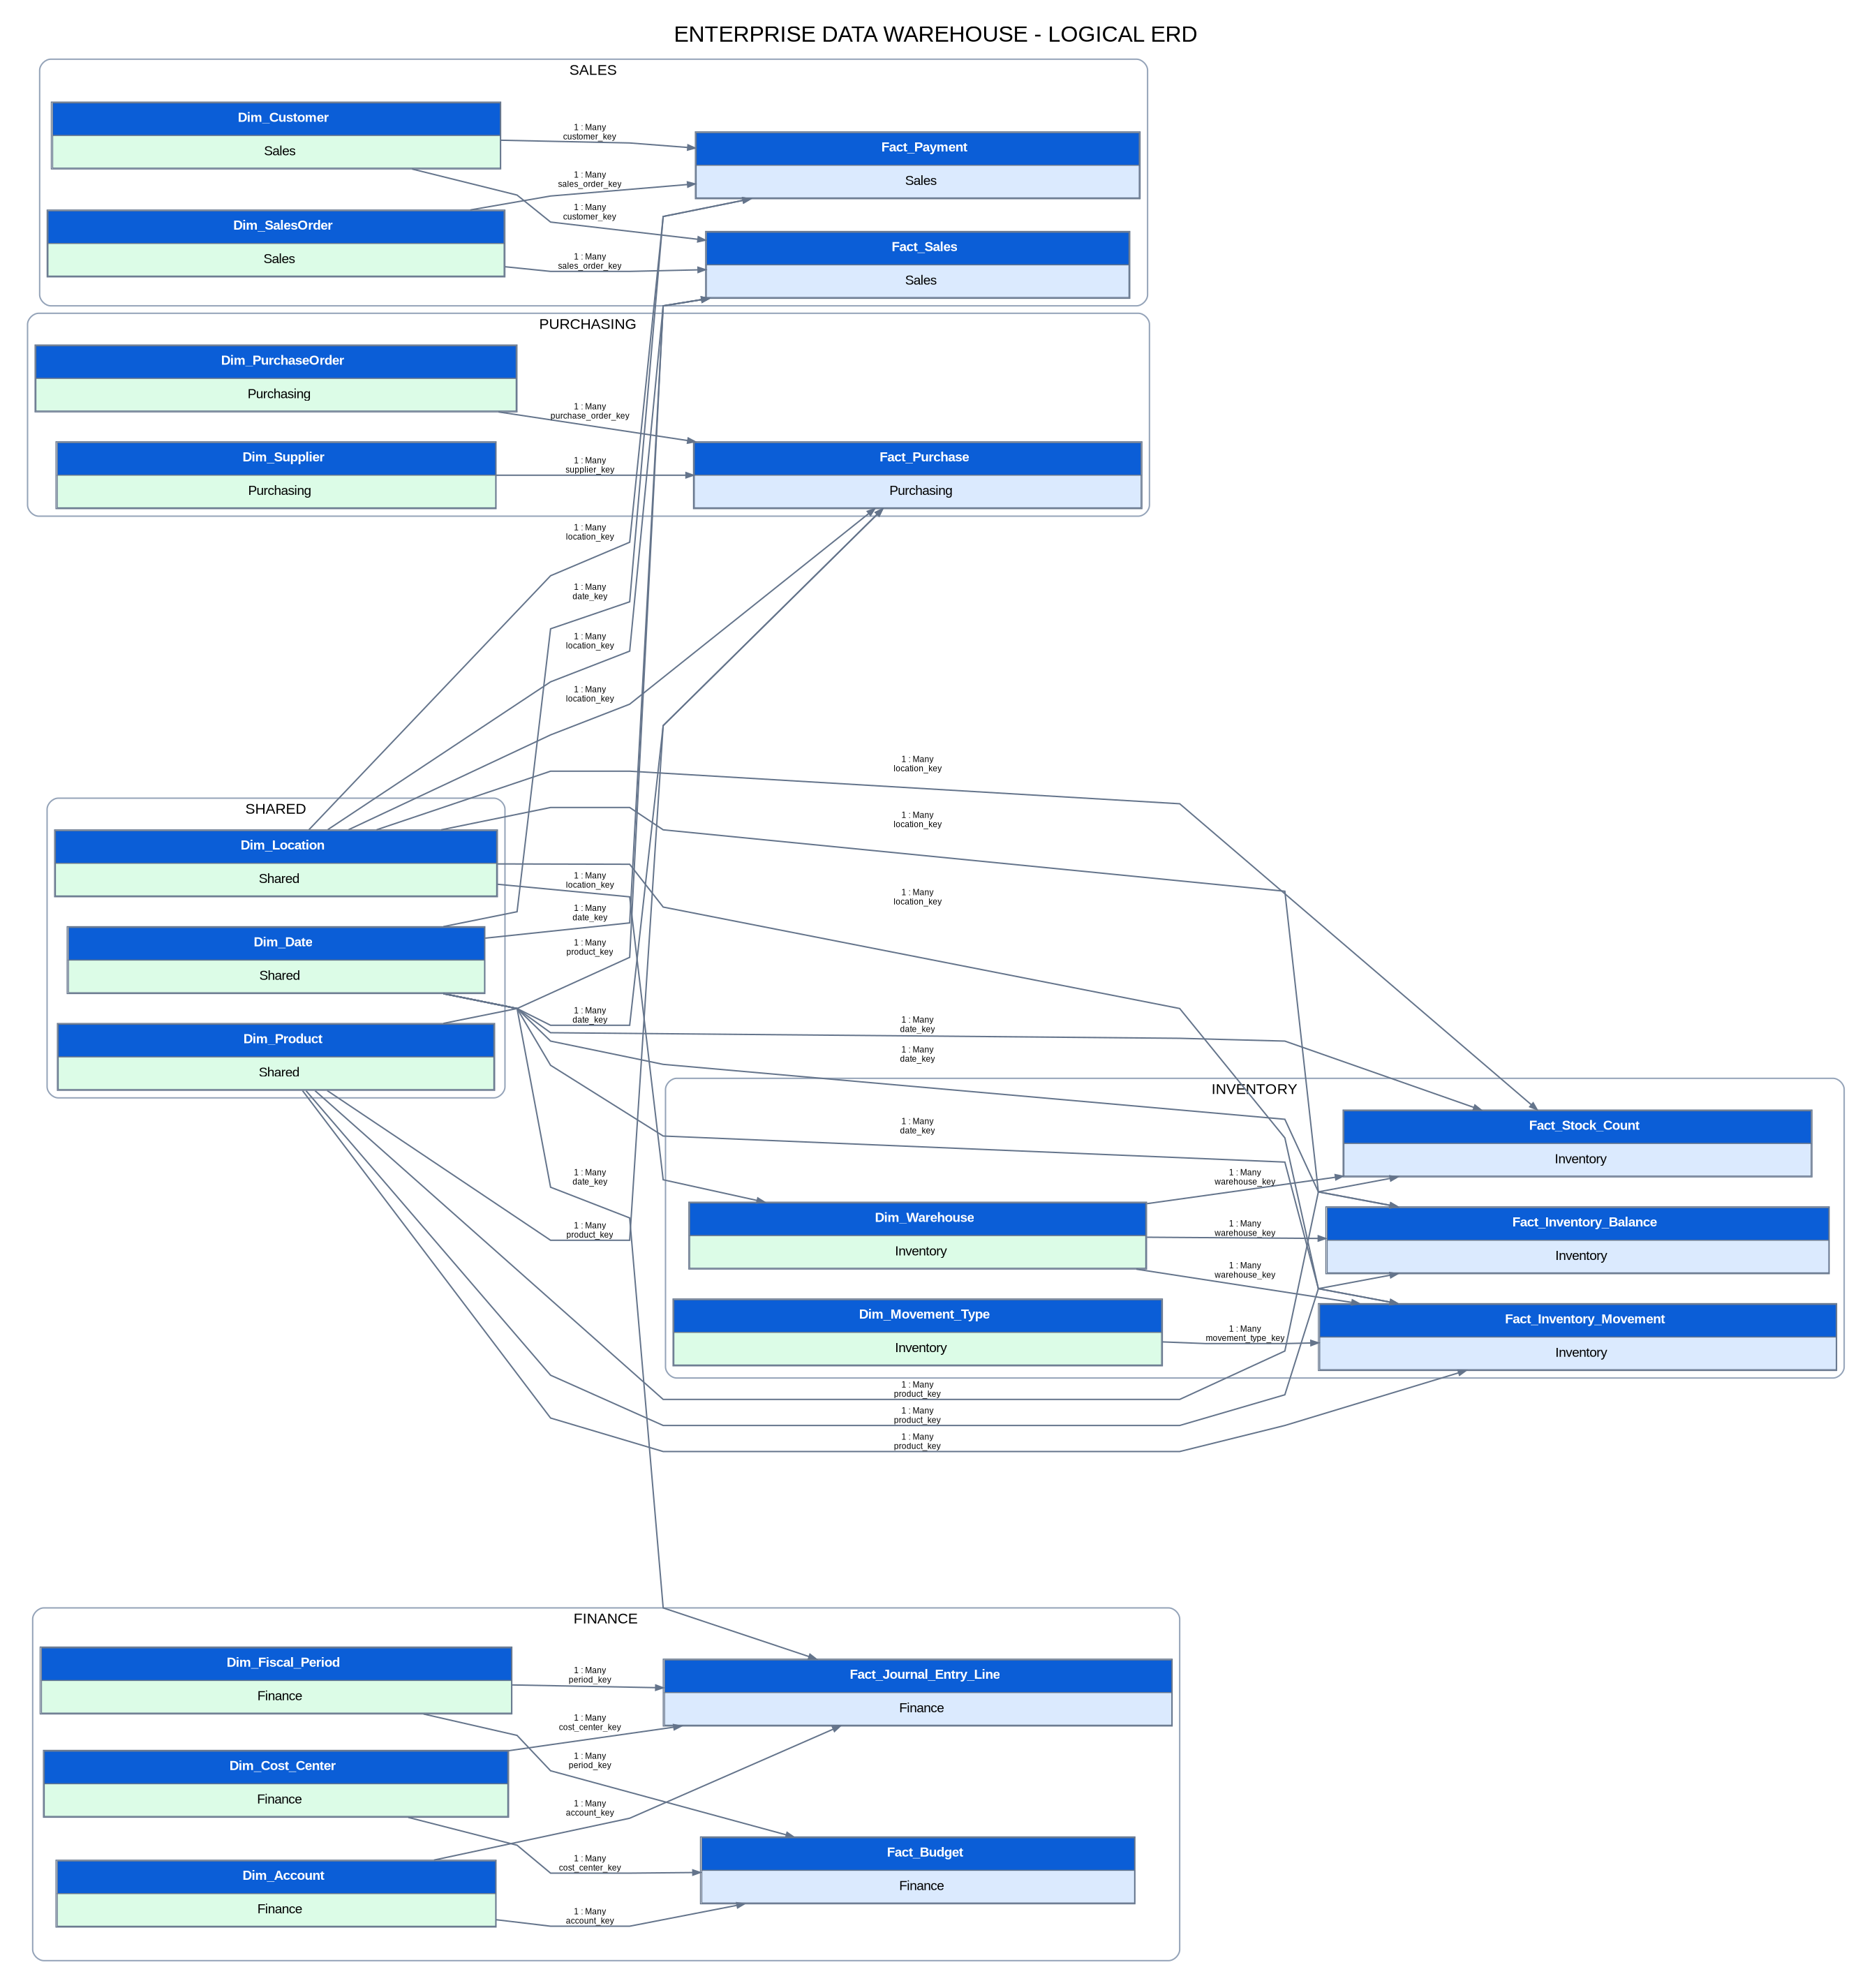


PHYSICAL ERD


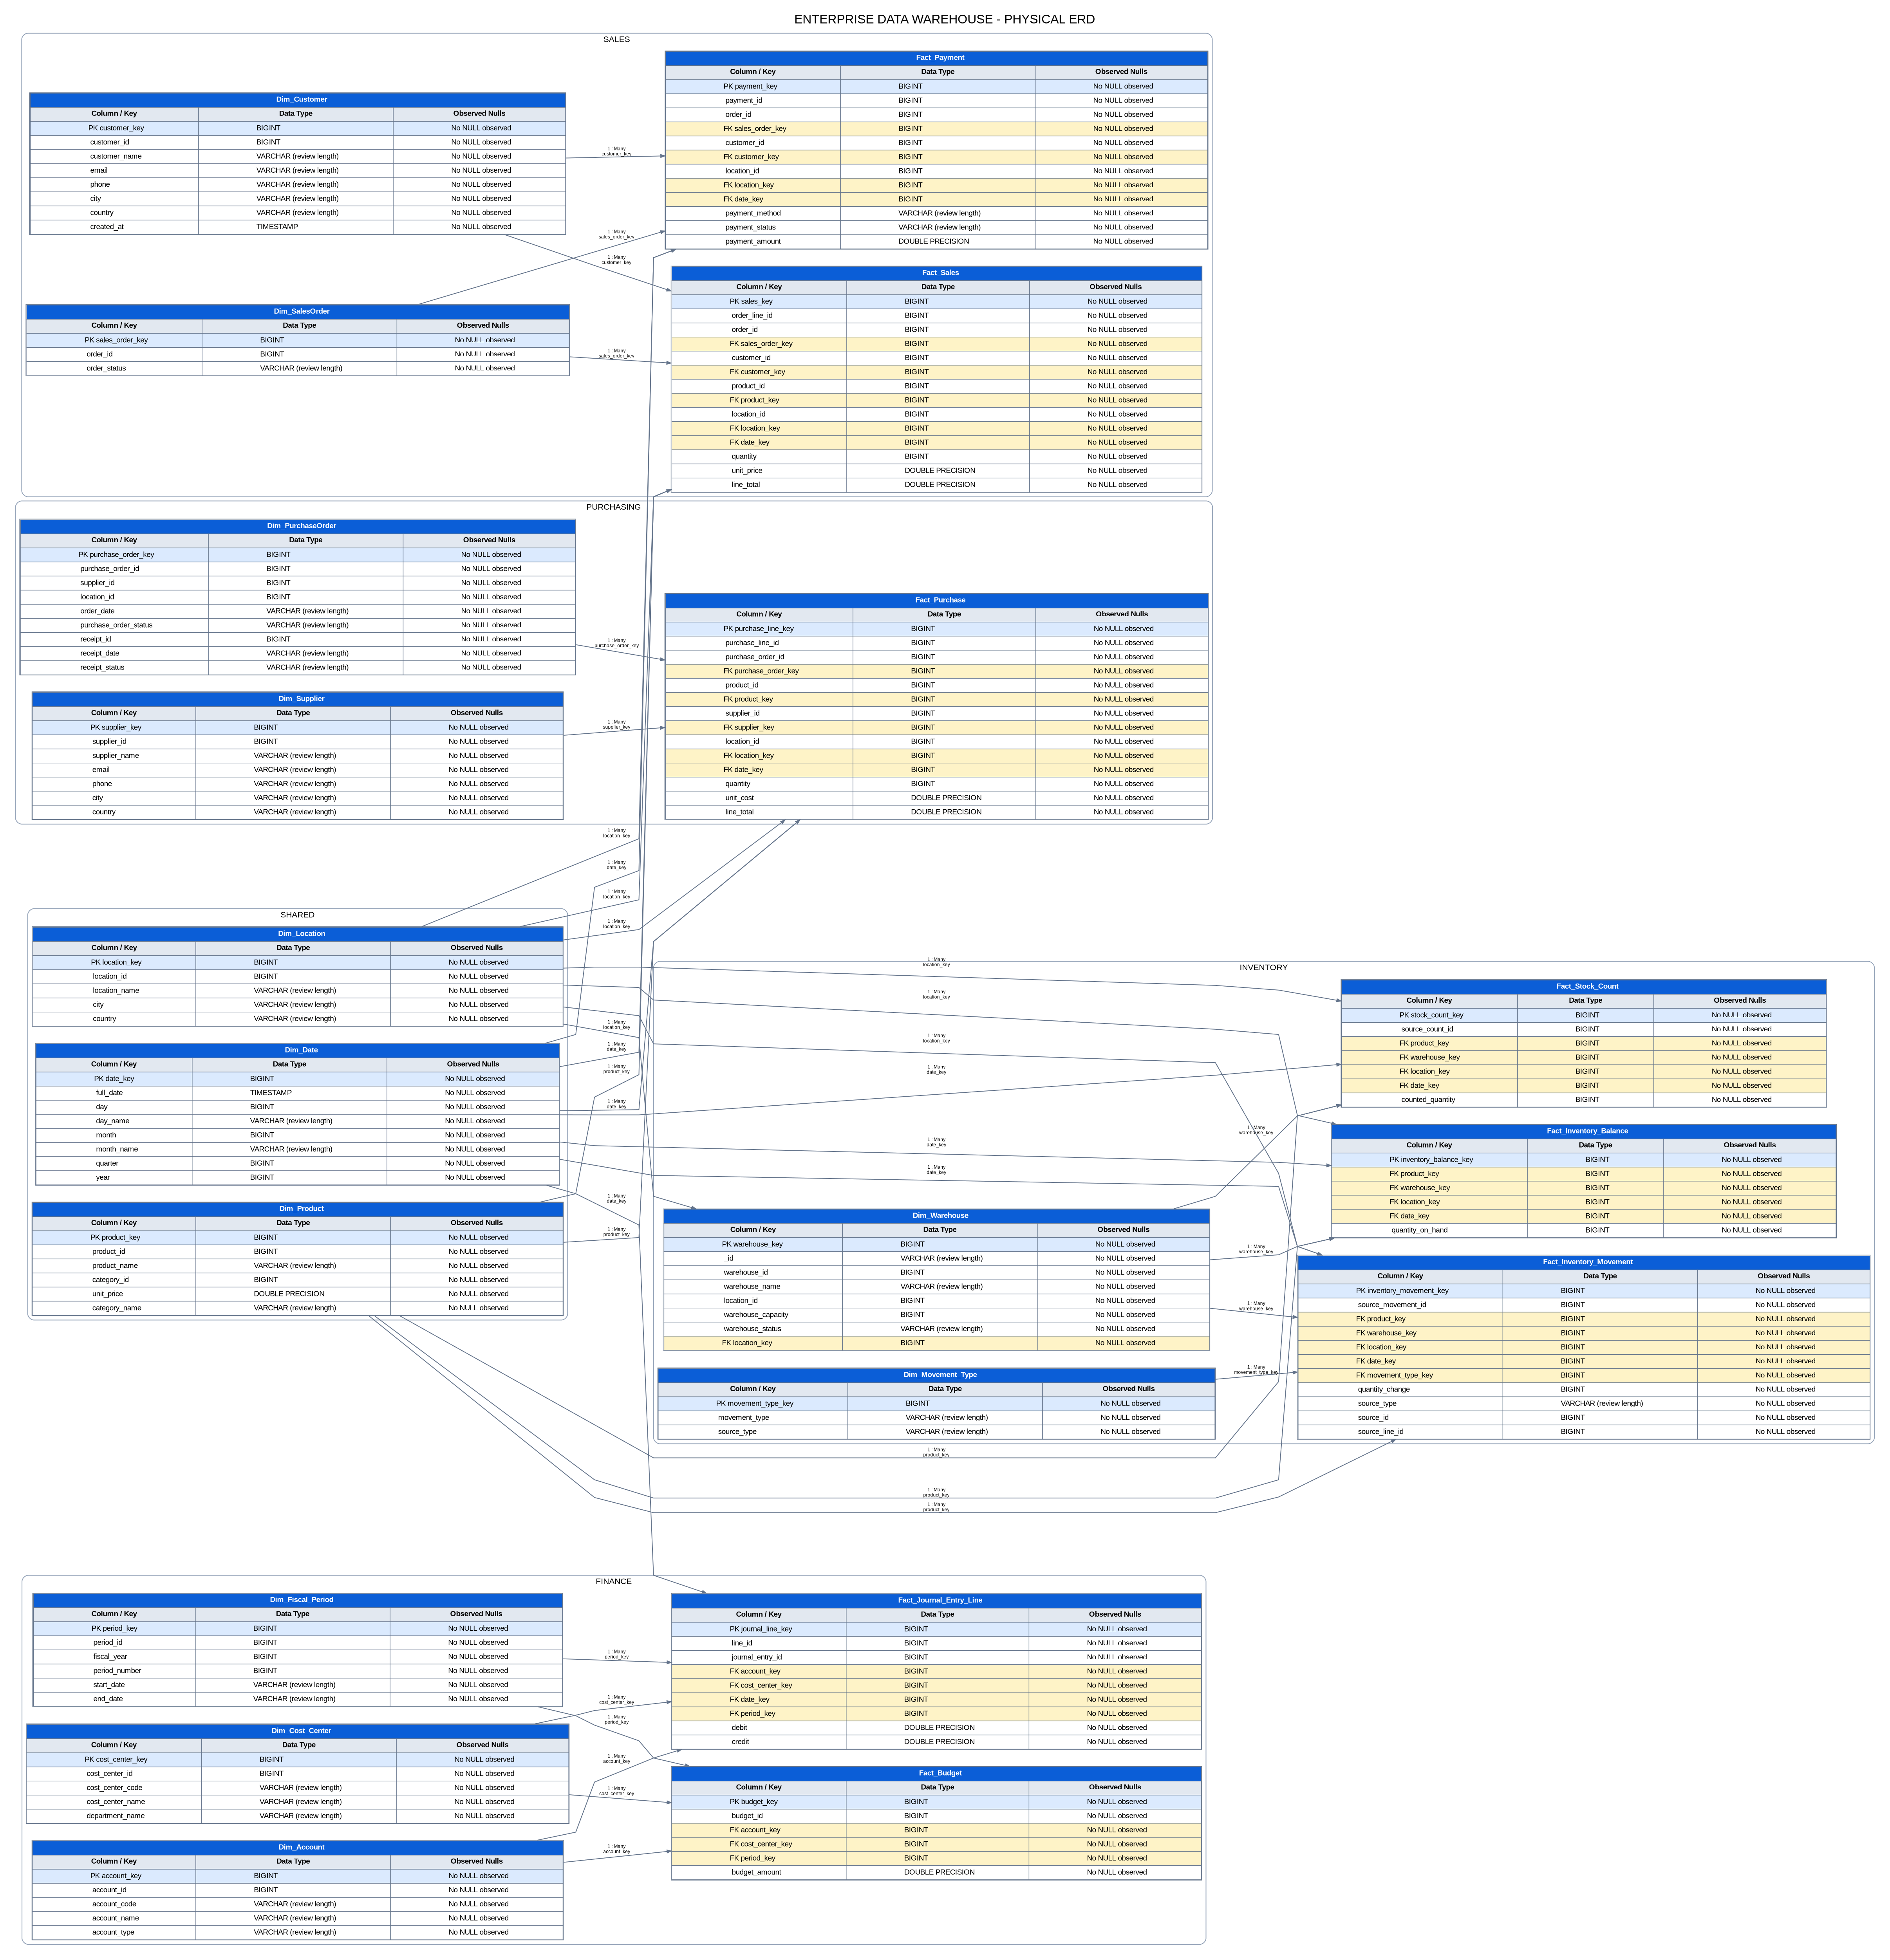


ERD GENERATION SUMMARY
Prepared tables: 20
Dimensions: 12
Fact tables: 8
Detected relationships: 35
Data dictionary columns: 152
Invalid FK references: 0

Files saved in:
/content/drive/MyDrive/Enterprise_DW_Project/ERD_Deliverables

Generated files:
- Enterprise_Data_Dictionary.csv
- Enterprise_ERD_Relationships.csv
- Enterprise_Logical_ERD.pdf
- Enterprise_Logical_ERD.png
- Enterprise_Logical_ERD.svg
- Enterprise_Physical_ERD.pdf
- Enterprise_Physical_ERD.png
- Enterprise_Physical_ERD.svg

ERD generation completed.


In [ ]:

# ================================================================
# ENTERPRISE DATA WAREHOUSE
# LOGICAL ERD + PHYSICAL ERD GENERATOR
#
# Departments:
# Sales, Purchasing, Inventory, Finance
#
# Shared dimensions:
# Dim_Product, Dim_Location, Dim_Date
#
# Output:
# 1. Logical ERD (PNG, PDF, SVG)
# 2. Physical ERD (PNG, PDF, SVG)
# 3. Data Dictionary CSV
# 4. Relationship Report CSV
#
# This code DOES NOT create or modify database tables.
# ================================================================

import os
import sys
import subprocess
import pandas as pd
import html
from pathlib import Path
from IPython.display import display, Image

# ------------------------------------------------
# 1. INSTALL GRAPHVIZ
# ------------------------------------------------

print("Installing diagram requirements...")

subprocess.run(
    ["apt-get", "-qq", "update"],
    check=True
)

subprocess.run(
    ["apt-get", "-qq", "install", "-y", "graphviz"],
    check=True
)

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "graphviz"
])

from graphviz import Digraph

# ------------------------------------------------
# 2. CONNECT GOOGLE DRIVE
# ------------------------------------------------

from google.colab import drive

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/ERD_Deliverables"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder:", OUTPUT_DIR)

# ------------------------------------------------
# 3. REGISTER ALL PREPARED ETL DATAFRAMES
# ------------------------------------------------

# Table name : Existing DataFrame variable

TABLE_REGISTRY = {
    # SHARED DIMENSIONS
    "Dim_Product": "dim_product_df",
    "Dim_Location": "dim_location_df",
    "Dim_Date": "dim_date_df",

    # SALES
    "Dim_Customer": "dim_customer_df",
    "Dim_SalesOrder": "dim_sales_order_df",
    "Fact_Sales": "fact_sales_df",
    "Fact_Payment": "fact_payment_df",

    # PURCHASING
    "Dim_Supplier": "dim_supplier_df",
    "Dim_PurchaseOrder": "dim_purchase_order_df",
    "Fact_Purchase": "fact_purchase_df",

    # INVENTORY
    "Dim_Warehouse": "dim_warehouse_df",
    "Dim_Movement_Type": "dim_movement_type_df",
    "Fact_Inventory_Movement": "fact_inventory_movement_df",
    "Fact_Inventory_Balance": "fact_inventory_balance_df",
    "Fact_Stock_Count": "fact_stock_count_df",

    # FINANCE
    "Dim_Account": "dim_account_df",
    "Dim_Cost_Center": "dim_cost_center_df",
    "Dim_Fiscal_Period": "dim_fiscal_period_df",
    "Fact_Journal_Entry_Line": "fact_journal_entry_line_df",
    "Fact_Budget": "fact_budget_df"
}

# ------------------------------------------------
# 4. CHECK DATAFRAMES
# ------------------------------------------------

prepared_tables = {}
missing_tables = []

for table_name, variable_name in TABLE_REGISTRY.items():

    if variable_name in globals():

        df = globals()[variable_name]

        if isinstance(df, pd.DataFrame):
            prepared_tables[table_name] = df.copy()
        else:
            missing_tables.append(
                f"{table_name}: {variable_name} is not a DataFrame"
            )

    else:
        missing_tables.append(
            f"{table_name}: missing variable {variable_name}"
        )

print("\n========== TABLE AVAILABILITY ==========")

for table_name, df in prepared_tables.items():
    print(
        f"{table_name:<30} "
        f"Rows: {len(df):>10,} | "
        f"Columns: {len(df.columns)}"
    )

if missing_tables:

    print("\nMISSING TABLES:")

    for item in missing_tables:
        print("-", item)

    raise ValueError(
        "Some ETL DataFrames are missing. "
        "Please check the variable names before generating the ERDs."
    )

if len(prepared_tables) != 20:
    raise ValueError("Expected 20 prepared tables.")

# ------------------------------------------------
# 5. DEPARTMENT CLASSIFICATION
# ------------------------------------------------

DEPARTMENTS = {
    "Shared": [
        "Dim_Product",
        "Dim_Location",
        "Dim_Date"
    ],

    "Sales": [
        "Dim_Customer",
        "Dim_SalesOrder",
        "Fact_Sales",
        "Fact_Payment"
    ],

    "Purchasing": [
        "Dim_Supplier",
        "Dim_PurchaseOrder",
        "Fact_Purchase"
    ],

    "Inventory": [
        "Dim_Warehouse",
        "Dim_Movement_Type",
        "Fact_Inventory_Movement",
        "Fact_Inventory_Balance",
        "Fact_Stock_Count"
    ],

    "Finance": [
        "Dim_Account",
        "Dim_Cost_Center",
        "Dim_Fiscal_Period",
        "Fact_Journal_Entry_Line",
        "Fact_Budget"
    ]
}

TABLE_DEPARTMENT = {
    table: department
    for department, tables in DEPARTMENTS.items()
    for table in tables
}

# ------------------------------------------------
# 6. DETECT PRIMARY KEYS
# ------------------------------------------------

# The ETL tables use surrogate keys ending in "_key".
# The first such column is treated as the table PK.
# Review the printed PK report before submitting.

PRIMARY_KEYS = {}

for table_name, df in prepared_tables.items():

    key_candidates = [
        col for col in df.columns
        if col.lower().endswith("_key")
    ]

    if not key_candidates:
        raise ValueError(
            f"No surrogate key found for {table_name}. "
            "Please inspect its columns."
        )

    PRIMARY_KEYS[table_name] = key_candidates[0]

print("\n========== PRIMARY KEY REPORT ==========")

for table_name, pk in PRIMARY_KEYS.items():

    unique_count = prepared_tables[table_name][pk].nunique(
        dropna=True
    )

    null_count = prepared_tables[table_name][pk].isna().sum()

    print(
        f"{table_name:<30} PK: {pk:<25} "
        f"Unique: {unique_count:,} | Null: {null_count}"
    )

# ------------------------------------------------
# 7. DETECT FOREIGN KEYS
# ------------------------------------------------

# A column is considered an FK when its name matches
# the primary key of another prepared table.

PK_TO_TABLE = {}

for table_name, pk in PRIMARY_KEYS.items():

    if pk in PK_TO_TABLE:
        raise ValueError(
            f"Duplicate PK column name detected: {pk}"
        )

    PK_TO_TABLE[pk] = table_name

RELATIONSHIPS = []

for child_table, df in prepared_tables.items():

    child_pk = PRIMARY_KEYS[child_table]

    for column in df.columns:

        if column == child_pk:
            continue

        if column in PK_TO_TABLE:

            parent_table = PK_TO_TABLE[column]

            RELATIONSHIPS.append({
                "parent_table": parent_table,
                "parent_pk": PRIMARY_KEYS[parent_table],
                "child_table": child_table,
                "child_fk": column,
                "cardinality": "1 : Many"
            })

print("\n========== DETECTED RELATIONSHIPS ==========")

for rel in RELATIONSHIPS:

    print(
        f"{rel['parent_table']} "
        f"({rel['parent_pk']})  --->  "
        f"{rel['child_table']} "
        f"({rel['child_fk']})"
    )

# ------------------------------------------------
# 8. CHECK RELATIONSHIP VALIDITY
# ------------------------------------------------

relationship_audits = []

for rel in RELATIONSHIPS:

    parent_df = prepared_tables[rel["parent_table"]]
    child_df = prepared_tables[rel["child_table"]]

    parent_pk = rel["parent_pk"]
    child_fk = rel["child_fk"]

    parent_values = set(
        parent_df[parent_pk].dropna().tolist()
    )

    child_values = child_df[child_fk]

    invalid_count = (
        child_values.notna()
        & ~child_values.isin(parent_values)
    ).sum()

    relationship_audits.append({
        "parent_table": rel["parent_table"],
        "parent_pk": parent_pk,
        "child_table": rel["child_table"],
        "child_fk": child_fk,
        "invalid_fk_count": int(invalid_count),
        "null_fk_count": int(child_values.isna().sum()),
        "status": "PASS" if invalid_count == 0 else "CHECK"
    })

relationship_audit_df = pd.DataFrame(
    relationship_audits
)

print("\n========== FK VALIDATION ==========")

if not relationship_audit_df.empty:
    display(relationship_audit_df)

# ------------------------------------------------
# 9. DATA TYPE CONVERSION FOR DOCUMENTATION
# ------------------------------------------------

def infer_sql_type(series):

    dtype = str(series.dtype).lower()

    if "datetime" in dtype:
        return "TIMESTAMP"

    if "bool" in dtype:
        return "BOOLEAN"

    if "int" in dtype:
        return "BIGINT"

    if "float" in dtype:
        return "DOUBLE PRECISION"

    if "decimal" in dtype:
        return "DECIMAL (review precision)"

    if "date" in dtype:
        return "DATE"

    return "VARCHAR (review length)"

# ------------------------------------------------
# 10. BUILD PHYSICAL DATA DICTIONARY
# ------------------------------------------------

dictionary_records = []

for table_name, df in prepared_tables.items():

    pk = PRIMARY_KEYS[table_name]

    fk_columns = [
        rel["child_fk"]
        for rel in RELATIONSHIPS
        if rel["child_table"] == table_name
    ]

    for column in df.columns:

        if column == pk:
            key_type = "PK"

        elif column in fk_columns:
            key_type = "FK"

        else:
            key_type = "Attribute"

        dictionary_records.append({

            "department": TABLE_DEPARTMENT[table_name],
            "table_name": table_name,
            "column_name": column,
            "key_type": key_type,
            "inferred_sql_type": infer_sql_type(df[column]),
            "pandas_dtype": str(df[column].dtype),
            "observed_null_count": int(df[column].isna().sum()),
            "observed_nullable": (
                "YES" if df[column].isna().any() else "NO"
            ),
            "unique_values": int(df[column].nunique(dropna=True))
        })

data_dictionary_df = pd.DataFrame(dictionary_records)

# ------------------------------------------------
# 11. GRAPHVIZ STYLE
# ------------------------------------------------

def create_graph(title, physical=False):

    graph = Digraph(
        name=title,
        format="png"
    )

    graph.attr(
        rankdir="LR",
        bgcolor="white",
        label=title,
        labelloc="t",
        fontsize="24",
        fontname="Arial",
        nodesep="0.45",
        ranksep="1.0",
        splines="polyline",
        pad="0.3"
    )

    graph.attr(
        "node",
        shape="plain",
        fontname="Arial"
    )

    graph.attr(
        "edge",
        color="#64748B",
        penwidth="1.5",
        arrowsize="0.8",
        fontname="Arial",
        fontsize="9"
    )

    # Department clusters
    for department, tables in DEPARTMENTS.items():

        with graph.subgraph(
            name=f"cluster_{department}"
        ) as cluster:

            cluster.attr(
                label=department.upper(),
                style="rounded",
                color="#94A3B8",
                penwidth="1.5",
                fontname="Arial",
                fontsize="16"
            )

            for table_name in tables:

                if table_name not in prepared_tables:
                    continue

                df = prepared_tables[table_name]

                pk = PRIMARY_KEYS[table_name]

                if not physical:

                    if table_name.startswith("Fact_"):
                        fill = "#DBEAFE"
                    else:
                        fill = "#DCFCE7"

                    label = f"""<
                    <TABLE BORDER="1"
                           CELLBORDER="1"
                           CELLSPACING="0"
                           CELLPADDING="9"
                           COLOR="#64748B">
                    <TR>
                      <TD BGCOLOR="#0B5ED7">
                        <FONT COLOR="white">
                          <B>{html.escape(table_name)}</B>
                        </FONT>
                      </TD>
                    </TR>
                    <TR>
                      <TD BGCOLOR="{fill}">
                        {html.escape(department)}
                      </TD>
                    </TR>
                    </TABLE>
                    >"""

                else:

                    rows = ""

                    for column in df.columns:

                        if column == pk:
                            marker = "PK"
                            color = "#DBEAFE"

                        elif any(
                            r["child_table"] == table_name
                            and r["child_fk"] == column
                            for r in RELATIONSHIPS
                        ):
                            marker = "FK"
                            color = "#FEF3C7"

                        else:
                            marker = ""
                            color = "white"

                        sql_type = infer_sql_type(df[column])

                        null_text = (
                            "NULL observed"
                            if df[column].isna().any()
                            else "No NULL observed"
                        )

                        rows += f"""
                        <TR>
                          <TD ALIGN="LEFT"
                              BGCOLOR="{color}">
                            {marker} {html.escape(str(column))}
                          </TD>
                          <TD ALIGN="LEFT"
                              BGCOLOR="{color}">
                            {html.escape(sql_type)}
                          </TD>
                          <TD ALIGN="LEFT"
                              BGCOLOR="{color}">
                            {null_text}
                          </TD>
                        </TR>
                        """

                    label = f"""<
                    <TABLE BORDER="1"
                           CELLBORDER="1"
                           CELLSPACING="0"
                           CELLPADDING="5"
                           COLOR="#64748B">
                    <TR>
                      <TD COLSPAN="3" BGCOLOR="#0B5ED7">
                        <FONT COLOR="white">
                          <B>{html.escape(table_name)}</B>
                        </FONT>
                      </TD>
                    </TR>
                    <TR>
                      <TD BGCOLOR="#E2E8F0"><B>Column / Key</B></TD>
                      <TD BGCOLOR="#E2E8F0"><B>Data Type</B></TD>
                      <TD BGCOLOR="#E2E8F0"><B>Observed Nulls</B></TD>
                    </TR>
                    {rows}
                    </TABLE>
                    >"""

                cluster.node(
                    table_name,
                    label=label
                )

    # Add relationships
    for rel in RELATIONSHIPS:

        graph.edge(
            rel["parent_table"],
            rel["child_table"],
            label=(
                "1 : Many\n"
                f"{rel['child_fk']}"
            )
        )

    return graph

# ------------------------------------------------
# 12. GENERATE LOGICAL ERD
# ------------------------------------------------

print("\nGenerating Logical ERD...")

logical_erd = create_graph(
    "ENTERPRISE DATA WAREHOUSE - LOGICAL ERD",
    physical=False
)

logical_erd.render(
    filename="Enterprise_Logical_ERD",
    directory=str(OUTPUT_DIR),
    format="png",
    cleanup=True
)

logical_erd.render(
    filename="Enterprise_Logical_ERD",
    directory=str(OUTPUT_DIR),
    format="pdf",
    cleanup=True
)

logical_erd.render(
    filename="Enterprise_Logical_ERD",
    directory=str(OUTPUT_DIR),
    format="svg",
    cleanup=True
)

# ------------------------------------------------
# 13. GENERATE PHYSICAL ERD
# ------------------------------------------------

print("Generating Physical ERD...")

physical_erd = create_graph(
    "ENTERPRISE DATA WAREHOUSE - PHYSICAL ERD",
    physical=True
)

physical_erd.render(
    filename="Enterprise_Physical_ERD",
    directory=str(OUTPUT_DIR),
    format="png",
    cleanup=True
)

physical_erd.render(
    filename="Enterprise_Physical_ERD",
    directory=str(OUTPUT_DIR),
    format="pdf",
    cleanup=True
)

physical_erd.render(
    filename="Enterprise_Physical_ERD",
    directory=str(OUTPUT_DIR),
    format="svg",
    cleanup=True
)

# ------------------------------------------------
# 14. EXPORT DATA DICTIONARY AND RELATIONSHIPS
# ------------------------------------------------

data_dictionary_df.to_csv(
    OUTPUT_DIR / "Enterprise_Data_Dictionary.csv",
    index=False
)

relationship_audit_df.to_csv(
    OUTPUT_DIR / "Enterprise_ERD_Relationships.csv",
    index=False
)

# ------------------------------------------------
# 15. DISPLAY BOTH ERDs
# ------------------------------------------------

print("\n" + "=" * 65)
print("LOGICAL ERD")
print("=" * 65)

display(
    Image(
        filename=str(
            OUTPUT_DIR / "Enterprise_Logical_ERD.png"
        )
    )
)

print("\n" + "=" * 65)
print("PHYSICAL ERD")
print("=" * 65)

display(
    Image(
        filename=str(
            OUTPUT_DIR / "Enterprise_Physical_ERD.png"
        )
    )
)

# ------------------------------------------------
# 16. FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 65)
print("ERD GENERATION SUMMARY")
print("=" * 65)

print("Prepared tables:", len(prepared_tables))
print("Dimensions:", sum(
    1 for t in prepared_tables if t.startswith("Dim_")
))
print("Fact tables:", sum(
    1 for t in prepared_tables if t.startswith("Fact_")
))
print("Detected relationships:", len(RELATIONSHIPS))
print("Data dictionary columns:", len(data_dictionary_df))

if not relationship_audit_df.empty:
    print(
        "Invalid FK references:",
        relationship_audit_df["invalid_fk_count"].sum()
    )

print("\nFiles saved in:")
print(OUTPUT_DIR)

print("\nGenerated files:")

for file in sorted(OUTPUT_DIR.iterdir()):
    print("-", file.name)

print("\nERD generation completed.")


# Q6: Dimensional Design
This phase will generate:
1. Two star-schema diagrams.
2. A complete bus matrix.
3. A departmental source coverage matrix.
4. Fact table grain definitions and uniqueness checks.
5. A measure and additivity inventory.
6. Dimension hierarchies.
7. Null and unknown-member policies.
8. An Excel workbook and CSV documentation.
We will organize the two related analytical areas as:
- Star Schema 1 — Commercial Operations: Sales, Payments and Purchasing.
- Star Schema 2 — Inventory and Financial Control: Inventory movements, balances, stock counts, journal entries and budgets.
Both designs reuse conformed dimensions where applicable. This is a design and validation phase only; it will not modify your prepared ETL data or create database tables.

In [ ]:

# ================================================================
# CT-472 PHASE 1 - PRIMARY KEY CORRECTION
# Fact_Purchase actual PK = purchase_line_key
#
# This cell verifies the correction only.
# It does not modify any prepared ETL DataFrames.
# ================================================================

import pandas as pd

EXPECTED_PRIMARY_KEYS = {

    # Shared dimensions
    "Dim_Product": "product_key",
    "Dim_Location": "location_key",
    "Dim_Date": "date_key",

    # Sales
    "Dim_Customer": "customer_key",
    "Dim_SalesOrder": "sales_order_key",
    "Fact_Sales": "sales_key",
    "Fact_Payment": "payment_key",

    # Purchasing
    "Dim_Supplier": "supplier_key",
    "Dim_PurchaseOrder": "purchase_order_key",
    "Fact_Purchase": "purchase_line_key",

    # Inventory
"Dim_Warehouse": "warehouse_key",
"Dim_Movement_Type": "movement_type_key",
"Fact_Inventory_Movement": "inventory_movement_key",
"Fact_Inventory_Balance": "inventory_balance_key",
"Fact_Stock_Count": "stock_count_key",

    # Finance
    "Dim_Account": "account_key",
    "Dim_Cost_Center": "cost_center_key",
    "Dim_Fiscal_Period": "period_key",
    "Fact_Journal_Entry_Line": "journal_line_key",
    "Fact_Budget": "budget_key"
}

print("=" * 70)
print("CORRECTED PRIMARY KEY VALIDATION")
print("=" * 70)

pk_results = []

for table_name, expected_pk in EXPECTED_PRIMARY_KEYS.items():

    df = prepared_tables[table_name]

    if expected_pk not in df.columns:

        raise ValueError(
            f"{table_name}: expected key {expected_pk} not found.\n"
            f"Actual columns: {list(df.columns)}"
        )

    pk_results.append({

        "table_name": table_name,
        "primary_key": expected_pk,
        "row_count": len(df),
        "null_count": int(df[expected_pk].isna().sum()),
        "unique_count": int(df[expected_pk].nunique()),
        "duplicate_count": int(df[expected_pk].duplicated().sum()),
        "status": (
            "PASS"
            if df[expected_pk].notna().all()
            and df[expected_pk].is_unique
            else "FAIL"
        )
    })

corrected_pk_report = pd.DataFrame(pk_results)

display(corrected_pk_report)

print("\nPurchasing Fact actual columns:")
display(
    pd.DataFrame({
        "column": prepared_tables["Fact_Purchase"].columns,
        "role": [
            "PRIMARY KEY" if c == "purchase_line_key"
            else "FOREIGN KEY" if c in [
                "purchase_order_key",
                "product_key",
                "supplier_key",
                "location_key",
                "date_key"
            ]
            else "SOURCE / MEASURE"
            for c in prepared_tables["Fact_Purchase"].columns
        ]
    })
)

if (corrected_pk_report["status"] == "FAIL").any():

    raise ValueError(
        "Some primary keys failed validation. "
        "Do not proceed until investigated."
    )

print("\nAll 20 primary keys passed validation.")
print("Corrected Fact_Purchase PK: purchase_line_key")


CORRECTED PRIMARY KEY VALIDATION


,table_name,primary_key,row_count,null_count,unique_count,duplicate_count,status
0,Dim_Product,product_key,2000,0,2000,0,PASS
1,Dim_Location,location_key,100,0,100,0,PASS
2,Dim_Date,date_key,1096,0,1096,0,PASS
3,Dim_Customer,customer_key,5000,0,5000,0,PASS
4,Dim_SalesOrder,sales_order_key,100000,0,100000,0,PASS
5,Fact_Sales,sales_key,300000,0,300000,0,PASS
6,Fact_Payment,payment_key,100000,0,100000,0,PASS
7,Dim_Supplier,supplier_key,2000,0,2000,0,PASS
8,Dim_PurchaseOrder,purchase_order_key,30000,0,30000,0,PASS
9,Fact_Purchase,purchase_line_key,120000,0,120000,0,PASS



Purchasing Fact actual columns:


,column,role
0,purchase_line_key,PRIMARY KEY
1,purchase_line_id,SOURCE / MEASURE
2,purchase_order_id,SOURCE / MEASURE
3,purchase_order_key,FOREIGN KEY
4,product_id,SOURCE / MEASURE
5,product_key,FOREIGN KEY
6,supplier_id,SOURCE / MEASURE
7,supplier_key,FOREIGN KEY
8,location_id,SOURCE / MEASURE
9,location_key,FOREIGN KEY



All 20 primary keys passed validation.
Corrected Fact_Purchase PK: purchase_line_key


In [ ]:

# =====================================================================
# CT-472 ENTERPRISE DATA WAREHOUSE
# PHASE 1 - FINAL DIMENSIONAL DESIGN (Q6)
#
# DEPARTMENTS:
# 1. Sales
# 2. Purchasing
# 3. Inventory
# 4. Finance
#
# TARGET:
# 12 DIMENSIONS + 8 FACT TABLES
#
# PURPOSE:
# - Validate primary keys and foreign keys
# - Define fact grains
# - Build bus matrix
# - Build source coverage matrix
# - Document measures and additivity
# - Document dimension hierarchies
# - Document null policies
# - Generate two related star-schema diagrams
# - Export design documentation
#
# IMPORTANT:
# This cell does not modify prepared ETL DataFrames.
# This cell does not create physical database tables.
# =====================================================================

import os
import sys
import shutil
import subprocess
import warnings
import pandas as pd
import numpy as np

from pathlib import Path
from datetime import datetime
from IPython.display import display, Image

warnings.filterwarnings("ignore")

print("=" * 85)
print("CT-472 - PHASE 1: FINAL DIMENSIONAL DESIGN")
print("=" * 85)


# =====================================================================
# STEP 1 - CHECK REQUIRED ENVIRONMENT
# =====================================================================

print("\nSTEP 1: CHECKING ENVIRONMENT")

if "prepared_tables" not in globals():
    raise NameError(
        "prepared_tables dictionary not found. "
        "Run your completed ETL preparation cells first."
    )

print("Prepared tables found:", len(prepared_tables))


# =====================================================================
# STEP 2 - DEFINE OUTPUT FOLDER
# =====================================================================

from google.colab import drive

drive.mount("/content/drive", force_remount=False)

PROJECT_FOLDER = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project"
)

OUTPUT_FOLDER = PROJECT_FOLDER / "Phase_1_Dimensional_Design"

OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

DIAGRAM_FOLDER = OUTPUT_FOLDER / "Diagrams"
REPORT_FOLDER = OUTPUT_FOLDER / "Reports"

DIAGRAM_FOLDER.mkdir(parents=True, exist_ok=True)
REPORT_FOLDER.mkdir(parents=True, exist_ok=True)

print("Output folder:", OUTPUT_FOLDER)


# =====================================================================
# STEP 3 - REGISTER ALL 20 PREPARED TABLES
# =====================================================================

TABLE_NAMES = [
    "Dim_Product",
    "Dim_Location",
    "Dim_Date",

    "Dim_Customer",
    "Dim_SalesOrder",
    "Fact_Sales",
    "Fact_Payment",

    "Dim_Supplier",
    "Dim_PurchaseOrder",
    "Fact_Purchase",

    "Dim_Warehouse",
    "Dim_Movement_Type",
    "Fact_Inventory_Movement",
    "Fact_Inventory_Balance",
    "Fact_Stock_Count",

    "Dim_Account",
    "Dim_Cost_Center",
    "Dim_Fiscal_Period",
    "Fact_Journal_Entry_Line",
    "Fact_Budget"
]

missing_tables = [
    name for name in TABLE_NAMES
    if name not in prepared_tables
]

if missing_tables:
    raise ValueError(
        "These prepared tables are missing:\n"
        + "\n".join(missing_tables)
    )

# Use references only. Do not change original DataFrames.
design_tables = {
    name: prepared_tables[name]
    for name in TABLE_NAMES
}

print("All 20 required tables are available.")

for name, df in design_tables.items():
    print(f"{name:30} {len(df):>10,} rows | {len(df.columns):>3} columns")


# =====================================================================
# STEP 4 - DEFINE VERIFIED PRIMARY KEYS
# =====================================================================

# These names were verified by your successful validation output.

EXPECTED_PRIMARY_KEYS = {

    # Shared dimensions
    "Dim_Product": "product_key",
    "Dim_Location": "location_key",
    "Dim_Date": "date_key",

    # Sales
    "Dim_Customer": "customer_key",
    "Dim_SalesOrder": "sales_order_key",
    "Fact_Sales": "sales_key",
    "Fact_Payment": "payment_key",

    # Purchasing
    "Dim_Supplier": "supplier_key",
    "Dim_PurchaseOrder": "purchase_order_key",
    "Fact_Purchase": "purchase_line_key",

    # Inventory
    "Dim_Warehouse": "warehouse_key",
    "Dim_Movement_Type": "movement_type_key",
    "Fact_Inventory_Movement": "inventory_movement_key",
    "Fact_Inventory_Balance": "inventory_balance_key",
    "Fact_Stock_Count": "stock_count_key",

    # Finance
    "Dim_Account": "account_key",
    "Dim_Cost_Center": "cost_center_key",
    "Dim_Fiscal_Period": "period_key",
    "Fact_Journal_Entry_Line": "journal_line_key",
    "Fact_Budget": "budget_key"
}

pk_results = []

for table_name, pk in EXPECTED_PRIMARY_KEYS.items():

    df = design_tables[table_name]

    if pk not in df.columns:
        raise ValueError(
            f"{table_name}: primary key {pk} is missing.\n"
            f"Actual columns: {list(df.columns)}"
        )

    null_count = int(df[pk].isna().sum())
    unique_count = int(df[pk].nunique())
    duplicate_count = int(df[pk].duplicated().sum())

    status = (
        "PASS"
        if null_count == 0
        and duplicate_count == 0
        else "FAIL"
    )

    pk_results.append({
        "table_name": table_name,
        "primary_key": pk,
        "row_count": len(df),
        "null_count": null_count,
        "unique_count": unique_count,
        "duplicate_count": duplicate_count,
        "status": status
    })

pk_report = pd.DataFrame(pk_results)

print("\nPRIMARY KEY VALIDATION")
display(pk_report)

if (pk_report["status"] == "FAIL").any():
    raise ValueError(
        "Primary key validation failed. "
        "Investigate before continuing."
    )

print("All 20 primary keys passed.")


# =====================================================================
# STEP 5 - IDENTIFY DIMENSIONS AND FACT TABLES
# =====================================================================

DIMENSIONS = [
    "Dim_Product",
    "Dim_Location",
    "Dim_Date",
    "Dim_Customer",
    "Dim_SalesOrder",
    "Dim_Supplier",
    "Dim_PurchaseOrder",
    "Dim_Warehouse",
    "Dim_Movement_Type",
    "Dim_Account",
    "Dim_Cost_Center",
    "Dim_Fiscal_Period"
]

FACTS = [
    "Fact_Sales",
    "Fact_Payment",
    "Fact_Purchase",
    "Fact_Inventory_Movement",
    "Fact_Inventory_Balance",
    "Fact_Stock_Count",
    "Fact_Journal_Entry_Line",
    "Fact_Budget"
]

print("\nDIMENSION COUNT:", len(DIMENSIONS))
print("FACT TABLE COUNT:", len(FACTS))


# =====================================================================
# STEP 6 - DEFINE FACT GRAINS
# =====================================================================

# Grain means what exactly ONE row represents.
# These definitions follow the completed ETL work.

FACT_GRAINS = {

    "Fact_Sales":
        "One row per sales order line (order_line_id).",

    "Fact_Payment":
        "One row per payment transaction (payment_id).",

    "Fact_Purchase":
        "One row per purchase order line (purchase_line_id).",

    "Fact_Inventory_Movement":
        "One row per inventory movement record.",

    "Fact_Inventory_Balance":
        "One row per product, warehouse and inventory snapshot date.",

    "Fact_Stock_Count":
        "One row per stock count record (count_id).",

    "Fact_Journal_Entry_Line":
        "One row per journal entry line (line_id).",

    "Fact_Budget":
        "One row per budget record (budget_id)."
}

grain_report = pd.DataFrame([
    {
        "fact_table": fact,
        "grain": FACT_GRAINS[fact],
        "row_count": len(design_tables[fact]),
        "primary_key": EXPECTED_PRIMARY_KEYS[fact]
    }
    for fact in FACTS
])

print("\nFACT TABLE GRAIN")
display(grain_report)


# =====================================================================
# STEP 7 - DISCOVER FACT-TO-DIMENSION RELATIONSHIPS
# =====================================================================

# A relationship is included only when the fact actually contains
# the exact primary-key column of a prepared dimension.

relationship_rows = []

for fact in FACTS:

    fact_df = design_tables[fact]

    for dimension in DIMENSIONS:

        dimension_pk = EXPECTED_PRIMARY_KEYS[dimension]

        if dimension_pk in fact_df.columns:

            relationship_rows.append({

                "fact_table": fact,
                "dimension_table": dimension,
                "foreign_key": dimension_pk,
                "dimension_primary_key": dimension_pk,
                "relationship": "Many-to-One",
                "fact_rows": len(fact_df),
                "dimension_rows": len(design_tables[dimension])

            })

relationships = pd.DataFrame(relationship_rows)

if relationships.empty:
    raise ValueError(
        "No fact-to-dimension relationships were discovered."
    )

print("\nDISCOVERED FACT-TO-DIMENSION RELATIONSHIPS")
display(relationships)

print("\nTotal discovered relationships:", len(relationships))


# =====================================================================
# STEP 8 - FOREIGN KEY VALIDATION
# =====================================================================

# This checks:
# 1. Null foreign keys
# 2. Foreign keys with no matching dimension record
#
# It does not remove or update any records.

fk_results = []

for _, relationship in relationships.iterrows():

    fact = relationship["fact_table"]
    dimension = relationship["dimension_table"]
    fk = relationship["foreign_key"]
    pk = EXPECTED_PRIMARY_KEYS[dimension]

    fact_df = design_tables[fact]
    dimension_df = design_tables[dimension]

    null_count = int(fact_df[fk].isna().sum())

    valid_dimension_keys = set(
        dimension_df[pk].dropna().tolist()
    )

    non_null_fk = fact_df[fk].dropna()

    orphan_count = int(
        (~non_null_fk.isin(valid_dimension_keys)).sum()
    )

    fk_results.append({

        "fact_table": fact,
        "dimension_table": dimension,
        "foreign_key": fk,
        "fact_rows": len(fact_df),
        "null_fk_count": null_count,
        "orphan_fk_count": orphan_count,

        "status": (
            "PASS"
            if null_count == 0 and orphan_count == 0
            else "REVIEW"
        )

    })

fk_report = pd.DataFrame(fk_results)

print("\nFOREIGN KEY VALIDATION")
display(fk_report)

print(
    "\nPASS relationships:",
    int((fk_report["status"] == "PASS").sum())
)

print(
    "Relationships requiring review:",
    int((fk_report["status"] == "REVIEW").sum())
)

# Do not stop automatically for nulls/orphans.
# They must be investigated and documented rather than silently removed.


# =====================================================================
# STEP 9 - BUILD THE DATA WAREHOUSE BUS MATRIX
# =====================================================================

# The bus matrix shows which dimensions are used by which fact tables.
# X means the fact table is connected to that dimension.

bus_matrix = pd.DataFrame(
    "",
    index=FACTS,
    columns=DIMENSIONS
)

for _, row in relationships.iterrows():

    bus_matrix.loc[
        row["fact_table"],
        row["dimension_table"]
    ] = "X"

bus_matrix.index.name = "Fact Table"

print("\nDATA WAREHOUSE BUS MATRIX")
display(bus_matrix)

bus_matrix_export = bus_matrix.reset_index()


# =====================================================================
# STEP 10 - SOURCE COVERAGE MATRIX
# =====================================================================

# This describes the department responsible for each prepared table.
# Shared dimensions are marked as conformed/shared.

TABLE_DEPARTMENTS = {

    "Dim_Product": "Shared - Sales/Purchasing/Inventory",
    "Dim_Location": "Shared - Sales/Purchasing/Inventory",
    "Dim_Date": "Conformed - Calendar",

    "Dim_Customer": "Sales",
    "Dim_SalesOrder": "Sales",
    "Fact_Sales": "Sales",
    "Fact_Payment": "Sales",

    "Dim_Supplier": "Purchasing",
    "Dim_PurchaseOrder": "Purchasing",
    "Fact_Purchase": "Purchasing",

    "Dim_Warehouse": "Inventory",
    "Dim_Movement_Type": "Inventory",
    "Fact_Inventory_Movement": "Inventory",
    "Fact_Inventory_Balance": "Inventory",
    "Fact_Stock_Count": "Inventory",

    "Dim_Account": "Finance",
    "Dim_Cost_Center": "Finance",
    "Dim_Fiscal_Period": "Finance",
    "Fact_Journal_Entry_Line": "Finance",
    "Fact_Budget": "Finance"
}

coverage_rows = []

for table_name in TABLE_NAMES:

    table_type = (
        "Dimension"
        if table_name.startswith("Dim_")
        else "Fact"
    )

    coverage_rows.append({

        "table_name": table_name,
        "department_or_scope": TABLE_DEPARTMENTS[table_name],
        "table_type": table_type,
        "row_count": len(design_tables[table_name]),
        "column_count": len(design_tables[table_name].columns),
        "primary_key": EXPECTED_PRIMARY_KEYS[table_name]

    })

source_coverage = pd.DataFrame(coverage_rows)

print("\nSOURCE COVERAGE MATRIX")
display(source_coverage)


# =====================================================================
# STEP 11 - DEFINE MEASURES AND ADDITIVITY
# =====================================================================

# Additivity:
# Additive = can be summed across dimensions.
# Semi-additive = can be summed across some dimensions but not time.
# Non-additive = should not normally be summed.
#
# The code checks the actual columns before adding a measure.

MEASURE_RULES = {

    "quantity": (
        "Additive",
        "Quantity can be summed across valid transaction groups."
    ),

    "quantity_change": (
        "Additive",
        "Signed inventory movement quantity can be summed."
    ),

    "line_total": (
        "Additive",
        "Transaction line amounts can be summed."
    ),

    "payment_amount": (
        "Additive",
        "Payment amounts can be summed."
    ),

    "debit": (
        "Additive",
        "Debit amounts can be summed."
    ),

    "credit": (
        "Additive",
        "Credit amounts can be summed."
    ),

    "budget_amount": (
        "Additive",
        "Budget amounts can be summed at valid budget grain."
    ),

    "quantity_on_hand": (
        "Semi-additive",
        "Can be analyzed across products and warehouses, "
        "but should not be summed across different snapshot dates."
    ),

    "counted_quantity": (
        "Conditional additive",
        "Can be summed within a consistent stock-count event, "
        "but repeated counts and dates must not be mixed blindly."
    ),

    "unit_cost": (
        "Non-additive",
        "A unit cost should be analyzed using an appropriate "
        "weighted average, not a simple sum."
    ),

    "unit_price": (
        "Non-additive",
        "A unit price should not be summed."
    ),

    "average_cost": (
        "Non-additive",
        "An average cost should not be summed."
    )
}

measure_rows = []

for fact in FACTS:

    df = design_tables[fact]

    for column in df.columns:

        lower_column = column.lower()

        if (
            lower_column.endswith("_key")
            or lower_column.endswith("_id")
            or lower_column in ["source_id", "source_line_id"]
        ):
            continue

        if not pd.api.types.is_numeric_dtype(df[column]):
            continue

        if lower_column in MEASURE_RULES:

            additivity, explanation = MEASURE_RULES[lower_column]

        else:

            additivity = "Review required"
            explanation = (
                "Numeric column detected. Confirm its business "
                "meaning before defining aggregation."
            )

        measure_rows.append({

            "fact_table": fact,
            "measure": column,
            "data_type": str(df[column].dtype),
            "additivity": additivity,
            "explanation": explanation

        })

measure_inventory = pd.DataFrame(measure_rows)

print("\nMEASURE INVENTORY")
display(measure_inventory)


# =====================================================================
# STEP 12 - DOCUMENT DIMENSION HIERARCHIES
# =====================================================================

# Hierarchies are included only when the relevant columns exist.
# This avoids inventing fields that are not present in your dimensions.

HIERARCHY_CANDIDATES = {

    "Dim_Product": [
        ("Department to Category to Product",
         ["department_name", "category_name", "product_name"]),
        ("Category to Product",
         ["category_name", "product_name"])
    ],

    "Dim_Location": [
        ("Region to Country to State/Province",
         ["region_name", "country_name", "state_province_name"])
    ],

    "Dim_Date": [
        ("Year to Quarter to Month to Day",
         ["year", "quarter", "month", "date"]),
        ("Year to Month to Date",
         ["year", "month", "date"]),
        ("Year to Quarter to Month",
         ["year", "quarter", "month"])
    ],

    "Dim_Fiscal_Period": [
        ("Fiscal Year to Fiscal Period",
         ["fiscal_year", "period_name"])
    ]
}

hierarchy_rows = []

for dimension, candidates in HIERARCHY_CANDIDATES.items():

    df = design_tables[dimension]

    lower_to_actual = {
        str(column).lower(): column
        for column in df.columns
    }

    found = False

    for hierarchy_name, candidate_columns in candidates:

        actual_columns = [
            lower_to_actual[column]
            for column in candidate_columns
            if column in lower_to_actual
        ]

        if len(actual_columns) >= 2:

            hierarchy_rows.append({

                "dimension": dimension,
                "hierarchy": hierarchy_name,
                "available_columns": " -> ".join(
                    map(str, actual_columns)
                ),
                "status": (
                    "Complete"
                    if len(actual_columns) == len(candidate_columns)
                    else "Partial - verify"
                )

            })

            found = True

    if not found:

        hierarchy_rows.append({

            "dimension": dimension,
            "hierarchy": "No predefined hierarchy detected",
            "available_columns": ", ".join(
                map(str, df.columns)
            ),
            "status": "Manual review required"

        })

hierarchy_report = pd.DataFrame(hierarchy_rows)

print("\nDIMENSION HIERARCHIES")
display(hierarchy_report)


# =====================================================================
# STEP 13 - DOCUMENT NULL AND UNKNOWN MEMBER POLICIES
# =====================================================================

# These are design policies for the warehouse.
# This step does not insert unknown members yet.

NULL_POLICIES = [

    {
        "area": "Dimension surrogate keys",
        "policy": "Must be unique and non-null.",
        "handling": "Validate before loading."
    },

    {
        "area": "Fact foreign keys",
        "policy": "Must match a valid dimension member.",
        "handling": "Investigate missing or unmatched keys; "
                    "use an Unknown member where appropriate."
    },

    {
        "area": "Unknown dimension member",
        "policy": "Use a controlled Unknown surrogate key.",
        "handling": "Create and document an Unknown row during "
                    "warehouse loading."
    },

    {
        "area": "Missing numeric measures",
        "policy": "Do not automatically replace missing values with zero.",
        "handling": "Use zero only when zero is the correct business meaning."
    },

    {
        "area": "Repeated legitimate transactions",
        "policy": "Preserve valid repeated business records.",
        "handling": "Respect the declared fact grain and source transaction ID."
    },

    {
        "area": "Inventory snapshots",
        "policy": "Do not sum inventory balances across different dates.",
        "handling": "Use the correct snapshot date for reporting."
    },

    {
        "area": "Financial amounts",
        "policy": "Preserve financial precision.",
        "handling": "Use fixed-precision decimal types in the physical warehouse."
    },

    {
        "area": "Unmatched source records",
        "policy": "Do not silently discard unmatched records.",
        "handling": "Quarantine with source key and rejection reason."
    }

]

null_policy_report = pd.DataFrame(NULL_POLICIES)

print("\nNULL AND UNKNOWN MEMBER POLICIES")
display(null_policy_report)


# =====================================================================
# STEP 14 - CREATE A COMPLETE DATA DICTIONARY
# =====================================================================

dictionary_rows = []

for table_name, df in design_tables.items():

    pk = EXPECTED_PRIMARY_KEYS[table_name]

    dimension_pk_values = {
        EXPECTED_PRIMARY_KEYS[d]
        for d in DIMENSIONS
    }

    for column in df.columns:

        if column == pk:
            role = "Primary Key"

        elif column in dimension_pk_values:
            role = "Foreign Key"

        elif column.lower().endswith("_id"):
            role = "Source / Business Identifier"

        elif pd.api.types.is_numeric_dtype(df[column]):
            role = "Numeric Attribute / Possible Measure"

        else:
            role = "Descriptive Attribute"

        dictionary_rows.append({

            "table_name": table_name,
            "column_name": column,
            "data_type": str(df[column].dtype),
            "role": role,
            "null_count": int(df[column].isna().sum()),
            "distinct_count": int(df[column].nunique(dropna=True)),
            "row_count": len(df)

        })

data_dictionary = pd.DataFrame(dictionary_rows)

print("\nDATA DICTIONARY")
print("Total documented columns:", len(data_dictionary))
display(data_dictionary.head(30))


# =====================================================================
# STEP 15 - DEFINE TWO RELATED STAR-SCHEMA GROUPS
# =====================================================================

STAR_GROUPS = {

    "Star_1_Commercial_Operations": {

        "title": "STAR SCHEMA 1 - COMMERCIAL OPERATIONS",

        "description": (
            "Sales, Payments and Purchasing business processes."
        ),

        "facts": [
            "Fact_Sales",
            "Fact_Payment",
            "Fact_Purchase"
        ]

    },

    "Star_2_Inventory_Financial_Control": {

        "title": "STAR SCHEMA 2 - INVENTORY AND FINANCIAL CONTROL",

        "description": (
            "Inventory movements, balances, stock counts, "
            "journal entry lines and budgets."
        ),

        "facts": [
            "Fact_Inventory_Movement",
            "Fact_Inventory_Balance",
            "Fact_Stock_Count",
            "Fact_Journal_Entry_Line",
            "Fact_Budget"
        ]

    }

}

star_membership_rows = []

for group_name, group_info in STAR_GROUPS.items():

    for fact in group_info["facts"]:

        linked_dimensions = relationships.loc[
            relationships["fact_table"] == fact,
            "dimension_table"
        ].tolist()

        for dimension in linked_dimensions:

            star_membership_rows.append({

                "star_group": group_name,
                "fact_table": fact,
                "dimension_table": dimension

            })

star_membership = pd.DataFrame(star_membership_rows)

print("\nSTAR SCHEMA GROUP MEMBERSHIP")
display(star_membership)


# =====================================================================
# STEP 16 - CHECK SHARED / CONFORMED DIMENSIONS
# =====================================================================

star_1_facts = STAR_GROUPS[
    "Star_1_Commercial_Operations"
]["facts"]

star_2_facts = STAR_GROUPS[
    "Star_2_Inventory_Financial_Control"
]["facts"]

star_1_dimensions = set(
    relationships.loc[
        relationships["fact_table"].isin(star_1_facts),
        "dimension_table"
    ]
)

star_2_dimensions = set(
    relationships.loc[
        relationships["fact_table"].isin(star_2_facts),
        "dimension_table"
    ]
)

shared_dimensions = sorted(
    star_1_dimensions.intersection(star_2_dimensions)
)

print("\nCONFORMED DIMENSIONS SHARED BY BOTH STAR GROUPS")

if shared_dimensions:

    for dimension in shared_dimensions:
        print("-", dimension)

else:

    print(
        "No shared dimension was discovered from the current "
        "fact foreign-key columns. Review the design before "
        "claiming the two groups are conformed."
    )

if not shared_dimensions:
    raise ValueError(
        "The two star groups do not share a discovered dimension. "
        "Review the fact relationships."
    )


# =====================================================================
# STEP 17 - CREATE STAR SCHEMA DIAGRAMS
# =====================================================================

# Graphviz is used to create accurate diagrams from the discovered
# relationships rather than assuming foreign keys.

if shutil.which("dot") is None:

    print("\nInstalling Graphviz system package...")

    subprocess.run(
        ["apt-get", "update", "-qq"],
        check=True
    )

    subprocess.run(
        ["apt-get", "install", "-y", "-qq", "graphviz"],
        check=True
    )

try:

    import graphviz

except ImportError:

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "graphviz"],
        check=True
    )

    import graphviz


def create_star_diagram(group_name, group_info):

    dot = graphviz.Digraph(
        name=group_name,
        format="png"
    )

    dot.attr(
        rankdir="LR",
        splines="ortho",
        nodesep="0.55",
        ranksep="1.0",
        label=group_info["title"],
        labelloc="t",
        fontsize="20",
        fontname="Arial",
        dpi="180"
    )

    dot.attr(
        "node",
        shape="box",
        style="rounded,filled",
        fontname="Arial",
        fontsize="9",
        margin="0.15"
    )

    dot.attr(
        "edge",
        color="#64748B",
        arrowsize="0.7",
        penwidth="1.2"
    )

    group_facts = group_info["facts"]

    used_dimensions = sorted(
        relationships.loc[
            relationships["fact_table"].isin(group_facts),
            "dimension_table"
        ].unique().tolist()
    )

    # Dimension nodes
    for dimension in used_dimensions:

        pk = EXPECTED_PRIMARY_KEYS[dimension]

        columns = list(design_tables[dimension].columns)

        shown_columns = columns[:8]

        label = (
            dimension
            + "\n--------------------\n"
            + "PK: " + pk
            + "\n"
            + "\n".join(map(str, shown_columns))
        )

        if len(columns) > 8:
            label += "\n..."

        dot.node(
            dimension,
            label=label,
            fillcolor="#DBEAFE",
            color="#2563EB"
        )

    # Fact nodes
    for fact in group_facts:

        pk = EXPECTED_PRIMARY_KEYS[fact]

        fact_columns = list(design_tables[fact].columns)

        fact_relationships = relationships[
            relationships["fact_table"] == fact
        ]

        fk_columns = fact_relationships[
            "foreign_key"
        ].tolist()

        shown_measures = [
            c for c in fact_columns
            if (
                c not in fk_columns
                and c != pk
                and not str(c).lower().endswith("_id")
                and pd.api.types.is_numeric_dtype(
                    design_tables[fact][c]
                )
            )
        ]

        label = (
            fact
            + "\n--------------------\n"
            + "PK: " + pk
            + "\nFKs: "
            + (", ".join(fk_columns) if fk_columns else "None")
            + "\nMeasures: "
            + (
                ", ".join(shown_measures)
                if shown_measures
                else "See data dictionary"
            )
        )

        dot.node(
            fact,
            label=label,
            fillcolor="#DCFCE7",
            color="#15803D"
        )

    # Relationships
    for _, row in relationships[
        relationships["fact_table"].isin(group_facts)
    ].iterrows():

        dot.edge(
            row["dimension_table"],
            row["fact_table"],
            label=row["foreign_key"]
        )

    base_path = DIAGRAM_FOLDER / group_name

    for output_format in ["png", "svg", "pdf"]:

        rendered = dot.render(
            filename=str(base_path),
            format=output_format,
            cleanup=True
        )

        print(f"Created: {rendered}")

    return dot


print("\nGENERATING STAR SCHEMA DIAGRAMS")

star_diagrams = {}

for group_name, group_info in STAR_GROUPS.items():

    star_diagrams[group_name] = create_star_diagram(
        group_name,
        group_info
    )


# =====================================================================
# STEP 18 - CREATE COMBINED STAR SCHEMA OVERVIEW
# =====================================================================

combined = graphviz.Digraph(
    "Combined_DW_Architecture",
    format="png"
)

combined.attr(
    rankdir="LR",
    splines="ortho",
    label="ENTERPRISE DATA WAREHOUSE - RELATED STAR SCHEMA GROUPS",
    labelloc="t",
    fontsize="22",
    fontname="Arial",
    dpi="180"
)

combined.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fontname="Arial",
    fontsize="9"
)

# Show all dimensions and facts.
for dimension in DIMENSIONS:

    combined.node(
        dimension,
        label=(
            dimension
            + "\nPK: "
            + EXPECTED_PRIMARY_KEYS[dimension]
        ),
        fillcolor="#DBEAFE",
        color="#2563EB"
    )

for fact in FACTS:

    combined.node(
        fact,
        label=(
            fact
            + "\nPK: "
            + EXPECTED_PRIMARY_KEYS[fact]
        ),
        fillcolor="#DCFCE7",
        color="#15803D"
    )

for _, row in relationships.iterrows():

    combined.edge(
        row["dimension_table"],
        row["fact_table"],
        label=row["foreign_key"]
    )

combined_base = DIAGRAM_FOLDER / "Combined_Enterprise_DW"

for output_format in ["png", "svg", "pdf"]:

    rendered = combined.render(
        filename=str(combined_base),
        format=output_format,
        cleanup=True
    )

    print("Created:", rendered)


# =====================================================================
# STEP 19 - CREATE DESIGN SUMMARY
# =====================================================================

design_summary = pd.DataFrame([

    {
        "design_item": "Departments",
        "design_value": "Sales, Purchasing, Inventory, Finance"
    },

    {
        "design_item": "Total dimensions",
        "design_value": len(DIMENSIONS)
    },

    {
        "design_item": "Total fact tables",
        "design_value": len(FACTS)
    },

    {
        "design_item": "Total prepared tables",
        "design_value": len(TABLE_NAMES)
    },

    {
        "design_item": "Fact-to-dimension relationships",
        "design_value": len(relationships)
    },

    {
        "design_item": "Shared dimensions between star groups",
        "design_value": ", ".join(shared_dimensions)
    },

    {
        "design_item": "Star Schema 1",
        "design_value": (
            "Commercial Operations: Sales, Payments, Purchasing"
        )
    },

    {
        "design_item": "Star Schema 2",
        "design_value": (
            "Inventory and Financial Control"
        )
    },

    {
        "design_item": "Physical warehouse tables created",
        "design_value": "No - design documentation only"
    },

    {
        "design_item": "ETL DataFrames modified",
        "design_value": "No"

    }

])

print("\nDESIGN SUMMARY")
display(design_summary)


# =====================================================================
# STEP 20 - EXPORT ALL REPORTS
# =====================================================================

print("\nEXPORTING PHASE 1 DOCUMENTATION")

EXPORT_TABLES = {

    "Primary_Key_Validation": pk_report,

    "Fact_Grain": grain_report,

    "Fact_Dimension_Relationships": relationships,

    "Foreign_Key_Validation": fk_report,

    "Bus_Matrix": bus_matrix_export,

    "Source_Coverage": source_coverage,

    "Measure_Inventory": measure_inventory,

    "Dimension_Hierarchies": hierarchy_report,

    "Null_Unknown_Policies": null_policy_report,

    "Data_Dictionary": data_dictionary,

    "Star_Group_Membership": star_membership,

    "Design_Summary": design_summary

}

# Export each report as an individual CSV.
for report_name, report_df in EXPORT_TABLES.items():

    csv_path = REPORT_FOLDER / f"{report_name}.csv"

    report_df.to_csv(
        csv_path,
        index=False
    )

    print("CSV saved:", csv_path.name)


# Export all reports into one Excel workbook.
excel_path = OUTPUT_FOLDER / "CT472_Phase1_Dimensional_Design.xlsx"

with pd.ExcelWriter(
    excel_path,
    engine="openpyxl"
) as writer:

    for report_name, report_df in EXPORT_TABLES.items():

        report_df.to_excel(
            writer,
            sheet_name=report_name[:31],
            index=False
        )

    bus_matrix.to_excel(
        writer,
        sheet_name="Bus_Matrix_Full"
    )

print("\nExcel workbook saved:", excel_path)


# =====================================================================
# STEP 21 - FINAL VALIDATION AND COMPLETION REPORT
# =====================================================================

print("\n" + "=" * 85)
print("PHASE 1 FINAL VALIDATION")
print("=" * 85)

checks = {

    "All 20 tables available":
        len(design_tables) == 20,

    "All 12 dimensions registered":
        len(DIMENSIONS) == 12,

    "All 8 fact tables registered":
        len(FACTS) == 8,

    "All 20 primary keys passed":
        (pk_report["status"] == "PASS").all(),

    "Fact grains documented":
        len(grain_report) == 8,

    "Relationships discovered":
        len(relationships) > 0,

    "Both star groups have facts":
        all(
            len(group["facts"]) > 0
            for group in STAR_GROUPS.values()
        ),

    "At least one shared dimension":
        len(shared_dimensions) > 0,

    "Excel workbook exported":
        excel_path.exists(),

    "Combined diagram PNG exported":
        (DIAGRAM_FOLDER / "Combined_Enterprise_DW.png").exists()

}

for check_name, passed in checks.items():

    print(
        f"{'PASS' if passed else 'FAIL'} | {check_name}"
    )

if not all(checks.values()):

    raise ValueError(
        "One or more Phase 1 completion checks failed. "
        "Review the output before proceeding."
    )

print("\n" + "=" * 85)
print("PHASE 1 DESIGN DOCUMENTATION GENERATED")
print("=" * 85)

print("\nOUTPUT FOLDER:")
print(OUTPUT_FOLDER)

print("\nEXCEL WORKBOOK:")
print(excel_path)

print("\nDIAGRAMS:")
for file in sorted(DIAGRAM_FOLDER.iterdir()):
    print("-", file.name)

print("\nREPORTS:")
for file in sorted(REPORT_FOLDER.iterdir()):
    print("-", file.name)

print("\nIMPORTANT:")
print("No prepared ETL DataFrame was modified.")
print("No physical database table was created.")
print("Foreign-key REVIEW results must be investigated.")
print("Unknown members are documented as a policy, not yet inserted.")

print("\nCT-472 PHASE 1 CODE FINISHED.")


CT-472 - PHASE 1: FINAL DIMENSIONAL DESIGN

STEP 1: CHECKING ENVIRONMENT
Prepared tables found: 20
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Enterprise_DW_Project/Phase_1_Dimensional_Design
All 20 required tables are available.
Dim_Product                         2,000 rows |   6 columns
Dim_Location                          100 rows |   5 columns
Dim_Date                            1,096 rows |   8 columns
Dim_Customer                        5,000 rows |   8 columns
Dim_SalesOrder                    100,000 rows |   3 columns
Fact_Sales                        300,000 rows |  14 columns
Fact_Payment                      100,000 rows |  12 columns
Dim_Supplier                        2,000 rows |   7 columns
Dim_PurchaseOrder                  30,000 rows |   9 columns
Fact_Purchase                     120,000 rows |  14 columns
Dim_Warehouse                        

,table_name,primary_key,row_count,null_count,unique_count,duplicate_count,status
0,Dim_Product,product_key,2000,0,2000,0,PASS
1,Dim_Location,location_key,100,0,100,0,PASS
2,Dim_Date,date_key,1096,0,1096,0,PASS
3,Dim_Customer,customer_key,5000,0,5000,0,PASS
4,Dim_SalesOrder,sales_order_key,100000,0,100000,0,PASS
5,Fact_Sales,sales_key,300000,0,300000,0,PASS
6,Fact_Payment,payment_key,100000,0,100000,0,PASS
7,Dim_Supplier,supplier_key,2000,0,2000,0,PASS
8,Dim_PurchaseOrder,purchase_order_key,30000,0,30000,0,PASS
9,Fact_Purchase,purchase_line_key,120000,0,120000,0,PASS


All 20 primary keys passed.

DIMENSION COUNT: 12
FACT TABLE COUNT: 8

FACT TABLE GRAIN


,fact_table,grain,row_count,primary_key
0,Fact_Sales,One row per sales order line (order_line_id).,300000,sales_key
1,Fact_Payment,One row per payment transaction (payment_id).,100000,payment_key
2,Fact_Purchase,One row per purchase order line (purchase_line...,120000,purchase_line_key
3,Fact_Inventory_Movement,One row per inventory movement record.,590000,inventory_movement_key
4,Fact_Inventory_Balance,"One row per product, warehouse and inventory s...",200000,inventory_balance_key
5,Fact_Stock_Count,One row per stock count record (count_id).,50000,stock_count_key
6,Fact_Journal_Entry_Line,One row per journal entry line (line_id).,300000,journal_line_key
7,Fact_Budget,One row per budget record (budget_id).,10000,budget_key



DISCOVERED FACT-TO-DIMENSION RELATIONSHIPS


,fact_table,dimension_table,foreign_key,dimension_primary_key,relationship,fact_rows,dimension_rows
0,Fact_Sales,Dim_Product,product_key,product_key,Many-to-One,300000,2000
1,Fact_Sales,Dim_Location,location_key,location_key,Many-to-One,300000,100
2,Fact_Sales,Dim_Date,date_key,date_key,Many-to-One,300000,1096
3,Fact_Sales,Dim_Customer,customer_key,customer_key,Many-to-One,300000,5000
4,Fact_Sales,Dim_SalesOrder,sales_order_key,sales_order_key,Many-to-One,300000,100000
5,Fact_Payment,Dim_Location,location_key,location_key,Many-to-One,100000,100
6,Fact_Payment,Dim_Date,date_key,date_key,Many-to-One,100000,1096
7,Fact_Payment,Dim_Customer,customer_key,customer_key,Many-to-One,100000,5000
8,Fact_Payment,Dim_SalesOrder,sales_order_key,sales_order_key,Many-to-One,100000,100000
9,Fact_Purchase,Dim_Product,product_key,product_key,Many-to-One,120000,2000


... (18 outputs left out)

Created: /content/drive/MyDrive/Enterprise_DW_Project/Phase_1_Dimensional_Design/Diagrams/Star_2_Inventory_Financial_Control.png
Created: /content/drive/MyDrive/Enterprise_DW_Project/Phase_1_Dimensional_Design/Diagrams/Star_2_Inventory_Financial_Control.svg
Created: /content/drive/MyDrive/Enterprise_DW_Project/Phase_1_Dimensional_Design/Diagrams/Star_2_Inventory_Financial_Control.pdf


Created: /content/drive/MyDrive/Enterprise_DW_Project/Phase_1_Dimensional_Design/Diagrams/Combined_Enterprise_DW.png
Created: /content/drive/MyDrive/Enterprise_DW_Project/Phase_1_Dimensional_Design/Diagrams/Combined_Enterprise_DW.svg
Created: /content/drive/MyDrive/Enterprise_DW_Project/Phase_1_Dimensional_Design/Diagrams/Combined_Enterprise_DW.pdf

DESIGN SUMMARY


,design_item,design_value
0,Departments,"Sales, Purchasing, Inventory, Finance"
1,Total dimensions,12
2,Total fact tables,8
3,Total prepared tables,20
4,Fact-to-dimension relationships,34
5,Shared dimensions between star groups,"Dim_Date, Dim_Location, Dim_Product"
6,Star Schema 1,"Commercial Operations: Sales, Payments, Purcha..."
7,Star Schema 2,Inventory and Financial Control
8,Physical warehouse tables created,No - design documentation only
9,ETL DataFrames modified,No



EXPORTING PHASE 1 DOCUMENTATION
CSV saved: Primary_Key_Validation.csv
CSV saved: Fact_Grain.csv
CSV saved: Fact_Dimension_Relationships.csv
CSV saved: Foreign_Key_Validation.csv
CSV saved: Bus_Matrix.csv
CSV saved: Source_Coverage.csv
CSV saved: Measure_Inventory.csv
CSV saved: Dimension_Hierarchies.csv
CSV saved: Null_Unknown_Policies.csv
CSV saved: Data_Dictionary.csv
CSV saved: Star_Group_Membership.csv
CSV saved: Design_Summary.csv

Excel workbook saved: /content/drive/MyDrive/Enterprise_DW_Project/Phase_1_Dimensional_Design/CT472_Phase1_Dimensional_Design.xlsx

PHASE 1 FINAL VALIDATION
PASS | All 20 tables available
PASS | All 12 dimensions registered
PASS | All 8 fact tables registered
PASS | All 20 primary keys passed
PASS | Fact grains documented
PASS | Relationships discovered
PASS | Both star groups have facts
PASS | At least one shared dimension
PASS | Excel workbook exported
PASS | Combined diagram PNG exported

PHASE 1 DESIGN DOCUMENTATION GENERATED

OUTPUT FOLDER:
/conte

3 Physical Data Warehouse Implementation (Q7)

## Database

In [ ]:

from google.colab import userdata
import time

print("Testing warehouse secret access...")

connection_string = None

for attempt in range(1, 4):
    try:
        connection_string = userdata.get("DW_WAREHOUSE_DATABASE_URL")
        if connection_string:
            print("SUCCESS: Warehouse secret accessed!")
            print("Connection string is available (hidden).")
            break
        else:
            print("Secret is empty.")
            break

    except Exception as error:
        print(f"Attempt {attempt} failed: {type(error).__name__}")
        if attempt < 3:
            print("Retrying...")
            time.sleep(3)

if not connection_string:
    print("\nSecret access is still unavailable.")
    print("Check Notebook access and try again from the Colab browser.")


Testing warehouse secret access...
SUCCESS: Warehouse secret accessed!
Connection string is available (hidden).


In [ ]:

# ================================================================
# CT-472 | PHASE 2.1 - FINAL CONNECTION TEST
# Target: New Neon PostgreSQL Data Warehouse
# Secret: DW_WAREHOUSE_DATABASE_URL
# ================================================================

import pandas as pd
from sqlalchemy import create_engine, text
from google.colab import userdata

print("=" * 70)
print("CT-472 - DATA WAREHOUSE CONNECTION TEST")
print("=" * 70)

# 1. Read secret
connection_string = userdata.get("DW_WAREHOUSE_DATABASE_URL").strip()

if not connection_string:
    raise ValueError("Warehouse connection string is empty.")

# 2. Make URL compatible with SQLAlchemy
if connection_string.startswith("postgres://"):
    connection_string = connection_string.replace(
        "postgres://", "postgresql://", 1
    )

if connection_string.startswith("postgresql://"):
    connection_string = connection_string.replace(
        "postgresql://",
        "postgresql+psycopg2://",
        1
    )

# 3. Create persistent warehouse engine
warehouse_engine = create_engine(
    connection_string,
    pool_pre_ping=True,
    pool_recycle=300,
    connect_args={"sslmode": "require"}
)

# 4. Test actual database connection
try:
    with warehouse_engine.connect() as connection:

        result = connection.execute(text("""
            SELECT
                current_database() AS database_name,
                current_user AS connected_user,
                version() AS postgres_version,
                current_timestamp AS connection_time;
        """))

        connection_info = pd.DataFrame(
            result.fetchall(),
            columns=result.keys()
        )

        # Check whether schema dw already exists
        schema_check = connection.execute(text("""
            SELECT EXISTS (
                SELECT 1
                FROM information_schema.schemata
                WHERE schema_name = 'dw'
            );
        """)).scalar()

    print("\nSUCCESS: CONNECTED TO NEON WAREHOUSE")
    display(connection_info)

    print("\nAdditional checks:")
    print("PostgreSQL connection: PASS")
    print("Warehouse engine: READY")
    print("DW schema already exists:", schema_check)

    print("\nNo tables were created or modified.")

except Exception as error:
    warehouse_engine.dispose()
    print("\nDATABASE CONNECTION FAILED")
    print("Error type:", type(error).__name__)
    print("Error:", str(error))
    raise

print("\n" + "=" * 70)
print("PHASE 2.1 COMPLETED")
print("warehouse_engine is ready for the next phase.")
print("=" * 70)


CT-472 - DATA WAREHOUSE CONNECTION TEST

SUCCESS: CONNECTED TO NEON WAREHOUSE


,database_name,connected_user,postgres_version,connection_time
0,neondb,neondb_owner,PostgreSQL 18.6 (ac70818) on aarch64-unknown-l...,2026-11-07 05:08:20.993893+00:00



Additional checks:
PostgreSQL connection: PASS
Warehouse engine: READY
DW schema already exists: True

No tables were created or modified.

PHASE 2.1 COMPLETED
warehouse_engine is ready for the next phase.


### PHASE 2.2 PHYSICAL CREATION OF 12 DIMENSION TABLES

In [ ]:

# =====================================================================
# CT-472 | PHASE 2.2
# PHYSICAL CREATION OF 12 DIMENSION TABLES
#
# Target: New Neon PostgreSQL Data Warehouse
# Schema: dw
# Departments: Sales, Purchasing, Inventory, Finance
#
# PURPOSE:
# 1. Create the dw schema.
# 2. Create all 12 dimension table structures.
# 3. Apply correct primary keys.
# 4. Detect SQL data types from actual prepared DataFrames.
# 5. Verify columns, primary keys and table creation.
#
# IMPORTANT:
# - No dimension data is loaded in this phase.
# - No fact tables are created.
# - No source databases are modified.
# =====================================================================

import pandas as pd
import numpy as np

from decimal import Decimal
from datetime import date, datetime

from sqlalchemy import (
    MetaData,
    Table,
    Column,
    BigInteger,
    Integer,
    SmallInteger,
    Numeric,
    Float,
    Boolean,
    Text,
    Date,
    DateTime,
    inspect,
    text
)
from sqlalchemy.dialects.postgresql import DOUBLE_PRECISION

print("=" * 80)
print("CT-472 - PHASE 2.2: DIMENSION TABLE CREATION")
print("=" * 80)

# ---------------------------------------------------------------------
# STEP 1: CHECK REQUIRED OBJECTS
# ---------------------------------------------------------------------

if "warehouse_engine" not in globals():
    raise RuntimeError(
        "warehouse_engine not found. Run Phase 2.1 connection test again."
    )

if "prepared_tables" not in globals():
    raise RuntimeError(
        "prepared_tables not found. Run the earlier dimensional preparation "
        "and ETL cells first."
    )

# ---------------------------------------------------------------------
# STEP 2: DEFINE ALL 12 DIMENSION TABLES AND THEIR PRIMARY KEYS
# ---------------------------------------------------------------------

dimension_primary_keys = {
    "Dim_Product": "product_key",
    "Dim_Location": "location_key",
    "Dim_Date": "date_key",

    "Dim_Customer": "customer_key",
    "Dim_SalesOrder": "sales_order_key",

    "Dim_Supplier": "supplier_key",
    "Dim_PurchaseOrder": "purchase_order_key",

    "Dim_Warehouse": "warehouse_key",
    "Dim_Movement_Type": "movement_type_key",

    "Dim_Account": "account_key",
    "Dim_Cost_Center": "cost_center_key",
    "Dim_Fiscal_Period": "period_key"
}

print("\nSTEP 1: CHECKING PREPARED DIMENSION DATAFRAMES")

missing_tables = [
    name for name in dimension_primary_keys
    if name not in prepared_tables
]

if missing_tables:
    raise KeyError(
        "These dimension DataFrames are missing from prepared_tables: "
        + ", ".join(missing_tables)
    )

for table_name, pk in dimension_primary_keys.items():

    df = prepared_tables[table_name]

    if not isinstance(df, pd.DataFrame):
        raise TypeError(f"{table_name} is not a pandas DataFrame.")

    if pk not in df.columns:
        raise KeyError(
            f"Primary key column {pk} is missing from {table_name}."
        )

    if df[pk].isna().any():
        raise ValueError(
            f"{table_name}.{pk} contains NULL values."
        )

    if df[pk].duplicated().any():
        raise ValueError(
            f"{table_name}.{pk} contains duplicate values."
        )

    print(
        f"{table_name}: {len(df):,} prepared rows | "
        f"{len(df.columns)} columns | PK: {pk} | PASS"
    )

# ---------------------------------------------------------------------
# STEP 3: DETECT POSTGRESQL DATA TYPES
# ---------------------------------------------------------------------

def detect_sql_type(series):

    dtype = series.dtype

    # Datetime columns
    if pd.api.types.is_datetime64_any_dtype(dtype):
        return DateTime(timezone=getattr(dtype, "tz", None) is not None)

    # Boolean columns
    if pd.api.types.is_bool_dtype(dtype):
        return Boolean()

    # Integer columns
    if pd.api.types.is_integer_dtype(dtype):

        if str(dtype) == "int16":
            return SmallInteger()

        if str(dtype) in ["int8", "Int8", "uint8"]:
            return SmallInteger()

        return BigInteger()

    # Floating-point columns
    if pd.api.types.is_float_dtype(dtype):
        return DOUBLE_PRECISION()

    # Numeric columns
    if pd.api.types.is_numeric_dtype(dtype):
        return Numeric(24, 6)

    # Inspect object columns using non-null samples
    samples = series.dropna().head(100).tolist()

    if samples:

        if all(isinstance(value, bool) for value in samples):
            return Boolean()

        if all(
            isinstance(value, datetime)
            for value in samples
        ):
            return DateTime()

        if all(
            isinstance(value, date) and not isinstance(value, datetime)
            for value in samples
        ):
            return Date()

        if all(isinstance(value, Decimal) for value in samples):
            return Numeric(24, 6)

        if all(
            isinstance(value, (int, np.integer))
            and not isinstance(value, bool)
            for value in samples
        ):
            return BigInteger()

        if all(
            isinstance(value, (int, float, np.number, Decimal))
            and not isinstance(value, bool)
            for value in samples
        ):
            return DOUBLE_PRECISION()

    # Text is the safe default for string/object attributes
    return Text()


# ---------------------------------------------------------------------
# STEP 4: CREATE THE DW SCHEMA AND DIMENSION TABLES
# ---------------------------------------------------------------------

metadata = MetaData(schema="dw")

created_tables = []

with warehouse_engine.begin() as connection:

    # Create warehouse schema
    connection.execute(
        text("CREATE SCHEMA IF NOT EXISTS dw")
    )

    inspector = inspect(connection)

    existing_tables = set(
        inspector.get_table_names(schema="dw")
    )

    for table_name, primary_key in dimension_primary_keys.items():

        df = prepared_tables[table_name]

        columns = []

        for column_name in df.columns:

            sql_type = detect_sql_type(df[column_name])

            is_primary_key = column_name == primary_key

            columns.append(
                Column(
                    str(column_name),
                    sql_type,
                    primary_key=is_primary_key,
                    nullable=False if is_primary_key else True
                )
            )

        # Build the physical table definition
        table = Table(
            table_name,
            metadata,
            *columns,
            schema="dw",
            extend_existing=True
        )

        if table_name not in existing_tables:

            table.create(connection, checkfirst=False)
            status = "CREATED"

        else:

            # Do not silently overwrite an existing table.
            actual_columns = {
                col["name"]
                for col in inspector.get_columns(
                    table_name,
                    schema="dw"
                )
            }

            expected_columns = set(df.columns)

            actual_pk = inspector.get_pk_constraint(
                table_name,
                schema="dw"
            ).get("constrained_columns", [])

            if (
                actual_columns != expected_columns
                or set(actual_pk) != {primary_key}
            ):
                raise RuntimeError(
                    f"Existing table {table_name} does not match "
                    "the prepared DataFrame structure. "
                    "No automatic changes were made."
                )

            status = "ALREADY EXISTS - VERIFIED"

        created_tables.append({
            "table_name": table_name,
            "primary_key": primary_key,
            "column_count": len(df.columns),
            "prepared_rows": len(df),
            "status": status
        })

        print(f"{status}: dw.{table_name}")

# ---------------------------------------------------------------------
# STEP 5: VERIFY ALL PHYSICAL TABLES
# ---------------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 5: PHYSICAL TABLE VALIDATION")
print("=" * 80)

verification_results = []

inspector = inspect(warehouse_engine)

for table_name, primary_key in dimension_primary_keys.items():

    df = prepared_tables[table_name]

    actual_columns = inspector.get_columns(
        table_name,
        schema="dw"
    )

    actual_column_names = [
        col["name"] for col in actual_columns
    ]

    pk_info = inspector.get_pk_constraint(
        table_name,
        schema="dw"
    )

    actual_pk = pk_info.get("constrained_columns", [])

    with warehouse_engine.connect() as connection:

        row_count = connection.execute(
            text(
                f'SELECT COUNT(*) FROM dw."{table_name}"'
            )
        ).scalar()

    columns_match = (
        set(actual_column_names) == set(df.columns)
    )

    pk_match = (
        actual_pk == [primary_key]
    )

    empty_table = row_count == 0

    status = (
        "PASS"
        if columns_match and pk_match and empty_table
        else "FAIL"
    )

    verification_results.append({
        "table_name": table_name,
        "primary_key": primary_key,
        "expected_columns": len(df.columns),
        "actual_columns": len(actual_column_names),
        "warehouse_rows": row_count,
        "columns_match": columns_match,
        "pk_match": pk_match,
        "empty_table": empty_table,
        "status": status
    })

verification_df = pd.DataFrame(verification_results)

display(verification_df)

# ---------------------------------------------------------------------
# STEP 6: FINAL SUMMARY
# ---------------------------------------------------------------------

total_tables = len(verification_df)
passed_tables = (
    verification_df["status"] == "PASS"
).sum()

print("\n" + "=" * 80)
print("PHASE 2.2 FINAL SUMMARY")
print("=" * 80)

print("Expected dimension tables:", total_tables)
print("Successfully verified:", passed_tables)
print("Failed validations:", total_tables - passed_tables)

if passed_tables == total_tables:

    print("\nSUCCESS: ALL 12 DIMENSION TABLES CREATED AND VERIFIED.")
    print("Warehouse schema: dw")
    print("Dimension data loaded: NO")
    print("Fact tables created: NO")
    print("Source databases modified: NO")

else:

    print("\nWARNING: SOME TABLES FAILED VALIDATION.")
    print("Review the verification report before continuing.")

print("\nPHASE 2.2 FINISHED")
print("=" * 80)


CT-472 - PHASE 2.2: DIMENSION TABLE CREATION

STEP 1: CHECKING PREPARED DIMENSION DATAFRAMES
Dim_Product: 2,000 prepared rows | 6 columns | PK: product_key | PASS
Dim_Location: 100 prepared rows | 5 columns | PK: location_key | PASS
Dim_Date: 1,096 prepared rows | 8 columns | PK: date_key | PASS
Dim_Customer: 5,000 prepared rows | 8 columns | PK: customer_key | PASS
Dim_SalesOrder: 100,000 prepared rows | 3 columns | PK: sales_order_key | PASS
Dim_Supplier: 2,000 prepared rows | 7 columns | PK: supplier_key | PASS
Dim_PurchaseOrder: 30,000 prepared rows | 9 columns | PK: purchase_order_key | PASS
Dim_Warehouse: 100 prepared rows | 8 columns | PK: warehouse_key | PASS
Dim_Movement_Type: 3 prepared rows | 3 columns | PK: movement_type_key | PASS
Dim_Account: 100 prepared rows | 5 columns | PK: account_key | PASS
Dim_Cost_Center: 100 prepared rows | 5 columns | PK: cost_center_key | PASS
Dim_Fiscal_Period: 36 prepared rows | 6 columns | PK: period_key | PASS
CREATED: dw.Dim_Product
CREATE

,table_name,primary_key,expected_columns,actual_columns,warehouse_rows,columns_match,pk_match,empty_table,status
0,Dim_Product,product_key,6,6,0,True,True,True,PASS
1,Dim_Location,location_key,5,5,0,True,True,True,PASS
2,Dim_Date,date_key,8,8,0,True,True,True,PASS
3,Dim_Customer,customer_key,8,8,0,True,True,True,PASS
4,Dim_SalesOrder,sales_order_key,3,3,0,True,True,True,PASS
5,Dim_Supplier,supplier_key,7,7,0,True,True,True,PASS
6,Dim_PurchaseOrder,purchase_order_key,9,9,0,True,True,True,PASS
7,Dim_Warehouse,warehouse_key,8,8,0,True,True,True,PASS
8,Dim_Movement_Type,movement_type_key,3,3,0,True,True,True,PASS
9,Dim_Account,account_key,5,5,0,True,True,True,PASS



PHASE 2.2 FINAL SUMMARY
Expected dimension tables: 12
Successfully verified: 12
Failed validations: 0

SUCCESS: ALL 12 DIMENSION TABLES CREATED AND VERIFIED.
Warehouse schema: dw
Dimension data loaded: NO
Fact tables created: NO
Source databases modified: NO

PHASE 2.2 FINISHED


### Phase 2.3 — Load the 12 Dimension Tables

Now we will transfer your already-prepared dimension data from Google Colab into PostgreSQL.

Departments: Sales, Purchasing, Inventory and Finance.

What this phase will do:
1. Load all 12 prepared dimension DataFrames.
2. Preserve the existing surrogate primary keys.
3. Add an Unknown member with key 0 to each dimension, if key 0 is not already used.
4. Make reruns safe: existing keys will be updated rather than inserted again (SCD Type 1).
5. Verify row counts, primary keys and Unknown members.
The expected total is 118,530 prepared records, plus up to 12 Unknown members = 118,542 warehouse records.

Correction to the expected count: Your 12 prepared DataFrames contain 140,535 records, not 118,530. Including 12 Unknown members, the expected total is 140,547 records.

In [ ]:

# =====================================================================
# CT-472 | PHASE 2.3
# LOAD ALL 12 DIMENSION TABLES INTO POSTGRESQL
#
# Target: Neon Data Warehouse -> dw schema
# Source: Existing prepared_tables DataFrames
#
# Features:
# - Preserve existing surrogate keys
# - Insert Unknown member (key = 0)
# - Safe reruns using PostgreSQL UPSERT
# - SCD Type 1 update behaviour
# - Batch loading
# - Full validation after loading
# =====================================================================

import pandas as pd
import numpy as np

from sqlalchemy import MetaData, Table, text
from sqlalchemy.dialects.postgresql import insert as pg_insert

print("=" * 80)
print("CT-472 - PHASE 2.3: DIMENSION DATA LOADING")
print("=" * 80)

# ---------------------------------------------------------------------
# STEP 1: CHECK REQUIRED OBJECTS
# ---------------------------------------------------------------------

if "warehouse_engine" not in globals():
    raise RuntimeError("warehouse_engine not found. Run Phase 2.1.")

if "prepared_tables" not in globals():
    raise RuntimeError("prepared_tables not found.")

dimension_primary_keys = {
    "Dim_Product": "product_key",
    "Dim_Location": "location_key",
    "Dim_Date": "date_key",
    "Dim_Customer": "customer_key",
    "Dim_SalesOrder": "sales_order_key",
    "Dim_Supplier": "supplier_key",
    "Dim_PurchaseOrder": "purchase_order_key",
    "Dim_Warehouse": "warehouse_key",
    "Dim_Movement_Type": "movement_type_key",
    "Dim_Account": "account_key",
    "Dim_Cost_Center": "cost_center_key",
    "Dim_Fiscal_Period": "period_key"
}

missing = [
    name for name in dimension_primary_keys
    if name not in prepared_tables
]

if missing:
    raise KeyError(f"Missing prepared DataFrames: {missing}")

# ---------------------------------------------------------------------
# STEP 2: PRE-LOAD VALIDATION
# ---------------------------------------------------------------------

print("\nSTEP 1: PRE-LOAD VALIDATION")

expected_total = 0

for table_name, pk in dimension_primary_keys.items():

    df = prepared_tables[table_name]

    if not isinstance(df, pd.DataFrame):
        raise TypeError(f"{table_name} is not a DataFrame.")

    if pk not in df.columns:
        raise KeyError(f"{table_name}: missing primary key {pk}.")

    if df[pk].isna().any():
        raise ValueError(f"{table_name}: NULL primary keys found.")

    if df[pk].duplicated().any():
        raise ValueError(f"{table_name}: duplicate primary keys found.")

    # Key 0 is reserved for the Unknown member.
    if (df[pk] == 0).any():
        raise ValueError(
            f"{table_name}: key 0 is already used by prepared data. "
            "Review this before loading."
        )

    expected_total += len(df)

    print(
        f"{table_name}: {len(df):,} records | "
        f"PK {pk}: PASS"
    )

print("\nTotal prepared dimension records:", f"{expected_total:,}")

# ---------------------------------------------------------------------
# STEP 3: PREPARE SQL VALUE CONVERSION
# ---------------------------------------------------------------------

def clean_value(value):

    if value is None or value is pd.NA or value is pd.NaT:
        return None

    if isinstance(value, (float, np.floating)) and np.isnan(value):
        return None

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, pd.Timestamp):
        return value.to_pydatetime()

    return value


def dataframe_records(df):
    records = df.to_dict(orient="records")

    return [
        {
            column: clean_value(value)
            for column, value in record.items()
        }
        for record in records
    ]


# ---------------------------------------------------------------------
# STEP 4: LOAD DIMENSIONS AND INSERT UNKNOWN MEMBERS
# ---------------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 2: LOADING DIMENSION DATA")
print("=" * 80)

metadata = MetaData(schema="dw")
load_results = []

with warehouse_engine.begin() as connection:

    for table_name, pk in dimension_primary_keys.items():

        df = prepared_tables[table_name].copy()

        # Reflect the actual physical table.
        table = Table(
            table_name,
            metadata,
            schema="dw",
            autoload_with=connection
        )

        actual_columns = set(table.columns.keys())
        prepared_columns = set(df.columns)

        if actual_columns != prepared_columns:
            raise RuntimeError(
                f"Column mismatch in dw.{table_name}. "
                f"Prepared-only: {prepared_columns - actual_columns}; "
                f"Database-only: {actual_columns - prepared_columns}"
            )

        # -------------------------------------------------------------
        # Insert Unknown member with key 0, if it does not exist.
        # Other attributes are NULL because this is an unknown record.
        # -------------------------------------------------------------

        unknown_row = {
            column: None for column in df.columns
        }
        unknown_row[pk] = 0

        unknown_insert = (
            pg_insert(table)
            .values(unknown_row)
            .on_conflict_do_nothing(index_elements=[pk])
        )

        connection.execute(unknown_insert)

        # -------------------------------------------------------------
        # Load actual prepared records in batches.
        # Existing surrogate keys are preserved.
        # Existing rows are updated (SCD Type 1) on key conflict.
        # -------------------------------------------------------------

        records = dataframe_records(df)

        batch_size = 1000
        loaded_batches = 0

        for start in range(0, len(records), batch_size):

            batch = records[start:start + batch_size]

            statement = pg_insert(table).values(batch)

            update_columns = {
                column: statement.excluded[column]
                for column in df.columns
                if column != pk
            }

            if update_columns:
                statement = statement.on_conflict_do_update(
                    index_elements=[pk],
                    set_=update_columns
                )
            else:
                statement = statement.on_conflict_do_nothing(
                    index_elements=[pk]
                )

            connection.execute(statement)
            loaded_batches += 1

        load_results.append({
            "table_name": table_name,
            "prepared_records": len(df),
            "unknown_key": 0,
            "batches": loaded_batches,
            "status": "LOADED"
        })

        print(
            f"LOADED: dw.{table_name} | "
            f"{len(df):,} prepared records | "
            f"{loaded_batches} batches"
        )

# ---------------------------------------------------------------------
# STEP 5: VERIFY ALL LOADED DIMENSIONS
# ---------------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 3: POST-LOAD VALIDATION")
print("=" * 80)

verification = []

with warehouse_engine.connect() as connection:

    for table_name, pk in dimension_primary_keys.items():

        expected_rows = len(prepared_tables[table_name])

        actual_rows = connection.execute(
            text(f'SELECT COUNT(*) FROM dw."{table_name}"')
        ).scalar()

        null_pk_count = connection.execute(
            text(
                f'SELECT COUNT(*) FROM dw."{table_name}" '
                f'WHERE "{pk}" IS NULL'
            )
        ).scalar()

        distinct_pk_count = connection.execute(
            text(
                f'SELECT COUNT(DISTINCT "{pk}") '
                f'FROM dw."{table_name}"'
            )
        ).scalar()

        unknown_count = connection.execute(
            text(
                f'SELECT COUNT(*) FROM dw."{table_name}" '
                f'WHERE "{pk}" = 0'
            )
        ).scalar()

        expected_actual = expected_rows + 1

        count_match = actual_rows == expected_actual
        pk_unique = actual_rows == distinct_pk_count
        no_null_pk = null_pk_count == 0
        unknown_present = unknown_count == 1

        status = (
            "PASS"
            if count_match and pk_unique
            and no_null_pk and unknown_present
            else "FAIL"
        )

        verification.append({
            "table_name": table_name,
            "prepared_rows": expected_rows,
            "expected_warehouse_rows": expected_actual,
            "actual_warehouse_rows": actual_rows,
            "unknown_members": unknown_count,
            "null_pk": null_pk_count,
            "distinct_pk": distinct_pk_count,
            "count_match": count_match,
            "pk_unique": pk_unique,
            "status": status
        })

verification_df = pd.DataFrame(verification)

display(verification_df)

# ---------------------------------------------------------------------
# STEP 6: FINAL SUMMARY
# ---------------------------------------------------------------------

passed = (verification_df["status"] == "PASS").sum()
failed = len(verification_df) - passed

actual_total = verification_df[
    "actual_warehouse_rows"
].sum()

print("\n" + "=" * 80)
print("PHASE 2.3 FINAL SUMMARY")
print("=" * 80)

print("Dimension tables:", len(verification_df))
print("Prepared records:", f"{expected_total:,}")
print("Expected total with Unknown members:",
      f"{expected_total + len(dimension_primary_keys):,}")
print("Actual warehouse records:", f"{actual_total:,}")
print("Passed tables:", passed)
print("Failed tables:", failed)

if failed == 0:
    print("\nSUCCESS: ALL 12 DIMENSIONS LOADED AND VERIFIED.")
    print("Surrogate keys: PRESERVED")
    print("Unknown members: VERIFIED")
    print("Rerun behaviour: UPSERT / SCD TYPE 1")
else:
    print("\nWARNING: SOME DIMENSION VALIDATIONS FAILED.")
    print("Do not proceed to fact loading until reviewed.")

print("\nFact tables created: NO")
print("Source databases modified: NO")
print("\nPHASE 2.3 FINISHED")
print("=" * 80)


CT-472 - PHASE 2.3: DIMENSION DATA LOADING

STEP 1: PRE-LOAD VALIDATION
Dim_Product: 2,000 records | PK product_key: PASS
Dim_Location: 100 records | PK location_key: PASS
Dim_Date: 1,096 records | PK date_key: PASS
Dim_Customer: 5,000 records | PK customer_key: PASS
Dim_SalesOrder: 100,000 records | PK sales_order_key: PASS
Dim_Supplier: 2,000 records | PK supplier_key: PASS
Dim_PurchaseOrder: 30,000 records | PK purchase_order_key: PASS
Dim_Warehouse: 100 records | PK warehouse_key: PASS
Dim_Movement_Type: 3 records | PK movement_type_key: PASS
Dim_Account: 100 records | PK account_key: PASS
Dim_Cost_Center: 100 records | PK cost_center_key: PASS
Dim_Fiscal_Period: 36 records | PK period_key: PASS

Total prepared dimension records: 140,535

STEP 2: LOADING DIMENSION DATA
LOADED: dw.Dim_Product | 2,000 prepared records | 2 batches
LOADED: dw.Dim_Location | 100 prepared records | 1 batches
LOADED: dw.Dim_Date | 1,096 prepared records | 2 batches
LOADED: dw.Dim_Customer | 5,000 prepared

,table_name,prepared_rows,expected_warehouse_rows,actual_warehouse_rows,unknown_members,null_pk,distinct_pk,count_match,pk_unique,status
0,Dim_Product,2000,2001,2001,1,0,2001,True,True,PASS
1,Dim_Location,100,101,101,1,0,101,True,True,PASS
2,Dim_Date,1096,1097,1097,1,0,1097,True,True,PASS
3,Dim_Customer,5000,5001,5001,1,0,5001,True,True,PASS
4,Dim_SalesOrder,100000,100001,100001,1,0,100001,True,True,PASS
5,Dim_Supplier,2000,2001,2001,1,0,2001,True,True,PASS
6,Dim_PurchaseOrder,30000,30001,30001,1,0,30001,True,True,PASS
7,Dim_Warehouse,100,101,101,1,0,101,True,True,PASS
8,Dim_Movement_Type,3,4,4,1,0,4,True,True,PASS
9,Dim_Account,100,101,101,1,0,101,True,True,PASS



PHASE 2.3 FINAL SUMMARY
Dimension tables: 12
Prepared records: 140,535
Expected total with Unknown members: 140,547
Actual warehouse records: 140,547
Passed tables: 12
Failed tables: 0

SUCCESS: ALL 12 DIMENSIONS LOADED AND VERIFIED.
Surrogate keys: PRESERVED
Unknown members: VERIFIED
Rerun behaviour: UPSERT / SCD TYPE 1

Fact tables created: NO
Source databases modified: NO

PHASE 2.3 FINISHED


## Phase 2.4 — Create the 8 Fact Tables

In [ ]:

# =====================================================================
# CT-472 | PHASE 2.4 - CORRECTED VERSION 3
# CREATE 8 PHYSICAL FACT TABLES IN NEON POSTGRESQL
# =====================================================================

import pandas as pd
import numpy as np

from sqlalchemy import (
    MetaData, Table, Column, BigInteger,
    Boolean, Text, Date, DateTime,
    Numeric, ForeignKey, inspect
)
from sqlalchemy.dialects.postgresql import DOUBLE_PRECISION

print("=" * 85)
print("CT-472 - PHASE 2.4: CORRECTED FACT TABLE CREATION")
print("=" * 85)

# ---------------------------------------------------------------------
# STEP 1: FACT TABLE DEFINITIONS
# ---------------------------------------------------------------------

fact_primary_keys = {
    "Fact_Sales": "sales_key",
    "Fact_Payment": "payment_key",
    "Fact_Purchase": "purchase_line_key",
    "Fact_Inventory_Movement": "inventory_movement_key",
    "Fact_Inventory_Balance": "inventory_balance_key",
    "Fact_Stock_Count": "stock_count_key",
    "Fact_Journal_Entry_Line": "journal_line_key",
    "Fact_Budget": "budget_key"
}

# Foreign key column -> (dimension table, dimension primary key)

dimension_key_map = {
    "product_key": ("Dim_Product", "product_key"),
    "location_key": ("Dim_Location", "location_key"),
    "date_key": ("Dim_Date", "date_key"),
    "customer_key": ("Dim_Customer", "customer_key"),
    "sales_order_key": ("Dim_SalesOrder", "sales_order_key"),
    "supplier_key": ("Dim_Supplier", "supplier_key"),
    "purchase_order_key": ("Dim_PurchaseOrder", "purchase_order_key"),
    "warehouse_key": ("Dim_Warehouse", "warehouse_key"),
    "movement_type_key": ("Dim_Movement_Type", "movement_type_key"),
    "account_key": ("Dim_Account", "account_key"),
    "cost_center_key": ("Dim_Cost_Center", "cost_center_key"),
    "period_key": ("Dim_Fiscal_Period", "period_key")
}

if "warehouse_engine" not in globals():
    raise RuntimeError("warehouse_engine is missing. Run Phase 2.1.")

if "prepared_tables" not in globals():
    raise RuntimeError("prepared_tables is missing.")

# ---------------------------------------------------------------------
# STEP 2: VALIDATE PREPARED FACT DATA
# ---------------------------------------------------------------------

print("\nSTEP 1: PREPARED FACT VALIDATION")

for fact_name, pk in fact_primary_keys.items():

    if fact_name not in prepared_tables:
        raise KeyError(f"Missing prepared DataFrame: {fact_name}")

    df = prepared_tables[fact_name]

    if pk not in df.columns:
        raise KeyError(f"{fact_name}: missing primary key {pk}")

    if df[pk].isna().any() or df[pk].duplicated().any():
        raise ValueError(f"{fact_name}: invalid primary key")

    print(f"{fact_name}: {len(df):,} records | PK PASS")

# ---------------------------------------------------------------------
# STEP 3: REFLECT DIMENSIONS
# ---------------------------------------------------------------------

print("\nSTEP 2: REFLECTING DIMENSION TABLES")

# Fresh metadata avoids objects left from previous failed attempts.
metadata = MetaData(schema="dw")

with warehouse_engine.connect() as connection:

    inspector = inspect(connection)

    existing_tables = set(
        inspector.get_table_names(schema="dw")
    )

    for key_column, (dimension_name, dimension_pk) in dimension_key_map.items():

        if dimension_name not in existing_tables:
            raise RuntimeError(
                f"Dimension missing: dw.{dimension_name}"
            )

        dimension_table = Table(
            dimension_name,
            metadata,
            schema="dw",
            autoload_with=connection
        )

        if dimension_pk not in dimension_table.columns:
            raise RuntimeError(
                f"Missing {dimension_pk} in dw.{dimension_name}"
            )

        print(
            f"PASS: {key_column} -> "
            f"dw.{dimension_name}.{dimension_pk}"
        )

print("All referenced dimensions reflected successfully.")

# ---------------------------------------------------------------------
# STEP 4: FOREIGN KEY ORPHAN AUDIT
# ---------------------------------------------------------------------

print("\nSTEP 3: FOREIGN KEY ORPHAN AUDIT")

fk_audit = []

with warehouse_engine.connect() as connection:

    for fact_name in fact_primary_keys:

        df = prepared_tables[fact_name]

        for fk_column, (dimension_name, dimension_pk) in dimension_key_map.items():

            if fk_column not in df.columns:
                continue

            valid_keys = set(
                connection.execute(
                    __import__("sqlalchemy").text(
                        f'SELECT "{dimension_pk}" '
                        f'FROM dw."{dimension_name}"'
                    )
                ).scalars().all()
            )

            values = df[fk_column].dropna()
            orphan_keys = set(values) - valid_keys

            fk_audit.append({
                "fact_table": fact_name,
                "foreign_key": fk_column,
                "dimension_table": dimension_name,
                "null_values": int(df[fk_column].isna().sum()),
                "orphan_values": len(orphan_keys),
                "status": "PASS" if len(orphan_keys) == 0 else "FAIL"
            })

fk_audit_df = pd.DataFrame(fk_audit)
display(fk_audit_df)

if (fk_audit_df["status"] == "FAIL").any():
    raise RuntimeError("Foreign-key audit failed. Table creation stopped.")

print("Foreign-key audit: PASS")

# ---------------------------------------------------------------------
# STEP 5: CORRECT DATA TYPE DETECTION
# ---------------------------------------------------------------------

def detect_fact_type(column_name, series):

    name = column_name.lower()
    dtype = series.dtype

    # Key and ID columns must be treated as identifiers.
    # They must never be classified as money based on their names.

    if name.endswith("_key") or name.endswith("_id"):
        if pd.api.types.is_integer_dtype(dtype):
            return BigInteger()
        if pd.api.types.is_numeric_dtype(dtype):
            return BigInteger()

    if pd.api.types.is_datetime64_any_dtype(dtype):
        return DateTime(
            timezone=getattr(dtype, "tz", None) is not None
        )

    if pd.api.types.is_bool_dtype(dtype):
        return Boolean()

    if pd.api.types.is_integer_dtype(dtype):
        return BigInteger()

    # Only actual measure columns are considered for money types.
    money_words = [
        "amount", "revenue", "cost", "debit",
        "credit", "budget", "price", "total",
        "payment"
    ]

    if (
        any(word in name for word in money_words)
        and pd.api.types.is_numeric_dtype(dtype)
    ):
        return Numeric(24, 6)

    if pd.api.types.is_float_dtype(dtype):
        return DOUBLE_PRECISION()

    if pd.api.types.is_numeric_dtype(dtype):
        return Numeric(24, 6)

    return Text()

# ---------------------------------------------------------------------
# STEP 6: CREATE FACT TABLES
# ---------------------------------------------------------------------

print("\nSTEP 4: CREATING FACT TABLES")

creation_results = []

with warehouse_engine.begin() as connection:

    inspector = inspect(connection)

    existing_tables = set(
        inspector.get_table_names(schema="dw")
    )

    for fact_name, pk in fact_primary_keys.items():

        df = prepared_tables[fact_name]

        columns = []
        expected_fk_columns = []

        for column_name in df.columns:

            # IMPORTANT:
            # Foreign key type is copied from the dimension key.
            # This guarantees matching PostgreSQL data types.

            if column_name in dimension_key_map:

                dimension_name, dimension_pk = (
                    dimension_key_map[column_name]
                )

                dimension_table = metadata.tables[
                    f"dw.{dimension_name}"
                ]

                referenced_type = (
                    dimension_table.c[dimension_pk].type.copy()
                )

                columns.append(
                    Column(
                        column_name,
                        referenced_type,
                        ForeignKey(
                            dimension_table.c[dimension_pk],
                            name=f"fk_{fact_name.lower()}_{column_name}"
                        ),
                        primary_key=(column_name == pk),
                        nullable=(column_name != pk)
                    )
                )

                expected_fk_columns.append(column_name)

            else:

                sql_type = detect_fact_type(
                    column_name,
                    df[column_name]
                )

                columns.append(
                    Column(
                        column_name,
                        sql_type,
                        primary_key=(column_name == pk),
                        nullable=(column_name != pk)
                    )
                )

        # Fresh Table object using the reflected dimensions above.
        fact_table = Table(
            fact_name,
            metadata,
            *columns,
            schema="dw"
        )

        if fact_name not in existing_tables:

            fact_table.create(connection)
            status = "CREATED"

        else:

            # Do not overwrite or delete an existing table.
            actual_columns = {
                col["name"]
                for col in inspector.get_columns(
                    fact_name, schema="dw"
                )
            }

            actual_pk = inspector.get_pk_constraint(
                fact_name, schema="dw"
            ).get("constrained_columns", [])

            if (
                actual_columns != set(df.columns)
                or actual_pk != [pk]
            ):
                raise RuntimeError(
                    f"Existing table dw.{fact_name} has a different "
                    "structure. No automatic changes were made."
                )

            status = "EXISTS - STRUCTURE CHECKED"

        creation_results.append({
            "fact_table": fact_name,
            "primary_key": pk,
            "column_count": len(df.columns),
            "foreign_key_count": len(expected_fk_columns),
            "status": status
        })

        print(
            f"{status}: dw.{fact_name} | "
            f"Columns: {len(df.columns)} | "
            f"Foreign keys: {len(expected_fk_columns)}"
        )

# ---------------------------------------------------------------------
# STEP 7: VERIFY PHYSICAL TABLE STRUCTURE
# ---------------------------------------------------------------------

print("\nSTEP 5: FINAL FACT TABLE VERIFICATION")

verification = []

inspector = inspect(warehouse_engine)

for fact_name, pk in fact_primary_keys.items():

    df = prepared_tables[fact_name]

    actual_columns = {
        col["name"]
        for col in inspector.get_columns(
            fact_name, schema="dw"
        )
    }

    actual_pk = inspector.get_pk_constraint(
        fact_name, schema="dw"
    ).get("constrained_columns", [])

    actual_fks = inspector.get_foreign_keys(
        fact_name, schema="dw"
    )

    expected_fk_columns = {
        col for col in dimension_key_map
        if col in df.columns
    }

    actual_fk_columns = {
        col
        for fk in actual_fks
        for col in fk["constrained_columns"]
    }

    with warehouse_engine.connect() as connection:

        row_count = connection.execute(
            __import__("sqlalchemy").text(
                f'SELECT COUNT(*) FROM dw."{fact_name}"'
            )
        ).scalar()

    columns_match = actual_columns == set(df.columns)
    pk_match = actual_pk == [pk]
    fk_match = actual_fk_columns == expected_fk_columns
    empty = row_count == 0

    status = (
        "PASS"
        if columns_match and pk_match and fk_match and empty
        else "FAIL"
    )

    verification.append({
        "fact_table": fact_name,
        "expected_columns": len(df.columns),
        "actual_columns": len(actual_columns),
        "expected_fks": len(expected_fk_columns),
        "actual_fks": len(actual_fk_columns),
        "warehouse_rows": row_count,
        "columns_match": columns_match,
        "pk_match": pk_match,
        "fk_match": fk_match,
        "empty_table": empty,
        "status": status
    })

verification_df = pd.DataFrame(verification)
display(verification_df)

# ---------------------------------------------------------------------
# STEP 8: FINAL SUMMARY
# ---------------------------------------------------------------------

passed = int((verification_df["status"] == "PASS").sum())
failed = len(verification_df) - passed

print("\n" + "=" * 85)
print("PHASE 2.4 FINAL SUMMARY")
print("=" * 85)

print("Fact tables expected:", len(fact_primary_keys))
print("Fact tables passed:", passed)
print("Fact tables failed:", failed)

print(
    "Prepared fact records:",
    f"{sum(len(prepared_tables[t]) for t in fact_primary_keys):,}"
)

print("Foreign-key relationships:", len(fk_audit_df))
print(
    "Foreign-key audit failures:",
    int((fk_audit_df["status"] == "FAIL").sum())
)

if passed == len(fact_primary_keys):
    print("\nSUCCESS: ALL 8 FACT TABLES CREATED AND VERIFIED.")
else:
    print("\nWARNING: SOME FACT TABLE VALIDATIONS FAILED.")

print("Fact data loaded: NO")
print("Source databases modified: NO")
print("PHASE 2.4 FINISHED")
print("=" * 85)


CT-472 - PHASE 2.4: CORRECTED FACT TABLE CREATION

STEP 1: PREPARED FACT VALIDATION
Fact_Sales: 300,000 records | PK PASS
Fact_Payment: 100,000 records | PK PASS
Fact_Purchase: 120,000 records | PK PASS
Fact_Inventory_Movement: 590,000 records | PK PASS
Fact_Inventory_Balance: 200,000 records | PK PASS
Fact_Stock_Count: 50,000 records | PK PASS
Fact_Journal_Entry_Line: 300,000 records | PK PASS
Fact_Budget: 10,000 records | PK PASS

STEP 2: REFLECTING DIMENSION TABLES
PASS: product_key -> dw.Dim_Product.product_key
PASS: location_key -> dw.Dim_Location.location_key
PASS: date_key -> dw.Dim_Date.date_key
PASS: customer_key -> dw.Dim_Customer.customer_key
PASS: sales_order_key -> dw.Dim_SalesOrder.sales_order_key
PASS: supplier_key -> dw.Dim_Supplier.supplier_key
PASS: purchase_order_key -> dw.Dim_PurchaseOrder.purchase_order_key
PASS: warehouse_key -> dw.Dim_Warehouse.warehouse_key
PASS: movement_type_key -> dw.Dim_Movement_Type.movement_type_key
PASS: account_key -> dw.Dim_Account.acco

,fact_table,foreign_key,dimension_table,null_values,orphan_values,status
0,Fact_Sales,product_key,Dim_Product,0,0,PASS
1,Fact_Sales,location_key,Dim_Location,0,0,PASS
2,Fact_Sales,date_key,Dim_Date,0,0,PASS
3,Fact_Sales,customer_key,Dim_Customer,0,0,PASS
4,Fact_Sales,sales_order_key,Dim_SalesOrder,0,0,PASS
5,Fact_Payment,location_key,Dim_Location,0,0,PASS
6,Fact_Payment,date_key,Dim_Date,0,0,PASS
7,Fact_Payment,customer_key,Dim_Customer,0,0,PASS
8,Fact_Payment,sales_order_key,Dim_SalesOrder,0,0,PASS
9,Fact_Purchase,product_key,Dim_Product,0,0,PASS


Foreign-key audit: PASS

STEP 4: CREATING FACT TABLES
CREATED: dw.Fact_Sales | Columns: 14 | Foreign keys: 5
CREATED: dw.Fact_Payment | Columns: 12 | Foreign keys: 4
CREATED: dw.Fact_Purchase | Columns: 14 | Foreign keys: 5
CREATED: dw.Fact_Inventory_Movement | Columns: 11 | Foreign keys: 5
CREATED: dw.Fact_Inventory_Balance | Columns: 6 | Foreign keys: 4
CREATED: dw.Fact_Stock_Count | Columns: 7 | Foreign keys: 4
CREATED: dw.Fact_Journal_Entry_Line | Columns: 9 | Foreign keys: 4
CREATED: dw.Fact_Budget | Columns: 6 | Foreign keys: 3

STEP 5: FINAL FACT TABLE VERIFICATION


,fact_table,expected_columns,actual_columns,expected_fks,actual_fks,warehouse_rows,columns_match,pk_match,fk_match,empty_table,status
0,Fact_Sales,14,14,5,5,0,True,True,True,True,PASS
1,Fact_Payment,12,12,4,4,0,True,True,True,True,PASS
2,Fact_Purchase,14,14,5,5,0,True,True,True,True,PASS
3,Fact_Inventory_Movement,11,11,5,5,0,True,True,True,True,PASS
4,Fact_Inventory_Balance,6,6,4,4,0,True,True,True,True,PASS
5,Fact_Stock_Count,7,7,4,4,0,True,True,True,True,PASS
6,Fact_Journal_Entry_Line,9,9,4,4,0,True,True,True,True,PASS
7,Fact_Budget,6,6,3,3,0,True,True,True,True,PASS



PHASE 2.4 FINAL SUMMARY
Fact tables expected: 8
Fact tables passed: 8
Fact tables failed: 0
Prepared fact records: 1,670,000
Foreign-key relationships: 34
Foreign-key audit failures: 0

SUCCESS: ALL 8 FACT TABLES CREATED AND VERIFIED.
Fact data loaded: NO
Source databases modified: NO
PHASE 2.4 FINISHED


### Phase 2.5 — Load fact data into the warehouse

In [ ]:

# =====================================================================
# CT-472 | PHASE 2.5 - LOAD 8 FACT TABLES INTO NEON WAREHOUSE
# Departments: Sales, Purchasing, Inventory, Finance
# Target: dw schema in Enterprise_DW_Warehouse
# Total prepared records: 1,670,000
# =====================================================================

import pandas as pd
import numpy as np
import math

from sqlalchemy import (
    MetaData, Table, inspect, select, func, text
)
from sqlalchemy.dialects.postgresql import insert as pg_insert

print("=" * 90)
print("CT-472 - PHASE 2.5: FACT DATA LOADING")
print("=" * 90)

# ---------------------------------------------------------------------
# STEP 1: CONFIGURATION
# ---------------------------------------------------------------------

fact_primary_keys = {
    "Fact_Sales": "sales_key",
    "Fact_Payment": "payment_key",
    "Fact_Purchase": "purchase_line_key",
    "Fact_Inventory_Movement": "inventory_movement_key",
    "Fact_Inventory_Balance": "inventory_balance_key",
    "Fact_Stock_Count": "stock_count_key",
    "Fact_Journal_Entry_Line": "journal_line_key",
    "Fact_Budget": "budget_key"
}

BATCH_SIZE = 5000

if "warehouse_engine" not in globals():
    raise RuntimeError("warehouse_engine is missing.")

if "prepared_tables" not in globals():
    raise RuntimeError("prepared_tables is missing.")

# ---------------------------------------------------------------------
# STEP 2: VALIDATE DATA BEFORE LOADING
# ---------------------------------------------------------------------

print("\nSTEP 1: PRE-LOAD VALIDATION")

total_prepared = 0

for fact_name, pk in fact_primary_keys.items():

    df = prepared_tables[fact_name]

    if pk not in df.columns:
        raise ValueError(f"{fact_name}: missing primary key {pk}")

    if df[pk].isna().any():
        raise ValueError(f"{fact_name}: null primary keys found")

    if df[pk].duplicated().any():
        raise ValueError(f"{fact_name}: duplicate primary keys found")

    total_prepared += len(df)

    print(
        f"{fact_name}: {len(df):,} records | "
        f"PK PASS"
    )

print("\nTotal prepared fact records:", f"{total_prepared:,}")

# ---------------------------------------------------------------------
# STEP 3: REFLECT PHYSICAL TABLES
# ---------------------------------------------------------------------

print("\nSTEP 2: CHECKING PHYSICAL TABLES")

metadata = MetaData(schema="dw")

with warehouse_engine.connect() as connection:

    inspector = inspect(connection)
    existing_tables = set(inspector.get_table_names(schema="dw"))

    for fact_name in fact_primary_keys:

        if fact_name not in existing_tables:
            raise RuntimeError(
                f"Physical table missing: dw.{fact_name}"
            )

        Table(
            fact_name,
            metadata,
            schema="dw",
            autoload_with=connection
        )

        print(f"PASS: dw.{fact_name}")

# ---------------------------------------------------------------------
# STEP 4: LOAD RECORDS IN BATCHES
# ---------------------------------------------------------------------

print("\nSTEP 3: LOADING FACT RECORDS")

load_results = []

for fact_name, pk in fact_primary_keys.items():

    df = prepared_tables[fact_name]
    table = metadata.tables[f"dw.{fact_name}"]

    # Ensure the prepared DataFrame has exactly the warehouse columns.
    if set(df.columns) != set(table.columns.keys()):
        raise RuntimeError(
            f"Column mismatch in {fact_name}. Loading stopped."
        )

    # PostgreSQL upsert using the fact primary key.
    insert_statement = pg_insert(table)

    update_columns = {
        column.name: insert_statement.excluded[column.name]
        for column in table.columns
        if column.name != pk
    }

    upsert_statement = insert_statement.on_conflict_do_update(
        index_elements=[table.c[pk]],
        set_=update_columns
    )

    loaded_batches = 0

    print(f"\nLoading {fact_name}...")

    for start in range(0, len(df), BATCH_SIZE):

        end = min(start + BATCH_SIZE, len(df))

        batch_df = df.iloc[start:end]

        # Convert missing values to SQL NULL.
        clean_batch = (
            batch_df.astype(object)
            .where(pd.notna(batch_df), None)
        )

        records = clean_batch.to_dict(orient="records")

        # Commit each batch separately.
        # If interrupted, running the cell again is safe.
        with warehouse_engine.begin() as connection:
            connection.execute(upsert_statement, records)

        loaded_batches += len(records)

        if loaded_batches % 25000 == 0 or loaded_batches == len(df):
            print(
                f"  Progress: {loaded_batches:,} / {len(df):,}"
            )

    load_results.append({
        "fact_table": fact_name,
        "prepared_records": len(df),
        "loaded_records": loaded_batches,
        "status": "LOADED" if loaded_batches == len(df) else "CHECK"
    })

    print(f"Completed: {fact_name}")

load_results_df = pd.DataFrame(load_results)

print("\nLOAD SUMMARY")
display(load_results_df)

# ---------------------------------------------------------------------
# STEP 5: VERIFY WAREHOUSE ROW COUNTS AND PRIMARY KEYS
# ---------------------------------------------------------------------

print("\nSTEP 4: WAREHOUSE RECORD VALIDATION")

row_results = []

for fact_name, pk in fact_primary_keys.items():

    df = prepared_tables[fact_name]
    table = metadata.tables[f"dw.{fact_name}"]

    with warehouse_engine.connect() as connection:

        row_count = connection.execute(
            select(func.count()).select_from(table)
        ).scalar_one()

        null_pk_count = connection.execute(
            select(func.count())
            .select_from(table)
            .where(table.c[pk].is_(None))
        ).scalar_one()

        distinct_pk_count = connection.execute(
            select(func.count(func.distinct(table.c[pk])))
            .select_from(table)
        ).scalar_one()

    count_match = row_count == len(df)
    pk_valid = (
        null_pk_count == 0
        and distinct_pk_count == row_count
    )

    status = "PASS" if count_match and pk_valid else "FAIL"

    row_results.append({
        "fact_table": fact_name,
        "prepared_count": len(df),
        "warehouse_count": row_count,
        "null_primary_keys": null_pk_count,
        "distinct_primary_keys": distinct_pk_count,
        "count_match": count_match,
        "pk_valid": pk_valid,
        "status": status
    })

row_validation_df = pd.DataFrame(row_results)
display(row_validation_df)

# ---------------------------------------------------------------------
# STEP 6: RECONCILE NUMERIC MEASURE TOTALS
# ---------------------------------------------------------------------

print("\nSTEP 5: NUMERIC MEASURE RECONCILIATION")

measure_results = []

for fact_name, pk in fact_primary_keys.items():

    df = prepared_tables[fact_name]
    table = metadata.tables[f"dw.{fact_name}"]

    # Exclude IDs and surrogate keys.
    measure_columns = [
        col for col in df.columns
        if (
            pd.api.types.is_numeric_dtype(df[col].dtype)
            and not col.lower().endswith("_id")
            and not col.lower().endswith("_key")
        )
    ]

    for column_name in measure_columns:

        source_total = float(df[column_name].sum())

        with warehouse_engine.connect() as connection:

            warehouse_total = connection.execute(
                select(func.sum(table.c[column_name]))
            ).scalar_one()

        warehouse_total = (
            float(warehouse_total)
            if warehouse_total is not None
            else 0.0
        )

        difference = warehouse_total - source_total

        # Allow tiny floating-point/decimal conversion differences.
        matched = math.isclose(
            source_total,
            warehouse_total,
            rel_tol=1e-9,
            abs_tol=0.01
        )

        measure_results.append({
            "fact_table": fact_name,
            "measure": column_name,
            "prepared_total": source_total,
            "warehouse_total": warehouse_total,
            "difference": difference,
            "status": "PASS" if matched else "REVIEW"
        })

measure_validation_df = pd.DataFrame(measure_results)
display(measure_validation_df)

# ---------------------------------------------------------------------
# STEP 7: FINAL SUMMARY
# ---------------------------------------------------------------------

row_passed = int(
    (row_validation_df["status"] == "PASS").sum()
)

measure_passed = int(
    (measure_validation_df["status"] == "PASS").sum()
)

measure_failed = int(
    (measure_validation_df["status"] != "PASS").sum()
)

total_warehouse_rows = int(
    row_validation_df["warehouse_count"].sum()
)

print("\n" + "=" * 90)
print("PHASE 2.5 FINAL SUMMARY")
print("=" * 90)

print("Fact tables expected:", len(fact_primary_keys))
print("Fact tables with valid counts and PKs:", row_passed)
print("Prepared fact records:", f"{total_prepared:,}")
print("Warehouse fact records:", f"{total_warehouse_rows:,}")
print("Measure checks passed:", measure_passed)
print("Measure checks needing review:", measure_failed)

if (
    row_passed == len(fact_primary_keys)
    and measure_failed == 0
    and total_warehouse_rows == total_prepared
):
    print("\nSUCCESS: ALL FACT RECORDS LOADED AND RECONCILED.")
else:
    print("\nREVIEW REQUIRED: CHECK THE VALIDATION TABLES.")

print("Source databases modified: NO")
print("Dimension tables modified: NO")
print("PHASE 2.5 FINISHED")
print("=" * 90)


CT-472 - PHASE 2.5: FACT DATA LOADING

STEP 1: PRE-LOAD VALIDATION
Fact_Sales: 300,000 records | PK PASS
Fact_Payment: 100,000 records | PK PASS
Fact_Purchase: 120,000 records | PK PASS
Fact_Inventory_Movement: 590,000 records | PK PASS
Fact_Inventory_Balance: 200,000 records | PK PASS
Fact_Stock_Count: 50,000 records | PK PASS
Fact_Journal_Entry_Line: 300,000 records | PK PASS
Fact_Budget: 10,000 records | PK PASS

Total prepared fact records: 1,670,000

STEP 2: CHECKING PHYSICAL TABLES
PASS: dw.Fact_Sales
PASS: dw.Fact_Payment
PASS: dw.Fact_Purchase
PASS: dw.Fact_Inventory_Movement
PASS: dw.Fact_Inventory_Balance
PASS: dw.Fact_Stock_Count
PASS: dw.Fact_Journal_Entry_Line
PASS: dw.Fact_Budget

STEP 3: LOADING FACT RECORDS

Loading Fact_Sales...
  Progress: 25,000 / 300,000
  Progress: 50,000 / 300,000
  Progress: 75,000 / 300,000
  Progress: 100,000 / 300,000
  Progress: 125,000 / 300,000
  Progress: 150,000 / 300,000
  Progress: 175,000 / 300,000
  Progress: 200,000 / 300,000
  Progr

In [ ]:
# =====================================================================
# CT-472 | PHASE 2.5 - CORRECTED SAFE FACT LOADING
# Batch size: 1,000 (maximum 14,000 parameters per batch)
# Existing records: skipped using primary-key conflict handling
# =====================================================================

import pandas as pd
import numpy as np

from sqlalchemy import MetaData, Table, text
from sqlalchemy.dialects.postgresql import insert as pg_insert

BATCH_SIZE = 1000

expected_counts = {
    "Fact_Sales": 300000,
    "Fact_Payment": 100000,
    "Fact_Purchase": 120000,
    "Fact_Inventory_Movement": 590000,
    "Fact_Inventory_Balance": 200000,
    "Fact_Stock_Count": 50000,
    "Fact_Journal_Entry_Line": 300000,
    "Fact_Budget": 10000
}

# ---------------------------------------------------------
# PART A: REFLECT WAREHOUSE TABLES
# ---------------------------------------------------------

metadata = MetaData()
warehouse_tables = {}

for table_name in expected_counts:
    warehouse_tables[table_name] = Table(
        table_name,
        metadata,
        schema="dw",
        autoload_with=warehouse_engine
    )

print("=" * 75)
print("PHASE 2.5 - CORRECTED SAFE FACT LOADING")
print("Batch size:", BATCH_SIZE)
print("=" * 75)


# ---------------------------------------------------------
# PART B: VALIDATE DATA
# ---------------------------------------------------------

for table_name, expected in expected_counts.items():

    df = prepared_tables[table_name]
    table = warehouse_tables[table_name]

    pk = list(table.primary_key.columns)[0].name

    if len(df) != expected:
        raise ValueError(f"{table_name}: Prepared row count mismatch.")

    if df[pk].isna().any() or df[pk].duplicated().any():
        raise ValueError(f"{table_name}: Invalid primary keys.")

    if set(df.columns) != set(table.columns.keys()):
        raise ValueError(f"{table_name}: Column mismatch.")

    print(f"PASS: {table_name}")


# ---------------------------------------------------------
# PART C: CLEAN VALUES
# ---------------------------------------------------------

def clean_value(value):

    if value is None or value is pd.NaT:
        return None

    if isinstance(value, pd.Timestamp):
        return value.to_pydatetime()

    if isinstance(value, np.generic):
        value = value.item()

    if isinstance(value, float) and np.isnan(value):
        return None

    return value


# ---------------------------------------------------------
# PART D: INSERT ONLY MISSING RECORDS
# ---------------------------------------------------------

for table_name, expected in expected_counts.items():

    df = prepared_tables[table_name]
    table = warehouse_tables[table_name]

    pk = list(table.primary_key.columns)[0]

    with warehouse_engine.connect() as conn:
        before_count = conn.execute(
            text(f'SELECT COUNT(*) FROM dw."{table_name}"')
        ).scalar_one()

    if before_count > expected:
        raise RuntimeError(
            f"{table_name}: Warehouse count exceeds expected count."
        )

    print("\n" + "-" * 75)
    print("TABLE:", table_name)
    print("Already loaded:", f"{before_count:,}")
    print("Expected:", f"{expected:,}")
    print("-" * 75)

    inserted_total = 0

    for start in range(0, len(df), BATCH_SIZE):

        end = min(start + BATCH_SIZE, len(df))

        batch = df.iloc[start:end]

        records = [
            {
                column: clean_value(value)
                for column, value in record.items()
            }
            for record in batch.to_dict(orient="records")
        ]

        statement = (
            pg_insert(table)
            .values(records)
            .on_conflict_do_nothing(
                index_elements=[pk]
            )
        )

        with warehouse_engine.begin() as conn:
            result = conn.execute(statement)

        inserted_total += result.rowcount or 0

        print(
            f"Processed {end:,}/{len(df):,} | "
            f"Newly inserted: {inserted_total:,}",
            end="\r"
        )

    with warehouse_engine.connect() as conn:
        after_count = conn.execute(
            text(f'SELECT COUNT(*) FROM dw."{table_name}"')
        ).scalar_one()

    print()
    print("New records inserted:", f"{inserted_total:,}")
    print("Final row count:", f"{after_count:,}")

    if after_count != expected:
        raise RuntimeError(
            f"{table_name}: Expected {expected:,}, "
            f"found {after_count:,}."
        )

    print("STATUS: PASS")


# ---------------------------------------------------------
# PART E: FINAL VALIDATION
# ---------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL FACT TABLE VALIDATION")
print("=" * 75)

results = []

with warehouse_engine.connect() as conn:

    for table_name, expected in expected_counts.items():

        actual = conn.execute(
            text(f'SELECT COUNT(*) FROM dw."{table_name}"')
        ).scalar_one()

        results.append({
            "table_name": table_name,
            "expected_rows": expected,
            "actual_rows": actual,
            "status": "PASS" if actual == expected else "FAIL"
        })

validation_df = pd.DataFrame(results)

print(validation_df.to_string(index=False))

print("\nTotal expected:", f"{sum(expected_counts.values()):,}")
print(
    "Total actual:",
    f"{validation_df['actual_rows'].sum():,}"
)

if not (validation_df["status"] == "PASS").all():
    raise RuntimeError("Fact table validation failed.")

print("\nSUCCESS: ALL 8 FACT TABLES VERIFIED")
print("PHASE 2.5 COMPLETED")
print("=" * 75)

PHASE 2.5 - CORRECTED SAFE FACT LOADING
Batch size: 1000
PASS: Fact_Sales
PASS: Fact_Payment
PASS: Fact_Purchase
PASS: Fact_Inventory_Movement
PASS: Fact_Inventory_Balance
PASS: Fact_Stock_Count
PASS: Fact_Journal_Entry_Line
PASS: Fact_Budget

---------------------------------------------------------------------------
TABLE: Fact_Sales
Already loaded: 300,000
Expected: 300,000
---------------------------------------------------------------------------

New records inserted: -300
Final row count: 300,000
STATUS: PASS

---------------------------------------------------------------------------
TABLE: Fact_Payment
Already loaded: 100,000
Expected: 100,000
---------------------------------------------------------------------------
Processed 100,000/100,000 | Newly inserted: -100
New records inserted: -100
Final row count: 100,000
STATUS: PASS

---------------------------------------------------------------------------
TABLE: Fact_Purchase
Already loaded: 120,000
Expected: 120,000
---------

### Phase 2.6 — Complete Warehouse Validation

Ab hum 3 important cheezein check karenge:
1. Primary Key Validation: Har table ki primary key unique hai aur null nahi?
2. Foreign Key Validation: Fact tables ke relationships dimension tables ke saath correct hain? Koi orphan record to nahi?
3. Unknown Member Validation: Har dimension mein key 0 available hai?
Is validation mein hum existing data ko modify ya delete nahi karenge. Sirf database se read karke checks perform honge.

In [ ]:

# =====================================================================
# CT-472 | PHASE 2.6 - COMPLETE WAREHOUSE VALIDATION
# Target: Neon PostgreSQL | Schema: dw
# Validation: Row Counts, Primary Keys, Foreign Keys, Unknown Members
# Operation: READ ONLY - No INSERT, UPDATE or DELETE
# =====================================================================

import pandas as pd
from sqlalchemy import inspect, text

print("=" * 85)
print("PHASE 2.6 - COMPLETE WAREHOUSE VALIDATION")
print("=" * 85)

# ---------------------------------------------------------
# 1. EXPECTED TABLE INVENTORY
# ---------------------------------------------------------

expected_counts = {
    "Dim_Product": 2001,
    "Dim_Location": 101,
    "Dim_Date": 1097,
    "Dim_Customer": 5001,
    "Dim_SalesOrder": 100001,
    "Dim_Supplier": 2001,
    "Dim_PurchaseOrder": 30001,
    "Dim_Warehouse": 101,
    "Dim_Movement_Type": 4,
    "Dim_Account": 101,
    "Dim_Cost_Center": 101,
    "Dim_Fiscal_Period": 37,

    "Fact_Sales": 300000,
    "Fact_Payment": 100000,
    "Fact_Purchase": 120000,
    "Fact_Inventory_Movement": 590000,
    "Fact_Inventory_Balance": 200000,
    "Fact_Stock_Count": 50000,
    "Fact_Journal_Entry_Line": 300000,
    "Fact_Budget": 10000
}

dimension_tables = [
    "Dim_Product", "Dim_Location", "Dim_Date",
    "Dim_Customer", "Dim_SalesOrder", "Dim_Supplier",
    "Dim_PurchaseOrder", "Dim_Warehouse",
    "Dim_Movement_Type", "Dim_Account",
    "Dim_Cost_Center", "Dim_Fiscal_Period"
]

fact_tables = [
    "Fact_Sales", "Fact_Payment", "Fact_Purchase",
    "Fact_Inventory_Movement", "Fact_Inventory_Balance",
    "Fact_Stock_Count", "Fact_Journal_Entry_Line",
    "Fact_Budget"
]

inspector = inspect(warehouse_engine)

actual_tables = set(inspector.get_table_names(schema="dw"))

missing_tables = set(expected_counts) - actual_tables

if missing_tables:
    raise RuntimeError(f"Missing warehouse tables: {missing_tables}")

print("\nPASS: All 20 expected warehouse tables exist.")

# ---------------------------------------------------------
# 2. HELPER FOR SAFE SQL IDENTIFIERS
# ---------------------------------------------------------

def quote_identifier(name):
    return '"' + name.replace('"', '""') + '"'

# ---------------------------------------------------------
# 3. ROW COUNT + PRIMARY KEY VALIDATION
# ---------------------------------------------------------

table_results = []

print("\n" + "=" * 85)
print("VALIDATION 1 - ROW COUNTS AND PRIMARY KEYS")
print("=" * 85)

with warehouse_engine.connect() as conn:

    for table_name, expected_rows in expected_counts.items():

        pk_info = inspector.get_pk_constraint(
            table_name, schema="dw"
        )

        pk_columns = pk_info.get("constrained_columns", [])

        if not pk_columns:
            raise RuntimeError(
                f"No primary key found: {table_name}"
            )

        table_sql = f"dw.{quote_identifier(table_name)}"

        pk_null_condition = " OR ".join(
            f"{quote_identifier(col)} IS NULL"
            for col in pk_columns
        )

        if len(pk_columns) == 1:
            distinct_expression = (
                f"COUNT(DISTINCT {quote_identifier(pk_columns[0])})"
            )
        else:
            pk_tuple = ", ".join(
                quote_identifier(col) for col in pk_columns
            )
            distinct_expression = (
                f"COUNT(DISTINCT ({pk_tuple}))"
            )

        query = f"""
            SELECT
                COUNT(*) AS total_rows,
                COUNT(*) FILTER (
                    WHERE {pk_null_condition}
                ) AS null_pk,
                {distinct_expression} AS unique_pk
            FROM {table_sql}
        """

        result = conn.execute(text(query)).mappings().one()

        actual_rows = int(result["total_rows"])
        null_pk = int(result["null_pk"])
        unique_pk = int(result["unique_pk"])
        duplicate_pk = actual_rows - unique_pk

        count_pass = actual_rows == expected_rows
        pk_pass = null_pk == 0 and duplicate_pk == 0

        status = "PASS" if count_pass and pk_pass else "FAIL"

        table_results.append({
            "table_name": table_name,
            "expected_rows": expected_rows,
            "actual_rows": actual_rows,
            "null_pk": null_pk,
            "duplicate_pk": duplicate_pk,
            "status": status
        })

        print(
            f"{table_name}: {status} | "
            f"Rows={actual_rows:,} | "
            f"Null PK={null_pk} | "
            f"Duplicate PK={duplicate_pk}"
        )

table_validation_df = pd.DataFrame(table_results)

print("\nTABLE VALIDATION SUMMARY")
display(table_validation_df)

# ---------------------------------------------------------
# 4. FOREIGN KEY VALIDATION
# ---------------------------------------------------------

print("\n" + "=" * 85)
print("VALIDATION 2 - FOREIGN KEY RELATIONSHIPS")
print("=" * 85)

fk_results = []

with warehouse_engine.connect() as conn:

    for table_name in expected_counts:

        foreign_keys = inspector.get_foreign_keys(
            table_name, schema="dw"
        )

        for fk_number, fk in enumerate(foreign_keys, start=1):

            source_columns = fk["constrained_columns"]
            target_table = fk["referred_table"]
            target_columns = fk["referred_columns"]

            if not source_columns or not target_columns:
                continue

            source_table_sql = f"dw.{quote_identifier(table_name)}"
            target_table_sql = f"dw.{quote_identifier(target_table)}"

            null_condition = " OR ".join(
                f"f.{quote_identifier(col)} IS NULL"
                for col in source_columns
            )

            match_condition = " AND ".join(
                f"f.{quote_identifier(src)} = "
                f"r.{quote_identifier(dst)}"
                for src, dst in zip(source_columns, target_columns)
            )

            all_not_null = " AND ".join(
                f"f.{quote_identifier(col)} IS NOT NULL"
                for col in source_columns
            )

            query = f"""
                SELECT
                    COUNT(*) FILTER (
                        WHERE {null_condition}
                    ) AS null_fk,

                    COUNT(*) FILTER (
                        WHERE {all_not_null}
                        AND NOT EXISTS (
                            SELECT 1
                            FROM {target_table_sql} r
                            WHERE {match_condition}
                        )
                    ) AS orphan_fk

                FROM {source_table_sql} f
            """

            result = conn.execute(text(query)).mappings().one()

            null_fk = int(result["null_fk"])
            orphan_fk = int(result["orphan_fk"])

            status = (
                "PASS"
                if null_fk == 0 and orphan_fk == 0
                else "FAIL"
            )

            fk_results.append({
                "source_table": table_name,
                "source_columns": ", ".join(source_columns),
                "referenced_table": target_table,
                "null_fk": null_fk,
                "orphan_fk": orphan_fk,
                "status": status
            })

fk_validation_df = pd.DataFrame(fk_results)

print(f"\nTotal FK relationships checked: {len(fk_results)}")
display(fk_validation_df)

# ---------------------------------------------------------
# 5. UNKNOWN MEMBER VALIDATION
# ---------------------------------------------------------

print("\n" + "=" * 85)
print("VALIDATION 3 - UNKNOWN MEMBER KEY (0)")
print("=" * 85)

unknown_results = []

with warehouse_engine.connect() as conn:

    for table_name in dimension_tables:

        pk_columns = inspector.get_pk_constraint(
            table_name, schema="dw"
        ).get("constrained_columns", [])

        if len(pk_columns) != 1:
            raise RuntimeError(
                f"Unexpected dimension primary key: {table_name}"
            )

        pk_column = pk_columns[0]

        query = f"""
            SELECT COUNT(*)
            FROM dw.{quote_identifier(table_name)}
            WHERE {quote_identifier(pk_column)} = 0
        """

        unknown_count = int(conn.execute(text(query)).scalar_one())

        status = "PASS" if unknown_count == 1 else "FAIL"

        unknown_results.append({
            "dimension_table": table_name,
            "unknown_key_0_count": unknown_count,
            "status": status
        })

unknown_validation_df = pd.DataFrame(unknown_results)

display(unknown_validation_df)

# ---------------------------------------------------------
# 6. FINAL VALIDATION SUMMARY
# ---------------------------------------------------------

table_pass = (
    not table_validation_df.empty
    and (table_validation_df["status"] == "PASS").all()
)

fk_pass = (
    not fk_validation_df.empty
    and (fk_validation_df["status"] == "PASS").all()
)

unknown_pass = (
    not unknown_validation_df.empty
    and (unknown_validation_df["status"] == "PASS").all()
)

all_pass = table_pass and fk_pass and unknown_pass

total_dimensions = sum(
    expected_counts[t] for t in dimension_tables
)

total_facts = sum(
    expected_counts[t] for t in fact_tables
)

print("\n" + "=" * 85)
print("PHASE 2.6 - FINAL VALIDATION SUMMARY")
print("=" * 85)

print("Dimension tables:", len(dimension_tables))
print("Fact tables:", len(fact_tables))
print("Total warehouse tables:", len(expected_counts))
print("Dimension records expected:", f"{total_dimensions:,}")
print("Fact records expected:", f"{total_facts:,}")
print("Total warehouse records expected:",
      f"{total_dimensions + total_facts:,}")

print("\nRow Count + Primary Key:", "PASS" if table_pass else "FAIL")
print("Foreign Key Relationships:", "PASS" if fk_pass else "FAIL")
print("Unknown Members:", "PASS" if unknown_pass else "FAIL")

if all_pass:
    print("\nSUCCESS: ALL PHASE 2.6 CHECKS PASSED")
else:
    print("\nWARNING: SOME VALIDATION CHECKS FAILED")
    print("Review the validation tables above before proceeding.")

print("=" * 85)

# Keep result DataFrames available for later reporting.


PHASE 2.6 - COMPLETE WAREHOUSE VALIDATION

PASS: All 20 expected warehouse tables exist.

VALIDATION 1 - ROW COUNTS AND PRIMARY KEYS
Dim_Product: PASS | Rows=2,001 | Null PK=0 | Duplicate PK=0
Dim_Location: PASS | Rows=101 | Null PK=0 | Duplicate PK=0
Dim_Date: PASS | Rows=1,097 | Null PK=0 | Duplicate PK=0
Dim_Customer: PASS | Rows=5,001 | Null PK=0 | Duplicate PK=0
Dim_SalesOrder: PASS | Rows=100,001 | Null PK=0 | Duplicate PK=0
Dim_Supplier: PASS | Rows=2,001 | Null PK=0 | Duplicate PK=0
Dim_PurchaseOrder: PASS | Rows=30,001 | Null PK=0 | Duplicate PK=0
Dim_Warehouse: PASS | Rows=101 | Null PK=0 | Duplicate PK=0
Dim_Movement_Type: PASS | Rows=4 | Null PK=0 | Duplicate PK=0
Dim_Account: PASS | Rows=101 | Null PK=0 | Duplicate PK=0
Dim_Cost_Center: PASS | Rows=101 | Null PK=0 | Duplicate PK=0
Dim_Fiscal_Period: PASS | Rows=37 | Null PK=0 | Duplicate PK=0
Fact_Sales: PASS | Rows=300,000 | Null PK=0 | Duplicate PK=0
Fact_Payment: PASS | Rows=100,000 | Null PK=0 | Duplicate PK=0
Fact_Pur

,table_name,expected_rows,actual_rows,null_pk,duplicate_pk,status
0,Dim_Product,2001,2001,0,0,PASS
1,Dim_Location,101,101,0,0,PASS
2,Dim_Date,1097,1097,0,0,PASS
3,Dim_Customer,5001,5001,0,0,PASS
4,Dim_SalesOrder,100001,100001,0,0,PASS
5,Dim_Supplier,2001,2001,0,0,PASS
6,Dim_PurchaseOrder,30001,30001,0,0,PASS
7,Dim_Warehouse,101,101,0,0,PASS
8,Dim_Movement_Type,4,4,0,0,PASS
9,Dim_Account,101,101,0,0,PASS



VALIDATION 2 - FOREIGN KEY RELATIONSHIPS

Total FK relationships checked: 34


,source_table,source_columns,referenced_table,null_fk,orphan_fk,status
0,Fact_Sales,customer_key,Dim_Customer,0,0,PASS
1,Fact_Sales,date_key,Dim_Date,0,0,PASS
2,Fact_Sales,location_key,Dim_Location,0,0,PASS
3,Fact_Sales,product_key,Dim_Product,0,0,PASS
4,Fact_Sales,sales_order_key,Dim_SalesOrder,0,0,PASS
5,Fact_Payment,customer_key,Dim_Customer,0,0,PASS
6,Fact_Payment,date_key,Dim_Date,0,0,PASS
7,Fact_Payment,location_key,Dim_Location,0,0,PASS
8,Fact_Payment,sales_order_key,Dim_SalesOrder,0,0,PASS
9,Fact_Purchase,date_key,Dim_Date,0,0,PASS



VALIDATION 3 - UNKNOWN MEMBER KEY (0)


,dimension_table,unknown_key_0_count,status
0,Dim_Product,1,PASS
1,Dim_Location,1,PASS
2,Dim_Date,1,PASS
3,Dim_Customer,1,PASS
4,Dim_SalesOrder,1,PASS
5,Dim_Supplier,1,PASS
6,Dim_PurchaseOrder,1,PASS
7,Dim_Warehouse,1,PASS
8,Dim_Movement_Type,1,PASS
9,Dim_Account,1,PASS



PHASE 2.6 - FINAL VALIDATION SUMMARY
Dimension tables: 12
Fact tables: 8
Total warehouse tables: 20
Dimension records expected: 140,547
Fact records expected: 1,670,000
Total warehouse records expected: 1,810,547

Row Count + Primary Key: PASS
Foreign Key Relationships: PASS
Unknown Members: PASS

SUCCESS: ALL PHASE 2.6 CHECKS PASSED


#### Phase 2.7 — Cross-Department Integration and Reconciliation
Is phase mein hum check karenge:
- Sales aur Purchasing ke shared Product, Location aur Date dimensions correctly work kar rahe hain?
- Inventory ke stock aur movement totals reconcile karte hain?
- Sales aur Payment totals match karte hain?
- Finance ke debit aur credit totals balance hain?
- Departmental data ko combine karte waqt duplicate counting ya incorrect joins to nahi ho rahe?
Ye checks important hain kyun ke sirf foreign keys PASS hona ye prove nahi karta ke business calculations bhi correct hain.

### Step 1 — Warehouse schema inspection

In [ ]:

# =====================================================================
# CT-472 | PHASE 2.7 - STEP 1
# CROSS-DEPARTMENT INTEGRATION
# Warehouse Schema and Column Inspection
# Database: Neon PostgreSQL | Schema: dw
# Operation: READ ONLY
# =====================================================================

import pandas as pd
from sqlalchemy import inspect

print("=" * 85)
print("PHASE 2.7 - STEP 1: WAREHOUSE SCHEMA INSPECTION")
print("=" * 85)

inspector = inspect(warehouse_engine)

dimension_tables = [
    "Dim_Product",
    "Dim_Location",
    "Dim_Date",
    "Dim_Customer",
    "Dim_SalesOrder",
    "Dim_Supplier",
    "Dim_PurchaseOrder",
    "Dim_Warehouse",
    "Dim_Movement_Type",
    "Dim_Account",
    "Dim_Cost_Center",
    "Dim_Fiscal_Period"
]

fact_tables = [
    "Fact_Sales",
    "Fact_Payment",
    "Fact_Purchase",
    "Fact_Inventory_Movement",
    "Fact_Inventory_Balance",
    "Fact_Stock_Count",
    "Fact_Journal_Entry_Line",
    "Fact_Budget"
]

all_tables = dimension_tables + fact_tables

schema_records = []

for table_name in all_tables:

    columns = inspector.get_columns(
        table_name,
        schema="dw"
    )

    pk_columns = inspector.get_pk_constraint(
        table_name,
        schema="dw"
    ).get("constrained_columns", [])

    fk_info = inspector.get_foreign_keys(
        table_name,
        schema="dw"
    )

    print("\n" + "-" * 85)
    print("TABLE:", table_name)
    print("-" * 85)

    for col in columns:

        column_name = col["name"]
        data_type = str(col["type"])
        nullable = col["nullable"]

        is_pk = column_name in pk_columns

        print(
            f"{column_name:<30} "
            f"Type: {data_type:<20} "
            f"Nullable: {nullable} "
            f"Primary Key: {is_pk}"
        )

        schema_records.append({
            "table_name": table_name,
            "column_name": column_name,
            "data_type": data_type,
            "nullable": nullable,
            "is_primary_key": is_pk
        })

    if fk_info:

        print("\nForeign Key Relationships:")

        for fk in fk_info:

            print(
                f"{fk['constrained_columns']} "
                f"--> {fk['referred_table']} "
                f"{fk['referred_columns']}"
            )

    else:
        print("\nForeign Key Relationships: None")

# ---------------------------------------------------------
# FINAL SCHEMA INVENTORY
# ---------------------------------------------------------

schema_inventory_df = pd.DataFrame(schema_records)

print("\n" + "=" * 85)
print("PHASE 2.7 - SCHEMA INSPECTION SUMMARY")
print("=" * 85)

print("Dimension tables inspected:", len(dimension_tables))
print("Fact tables inspected:", len(fact_tables))
print("Total tables inspected:", len(all_tables))
print("Total columns inspected:", len(schema_inventory_df))

print("\nColumns by table:")

display(
    schema_inventory_df.groupby("table_name")
    .agg(
        total_columns=("column_name", "count"),
        primary_key_columns=("is_primary_key", "sum")
    )
    .reset_index()
)

print("\nSUCCESS: WAREHOUSE SCHEMA INSPECTION COMPLETED")
print("=" * 85)

# Keep schema_inventory_df available for later steps.


PHASE 2.7 - STEP 1: WAREHOUSE SCHEMA INSPECTION

-------------------------------------------------------------------------------------
TABLE: Dim_Product
-------------------------------------------------------------------------------------
product_key                    Type: BIGINT               Nullable: False Primary Key: True
product_id                     Type: BIGINT               Nullable: True Primary Key: False
product_name                   Type: TEXT                 Nullable: True Primary Key: False
category_id                    Type: BIGINT               Nullable: True Primary Key: False
unit_price                     Type: DOUBLE PRECISION     Nullable: True Primary Key: False
category_name                  Type: TEXT                 Nullable: True Primary Key: False

Foreign Key Relationships: None

-------------------------------------------------------------------------------------
TABLE: Dim_Location
--------------------------------------------------------------------

,table_name,total_columns,primary_key_columns
0,Dim_Account,5,1
1,Dim_Cost_Center,5,1
2,Dim_Customer,8,1
3,Dim_Date,8,1
4,Dim_Fiscal_Period,6,1
5,Dim_Location,5,1
6,Dim_Movement_Type,3,1
7,Dim_Product,6,1
8,Dim_PurchaseOrder,9,1
9,Dim_SalesOrder,3,1



SUCCESS: WAREHOUSE SCHEMA INSPECTION COMPLETED


### Phase 2.7 — Step 2: Department-wise Warehouse Reconciliation run karenge.

Is step mein hum Neon PostgreSQL warehouse ke actual records ko independently calculate karke pehle verify kiye gaye source totals se compare karenge.

Is cell mein 6 major checks honge:
1. Sales vs Payments — total amounts aur individual orders.
2. Purchasing — purchase amount aur record count.
3. Inventory — movement-based stock vs inventory balance.
4. Stock Count — records aur counted quantities.
5. Finance — Debit vs Credit aur Budget total.
6. Cross-department integration — shared Product, Location aur Date keys.
Previous source-side audit totals ko reference banaya hai. In totals ko hum warehouse ka result assume nahi karenge; warehouse se dobara calculate karenge.

In [ ]:

# =====================================================================
# CT-472 | PHASE 2.7 - STEP 2
# DEPARTMENT-WISE WAREHOUSE RECONCILIATION
#
# Database: Neon PostgreSQL
# Schema: dw
# Departments: Sales, Purchasing, Inventory, Finance
# Operation: READ ONLY
# =====================================================================

import pandas as pd
from sqlalchemy import text
from decimal import Decimal

TOLERANCE = 0.01

# Previously verified source-side audit totals
SOURCE_BASELINES = {
    "Sales": 89849774124.37,
    "Payments": 89849774124.37,
    "Purchasing": 456477444960.94,
    "Finance Debit": 37512632145.45,
    "Finance Credit": 37512632145.45,
    "Finance Budget": 10035514303.79
}

results = []

def add_result(check, actual, expected=None, difference=None,
               status="REVIEW", details=""):

    results.append({
        "check": check,
        "actual": actual,
        "expected": expected,
        "difference": difference,
        "status": status,
        "details": details
    })


def get_value(query, params=None):
    df = pd.read_sql(
        text(query),
        warehouse_engine,
        params=params
    )
    return df.iloc[0, 0]


def money(value):
    if value is None:
        return 0.0
    return float(value)


print("=" * 90)
print("PHASE 2.7 - STEP 2: DEPARTMENT-WISE RECONCILIATION")
print("=" * 90)

# =====================================================================
# 1. SALES RECONCILIATION
# =====================================================================

print("\n1. SALES RECONCILIATION")
print("-" * 90)

sales_data = pd.read_sql(
    text("""
        SELECT
            COUNT(*) AS record_count,
            SUM(line_total) AS total_amount,
            SUM(quantity) AS total_quantity
        FROM dw."Fact_Sales"
    """),
    warehouse_engine
)

sales_count = int(sales_data.iloc[0]["record_count"])
sales_total = money(sales_data.iloc[0]["total_amount"])
sales_quantity = int(sales_data.iloc[0]["total_quantity"])

sales_diff = sales_total - SOURCE_BASELINES["Sales"]

sales_status = (
    "PASS" if abs(sales_diff) <= TOLERANCE else "FAIL"
)

add_result(
    "Sales amount vs source audit",
    sales_total,
    SOURCE_BASELINES["Sales"],
    sales_diff,
    sales_status,
    f"Records: {sales_count}; Quantity: {sales_quantity}"
)

print("Sales records:", sales_count)
print("Sales quantity:", sales_quantity)
print("Warehouse sales amount:", f"{sales_total:,.2f}")
print("Source audit amount:", f"{SOURCE_BASELINES['Sales']:,.2f}")
print("Difference:", f"{sales_diff:,.2f}")
print("Status:", sales_status)


# =====================================================================
# 2. PAYMENT RECONCILIATION
# =====================================================================

print("\n2. PAYMENT RECONCILIATION")
print("-" * 90)

payment_data = pd.read_sql(
    text("""
        SELECT
            COUNT(*) AS record_count,
            SUM(payment_amount) AS total_amount
        FROM dw."Fact_Payment"
    """),
    warehouse_engine
)

payment_count = int(payment_data.iloc[0]["record_count"])
payment_total = money(payment_data.iloc[0]["total_amount"])

payment_diff = payment_total - SOURCE_BASELINES["Payments"]

payment_status = (
    "PASS" if abs(payment_diff) <= TOLERANCE else "FAIL"
)

add_result(
    "Payment amount vs source audit",
    payment_total,
    SOURCE_BASELINES["Payments"],
    payment_diff,
    payment_status,
    f"Records: {payment_count}"
)

print("Payment records:", payment_count)
print("Warehouse payment amount:", f"{payment_total:,.2f}")
print("Source audit amount:", f"{SOURCE_BASELINES['Payments']:,.2f}")
print("Difference:", f"{payment_diff:,.2f}")
print("Status:", payment_status)


# =====================================================================
# 3. SALES VS PAYMENT ORDER-LEVEL RECONCILIATION
# =====================================================================

print("\n3. SALES VS PAYMENT ORDER-LEVEL RECONCILIATION")
print("-" * 90)

order_reconciliation = pd.read_sql(
    text("""
        WITH sales_by_order AS (
            SELECT
                order_id,
                SUM(line_total) AS sales_amount
            FROM dw."Fact_Sales"
            GROUP BY order_id
        ),
        payments_by_order AS (
            SELECT
                order_id,
                SUM(payment_amount) AS payment_amount
            FROM dw."Fact_Payment"
            GROUP BY order_id
        ),
        comparison AS (
            SELECT
                COALESCE(s.order_id, p.order_id) AS order_id,
                s.sales_amount,
                p.payment_amount
            FROM sales_by_order s
            FULL OUTER JOIN payments_by_order p
                ON s.order_id = p.order_id
        )
        SELECT
            COUNT(*) AS total_orders,

            COUNT(*) FILTER (
                WHERE sales_amount IS NULL
            ) AS missing_sales_orders,

            COUNT(*) FILTER (
                WHERE payment_amount IS NULL
            ) AS missing_payment_orders,

            COUNT(*) FILTER (
                WHERE sales_amount IS NOT NULL
                  AND payment_amount IS NOT NULL
                  AND ABS(sales_amount - payment_amount) > 0.01
            ) AS amount_mismatch_orders,

            COALESCE(
                SUM(ABS(sales_amount - payment_amount))
                    FILTER (
                        WHERE sales_amount IS NOT NULL
                          AND payment_amount IS NOT NULL
                    ),
                0
            ) AS total_absolute_difference

        FROM comparison
    """),
    warehouse_engine
)

order_info = order_reconciliation.iloc[0]

total_orders = int(order_info["total_orders"])
missing_sales = int(order_info["missing_sales_orders"])
missing_payments = int(order_info["missing_payment_orders"])
amount_mismatches = int(order_info["amount_mismatch_orders"])
order_difference = money(order_info["total_absolute_difference"])

order_status = (
    "PASS"
    if missing_sales == 0
    and missing_payments == 0
    and amount_mismatches == 0
    else "FAIL"
)

add_result(
    "Sales vs Payment order-level matching",
    total_orders,
    None,
    order_difference,
    order_status,
    (
        f"Missing sales: {missing_sales}; "
        f"Missing payments: {missing_payments}; "
        f"Amount mismatches: {amount_mismatches}"
    )
)

print("Total orders:", total_orders)
print("Orders missing sales:", missing_sales)
print("Orders missing payments:", missing_payments)
print("Orders with amount mismatch:", amount_mismatches)
print("Total absolute difference:", f"{order_difference:,.2f}")
print("Status:", order_status)


# =====================================================================
# 4. PURCHASING RECONCILIATION
# =====================================================================

print("\n4. PURCHASING RECONCILIATION")
print("-" * 90)

purchase_data = pd.read_sql(
    text("""
        SELECT
            COUNT(*) AS record_count,
            SUM(line_total) AS total_amount,
            SUM(quantity) AS total_quantity
        FROM dw."Fact_Purchase"
    """),
    warehouse_engine
)

purchase_count = int(purchase_data.iloc[0]["record_count"])
purchase_total = money(purchase_data.iloc[0]["total_amount"])
purchase_quantity = int(purchase_data.iloc[0]["total_quantity"])

purchase_diff = purchase_total - SOURCE_BASELINES["Purchasing"]

purchase_status = (
    "PASS" if abs(purchase_diff) <= TOLERANCE else "FAIL"
)

add_result(
    "Purchasing amount vs source audit",
    purchase_total,
    SOURCE_BASELINES["Purchasing"],
    purchase_diff,
    purchase_status,
    f"Records: {purchase_count}; Quantity: {purchase_quantity}"
)

print("Purchase records:", purchase_count)
print("Purchase quantity:", purchase_quantity)
print("Warehouse purchase amount:", f"{purchase_total:,.2f}")
print("Source audit amount:", f"{SOURCE_BASELINES['Purchasing']:,.2f}")
print("Difference:", f"{purchase_diff:,.2f}")
print("Status:", purchase_status)


# =====================================================================
# 5. INVENTORY MOVEMENT VS INVENTORY BALANCE
# =====================================================================

print("\n5. INVENTORY MOVEMENT VS INVENTORY BALANCE")
print("-" * 90)

inventory_reconciliation = pd.read_sql(
    text("""
        WITH movement AS (
            SELECT
                product_key,
                warehouse_key,
                SUM(quantity_change) AS calculated_quantity
            FROM dw."Fact_Inventory_Movement"
            GROUP BY product_key, warehouse_key
        ),
        balance AS (
            SELECT
                product_key,
                warehouse_key,
                SUM(quantity_on_hand) AS recorded_quantity
            FROM dw."Fact_Inventory_Balance"
            GROUP BY product_key, warehouse_key
        ),
        comparison AS (
            SELECT
                COALESCE(m.product_key, b.product_key) AS product_key,
                COALESCE(m.warehouse_key, b.warehouse_key) AS warehouse_key,
                m.calculated_quantity,
                b.recorded_quantity
            FROM movement m
            FULL OUTER JOIN balance b
                ON m.product_key = b.product_key
               AND m.warehouse_key = b.warehouse_key
        )
        SELECT
            COUNT(*) AS total_product_warehouse_groups,

            COUNT(*) FILTER (
                WHERE calculated_quantity IS NULL
            ) AS missing_movement_groups,

            COUNT(*) FILTER (
                WHERE recorded_quantity IS NULL
            ) AS missing_balance_groups,

            COUNT(*) FILTER (
                WHERE calculated_quantity IS NOT NULL
                  AND recorded_quantity IS NOT NULL
                  AND calculated_quantity <> recorded_quantity
            ) AS quantity_mismatch_groups,

            COALESCE(
                SUM(ABS(
                    calculated_quantity - recorded_quantity
                )) FILTER (
                    WHERE calculated_quantity IS NOT NULL
                      AND recorded_quantity IS NOT NULL
                ),
                0
            ) AS total_absolute_quantity_difference,

            COALESCE(SUM(calculated_quantity), 0)
                AS total_calculated_quantity,

            COALESCE(SUM(recorded_quantity), 0)
                AS total_recorded_quantity

        FROM comparison
    """),
    warehouse_engine
)

inv = inventory_reconciliation.iloc[0]

inventory_groups = int(inv["total_product_warehouse_groups"])
missing_movements = int(inv["missing_movement_groups"])
missing_balances = int(inv["missing_balance_groups"])
quantity_mismatches = int(inv["quantity_mismatch_groups"])

total_calculated_stock = money(inv["total_calculated_quantity"])
total_recorded_stock = money(inv["total_recorded_quantity"])
quantity_difference = money(
    inv["total_absolute_quantity_difference"]
)

inventory_status = (
    "PASS"
    if missing_movements == 0
    and missing_balances == 0
    and quantity_mismatches == 0
    else "FAIL"
)

add_result(
    "Inventory movement vs balance",
    total_recorded_stock,
    total_calculated_stock,
    total_recorded_stock - total_calculated_stock,
    inventory_status,
    (
        f"Groups: {inventory_groups}; "
        f"Missing movements: {missing_movements}; "
        f"Missing balances: {missing_balances}; "
        f"Mismatch groups: {quantity_mismatches}; "
        f"Sum of absolute group differences: {quantity_difference}"
    )
)

print("Product-warehouse groups:", inventory_groups)
print("Missing movement groups:", missing_movements)
print("Missing balance groups:", missing_balances)
print("Quantity mismatch groups:", quantity_mismatches)
print("Calculated stock:", f"{total_calculated_stock:,.0f}")
print("Recorded stock:", f"{total_recorded_stock:,.0f}")
print("Sum of absolute group differences:", f"{quantity_difference:,.0f}")
print("Status:", inventory_status)


# =====================================================================
# 6. INVENTORY STOCK COUNT AUDIT
# =====================================================================

print("\n6. INVENTORY STOCK COUNT AUDIT")
print("-" * 90)

stock_count_data = pd.read_sql(
    text("""
        SELECT
            COUNT(*) AS record_count,
            SUM(counted_quantity) AS total_counted_quantity,
            COUNT(DISTINCT source_count_id) AS unique_source_count_ids
        FROM dw."Fact_Stock_Count"
    """),
    warehouse_engine
)

stock_records = int(stock_count_data.iloc[0]["record_count"])
counted_quantity = money(
    stock_count_data.iloc[0]["total_counted_quantity"]
)
unique_count_ids = int(
    stock_count_data.iloc[0]["unique_source_count_ids"]
)

stock_status = (
    "PASS"
    if stock_records == 50000
    and unique_count_ids == stock_records
    else "REVIEW"
)

add_result(
    "Stock count record and source ID check",
    stock_records,
    50000,
    stock_records - 50000,
    stock_status,
    (
        f"Unique source count IDs: {unique_count_ids}; "
        f"Total counted quantity: {counted_quantity:,.0f}"
    )
)

print("Stock count records:", stock_records)
print("Unique source count IDs:", unique_count_ids)
print("Total counted quantity:", f"{counted_quantity:,.0f}")
print("Status:", stock_status)


# =====================================================================
# 7. FINANCE DEBIT-CREDIT RECONCILIATION
# =====================================================================

print("\n7. FINANCE DEBIT-CREDIT RECONCILIATION")
print("-" * 90)

finance_data = pd.read_sql(
    text("""
        SELECT
            COUNT(*) AS record_count,
            SUM(debit) AS total_debit,
            SUM(credit) AS total_credit,
            COUNT(DISTINCT journal_entry_id) AS journal_entries
        FROM dw."Fact_Journal_Entry_Line"
    """),
    warehouse_engine
)

journal_records = int(finance_data.iloc[0]["record_count"])
total_debit = money(finance_data.iloc[0]["total_debit"])
total_credit = money(finance_data.iloc[0]["total_credit"])
journal_entries = int(finance_data.iloc[0]["journal_entries"])

debit_diff = total_debit - SOURCE_BASELINES["Finance Debit"]
credit_diff = total_credit - SOURCE_BASELINES["Finance Credit"]

debit_status = (
    "PASS" if abs(debit_diff) <= TOLERANCE else "FAIL"
)

credit_status = (
    "PASS" if abs(credit_diff) <= TOLERANCE else "FAIL"
)

balance_status = (
    "PASS" if abs(total_debit - total_credit) <= TOLERANCE
    else "FAIL"
)

add_result(
    "Finance debit vs source audit",
    total_debit,
    SOURCE_BASELINES["Finance Debit"],
    debit_diff,
    debit_status,
    f"Journal lines: {journal_records}"
)

add_result(
    "Finance credit vs source audit",
    total_credit,
    SOURCE_BASELINES["Finance Credit"],
    credit_diff,
    credit_status,
    f"Journal entries: {journal_entries}"
)

add_result(
    "Finance debit-credit balance",
    total_debit,
    total_credit,
    total_debit - total_credit,
    balance_status,
    "Double-entry total balance check"
)

print("Journal entry lines:", journal_records)
print("Distinct journal entries:", journal_entries)
print("Total debit:", f"{total_debit:,.2f}")
print("Total credit:", f"{total_credit:,.2f}")
print("Debit difference from source:", f"{debit_diff:,.2f}")
print("Credit difference from source:", f"{credit_diff:,.2f}")
print("Debit-credit difference:", f"{total_debit-total_credit:,.2f}")
print("Debit status:", debit_status)
print("Credit status:", credit_status)
print("Balance status:", balance_status)


# =====================================================================
# 8. FINANCE BUDGET RECONCILIATION
# =====================================================================

print("\n8. FINANCE BUDGET RECONCILIATION")
print("-" * 90)

budget_data = pd.read_sql(
    text("""
        SELECT
            COUNT(*) AS record_count,
            SUM(budget_amount) AS total_budget,
            COUNT(DISTINCT budget_id) AS unique_budget_ids
        FROM dw."Fact_Budget"
    """),
    warehouse_engine
)

budget_records = int(budget_data.iloc[0]["record_count"])
budget_total = money(budget_data.iloc[0]["total_budget"])
unique_budget_ids = int(budget_data.iloc[0]["unique_budget_ids"])

budget_diff = budget_total - SOURCE_BASELINES["Finance Budget"]

budget_status = (
    "PASS"
    if abs(budget_diff) <= TOLERANCE
    and budget_records == 10000
    and unique_budget_ids == budget_records
    else "FAIL"
)

add_result(
    "Finance budget reconciliation",
    budget_total,
    SOURCE_BASELINES["Finance Budget"],
    budget_diff,
    budget_status,
    (
        f"Records: {budget_records}; "
        f"Unique budget IDs: {unique_budget_ids}"
    )
)

print("Budget records:", budget_records)
print("Unique budget IDs:", unique_budget_ids)
print("Warehouse budget amount:", f"{budget_total:,.2f}")
print("Source audit amount:", f"{SOURCE_BASELINES['Finance Budget']:,.2f}")
print("Difference:", f"{budget_diff:,.2f}")
print("Status:", budget_status)


# =====================================================================
# 9. CROSS-DEPARTMENT SHARED DIMENSION INTEGRATION
# =====================================================================

print("\n9. CROSS-DEPARTMENT SHARED DIMENSION INTEGRATION")
print("-" * 90)

shared_dimension_queries = {
    "Shared Product Keys": """
        SELECT COUNT(*)
        FROM (
            SELECT product_key FROM dw."Fact_Sales"
            INTERSECT
            SELECT product_key FROM dw."Fact_Purchase"
            INTERSECT
            SELECT product_key FROM dw."Fact_Inventory_Movement"
        ) x
    """,

    "Shared Location Keys": """
        SELECT COUNT(*)
        FROM (
            SELECT location_key FROM dw."Fact_Sales"
            INTERSECT
            SELECT location_key FROM dw."Fact_Purchase"
            INTERSECT
            SELECT location_key FROM dw."Fact_Inventory_Movement"
        ) x
    """,

    "Shared Date Keys": """
        SELECT COUNT(*)
        FROM (
            SELECT date_key FROM dw."Fact_Sales"
            INTERSECT
            SELECT date_key FROM dw."Fact_Purchase"
            INTERSECT
            SELECT date_key FROM dw."Fact_Inventory_Movement"
        ) x
    """
}

for label, query in shared_dimension_queries.items():

    shared_count = int(get_value(query))

    status = "PASS" if shared_count > 0 else "REVIEW"

    add_result(
        label,
        shared_count,
        None,
        None,
        status,
        "Common non-null keys used by Sales, Purchasing and Inventory"
    )

    print(label + ":", shared_count)
    print("Status:", status)


# =====================================================================
# 10. INVENTORY MOVEMENT SOURCE BREAKDOWN
# =====================================================================

print("\n10. INVENTORY MOVEMENT SOURCE BREAKDOWN")
print("-" * 90)

movement_breakdown = pd.read_sql(
    text("""
        SELECT
            source_type,
            COUNT(*) AS record_count,
            SUM(quantity_change) AS net_quantity_change
        FROM dw."Fact_Inventory_Movement"
        GROUP BY source_type
        ORDER BY source_type
    """),
    warehouse_engine
)

display(movement_breakdown)


# =====================================================================
# 11. FINAL RECONCILIATION REPORT
# =====================================================================

print("\n" + "=" * 90)
print("FINAL PHASE 2.7 - STEP 2 RECONCILIATION REPORT")
print("=" * 90)

reconciliation_df = pd.DataFrame(results)

display(reconciliation_df)

pass_count = int(
    (reconciliation_df["status"] == "PASS").sum()
)

fail_count = int(
    (reconciliation_df["status"] == "FAIL").sum()
)

review_count = int(
    (reconciliation_df["status"] == "REVIEW").sum()
)

print("\nTOTAL CHECKS:", len(reconciliation_df))
print("PASS:", pass_count)
print("FAIL:", fail_count)
print("REVIEW:", review_count)

if fail_count == 0 and review_count == 0:
    print("\nSUCCESS: ALL RECONCILIATION CHECKS PASSED")

elif fail_count > 0:
    print("\nWARNING: SOME RECONCILIATION CHECKS FAILED")
    print("Investigate the differences before proceeding.")

else:
    print("\nREVIEW REQUIRED: SOME CHECKS NEED FURTHER INVESTIGATION")

print("\nDATABASE OPERATION: READ ONLY")
print("No warehouse records were inserted, updated or deleted.")
print("=" * 90)


PHASE 2.7 - STEP 2: DEPARTMENT-WISE RECONCILIATION

1. SALES RECONCILIATION
------------------------------------------------------------------------------------------
Sales records: 300000
Sales quantity: 899727
Warehouse sales amount: 89,849,774,124.37
Source audit amount: 89,849,774,124.37
Difference: 0.00
Status: PASS

2. PAYMENT RECONCILIATION
------------------------------------------------------------------------------------------
Payment records: 100000
Warehouse payment amount: 89,849,774,124.37
Source audit amount: 89,849,774,124.37
Difference: 0.00
Status: PASS

3. SALES VS PAYMENT ORDER-LEVEL RECONCILIATION
------------------------------------------------------------------------------------------
Total orders: 100000
Orders missing sales: 0
Orders missing payments: 0
Orders with amount mismatch: 0
Total absolute difference: 0.00
Status: PASS

4. PURCHASING RECONCILIATION
------------------------------------------------------------------------------------------
Purchase recor

,source_type,record_count,net_quantity_change
0,INITIAL,200000,59939027.0
1,PURCHASING,90000,4715883.0
2,SALES,300000,-899727.0



FINAL PHASE 2.7 - STEP 2 RECONCILIATION REPORT


,check,actual,expected,difference,status,details
0,Sales amount vs source audit,8.984977e+10,8.984977e+10,0.0,PASS,Records: 300000; Quantity: 899727
1,Payment amount vs source audit,8.984977e+10,8.984977e+10,0.0,PASS,Records: 100000
2,Sales vs Payment order-level matching,1.000000e+05,NaN,0.0,PASS,Missing sales: 0; Missing payments: 0; Amount ...
3,Purchasing amount vs source audit,4.564774e+11,4.564774e+11,0.0,PASS,Records: 120000; Quantity: 6296214
4,Inventory movement vs balance,6.375518e+07,6.375518e+07,0.0,PASS,Groups: 200000; Missing movements: 0; Missing ...
5,Stock count record and source ID check,5.000000e+04,5.000000e+04,0.0,PASS,Unique source count IDs: 50000; Total counted ...
6,Finance debit vs source audit,3.751263e+10,3.751263e+10,0.0,PASS,Journal lines: 300000
7,Finance credit vs source audit,3.751263e+10,3.751263e+10,0.0,PASS,Journal entries: 150000
8,Finance debit-credit balance,3.751263e+10,3.751263e+10,0.0,PASS,Double-entry total balance check
9,Finance budget reconciliation,1.003551e+10,1.003551e+10,0.0,PASS,Records: 10000; Unique budget IDs: 10000



TOTAL CHECKS: 13
PASS: 13
FAIL: 0
REVIEW: 0

SUCCESS: ALL RECONCILIATION CHECKS PASSED

DATABASE OPERATION: READ ONLY
No warehouse records were inserted, updated or deleted.


## Step 3: Inventory Movement Source Lineage

Pichle step mein humne prove kiya tha ke Inventory Movement aur Inventory Balance ki quantities match karti hain. Ab hum ek level deeper jayenge:

Inventory mein jo stock SALES ki wajah se kam hua aur PURCHASING ki wajah se barha, kya woh asal Sales aur Purchase fact records se trace bhi ho sakta hai?

Iska purpose data lineage verify karna hai — yani warehouse mein kisi inventory movement ka source transaction identify kar pana.
Is step mein kya verify hoga?
- SALES movements ko Fact_Sales ke order_line_id se match karenge.
- PURCHASING movements ko Fact_Purchase ke purchase_line_id se match karenge.
- Source transaction ID, product, location aur date compare karenge.
- Sales movement ki quantity negative honi chahiye.
- Purchasing movement ki quantity positive honi chahiye.
- INITIAL movements ko alag report karenge, kyun ke unka source opening stock hai, Sales/Purchasing transaction nahi.

In [ ]:

# =====================================================================
# CT-472 | PHASE 2.7 - STEP 3
# INVENTORY MOVEMENT SOURCE LINEAGE VALIDATION
#
# Departments: Sales, Purchasing, Inventory
# Database: Neon PostgreSQL | Schema: dw
# Operation: READ ONLY
# =====================================================================

import pandas as pd
from sqlalchemy import text

print("=" * 90)
print("PHASE 2.7 - STEP 3: INVENTORY MOVEMENT SOURCE LINEAGE")
print("=" * 90)

lineage_results = []

def run_lineage_check(label, query):
    df = pd.read_sql(text(query), warehouse_engine)
    row = df.iloc[0].to_dict()

    lineage_results.append({
        "department": label,
        **row
    })

    print("\n" + "-" * 90)
    print(label)
    print("-" * 90)

    for column, value in row.items():
        print(f"{column}: {value}")

    return row


# =====================================================================
# 1. SALES MOVEMENT -> FACT SALES
#
# source_line_id should match order_line_id
# source_id should match order_id
# quantity_change should equal -sales quantity
# =====================================================================

sales_lineage_query = """
WITH movement AS (
    SELECT *
    FROM dw."Fact_Inventory_Movement"
    WHERE UPPER(TRIM(source_type)) = 'SALES'
),
comparison AS (
    SELECT
        m.inventory_movement_key,
        m.source_line_id,
        m.source_id,
        m.product_key AS movement_product_key,
        m.location_key AS movement_location_key,
        m.date_key AS movement_date_key,
        m.quantity_change,
        s.order_line_id,
        s.order_id,
        s.product_key AS sales_product_key,
        s.location_key AS sales_location_key,
        s.date_key AS sales_date_key,
        s.quantity AS sales_quantity
    FROM movement m
    LEFT JOIN dw."Fact_Sales" s
        ON m.source_line_id = s.order_line_id
)
SELECT
    COUNT(*) AS movement_records,

    COUNT(*) FILTER (
        WHERE order_line_id IS NOT NULL
    ) AS matched_sales_records,

    COUNT(*) FILTER (
        WHERE order_line_id IS NULL
    ) AS unmatched_sales_records,

    COUNT(*) FILTER (
        WHERE order_line_id IS NOT NULL
          AND source_id IS DISTINCT FROM order_id
    ) AS order_id_mismatches,

    COUNT(*) FILTER (
        WHERE order_line_id IS NOT NULL
          AND movement_product_key IS DISTINCT FROM sales_product_key
    ) AS product_key_mismatches,

    COUNT(*) FILTER (
        WHERE order_line_id IS NOT NULL
          AND movement_location_key IS DISTINCT FROM sales_location_key
    ) AS location_key_mismatches,

    COUNT(*) FILTER (
        WHERE order_line_id IS NOT NULL
          AND movement_date_key IS DISTINCT FROM sales_date_key
    ) AS date_key_mismatches,

    COUNT(*) FILTER (
        WHERE order_line_id IS NOT NULL
          AND quantity_change <> -sales_quantity
    ) AS quantity_mismatches,

    COUNT(DISTINCT source_line_id) AS unique_source_line_ids

FROM comparison
"""

sales_lineage = run_lineage_check(
    "1. SALES INVENTORY MOVEMENT -> FACT SALES",
    sales_lineage_query
)


# =====================================================================
# 2. PURCHASING MOVEMENT -> FACT PURCHASE
#
# source_line_id should match purchase_line_id
# source_id should match purchase_order_id
# quantity_change should equal purchase quantity
# =====================================================================

purchasing_lineage_query = """
WITH movement AS (
    SELECT *
    FROM dw."Fact_Inventory_Movement"
    WHERE UPPER(TRIM(source_type)) = 'PURCHASING'
),
comparison AS (
    SELECT
        m.inventory_movement_key,
        m.source_line_id,
        m.source_id,
        m.product_key AS movement_product_key,
        m.location_key AS movement_location_key,
        m.date_key AS movement_date_key,
        m.quantity_change,
        p.purchase_line_id,
        p.purchase_order_id,
        p.product_key AS purchase_product_key,
        p.location_key AS purchase_location_key,
        p.date_key AS purchase_date_key,
        p.quantity AS purchase_quantity
    FROM movement m
    LEFT JOIN dw."Fact_Purchase" p
        ON m.source_line_id = p.purchase_line_id
)
SELECT
    COUNT(*) AS movement_records,

    COUNT(*) FILTER (
        WHERE purchase_line_id IS NOT NULL
    ) AS matched_purchase_records,

    COUNT(*) FILTER (
        WHERE purchase_line_id IS NULL
    ) AS unmatched_purchase_records,

    COUNT(*) FILTER (
        WHERE purchase_line_id IS NOT NULL
          AND source_id IS DISTINCT FROM purchase_order_id
    ) AS purchase_order_id_mismatches,

    COUNT(*) FILTER (
        WHERE purchase_line_id IS NOT NULL
          AND movement_product_key IS DISTINCT FROM purchase_product_key
    ) AS product_key_mismatches,

    COUNT(*) FILTER (
        WHERE purchase_line_id IS NOT NULL
          AND movement_location_key IS DISTINCT FROM purchase_location_key
    ) AS location_key_mismatches,

    COUNT(*) FILTER (
        WHERE purchase_line_id IS NOT NULL
          AND movement_date_key IS DISTINCT FROM purchase_date_key
    ) AS date_key_mismatches,

    COUNT(*) FILTER (
        WHERE purchase_line_id IS NOT NULL
          AND quantity_change <> purchase_quantity
    ) AS quantity_mismatches,

    COUNT(DISTINCT source_line_id) AS unique_source_line_ids

FROM comparison
"""

purchasing_lineage = run_lineage_check(
    "2. PURCHASING INVENTORY MOVEMENT -> FACT PURCHASE",
    purchasing_lineage_query
)


# =====================================================================
# 3. CHECK DUPLICATE SOURCE LINE REFERENCES
# =====================================================================

print("\n" + "-" * 90)
print("3. DUPLICATE SOURCE LINE REFERENCE CHECK")
print("-" * 90)

duplicate_query = """
SELECT
    UPPER(TRIM(source_type)) AS source_type,
    COUNT(*) AS duplicate_source_line_groups,
    SUM(record_count) AS records_in_duplicate_groups
FROM (
    SELECT
        source_type,
        source_line_id,
        COUNT(*) AS record_count
    FROM dw."Fact_Inventory_Movement"
    WHERE UPPER(TRIM(source_type)) IN ('SALES', 'PURCHASING')
      AND source_line_id IS NOT NULL
    GROUP BY UPPER(TRIM(source_type)), source_line_id
    HAVING COUNT(*) > 1
) d
GROUP BY UPPER(TRIM(source_type))
ORDER BY source_type
"""

duplicate_df = pd.read_sql(
    text(duplicate_query),
    warehouse_engine
)

if duplicate_df.empty:
    print("No duplicate source-line references found.")
else:
    display(duplicate_df)


# =====================================================================
# 4. INITIAL STOCK MOVEMENT SUMMARY
# =====================================================================

print("\n" + "-" * 90)
print("4. INITIAL STOCK MOVEMENT SUMMARY")
print("-" * 90)

initial_df = pd.read_sql(
    text("""
        SELECT
            COUNT(*) AS initial_movement_records,
            SUM(quantity_change) AS initial_stock_quantity,
            COUNT(DISTINCT product_key) AS products,
            COUNT(DISTINCT warehouse_key) AS warehouses
        FROM dw."Fact_Inventory_Movement"
        WHERE UPPER(TRIM(source_type)) = 'INITIAL'
    """),
    warehouse_engine
)

display(initial_df)


# =====================================================================
# 5. SOURCE LINEAGE SUMMARY
# =====================================================================

print("\n" + "=" * 90)
print("5. FINAL SOURCE LINEAGE SUMMARY")
print("=" * 90)

lineage_df = pd.DataFrame(lineage_results)

display(lineage_df)

print("\nMovement source types:")

source_type_df = pd.read_sql(
    text("""
        SELECT
            UPPER(TRIM(source_type)) AS source_type,
            COUNT(*) AS movement_records,
            COUNT(DISTINCT source_id) AS distinct_source_ids,
            COUNT(DISTINCT source_line_id) AS distinct_source_line_ids
        FROM dw."Fact_Inventory_Movement"
        GROUP BY UPPER(TRIM(source_type))
        ORDER BY source_type
    """),
    warehouse_engine
)

display(source_type_df)


# =====================================================================
# 6. FINAL STATUS
# =====================================================================

print("\n" + "=" * 90)
print("PHASE 2.7 - STEP 3 FINAL STATUS")
print("=" * 90)

sales_matched = int(sales_lineage["matched_sales_records"])
sales_unmatched = int(sales_lineage["unmatched_sales_records"])

purchase_matched = int(
    purchasing_lineage["matched_purchase_records"]
)
purchase_unmatched = int(
    purchasing_lineage["unmatched_purchase_records"]
)

sales_mismatches = sum([
    int(sales_lineage["order_id_mismatches"]),
    int(sales_lineage["product_key_mismatches"]),
    int(sales_lineage["location_key_mismatches"]),
    int(sales_lineage["date_key_mismatches"]),
    int(sales_lineage["quantity_mismatches"])
])

purchase_mismatches = sum([
    int(purchasing_lineage["purchase_order_id_mismatches"]),
    int(purchasing_lineage["product_key_mismatches"]),
    int(purchasing_lineage["location_key_mismatches"]),
    int(purchasing_lineage["date_key_mismatches"]),
    int(purchasing_lineage["quantity_mismatches"])
])

sales_status = (
    "PASS"
    if sales_unmatched == 0 and sales_mismatches == 0
    else "REVIEW"
)

purchase_status = (
    "PASS"
    if purchase_unmatched == 0 and purchase_mismatches == 0
    else "REVIEW"
)

print("Sales lineage:", sales_status)
print("Sales matched:", sales_matched)
print("Sales unmatched:", sales_unmatched)
print("Sales field mismatches:", sales_mismatches)

print("\nPurchasing lineage:", purchase_status)
print("Purchasing matched:", purchase_matched)
print("Purchasing unmatched:", purchase_unmatched)
print("Purchasing field mismatches:", purchase_mismatches)

print("\nDatabase operation: READ ONLY")
print("No records inserted, updated or deleted.")
print("=" * 90)


PHASE 2.7 - STEP 3: INVENTORY MOVEMENT SOURCE LINEAGE

------------------------------------------------------------------------------------------
1. SALES INVENTORY MOVEMENT -> FACT SALES
------------------------------------------------------------------------------------------
movement_records: 300000
matched_sales_records: 300000
unmatched_sales_records: 0
order_id_mismatches: 0
product_key_mismatches: 0
location_key_mismatches: 0
date_key_mismatches: 0
quantity_mismatches: 0
unique_source_line_ids: 300000

------------------------------------------------------------------------------------------
2. PURCHASING INVENTORY MOVEMENT -> FACT PURCHASE
------------------------------------------------------------------------------------------
movement_records: 90000
matched_purchase_records: 90000
unmatched_purchase_records: 0
purchase_order_id_mismatches: 89994
product_key_mismatches: 89950
location_key_mismatches: 89105
date_key_mismatches: 89914
quantity_mismatches: 89085
unique_source_li

ProgrammingError: (psycopg.errors.GroupingError) column "Fact_Inventory_Movement.source_type" must appear in the GROUP BY clause or be used in an aggregate function
LINE 8:         source_type,
                ^
[SQL: 
SELECT
    UPPER(TRIM(source_type)) AS source_type,
    COUNT(*) AS duplicate_source_line_groups,
    SUM(record_count) AS records_in_duplicate_groups
FROM (
    SELECT
        source_type,
        source_line_id,
        COUNT(*) AS record_count
    FROM dw."Fact_Inventory_Movement"
    WHERE UPPER(TRIM(source_type)) IN ('SALES', 'PURCHASING')
      AND source_line_id IS NOT NULL
    GROUP BY UPPER(TRIM(source_type)), source_line_id
    HAVING COUNT(*) > 1
) d
GROUP BY UPPER(TRIM(source_type))
ORDER BY source_type
]
(Background on this error at: https://sqlalche.me/e/21/f405)

In [ ]:

# =====================================================================
# CT-472 | PHASE 2.7 - STEP 3A
# PURCHASING SOURCE ID INVESTIGATION
# Corrected duplicate check + source mapping diagnostics
# Operation: READ ONLY
# =====================================================================

import pandas as pd
from sqlalchemy import text

print("=" * 90)
print("PHASE 2.7 - STEP 3A: PURCHASING SOURCE ID INVESTIGATION")
print("=" * 90)

# ---------------------------------------------------------
# 1. INSPECT PURCHASING MOVEMENT SAMPLE
# ---------------------------------------------------------

print("\n1. PURCHASING MOVEMENT SAMPLE")
print("-" * 90)

movement_sample = pd.read_sql(
    text("""
        SELECT
            inventory_movement_key,
            source_type,
            source_id,
            source_line_id,
            product_key,
            warehouse_key,
            location_key,
            date_key,
            quantity_change
        FROM dw."Fact_Inventory_Movement"
        WHERE UPPER(TRIM(source_type)) = 'PURCHASING'
        ORDER BY inventory_movement_key
        LIMIT 20
    """),
    warehouse_engine
)

display(movement_sample)


# ---------------------------------------------------------
# 2. INSPECT PURCHASE FACT SAMPLE
# ---------------------------------------------------------

print("\n2. PURCHASE FACT SAMPLE")
print("-" * 90)

purchase_sample = pd.read_sql(
    text("""
        SELECT
            purchase_line_key,
            purchase_line_id,
            purchase_order_id,
            product_id,
            product_key,
            supplier_id,
            location_id,
            location_key,
            date_key,
            quantity,
            unit_cost,
            line_total
        FROM dw."Fact_Purchase"
        ORDER BY purchase_line_key
        LIMIT 20
    """),
    warehouse_engine
)

display(purchase_sample)


# ---------------------------------------------------------
# 3. TEST SOURCE ID MAPPING IN BOTH DIRECTIONS
# ---------------------------------------------------------

print("\n3. ALTERNATIVE SOURCE ID MAPPING COUNTS")
print("-" * 90)

mapping_query = """
WITH m AS (
    SELECT *
    FROM dw."Fact_Inventory_Movement"
    WHERE UPPER(TRIM(source_type)) = 'PURCHASING'
),
p AS (
    SELECT *
    FROM dw."Fact_Purchase"
)
SELECT
    (SELECT COUNT(*) FROM m) AS movement_records,

    (
        SELECT COUNT(*)
        FROM m
        JOIN p ON m.source_line_id = p.purchase_line_id
    ) AS source_line_to_purchase_line,

    (
        SELECT COUNT(*)
        FROM m
        JOIN p ON m.source_id = p.purchase_order_id
    ) AS source_id_to_purchase_order,

    (
        SELECT COUNT(*)
        FROM m
        JOIN p ON m.source_line_id = p.purchase_order_id
    ) AS source_line_to_purchase_order,

    (
        SELECT COUNT(*)
        FROM m
        JOIN p ON m.source_id = p.purchase_line_id
    ) AS source_id_to_purchase_line

"""

mapping_df = pd.read_sql(
    text(mapping_query),
    warehouse_engine
)

display(mapping_df)


# ---------------------------------------------------------
# 4. INSPECT ACTUAL MISMATCHED RECORDS
# ---------------------------------------------------------

print("\n4. PURCHASING MISMATCHED RECORD SAMPLES")
print("-" * 90)

mismatch_sample = pd.read_sql(
    text("""
        SELECT
            m.inventory_movement_key,
            m.source_id,
            m.source_line_id,

            m.product_key AS movement_product_key,
            p.product_key AS purchase_product_key,

            m.location_key AS movement_location_key,
            p.location_key AS purchase_location_key,

            m.date_key AS movement_date_key,
            p.date_key AS purchase_date_key,

            m.quantity_change,
            p.quantity AS purchase_quantity,

            p.purchase_line_id,
            p.purchase_order_id

        FROM dw."Fact_Inventory_Movement" m

        JOIN dw."Fact_Purchase" p
            ON m.source_line_id = p.purchase_line_id

        WHERE UPPER(TRIM(m.source_type)) = 'PURCHASING'

          AND (
              m.source_id IS DISTINCT FROM p.purchase_order_id
              OR m.product_key IS DISTINCT FROM p.product_key
              OR m.location_key IS DISTINCT FROM p.location_key
              OR m.date_key IS DISTINCT FROM p.date_key
              OR m.quantity_change IS DISTINCT FROM p.quantity
          )

        ORDER BY m.inventory_movement_key
        LIMIT 30
    """),
    warehouse_engine
)

display(mismatch_sample)


# ---------------------------------------------------------
# 5. CORRECTED DUPLICATE SOURCE LINE CHECK
# ---------------------------------------------------------

print("\n5. DUPLICATE SOURCE LINE REFERENCES")
print("-" * 90)

duplicate_query = """
WITH duplicate_groups AS (
    SELECT
        UPPER(TRIM(source_type)) AS normalized_source_type,
        source_line_id,
        COUNT(*) AS record_count
    FROM dw."Fact_Inventory_Movement"
    WHERE UPPER(TRIM(source_type)) IN ('SALES', 'PURCHASING')
      AND source_line_id IS NOT NULL
    GROUP BY
        UPPER(TRIM(source_type)),
        source_line_id
    HAVING COUNT(*) > 1
)
SELECT
    normalized_source_type AS source_type,
    COUNT(*) AS duplicate_source_line_groups,
    SUM(record_count) AS records_in_duplicate_groups
FROM duplicate_groups
GROUP BY normalized_source_type
ORDER BY normalized_source_type
"""

duplicate_df = pd.read_sql(
    text(duplicate_query),
    warehouse_engine
)

if duplicate_df.empty:
    print("No duplicate source-line references found.")
else:
    display(duplicate_df)


# ---------------------------------------------------------
# 6. INITIAL STOCK SUMMARY
# ---------------------------------------------------------

print("\n6. INITIAL STOCK MOVEMENT SUMMARY")
print("-" * 90)

initial_df = pd.read_sql(
    text("""
        SELECT
            COUNT(*) AS initial_movement_records,
            SUM(quantity_change) AS initial_stock_quantity,
            COUNT(DISTINCT product_key) AS distinct_products,
            COUNT(DISTINCT warehouse_key) AS distinct_warehouses
        FROM dw."Fact_Inventory_Movement"
        WHERE UPPER(TRIM(source_type)) = 'INITIAL'
    """),
    warehouse_engine
)

display(initial_df)


# ---------------------------------------------------------
# 7. SOURCE TYPE SUMMARY
# ---------------------------------------------------------

print("\n7. INVENTORY MOVEMENT SOURCE SUMMARY")
print("-" * 90)

source_summary = pd.read_sql(
    text("""
        SELECT
            UPPER(TRIM(source_type)) AS source_type,
            COUNT(*) AS records,
            COUNT(DISTINCT source_id) AS distinct_source_ids,
            COUNT(DISTINCT source_line_id) AS distinct_source_line_ids
        FROM dw."Fact_Inventory_Movement"
        GROUP BY UPPER(TRIM(source_type))
        ORDER BY source_type
    """),
    warehouse_engine
)

display(source_summary)

print("\n" + "=" * 90)
print("STEP 3A DIAGNOSTICS COMPLETED")
print("DATABASE OPERATION: READ ONLY")
print("No records were modified.")
print("=" * 90)


PHASE 2.7 - STEP 3A: PURCHASING SOURCE ID INVESTIGATION

1. PURCHASING MOVEMENT SAMPLE
------------------------------------------------------------------------------------------


,inventory_movement_key,source_type,source_id,source_line_id,product_key,warehouse_key,location_key,date_key,quantity_change
0,500001,PURCHASING,1,1,1546,29,29,20240720,61
1,500002,PURCHASING,1,2,1583,29,29,20240720,55
2,500003,PURCHASING,1,3,1218,29,29,20240720,25
3,500004,PURCHASING,2,4,309,69,69,20240818,95
4,500005,PURCHASING,2,5,1102,69,69,20240818,53
5,500006,PURCHASING,2,6,828,69,69,20240818,86
6,500007,PURCHASING,3,7,1095,74,74,20240104,68
7,500008,PURCHASING,3,8,1418,74,74,20240104,23
8,500009,PURCHASING,3,9,1566,74,74,20240104,34
9,500010,PURCHASING,4,10,1921,20,20,20231130,76



2. PURCHASE FACT SAMPLE
------------------------------------------------------------------------------------------


,purchase_line_key,purchase_line_id,purchase_order_id,product_id,product_key,supplier_id,location_id,location_key,date_key,quantity,unit_cost,line_total
0,1,1,1,1546,1546,421,29,29,20240713,61,71072.41,4335416.78
1,2,2,1,1583,1583,421,29,29,20240713,55,27980.53,1538929.04
2,3,3,1,1218,1218,421,29,29,20240713,25,13848.94,346223.40
3,4,4,1,1859,1859,421,29,29,20240713,51,112300.04,5727301.85
4,5,5,2,309,309,171,69,69,20240804,95,138382.12,13146301.59
5,6,6,2,1102,1102,171,69,69,20240804,53,34258.52,1815701.33
6,7,7,2,828,828,171,69,69,20240804,86,129498.76,11136893.16
7,8,8,2,1260,1260,171,69,69,20240804,47,42028.45,1975336.93
8,9,9,3,1095,1095,1009,74,74,20231229,68,78115.94,5311884.12
9,10,10,3,1418,1418,1009,74,74,20231229,23,101877.18,2343175.03



3. ALTERNATIVE SOURCE ID MAPPING COUNTS
------------------------------------------------------------------------------------------


,movement_records,source_line_to_purchase_line,source_id_to_purchase_order,source_line_to_purchase_order,source_id_to_purchase_line
0,90000,90000,360000,120000,90000


... (3 outputs left out)

,initial_movement_records,initial_stock_quantity,distinct_products,distinct_warehouses
0,200000,59939027.0,2000,100



7. INVENTORY MOVEMENT SOURCE SUMMARY
------------------------------------------------------------------------------------------


,source_type,records,distinct_source_ids,distinct_source_line_ids
0,INITIAL,200000,1,1
1,PURCHASING,90000,30000,90000
2,SALES,300000,100000,300000



STEP 3A DIAGNOSTICS COMPLETED
DATABASE OPERATION: READ ONLY
No records were modified.


he output confirms that the Purchasing mismatch is not caused by random ID overlap alone. The inventory movement records appear to follow a different source-ID pattern from the purchase fact records.

The important discovery is:
- All 90,000 Purchasing movements have a matching source_line_id in Fact_Purchase.
- But only some matching rows have the same product, location, date, and quantity.
- Therefore, matching on source_line_id alone is not enough to prove that a movement belongs to that purchase line.

In [ ]:
# =====================================================================
# CT-472 | PHASE 2.7 - STEP 3B
# INSPECT ORIGINAL PURCHASING AND INVENTORY SOURCE SNAPSHOTS
# Purpose: Identify the real meaning of inventory movement source IDs.
# Database operation: READ ONLY
# =====================================================================

from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq

snapshot_path = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots/20261105_200624"
)

if not snapshot_path.exists():
    raise FileNotFoundError(
        f"Snapshot folder not found: {snapshot_path}\n"
        "Check that Google Drive is mounted."
    )

sources_to_inspect = ["Purchasing", "Inventory"]

print("=" * 100)
print("PHASE 2.7 - STEP 3B: ORIGINAL SOURCE SNAPSHOT INSPECTION")
print("=" * 100)

table_groups = {}

# ---------------------------------------------------------
# 1. FIND PARQUET TABLES AND INSPECT THEIR SCHEMAS
# ---------------------------------------------------------

for source in sources_to_inspect:

    source_path = snapshot_path / source

    print(f"\n{'=' * 100}")
    print(f"SOURCE: {source}")
    print("=" * 100)

    if not source_path.exists():
        print(f"WARNING: Folder not found: {source_path}")
        continue

    parquet_files = sorted(source_path.rglob("*.parquet"))

    if not parquet_files:
        print("No Parquet files found.")
        continue

    for file_path in parquet_files:

        table_name = file_path.parent.name
        group_key = (source, table_name)

        parquet_metadata = pq.ParquetFile(file_path).metadata
        schema = pq.ParquetFile(file_path).schema_arrow

        if group_key not in table_groups:
            table_groups[group_key] = {
                "files": [],
                "rows": 0,
                "columns": schema.names
            }

        table_groups[group_key]["files"].append(file_path)
        table_groups[group_key]["rows"] += parquet_metadata.num_rows

# ---------------------------------------------------------
# 2. PRINT TABLE SUMMARY AND RELEVANT COLUMN NAMES
# ---------------------------------------------------------

summary_rows = []

for (source, table_name), info in sorted(table_groups.items()):

    columns = info["columns"]

    relevant_columns = [
        col for col in columns
        if any(
            word in col.lower()
            for word in [
                "id", "product", "quantity", "date",
                "receipt", "purchase", "warehouse",
                "location", "movement", "order"
            ]
        )
    ]

    summary_rows.append({
        "source": source,
        "table": table_name,
        "parquet_files": len(info["files"]),
        "records": info["rows"],
        "relevant_columns": ", ".join(relevant_columns)
    })

summary_df = pd.DataFrame(summary_rows)

print("\n1. SOURCE TABLE INVENTORY")
print("-" * 100)

if not summary_df.empty:
    print(summary_df.to_string(index=False))
else:
    print("No source tables were discovered.")

# ---------------------------------------------------------
# 3. SHOW SAMPLE RECORDS FROM RELEVANT TABLES
# ---------------------------------------------------------

print("\n\n2. RELEVANT SOURCE TABLE SAMPLES")
print("=" * 100)

keywords = [
    "purchase",
    "receipt",
    "movement",
    "inventory"
]

for (source, table_name), info in sorted(table_groups.items()):

    combined_name = f"{source}_{table_name}".lower()

    if not any(word in combined_name for word in keywords):
        continue

    print(f"\n{'-' * 100}")
    print(f"SOURCE TABLE: {source}.{table_name}")
    print(f"TOTAL RECORDS: {info['rows']}")
    print("-" * 100)

    # Read only a small sample from the first Parquet file.
    sample_df = pd.read_parquet(
        info["files"][0]
    ).head(5)

    print("COLUMNS:")
    print(list(sample_df.columns))

    print("\nFIRST 5 RECORDS:")
    print(sample_df.to_string(index=False))

# ---------------------------------------------------------
# 4. COMPLETION
# ---------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 3B SOURCE INSPECTION COMPLETED")
print("DATABASE OPERATION: READ ONLY")
print("NO RECORDS WERE MODIFIED.")
print("=" * 100)

PHASE 2.7 - STEP 3B: ORIGINAL SOURCE SNAPSHOT INSPECTION

SOURCE: Purchasing

SOURCE: Inventory

1. SOURCE TABLE INVENTORY
----------------------------------------------------------------------------------------------------
No source tables were discovered.


2. RELEVANT SOURCE TABLE SAMPLES

STEP 3B SOURCE INSPECTION COMPLETED
DATABASE OPERATION: READ ONLY
NO RECORDS WERE MODIFIED.


In [ ]:
# =====================================================================
# CT-472 | PHASE 2.7 - STEP 3C
# LOCATE ORIGINAL PURCHASING AND INVENTORY SNAPSHOTS
# DATABASE OPERATION: READ ONLY
# =====================================================================

from pathlib import Path

base_path = Path("/content/drive/MyDrive/Enterprise_DW_Project")

print("=" * 90)
print("PHASE 2.7 - STEP 3C: SNAPSHOT DIRECTORY INVESTIGATION")
print("=" * 90)

# 1. Check whether Google Drive is mounted
print("\n1. GOOGLE DRIVE STATUS")
print("-" * 90)

drive_path = Path("/content/drive/MyDrive")

print("Drive exists:", drive_path.exists())

if drive_path.exists():
    print("Project folder exists:", base_path.exists())

# 2. Inspect the raw snapshot parent folder
snapshot_parent = base_path / "raw_snapshots"

print("\n2. RAW SNAPSHOT PARENT FOLDER")
print("-" * 90)

print("Path:", snapshot_parent)
print("Exists:", snapshot_parent.exists())

if snapshot_parent.exists():

    print("\nAvailable snapshot folders:")

    for folder in sorted(snapshot_parent.iterdir()):
        if folder.is_dir():
            print("  FOLDER:", folder.name)

# 3. Inspect the expected snapshot folder
expected_snapshot = snapshot_parent / "20261105_200624"

print("\n3. EXPECTED SNAPSHOT FOLDER")
print("-" * 90)

print("Path:", expected_snapshot)
print("Exists:", expected_snapshot.exists())

# 4. List all immediate folders in the snapshot
if expected_snapshot.exists():

    print("\nImmediate folders and files:")

    for item in sorted(expected_snapshot.iterdir()):
        item_type = "FOLDER" if item.is_dir() else "FILE"
        print(f"  {item_type}: {item.name}")

# 5. Search for Purchasing and Inventory folders
print("\n4. PURCHASING / INVENTORY FOLDER SEARCH")
print("-" * 90)

if expected_snapshot.exists():

    for folder in expected_snapshot.rglob("*"):

        if folder.is_dir():

            folder_name = folder.name.lower()

            if (
                "purchas" in folder_name
                or "invent" in folder_name
            ):
                print("FOUND:", folder)

# 6. Find Parquet files under the expected snapshot
print("\n5. PARQUET FILE SEARCH")
print("-" * 90)

if expected_snapshot.exists():

    parquet_files = sorted(
        expected_snapshot.rglob("*.parquet")
    )

    print("Total Parquet files found:", len(parquet_files))

    for file in parquet_files[:100]:
        print(" ", file.relative_to(expected_snapshot))

    if len(parquet_files) > 100:
        print("Additional files:", len(parquet_files) - 100)

else:
    print("Expected snapshot folder does not exist.")

print("\n" + "=" * 90)
print("STEP 3C INVESTIGATION COMPLETED")
print("DATABASE OPERATION: READ ONLY")
print("NO RECORDS WERE MODIFIED.")
print("=" * 90)

PHASE 2.7 - STEP 3C: SNAPSHOT DIRECTORY INVESTIGATION

1. GOOGLE DRIVE STATUS
------------------------------------------------------------------------------------------
Drive exists: True
Project folder exists: True

2. RAW SNAPSHOT PARENT FOLDER
------------------------------------------------------------------------------------------
Path: /content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots
Exists: True

Available snapshot folders:
  FOLDER: 20261105_200624

3. EXPECTED SNAPSHOT FOLDER
------------------------------------------------------------------------------------------
Path: /content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots/20261105_200624
Exists: True

Immediate folders and files:
  FOLDER: Finance_Neon
  FOLDER: Inventory_MongoDB
  FOLDER: Purchasing_Aiven
  FOLDER: Sales_Supabase
  FILE: extraction_manifest.csv
  FILE: parquet_verification_report.csv
  FILE: raw_schema_report.csv
  FILE: raw_table_summary.csv
  FILE: step4_source_column_inventory.csv
  FILE: 

In [ ]:

# =====================================================================
# CT-472 | PHASE 2.7 - STEP 3D
# INSPECT ORIGINAL PURCHASING AND INVENTORY SOURCE RECORDS
# Database operation: READ ONLY
# =====================================================================

import pandas as pd
from pathlib import Path

snapshot_path = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/"
    "raw_snapshots/20261105_200624"
)

# ---------------------------------------------------------
# 1. HELPER TO LOAD ORIGINAL PARQUET SOURCE TABLES
# ---------------------------------------------------------

def load_original_source(source_folder, table_name):

    table_path = snapshot_path / source_folder / table_name

    parquet_files = sorted(table_path.glob("*.parquet"))

    if not parquet_files:
        raise FileNotFoundError(
            f"No Parquet files found: {table_path}"
        )

    df = pd.concat(
        [pd.read_parquet(file) for file in parquet_files],
        ignore_index=True
    )

    print(f"\nSOURCE TABLE: {source_folder}.{table_name}")
    print("Parquet files:", len(parquet_files))
    print("Total records:", len(df))
    print("Columns:", list(df.columns))

    return df


# ---------------------------------------------------------
# 2. LOAD RELEVANT ORIGINAL TABLES
# ---------------------------------------------------------

source_tables = {}

tables_to_load = [
    ("Purchasing_Aiven", "goods_receipts"),
    ("Purchasing_Aiven", "goods_receipt_lines"),
    ("Purchasing_Aiven", "purchase_orders"),
    ("Purchasing_Aiven", "purchase_order_lines"),
    ("Inventory_MongoDB", "inventory_movements")
]

print("=" * 90)
print("PHASE 2.7 - STEP 3D: ORIGINAL SOURCE TABLE INSPECTION")
print("=" * 90)

for source_folder, table_name in tables_to_load:

    key = f"{source_folder}.{table_name}"

    try:
        source_tables[key] = load_original_source(
            source_folder,
            table_name
        )

    except Exception as error:
        print("\nWARNING:", key)
        print("Reason:", str(error))


# ---------------------------------------------------------
# 3. DISPLAY SAMPLE RECORDS
# ---------------------------------------------------------

print("\n" + "=" * 90)
print("3. ORIGINAL SOURCE SAMPLE RECORDS")
print("=" * 90)

for key, df in source_tables.items():

    print("\n" + "-" * 90)
    print(key)
    print("-" * 90)

    display(df.head(10))


# ---------------------------------------------------------
# 4. DISPLAY DATA TYPES
# ---------------------------------------------------------

print("\n" + "=" * 90)
print("4. SOURCE COLUMN DATA TYPES")
print("=" * 90)

for key, df in source_tables.items():

    print("\n", key)

    dtype_report = pd.DataFrame({
        "column": df.columns,
        "data_type": [str(df[col].dtype) for col in df.columns]
    })

    display(dtype_report)


# ---------------------------------------------------------
# 5. FOCUS ON POSSIBLE SOURCE ID COLUMNS
# ---------------------------------------------------------

print("\n" + "=" * 90)
print("5. POSSIBLE ID / QUANTITY / DATE COLUMNS")
print("=" * 90)

keywords = [
    "id", "receipt", "purchase", "order",
    "line", "product", "warehouse", "location",
    "quantity", "date", "status"
]

for key, df in source_tables.items():

    relevant_columns = [
        col for col in df.columns
        if any(word in col.lower() for word in keywords)
    ]

    print("\n", key)
    print("Relevant columns:", relevant_columns)

    if relevant_columns:
        display(df[relevant_columns].head(10))


# ---------------------------------------------------------
# 6. FINAL SOURCE INVENTORY
# ---------------------------------------------------------

print("\n" + "=" * 90)
print("6. LOADED SOURCE TABLE SUMMARY")
print("=" * 90)

summary = []

for key, df in source_tables.items():

    summary.append({
        "source_table": key,
        "records": len(df),
        "columns": len(df.columns),
        "column_names": ", ".join(df.columns)
    })

display(pd.DataFrame(summary))

print("\n" + "=" * 90)
print("STEP 3D COMPLETED")
print("DATABASE OPERATION: READ ONLY")
print("NO SOURCE OR WAREHOUSE RECORDS WERE MODIFIED.")
print("=" * 90)


PHASE 2.7 - STEP 3D: ORIGINAL SOURCE TABLE INSPECTION

SOURCE TABLE: Purchasing_Aiven.goods_receipts
Parquet files: 1
Total records: 30000
Columns: ['receipt_id', 'purchase_order_id', 'receipt_date', 'receipt_status']

SOURCE TABLE: Purchasing_Aiven.goods_receipt_lines
Parquet files: 2
Total records: 90000
Columns: ['receipt_line_id', 'receipt_id', 'product_id', 'quantity_received']

SOURCE TABLE: Purchasing_Aiven.purchase_orders
Parquet files: 1
Total records: 30000
Columns: ['purchase_order_id', 'supplier_id', 'location_id', 'order_date', 'order_status']

SOURCE TABLE: Purchasing_Aiven.purchase_order_lines
Parquet files: 3
Total records: 120000
Columns: ['purchase_line_id', 'purchase_order_id', 'product_id', 'quantity', 'unit_cost', 'line_total']

SOURCE TABLE: Inventory_MongoDB.inventory_movements
Parquet files: 30
Total records: 590000
Columns: ['_id', 'product_id', 'warehouse_id', 'location_id', 'movement_date', 'movement_type', 'quantity_change', 'source_type', 'source_id', 'sour

,receipt_id,purchase_order_id,receipt_date,receipt_status
0,1,1,2024-07-20,Received
1,2,2,2024-08-18,Received
2,3,3,2024-01-04,Received
3,4,4,2023-11-30,Received
4,5,5,2024-09-05,Received
5,6,6,2025-09-01,Received
6,7,7,2026-04-03,Received
7,8,8,2026-03-06,Received
8,9,9,2024-09-26,Received
9,10,10,2026-01-27,Received



------------------------------------------------------------------------------------------
Purchasing_Aiven.goods_receipt_lines
------------------------------------------------------------------------------------------


,receipt_line_id,receipt_id,product_id,quantity_received
0,1,1,1546,61
1,2,1,1583,55
2,3,1,1218,25
3,4,2,309,95
4,5,2,1102,53
5,6,2,828,86
6,7,3,1095,68
7,8,3,1418,23
8,9,3,1566,34
9,10,4,1921,76



------------------------------------------------------------------------------------------
Purchasing_Aiven.purchase_orders
------------------------------------------------------------------------------------------


,purchase_order_id,supplier_id,location_id,order_date,order_status
0,1,421,29,2024-07-13,Received
1,2,171,69,2024-08-04,Received
2,3,1009,74,2023-12-29,Received
3,4,13,20,2023-11-17,Received
4,5,18,78,2024-09-03,Received
5,6,775,68,2025-08-19,Received
6,7,269,36,2026-03-28,Received
7,8,1653,18,2026-03-05,Received
8,9,798,98,2024-09-16,Received
9,10,660,28,2026-01-12,Received


... (23 outputs left out)

,_id,product_id,warehouse_id,location_id,movement_date,quantity_change,source_id,source_line_id,movement_id
0,6aecd705f27566cb1f0ef8c4,1,1,1,2023-11-01,131,0,0,1
1,6aecd705f27566cb1f0ef8c5,1,2,2,2023-11-01,347,0,0,2
2,6aecd705f27566cb1f0ef8c6,1,3,3,2023-11-01,122,0,0,3
3,6aecd705f27566cb1f0ef8c7,1,4,4,2023-11-01,241,0,0,4
4,6aecd705f27566cb1f0ef8c8,1,5,5,2023-11-01,322,0,0,5
5,6aecd705f27566cb1f0ef8c9,1,6,6,2023-11-01,278,0,0,6
6,6aecd705f27566cb1f0ef8ca,1,7,7,2023-11-01,297,0,0,7
7,6aecd705f27566cb1f0ef8cb,1,8,8,2023-11-01,372,0,0,8
8,6aecd705f27566cb1f0ef8cc,1,9,9,2023-11-01,104,0,0,9
9,6aecd705f27566cb1f0ef8cd,1,10,10,2023-11-01,367,0,0,10



6. LOADED SOURCE TABLE SUMMARY


,source_table,records,columns,column_names
0,Purchasing_Aiven.goods_receipts,30000,4,"receipt_id, purchase_order_id, receipt_date, r..."
1,Purchasing_Aiven.goods_receipt_lines,90000,4,"receipt_line_id, receipt_id, product_id, quant..."
2,Purchasing_Aiven.purchase_orders,30000,5,"purchase_order_id, supplier_id, location_id, o..."
3,Purchasing_Aiven.purchase_order_lines,120000,6,"purchase_line_id, purchase_order_id, product_i..."
4,Inventory_MongoDB.inventory_movements,590000,11,"_id, product_id, warehouse_id, location_id, mo..."



STEP 3D COMPLETED
DATABASE OPERATION: READ ONLY
NO SOURCE OR WAREHOUSE RECORDS WERE MODIFIED.


In [ ]:

# =====================================================================
# CT-472 | PHASE 2.7 - STEP 3E
# INSPECT INVENTORY MOVEMENT SOURCE AND RECEIPT IDENTIFIERS
# READ ONLY
# =====================================================================

import pandas as pd
from pathlib import Path

snapshot_path = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/"
    "raw_snapshots/20261105_200624"
)

def read_parquet_table(source, table):

    folder = snapshot_path / source / table
    files = sorted(folder.glob("*.parquet"))

    if not files:
        raise FileNotFoundError(f"No Parquet files found: {folder}")

    return pd.concat(
        [pd.read_parquet(file) for file in files],
        ignore_index=True
    )


# 1. Load original Inventory movements
inventory_source = read_parquet_table(
    "Inventory_MongoDB",
    "inventory_movements"
)

# 2. Load original Goods Receipt records
receipt_source = read_parquet_table(
    "Purchasing_Aiven",
    "goods_receipts"
)

receipt_lines_source = read_parquet_table(
    "Purchasing_Aiven",
    "goods_receipt_lines"
)

# 3. Inventory movement structure
print("=" * 90)
print("1. ORIGINAL INVENTORY MOVEMENT TABLE")
print("=" * 90)

print("Records:", len(inventory_source))
print("Columns:", list(inventory_source.columns))
print("\nData types:")

display(inventory_source.dtypes.astype(str).rename("data_type").to_frame())

print("\nFirst 15 inventory movement records:")
display(inventory_source.head(15))


# 4. Goods receipt structure and samples
print("\n" + "=" * 90)
print("2. ORIGINAL GOODS RECEIPT TABLE")
print("=" * 90)

print("Records:", len(receipt_source))
display(receipt_source.head(10))

print("\n" + "=" * 90)
print("3. ORIGINAL GOODS RECEIPT LINES")
print("=" * 90)

print("Records:", len(receipt_lines_source))
display(receipt_lines_source.head(15))


# 5. Identifier uniqueness checks
print("\n" + "=" * 90)
print("4. SOURCE IDENTIFIER CHECKS")
print("=" * 90)

for table_name, df, id_columns in [
    (
        "goods_receipts",
        receipt_source,
        ["receipt_id", "purchase_order_id"]
    ),
    (
        "goods_receipt_lines",
        receipt_lines_source,
        ["receipt_line_id", "receipt_id"]
    )
]:

    print("\n", table_name)

    for col in id_columns:
        if col in df.columns:
            print(
                col,
                "| nulls:", df[col].isna().sum(),
                "| unique:", df[col].nunique(),
                "| rows:", len(df)
            )

# 6. Inventory movement ID-related columns
print("\n" + "=" * 90)
print("5. INVENTORY MOVEMENT ID / DATE / QUANTITY COLUMNS")
print("=" * 90)

keywords = [
    "id", "source", "receipt", "purchase",
    "line", "product", "location", "warehouse",
    "date", "quantity", "movement"
]

relevant_columns = [
    col for col in inventory_source.columns
    if any(word in col.lower() for word in keywords)
]

print("Relevant columns:", relevant_columns)

display(inventory_source[relevant_columns].head(20))

print("\n" + "=" * 90)
print("STEP 3E COMPLETED")
print("READ ONLY - NO RECORDS MODIFIED")
print("=" * 90)


1. ORIGINAL INVENTORY MOVEMENT TABLE
Records: 590000
Columns: ['_id', 'product_id', 'warehouse_id', 'location_id', 'movement_date', 'movement_type', 'quantity_change', 'source_type', 'source_id', 'source_line_id', 'movement_id']

Data types:


,data_type
_id,object
product_id,int64
warehouse_id,int64
location_id,int64
movement_date,datetime64[ns]
movement_type,object
quantity_change,int64
source_type,object
source_id,int64
source_line_id,int64



First 15 inventory movement records:


,_id,product_id,warehouse_id,location_id,movement_date,movement_type,quantity_change,source_type,source_id,source_line_id,movement_id
0,6aecd705f27566cb1f0ef8c4,1,1,1,2023-11-01,OPENING_STOCK,131,INITIAL,0,0,1
1,6aecd705f27566cb1f0ef8c5,1,2,2,2023-11-01,OPENING_STOCK,347,INITIAL,0,0,2
2,6aecd705f27566cb1f0ef8c6,1,3,3,2023-11-01,OPENING_STOCK,122,INITIAL,0,0,3
3,6aecd705f27566cb1f0ef8c7,1,4,4,2023-11-01,OPENING_STOCK,241,INITIAL,0,0,4
4,6aecd705f27566cb1f0ef8c8,1,5,5,2023-11-01,OPENING_STOCK,322,INITIAL,0,0,5
5,6aecd705f27566cb1f0ef8c9,1,6,6,2023-11-01,OPENING_STOCK,278,INITIAL,0,0,6
6,6aecd705f27566cb1f0ef8ca,1,7,7,2023-11-01,OPENING_STOCK,297,INITIAL,0,0,7
7,6aecd705f27566cb1f0ef8cb,1,8,8,2023-11-01,OPENING_STOCK,372,INITIAL,0,0,8
8,6aecd705f27566cb1f0ef8cc,1,9,9,2023-11-01,OPENING_STOCK,104,INITIAL,0,0,9
9,6aecd705f27566cb1f0ef8cd,1,10,10,2023-11-01,OPENING_STOCK,367,INITIAL,0,0,10



2. ORIGINAL GOODS RECEIPT TABLE
Records: 30000


,receipt_id,purchase_order_id,receipt_date,receipt_status
0,1,1,2024-07-20,Received
1,2,2,2024-08-18,Received
2,3,3,2024-01-04,Received
3,4,4,2023-11-30,Received
4,5,5,2024-09-05,Received
5,6,6,2025-09-01,Received
6,7,7,2026-04-03,Received
7,8,8,2026-03-06,Received
8,9,9,2024-09-26,Received
9,10,10,2026-01-27,Received



3. ORIGINAL GOODS RECEIPT LINES
Records: 90000


,receipt_line_id,receipt_id,product_id,quantity_received
0,1,1,1546,61
1,2,1,1583,55
2,3,1,1218,25
3,4,2,309,95
4,5,2,1102,53
5,6,2,828,86
6,7,3,1095,68
7,8,3,1418,23
8,9,3,1566,34
9,10,4,1921,76



4. SOURCE IDENTIFIER CHECKS

 goods_receipts
receipt_id | nulls: 0 | unique: 30000 | rows: 30000
purchase_order_id | nulls: 0 | unique: 30000 | rows: 30000

 goods_receipt_lines
receipt_line_id | nulls: 0 | unique: 90000 | rows: 90000
receipt_id | nulls: 0 | unique: 30000 | rows: 90000

5. INVENTORY MOVEMENT ID / DATE / QUANTITY COLUMNS
Relevant columns: ['_id', 'product_id', 'warehouse_id', 'location_id', 'movement_date', 'movement_type', 'quantity_change', 'source_type', 'source_id', 'source_line_id', 'movement_id']


,_id,product_id,warehouse_id,location_id,movement_date,movement_type,quantity_change,source_type,source_id,source_line_id,movement_id
0,6aecd705f27566cb1f0ef8c4,1,1,1,2023-11-01,OPENING_STOCK,131,INITIAL,0,0,1
1,6aecd705f27566cb1f0ef8c5,1,2,2,2023-11-01,OPENING_STOCK,347,INITIAL,0,0,2
2,6aecd705f27566cb1f0ef8c6,1,3,3,2023-11-01,OPENING_STOCK,122,INITIAL,0,0,3
3,6aecd705f27566cb1f0ef8c7,1,4,4,2023-11-01,OPENING_STOCK,241,INITIAL,0,0,4
4,6aecd705f27566cb1f0ef8c8,1,5,5,2023-11-01,OPENING_STOCK,322,INITIAL,0,0,5
5,6aecd705f27566cb1f0ef8c9,1,6,6,2023-11-01,OPENING_STOCK,278,INITIAL,0,0,6
6,6aecd705f27566cb1f0ef8ca,1,7,7,2023-11-01,OPENING_STOCK,297,INITIAL,0,0,7
7,6aecd705f27566cb1f0ef8cb,1,8,8,2023-11-01,OPENING_STOCK,372,INITIAL,0,0,8
8,6aecd705f27566cb1f0ef8cc,1,9,9,2023-11-01,OPENING_STOCK,104,INITIAL,0,0,9
9,6aecd705f27566cb1f0ef8cd,1,10,10,2023-11-01,OPENING_STOCK,367,INITIAL,0,0,10



STEP 3E COMPLETED
READ ONLY - NO RECORDS MODIFIED


## Step 3F: Full Purchasing lineage validatio

In [ ]:

# =====================================================================
# CT-472 | PHASE 2.7 - STEP 3F (CORRECTED)
# FULL PURCHASING GOODS RECEIPT LINEAGE VALIDATION
# Database operation: READ ONLY
# =====================================================================

import pandas as pd
import numpy as np
from pathlib import Path

snapshot_path = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/"
    "raw_snapshots/20261105_200624"
)

def load_source(source, table):

    folder = snapshot_path / source / table
    files = sorted(folder.glob("*.parquet"))

    if not files:
        raise FileNotFoundError(f"No Parquet files found: {folder}")

    return pd.concat(
        [pd.read_parquet(file) for file in files],
        ignore_index=True
    )


# ---------------------------------------------------------
# 1. LOAD ORIGINAL SOURCE TABLES
# ---------------------------------------------------------

inventory = load_source(
    "Inventory_MongoDB",
    "inventory_movements"
)

receipts = load_source(
    "Purchasing_Aiven",
    "goods_receipts"
)

receipt_lines = load_source(
    "Purchasing_Aiven",
    "goods_receipt_lines"
)

purchase_orders = load_source(
    "Purchasing_Aiven",
    "purchase_orders"
)

# Select Purchasing movements only
movement = inventory[
    inventory["source_type"].astype(str).str.strip().str.upper()
    == "PURCHASING"
].copy()

print("=" * 90)
print("STEP 3F CORRECTED: FULL PURCHASING LINEAGE VALIDATION")
print("=" * 90)

print("\n1. SOURCE COUNTS")
print("-" * 90)

print("Purchasing movements:", len(movement))
print("Goods receipts:", len(receipts))
print("Goods receipt lines:", len(receipt_lines))
print("Purchase orders:", len(purchase_orders))


# ---------------------------------------------------------
# 2. PREPARE RECEIPT LINE DATA WITH CLEAR COLUMN NAMES
# ---------------------------------------------------------

receipt_detail = receipt_lines.rename(
    columns={
        "product_id": "receipt_product_id",
        "quantity_received": "receipt_quantity"
    }
).merge(
    receipts.rename(
        columns={
            "receipt_date": "original_receipt_date"
        }
    ),
    on="receipt_id",
    how="left",
    validate="many_to_one",
    indicator="receipt_join"
)

receipt_detail = receipt_detail.merge(
    purchase_orders[
        ["purchase_order_id", "location_id"]
    ].rename(
        columns={
            "location_id": "receipt_location_id"
        }
    ),
    on="purchase_order_id",
    how="left",
    validate="many_to_one",
    indicator="order_join"
)

print("\n2. SOURCE JOIN VALIDATION")
print("-" * 90)

print(
    "Receipt lines without receipt:",
    (receipt_detail["receipt_join"] == "left_only").sum()
)

print(
    "Receipt records without purchase order:",
    (receipt_detail["order_join"] == "left_only").sum()
)


# ---------------------------------------------------------
# 3. MATCH MOVEMENTS TO RECEIPT LINES
# ---------------------------------------------------------

lineage = movement.merge(
    receipt_detail,
    left_on="source_line_id",
    right_on="receipt_line_id",
    how="left",
    validate="one_to_one",
    indicator="line_match"
)

matched = lineage["line_match"] == "both"

print("\n3. RECEIPT LINE MATCHING")
print("-" * 90)

print("Total movements:", len(lineage))
print("Matched:", matched.sum())
print("Unmatched:", (~matched).sum())


# ---------------------------------------------------------
# 4. VALIDATE SOURCE IDENTIFIERS
# ---------------------------------------------------------

lineage["check_source_id"] = (
    lineage["source_id"] == lineage["receipt_id"]
)

lineage["check_source_line_id"] = (
    lineage["source_line_id"] == lineage["receipt_line_id"]
)

print("\n4. SOURCE ID VALIDATION")
print("-" * 90)

print(
    "source_id = receipt_id:",
    lineage["check_source_id"].sum(),
    "/", len(lineage)
)

print(
    "source_line_id = receipt_line_id:",
    lineage["check_source_line_id"].sum(),
    "/", len(lineage)
)


# ---------------------------------------------------------
# 5. VALIDATE PRODUCT, QUANTITY AND DATE
# ---------------------------------------------------------

lineage["check_product"] = (
    lineage["product_id"] == lineage["receipt_product_id"]
)

lineage["check_quantity"] = (
    lineage["quantity_change"] == lineage["receipt_quantity"]
)

movement_dates = pd.to_datetime(
    lineage["movement_date"]
).dt.normalize()

receipt_dates = pd.to_datetime(
    lineage["original_receipt_date"]
).dt.normalize()

lineage["check_date"] = (
    movement_dates == receipt_dates
)

# Validate location through the purchase order
lineage["check_location"] = (
    lineage["location_id"] == lineage["receipt_location_id"]
)

checks = [
    "check_source_id",
    "check_source_line_id",
    "check_product",
    "check_quantity",
    "check_date",
    "check_location"
]

print("\n5. BUSINESS FIELD VALIDATION")
print("-" * 90)

for check in checks:

    passed = (
        lineage[check].fillna(False).sum()
    )

    failed = len(lineage) - passed

    print(
        f"{check:25s} | PASS: {passed:>7,} | FAIL: {failed:>7,}"
    )


# ---------------------------------------------------------
# 6. OVERALL LINEAGE RESULT
# ---------------------------------------------------------

lineage["all_checks_pass"] = (
    matched &
    lineage[checks].fillna(False).all(axis=1)
)

print("\n6. OVERALL LINEAGE RESULT")
print("-" * 90)

print("Fully validated records:", lineage["all_checks_pass"].sum())
print("Records requiring investigation:", (~lineage["all_checks_pass"]).sum())

if lineage["all_checks_pass"].all():
    print("\nSUCCESS: ALL PURCHASING MOVEMENTS HAVE VERIFIED LINEAGE.")
else:
    print("\nREVIEW REQUIRED: SOME RECORDS HAVE MISMATCHES.")


# ---------------------------------------------------------
# 7. DISPLAY FAILED RECORDS
# ---------------------------------------------------------

failed_records = lineage[
    ~lineage["all_checks_pass"]
]

print("\n7. FAILED RECORD SAMPLES")
print("-" * 90)

if len(failed_records) > 0:

    display(
        failed_records[
            [
                "movement_id",
                "source_id",
                "source_line_id",
                "receipt_id",
                "receipt_line_id",
                "product_id",
                "receipt_product_id",
                "quantity_change",
                "receipt_quantity",
                "location_id",
                "receipt_location_id",
                "movement_date",
                "original_receipt_date",
                "all_checks_pass"
            ]
        ].head(20)
    )

else:
    print("No failed records.")


# ---------------------------------------------------------
# 8. FINAL SUMMARY
# ---------------------------------------------------------

print("\n" + "=" * 90)
print("STEP 3F CORRECTED COMPLETED")
print("DATABASE OPERATION: READ ONLY")
print("NO RECORDS WERE MODIFIED.")
print("=" * 90)


STEP 3F CORRECTED: FULL PURCHASING LINEAGE VALIDATION

1. SOURCE COUNTS
------------------------------------------------------------------------------------------
Purchasing movements: 90000
Goods receipts: 30000
Goods receipt lines: 90000
Purchase orders: 30000

2. SOURCE JOIN VALIDATION
------------------------------------------------------------------------------------------
Receipt lines without receipt: 0
Receipt records without purchase order: 0

3. RECEIPT LINE MATCHING
------------------------------------------------------------------------------------------
Total movements: 90000
Matched: 90000
Unmatched: 0

4. SOURCE ID VALIDATION
------------------------------------------------------------------------------------------
source_id = receipt_id: 90000 / 90000
source_line_id = receipt_line_id: 90000 / 90000

5. BUSINESS FIELD VALIDATION
------------------------------------------------------------------------------------------
check_source_id           | PASS:  90,000 | FAIL:    

# Phase 3 — Metadata Repository and DataHub Integration
A separate meta schema inside Enterprise_DW_Warehouse, containing:
1. Source systems — Sales, Purchasing, Inventory and Finance.
2. Source datasets and their columns — discovered from our 28 Parquet source tables.
3. Warehouse datasets and columns — discovered from all 20 existing warehouse tables.
4. Source-to-target mappings — documenting the eight fact-table loads.
5. Transformation rules — including surrogate keys, unknown members and SCD Type 1.
6. Lineage records — including the verified 90,000 Purchasing receipt-line relationships.
7. ETL batch and validation evidence — recording our completed checks.
Safety: This code creates and populates metadata tables in a new meta schema. It does not delete, reload or modify any of our existing dw tables or their 1.67 million fact records.

In [ ]:

# =====================================================================
# CT-472 | PHASE 3.1
# BUILD CENTRAL METADATA REPOSITORY IN NEON POSTGRESQL
#
# Environment: Google Colab
# Warehouse: Neon PostgreSQL
# Source snapshots: Google Drive / Parquet
# Metadata schema: meta
#
# READ/WRITE SCOPE:
# - Creates and updates tables inside the new meta schema only.
# - Reads existing dw schema and Parquet snapshots.
# - Does NOT modify or reload existing dw dimensions or facts.
# =====================================================================

import os
import json
import pandas as pd
import numpy as np

from pathlib import Path
from datetime import datetime, timezone

from sqlalchemy import (
    create_engine,
    text,
    inspect
)

import pyarrow.parquet as pq


# =====================================================================
# 1. CONNECT TO EXISTING NEON WAREHOUSE
# =====================================================================

print("=" * 90)
print("PHASE 3.1 - METADATA REPOSITORY IMPLEMENTATION")
print("=" * 90)

try:
    warehouse_engine
    with warehouse_engine.connect() as conn:
        conn.execute(text("SELECT 1"))
    print("Using existing warehouse_engine connection.")

except (NameError, Exception):

    from google.colab import userdata

    database_url = userdata.get("DW_WAREHOUSE_DATABASE_URL")

    if not database_url:
        raise ValueError(
            "DW_WAREHOUSE_DATABASE_URL secret was not found."
        )

    warehouse_engine = create_engine(
        database_url,
        pool_pre_ping=True,
        pool_recycle=300
    )

    with warehouse_engine.connect() as conn:
        conn.execute(text("SELECT 1"))

    print("Neon warehouse connection established.")


# =====================================================================
# 2. LOCATE SOURCE SNAPSHOTS
# =====================================================================

snapshot_path = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/"
    "raw_snapshots/20261105_200624"
)

if not snapshot_path.exists():

    from google.colab import drive
    drive.mount("/content/drive")

if not snapshot_path.exists():
    raise FileNotFoundError(
        f"Snapshot folder not found: {snapshot_path}"
    )

SNAPSHOT_BATCH = "20261105_200624"

print("\nSnapshot folder:", snapshot_path)
print("Snapshot batch:", SNAPSHOT_BATCH)


# =====================================================================
# 3. DEFINE FOUR SOURCE SYSTEMS
# =====================================================================

source_systems = [
    {
        "source_system_key": "SALES_SUPABASE",
        "source_name": "Sales",
        "database_engine": "PostgreSQL - Supabase",
        "source_folder": "Sales_Supabase",
        "description": "Operational sales and customer system."
    },
    {
        "source_system_key": "PURCHASING_AIVEN",
        "source_name": "Purchasing",
        "database_engine": "MySQL - Aiven",
        "source_folder": "Purchasing_Aiven",
        "description": "Operational purchasing and goods receipt system."
    },
    {
        "source_system_key": "INVENTORY_MONGODB",
        "source_name": "Inventory",
        "database_engine": "MongoDB Atlas",
        "source_folder": "Inventory_MongoDB",
        "description": "Operational inventory, warehouse and movement system."
    },
    {
        "source_system_key": "FINANCE_NEON",
        "source_name": "Finance",
        "database_engine": "PostgreSQL - Neon",
        "source_folder": "Finance_Neon",
        "description": "Operational finance, journal and budgeting system."
    }
]

for source in source_systems:

    folder = snapshot_path / source["source_folder"]

    if not folder.exists():
        raise FileNotFoundError(
            f"Expected source folder missing: {folder}"
        )

print("\nFour source systems located successfully.")


# =====================================================================
# 4. CREATE METADATA REPOSITORY TABLES
# =====================================================================

metadata_ddl = """

CREATE SCHEMA IF NOT EXISTS meta;

CREATE TABLE IF NOT EXISTS meta.source_systems (
    source_system_key TEXT PRIMARY KEY,
    source_name TEXT NOT NULL,
    database_engine TEXT NOT NULL,
    source_folder TEXT NOT NULL,
    description TEXT,
    created_at TIMESTAMPTZ DEFAULT CURRENT_TIMESTAMP
);

CREATE TABLE IF NOT EXISTS meta.source_datasets (
    dataset_key TEXT PRIMARY KEY,
    source_system_key TEXT NOT NULL
        REFERENCES meta.source_systems(source_system_key),
    source_table TEXT NOT NULL,
    snapshot_batch TEXT NOT NULL,
    snapshot_path TEXT NOT NULL,
    row_count BIGINT NOT NULL,
    column_count INTEGER NOT NULL,
    parquet_file_count INTEGER NOT NULL,
    schema_json TEXT,
    discovered_at TIMESTAMPTZ DEFAULT CURRENT_TIMESTAMP
);

CREATE TABLE IF NOT EXISTS meta.source_columns (
    dataset_key TEXT NOT NULL
        REFERENCES meta.source_datasets(dataset_key),
    column_name TEXT NOT NULL,
    ordinal_position INTEGER NOT NULL,
    data_type TEXT,
    nullable BOOLEAN,
    PRIMARY KEY (dataset_key, column_name)
);

CREATE TABLE IF NOT EXISTS meta.warehouse_datasets (
    dataset_key TEXT PRIMARY KEY,
    schema_name TEXT NOT NULL,
    table_name TEXT NOT NULL,
    table_type TEXT,
    row_count BIGINT,
    column_count INTEGER,
    primary_key_columns TEXT,
    foreign_key_count INTEGER,
    grain_description TEXT,
    discovered_at TIMESTAMPTZ DEFAULT CURRENT_TIMESTAMP
);

CREATE TABLE IF NOT EXISTS meta.warehouse_columns (
    dataset_key TEXT NOT NULL
        REFERENCES meta.warehouse_datasets(dataset_key),
    column_name TEXT NOT NULL,
    ordinal_position INTEGER NOT NULL,
    data_type TEXT,
    nullable BOOLEAN,
    default_value TEXT,
    is_primary_key BOOLEAN,
    is_foreign_key BOOLEAN,
    referenced_table TEXT,
    referenced_column TEXT,
    PRIMARY KEY (dataset_key, column_name)
);

CREATE TABLE IF NOT EXISTS meta.table_mappings (
    mapping_key TEXT PRIMARY KEY,
    source_dataset_key TEXT NOT NULL
        REFERENCES meta.source_datasets(dataset_key),
    target_dataset_key TEXT NOT NULL
        REFERENCES meta.warehouse_datasets(dataset_key),
    mapping_type TEXT,
    source_grain TEXT,
    target_grain TEXT,
    transformation_summary TEXT,
    verification_status TEXT,
    records_checked BIGINT,
    records_passed BIGINT,
    evidence_note TEXT,
    created_at TIMESTAMPTZ DEFAULT CURRENT_TIMESTAMP
);

CREATE TABLE IF NOT EXISTS meta.lineage_edges (
    edge_key TEXT PRIMARY KEY,
    upstream_dataset TEXT NOT NULL,
    downstream_dataset TEXT NOT NULL,
    edge_type TEXT,
    verification_status TEXT,
    records_checked BIGINT,
    records_passed BIGINT,
    description TEXT,
    created_at TIMESTAMPTZ DEFAULT CURRENT_TIMESTAMP
);

CREATE TABLE IF NOT EXISTS meta.transformation_rules (
    rule_key TEXT PRIMARY KEY,
    rule_name TEXT NOT NULL,
    rule_category TEXT,
    source_dataset TEXT,
    target_dataset TEXT,
    rule_description TEXT,
    implementation_reference TEXT,
    validation_status TEXT
);

CREATE TABLE IF NOT EXISTS meta.etl_batches (
    batch_id TEXT PRIMARY KEY,
    snapshot_folder TEXT,
    source_table_count INTEGER,
    source_row_count BIGINT,
    warehouse_fact_rows BIGINT,
    batch_status TEXT,
    notes TEXT,
    recorded_at TIMESTAMPTZ DEFAULT CURRENT_TIMESTAMP
);

CREATE TABLE IF NOT EXISTS meta.validation_results (
    validation_key TEXT PRIMARY KEY,
    phase TEXT,
    check_name TEXT NOT NULL,
    expected_value TEXT,
    actual_value TEXT,
    validation_status TEXT,
    details TEXT,
    evidence_date DATE
);

"""

with warehouse_engine.begin() as conn:
    conn.execute(text(metadata_ddl))

print("\nMetadata repository tables created/verified.")


# =====================================================================
# 5. HELPER FUNCTION: SAFE IDEMPOTENT UPSERT
# =====================================================================

def upsert_many(
    connection,
    table_name,
    rows,
    columns,
    conflict_columns,
    update_columns
):

    if not rows:
        return

    column_sql = ", ".join(columns)

    parameter_sql = ", ".join(
        [f":{column}" for column in columns]
    )

    conflict_sql = ", ".join(conflict_columns)

    update_sql = ", ".join(
        [
            f"{column} = EXCLUDED.{column}"
            for column in update_columns
        ]
    )

    statement = f"""
        INSERT INTO meta.{table_name}
        ({column_sql})
        VALUES ({parameter_sql})
        ON CONFLICT ({conflict_sql})
        DO UPDATE SET {update_sql}
    """

    connection.execute(
        text(statement),
        rows
    )


# =====================================================================
# 6. REGISTER FOUR SOURCE SYSTEMS
# =====================================================================

with warehouse_engine.begin() as conn:

    upsert_many(
        conn,
        "source_systems",
        source_systems,
        [
            "source_system_key",
            "source_name",
            "database_engine",
            "source_folder",
            "description"
        ],
        ["source_system_key"],
        [
            "source_name",
            "database_engine",
            "source_folder",
            "description"
        ]
    )

print("\nFour source systems registered.")


# =====================================================================
# 7. DISCOVER ALL SOURCE PARQUET TABLES AND COLUMNS
# =====================================================================

source_dataset_rows = []
source_column_rows = []

for source in source_systems:

    source_folder = snapshot_path / source["source_folder"]

    table_folders = sorted(
        [
            folder for folder in source_folder.iterdir()
            if folder.is_dir()
        ]
    )

    for table_folder in table_folders:

        parquet_files = sorted(
            table_folder.rglob("*.parquet")
        )

        if not parquet_files:
            continue

        total_rows = 0

        for parquet_file in parquet_files:

            parquet_metadata = pq.ParquetFile(parquet_file)

            total_rows += parquet_metadata.metadata.num_rows

        first_parquet = pq.ParquetFile(parquet_files[0])

        arrow_schema = first_parquet.schema_arrow

        table_name = table_folder.name

        dataset_key = (
            source["source_folder"] + "." + table_name
        )

        schema_details = []

        for position, field in enumerate(
            arrow_schema,
            start=1
        ):

            data_type = str(field.type)

            schema_details.append(
                {
                    "column_name": field.name,
                    "data_type": data_type,
                    "nullable": field.nullable
                }
            )

            source_column_rows.append(
                {
                    "dataset_key": dataset_key,
                    "column_name": field.name,
                    "ordinal_position": position,
                    "data_type": data_type,
                    "nullable": field.nullable
                }
            )

        source_dataset_rows.append(
            {
                "dataset_key": dataset_key,
                "source_system_key": source["source_system_key"],
                "source_table": table_name,
                "snapshot_batch": SNAPSHOT_BATCH,
                "snapshot_path": str(table_folder),
                "row_count": total_rows,
                "column_count": len(schema_details),
                "parquet_file_count": len(parquet_files),
                "schema_json": json.dumps(schema_details)
            }
        )


with warehouse_engine.begin() as conn:

    upsert_many(
        conn,
        "source_datasets",
        source_dataset_rows,
        [
            "dataset_key",
            "source_system_key",
            "source_table",
            "snapshot_batch",
            "snapshot_path",
            "row_count",
            "column_count",
            "parquet_file_count",
            "schema_json"
        ],
        ["dataset_key"],
        [
            "source_system_key",
            "source_table",
            "snapshot_batch",
            "snapshot_path",
            "row_count",
            "column_count",
            "parquet_file_count",
            "schema_json"
        ]
    )

    upsert_many(
        conn,
        "source_columns",
        source_column_rows,
        [
            "dataset_key",
            "column_name",
            "ordinal_position",
            "data_type",
            "nullable"
        ],
        ["dataset_key", "column_name"],
        [
            "ordinal_position",
            "data_type",
            "nullable"
        ]
    )

print("\nSOURCE METADATA DISCOVERY")
print("-" * 90)
print("Source datasets discovered:", len(source_dataset_rows))
print("Source columns discovered:", len(source_column_rows))
print(
    "Source rows represented:",
    sum(row["row_count"] for row in source_dataset_rows)
)
print(
    "Parquet files discovered:",
    sum(row["parquet_file_count"] for row in source_dataset_rows)
)


# =====================================================================
# 8. DISCOVER ALL WAREHOUSE TABLES AND COLUMNS
# =====================================================================

inspector = inspect(warehouse_engine)

warehouse_tables = inspector.get_table_names(
    schema="dw"
)

warehouse_dataset_rows = []
warehouse_column_rows = []

for table_name in sorted(warehouse_tables):

    dataset_key = f"dw.{table_name}"

    columns = inspector.get_columns(
        table_name,
        schema="dw"
    )

    pk_info = inspector.get_pk_constraint(
        table_name,
        schema="dw"
    )

    pk_columns = pk_info.get(
        "constrained_columns",
        []
    ) or []

    foreign_keys = inspector.get_foreign_keys(
        table_name,
        schema="dw"
    )

    fk_lookup = {}

    for fk in foreign_keys:

        local_columns = fk.get(
            "constrained_columns",
            []
        ) or []

        remote_columns = fk.get(
            "referred_columns",
            []
        ) or []

        remote_table = fk.get("referred_table")

        for local_column, remote_column in zip(
            local_columns,
            remote_columns
        ):

            fk_lookup[local_column] = (
                remote_table,
                remote_column
            )

    quoted_table = '"' + table_name.replace('"', '""') + '"'

    with warehouse_engine.connect() as conn:

        row_count = conn.execute(
            text(
                f"SELECT COUNT(*) FROM dw.{quoted_table}"
            )
        ).scalar_one()

    if table_name.startswith("Dim_"):

        grain = "One row per dimension member / business entity."

    elif table_name == "Fact_Sales":

        grain = "One row per sales order line."

    elif table_name == "Fact_Payment":

        grain = "One row per payment."

    elif table_name == "Fact_Purchase":

        grain = "One row per purchase order line."

    elif table_name == "Fact_Inventory_Movement":

        grain = "One row per inventory movement."

    elif table_name == "Fact_Inventory_Balance":

        grain = "One row per product-warehouse-date balance."

    elif table_name == "Fact_Stock_Count":

        grain = "One row per stock count record."

    elif table_name == "Fact_Journal_Entry_Line":

        grain = "One row per journal entry line."

    elif table_name == "Fact_Budget":

        grain = "One row per budget record."

    else:

        grain = "Grain requires documentation."

    warehouse_dataset_rows.append(
        {
            "dataset_key": dataset_key,
            "schema_name": "dw",
            "table_name": table_name,
            "table_type": "TABLE",
            "row_count": row_count,
            "column_count": len(columns),
            "primary_key_columns": json.dumps(pk_columns),
            "foreign_key_count": len(foreign_keys),
            "grain_description": grain
        }
    )

    for position, column in enumerate(
        columns,
        start=1
    ):

        column_name = column["name"]

        reference = fk_lookup.get(
            column_name,
            (None, None)
        )

        warehouse_column_rows.append(
            {
                "dataset_key": dataset_key,
                "column_name": column_name,
                "ordinal_position": position,
                "data_type": str(column["type"]),
                "nullable": column.get("nullable"),
                "default_value": (
                    str(column["default"])
                    if column.get("default") is not None
                    else None
                ),
                "is_primary_key": column_name in pk_columns,
                "is_foreign_key": column_name in fk_lookup,
                "referenced_table": reference[0],
                "referenced_column": reference[1]
            }
        )


with warehouse_engine.begin() as conn:

    upsert_many(
        conn,
        "warehouse_datasets",
        warehouse_dataset_rows,
        [
            "dataset_key",
            "schema_name",
            "table_name",
            "table_type",
            "row_count",
            "column_count",
            "primary_key_columns",
            "foreign_key_count",
            "grain_description"
        ],
        ["dataset_key"],
        [
            "schema_name",
            "table_name",
            "table_type",
            "row_count",
            "column_count",
            "primary_key_columns",
            "foreign_key_count",
            "grain_description"
        ]
    )

    upsert_many(
        conn,
        "warehouse_columns",
        warehouse_column_rows,
        [
            "dataset_key",
            "column_name",
            "ordinal_position",
            "data_type",
            "nullable",
            "default_value",
            "is_primary_key",
            "is_foreign_key",
            "referenced_table",
            "referenced_column"
        ],
        ["dataset_key", "column_name"],
        [
            "ordinal_position",
            "data_type",
            "nullable",
            "default_value",
            "is_primary_key",
            "is_foreign_key",
            "referenced_table",
            "referenced_column"
        ]
    )

print("\nWAREHOUSE METADATA DISCOVERY")
print("-" * 90)
print("Warehouse tables discovered:", len(warehouse_dataset_rows))
print("Warehouse columns discovered:", len(warehouse_column_rows))
print(
    "Warehouse records represented:",
    sum(row["row_count"] for row in warehouse_dataset_rows)
)


# =====================================================================
# 9. DOCUMENT SOURCE-TO-TARGET FACT MAPPINGS
# =====================================================================

mapping_definitions = [

    {
        "mapping_key": "MAP_SALES_ORDER_LINES",
        "source": "Sales_Supabase.order_lines",
        "target": "dw.Fact_Sales",
        "grain": "One row per order_line_id.",
        "summary": (
            "Sales order-line records are transformed and loaded "
            "into Fact_Sales using product, customer, location, "
            "sales-order and date dimension keys."
        ),
        "records": 300000,
        "note": "Phase 2.7 reconciliation and Sales lineage validation passed."
    },

    {
        "mapping_key": "MAP_SALES_PAYMENTS",
        "source": "Sales_Supabase.payments",
        "target": "dw.Fact_Payment",
        "grain": "One row per payment_id.",
        "summary": (
            "Payment records are loaded into Fact_Payment using "
            "customer, sales-order, location and date dimension keys."
        ),
        "records": 100000,
        "note": "Payment amount reconciled with source and sales totals."
    },

    {
        "mapping_key": "MAP_PURCHASE_ORDER_LINES",
        "source": "Purchasing_Aiven.purchase_order_lines",
        "target": "dw.Fact_Purchase",
        "grain": "One row per purchase_line_id.",
        "summary": (
            "Purchase order line records are loaded using "
            "product, supplier, purchase-order, location and date keys."
        ),
        "records": 120000,
        "note": "Purchasing source and warehouse totals reconciled."
    },

    {
        "mapping_key": "MAP_INVENTORY_MOVEMENTS",
        "source": "Inventory_MongoDB.inventory_movements",
        "target": "dw.Fact_Inventory_Movement",
        "grain": "One row per inventory movement.",
        "summary": (
            "Inventory movement records are loaded with product, "
            "warehouse, location, date and movement-type keys. "
            "Source identifiers are retained."
        ),
        "records": 590000,
        "note": "Inventory movement and balance reconciliation passed."
    },

    {
        "mapping_key": "MAP_INVENTORY_BALANCES",
        "source": "Inventory_MongoDB.inventory_balances",
        "target": "dw.Fact_Inventory_Balance",
        "grain": "One row per product-warehouse-date balance.",
        "summary": (
            "Inventory balance records are loaded with product, "
            "warehouse, location and date dimension keys."
        ),
        "records": 200000,
        "note": "All 200,000 product-warehouse groups reconciled."
    },

    {
        "mapping_key": "MAP_STOCK_COUNTS",
        "source": "Inventory_MongoDB.stock_counts",
        "target": "dw.Fact_Stock_Count",
        "grain": "One row per stock count record.",
        "summary": (
            "Stock count records are loaded with product, warehouse, "
            "location and date keys. Repeated legitimate count records "
            "are preserved."
        ),
        "records": 50000,
        "note": "50,000 unique source count IDs validated."
    },

    {
        "mapping_key": "MAP_JOURNAL_LINES",
        "source": "Finance_Neon.journal_entry_lines",
        "target": "dw.Fact_Journal_Entry_Line",
        "grain": "One row per journal line_id.",
        "summary": (
            "Journal lines are loaded using account, cost center, "
            "date and fiscal period dimension keys."
        ),
        "records": 300000,
        "note": "Debit-credit balance and source reconciliation passed."
    },

    {
        "mapping_key": "MAP_BUDGETS",
        "source": "Finance_Neon.budgets",
        "target": "dw.Fact_Budget",
        "grain": "One row per budget_id.",
        "summary": (
            "Budget records are loaded using account, cost center "
            "and fiscal period dimension keys."
        ),
        "records": 10000,
        "note": "Budget source and warehouse totals reconciled."
    }
]

available_source_keys = {
    row["dataset_key"] for row in source_dataset_rows
}

available_target_keys = {
    row["dataset_key"] for row in warehouse_dataset_rows
}

mapping_rows = []

for definition in mapping_definitions:

    if (
        definition["source"] not in available_source_keys
        or definition["target"] not in available_target_keys
    ):

        print(
            "Mapping skipped because dataset was not discovered:",
            definition["mapping_key"]
        )
        continue

    mapping_rows.append(
        {
            "mapping_key": definition["mapping_key"],
            "source_dataset_key": definition["source"],
            "target_dataset_key": definition["target"],
            "mapping_type": "SOURCE_TO_FACT",
            "source_grain": definition["grain"],
            "target_grain": definition["grain"],
            "transformation_summary": definition["summary"],
            "verification_status": "VERIFIED",
            "records_checked": definition["records"],
            "records_passed": definition["records"],
            "evidence_note": definition["note"]
        }
    )


with warehouse_engine.begin() as conn:

    upsert_many(
        conn,
        "table_mappings",
        mapping_rows,
        [
            "mapping_key",
            "source_dataset_key",
            "target_dataset_key",
            "mapping_type",
            "source_grain",
            "target_grain",
            "transformation_summary",
            "verification_status",
            "records_checked",
            "records_passed",
            "evidence_note"
        ],
        ["mapping_key"],
        [
            "source_dataset_key",
            "target_dataset_key",
            "mapping_type",
            "source_grain",
            "target_grain",
            "transformation_summary",
            "verification_status",
            "records_checked",
            "records_passed",
            "evidence_note"
        ]
    )

print("\nSOURCE-TO-TARGET MAPPINGS")
print("-" * 90)
print("Mappings documented:", len(mapping_rows))


# =====================================================================
# 10. DOCUMENT TECHNICAL AND BUSINESS LINEAGE
# =====================================================================

lineage_rows = []

for mapping in mapping_rows:

    lineage_rows.append(
        {
            "edge_key": "EDGE_" + mapping["mapping_key"],
            "upstream_dataset": mapping["source_dataset_key"],
            "downstream_dataset": mapping["target_dataset_key"],
            "edge_type": "SOURCE_TO_WAREHOUSE",
            "verification_status": "VERIFIED",
            "records_checked": mapping["records_checked"],
            "records_passed": mapping["records_passed"],
            "description": mapping["transformation_summary"]
        }
    )


# Purchasing receipt-line lineage:
# This is a cross-department transaction-level relationship.
# It is NOT a Fact_Purchase relationship.

if (
    "Purchasing_Aiven.goods_receipt_lines" in available_source_keys
    and "Inventory_MongoDB.inventory_movements" in available_source_keys
):

    lineage_rows.append(
        {
            "edge_key": "EDGE_PURCHASING_RECEIPT_TO_INVENTORY_MOVEMENT",
            "upstream_dataset": "Purchasing_Aiven.goods_receipt_lines",
            "downstream_dataset": "Inventory_MongoDB.inventory_movements",
            "edge_type": "CROSS_SOURCE_TRANSACTION_LINEAGE",
            "verification_status": "VERIFIED",
            "records_checked": 90000,
            "records_passed": 90000,
            "description": (
                "Purchasing inventory movements were matched to goods "
                "receipt lines using source_line_id = receipt_line_id. "
                "source_id = receipt_id. Product, quantity, receipt date "
                "and purchase-order location all matched for 90,000 records."
            )
        }
    )


with warehouse_engine.begin() as conn:

    upsert_many(
        conn,
        "lineage_edges",
        lineage_rows,
        [
            "edge_key",
            "upstream_dataset",
            "downstream_dataset",
            "edge_type",
            "verification_status",
            "records_checked",
            "records_passed",
            "description"
        ],
        ["edge_key"],
        [
            "upstream_dataset",
            "downstream_dataset",
            "edge_type",
            "verification_status",
            "records_checked",
            "records_passed",
            "description"
        ]
    )

print("\nLINEAGE DOCUMENTATION")
print("-" * 90)
print("Lineage edges recorded:", len(lineage_rows))


# =====================================================================
# 11. DOCUMENT TRANSFORMATION RULES
# =====================================================================

transformation_rules = [

    {
        "rule_key": "RULE_SURROGATE_KEYS",
        "rule_name": "Dimension Surrogate Key Lookup",
        "rule_category": "KEY_GENERATION",
        "source_dataset": "Multiple operational sources",
        "target_dataset": "dw dimension and fact tables",
        "rule_description": (
            "Business keys from operational systems are matched "
            "to dimension business keys to obtain warehouse surrogate keys."
        ),
        "implementation_reference": "Phase 2.3 and Phase 2.5 ETL notebooks",
        "validation_status": "IMPLEMENTED_AND_VALIDATED"
    },

    {
        "rule_key": "RULE_UNKNOWN_MEMBER",
        "rule_name": "Unknown Dimension Member",
        "rule_category": "DATA_QUALITY",
        "source_dataset": "Multiple operational sources",
        "target_dataset": "dw dimension tables",
        "rule_description": (
            "Each dimension contains an unknown member with surrogate "
            "key 0. It provides a controlled reference for unavailable "
            "or unknown dimension values."
        ),
        "implementation_reference": "Phase 2.3 dimension loading",
        "validation_status": "VALIDATED"
    },

    {
        "rule_key": "RULE_SCD_TYPE_1",
        "rule_name": "Slowly Changing Dimension Type 1",
        "rule_category": "DIMENSION_MAINTENANCE",
        "source_dataset": "Dimension source datasets",
        "target_dataset": "dw dimension tables",
        "rule_description": (
            "Dimension attributes are updated using Type 1 upsert "
            "logic. Existing surrogate keys are preserved and old "
            "attribute values are overwritten."
        ),
        "implementation_reference": "Phase 2.3 dimension upsert logic",
        "validation_status": "IMPLEMENTED_CONTROLLED_TEST_PENDING"
    },

    {
        "rule_key": "RULE_FIXED_PRECISION",
        "rule_name": "Fixed Precision Monetary Measures",
        "rule_category": "DATA_TYPE_STANDARDIZATION",
        "source_dataset": "Sales, Purchasing and Finance sources",
        "target_dataset": "dw fact tables",
        "rule_description": (
            "Warehouse monetary measures use fixed-precision NUMERIC "
            "columns to reduce floating-point rounding problems."
        ),
        "implementation_reference": "Phase 2.4 fact table definitions",
        "validation_status": "IMPLEMENTED"
    },

    {
        "rule_key": "RULE_BATCH_LOADING",
        "rule_name": "Safe Batched Fact Loading",
        "rule_category": "ETL_LOADING",
        "source_dataset": "All four source systems",
        "target_dataset": "dw fact tables",
        "rule_description": (
            "Fact records are inserted in batches of 1,000 using "
            "conflict-safe insertion and transaction boundaries."
        ),
        "implementation_reference": "Phase 2.5 fact loading",
        "validation_status": "LOADED_AND_VALIDATED"
    },

    {
        "rule_key": "RULE_PURCHASING_RECEIPTS",
        "rule_name": "Goods Receipt to Inventory Movement Matching",
        "rule_category": "CROSS_SYSTEM_LINEAGE",
        "source_dataset": "Purchasing goods_receipt_lines",
        "target_dataset": "Inventory inventory_movements",
        "rule_description": (
            "Purchasing movements are linked to receipt lines through "
            "source_line_id and receipt_line_id. Receipt ID, product, "
            "quantity, date and location are independently checked."
        ),
        "implementation_reference": "Phase 2.7 Step 3F",
        "validation_status": "90000_RECORDS_VERIFIED"
    }
]


with warehouse_engine.begin() as conn:

    upsert_many(
        conn,
        "transformation_rules",
        transformation_rules,
        [
            "rule_key",
            "rule_name",
            "rule_category",
            "source_dataset",
            "target_dataset",
            "rule_description",
            "implementation_reference",
            "validation_status"
        ],
        ["rule_key"],
        [
            "rule_name",
            "rule_category",
            "source_dataset",
            "target_dataset",
            "rule_description",
            "implementation_reference",
            "validation_status"
        ]
    )

print("\nTransformation rules documented:", len(transformation_rules))


# =====================================================================
# 12. RECORD ETL SNAPSHOT BATCH
# =====================================================================

source_total_rows = sum(
    row["row_count"] for row in source_dataset_rows
)

source_table_count = len(source_dataset_rows)

warehouse_fact_rows = sum(
    row["row_count"]
    for row in warehouse_dataset_rows
    if row["table_name"].startswith("Fact_")
)

batch_record = [
    {
        "batch_id": SNAPSHOT_BATCH,
        "snapshot_folder": str(snapshot_path),
        "source_table_count": source_table_count,
        "source_row_count": source_total_rows,
        "warehouse_fact_rows": warehouse_fact_rows,
        "batch_status": "SNAPSHOT_VERIFIED_AND_WAREHOUSE_VALIDATED",
        "notes": (
            "Original source snapshots and warehouse loading evidence "
            "for Sales, Purchasing, Inventory and Finance. "
            "Warehouse fact tables contain 1,670,000 records."
        )
    }
]

with warehouse_engine.begin() as conn:

    upsert_many(
        conn,
        "etl_batches",
        batch_record,
        [
            "batch_id",
            "snapshot_folder",
            "source_table_count",
            "source_row_count",
            "warehouse_fact_rows",
            "batch_status",
            "notes"
        ],
        ["batch_id"],
        [
            "snapshot_folder",
            "source_table_count",
            "source_row_count",
            "warehouse_fact_rows",
            "batch_status",
            "notes"
        ]
    )

print("\nETL batch metadata recorded.")


# =====================================================================
# 13. RECORD COMPLETED VALIDATION EVIDENCE
# =====================================================================

validation_evidence = [

    {
        "validation_key": "PHASE_2_6_TABLES",
        "phase": "Phase 2.6",
        "check_name": "Warehouse table structure",
        "expected_value": "20 tables",
        "actual_value": str(len(warehouse_dataset_rows)),
        "validation_status": (
            "PASS" if len(warehouse_dataset_rows) == 20 else "REVIEW"
        ),
        "details": "12 dimensions and 8 fact tables.",
        "evidence_date": "2026-11-07"
    },

    {
        "validation_key": "PHASE_2_6_FACT_ROWS",
        "phase": "Phase 2.6",
        "check_name": "Warehouse fact record count",
        "expected_value": "1670000",
        "actual_value": str(warehouse_fact_rows),
        "validation_status": (
            "PASS" if warehouse_fact_rows == 1670000 else "REVIEW"
        ),
        "details": "Eight warehouse fact tables.",
        "evidence_date": "2026-11-07"
    },

    {
        "validation_key": "PHASE_2_6_FOREIGN_KEYS",
        "phase": "Phase 2.6",
        "check_name": "Foreign key integrity",
        "expected_value": "34 relationships, no orphans",
        "actual_value": "34 relationships passed",
        "validation_status": "PASS",
        "details": "All 34 warehouse foreign-key relationships passed.",
        "evidence_date": "2026-11-07"
    },

    {
        "validation_key": "PHASE_2_7_RECONCILIATION",
        "phase": "Phase 2.7",
        "check_name": "Department reconciliation",
        "expected_value": "13 checks passed",
        "actual_value": "13 PASS, 0 FAIL, 0 REVIEW",
        "validation_status": "PASS",
        "details": (
            "Sales, payments, purchasing, inventory and finance "
            "reconciliation checks passed."
        ),
        "evidence_date": "2026-11-07"
    },

    {
        "validation_key": "PHASE_2_7_SALES_LINEAGE",
        "phase": "Phase 2.7",
        "check_name": "Sales transaction lineage",
        "expected_value": "300000 matched records",
        "actual_value": "300000 matched records",
        "validation_status": "PASS",
        "details": "Sales movements matched to Fact_Sales.",
        "evidence_date": "2026-11-07"
    },

    {
        "validation_key": "PHASE_2_7_PURCHASING_LINEAGE",
        "phase": "Phase 2.7",
        "check_name": "Purchasing receipt lineage",
        "expected_value": "90000 fully matched records",
        "actual_value": "90000 fully matched records",
        "validation_status": "PASS",
        "details": (
            "All six checks passed: receipt ID, receipt line ID, "
            "product, quantity, date and location."
        ),
        "evidence_date": "2026-11-07"
    }
]


with warehouse_engine.begin() as conn:

    upsert_many(
        conn,
        "validation_results",
        validation_evidence,
        [
            "validation_key",
            "phase",
            "check_name",
            "expected_value",
            "actual_value",
            "validation_status",
            "details",
            "evidence_date"
        ],
        ["validation_key"],
        [
            "phase",
            "check_name",
            "expected_value",
            "actual_value",
            "validation_status",
            "details",
            "evidence_date"
        ]
    )

print("\nValidation evidence recorded:", len(validation_evidence))


# =====================================================================
# 14. FINAL METADATA REPOSITORY VALIDATION
# =====================================================================

metadata_tables = [
    "source_systems",
    "source_datasets",
    "source_columns",
    "warehouse_datasets",
    "warehouse_columns",
    "table_mappings",
    "lineage_edges",
    "transformation_rules",
    "etl_batches",
    "validation_results"
]

metadata_counts = {}

with warehouse_engine.connect() as conn:

    for table_name in metadata_tables:

        count = conn.execute(
            text(
                f"SELECT COUNT(*) FROM meta.{table_name}"
            )
        ).scalar_one()

        metadata_counts[table_name] = count


print("\n" + "=" * 90)
print("FINAL METADATA REPOSITORY VALIDATION")
print("=" * 90)

for table_name, count in metadata_counts.items():

    print(f"{table_name:30s}: {count:,}")


# Check source system count
source_system_count = metadata_counts["source_systems"]

# Check source and warehouse metadata
source_dataset_count = metadata_counts["source_datasets"]
warehouse_dataset_count = metadata_counts["warehouse_datasets"]

# Check all warehouse tables were discovered
warehouse_table_check = warehouse_dataset_count == 20

# Check mappings
mapping_check = metadata_counts["table_mappings"] == 8

# Check Purchasing lineage evidence
with warehouse_engine.connect() as conn:

    purchasing_lineage_count = conn.execute(
        text("""
            SELECT COUNT(*)
            FROM meta.lineage_edges
            WHERE edge_key =
            'EDGE_PURCHASING_RECEIPT_TO_INVENTORY_MOVEMENT'
              AND verification_status = 'VERIFIED'
              AND records_checked = 90000
              AND records_passed = 90000
        """)
    ).scalar_one()

    orphan_mapping_count = conn.execute(
        text("""
            SELECT COUNT(*)
            FROM meta.table_mappings m
            LEFT JOIN meta.source_datasets s
                ON m.source_dataset_key = s.dataset_key
            LEFT JOIN meta.warehouse_datasets w
                ON m.target_dataset_key = w.dataset_key
            WHERE s.dataset_key IS NULL
               OR w.dataset_key IS NULL
        """)
    ).scalar_one()

    orphan_column_count = conn.execute(
        text("""
            SELECT COUNT(*)
            FROM meta.warehouse_columns c
            LEFT JOIN meta.warehouse_datasets d
                ON c.dataset_key = d.dataset_key
            WHERE d.dataset_key IS NULL
        """)
    ).scalar_one()


checks = {
    "Four source systems": source_system_count == 4,
    "Source datasets discovered": source_dataset_count > 0,
    "All 20 warehouse tables": warehouse_table_check,
    "Eight fact mappings": mapping_check,
    "Purchasing lineage evidence": purchasing_lineage_count == 1,
    "No orphan source-target mappings": orphan_mapping_count == 0,
    "No orphan warehouse columns": orphan_column_count == 0
}

print("\nFINAL CHECKS")
print("-" * 90)

for check_name, passed in checks.items():

    print(
        f"{check_name:40s}: "
        f"{'PASS' if passed else 'FAIL'}"
    )

passed_checks = sum(checks.values())
failed_checks = len(checks) - passed_checks

print("\nChecks passed:", passed_checks)
print("Checks failed:", failed_checks)

if failed_checks == 0:

    print("\nSUCCESS: METADATA REPOSITORY CREATED AND VALIDATED.")

else:

    print("\nREVIEW REQUIRED: SOME METADATA CHECKS FAILED.")


# =====================================================================
# 15. SHOW WAREHOUSE TABLE CATALOG
# =====================================================================

with warehouse_engine.connect() as conn:

    catalog_df = pd.read_sql(
        text("""
            SELECT
                schema_name,
                table_name,
                table_type,
                row_count,
                column_count,
                primary_key_columns,
                foreign_key_count,
                grain_description
            FROM meta.warehouse_datasets
            ORDER BY table_name
        """),
        conn
    )

print("\nWAREHOUSE TABLE CATALOG")
display(catalog_df)


# =====================================================================
# 16. SHOW SOURCE-TO-TARGET MAPPING CATALOG
# =====================================================================

with warehouse_engine.connect() as conn:

    mapping_df = pd.read_sql(
        text("""
            SELECT
                mapping_key,
                source_dataset_key,
                target_dataset_key,
                verification_status,
                records_checked,
                records_passed
            FROM meta.table_mappings
            ORDER BY mapping_key
        """),
        conn
    )

print("\nSOURCE-TO-TARGET MAPPING CATALOG")
display(mapping_df)


# =====================================================================
# 17. SHOW LINEAGE CATALOG
# =====================================================================

with warehouse_engine.connect() as conn:

    lineage_df = pd.read_sql(
        text("""
            SELECT
                edge_key,
                upstream_dataset,
                downstream_dataset,
                edge_type,
                verification_status,
                records_checked,
                records_passed
            FROM meta.lineage_edges
            ORDER BY edge_key
        """),
        conn
    )

print("\nLINEAGE CATALOG")
display(lineage_df)


# =====================================================================
# 18. SHOW VALIDATION EVIDENCE
# =====================================================================

with warehouse_engine.connect() as conn:

    validation_df = pd.read_sql(
        text("""
            SELECT
                phase,
                check_name,
                expected_value,
                actual_value,
                validation_status,
                details
            FROM meta.validation_results
            ORDER BY phase, validation_key
        """),
        conn
    )

print("\nVALIDATION EVIDENCE CATALOG")
display(validation_df)


# =====================================================================
# FINAL
# =====================================================================

print("\n" + "=" * 90)
print("PHASE 3.1 EXECUTION FINISHED")
print("Metadata schema: meta")
print("Warehouse schema: dw (read only)")
print("Metadata repository: Neon PostgreSQL")
print("Execution environment: Google Colab")
print("=" * 90)


PHASE 3.1 - METADATA REPOSITORY IMPLEMENTATION
Using existing warehouse_engine connection.

Snapshot folder: /content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots/20261105_200624
Snapshot batch: 20261105_200624

Four source systems located successfully.

Metadata repository tables created/verified.

Four source systems registered.

SOURCE METADATA DISCOVERY
------------------------------------------------------------------------------------------
Source datasets discovered: 28
Source columns discovered: 140
Source rows represented: 2103676
Parquet files discovered: 99

WAREHOUSE METADATA DISCOVERY
------------------------------------------------------------------------------------------
Warehouse tables discovered: 20
Warehouse columns discovered: 152
Warehouse records represented: 1810547
Mapping skipped because dataset was not discovered: MAP_SALES_ORDER_LINES

SOURCE-TO-TARGET MAPPINGS
------------------------------------------------------------------------------------------
Ma

,schema_name,table_name,table_type,row_count,column_count,primary_key_columns,foreign_key_count,grain_description
0,dw,Dim_Account,TABLE,101,5,"[""account_key""]",0,One row per dimension member / business entity.
1,dw,Dim_Cost_Center,TABLE,101,5,"[""cost_center_key""]",0,One row per dimension member / business entity.
2,dw,Dim_Customer,TABLE,5001,8,"[""customer_key""]",0,One row per dimension member / business entity.
3,dw,Dim_Date,TABLE,1097,8,"[""date_key""]",0,One row per dimension member / business entity.
4,dw,Dim_Fiscal_Period,TABLE,37,6,"[""period_key""]",0,One row per dimension member / business entity.
5,dw,Dim_Location,TABLE,101,5,"[""location_key""]",0,One row per dimension member / business entity.
6,dw,Dim_Movement_Type,TABLE,4,3,"[""movement_type_key""]",0,One row per dimension member / business entity.
7,dw,Dim_Product,TABLE,2001,6,"[""product_key""]",0,One row per dimension member / business entity.
8,dw,Dim_PurchaseOrder,TABLE,30001,9,"[""purchase_order_key""]",0,One row per dimension member / business entity.
9,dw,Dim_SalesOrder,TABLE,100001,3,"[""sales_order_key""]",0,One row per dimension member / business entity.



SOURCE-TO-TARGET MAPPING CATALOG


,mapping_key,source_dataset_key,target_dataset_key,verification_status,records_checked,records_passed
0,MAP_BUDGETS,Finance_Neon.budgets,dw.Fact_Budget,VERIFIED,10000,10000
1,MAP_INVENTORY_BALANCES,Inventory_MongoDB.inventory_balances,dw.Fact_Inventory_Balance,VERIFIED,200000,200000
2,MAP_INVENTORY_MOVEMENTS,Inventory_MongoDB.inventory_movements,dw.Fact_Inventory_Movement,VERIFIED,590000,590000
3,MAP_JOURNAL_LINES,Finance_Neon.journal_entry_lines,dw.Fact_Journal_Entry_Line,VERIFIED,300000,300000
4,MAP_PURCHASE_ORDER_LINES,Purchasing_Aiven.purchase_order_lines,dw.Fact_Purchase,VERIFIED,120000,120000
5,MAP_SALES_PAYMENTS,Sales_Supabase.payments,dw.Fact_Payment,VERIFIED,100000,100000
6,MAP_STOCK_COUNTS,Inventory_MongoDB.stock_counts,dw.Fact_Stock_Count,VERIFIED,50000,50000



LINEAGE CATALOG


,edge_key,upstream_dataset,downstream_dataset,edge_type,verification_status,records_checked,records_passed
0,EDGE_MAP_BUDGETS,Finance_Neon.budgets,dw.Fact_Budget,SOURCE_TO_WAREHOUSE,VERIFIED,10000,10000
1,EDGE_MAP_INVENTORY_BALANCES,Inventory_MongoDB.inventory_balances,dw.Fact_Inventory_Balance,SOURCE_TO_WAREHOUSE,VERIFIED,200000,200000
2,EDGE_MAP_INVENTORY_MOVEMENTS,Inventory_MongoDB.inventory_movements,dw.Fact_Inventory_Movement,SOURCE_TO_WAREHOUSE,VERIFIED,590000,590000
3,EDGE_MAP_JOURNAL_LINES,Finance_Neon.journal_entry_lines,dw.Fact_Journal_Entry_Line,SOURCE_TO_WAREHOUSE,VERIFIED,300000,300000
4,EDGE_MAP_PURCHASE_ORDER_LINES,Purchasing_Aiven.purchase_order_lines,dw.Fact_Purchase,SOURCE_TO_WAREHOUSE,VERIFIED,120000,120000
5,EDGE_MAP_SALES_PAYMENTS,Sales_Supabase.payments,dw.Fact_Payment,SOURCE_TO_WAREHOUSE,VERIFIED,100000,100000
6,EDGE_MAP_STOCK_COUNTS,Inventory_MongoDB.stock_counts,dw.Fact_Stock_Count,SOURCE_TO_WAREHOUSE,VERIFIED,50000,50000
7,EDGE_PURCHASING_RECEIPT_TO_INVENTORY_MOVEMENT,Purchasing_Aiven.goods_receipt_lines,Inventory_MongoDB.inventory_movements,CROSS_SOURCE_TRANSACTION_LINEAGE,VERIFIED,90000,90000



VALIDATION EVIDENCE CATALOG


,phase,check_name,expected_value,actual_value,validation_status,details
0,Phase 2.6,Warehouse fact record count,1670000,1670000,PASS,Eight warehouse fact tables.
1,Phase 2.6,Foreign key integrity,"34 relationships, no orphans",34 relationships passed,PASS,All 34 warehouse foreign-key relationships pas...
2,Phase 2.6,Warehouse table structure,20 tables,20,PASS,12 dimensions and 8 fact tables.
3,Phase 2.7,Purchasing receipt lineage,90000 fully matched records,90000 fully matched records,PASS,"All six checks passed: receipt ID, receipt lin..."
4,Phase 2.7,Department reconciliation,13 checks passed,"13 PASS, 0 FAIL, 0 REVIEW",PASS,"Sales, payments, purchasing, inventory and fin..."
5,Phase 2.7,Sales transaction lineage,300000 matched records,300000 matched records,PASS,Sales movements matched to Fact_Sales.



PHASE 3.1 EXECUTION FINISHED
Metadata schema: meta
Warehouse schema: dw (read only)
Metadata repository: Neon PostgreSQL
Execution environment: Google Colab


In [ ]:
# =====================================================================
# CT-472 | PHASE 3.1 - STEP 2
# CORRECT MISSING SALES SOURCE-TO-FACT MAPPING
# Source: Sales_Supabase.sales_order_lines
# Target: dw.Fact_Sales
# =====================================================================

from sqlalchemy import text

SOURCE_KEY = "Sales_Supabase.sales_order_lines"
TARGET_KEY = "dw.Fact_Sales"

MAPPING_KEY = "MAP_SALES_ORDER_LINES"
EDGE_KEY = "EDGE_MAP_SALES_ORDER_LINES"

EXPECTED_RECORDS = 300000

with warehouse_engine.begin() as conn:

    # ---------------------------------------------------------
    # 1. Confirm that the source dataset exists
    # ---------------------------------------------------------

    source = conn.execute(
        text("""
            SELECT dataset_key, row_count
            FROM meta.source_datasets
            WHERE dataset_key = :source_key
        """),
        {"source_key": SOURCE_KEY}
    ).mappings().first()

    if source is None:
        raise ValueError(
            f"Source dataset not found: {SOURCE_KEY}"
        )

    if source["row_count"] != EXPECTED_RECORDS:
        raise ValueError(
            f"Unexpected source row count: {source['row_count']}"
        )

    # ---------------------------------------------------------
    # 2. Confirm that the warehouse target exists
    # ---------------------------------------------------------

    target = conn.execute(
        text("""
            SELECT dataset_key, row_count
            FROM meta.warehouse_datasets
            WHERE dataset_key = :target_key
        """),
        {"target_key": TARGET_KEY}
    ).mappings().first()

    if target is None:
        raise ValueError(
            f"Warehouse target not found: {TARGET_KEY}"
        )

    if target["row_count"] != EXPECTED_RECORDS:
        raise ValueError(
            f"Unexpected warehouse row count: {target['row_count']}"
        )

    # ---------------------------------------------------------
    # 3. Add the missing source-to-target mapping
    # ---------------------------------------------------------

    conn.execute(
        text("""
            INSERT INTO meta.table_mappings (
                mapping_key,
                source_dataset_key,
                target_dataset_key,
                mapping_type,
                verification_status,
                records_checked,
                records_passed
            )
            VALUES (
                :mapping_key,
                :source_key,
                :target_key,
                'SOURCE_TO_FACT',
                'VERIFIED',
                :records,
                :records
            )
            ON CONFLICT (mapping_key)
            DO UPDATE SET
                source_dataset_key = EXCLUDED.source_dataset_key,
                target_dataset_key = EXCLUDED.target_dataset_key,
                mapping_type = EXCLUDED.mapping_type,
                verification_status = EXCLUDED.verification_status,
                records_checked = EXCLUDED.records_checked,
                records_passed = EXCLUDED.records_passed
        """),
        {
            "mapping_key": MAPPING_KEY,
            "source_key": SOURCE_KEY,
            "target_key": TARGET_KEY,
            "records": EXPECTED_RECORDS
        }
    )

    # ---------------------------------------------------------
    # 4. Add the corresponding source-to-warehouse lineage edge
    # ---------------------------------------------------------

    conn.execute(
        text("""
            INSERT INTO meta.lineage_edges (
                edge_key,
                upstream_dataset,
                downstream_dataset,
                edge_type,
                verification_status,
                records_checked,
                records_passed
            )
            VALUES (
                :edge_key,
                :source_key,
                :target_key,
                'SOURCE_TO_WAREHOUSE',
                'VERIFIED',
                :records,
                :records
            )
            ON CONFLICT (edge_key)
            DO UPDATE SET
                upstream_dataset = EXCLUDED.upstream_dataset,
                downstream_dataset = EXCLUDED.downstream_dataset,
                edge_type = EXCLUDED.edge_type,
                verification_status = EXCLUDED.verification_status,
                records_checked = EXCLUDED.records_checked,
                records_passed = EXCLUDED.records_passed
        """),
        {
            "edge_key": EDGE_KEY,
            "source_key": SOURCE_KEY,
            "target_key": TARGET_KEY,
            "records": EXPECTED_RECORDS
        }
    )

# =====================================================================
# 5. VERIFY THE CORRECTION
# =====================================================================

with warehouse_engine.connect() as conn:

    mapping_count = conn.execute(
        text("SELECT COUNT(*) FROM meta.table_mappings")
    ).scalar()

    lineage_count = conn.execute(
        text("SELECT COUNT(*) FROM meta.lineage_edges")
    ).scalar()

    corrected_mapping = conn.execute(
        text("""
            SELECT *
            FROM meta.table_mappings
            WHERE mapping_key = :mapping_key
        """),
        {"mapping_key": MAPPING_KEY}
    ).mappings().first()

    corrected_lineage = conn.execute(
        text("""
            SELECT *
            FROM meta.lineage_edges
            WHERE edge_key = :edge_key
        """),
        {"edge_key": EDGE_KEY}
    ).mappings().first()

    # Check all eight expected fact mappings
    fact_mapping_check = conn.execute(
        text("""
            SELECT COUNT(*)
            FROM meta.table_mappings
            WHERE mapping_type = 'SOURCE_TO_FACT'
              AND verification_status = 'VERIFIED'
        """)
    ).scalar()

print("=" * 75)
print("PHASE 3.1 - SALES MAPPING CORRECTION RESULTS")
print("=" * 75)

print("\nCorrected mapping:")
print(dict(corrected_mapping) if corrected_mapping else "NOT FOUND")

print("\nCorrected lineage:")
print(dict(corrected_lineage) if corrected_lineage else "NOT FOUND")

print("\nTotal metadata mappings:", mapping_count)
print("Verified source-to-fact mappings:", fact_mapping_check)
print("Total lineage edges:", lineage_count)

print("\nFINAL CHECKS")
print("-" * 75)

checks = {
    "Sales source dataset exists": source is not None,
    "Sales target dataset exists": target is not None,
    "Sales mapping recorded": corrected_mapping is not None,
    "Sales lineage recorded": corrected_lineage is not None,
    "All eight fact mappings documented": fact_mapping_check == 8,
    "Total mapping records equal 8": mapping_count == 8,
    "Total lineage edges equal 9": lineage_count == 9
}

for check, passed in checks.items():
    print(f"{check:<45}: {'PASS' if passed else 'FAIL'}")

print("\nChecks passed:", sum(checks.values()), "/", len(checks))

if all(checks.values()):
    print("\nSUCCESS: SALES MAPPING CORRECTED.")
else:
    print("\nREVIEW REQUIRED: SOME CHECKS FAILED.")

PHASE 3.1 - SALES MAPPING CORRECTION RESULTS

Corrected mapping:
{'mapping_key': 'MAP_SALES_ORDER_LINES', 'source_dataset_key': 'Sales_Supabase.sales_order_lines', 'target_dataset_key': 'dw.Fact_Sales', 'mapping_type': 'SOURCE_TO_FACT', 'source_grain': None, 'target_grain': None, 'transformation_summary': None, 'verification_status': 'VERIFIED', 'records_checked': 300000, 'records_passed': 300000, 'evidence_note': None, 'created_at': datetime.datetime(2026, 11, 7, 12, 48, 24, 734415, tzinfo=zoneinfo.ZoneInfo(key='GMT'))}

Corrected lineage:
{'edge_key': 'EDGE_MAP_SALES_ORDER_LINES', 'upstream_dataset': 'Sales_Supabase.sales_order_lines', 'downstream_dataset': 'dw.Fact_Sales', 'edge_type': 'SOURCE_TO_WAREHOUSE', 'verification_status': 'VERIFIED', 'records_checked': 300000, 'records_passed': 300000, 'description': None, 'created_at': datetime.datetime(2026, 11, 7, 12, 48, 24, 734415, tzinfo=zoneinfo.ZoneInfo(key='GMT'))}

Total metadata mappings: 8
Verified source-to-fact mappings: 8
Tot

### Step 3: Audit mapping descriptions

In [ ]:
# ==========================================================
# CT-472 | PHASE 3.1 - STEP 3
# AUDIT SOURCE-TO-TARGET MAPPING DOCUMENTATION
# READ ONLY
# ==========================================================

import pandas as pd
from sqlalchemy import text

with warehouse_engine.connect() as conn:

    print("=" * 75)
    print("SOURCE-TO-TARGET MAPPING DOCUMENTATION AUDIT")
    print("=" * 75)

    mappings_audit = pd.read_sql(
        text("""
            SELECT
                mapping_key,
                source_dataset_key,
                target_dataset_key,
                mapping_type,
                source_grain,
                target_grain,
                transformation_summary,
                verification_status,
                records_checked,
                records_passed,
                evidence_note
            FROM meta.table_mappings
            ORDER BY mapping_key
        """),
        conn
    )

    display(mappings_audit)

    print("\n" + "=" * 75)
    print("LINEAGE DESCRIPTION AUDIT")
    print("=" * 75)

    lineage_audit = pd.read_sql(
        text("""
            SELECT
                edge_key,
                upstream_dataset,
                downstream_dataset,
                edge_type,
                verification_status,
                records_checked,
                records_passed,
                description
            FROM meta.lineage_edges
            ORDER BY edge_key
        """),
        conn
    )

    display(lineage_audit)

    print("\n" + "=" * 75)
    print("DOCUMENTATION COMPLETENESS SUMMARY")
    print("=" * 75)

    for column in [
        "source_grain",
        "target_grain",
        "transformation_summary",
        "evidence_note"
    ]:
        missing = mappings_audit[column].isna().sum()
        print(f"{column:<30}: {missing} missing")

    print(
        f"{'Lineage descriptions':<30}: "
        f"{lineage_audit['description'].isna().sum()} missing"
    )

print("\nRead-only documentation audit completed.")

SOURCE-TO-TARGET MAPPING DOCUMENTATION AUDIT


,mapping_key,source_dataset_key,target_dataset_key,mapping_type,source_grain,target_grain,transformation_summary,verification_status,records_checked,records_passed,evidence_note
0,MAP_BUDGETS,Finance_Neon.budgets,dw.Fact_Budget,SOURCE_TO_FACT,One row per budget_id.,One row per budget_id.,"Budget records are loaded using account, cost ...",VERIFIED,10000,10000,Budget source and warehouse totals reconciled.
1,MAP_INVENTORY_BALANCES,Inventory_MongoDB.inventory_balances,dw.Fact_Inventory_Balance,SOURCE_TO_FACT,One row per product-warehouse-date balance.,One row per product-warehouse-date balance.,Inventory balance records are loaded with prod...,VERIFIED,200000,200000,"All 200,000 product-warehouse groups reconciled."
2,MAP_INVENTORY_MOVEMENTS,Inventory_MongoDB.inventory_movements,dw.Fact_Inventory_Movement,SOURCE_TO_FACT,One row per inventory movement.,One row per inventory movement.,Inventory movement records are loaded with pro...,VERIFIED,590000,590000,Inventory movement and balance reconciliation ...
3,MAP_JOURNAL_LINES,Finance_Neon.journal_entry_lines,dw.Fact_Journal_Entry_Line,SOURCE_TO_FACT,One row per journal line_id.,One row per journal line_id.,"Journal lines are loaded using account, cost c...",VERIFIED,300000,300000,Debit-credit balance and source reconciliation...
4,MAP_PURCHASE_ORDER_LINES,Purchasing_Aiven.purchase_order_lines,dw.Fact_Purchase,SOURCE_TO_FACT,One row per purchase_line_id.,One row per purchase_line_id.,Purchase order line records are loaded using p...,VERIFIED,120000,120000,Purchasing source and warehouse totals reconci...
5,MAP_SALES_ORDER_LINES,Sales_Supabase.sales_order_lines,dw.Fact_Sales,SOURCE_TO_FACT,None,None,None,VERIFIED,300000,300000,None
6,MAP_SALES_PAYMENTS,Sales_Supabase.payments,dw.Fact_Payment,SOURCE_TO_FACT,One row per payment_id.,One row per payment_id.,Payment records are loaded into Fact_Payment u...,VERIFIED,100000,100000,Payment amount reconciled with source and sale...
7,MAP_STOCK_COUNTS,Inventory_MongoDB.stock_counts,dw.Fact_Stock_Count,SOURCE_TO_FACT,One row per stock count record.,One row per stock count record.,"Stock count records are loaded with product, w...",VERIFIED,50000,50000,"50,000 unique source count IDs validated."



LINEAGE DESCRIPTION AUDIT


,edge_key,upstream_dataset,downstream_dataset,edge_type,verification_status,records_checked,records_passed,description
0,EDGE_MAP_BUDGETS,Finance_Neon.budgets,dw.Fact_Budget,SOURCE_TO_WAREHOUSE,VERIFIED,10000,10000,"Budget records are loaded using account, cost ..."
1,EDGE_MAP_INVENTORY_BALANCES,Inventory_MongoDB.inventory_balances,dw.Fact_Inventory_Balance,SOURCE_TO_WAREHOUSE,VERIFIED,200000,200000,Inventory balance records are loaded with prod...
2,EDGE_MAP_INVENTORY_MOVEMENTS,Inventory_MongoDB.inventory_movements,dw.Fact_Inventory_Movement,SOURCE_TO_WAREHOUSE,VERIFIED,590000,590000,Inventory movement records are loaded with pro...
3,EDGE_MAP_JOURNAL_LINES,Finance_Neon.journal_entry_lines,dw.Fact_Journal_Entry_Line,SOURCE_TO_WAREHOUSE,VERIFIED,300000,300000,"Journal lines are loaded using account, cost c..."
4,EDGE_MAP_PURCHASE_ORDER_LINES,Purchasing_Aiven.purchase_order_lines,dw.Fact_Purchase,SOURCE_TO_WAREHOUSE,VERIFIED,120000,120000,Purchase order line records are loaded using p...
5,EDGE_MAP_SALES_ORDER_LINES,Sales_Supabase.sales_order_lines,dw.Fact_Sales,SOURCE_TO_WAREHOUSE,VERIFIED,300000,300000,None
6,EDGE_MAP_SALES_PAYMENTS,Sales_Supabase.payments,dw.Fact_Payment,SOURCE_TO_WAREHOUSE,VERIFIED,100000,100000,Payment records are loaded into Fact_Payment u...
7,EDGE_MAP_STOCK_COUNTS,Inventory_MongoDB.stock_counts,dw.Fact_Stock_Count,SOURCE_TO_WAREHOUSE,VERIFIED,50000,50000,"Stock count records are loaded with product, w..."
8,EDGE_PURCHASING_RECEIPT_TO_INVENTORY_MOVEMENT,Purchasing_Aiven.goods_receipt_lines,Inventory_MongoDB.inventory_movements,CROSS_SOURCE_TRANSACTION_LINEAGE,VERIFIED,90000,90000,Purchasing inventory movements were matched to...



DOCUMENTATION COMPLETENESS SUMMARY
source_grain                  : 1 missing
target_grain                  : 1 missing
transformation_summary        : 1 missing
evidence_note                 : 1 missing
Lineage descriptions          : 1 missing

Read-only documentation audit completed.


### Step 4: Complete Sales Metadata Documentation karenge.

In [ ]:
# ============================================================================
# CT-472 | PHASE 3.1 - STEP 4
# COMPLETE SALES MAPPING AND LINEAGE DOCUMENTATION
#
# Source: Sales_Supabase.sales_order_lines
# Target: dw.Fact_Sales
#
# Metadata schema: meta
# Warehouse schema: dw (READ ONLY)
# Execution: Google Colab
#
# This cell updates metadata documentation only.
# No warehouse records will be modified.
# ============================================================================

import pandas as pd
from sqlalchemy import text

# ---------------------------------------------------------------------------
# 1. DEFINE VERIFIED SALES MAPPING DETAILS
# ---------------------------------------------------------------------------

MAPPING_KEY = "MAP_SALES_ORDER_LINES"
EDGE_KEY = "EDGE_MAP_SALES_ORDER_LINES"

SOURCE_KEY = "Sales_Supabase.sales_order_lines"
TARGET_KEY = "dw.Fact_Sales"

EXPECTED_RECORDS = 300000

SOURCE_GRAIN = (
    "One row per sales order line, uniquely identified by order_line_id."
)

TARGET_GRAIN = (
    "One row per sales order line, identified by the warehouse sales_key "
    "and linked to its sales order, customer, product, location and date."
)

TRANSFORMATION_SUMMARY = (
    "Sales order line records are loaded into Fact_Sales at the order-line "
    "grain. Business identifiers are resolved to warehouse surrogate keys "
    "for the sales order, customer, product, location and date dimensions. "
    "The fact stores quantity, unit_price and line_total using fixed-precision "
    "numeric warehouse columns."
)

EVIDENCE_NOTE = (
    "Phase 2.7 sales transaction lineage validation confirmed 300,000 "
    "matched records, zero unmatched records, zero order/product/location/"
    "date/quantity mismatches, and 300,000 unique source order-line IDs. "
    "Sales source and warehouse reconciliation also passed with zero "
    "amount difference."
)

LINEAGE_DESCRIPTION = (
    "Sales_Supabase.sales_order_lines is the upstream source for "
    "dw.Fact_Sales. Each source order-line record is represented by one "
    "warehouse fact record. Business keys are resolved to the corresponding "
    "warehouse dimension surrogate keys. Phase 2.7 validated all 300,000 "
    "sales transaction records with zero unmatched records and zero "
    "key-field mismatches."
)

# ---------------------------------------------------------------------------
# 2. CHECK SOURCE AND TARGET METADATA BEFORE UPDATING
# ---------------------------------------------------------------------------

print("=" * 80)
print("STEP 1 - PRE-UPDATE METADATA CHECK")
print("=" * 80)

with warehouse_engine.connect() as conn:

    source = conn.execute(
        text("""
            SELECT dataset_key, row_count
            FROM meta.source_datasets
            WHERE dataset_key = :source_key
        """),
        {"source_key": SOURCE_KEY}
    ).mappings().first()

    target = conn.execute(
        text("""
            SELECT dataset_key, row_count
            FROM meta.warehouse_datasets
            WHERE dataset_key = :target_key
        """),
        {"target_key": TARGET_KEY}
    ).mappings().first()

    mapping = conn.execute(
        text("""
            SELECT mapping_key, source_dataset_key, target_dataset_key,
                   records_checked, records_passed
            FROM meta.table_mappings
            WHERE mapping_key = :mapping_key
        """),
        {"mapping_key": MAPPING_KEY}
    ).mappings().first()

    lineage = conn.execute(
        text("""
            SELECT edge_key, upstream_dataset, downstream_dataset,
                   records_checked, records_passed
            FROM meta.lineage_edges
            WHERE edge_key = :edge_key
        """),
        {"edge_key": EDGE_KEY}
    ).mappings().first()

if source is None:
    raise ValueError("Sales source dataset does not exist in metadata.")

if target is None:
    raise ValueError("Fact_Sales target does not exist in metadata.")

if mapping is None:
    raise ValueError("Sales mapping does not exist. Stop and investigate.")

if lineage is None:
    raise ValueError("Sales lineage edge does not exist. Stop and investigate.")

if source["row_count"] != EXPECTED_RECORDS:
    raise ValueError("Unexpected Sales source row count.")

if target["row_count"] != EXPECTED_RECORDS:
    raise ValueError("Unexpected Fact_Sales row count.")

if mapping["records_passed"] != EXPECTED_RECORDS:
    raise ValueError("Sales mapping validation count does not match.")

if lineage["records_passed"] != EXPECTED_RECORDS:
    raise ValueError("Sales lineage validation count does not match.")

print("Sales source:", source["dataset_key"])
print("Source rows:", f'{source["row_count"]:,}')
print("Warehouse target:", target["dataset_key"])
print("Target rows:", f'{target["row_count"]:,}')
print("Existing mapping:", mapping["mapping_key"])
print("Existing lineage:", lineage["edge_key"])
print("Pre-update checks: PASS")

# ---------------------------------------------------------------------------
# 3. UPDATE ONLY THE MISSING SALES MAPPING DOCUMENTATION
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 2 - UPDATE SALES MAPPING DOCUMENTATION")
print("=" * 80)

with warehouse_engine.begin() as conn:

    result = conn.execute(
        text("""
            UPDATE meta.table_mappings
            SET
                source_grain = :source_grain,
                target_grain = :target_grain,
                transformation_summary = :transformation_summary,
                evidence_note = :evidence_note
            WHERE mapping_key = :mapping_key
              AND source_dataset_key = :source_key
              AND target_dataset_key = :target_key
        """),
        {
            "mapping_key": MAPPING_KEY,
            "source_key": SOURCE_KEY,
            "target_key": TARGET_KEY,
            "source_grain": SOURCE_GRAIN,
            "target_grain": TARGET_GRAIN,
            "transformation_summary": TRANSFORMATION_SUMMARY,
            "evidence_note": EVIDENCE_NOTE
        }
    )

    if result.rowcount != 1:
        raise RuntimeError(
            "Expected exactly one Sales mapping row to be updated."
        )

print("Sales mapping documentation updated successfully.")

# ---------------------------------------------------------------------------
# 4. UPDATE ONLY THE SALES LINEAGE DESCRIPTION
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 3 - UPDATE SALES LINEAGE DESCRIPTION")
print("=" * 80)

with warehouse_engine.begin() as conn:

    result = conn.execute(
        text("""
            UPDATE meta.lineage_edges
            SET description = :description
            WHERE edge_key = :edge_key
              AND upstream_dataset = :source_key
              AND downstream_dataset = :target_key
        """),
        {
            "edge_key": EDGE_KEY,
            "source_key": SOURCE_KEY,
            "target_key": TARGET_KEY,
            "description": LINEAGE_DESCRIPTION
        }
    )

    if result.rowcount != 1:
        raise RuntimeError(
            "Expected exactly one Sales lineage row to be updated."
        )

print("Sales lineage description updated successfully.")

# ---------------------------------------------------------------------------
# 5. RE-READ AND VERIFY UPDATED DOCUMENTATION
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 4 - VERIFY UPDATED SALES MAPPING")
print("=" * 80)

with warehouse_engine.connect() as conn:

    sales_mapping = pd.read_sql(
        text("""
            SELECT
                mapping_key,
                source_dataset_key,
                target_dataset_key,
                source_grain,
                target_grain,
                transformation_summary,
                verification_status,
                records_checked,
                records_passed,
                evidence_note
            FROM meta.table_mappings
            WHERE mapping_key = :mapping_key
        """),
        conn,
        params={"mapping_key": MAPPING_KEY}
    )

    sales_lineage = pd.read_sql(
        text("""
            SELECT
                edge_key,
                upstream_dataset,
                downstream_dataset,
                edge_type,
                verification_status,
                records_checked,
                records_passed,
                description
            FROM meta.lineage_edges
            WHERE edge_key = :edge_key
        """),
        conn,
        params={"edge_key": EDGE_KEY}
    )

display(sales_mapping)
display(sales_lineage)

# ---------------------------------------------------------------------------
# 6. RUN COMPLETE MAPPING DOCUMENTATION AUDIT
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 5 - COMPLETE MAPPING DOCUMENTATION AUDIT")
print("=" * 80)

with warehouse_engine.connect() as conn:

    all_mappings = pd.read_sql(
        text("""
            SELECT *
            FROM meta.table_mappings
            ORDER BY mapping_key
        """),
        conn
    )

    all_lineage = pd.read_sql(
        text("""
            SELECT *
            FROM meta.lineage_edges
            ORDER BY edge_key
        """),
        conn
    )

mapping_fields = [
    "source_grain",
    "target_grain",
    "transformation_summary",
    "evidence_note"
]

print("Total mappings:", len(all_mappings))
print("Total lineage edges:", len(all_lineage))

print("\nMissing mapping documentation:")
for field in mapping_fields:
    missing = all_mappings[field].isna().sum()
    print(f"{field:<30}: {missing}")

missing_lineage_descriptions = all_lineage["description"].isna().sum()

print(
    f"{'Lineage descriptions':<30}: "
    f"{missing_lineage_descriptions}"
)

# ---------------------------------------------------------------------------
# 7. FINAL VALIDATION
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("PHASE 3.1 - SALES DOCUMENTATION FINAL VALIDATION")
print("=" * 80)

checks = {
    "Sales mapping exists": len(sales_mapping) == 1,
    "Sales source grain documented": (
        sales_mapping["source_grain"].notna().all()
        and sales_mapping["source_grain"].str.strip().ne("").all()
    ),
    "Sales target grain documented": (
        sales_mapping["target_grain"].notna().all()
        and sales_mapping["target_grain"].str.strip().ne("").all()
    ),
    "Sales transformation documented": (
        sales_mapping["transformation_summary"].notna().all()
        and sales_mapping["transformation_summary"].str.strip().ne("").all()
    ),
    "Sales evidence documented": (
        sales_mapping["evidence_note"].notna().all()
        and sales_mapping["evidence_note"].str.strip().ne("").all()
    ),
    "Sales lineage description documented": (
        sales_lineage["description"].notna().all()
        and sales_lineage["description"].str.strip().ne("").all()
    ),
    "All eight mappings exist": len(all_mappings) == 8,
    "All nine lineage edges exist": len(all_lineage) == 9,
    "All mapping documentation complete": (
        all_mappings[mapping_fields].notna().all().all()
        and all_mappings[mapping_fields]
            .apply(lambda column: column.str.strip().ne(""))
            .all().all()
    ),
    "All lineage descriptions complete": (
        all_lineage["description"].notna().all()
        and all_lineage["description"].str.strip().ne("").all()
    )
}

for name, passed in checks.items():
    print(f"{name:<45}: {'PASS' if passed else 'FAIL'}")

passed_count = sum(checks.values())

print("\nChecks passed:", passed_count, "/", len(checks))

if all(checks.values()):
    print("\nSUCCESS: SALES MAPPING DOCUMENTATION COMPLETED.")
    print("All mapping and lineage descriptions are complete.")
else:
    print("\nREVIEW REQUIRED: SOME DOCUMENTATION CHECKS FAILED.")

print("\nWarehouse schema dw was not modified.")
print("Only the two Sales metadata records were updated.")
print("\nPHASE 3.1 STEP 4 EXECUTION FINISHED.")

STEP 1 - PRE-UPDATE METADATA CHECK
Sales source: Sales_Supabase.sales_order_lines
Source rows: 300,000
Warehouse target: dw.Fact_Sales
Target rows: 300,000
Existing mapping: MAP_SALES_ORDER_LINES
Existing lineage: EDGE_MAP_SALES_ORDER_LINES
Pre-update checks: PASS

STEP 2 - UPDATE SALES MAPPING DOCUMENTATION
Sales mapping documentation updated successfully.

STEP 3 - UPDATE SALES LINEAGE DESCRIPTION
Sales lineage description updated successfully.

STEP 4 - VERIFY UPDATED SALES MAPPING


,mapping_key,source_dataset_key,target_dataset_key,source_grain,target_grain,transformation_summary,verification_status,records_checked,records_passed,evidence_note
0,MAP_SALES_ORDER_LINES,Sales_Supabase.sales_order_lines,dw.Fact_Sales,"One row per sales order line, uniquely identif...","One row per sales order line, identified by th...",Sales order line records are loaded into Fact_...,VERIFIED,300000,300000,Phase 2.7 sales transaction lineage validation...


,edge_key,upstream_dataset,downstream_dataset,edge_type,verification_status,records_checked,records_passed,description
0,EDGE_MAP_SALES_ORDER_LINES,Sales_Supabase.sales_order_lines,dw.Fact_Sales,SOURCE_TO_WAREHOUSE,VERIFIED,300000,300000,Sales_Supabase.sales_order_lines is the upstre...



STEP 5 - COMPLETE MAPPING DOCUMENTATION AUDIT
Total mappings: 8
Total lineage edges: 9

Missing mapping documentation:
source_grain                  : 0
target_grain                  : 0
transformation_summary        : 0
evidence_note                 : 0
Lineage descriptions          : 0

PHASE 3.1 - SALES DOCUMENTATION FINAL VALIDATION
Sales mapping exists                         : PASS
Sales source grain documented                : PASS
Sales target grain documented                : PASS
Sales transformation documented              : PASS
Sales evidence documented                    : PASS
Sales lineage description documented         : PASS
All eight mappings exist                     : PASS
All nine lineage edges exist                 : PASS
All mapping documentation complete           : PASS
All lineage descriptions complete            : PASS

Checks passed: 10 / 10

SUCCESS: SALES MAPPING DOCUMENTATION COMPLETED.
All mapping and lineage descriptions are complete.

Warehouse schem

### Step 5: Complete Metadata Repository Final Audit

In [ ]:
# ============================================================================
# CT-472 | PHASE 3.1 - STEP 5
# COMPLETE METADATA REPOSITORY FINAL AUDIT
#
# Metadata repository: Neon PostgreSQL / meta
# Warehouse: Neon PostgreSQL / dw (READ ONLY)
# Environment: Google Colab
#
# This cell performs read-only validation.
# No records will be inserted, updated, or deleted.
# ============================================================================

import pandas as pd
from sqlalchemy import text

# ---------------------------------------------------------------------------
# 1. EXPECTED PROJECT VALUES
# ---------------------------------------------------------------------------

EXPECTED = {
    "source_systems": 4,
    "source_datasets": 28,
    "source_columns": 140,
    "source_rows": 2103676,
    "parquet_files": 99,
    "warehouse_datasets": 20,
    "warehouse_columns": 152,
    "warehouse_rows": 1810547,
    "fact_rows": 1670000,
    "mappings": 8,
    "lineage_edges": 9,
    "transformation_rules": 6,
    "etl_batches": 1,
    "validation_results": 6
}

# ---------------------------------------------------------------------------
# 2. READ ALL METADATA COUNTS
# ---------------------------------------------------------------------------

print("=" * 85)
print("PHASE 3.1 - COMPLETE METADATA REPOSITORY AUDIT")
print("=" * 85)

with warehouse_engine.connect() as conn:

    counts = {}

    metadata_tables = [
        "source_systems",
        "source_datasets",
        "source_columns",
        "warehouse_datasets",
        "warehouse_columns",
        "table_mappings",
        "lineage_edges",
        "transformation_rules",
        "etl_batches",
        "validation_results"
    ]

    for table_name in metadata_tables:
        counts[table_name] = conn.execute(
            text(f'SELECT COUNT(*) FROM meta."{table_name}"')
        ).scalar()

    source_rows = conn.execute(
        text("""
            SELECT COALESCE(SUM(row_count), 0)
            FROM meta.source_datasets
        """)
    ).scalar()

    parquet_files = conn.execute(
        text("""
            SELECT COALESCE(SUM(parquet_file_count), 0)
            FROM meta.source_datasets
        """)
    ).scalar()

    warehouse_rows = conn.execute(
        text("""
            SELECT COALESCE(SUM(row_count), 0)
            FROM meta.warehouse_datasets
        """)
    ).scalar()

    # -----------------------------------------------------------------------
    # 3. CHECK SOURCE-TO-FACT MAPPINGS
    # -----------------------------------------------------------------------

    mapping_audit = pd.read_sql(
        text("""
            SELECT
                mapping_key,
                source_dataset_key,
                target_dataset_key,
                verification_status,
                records_checked,
                records_passed,
                source_grain,
                target_grain,
                transformation_summary,
                evidence_note
            FROM meta.table_mappings
            ORDER BY mapping_key
        """),
        conn
    )

    # -----------------------------------------------------------------------
    # 4. CHECK LINEAGE DOCUMENTATION
    # -----------------------------------------------------------------------

    lineage_audit = pd.read_sql(
        text("""
            SELECT
                edge_key,
                upstream_dataset,
                downstream_dataset,
                edge_type,
                verification_status,
                records_checked,
                records_passed,
                description
            FROM meta.lineage_edges
            ORDER BY edge_key
        """),
        conn
    )

    # -----------------------------------------------------------------------
    # 5. CHECK ORPHAN SOURCE-TO-TARGET MAPPINGS
    # -----------------------------------------------------------------------

    orphan_mappings = conn.execute(
        text("""
            SELECT COUNT(*)
            FROM meta.table_mappings m
            LEFT JOIN meta.source_datasets s
                ON m.source_dataset_key = s.dataset_key
            LEFT JOIN meta.warehouse_datasets w
                ON m.target_dataset_key = w.dataset_key
            WHERE s.dataset_key IS NULL
               OR w.dataset_key IS NULL
        """)
    ).scalar()

    # -----------------------------------------------------------------------
    # 6. CHECK ORPHAN WAREHOUSE COLUMNS
    # -----------------------------------------------------------------------

    orphan_columns = conn.execute(
        text("""
            SELECT COUNT(*)
            FROM meta.warehouse_columns c
            LEFT JOIN meta.warehouse_datasets d
                ON c.dataset_key = d.dataset_key
            WHERE d.dataset_key IS NULL
        """)
    ).scalar()

    # -----------------------------------------------------------------------
    # 7. CHECK ORPHAN LINEAGE EDGES
    # Both endpoints must exist as source or warehouse datasets.
    # -----------------------------------------------------------------------

    orphan_lineage = conn.execute(
        text("""
            SELECT COUNT(*)
            FROM meta.lineage_edges e
            WHERE NOT EXISTS (
                SELECT 1
                FROM meta.source_datasets s
                WHERE s.dataset_key = e.upstream_dataset
            )
            AND NOT EXISTS (
                SELECT 1
                FROM meta.warehouse_datasets w
                WHERE w.dataset_key = e.upstream_dataset
            )
            OR
            (
                NOT EXISTS (
                    SELECT 1
                    FROM meta.source_datasets s
                    WHERE s.dataset_key = e.downstream_dataset
                )
                AND NOT EXISTS (
                    SELECT 1
                    FROM meta.warehouse_datasets w
                    WHERE w.dataset_key = e.downstream_dataset
                )
            )
        """)
    ).scalar()

    # -----------------------------------------------------------------------
    # 8. CHECK DOCUMENTATION COMPLETENESS
    # -----------------------------------------------------------------------

    missing_mapping_fields = {}

    for field in [
        "source_grain",
        "target_grain",
        "transformation_summary",
        "evidence_note"
    ]:
        missing_mapping_fields[field] = conn.execute(
            text(f"""
                SELECT COUNT(*)
                FROM meta.table_mappings
                WHERE {field} IS NULL
                   OR TRIM({field}) = ''
            """)
        ).scalar()

    missing_lineage_descriptions = conn.execute(
        text("""
            SELECT COUNT(*)
            FROM meta.lineage_edges
            WHERE description IS NULL
               OR TRIM(description) = ''
        """)
    ).scalar()

    # -----------------------------------------------------------------------
    # 9. CHECK METADATA VALIDATION EVIDENCE
    # -----------------------------------------------------------------------

    validation_audit = pd.read_sql(
        text("""
            SELECT
                phase,
                check_name,
                expected_value,
                actual_value,
                validation_status,
                details
            FROM meta.validation_results
            ORDER BY phase, check_name
        """),
        conn
    )

    validation_pass_count = conn.execute(
        text("""
            SELECT COUNT(*)
            FROM meta.validation_results
            WHERE UPPER(validation_status) = 'PASS'
        """)
    ).scalar()

    # -----------------------------------------------------------------------
    # 10. CHECK ACTUAL WAREHOUSE RECORD COUNTS
    # -----------------------------------------------------------------------

    fact_rows = conn.execute(
        text("""
            SELECT
                (SELECT COUNT(*) FROM dw."Fact_Sales") +
                (SELECT COUNT(*) FROM dw."Fact_Payment") +
                (SELECT COUNT(*) FROM dw."Fact_Purchase") +
                (SELECT COUNT(*) FROM dw."Fact_Inventory_Movement") +
                (SELECT COUNT(*) FROM dw."Fact_Inventory_Balance") +
                (SELECT COUNT(*) FROM dw."Fact_Stock_Count") +
                (SELECT COUNT(*) FROM dw."Fact_Journal_Entry_Line") +
                (SELECT COUNT(*) FROM dw."Fact_Budget")
        """)
    ).scalar()

# ---------------------------------------------------------------------------
# 11. DISPLAY METADATA INVENTORY
# ---------------------------------------------------------------------------

print("\n" + "=" * 85)
print("METADATA REPOSITORY INVENTORY")
print("=" * 85)

for table_name in metadata_tables:
    print(f"{table_name:<30}: {counts[table_name]:,}")

print(f"{'Source rows represented':<30}: {source_rows:,}")
print(f"{'Parquet files represented':<30}: {parquet_files:,}")
print(f"{'Warehouse rows represented':<30}: {warehouse_rows:,}")

# ---------------------------------------------------------------------------
# 12. DISPLAY MAPPING CATALOG
# ---------------------------------------------------------------------------

print("\n" + "=" * 85)
print("SOURCE-TO-FACT MAPPING CATALOG")
print("=" * 85)

display(mapping_audit)

# ---------------------------------------------------------------------------
# 13. DISPLAY LINEAGE CATALOG
# ---------------------------------------------------------------------------

print("\n" + "=" * 85)
print("LINEAGE CATALOG")
print("=" * 85)

display(lineage_audit)

# ---------------------------------------------------------------------------
# 14. DISPLAY VALIDATION EVIDENCE
# ---------------------------------------------------------------------------

print("\n" + "=" * 85)
print("VALIDATION EVIDENCE CATALOG")
print("=" * 85)

display(validation_audit)

# ---------------------------------------------------------------------------
# 15. FINAL CHECKS
# ---------------------------------------------------------------------------

checks = {
    "Four source systems": counts["source_systems"] == EXPECTED["source_systems"],
    "28 source datasets": counts["source_datasets"] == EXPECTED["source_datasets"],
    "140 source columns": counts["source_columns"] == EXPECTED["source_columns"],
    "Source rows represented": source_rows == EXPECTED["source_rows"],
    "99 Parquet files represented": parquet_files == EXPECTED["parquet_files"],
    "20 warehouse tables": counts["warehouse_datasets"] == EXPECTED["warehouse_datasets"],
    "152 warehouse columns": counts["warehouse_columns"] == EXPECTED["warehouse_columns"],
    "Warehouse records represented": warehouse_rows == EXPECTED["warehouse_rows"],
    "Actual warehouse fact records": fact_rows == EXPECTED["fact_rows"],
    "Eight source-to-fact mappings": len(mapping_audit) == EXPECTED["mappings"],
    "All mappings VERIFIED": (
        len(mapping_audit) == EXPECTED["mappings"]
        and mapping_audit["verification_status"].str.upper().eq("VERIFIED").all()
    ),
    "All mapping record checks passed": (
        mapping_audit["records_checked"].eq(
            mapping_audit["records_passed"]
        ).all()
    ),
    "All mapping documentation complete": (
        all(value == 0 for value in missing_mapping_fields.values())
    ),
    "Nine lineage edges": len(lineage_audit) == EXPECTED["lineage_edges"],
    "All lineage descriptions complete": missing_lineage_descriptions == 0,
    "All lineage record checks passed": (
        lineage_audit["records_checked"].eq(
            lineage_audit["records_passed"]
        ).all()
    ),
    "No orphan source-target mappings": orphan_mappings == 0,
    "No orphan warehouse columns": orphan_columns == 0,
    "No orphan lineage edges": orphan_lineage == 0,
    "Six transformation rules": counts["transformation_rules"] == EXPECTED["transformation_rules"],
    "One ETL batch recorded": counts["etl_batches"] == EXPECTED["etl_batches"],
    "Six validation evidence records": counts["validation_results"] == EXPECTED["validation_results"],
    "All validation evidence passed": validation_pass_count == EXPECTED["validation_results"]
}

print("\n" + "=" * 85)
print("FINAL METADATA REPOSITORY VALIDATION")
print("=" * 85)

for name, passed in checks.items():
    print(f"{name:<48}: {'PASS' if passed else 'FAIL'}")

passed_count = sum(checks.values())
failed_count = len(checks) - passed_count

print("\n" + "-" * 85)
print("Checks passed:", passed_count)
print("Checks failed:", failed_count)

print("\nActual warehouse fact records:", f"{fact_rows:,}")

if all(checks.values()):
    print("\nSUCCESS: ALL PHASE 3.1 FINAL CHECKS PASSED.")
    print("Metadata repository inventory and documentation validated.")
else:
    print("\nREVIEW REQUIRED: SOME FINAL CHECKS FAILED.")
    print("Please share the complete output before making further changes.")

print("\nMetadata schema: meta")
print("Warehouse schema: dw (READ ONLY)")
print("Execution environment: Google Colab")
print("\nPHASE 3.1 FINAL AUDIT FINISHED.")

PHASE 3.1 - COMPLETE METADATA REPOSITORY AUDIT

METADATA REPOSITORY INVENTORY
source_systems                : 4
source_datasets               : 28
source_columns                : 140
warehouse_datasets            : 20
warehouse_columns             : 152
table_mappings                : 8
lineage_edges                 : 9
transformation_rules          : 6
etl_batches                   : 1
validation_results            : 6
Source rows represented       : 2,103,676
Parquet files represented     : 99
Warehouse rows represented    : 1,810,547

SOURCE-TO-FACT MAPPING CATALOG


,mapping_key,source_dataset_key,target_dataset_key,verification_status,records_checked,records_passed,source_grain,target_grain,transformation_summary,evidence_note
0,MAP_BUDGETS,Finance_Neon.budgets,dw.Fact_Budget,VERIFIED,10000,10000,One row per budget_id.,One row per budget_id.,"Budget records are loaded using account, cost ...",Budget source and warehouse totals reconciled.
1,MAP_INVENTORY_BALANCES,Inventory_MongoDB.inventory_balances,dw.Fact_Inventory_Balance,VERIFIED,200000,200000,One row per product-warehouse-date balance.,One row per product-warehouse-date balance.,Inventory balance records are loaded with prod...,"All 200,000 product-warehouse groups reconciled."
2,MAP_INVENTORY_MOVEMENTS,Inventory_MongoDB.inventory_movements,dw.Fact_Inventory_Movement,VERIFIED,590000,590000,One row per inventory movement.,One row per inventory movement.,Inventory movement records are loaded with pro...,Inventory movement and balance reconciliation ...
3,MAP_JOURNAL_LINES,Finance_Neon.journal_entry_lines,dw.Fact_Journal_Entry_Line,VERIFIED,300000,300000,One row per journal line_id.,One row per journal line_id.,"Journal lines are loaded using account, cost c...",Debit-credit balance and source reconciliation...
4,MAP_PURCHASE_ORDER_LINES,Purchasing_Aiven.purchase_order_lines,dw.Fact_Purchase,VERIFIED,120000,120000,One row per purchase_line_id.,One row per purchase_line_id.,Purchase order line records are loaded using p...,Purchasing source and warehouse totals reconci...
5,MAP_SALES_ORDER_LINES,Sales_Supabase.sales_order_lines,dw.Fact_Sales,VERIFIED,300000,300000,"One row per sales order line, uniquely identif...","One row per sales order line, identified by th...",Sales order line records are loaded into Fact_...,Phase 2.7 sales transaction lineage validation...
6,MAP_SALES_PAYMENTS,Sales_Supabase.payments,dw.Fact_Payment,VERIFIED,100000,100000,One row per payment_id.,One row per payment_id.,Payment records are loaded into Fact_Payment u...,Payment amount reconciled with source and sale...
7,MAP_STOCK_COUNTS,Inventory_MongoDB.stock_counts,dw.Fact_Stock_Count,VERIFIED,50000,50000,One row per stock count record.,One row per stock count record.,"Stock count records are loaded with product, w...","50,000 unique source count IDs validated."



LINEAGE CATALOG


,edge_key,upstream_dataset,downstream_dataset,edge_type,verification_status,records_checked,records_passed,description
0,EDGE_MAP_BUDGETS,Finance_Neon.budgets,dw.Fact_Budget,SOURCE_TO_WAREHOUSE,VERIFIED,10000,10000,"Budget records are loaded using account, cost ..."
1,EDGE_MAP_INVENTORY_BALANCES,Inventory_MongoDB.inventory_balances,dw.Fact_Inventory_Balance,SOURCE_TO_WAREHOUSE,VERIFIED,200000,200000,Inventory balance records are loaded with prod...
2,EDGE_MAP_INVENTORY_MOVEMENTS,Inventory_MongoDB.inventory_movements,dw.Fact_Inventory_Movement,SOURCE_TO_WAREHOUSE,VERIFIED,590000,590000,Inventory movement records are loaded with pro...
3,EDGE_MAP_JOURNAL_LINES,Finance_Neon.journal_entry_lines,dw.Fact_Journal_Entry_Line,SOURCE_TO_WAREHOUSE,VERIFIED,300000,300000,"Journal lines are loaded using account, cost c..."
4,EDGE_MAP_PURCHASE_ORDER_LINES,Purchasing_Aiven.purchase_order_lines,dw.Fact_Purchase,SOURCE_TO_WAREHOUSE,VERIFIED,120000,120000,Purchase order line records are loaded using p...
5,EDGE_MAP_SALES_ORDER_LINES,Sales_Supabase.sales_order_lines,dw.Fact_Sales,SOURCE_TO_WAREHOUSE,VERIFIED,300000,300000,Sales_Supabase.sales_order_lines is the upstre...
6,EDGE_MAP_SALES_PAYMENTS,Sales_Supabase.payments,dw.Fact_Payment,SOURCE_TO_WAREHOUSE,VERIFIED,100000,100000,Payment records are loaded into Fact_Payment u...
7,EDGE_MAP_STOCK_COUNTS,Inventory_MongoDB.stock_counts,dw.Fact_Stock_Count,SOURCE_TO_WAREHOUSE,VERIFIED,50000,50000,"Stock count records are loaded with product, w..."
8,EDGE_PURCHASING_RECEIPT_TO_INVENTORY_MOVEMENT,Purchasing_Aiven.goods_receipt_lines,Inventory_MongoDB.inventory_movements,CROSS_SOURCE_TRANSACTION_LINEAGE,VERIFIED,90000,90000,Purchasing inventory movements were matched to...



VALIDATION EVIDENCE CATALOG


,phase,check_name,expected_value,actual_value,validation_status,details
0,Phase 2.6,Foreign key integrity,"34 relationships, no orphans",34 relationships passed,PASS,All 34 warehouse foreign-key relationships pas...
1,Phase 2.6,Warehouse fact record count,1670000,1670000,PASS,Eight warehouse fact tables.
2,Phase 2.6,Warehouse table structure,20 tables,20,PASS,12 dimensions and 8 fact tables.
3,Phase 2.7,Department reconciliation,13 checks passed,"13 PASS, 0 FAIL, 0 REVIEW",PASS,"Sales, payments, purchasing, inventory and fin..."
4,Phase 2.7,Purchasing receipt lineage,90000 fully matched records,90000 fully matched records,PASS,"All six checks passed: receipt ID, receipt lin..."
5,Phase 2.7,Sales transaction lineage,300000 matched records,300000 matched records,PASS,Sales movements matched to Fact_Sales.



FINAL METADATA REPOSITORY VALIDATION
Four source systems                             : PASS
28 source datasets                              : PASS
140 source columns                              : PASS
Source rows represented                         : PASS
99 Parquet files represented                    : PASS
20 warehouse tables                             : PASS
152 warehouse columns                           : PASS
Warehouse records represented                   : PASS
Actual warehouse fact records                   : PASS
Eight source-to-fact mappings                   : PASS
All mappings VERIFIED                           : PASS
All mapping record checks passed                : PASS
All mapping documentation complete              : PASS
Nine lineage edges                              : PASS
All lineage descriptions complete               : PASS
All lineage record checks passed                : PASS
No orphan source-target mappings                : PASS
No orphan warehouse columns

### What we have completed:
- 4 source systems and 28 source datasets documented.
- 20 warehouse tables and 152 warehouse columns catalogued.
- All 8 fact mappings documented.
- All 9 lineage edges documented.
- 6 transformation rules, 1 ETL batch and 6 validation records saved.
- No orphan mappings or incomplete mapping/lineage descriptions.
- All 1,670,000 warehouse fact records remain intact.

# Phase 6 – Analytical SQL
Build 12 analytical queries and views.

### Step 1: Analytics readiness check
Before writing analytical queries, let's verify that all eight fact tables have the expected records and date coverage. This matters because our trend, comparison and forecasting queries depend on correct dates.

In [ ]:
# ============================================================================
# CT-472 | PHASE 4 - STEP 1
# SQL ANALYTICS READINESS CHECK
# Verify fact-table records and date coverage
# READ ONLY - NO DATABASE MODIFICATIONS
# ============================================================================

import pandas as pd
from sqlalchemy import text

print("=" * 85)
print("PHASE 4 - SQL ANALYTICS READINESS CHECK")
print("=" * 85)

with warehouse_engine.connect() as conn:

    # ---------------------------------------------------------
    # 1. Verify date dimension coverage
    # ---------------------------------------------------------

    date_summary = pd.read_sql(
        text("""
            SELECT
                COUNT(*) AS date_dimension_records,
                MIN(full_date) AS earliest_date,
                MAX(full_date) AS latest_date,
                COUNT(DISTINCT full_date) AS unique_dates
            FROM dw."Dim_Date"
        """),
        conn
    )

    print("\n1. DATE DIMENSION COVERAGE")
    display(date_summary)

    # ---------------------------------------------------------
    # 2. Verify all eight fact tables
    # ---------------------------------------------------------

    fact_summary = pd.read_sql(
        text("""
            SELECT
                'Fact_Sales' AS fact_table,
                COUNT(*) AS record_count,
                MIN(d.full_date) AS earliest_date,
                MAX(d.full_date) AS latest_date
            FROM dw."Fact_Sales" f
            JOIN dw."Dim_Date" d ON f.date_key = d.date_key

            UNION ALL

            SELECT
                'Fact_Payment',
                COUNT(*),
                MIN(d.full_date),
                MAX(d.full_date)
            FROM dw."Fact_Payment" f
            JOIN dw."Dim_Date" d ON f.date_key = d.date_key

            UNION ALL

            SELECT
                'Fact_Purchase',
                COUNT(*),
                MIN(d.full_date),
                MAX(d.full_date)
            FROM dw."Fact_Purchase" f
            JOIN dw."Dim_Date" d ON f.date_key = d.date_key

            UNION ALL

            SELECT
                'Fact_Inventory_Movement',
                COUNT(*),
                MIN(d.full_date),
                MAX(d.full_date)
            FROM dw."Fact_Inventory_Movement" f
            JOIN dw."Dim_Date" d ON f.date_key = d.date_key

            UNION ALL

            SELECT
                'Fact_Inventory_Balance',
                COUNT(*),
                MIN(d.full_date),
                MAX(d.full_date)
            FROM dw."Fact_Inventory_Balance" f
            JOIN dw."Dim_Date" d ON f.date_key = d.date_key

            UNION ALL

            SELECT
                'Fact_Stock_Count',
                COUNT(*),
                MIN(d.full_date),
                MAX(d.full_date)
            FROM dw."Fact_Stock_Count" f
            JOIN dw."Dim_Date" d ON f.date_key = d.date_key

            UNION ALL

            SELECT
                'Fact_Journal_Entry_Line',
                COUNT(*),
                MIN(d.full_date),
                MAX(d.full_date)
            FROM dw."Fact_Journal_Entry_Line" f
            JOIN dw."Dim_Date" d ON f.date_key = d.date_key

            UNION ALL

            SELECT
                'Fact_Budget',
                COUNT(*),
                MIN(p.start_date),
                MAX(p.end_date)
            FROM dw."Fact_Budget" f
            JOIN dw."Dim_Fiscal_Period" p
                ON f.period_key = p.period_key

            ORDER BY fact_table
        """),
        conn
    )

    print("\n2. FACT TABLE RECORDS AND DATE COVERAGE")
    display(fact_summary)

    # ---------------------------------------------------------
    # 3. Verify monthly sales availability
    # ---------------------------------------------------------

    monthly_sales = pd.read_sql(
        text("""
            SELECT
                EXTRACT(YEAR FROM d.full_date)::INTEGER AS sales_year,
                EXTRACT(MONTH FROM d.full_date)::INTEGER AS sales_month,
                COUNT(*) AS sales_lines,
                SUM(f.quantity) AS total_quantity,
                SUM(f.line_total) AS total_sales
            FROM dw."Fact_Sales" f
            JOIN dw."Dim_Date" d
                ON f.date_key = d.date_key
            GROUP BY
                EXTRACT(YEAR FROM d.full_date),
                EXTRACT(MONTH FROM d.full_date)
            ORDER BY sales_year, sales_month
        """),
        conn
    )

    print("\n3. MONTHLY SALES DATA")
    print("Number of available months:", len(monthly_sales))
    display(monthly_sales)

# ---------------------------------------------------------
# 4. Final readiness checks
# ---------------------------------------------------------

expected_counts = {
    "Fact_Sales": 300000,
    "Fact_Payment": 100000,
    "Fact_Purchase": 120000,
    "Fact_Inventory_Movement": 590000,
    "Fact_Inventory_Balance": 200000,
    "Fact_Stock_Count": 50000,
    "Fact_Journal_Entry_Line": 300000,
    "Fact_Budget": 10000
}

actual_counts = dict(
    zip(fact_summary["fact_table"], fact_summary["record_count"])
)

checks = {
    "All eight fact tables present": len(fact_summary) == 8,
    "All fact record counts correct": all(
        actual_counts.get(table) == count
        for table, count in expected_counts.items()
    ),
    "Date dimension has 1,097 records": (
        date_summary.loc[0, "date_dimension_records"] == 1097
    ),
    "Date dimension has unique dates": (
        date_summary.loc[0, "unique_dates"] == 1097
    ),
    "Monthly sales data available": len(monthly_sales) > 0,
    "36 months of sales data available": len(monthly_sales) == 36
}

print("\n" + "=" * 85)
print("FINAL ANALYTICS READINESS CHECKS")
print("=" * 85)

for name, passed in checks.items():
    print(f"{name:<45}: {'PASS' if passed else 'FAIL'}")

print("\nChecks passed:", sum(checks.values()), "/", len(checks))

if all(checks.values()):
    print("\nSUCCESS: WAREHOUSE IS READY FOR SQL ANALYTICS.")
else:
    print("\nREVIEW REQUIRED: CHECK THE OUTPUT BEFORE PROCEEDING.")

print("\nNo warehouse records were modified.")

PHASE 4 - SQL ANALYTICS READINESS CHECK

1. DATE DIMENSION COVERAGE


,date_dimension_records,earliest_date,latest_date,unique_dates
0,1097,2023-11-01,2026-10-31,1096



2. FACT TABLE RECORDS AND DATE COVERAGE


,fact_table,record_count,earliest_date,latest_date
0,Fact_Budget,10000,2023-11-01,2026-10-31
1,Fact_Inventory_Balance,200000,2026-10-31,2026-10-31
2,Fact_Inventory_Movement,590000,2023-11-01,2026-10-31
3,Fact_Journal_Entry_Line,300000,2023-11-01,2026-10-31
4,Fact_Payment,100000,2023-11-01,2026-10-31
5,Fact_Purchase,120000,2023-11-01,2026-10-31
6,Fact_Sales,300000,2023-11-01,2026-10-31
7,Fact_Stock_Count,50000,2023-11-01,2026-10-31



3. MONTHLY SALES DATA
Number of available months: 36


,sales_year,sales_month,sales_lines,total_quantity,total_sales
0,2023,11,8421,25388.0,2.554127e+09
1,2023,12,8100,24519.0,2.450879e+09
2,2024,1,8475,25325.0,2.544719e+09
3,2024,2,8043,24126.0,2.440426e+09
4,2024,3,8484,25384.0,2.510161e+09
5,2024,4,8220,24871.0,2.475215e+09
6,2024,5,8274,24819.0,2.476019e+09
7,2024,6,8568,25666.0,2.542668e+09
8,2024,7,8478,25324.0,2.529151e+09
9,2024,8,8322,24967.0,2.487600e+09



FINAL ANALYTICS READINESS CHECKS
All eight fact tables present                : PASS
All fact record counts correct               : PASS
Date dimension has 1,097 records             : PASS
Date dimension has unique dates              : FAIL
Monthly sales data available                 : PASS
36 months of sales data available            : PASS

Checks passed: 5 / 6

REVIEW REQUIRED: CHECK THE OUTPUT BEFORE PROCEEDING.

No warehouse records were modified.


### Step 1B: Find the duplicate date

In [ ]:
# ============================================================================
# CT-472 | PHASE 4 - STEP 1B
# DIAGNOSE DUPLICATE DATES IN DIM_DATE
# READ ONLY - NO DATABASE MODIFICATIONS
# ============================================================================

import pandas as pd
from sqlalchemy import text

print("=" * 85)
print("PHASE 4 - STEP 1B: DUPLICATE DATE INVESTIGATION")
print("=" * 85)

with warehouse_engine.connect() as conn:

    # 1. Find dates appearing more than once
    duplicate_dates = pd.read_sql(
        text("""
            SELECT
                full_date,
                COUNT(*) AS occurrences,
                ARRAY_AGG(date_key ORDER BY date_key) AS date_keys
            FROM dw."Dim_Date"
            GROUP BY full_date
            HAVING COUNT(*) > 1
            ORDER BY full_date
        """),
        conn
    )

    print("\n1. DUPLICATE DATES")
    if duplicate_dates.empty:
        print("No duplicate dates found.")
    else:
        display(duplicate_dates)

    # 2. Inspect the complete Dim_Date records for duplicate dates
    duplicate_records = pd.read_sql(
        text("""
            SELECT
                d.date_key,
                d.full_date,
                d.day,
                d.day_name,
                d.month,
                d.month_name,
                d.quarter,
                d.year
            FROM dw."Dim_Date" d
            JOIN (
                SELECT full_date
                FROM dw."Dim_Date"
                GROUP BY full_date
                HAVING COUNT(*) > 1
            ) x
                ON d.full_date = x.full_date
            ORDER BY d.full_date, d.date_key
        """),
        conn
    )

    print("\n2. COMPLETE RECORDS FOR DUPLICATE DATES")
    display(duplicate_records)

    # 3. Check whether fact records use the duplicate date keys
    affected_facts = pd.read_sql(
        text("""
            WITH duplicate_keys AS (
                SELECT d.date_key, d.full_date
                FROM dw."Dim_Date" d
                JOIN (
                    SELECT full_date
                    FROM dw."Dim_Date"
                    GROUP BY full_date
                    HAVING COUNT(*) > 1
                ) x
                    ON d.full_date = x.full_date
            )
            SELECT
                'Fact_Sales' AS fact_table,
                COUNT(*) AS linked_records
            FROM dw."Fact_Sales" f
            JOIN duplicate_keys d ON f.date_key = d.date_key

            UNION ALL

            SELECT
                'Fact_Payment',
                COUNT(*)
            FROM dw."Fact_Payment" f
            JOIN duplicate_keys d ON f.date_key = d.date_key

            UNION ALL

            SELECT
                'Fact_Purchase',
                COUNT(*)
            FROM dw."Fact_Purchase" f
            JOIN duplicate_keys d ON f.date_key = d.date_key

            UNION ALL

            SELECT
                'Fact_Inventory_Movement',
                COUNT(*)
            FROM dw."Fact_Inventory_Movement" f
            JOIN duplicate_keys d ON f.date_key = d.date_key

            UNION ALL

            SELECT
                'Fact_Inventory_Balance',
                COUNT(*)
            FROM dw."Fact_Inventory_Balance" f
            JOIN duplicate_keys d ON f.date_key = d.date_key

            UNION ALL

            SELECT
                'Fact_Stock_Count',
                COUNT(*)
            FROM dw."Fact_Stock_Count" f
            JOIN duplicate_keys d ON f.date_key = d.date_key

            UNION ALL

            SELECT
                'Fact_Journal_Entry_Line',
                COUNT(*)
            FROM dw."Fact_Journal_Entry_Line" f
            JOIN duplicate_keys d ON f.date_key = d.date_key

            ORDER BY fact_table
        """),
        conn
    )

    print("\n3. FACT RECORDS LINKED TO DUPLICATE DATE KEYS")
    display(affected_facts)

    # 4. Check whether the duplicate date keys are both being used
    key_usage = pd.read_sql(
        text("""
            WITH duplicate_keys AS (
                SELECT d.date_key, d.full_date
                FROM dw."Dim_Date" d
                JOIN (
                    SELECT full_date
                    FROM dw."Dim_Date"
                    GROUP BY full_date
                    HAVING COUNT(*) > 1
                ) x
                    ON d.full_date = x.full_date
            )
            SELECT
                d.full_date,
                d.date_key,
                COUNT(f.date_key) AS sales_fact_records
            FROM duplicate_keys d
            LEFT JOIN dw."Fact_Sales" f
                ON d.date_key = f.date_key
            GROUP BY d.full_date, d.date_key
            ORDER BY d.full_date, d.date_key
        """),
        conn
    )

    print("\n4. SALES USAGE OF EACH DUPLICATE DATE KEY")
    display(key_usage)

print("\n" + "=" * 85)
print("DUPLICATE DATE INVESTIGATION FINISHED")
print("No records were modified or deleted.")
print("=" * 85)

PHASE 4 - STEP 1B: DUPLICATE DATE INVESTIGATION

1. DUPLICATE DATES
No duplicate dates found.

2. COMPLETE RECORDS FOR DUPLICATE DATES


,date_key,full_date,day,day_name,month,month_name,quarter,year



3. FACT RECORDS LINKED TO DUPLICATE DATE KEYS


,fact_table,linked_records
0,Fact_Inventory_Balance,0
1,Fact_Inventory_Movement,0
2,Fact_Journal_Entry_Line,0
3,Fact_Payment,0
4,Fact_Purchase,0
5,Fact_Sales,0
6,Fact_Stock_Count,0



4. SALES USAGE OF EACH DUPLICATE DATE KEY


,full_date,date_key,sales_fact_records



DUPLICATE DATE INVESTIGATION FINISHED
No records were modified or deleted.


In [ ]:
# ============================================================================
# PHASE 4 - STEP 1C: DATE DIMENSION UNKNOWN MEMBER INVESTIGATION
# READ ONLY
# ============================================================================

import pandas as pd
from sqlalchemy import text

with warehouse_engine.connect() as conn:

    # 1. Check NULL dates
    null_check = pd.read_sql(
        text("""
            SELECT
                COUNT(*) AS total_records,
                COUNT(full_date) AS non_null_dates,
                COUNT(*) - COUNT(full_date) AS null_date_records,
                COUNT(DISTINCT full_date) AS distinct_non_null_dates
            FROM dw."Dim_Date"
        """),
        conn
    )

    print("=" * 80)
    print("1. DATE DIMENSION NULL CHECK")
    print("=" * 80)
    display(null_check)

    # 2. Inspect unknown date member
    unknown_date = pd.read_sql(
        text("""
            SELECT *
            FROM dw."Dim_Date"
            WHERE date_key = 0
        """),
        conn
    )

    print("\n2. UNKNOWN DATE MEMBER (DATE_KEY = 0)")
    display(unknown_date)

    # 3. Check whether facts use the unknown date key
    fact_unknown_usage = pd.read_sql(
        text("""
            SELECT 'Fact_Sales' AS fact_table, COUNT(*) AS unknown_date_records
            FROM dw."Fact_Sales" WHERE date_key = 0

            UNION ALL
            SELECT 'Fact_Payment', COUNT(*)
            FROM dw."Fact_Payment" WHERE date_key = 0

            UNION ALL
            SELECT 'Fact_Purchase', COUNT(*)
            FROM dw."Fact_Purchase" WHERE date_key = 0

            UNION ALL
            SELECT 'Fact_Inventory_Movement', COUNT(*)
            FROM dw."Fact_Inventory_Movement" WHERE date_key = 0

            UNION ALL
            SELECT 'Fact_Inventory_Balance', COUNT(*)
            FROM dw."Fact_Inventory_Balance" WHERE date_key = 0

            UNION ALL
            SELECT 'Fact_Stock_Count', COUNT(*)
            FROM dw."Fact_Stock_Count" WHERE date_key = 0

            UNION ALL
            SELECT 'Fact_Journal_Entry_Line', COUNT(*)
            FROM dw."Fact_Journal_Entry_Line" WHERE date_key = 0

            ORDER BY fact_table
        """),
        conn
    )

    print("\n3. FACT RECORDS USING UNKNOWN DATE KEY")
    display(fact_unknown_usage)

    # 4. Final interpretation
    print("\n4. INVESTIGATION SUMMARY")
    print("Total date records:", null_check.loc[0, "total_records"])
    print("Distinct non-null dates:", null_check.loc[0, "distinct_non_null_dates"])
    print("NULL date records:", null_check.loc[0, "null_date_records"])
    print("Facts using unknown date key:",
          fact_unknown_usage["unknown_date_records"].sum())

print("\nNo records were modified or deleted.")

1. DATE DIMENSION NULL CHECK


,total_records,non_null_dates,null_date_records,distinct_non_null_dates
0,1097,1096,1,1096



2. UNKNOWN DATE MEMBER (DATE_KEY = 0)


,date_key,full_date,day,day_name,month,month_name,quarter,year
0,0,None,None,None,None,None,None,None



3. FACT RECORDS USING UNKNOWN DATE KEY


,fact_table,unknown_date_records
0,Fact_Inventory_Balance,0
1,Fact_Inventory_Movement,0
2,Fact_Journal_Entry_Line,0
3,Fact_Payment,0
4,Fact_Purchase,0
5,Fact_Sales,0
6,Fact_Stock_Count,0



4. INVESTIGATION SUMMARY
Total date records: 1097
Distinct non-null dates: 1096
NULL date records: 1
Facts using unknown date key: 0

No records were modified or deleted.


Step 1D: Corrected readiness validation

In [ ]:
# ============================================================================
# PHASE 4 - STEP 1D: FINAL CORRECTED ANALYTICS READINESS CHECK
# READ ONLY
# ============================================================================

import pandas as pd
from sqlalchemy import text

with warehouse_engine.connect() as conn:

    date_check = pd.read_sql(
        text("""
            SELECT
                COUNT(*) AS total_records,
                COUNT(DISTINCT full_date) AS unique_real_dates,
                COUNT(*) FILTER (WHERE date_key = 0) AS unknown_members,
                COUNT(*) FILTER (
                    WHERE date_key <> 0 AND full_date IS NULL
                ) AS unexpected_null_dates,
                MIN(full_date) AS earliest_date,
                MAX(full_date) AS latest_date
            FROM dw."Dim_Date"
        """),
        conn
    )

    fact_check = pd.read_sql(
        text("""
            SELECT
                'Fact_Sales' AS fact_table, COUNT(*) AS records
            FROM dw."Fact_Sales"
            UNION ALL SELECT 'Fact_Payment', COUNT(*) FROM dw."Fact_Payment"
            UNION ALL SELECT 'Fact_Purchase', COUNT(*) FROM dw."Fact_Purchase"
            UNION ALL SELECT 'Fact_Inventory_Movement', COUNT(*) FROM dw."Fact_Inventory_Movement"
            UNION ALL SELECT 'Fact_Inventory_Balance', COUNT(*) FROM dw."Fact_Inventory_Balance"
            UNION ALL SELECT 'Fact_Stock_Count', COUNT(*) FROM dw."Fact_Stock_Count"
            UNION ALL SELECT 'Fact_Journal_Entry_Line', COUNT(*) FROM dw."Fact_Journal_Entry_Line"
            UNION ALL SELECT 'Fact_Budget', COUNT(*) FROM dw."Fact_Budget"
            ORDER BY fact_table
        """),
        conn
    )

    sales_months = pd.read_sql(
        text("""
            SELECT COUNT(*) AS available_months
            FROM (
                SELECT
                    EXTRACT(YEAR FROM d.full_date),
                    EXTRACT(MONTH FROM d.full_date)
                FROM dw."Fact_Sales" f
                JOIN dw."Dim_Date" d ON f.date_key = d.date_key
                GROUP BY 1, 2
            ) m
        """),
        conn
    )

expected = {
    "Fact_Sales": 300000,
    "Fact_Payment": 100000,
    "Fact_Purchase": 120000,
    "Fact_Inventory_Movement": 590000,
    "Fact_Inventory_Balance": 200000,
    "Fact_Stock_Count": 50000,
    "Fact_Journal_Entry_Line": 300000,
    "Fact_Budget": 10000
}

actual = dict(zip(fact_check.fact_table, fact_check.records))

checks = {
    "Eight fact tables have expected records":
        len(actual) == 8 and all(actual.get(k) == v for k, v in expected.items()),

    "Date dimension has 1,097 total records":
        date_check.loc[0, "total_records"] == 1097,

    "Date dimension has 1,096 real unique dates":
        date_check.loc[0, "unique_real_dates"] == 1096,

    "Exactly one unknown date member":
        date_check.loc[0, "unknown_members"] == 1,

    "No unexpected NULL dates":
        date_check.loc[0, "unexpected_null_dates"] == 0,

    "36 months of sales available":
        sales_months.loc[0, "available_months"] == 36
}

print("=" * 80)
print("PHASE 4 - FINAL ANALYTICS READINESS")
print("=" * 80)

display(date_check)
display(fact_check)
display(sales_months)

for name, passed in checks.items():
    print(f"{name:<48}: {'PASS' if passed else 'FAIL'}")

print("\nChecks passed:", sum(checks.values()), "/", len(checks))

if all(checks.values()):
    print("\nSUCCESS: PHASE 4 STEP 1 COMPLETED.")
else:
    print("\nREVIEW REQUIRED.")

print("\nRead-only validation. No warehouse records modified.")

PHASE 4 - FINAL ANALYTICS READINESS


,total_records,unique_real_dates,unknown_members,unexpected_null_dates,earliest_date,latest_date
0,1097,1096,1,0,2023-11-01,2026-10-31


,fact_table,records
0,Fact_Budget,10000
1,Fact_Inventory_Balance,200000
2,Fact_Inventory_Movement,590000
3,Fact_Journal_Entry_Line,300000
4,Fact_Payment,100000
5,Fact_Purchase,120000
6,Fact_Sales,300000
7,Fact_Stock_Count,50000


,available_months
0,36


Eight fact tables have expected records         : PASS
Date dimension has 1,097 total records          : PASS
Date dimension has 1,096 real unique dates      : PASS
Exactly one unknown date member                 : PASS
No unexpected NULL dates                        : PASS
36 months of sales available                    : PASS

Checks passed: 6 / 6

SUCCESS: PHASE 4 STEP 1 COMPLETED.

Read-only validation. No warehouse records modified.


### Phase 4 — Step 2: Design the 12 analytical questions

In [ ]:

# =============================================================================
# CT-472 | PHASE 4 - STEP 2A
# LOCATION, REGION AND STATE/PROVINCE INVESTIGATION
#
# Purpose:
# 1. Inspect warehouse Dim_Location.
# 2. Inspect all source Parquet dataset schemas.
# 3. Identify region, province, state and location attributes.
# 4. Inspect possible source-to-warehouse location relationships.
#
# READ ONLY: No database or source data modifications.
# =============================================================================

import pandas as pd
import pyarrow.parquet as pq
from pathlib import Path
from sqlalchemy import text

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

snapshot_path = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project/raw_snapshots/20261105_200624"
)

if not snapshot_path.exists():
    raise FileNotFoundError(
        f"Raw snapshot folder not found: {snapshot_path}"
    )

print("=" * 90)
print("PHASE 4 - STEP 2A: LOCATION ATTRIBUTE INVESTIGATION")
print("=" * 90)


# =============================================================================
# PART 1: INSPECT WAREHOUSE LOCATION DIMENSION
# =============================================================================

with warehouse_engine.connect() as conn:

    warehouse_location = pd.read_sql(
        text("""
            SELECT *
            FROM dw."Dim_Location"
            ORDER BY location_key
        """),
        conn
    )

    warehouse_location_schema = pd.read_sql(
        text("""
            SELECT
                column_name,
                data_type
            FROM information_schema.columns
            WHERE table_schema = 'dw'
              AND table_name = 'Dim_Location'
            ORDER BY ordinal_position
        """),
        conn
    )

print("\n" + "=" * 90)
print("PART 1: WAREHOUSE DIM_LOCATION SCHEMA")
print("=" * 90)

display(warehouse_location_schema)

print("\nWarehouse location record count:", len(warehouse_location))
display(warehouse_location.head(15))


# =============================================================================
# PART 2: DISCOVER SOURCE DATASET SCHEMAS
# =============================================================================

source_datasets = []

for source_folder in sorted(snapshot_path.iterdir()):

    if not source_folder.is_dir():
        continue

    for dataset_folder in sorted(source_folder.iterdir()):

        if not dataset_folder.is_dir():
            continue

        parquet_files = sorted(dataset_folder.glob("*.parquet"))

        if not parquet_files:
            continue

        dataset_key = (
            f"{source_folder.name}.{dataset_folder.name}"
        )

        try:
            schema = pq.ParquetFile(parquet_files[0]).schema_arrow
            columns = schema.names

            source_datasets.append({
                "dataset_key": dataset_key,
                "folder": dataset_folder,
                "files": parquet_files,
                "columns": columns
            })

        except Exception as e:
            print(
                f"Schema inspection warning: {dataset_key}: {e}"
            )

print("\n" + "=" * 90)
print("PART 2: SOURCE DATASET DISCOVERY")
print("=" * 90)

print("Source datasets discovered:", len(source_datasets))
print("Expected source datasets: 28")


# =============================================================================
# PART 3: FIND LOCATION-RELATED COLUMNS
# =============================================================================

location_terms = [
    "location",
    "region",
    "province",
    "state",
    "city",
    "country",
    "territory",
    "address"
]

location_schema_results = []

for dataset in source_datasets:

    matching_columns = [
        col for col in dataset["columns"]
        if any(term in col.lower() for term in location_terms)
    ]

    if matching_columns:

        location_schema_results.append({
            "dataset": dataset["dataset_key"],
            "location_related_columns": ", ".join(matching_columns),
            "total_columns": len(dataset["columns"])
        })

location_schema_df = pd.DataFrame(location_schema_results)

print("\n" + "=" * 90)
print("PART 3: LOCATION-RELATED SOURCE COLUMNS")
print("=" * 90)

if not location_schema_df.empty:
    display(location_schema_df)
else:
    print("No location-related source columns found.")


# =============================================================================
# PART 4: FIND POSSIBLE LOCATION MASTER DATASETS
# =============================================================================

location_master_candidates = []

for dataset in source_datasets:

    table_name = dataset["folder"].name.lower()
    columns_lower = [c.lower() for c in dataset["columns"]]

    has_location_id = any(
        c in columns_lower
        for c in ["location_id", "location_key"]
    )

    has_location_name = any(
        c in columns_lower
        for c in [
            "location_name",
            "name",
            "city",
            "province",
            "state_province_name",
            "region_name"
        ]
    )

    is_location_table = (
        "location" in table_name
        or "province" in table_name
        or "region" in table_name
        or "geography" in table_name
    )

    if has_location_id and (has_location_name or is_location_table):

        location_master_candidates.append(dataset)

print("\n" + "=" * 90)
print("PART 4: POSSIBLE SOURCE LOCATION MASTER DATASETS")
print("=" * 90)

if location_master_candidates:

    for dataset in location_master_candidates:
        print("\nDataset:", dataset["dataset_key"])
        print("Columns:", dataset["columns"])
        print("Parquet files:", len(dataset["files"]))

else:
    print("No obvious location master dataset found.")


# =============================================================================
# PART 5: INSPECT ACTUAL SOURCE LOCATION RECORDS
# =============================================================================

source_location_samples = []

for dataset in location_master_candidates:

    try:

        # Read all Parquet files belonging to this candidate master dataset.
        frames = [
            pd.read_parquet(file)
            for file in dataset["files"]
        ]

        source_df = pd.concat(frames, ignore_index=True)

        print("\n" + "=" * 90)
        print("SOURCE LOCATION DATA:", dataset["dataset_key"])
        print("=" * 90)

        print("Source records:", len(source_df))
        print("Source columns:", list(source_df.columns))

        display(source_df.head(15))

        source_location_samples.append({
            "dataset_key": dataset["dataset_key"],
            "data": source_df
        })

    except Exception as e:

        print(
            f"Could not read {dataset['dataset_key']}: {e}"
        )


# =============================================================================
# PART 6: CHECK POSSIBLE SOURCE-TO-WAREHOUSE LOCATION MATCHES
# =============================================================================

print("\n" + "=" * 90)
print("PART 6: SOURCE-TO-WAREHOUSE LOCATION MATCH INVESTIGATION")
print("=" * 90)

for item in source_location_samples:

    source_df = item["data"]
    dataset_key = item["dataset_key"]

    # Identify common business-key candidates.
    possible_keys = [
        key for key in ["location_id", "location_key"]
        if key in source_df.columns
        and key in warehouse_location.columns
    ]

    if not possible_keys:
        print(
            f"\n{dataset_key}: No common location key found "
            "with Dim_Location."
        )
        continue

    for key in possible_keys:

        source_keys = source_df[key].dropna().astype(str).unique()
        warehouse_keys = (
            warehouse_location[key].dropna().astype(str).unique()
        )

        common_keys = set(source_keys).intersection(
            set(warehouse_keys)
        )

        print(f"\nDataset: {dataset_key}")
        print("Matching key:", key)
        print("Source distinct keys:", len(source_keys))
        print("Warehouse distinct keys:", len(warehouse_keys))
        print("Common keys:", len(common_keys))

        # Show a sample of the matching records.
        merged = source_df.merge(
            warehouse_location,
            on=key,
            how="inner",
            suffixes=("_source", "_warehouse")
        )

        print("Matched records:", len(merged))
        display(merged.head(10))


# =============================================================================
# PART 7: FINAL REGION / PROVINCE ATTRIBUTE SUMMARY
# =============================================================================

print("\n" + "=" * 90)
print("PART 7: REGION AND PROVINCE ATTRIBUTE AVAILABILITY")
print("=" * 90)

for dataset in source_datasets:

    relevant_columns = [
        col for col in dataset["columns"]
        if any(
            term in col.lower()
            for term in [
                "region",
                "province",
                "state",
                "territory"
            ]
        )
    ]

    if relevant_columns:

        print("\nDataset:", dataset["dataset_key"])
        print("Relevant columns:", relevant_columns)

print("\n" + "=" * 90)
print("LOCATION INVESTIGATION FINISHED")
print("=" * 90)

print("Warehouse Dim_Location records:", len(warehouse_location))
print("Source datasets inspected:", len(source_datasets))
print("Possible location master datasets:", len(location_master_candidates))

print("\nNo source records were modified.")
print("No warehouse records were modified.")
print("No columns or tables were added or deleted.")


PHASE 4 - STEP 2A: LOCATION ATTRIBUTE INVESTIGATION

PART 1: WAREHOUSE DIM_LOCATION SCHEMA


,column_name,data_type
0,location_key,bigint
1,location_id,bigint
2,location_name,text
3,city,text
4,country,text



Warehouse location record count: 101


,location_key,location_id,location_name,city,country
0,0,NaN,None,None,None
1,1,1.0,Branch 001,Karachi,Pakistan
2,2,2.0,Branch 002,Lahore,Pakistan
3,3,3.0,Branch 003,Islamabad,Pakistan
4,4,4.0,Branch 004,Rawalpindi,Pakistan
5,5,5.0,Branch 005,Peshawar,Pakistan
6,6,6.0,Branch 006,Quetta,Pakistan
7,7,7.0,Branch 007,Multan,Pakistan
8,8,8.0,Branch 008,Hyderabad,Pakistan
9,9,9.0,Branch 009,Faisalabad,Pakistan



PART 2: SOURCE DATASET DISCOVERY
Source datasets discovered: 28
Expected source datasets: 28

PART 3: LOCATION-RELATED SOURCE COLUMNS


,dataset,location_related_columns,total_columns
0,Inventory_MongoDB.inventory_movements,location_id,11
1,Inventory_MongoDB.locations_replica,"location_id, location_name, city, country",5
2,Inventory_MongoDB.warehouses,"location_id, warehouse_capacity",6
3,Purchasing_Aiven.locations,"location_id, location_name, city, country",4
4,Purchasing_Aiven.purchase_orders,location_id,5
5,Purchasing_Aiven.suppliers,"city, country",6
6,Sales_Supabase.customers,"city, country",7
7,Sales_Supabase.locations,"location_id, location_name, city, country",4
8,Sales_Supabase.sales_orders,location_id,5


... (9 outputs left out)

,location_id,location_name_source,city_source,country_source,location_key,location_name_warehouse,city_warehouse,country_warehouse
0,1,Branch 001,Karachi,Pakistan,1,Branch 001,Karachi,Pakistan
1,2,Branch 002,Lahore,Pakistan,2,Branch 002,Lahore,Pakistan
2,3,Branch 003,Islamabad,Pakistan,3,Branch 003,Islamabad,Pakistan
3,4,Branch 004,Rawalpindi,Pakistan,4,Branch 004,Rawalpindi,Pakistan
4,5,Branch 005,Peshawar,Pakistan,5,Branch 005,Peshawar,Pakistan
5,6,Branch 006,Quetta,Pakistan,6,Branch 006,Quetta,Pakistan
6,7,Branch 007,Multan,Pakistan,7,Branch 007,Multan,Pakistan
7,8,Branch 008,Hyderabad,Pakistan,8,Branch 008,Hyderabad,Pakistan
8,9,Branch 009,Faisalabad,Pakistan,9,Branch 009,Faisalabad,Pakistan
9,10,Branch 010,Sialkot,Pakistan,10,Branch 010,Sialkot,Pakistan



Dataset: Sales_Supabase.locations
Matching key: location_id
Source distinct keys: 100
Warehouse distinct keys: 100
Common keys: 0
Matched records: 100


,location_id,location_name_source,city_source,country_source,location_key,location_name_warehouse,city_warehouse,country_warehouse
0,1,Branch 001,Karachi,Pakistan,1,Branch 001,Karachi,Pakistan
1,2,Branch 002,Lahore,Pakistan,2,Branch 002,Lahore,Pakistan
2,3,Branch 003,Islamabad,Pakistan,3,Branch 003,Islamabad,Pakistan
3,4,Branch 004,Rawalpindi,Pakistan,4,Branch 004,Rawalpindi,Pakistan
4,5,Branch 005,Peshawar,Pakistan,5,Branch 005,Peshawar,Pakistan
5,6,Branch 006,Quetta,Pakistan,6,Branch 006,Quetta,Pakistan
6,7,Branch 007,Multan,Pakistan,7,Branch 007,Multan,Pakistan
7,8,Branch 008,Hyderabad,Pakistan,8,Branch 008,Hyderabad,Pakistan
8,9,Branch 009,Faisalabad,Pakistan,9,Branch 009,Faisalabad,Pakistan
9,10,Branch 010,Sialkot,Pakistan,10,Branch 010,Sialkot,Pakistan



PART 7: REGION AND PROVINCE ATTRIBUTE AVAILABILITY

LOCATION INVESTIGATION FINISHED
Warehouse Dim_Location records: 101
Source datasets inspected: 28
Possible location master datasets: 3

No source records were modified.
No warehouse records were modified.
No columns or tables were added or deleted.


In [ ]:
import pandas as pd
from sqlalchemy import text

schema_query = text("""
SELECT
    c.table_name,
    c.ordinal_position,
    c.column_name,
    c.data_type
FROM information_schema.columns c
WHERE c.table_schema = 'dw'
ORDER BY c.table_name, c.ordinal_position;
""")

with warehouse_engine.connect() as conn:
    warehouse_schema = pd.read_sql(schema_query, conn)

print("WAREHOUSE TABLES AND ACTUAL COLUMNS")
display(warehouse_schema)

print("\nFACT TABLE COLUMN DETAILS")
fact_tables = [
    "Fact_Sales",
    "Fact_Payment",
    "Fact_Purchase",
    "Fact_Inventory_Movement",
    "Fact_Inventory_Balance",
    "Fact_Stock_Count",
    "Fact_Journal_Entry_Line",
    "Fact_Budget"
]

for table in fact_tables:
    print(f"\n--- {table} ---")
    display(
        warehouse_schema[
            warehouse_schema["table_name"] == table
        ][["column_name", "data_type"]]
    )

WAREHOUSE TABLES AND ACTUAL COLUMNS


,table_name,ordinal_position,column_name,data_type
0,Dim_Account,1,account_key,bigint
1,Dim_Account,2,account_id,bigint
2,Dim_Account,3,account_code,text
3,Dim_Account,4,account_name,text
4,Dim_Account,5,account_type,text
...,...,...,...,...
147,Fact_Stock_Count,3,product_key,bigint
148,Fact_Stock_Count,4,warehouse_key,bigint
149,Fact_Stock_Count,5,location_key,bigint
150,Fact_Stock_Count,6,date_key,bigint



FACT TABLE COLUMN DETAILS

--- Fact_Sales ---


,column_name,data_type
131,sales_key,bigint
132,order_line_id,bigint
133,order_id,bigint
134,sales_order_key,bigint
135,customer_id,bigint
136,customer_key,bigint
137,product_id,bigint
138,product_key,bigint
139,location_id,bigint
140,location_key,bigint



--- Fact_Payment ---


,column_name,data_type
105,payment_key,bigint
106,payment_id,bigint
107,order_id,bigint
108,sales_order_key,bigint
109,customer_id,bigint
110,customer_key,bigint
111,location_id,bigint
112,location_key,bigint
113,date_key,bigint
114,payment_method,text


... (8 outputs left out)


--- Fact_Journal_Entry_Line ---


,column_name,data_type
96,journal_line_key,bigint
97,line_id,bigint
98,journal_entry_id,bigint
99,account_key,bigint
100,cost_center_key,bigint
101,date_key,bigint
102,period_key,bigint
103,debit,numeric
104,credit,numeric



--- Fact_Budget ---


,column_name,data_type
73,budget_key,bigint
74,budget_id,bigint
75,account_key,bigint
76,cost_center_key,bigint
77,period_key,bigint
78,budget_amount,numeric


In [ ]:

import os
import zipfile
import pandas as pd
from sqlalchemy import text

# ============================================================
# 1. OUTPUT FOLDER
# ============================================================

OUTPUT_DIR = "/content/PowerBI_12_Analytics_CSV"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 75)
print("12 WAREHOUSE ANALYTICS QUERIES - POWER BI CSV EXPORT")
print("=" * 75)


# ============================================================
# 2. INSPECT ACTUAL WAREHOUSE DIMENSION COLUMNS
# ============================================================

schema_query = text("""
SELECT table_name, column_name
FROM information_schema.columns
WHERE table_schema = 'dw'
ORDER BY table_name, ordinal_position;
""")

with warehouse_engine.connect() as conn:
    schema_df = pd.read_sql(schema_query, conn)

dimension_columns = {}

for table in schema_df["table_name"].unique():
    dimension_columns[table] = (
        schema_df.loc[
            schema_df["table_name"] == table, "column_name"
        ].tolist()
    )


def get_label(table, candidates, key_column):
    """Select an available descriptive column, otherwise use its key."""
    available = dimension_columns.get(table, [])

    for candidate in candidates:
        if candidate in available:
            return candidate

    if key_column in available:
        return key_column

    raise ValueError(
        f"Required key {key_column} was not found in dw.{table}"
    )


def qcol(column):
    """Safely quote a database column identifier."""
    return '"' + column.replace('"', '""') + '"'


# Find descriptive columns from the real schema
supplier_label = get_label(
    "Dim_Supplier",
    ["supplier_name", "name", "supplier_code"],
    "supplier_key"
)

movement_label = get_label(
    "Dim_Movement_Type",
    ["movement_type_name", "movement_name", "type_name",
     "movement_type"],
    "movement_type_key"
)

warehouse_label = get_label(
    "Dim_Warehouse",
    ["warehouse_name", "name", "warehouse_code"],
    "warehouse_key"
)

account_label = get_label(
    "Dim_Account",
    ["account_name", "account_code"],
    "account_key"
)

cost_center_label = get_label(
    "Dim_Cost_Center",
    ["cost_center_name", "cost_center_code", "name"],
    "cost_center_key"
)

period_label = get_label(
    "Dim_Fiscal_Period",
    ["period_name", "fiscal_period_name",
     "period_code", "period_label"],
    "period_key"
)

print("\nActual descriptive columns selected:")
print("Supplier:", supplier_label)
print("Movement type:", movement_label)
print("Warehouse:", warehouse_label)
print("Account:", account_label)
print("Cost center:", cost_center_label)
print("Fiscal period:", period_label)


# ============================================================
# 3. DEFINE ALL 12 SQL ANALYTICS QUERIES
# ============================================================

queries = {

# ---------------------- SALES -------------------------------

"01_Monthly_Sales": f"""
SELECT
    d.year,
    d.month,
    d.month_name,
    SUM(f.line_total) AS total_sales,
    SUM(f.quantity) AS total_units,
    COUNT(*) AS sales_lines
FROM dw."Fact_Sales" f
JOIN dw."Dim_Date" d
    ON f.date_key = d.date_key
WHERE f.date_key <> 0
GROUP BY d.year, d.month, d.month_name
ORDER BY d.year, d.month;
""",

"02_Category_Sales_Performance": """
SELECT
    p.category_name,
    SUM(f.line_total) AS total_sales,
    SUM(f.quantity) AS total_units,
    COUNT(*) AS sales_lines,
    CASE
        WHEN SUM(f.quantity) = 0 THEN NULL
        ELSE SUM(f.line_total) / SUM(f.quantity)
    END AS average_selling_price
FROM dw."Fact_Sales" f
JOIN dw."Dim_Product" p
    ON f.product_key = p.product_key
GROUP BY p.category_name
ORDER BY total_sales DESC;
""",

"03_City_Wise_Sales": """
SELECT
    l.country,
    l.city,
    l.location_name,
    SUM(f.line_total) AS total_sales,
    SUM(f.quantity) AS total_units,
    COUNT(*) AS sales_lines
FROM dw."Fact_Sales" f
JOIN dw."Dim_Location" l
    ON f.location_key = l.location_key
WHERE f.location_key <> 0
GROUP BY l.country, l.city, l.location_name
ORDER BY total_sales DESC;
""",

"04_Payment_Method_And_Status": """
SELECT
    payment_method,
    payment_status,
    COUNT(*) AS payment_count,
    SUM(payment_amount) AS total_payment_amount,
    AVG(payment_amount) AS average_payment_amount
FROM dw."Fact_Payment"
GROUP BY payment_method, payment_status
ORDER BY total_payment_amount DESC;
""",


# -------------------- PURCHASING ----------------------------

"05_Supplier_Purchasing_Analysis": f"""
SELECT
    s.{qcol(supplier_label)} AS supplier,
    COUNT(*) AS purchase_lines,
    SUM(f.quantity) AS total_quantity,
    SUM(f.line_total) AS total_purchasing_amount,
    AVG(f.unit_cost) AS average_unit_cost
FROM dw."Fact_Purchase" f
JOIN dw."Dim_Supplier" s
    ON f.supplier_key = s.supplier_key
GROUP BY s.{qcol(supplier_label)}
ORDER BY total_purchasing_amount DESC;
""",

"06_Monthly_Purchasing_Trend": """
SELECT
    d.year,
    d.month,
    d.month_name,
    COUNT(*) AS purchase_lines,
    SUM(f.quantity) AS total_quantity,
    SUM(f.line_total) AS total_purchasing_amount
FROM dw."Fact_Purchase" f
JOIN dw."Dim_Date" d
    ON f.date_key = d.date_key
WHERE f.date_key <> 0
GROUP BY d.year, d.month, d.month_name
ORDER BY d.year, d.month;
""",


# ---------------------- INVENTORY ---------------------------

"07_Inventory_Movement_By_Type": f"""
SELECT
    m.{qcol(movement_label)} AS movement_type,
    COUNT(*) AS movement_count,
    SUM(f.quantity_change) AS net_quantity_change,
    SUM(CASE WHEN f.quantity_change > 0
        THEN f.quantity_change ELSE 0 END) AS total_increase,
    SUM(CASE WHEN f.quantity_change < 0
        THEN ABS(f.quantity_change) ELSE 0 END) AS total_decrease
FROM dw."Fact_Inventory_Movement" f
JOIN dw."Dim_Movement_Type" m
    ON f.movement_type_key = m.movement_type_key
GROUP BY m.{qcol(movement_label)}
ORDER BY movement_count DESC;
""",

"08_Monthly_Inventory_Movement": """
SELECT
    d.year,
    d.month,
    d.month_name,
    COUNT(*) AS movement_count,
    SUM(f.quantity_change) AS net_quantity_change,
    SUM(CASE WHEN f.quantity_change > 0
        THEN f.quantity_change ELSE 0 END) AS total_increase,
    SUM(CASE WHEN f.quantity_change < 0
        THEN ABS(f.quantity_change) ELSE 0 END) AS total_decrease
FROM dw."Fact_Inventory_Movement" f
JOIN dw."Dim_Date" d
    ON f.date_key = d.date_key
WHERE f.date_key <> 0
GROUP BY d.year, d.month, d.month_name
ORDER BY d.year, d.month;
""",

"09_Warehouse_Stock_Position": f"""
SELECT
    w.{qcol(warehouse_label)} AS warehouse,
    COUNT(*) AS product_warehouse_records,
    SUM(f.quantity_on_hand) AS total_quantity_on_hand,
    AVG(f.quantity_on_hand) AS average_quantity_on_hand
FROM dw."Fact_Inventory_Balance" f
JOIN dw."Dim_Warehouse" w
    ON f.warehouse_key = w.warehouse_key
GROUP BY w.{qcol(warehouse_label)}
ORDER BY total_quantity_on_hand DESC;
""",


# ----------------------- FINANCE ----------------------------

"10_Account_Debit_Credit_Analysis": f"""
SELECT
    a.{qcol(account_label)} AS account,
    COUNT(*) AS journal_line_count,
    SUM(f.debit) AS total_debit,
    SUM(f.credit) AS total_credit,
    SUM(f.debit - f.credit) AS net_debit_minus_credit
FROM dw."Fact_Journal_Entry_Line" f
JOIN dw."Dim_Account" a
    ON f.account_key = a.account_key
GROUP BY a.{qcol(account_label)}
ORDER BY total_debit DESC;
""",

"11_Cost_Center_Financial_Activity": f"""
SELECT
    c.{qcol(cost_center_label)} AS cost_center,
    COUNT(*) AS journal_line_count,
    SUM(f.debit) AS total_debit,
    SUM(f.credit) AS total_credit,
    SUM(f.debit - f.credit) AS net_debit_minus_credit
FROM dw."Fact_Journal_Entry_Line" f
JOIN dw."Dim_Cost_Center" c
    ON f.cost_center_key = c.cost_center_key
GROUP BY c.{qcol(cost_center_label)}
ORDER BY total_debit DESC;
""",

"12_Budget_Vs_Actual_By_Cost_Center_Period": f"""
WITH budget_summary AS (
    SELECT
        cost_center_key,
        period_key,
        SUM(budget_amount) AS total_budget
    FROM dw."Fact_Budget"
    GROUP BY cost_center_key, period_key
),
actual_summary AS (
    SELECT
        cost_center_key,
        period_key,
        SUM(debit) AS total_actual_debit,
        SUM(credit) AS total_actual_credit,
        SUM(debit - credit) AS actual_net_debit_minus_credit
    FROM dw."Fact_Journal_Entry_Line"
    GROUP BY cost_center_key, period_key
),
combined AS (
    SELECT
        COALESCE(b.cost_center_key, a.cost_center_key)
            AS cost_center_key,
        COALESCE(b.period_key, a.period_key)
            AS period_key,
        b.total_budget,
        a.total_actual_debit,
        a.total_actual_credit,
        a.actual_net_debit_minus_credit
    FROM budget_summary b
    FULL OUTER JOIN actual_summary a
        ON b.cost_center_key = a.cost_center_key
       AND b.period_key = a.period_key
)
SELECT
    c.{qcol(cost_center_label)} AS cost_center,
    p.{qcol(period_label)} AS fiscal_period,
    x.total_budget,
    x.total_actual_debit,
    x.total_actual_credit,
    x.actual_net_debit_minus_credit,
    CASE
        WHEN x.total_budget IS NULL
          OR x.actual_net_debit_minus_credit IS NULL
        THEN NULL
        ELSE x.total_budget - x.actual_net_debit_minus_credit
    END AS budget_minus_actual_net
FROM combined x
LEFT JOIN dw."Dim_Cost_Center" c
    ON x.cost_center_key = c.cost_center_key
LEFT JOIN dw."Dim_Fiscal_Period" p
    ON x.period_key = p.period_key
ORDER BY cost_center, fiscal_period;
"""
}


# ============================================================
# 4. EXECUTE QUERIES AND EXPORT INDIVIDUAL CSV FILES
# ============================================================

results = {}
export_summary = []
failed_queries = []

with warehouse_engine.connect() as conn:

    for number, (query_name, sql_query) in enumerate(
        queries.items(), start=1
    ):

        print("\n" + "=" * 75)
        print(f"QUERY {number}/12: {query_name}")
        print("=" * 75)

        try:
            df = pd.read_sql(text(sql_query), conn)

            # Export result
            csv_path = os.path.join(
                OUTPUT_DIR, query_name + ".csv"
            )

            df.to_csv(csv_path, index=False, encoding="utf-8-sig")

            results[query_name] = df

            export_summary.append({
                "query_name": query_name,
                "rows_exported": len(df),
                "columns_exported": len(df.columns),
                "csv_file": query_name + ".csv",
                "status": "SUCCESS"
            })

            print("Rows:", len(df))
            print("Columns:", len(df.columns))
            print("CSV saved:", csv_path)

            display(df.head(10))

        except Exception as error:
            failed_queries.append({
                "query_name": query_name,
                "error": str(error)
            })

            print("QUERY FAILED:", str(error))


# ============================================================
# 5. EXPORT QUERY EXECUTION SUMMARY
# ============================================================

summary_df = pd.DataFrame(export_summary)

summary_path = os.path.join(
    OUTPUT_DIR, "00_Export_Summary.csv"
)

summary_df.to_csv(
    summary_path, index=False, encoding="utf-8-sig"
)

print("\n" + "=" * 75)
print("EXPORT SUMMARY")
print("=" * 75)

display(summary_df)

print("Successful queries:", len(results), "/ 12")
print("Failed queries:", len(failed_queries), "/ 12")


# ============================================================
# 6. SHOW FAILED QUERIES, IF ANY
# ============================================================

if failed_queries:
    failed_df = pd.DataFrame(failed_queries)

    failed_path = os.path.join(
        OUTPUT_DIR, "00_Failed_Queries.csv"
    )

    failed_df.to_csv(
        failed_path, index=False, encoding="utf-8-sig"
    )

    print("\nFAILED QUERY DETAILS:")
    display(failed_df)


# ============================================================
# 7. CREATE ONE ZIP FILE FOR POWER BI
# ============================================================

ZIP_PATH = "/content/PowerBI_12_Analytics_CSV.zip"

with zipfile.ZipFile(
    ZIP_PATH, "w", zipfile.ZIP_DEFLATED
) as zip_file:

    for filename in os.listdir(OUTPUT_DIR):
        full_path = os.path.join(OUTPUT_DIR, filename)

        if os.path.isfile(full_path):
            zip_file.write(
                full_path,
                arcname=filename
            )


# ============================================================
# 8. FINAL RESULT
# ============================================================

print("\n" + "=" * 75)
print("POWER BI EXPORT FINISHED")
print("=" * 75)

print("CSV folder:", OUTPUT_DIR)
print("ZIP file:", ZIP_PATH)
print("Successful CSV exports:", len(results))

if len(results) == 12:
    print("All 12 queries exported successfully.")
else:
    print("Some queries need correction. Check failed query details.")

# Download the ZIP directly from Google Colab
from google.colab import files
files.download(ZIP_PATH)


12 WAREHOUSE ANALYTICS QUERIES - POWER BI CSV EXPORT

Actual descriptive columns selected:
Supplier: supplier_name
Movement type: movement_type
Warehouse: warehouse_name
Account: account_name
Cost center: cost_center_name
Fiscal period: period_key

QUERY 1/12: 01_Monthly_Sales
Rows: 36
Columns: 6
CSV saved: /content/PowerBI_12_Analytics_CSV/01_Monthly_Sales.csv


,year,month,month_name,total_sales,total_units,sales_lines
0,2023,11,November,2.554127e+09,25388.0,8421
1,2023,12,December,2.450879e+09,24519.0,8100
2,2024,1,January,2.544719e+09,25325.0,8475
3,2024,2,February,2.440426e+09,24126.0,8043
4,2024,3,March,2.510161e+09,25384.0,8484
5,2024,4,April,2.475215e+09,24871.0,8220
6,2024,5,May,2.476019e+09,24819.0,8274
7,2024,6,June,2.542668e+09,25666.0,8568
8,2024,7,July,2.529151e+09,25324.0,8478
9,2024,8,August,2.487600e+09,24967.0,8322



QUERY 2/12: 02_Category_Sales_Performance
Rows: 20
Columns: 5
CSV saved: /content/PowerBI_12_Analytics_CSV/02_Category_Sales_Performance.csv


,category_name,total_sales,total_units,sales_lines,average_selling_price
0,Personal Care,5.896871e+09,56909.0,18941,103619.313040
1,Clothing,5.230640e+09,48839.0,16306,107099.646714
2,Bedding,5.184475e+09,50171.0,16627,103336.087993
3,Kitchenware,5.017379e+09,48815.0,16333,102783.544923
4,Footwear,4.806470e+09,45563.0,15222,105490.646026
5,Toys,4.793574e+09,48023.0,16132,99818.286844
6,Beauty Products,4.774754e+09,51832.0,17323,92119.816666
7,Computers,4.718383e+09,42870.0,14317,110062.588608
8,Outdoor,4.669754e+09,45330.0,15063,103016.852806
9,Accessories,4.558067e+09,47588.0,15824,95781.861116



QUERY 3/12: 03_City_Wise_Sales
Rows: 100
Columns: 6
CSV saved: /content/PowerBI_12_Analytics_CSV/03_City_Wise_Sales.csv


,country,city,location_name,total_sales,total_units,sales_lines
0,Pakistan,Gujranwala,Branch 056,1.003230e+09,9975.0,3255
1,Pakistan,Multan,Branch 037,9.659343e+08,9519.0,3147
2,Pakistan,Sialkot,Branch 025,9.623728e+08,9663.0,3255
3,Pakistan,Multan,Branch 067,9.511102e+08,9528.0,3153
4,Pakistan,Multan,Branch 052,9.475665e+08,9331.0,3066
5,Pakistan,Peshawar,Branch 050,9.470717e+08,9441.0,3183
6,Pakistan,Karachi,Branch 091,9.461804e+08,9232.0,3057
7,Pakistan,Karachi,Branch 016,9.459695e+08,9523.0,3144
8,Pakistan,Islamabad,Branch 093,9.427635e+08,9379.0,3144
9,Pakistan,Lahore,Branch 032,9.396461e+08,9332.0,3057


... (19 outputs left out)

,query_name,rows_exported,columns_exported,csv_file,status
0,01_Monthly_Sales,36,6,01_Monthly_Sales.csv,SUCCESS
1,02_Category_Sales_Performance,20,5,02_Category_Sales_Performance.csv,SUCCESS
2,03_City_Wise_Sales,100,6,03_City_Wise_Sales.csv,SUCCESS
3,04_Payment_Method_And_Status,4,5,04_Payment_Method_And_Status.csv,SUCCESS
4,05_Supplier_Purchasing_Analysis,2000,5,05_Supplier_Purchasing_Analysis.csv,SUCCESS
5,06_Monthly_Purchasing_Trend,36,6,06_Monthly_Purchasing_Trend.csv,SUCCESS
6,07_Inventory_Movement_By_Type,3,5,07_Inventory_Movement_By_Type.csv,SUCCESS
7,08_Monthly_Inventory_Movement,36,7,08_Monthly_Inventory_Movement.csv,SUCCESS
8,09_Warehouse_Stock_Position,100,4,09_Warehouse_Stock_Position.csv,SUCCESS
9,10_Account_Debit_Credit_Analysis,100,5,10_Account_Debit_Credit_Analysis.csv,SUCCESS


Successful queries: 12 / 12
Failed queries: 0 / 12

POWER BI EXPORT FINISHED
CSV folder: /content/PowerBI_12_Analytics_CSV
ZIP file: /content/PowerBI_12_Analytics_CSV.zip
Successful CSV exports: 12
All 12 queries exported successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Step 1: Inspect the actual Finance dimension tables

In [ ]:
import pandas as pd
from sqlalchemy import text

print("=" * 80)
print("INSPECTING FISCAL PERIOD AND ACCOUNT DIMENSIONS")
print("=" * 80)

with warehouse_engine.connect() as conn:

    # 1. Inspect all columns in both dimensions
    schema_query = text("""
        SELECT
            table_name,
            ordinal_position,
            column_name,
            data_type
        FROM information_schema.columns
        WHERE table_schema = 'dw'
          AND table_name IN (
              'Dim_Fiscal_Period',
              'Dim_Account'
          )
        ORDER BY table_name, ordinal_position;
    """)

    schema_df = pd.read_sql(schema_query, conn)

    print("\n1. ACTUAL DIMENSION COLUMNS")
    display(schema_df)

    # 2. Inspect sample fiscal period records
    fiscal_query = text("""
        SELECT *
        FROM dw."Dim_Fiscal_Period"
        LIMIT 10;
    """)

    fiscal_df = pd.read_sql(fiscal_query, conn)

    print("\n2. SAMPLE FISCAL PERIOD RECORDS")
    display(fiscal_df)

    # 3. Inspect account types and their record counts
    account_type_query = text("""
        SELECT
            account_type,
            COUNT(*) AS account_count
        FROM dw."Dim_Account"
        GROUP BY account_type
        ORDER BY account_type;
    """)

    account_types_df = pd.read_sql(account_type_query, conn)

    print("\n3. ACCOUNT TYPES")
    display(account_types_df)

    # 4. Inspect sample account records
    account_query = text("""
        SELECT *
        FROM dw."Dim_Account"
        LIMIT 10;
    """)

    account_df = pd.read_sql(account_query, conn)

    print("\n4. SAMPLE ACCOUNT RECORDS")
    display(account_df)

print("\nINSPECTION COMPLETED — NO WAREHOUSE DATA MODIFIED.")


INSPECTING FISCAL PERIOD AND ACCOUNT DIMENSIONS

1. ACTUAL DIMENSION COLUMNS


,table_name,ordinal_position,column_name,data_type
0,Dim_Account,1,account_key,bigint
1,Dim_Account,2,account_id,bigint
2,Dim_Account,3,account_code,text
3,Dim_Account,4,account_name,text
4,Dim_Account,5,account_type,text
5,Dim_Fiscal_Period,1,period_key,bigint
6,Dim_Fiscal_Period,2,period_id,bigint
7,Dim_Fiscal_Period,3,fiscal_year,bigint
8,Dim_Fiscal_Period,4,period_number,bigint
9,Dim_Fiscal_Period,5,start_date,date



2. SAMPLE FISCAL PERIOD RECORDS


,period_key,period_id,fiscal_year,period_number,start_date,end_date
0,0,NaN,NaN,NaN,None,None
1,1,1.0,2023.0,11.0,2023-11-01,2023-11-30
2,2,2.0,2023.0,12.0,2023-12-01,2023-12-31
3,3,3.0,2024.0,1.0,2024-01-01,2024-01-31
4,4,4.0,2024.0,2.0,2024-02-01,2024-02-29
5,5,5.0,2024.0,3.0,2024-03-01,2024-03-31
6,6,6.0,2024.0,4.0,2024-04-01,2024-04-30
7,7,7.0,2024.0,5.0,2024-05-01,2024-05-31
8,8,8.0,2024.0,6.0,2024-06-01,2024-06-30
9,9,9.0,2024.0,7.0,2024-07-01,2024-07-31



3. ACCOUNT TYPES


,account_type,account_count
0,Asset,24
1,Equity,25
2,Expense,12
3,Liability,18
4,Revenue,21
5,None,1



4. SAMPLE ACCOUNT RECORDS


,account_key,account_id,account_code,account_name,account_type
0,0,NaN,None,None,None
1,1,1.0,ACC001,Cash 1,Equity
2,2,2.0,ACC002,Bank 1,Asset
3,3,3.0,ACC003,Accounts Receivable 1,Revenue
4,4,4.0,ACC004,Inventory 1,Liability
5,5,5.0,ACC005,Accounts Payable 1,Asset
6,6,6.0,ACC006,Sales Revenue 1,Revenue
7,7,7.0,ACC007,Purchase Expense 1,Expense
8,8,8.0,ACC008,Salary Expense 1,Asset
9,9,9.0,ACC009,Rent Expense 1,Liability



INSPECTION COMPLETED — NO WAREHOUSE DATA MODIFIED.


In [ ]:
import zipfile
from pathlib import Path
from google.colab import files

folder = Path("/content/PowerBI_12_Analytics_CSV")
zip_path = Path("/content/PowerBI_12_Analytics_CSV_Corrected.zip")

# Create updated ZIP from all CSV files in the folder
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for csv_file in sorted(folder.glob("*.csv")):
        zipf.write(csv_file, arcname=csv_file.name)

print("ZIP CREATED SUCCESSFULLY")
print("File:", zip_path)
print("CSV files included:", len(list(folder.glob("*.csv"))))
print("ZIP size:", round(zip_path.stat().st_size / (1024 * 1024), 2), "MB")

# Download to your computer
files.download(str(zip_path))

ZIP CREATED SUCCESSFULLY
File: /content/PowerBI_12_Analytics_CSV_Corrected.zip
CSV files included: 13
ZIP size: 0.17 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>